# Risk stratification for work disability in systemic lupus erythematosus from routine clinic visits: development and temporal validation of a prediction model

## What this tool is for

For an **employed** patient with SLE, the model estimates how the patient's chance of **leaving paid work for
health reasons within the next 36 months** compares with that of other working patients, and places the patient in
a **relative risk band** (Low, Raised, High). It is scored every 6 months from the first employed visit (a 6-month
grid of landmarks), each score predicting over the next 36 months: the schedule it is developed and validated on.
A patient is **flagged** to be asked about work by the band rule chosen in Section 3.0.2, High first.

> **Why relative.** The clinic's record of who leaves work has become much less complete over the years (Section
> 1.5.6), so the recorded level of risk in recent years cannot be taken at face value. Which patients are at higher
> risk can: the ranking carries over in time (Part IV). The absolute 36-month risk is still shown, labelled as the
> risk under the average recording of the development years.

> **Why it matters.** Vocational support (occupational therapy, workplace adjustment, social work, vocational
> rehabilitation) works best *before* someone leaves work. A referral is cheap and carries little harm. So the
> useful question is not "who will certainly stop working?" but "**whom should we talk to about work now?**"

**Work disability** means a recorded status of *disabled*, or sick leave lasting at least 6 months without a
return to work. Leaving work for other reasons (retirement, homemaking, study, unemployment) is a different
outcome. These are handled as **competing events**: they end the patient's time at risk, but they are not counted
as work disability.

## How the notebook is organised

The notebook is organised around four questions a reader should ask of any prediction model:

1. **Is the outcome measured well enough to predict?** (Part I)
2. **Does the model rank and size risk correctly in patients it has not seen?** (Parts II-III)
3. **Does it still work in later years, and can it be kept up to date?** (Part IV)
4. **Could the results be an artefact of how the data were recorded?** (Part V)

Part VI asks whether the tool would help clinical decisions. Part VII prepares checks that do not depend on the
analysts. Part VIII sets every hypothesis against its result. Part IX reports performance by subgroup (TRIPOD+AI).

## Hypotheses

### Confirmatory hypotheses, tested in a fixed sequence

Step 2 is claimed only if step 1 is met (gatekeeping), which keeps the overall error rate at 5 %. Neither step needs a
threshold chosen by the analysts: each is a test against no effect.

| Step | | Hypothesis | What is compared | Met if |
|:--|:--|:--|:--|:--|
| 1 | **H1** | **Reading the routine inputs at the current visit predicts work disability better than reading the same inputs once, at the patient's first employed visit** | Cross-validated log score (mean log-likelihood of the 36-month outcome per visit): HazReg − first-visit model (IPA and AUROC reported beside it) | The 95 % CI of the difference lies above 0 |
| 1 | **H1-2000** | **The same holds when the models are developed and evaluated on visits from 2000 onwards** | The same, on landmarks from 2000 | The 95 % CI of the difference lies above 0 |
| 2 | **H8** | **The SF-36 physical and mental component summaries add to the routine variables** | Multiple-imputation pooled Wald test (D1) of PCS and MCS in the onset hazard | p < 0.05 |

### Secondary hypotheses (superiority)

| | Hypothesis | What is compared | Met if |
|:--|:--|:--|:--|
| H5a | The ranking carries over to later years | Prequential AUROC (annual rolling origins), HazReg − first-visit model, pooled | CI above 0 |
| H6 | H1 holds when early retirement (< 60), homemaking and "other" exits count as outcomes | Log score, HazReg − first-visit model under the broader outcome | CI above 0 |
| H8c | A physical score without the role scales (which ask about cutting down work) still adds | Pooled Wald test of that score in the onset hazard | p < 0.05 |

### Questions answered by estimation

For these, the literature offers no accepted threshold (a margin of equivalence between prediction models, a level
of "good" calibration, a range of exchange rates for a referral), and any number chosen here would be arbitrary. Each
is reported as an estimate with its 95 % CI and, where it is a comparison, the smallest margin that holds the CI,
against a grid of margins (Section 8.1.1).

| | Question | What is estimated |
|:--|:--|:--|
| H3a | How well calibrated are the predicted risks? | Calibration slope; flexible calibration curve, ICI, E50, E90; by era (Section 6.1.1) |
| H3c | How much does flagging the Raised and High bands gain over referring everyone or no one? | Net benefit over the exchange rates elicited from the clinic's staff (Section 7.5) |
| H4a | How different is a logistic regression of the 36-month outcome? | LogReg − HazReg, AUROC |
| H4b | How different is a deep-learning model reading the whole 6-month grid of the record? | LSTM − HazReg, AUROC |
| H4c | How different are gradient-boosted trees on the last 6-month cell? | LightGBM − HazReg, AUROC |
| H5b | How much does the ranking drift over calendar time? | LP × calendar time (per decade) |
| H5c | How well calibrated are the relative risks in later years? | Calibration slope with each year's own baseline, pooled |
| H7a | How much do the last 2 years, recency-weighted, add to the last visit? | AUROC, HazReg − HazReg at half-life 0 (last visit's values) |
| H7b | How much does the whole record add to the last visit? | AUROC, HazReg at half-life 0 + whole-record history − HazReg at half-life 0 |

Every change to these rules made after results had been seen is listed in Section 8.1.2.

**Every comparative hypothesis is also tested at the patient level**, with the same rule applied to the
time-matched patient C of the alarm's evaluation (Section 3.0.1). The summary (Part VIII) shows both verdicts side
by side.

> **How to read "met".** A hypothesis is met when the confidence interval falls entirely above no effect (or p < 0.05).
> "Not met" can mean the effect is absent *or* that the data are too few to show it. The summary (Part VIII) says
> which.

## The design at a glance

| | |
|:--|:--|
| **Who** | Employed patients under 65, at fixed **landmarks**: the first employed visit and every 6 months after it, each from the inputs of the last employed visit in the 12 months before it (Section 1.4). Each landmark predicts over the next 36 months, so a patient's windows overlap |
| **Analysis period** | Every analysis (development, validation, calendar time, clinical use) uses the extract as if it had ended on 1 March 2020: COVID-19 cut clinic visits, and with them the chances to record a change of employment status. The eras (≤ 2001, 2002-10, 2011-19) end in February 2020. The years from March 2020 are described separately on the whole extract (Section 4.0), with no claim about ranking performance |
| **What is predicted** | The probability of work-disability onset within 36 months. Other exits from work, and death within 12 months of the last visit recorded as working, compete with it. Leaving the clinic ends follow-up without an outcome |
| **Reported model** | **HazReg**: two penalised hazard regressions (one for work disability, one for other exits) on 23 routine variables (years on any immunosuppressant among them) and three patient-reported scores (SF-36 PCS and MCS, fatigue severity scale) at the landmark, trained on the stacked landmark set (every landmark followed to s + 36 months with its inputs fixed), with a baseline multiplier for months 0-6, 6-12, 12-24 and 24 onwards after the landmark. The tuned onset penalty is divided by 3 (lighter shrinkage); education carries no missing-value indicator. No model carries a calendar term, so there is one risk scale |
| **Co-primary analysis** | The same models developed and evaluated on visits from 2000 onwards |
| **Calendar time** | HazReg (no calendar term) against the same model with a calendar-year spline, at each landmark's own year and at the latest year (Section 4.3), on the visits before March 2020 |
| **Model ladder** | Every input at the first employed visit (computed once) → every input at the current visit (HazReg) |
| **Comparators** | **LogReg** (the 36-month outcome as yes / no); **LSTM** on the 6-month grid of the record (whole grid; last two cells; last cell; the last visit recency-weighted); **LightGBM** on the last 6-month cell |
| **SF-36** | A form counts for the 12 months after it was completed. **HazReg reads the PCS and MCS** of that form and the fatigue severity scale (FSS) of a form from the same 12 months; at a visit without a form, each score predicted from the patient's older forms and the routine variables (one imputation model per score, fitted once, frozen with the model). HazReg without the three scores (routine only) is reported beside it as the fallback. Inference: multiple imputation (predictive mean matching; the patient's earlier and, for development landmarks only, later forms; the fatigue scale as an auxiliary), with a pooled Wald test of PCS and MCS; a pattern submodel and a missing-form indicator (negative control) as comparators (Section 3.7) |
| **Recency-weighted inputs** | Each time-varying input is its mean over the visits of the 24 months before the landmark, weighted by ½ per half-life of age; the half-life (0 = last visit only, 3, 6, 12 months, ∞) is tuned in every fit, and the final model uses the one with the lowest inner-CV deviance summed over all the cross-validation fits; + visits in 24 months and the 24-month change in SDI and SLEDAI-2K. Prednisone as a weighted cumulative exposure with a learned weight function as a comparator (Section 3.5) |
| **History** | Regression: last visit vs recency-weighted last 2 years vs the whole record. LSTM: last visit (recency-weighted) vs the last 6-month cell vs the last two cells vs the whole 6-month grid |
| **Relative bands** | Low, Raised, High: two cut points chosen from 16 candidate pairs by the held-out likelihood of the observed risk per band, nested in patient folds (Section 3.0.2); fixed relative risks against the median landmark |
| **Patient-level flag** | The band rule with the highest Youden index of five (Raised or High; High only; High once or Raised twice in a row; two that stay up until two Low scores), with its bootstrap stability |
| **The tool in use** | Scored every 6 months (the landmarks); onsets reached, risk after a flag is lowered, lead time against a permutation null and a never-updated score, a capacity table and a second stage with the SF-36 PCS (Section 6.9) |
| **Horizons** | The same risks at 12, 24, 36 and 48 months ahead, and how well they rank the onsets of each mutually exclusive 12-month interval from 0-12 to 84-96 months (Section 3.10) |
| **Per-patient drivers** | Which inputs raise or lower each patient's score, for every flag (Section 6.7.2) |
| **Patient-level evaluation** | Each onset against the patients still working at that moment, over the same 36 calendar months: patient C, sensitivity, specificity; alarms per 100 person-years, alarm PPV, lead time |
| **Validation** | 5 × 5-fold patient-grouped cross-validation; 200 bootstrap refits (optimism, stability); annual rolling origins 2005-2019 (prequential), coefficient paths and closed testing |
| **Censoring weights** | Cox model for censoring, stratified by the landmark's era, with patient covariates; truncated at the 99th percentile |
| **Calibration** | Slope; flexible calibration curve with ICI, E50, E90 for both exits; Aalen-Johansen observed risks by risk group and tier; by era with the era's own baseline (Section 6.1.1) |
| **Design checks** | Visit-intensity weighting, landmark supermodel, interval-censored onsets, Bayesian HazReg with per-landmark credible intervals, training on every working visit, the onset penalty as tuned and lighter, chained instead of stacked training (Section 3.8) |
| **Other items in the extract** | 24 further routinely recorded items (BMI, blood pressure, comorbidities, NSAIDs, ESR, complement, creatinine, ...) screened one at a time against HazReg (Section 3.11) |
| **Estimand and benchmarks** | Risk under the care received; HazReg without treatment inputs; learning curve; a six-factor rule from the literature (Section 3.9) |
| **Simplified score** | Model approximation of HazReg (≥ 95 % of its variance), banded inputs, points chart; the whole procedure cross-validated (Section 6.8) |
| **For release** | Exchange-rate elicitation and patient-involvement templates; model card and software versions (Sections 7.5-7.6) |
| **Keeping it current** | No update of the baseline: relative tiers do not depend on it. Exploratory only (the fall in the recorded rate is taken as a recording artefact): yearly recalibration compared prequentially, window recalibration and exponential forgetting of the level (Section 4.4); annual refits down-weighting older data, and closed testing applied year by year (Section 4.4.1) |
| **Is the outcome still recorded?** | Negative-control transitions, freshness and staleness of the status, a change-point analysis, implausible statuses, follow-up completeness (Section 1.5.6) |
| **Outcome ascertainment** | Chart adjudication with a second reviewer for 30 % of the sample (κ, PPV, NPV, dating); a linkage plan to administrative disability and income records, with the analysis run automatically once the linked file exists (Sections 7.2-7.2.1) |
| **Missing outcomes** | Imputed event times for patients who left the clinic (δ-adjusted and risk-set imputation), stale statuses (verified time; imputation), pooled Kaplan-Meier censoring weights (against the era-stratified Cox weights of the main analysis), misclassification correction (after chart review), onset-dating sensitivity |
| **Other checks for artefacts** | Simulation with known truth; a multistate model; a broader outcome definition |
| **Clinical use** | Calibration; relative bands; decision curve for relative policies; capacity (patients flagged per year against onsets caught); the flag on the 6-monthly scores (Section 6.9) |
| **Subgroups (TRIPOD+AI)** | Discrimination, calibration and the patient-level flag by sex, age, race, education, disease duration, damage, era of the landmark and SF-36 availability (Part IX) |

**Contents**

* **Part I. Data**: source tables, recording over time, the outcome, an audit of how the outcome is recorded
  (including whether the employment status is still being updated), the cohort at a glance
* **Part II. The models**: the reported model, the ladder, the comparators, sample size, the patient-level alarm
* **Part III. How well does it work?**: visit- and patient-level evaluation; relative tiers; the ladder, the
  comparators, optimism and stability, what the model learned; history; development from 2000 (co-primary); adding
  the SF-36; design checks
* **Part IV. Over calendar time**: case mix and treatment; year-by-year validation, coefficient paths, closed
  testing; the time-adjusted model against the raw one; rules for updating the level; deployment options
* **Part V. Could the results be an artefact?**: simulation; imputed event times for missing outcomes; a broader
  outcome
* **Part VI. Clinical use**: calibration, tiers, net benefit, capacity; what each tier boundary means per 1,000 visits; the
  patient-level alarm (rules, per 100 patients, lead time); where patients end up by risk; movement between tiers and
  how long alarms last; the risk, the alarm and the main inputs as an onset approaches; individual risk trajectories;
  the flag on the 6-monthly scores (reach, risk after a flag is lowered, lead time against a null, capacity, a second
  stage with the SF-36)

Every results section reports the patient level beside the visit level.
* **Part VII. Checks that do not depend on the analysts**
* **Part VIII. Summary**: every hypothesis and its result
* **Part IX. Performance by subgroup**: the TRIPOD+AI subgroup analysis

> **Running the notebook.** It reads the clinic's exported tables directly (`SLE_SOURCE_DIR`). Fitted models are
> checkpointed in `state_risk_stratification.pkl`; deleting it refits everything. `SLE_SMOKE=1` runs a quick test version.
> Figures go to `figs_risk_stratification/`.

---
# Part I. Data

## 1.1 Configuration

The next cell sets every analysis choice in one place: the outcome rules, the horizon, the inputs, the validation
design, the relative risk tiers, how calendar time is handled, and the settings of the sensitivity analyses for
missing outcomes.

In [1]:
"""Configuration: every analysis choice in one place."""
import os, re, json, hashlib, time, pickle, subprocess, shutil, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq
from sklearn.linear_model import PoissonRegressor, LogisticRegression
from sklearn.model_selection import StratifiedKFold
from joblib import Parallel, delayed
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 200)

SMOKE = os.environ.get("SLE_SMOKE") == "1"         # quick end-to-end test only (not for results)
TAG = "risk_stratification"
SOURCE_DIR = os.environ.get("SLE_SOURCE_DIR",
                            "/Users/javimencia/Desktop/ReSTORE Lab/SLE Toronto Western/SLE SUDS/dataset")
REQUEST_DIR = os.path.join(SOURCE_DIR, "requested")   # tables requested from the clinic database (Section 7.4)
OUT_DIR = f"figs_{TAG}"
STATE_PATH = f"state_{TAG}{'_smoke' if SMOKE else ''}.pkl"
os.makedirs(OUT_DIR, exist_ok=True)
SEED = 240
MONTH_DAYS = 365.25 / 12
N_JOBS = max(1, (os.cpu_count() or 2) - 2)

# ---- outcome (Section 1.4)
SICK_LEAVE_MIN_MONTHS = 6
AGE_CAP_YEARS = 65
WORKING_STATES, SICK_STATES, DISABLED_STATES = {"employed"}, {"sick leave"}, {"disabled"}
OTHER_EXIT_STATES = {"retired", "homemaker", "student", "looking for work", "other"}
CAUSE_NAMES = {0: "censored", 1: "work disability", 2: "other exit"}
DEATH_COMPETING_MONTHS = 12      # a death this soon after the last status recorded as working is a competing exit
LEFT_CLINIC_YEARS = 2.0          # censored patients last seen more than this before the extract end "left the clinic"
# the broader outcome of the sensitivity analysis (Section 5.3): these other exits also count as work disability
BROAD_EXITS = {"homemaker", "other"}
BROAD_RETIRE_BEFORE = 60         # retirement before this age also counts

# ---- the analysis period: the whole analysis (development, validation, calendar time, sensitivity analyses, clinical
# use) uses the extract as if it had ended on this date, before COVID-19 cut clinic visits (and with them the chances to
# record a change of employment status). The whole extract is used only to describe the years from this date (Section 4.0)
MAIN_END = pd.Timestamp("2020-03-01")

# ---- prediction
H = 36                           # horizon (months)
HORIZON_DAYS = round(H * MONTH_DAYS)
# ---- landmarks (Section 1.4): one prediction every LANDMARK_EVERY_MONTHS from the patient's first employed visit
# (s = 0, 6, 12, ... months: the 6-month grid), from the inputs of the last employed visit in the LANDMARK_MAX_STALE_MONTHS
# before s. Each landmark predicts over the next H months, so a patient's prediction windows overlap. None: every working visit
LANDMARK_EVERY_MONTHS = 6
LANDMARK_MAX_STALE_MONTHS = 12
# the hazard models are trained on the stacked landmark set (van Houwelingen 2007): every landmark is followed to s + H
# months with X(s) fixed, whatever landmarks come after it. False: each landmark's follow-up stops at the next landmark
STACKED_TRAINING = True
# ---- baseline hazard in time since the landmark (Section 2.1): a multiplier of each cause's hazard in each band; the
# last band runs on from its start. Gamma(prior, prior) on each multiplier, so a band with no event cannot give log(0)
BASELINE_EDGES = [0, 6, 12, 24]
BASELINE_PRIOR = 0.5
NB = len(BASELINE_EDGES)
LANDMARK_TIME_VARS = ["age_at_record", "disease_duration_yrs", "YRS_IN_CLINIC"]   # moved forward to the landmark date
# ---- recency-weighted inputs (Section 2.1): each time-varying input is replaced by its mean over the visits of the
# RECENCY_WINDOW_MONTHS before the landmark, each visit weighted by the time its value covers and by 1/2 per half-life
# of the age of that time. The half-life is tuned by the inner cross-validation from RECENCY_HALF_LIVES (months;
# 0 = the inputs of the last visit, as before; inf = an equally weighted 24-month mean). Any half-life > 0 also adds
# RECENCY_EXTRAS. Input -> the visit-level column that is averaged (the SLEDAI-2K 12-month mean -> SLEDAI-2K at each visit)
RECENCY_WINDOW_MONTHS = 24
RECENCY_HALF_LIVES = [0.0, 3.0, 6.0, 12.0, np.inf]
DECAY_ITEMS = {"AMS_12M": "SLEDAI2_I", "CLIN_SLEDAI": "CLIN_SLEDAI", "STERAVER_0": "STERAVER_0", "PRED_ABOVE_TARGET": "PRED_ABOVE_TARGET",
               "FATIGUE": "FATIGUE", "FM_ANY": "FM_ANY", "ARTHRALGIA": "ARTHRALGIA", "DYSPNOEA": "DYSPNOEA",
               "JOINT_COUNT": "JOINT_COUNT", "TREAT_LADDER": "TREAT_LADDER", "AM_CLASS": "AM_CLASS",
               "IS_CLASS": "IS_CLASS", "ADV_CLASS": "ADV_CLASS"}
RECENCY_EXTRAS = ["VISITS_24M", "SDI_CHG_24M", "SLEDAI_CHG_24M"]
MODEL_RECENCY = True            # False: every model reads the last visit's values only
WCE_DF = 4                       # prednisone weighted cumulative exposure: cubic B-spline weight function over 0-24 months
# ---- calendar time in the model (Section 2.1): no model carries a calendar term, so there is one risk scale. True adds a
# calendar-year spline to the baselines, scored at the latest training year (Booth et al. 2020): the comparator of Section 4.3
MODEL_CALENDAR = False

# ---- the model's inputs (Section 2.1): 23 routine variables at the landmark visit + three patient-reported scores: the
# SF-36 physical and mental component summaries and the fatigue severity scale (PCS_I, MCS_I, FSS_I: the score of a form
# from the past 12 months, or, without one, its prediction from the patient's older forms and the routine variables;
# PRO_IMP_VARS, Section 1.2)
ROUTINE_VARS = ["age_at_record", "disease_duration_yrs", "AMS_12M", "score_n", "STERAVER_0", "FATIGUE",
                "FM_ANY", "ARTHRALGIA", "DYSPNOEA", "TREAT_LADDER", "YRS_IN_CLINIC", "AM_CLASS", "IS_CLASS",
                "ADV_CLASS", "PRED_ABOVE_TARGET", "SDI_NP", "JOINT_COUNT", "MSK_DAMAGE", "EDU_HIGHER", "SMOKER",
                "CLIN_SLEDAI", "VISIT_RATE_1Y", "YRS_IS"]
PCS_INPUT, MCS_INPUT, FSS_INPUT = "PCS_I", "MCS_I", "FSS_I"
PRO_INPUTS = {PCS_INPUT: "PCS", MCS_INPUT: "MCS", FSS_INPUT: "FSS10"}   # model input -> the score of a form
COMPACT_VARS = ROUTINE_VARS + list(PRO_INPUTS)
ROUTINE_REF = "HazReg, routine only"     # HazReg without the three scores: the fallback, and the reference of Section 3.7
# ---- the SF-36 (Section 3.7): a form counts for the 12 months after it was completed, until a newer form replaces
# it. Three further ways of using it on every working visit are compared with HazReg, routine only (the routine
# variables):
#   pattern submodel: HazReg + PCS + MCS fitted on the visits with a form, used where a form exists; HazReg elsewhere
#   multiple imputation: PCS and MCS imputed where no form exists (SF36_MI_M imputations), one model on every visit
#   missing-form indicator: PCS and MCS median-filled + an indicator (negative control: it can pick up calendar time)
SF36_VARS = ["PCS", "MCS"]
SF36_PREV_VARS = ["PCS_PREV", "MCS_PREV", "SF36_PREV_AGE_YRS"]   # the most recent form completed > 12 months before
# the next form completed after the visit: used only to impute the training visits of the development data, never to
# score a visit (a visit being scored has no future), so the imputation of test visits uses SF36_PREV_VARS alone
SF36_NEXT_VARS = ["PCS_NEXT", "MCS_NEXT", "SF36_NEXT_GAP_YRS"]
PCS_NR = "PCS_NR"                # physical score without the role scales (PF, BP, GH; norm-based, averaged): H8c
FSS_VARS = ["FSS10", "FSS10_PREV"]   # fatigue severity scale (FSS, 9 items scored 0-10)
# the deterministic imputation of PCS_I, MCS_I and FSS_I (Section 1.2): past forms only, as at a clinic visit; fitted once on
# every employed visit with a form (it uses neither the outcome nor calendar time), then applied to every visit
PRO_IMP_VARS = {PCS_INPUT: ROUTINE_VARS + SF36_PREV_VARS + FSS_VARS, MCS_INPUT: ROUTINE_VARS + SF36_PREV_VARS + FSS_VARS,
                FSS_INPUT: ROUTINE_VARS + SF36_PREV_VARS + ["FSS10_PREV"]}
SF36_VALID_DAYS = 365.25
SF36_MI_M = 3 if SMOKE else 20
SF36_PMM_K = 5                   # predictive mean matching: donors per imputed value
TREATMENT_VARS = ["STERAVER_0", "PRED_ABOVE_TARGET", "TREAT_LADDER", "AM_CLASS", "IS_CLASS", "ADV_CLASS", "YRS_IS"]
# years on any immunosuppressant (conventional, cyclophosphamide, other or biologic) since the first clinic visit: each
# interval between visits counts when the earlier visit records the drug, up to IS_GAP_CAP_YEARS (a longer gap counts no more)
IS_GAP_CAP_YEARS = 1.0
# prednisone above the maintenance target in force at the visit (start date, mg/day above which the dose is "above
# target", source). Before 2019 the target was to minimise, so any maintenance dose counts as above it. The dates are
# the approximate publication dates; move them if the clinic adopted the targets later.
GC_TARGETS = [("1900-01-01", 0.0, "minimise"),
              ("2019-04-01", 7.5, "EULAR 2019: <= 7.5 mg/day"),
              ("2023-11-01", 5.0, "EULAR 2023 update: <= 5 mg/day")]
AMS_WINDOW_DAYS = 365.25         # adjusted mean SLEDAI-2K: time-weighted mean over the past 12 months
FM_TENDER_POINTS = 11            # fibromyalgia: recorded diagnosis, or at least this many tender points (ACR 1990)
DEMO_VARS = ["age_at_record", "EDU_HIGHER", "RACE_BLACK", "RACE_ASIAN", "RACE_OTHER_UNKNOWN"]   # fairness / Table 1 only
SPLINE_VARS = ["STERAVER_0", "score_n", "AMS_12M", "age_at_record"]
LOG1P_VARS = {"ESR", "CREATININE", "ALCOHOL", "STERAVER_0", "score_n", "AMS_12M", "disease_duration_yrs", "YRS_IN_CLINIC", "JOINT_COUNT",
              "SDI_NP", "MSK_DAMAGE", "CLIN_SLEDAI", "VISIT_RATE_1Y", "YRS_IS"}
CLIP_Z = 5.0
MIN_MISSING_SHARE = 0.02         # a missing-value indicator only for inputs missing at >= 2 % of training landmarks
# inputs whose missingness is not a property of the visit: education comes from a patient summary table completed later in
# follow-up, so "not recorded" marks patients who left the clinic early (a competing-exit hazard ratio of about 36 when it had
# an indicator). They get no indicator and are filled with the training mean, which bounds their effect to that of the input
NO_INDICATOR_VARS = {"EDU_HIGHER"}
# block penalties: after standardisation a column is multiplied by its block's scale, so its ridge penalty is
# divided by scale^2. Spline and missing-indicator terms are penalised 4 times as hard as the main effects (fewer
# effective degrees of freedom, Section 2.4); the calendar-time terms of the time-adjusted model 9 times less.
BLOCK_SCALE = {"nonlinear": 0.5, "missing": 0.5, "calendar": 3.0}
CALENDAR_VARS = ["CAL_YEAR", "COVID"]
DEV_START = 2000                 # co-primary analysis: development and evaluation on landmarks from this year on
ALPHA_GRID = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1]   # ridge penalty, chosen per cause by inner CV
# relaxed shrinkage of the onset hazard: the penalty chosen by the inner CV is divided by this. The tuned penalty left the
# predictions too timid (calibration slope 1.11, 1.35 at 6 months) at the same log score as a third of it (Section 3.8.6)
ONSET_PENALTY_DIV = 3.0
INNER_SPLITS = 3
LOGREG_C_GRID = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1.0]  # LogReg inverse penalty, chosen by inner CV
# the LSTM comparator (Section 2.3): reads every clinic visit up to the landmark; outputs the two log-hazards
LSTM_SEEDS = 2 if SMOKE else 5    # the LSTM is the mean log-hazard of this many networks, each recalibrated on its own held-out patients
LSTM_CFG = dict(hidden=16, dropout=0.3, weight_decay=1e-2, lr=2e-3, batch_patients=32, val_share=0.15,
                max_epochs=4 if SMOKE else 150, patience=2 if SMOKE else 15)
EQUIV_MARGIN = 0.02              # reference margin for the figures of H4a, H4b, H7a, H7b (not a decision rule)
EQUIV_GRID = [0.01, 0.02, 0.03, 0.05]   # equivalence is reported against each of these margins (Section 8.1)
CAL_EQUIV = (0.8, 1.25)          # H3a, H5c: a calibration slope whose whole 95 % CI lies in this range is acceptable
ICI_REL_MAX = 0.25               # H3a: upper 95 % limit of the integrated calibration index, as a share of the mean predicted risk
DRIFT_MARGIN = 0.2               # H5b: LP x calendar time, per decade: the whole 95 % CI inside +/- this margin
NB_RANGE = (0.02, 0.10)          # H3c: exchange rates over which the net-benefit gain must stay above 0
# fixed-sequence (gatekeeping) order of the confirmatory hypotheses: each is claimed only if every earlier one is met;
# all other hypotheses are secondary and reported without a multiplicity claim
HIERARCHY = [("H1", "H1-2000"), ("H8",)]
# questions answered by estimation, not by a pass / fail rule: no accepted threshold exists for them in the literature
ESTIMATED = ["H3a", "H3c", "H4a", "H4b", "H4c", "H5b", "H5c", "H7a", "H7b"]
# the range of exchange rates (risk at which a referral for vocational support is worth it) elicited from the clinic's
# rheumatologists, occupational therapists and social workers (Section 7.5), e.g. (0.03, 0.08). None: not yet elicited,
# and the decision curve is shown over its whole range
NB_RANGE_ELICITED = None
# ---- censoring weights: Cox model for censoring, stratified by the landmark's era, with these covariates
CENS_VARS = ["age_at_record", "YRS_IN_CLINIC", "AMS_12M", "score_n", "FATIGUE", "STERAVER_0", "EDU_HIGHER"]
IPCW_TRUNC = 0.99                # censoring weights truncated at this quantile
# ---- design checks (Section 3.8)
XS_VARS = ["age_at_record", "disease_duration_yrs", "AMS_12M", "score_n", "STERAVER_0", "FATIGUE", "FM_ANY",
           "TREAT_LADDER", "PRED_ABOVE_TARGET", "SDI_NP", "JOINT_COUNT", "MSK_DAMAGE", "EDU_HIGHER", "SMOKER"]
XS_CENTRE, XS_CAP = 5.0, 20.0    # landmark supermodel: clock f(s) = (min(years since first employed visit, 20) - 5) / 10
STACK_EVERY_MONTHS = 6           # stacked landmark set (Section 3.8.7): a landmark every 6 months, followed to s + 36 with X(s) fixed
IIVW_TRUNC = (0.01, 0.99)        # inverse-intensity-of-visit weights truncated at these quantiles
BAYES_PRIOR_SD = 0.5             # weakly informative prior: log hazard ratio per SD ~ N(mean, 0.5^2); x 0.5 for spline / indicator terms
BAYES_DRAWS = 50 if SMOKE else 400
# published log hazard ratios per SD to centre the priors on ({input: log HR per SD, ...}; none is assumed: an empty
# dict centres every prior on 0)
PRIOR_MEANS = {}
# ---- Section 3.9: a benchmark rule from risk factors reported consistently in studies of work disability in SLE
# (older age, lower education, disease activity, organ damage, fatigue, glucocorticoid dose), with conventional
# cut-offs: one point each
LIT_RULE = {"Age >= 50": ("age_at_record", ">=", 50), "No post-secondary education": ("EDU_HIGHER", "==", 0),
            "Active disease (12-month adjusted mean SLEDAI-2K >= 4)": ("AMS_12M", ">=", 4),
            "Any organ damage (SDI >= 1)": ("score_n", ">=", 1), "Fatigue": ("FATIGUE", "==", 1),
            "Prednisone > 7.5 mg/day": ("STERAVER_0", ">", 7.5)}
LEARN_FRACS = [0.2, 0.4, 0.6, 0.8, 1.0]
# ---- Section 3.11: variables in the extract that are not among the model's inputs, each added on its own to HazReg
CANDIDATE_VARS = {"BMI": "Body-mass index (kg/m²)", "BP_SYSTOLIC": "Systolic blood pressure", "BP_DIASTOLIC": "Diastolic blood pressure",
                  "ANTIHYPERTENSIVE": "On an antihypertensive", "HYPERLIPIDAEMIA": "Hyperlipidaemia", "DIABETES": "Diabetes",
                  "HYPOTHYROID": "Hypothyroidism", "RAYNAUD": "Raynaud's phenomenon", "ALOPECIA": "Alopecia",
                  "PHOTOSENSITIVITY": "Photosensitivity", "ACTIVE_ARTHRITIS": "Active arthritis", "JOINT_DEFORMITY": "Joint deformity",
                  "OSTEOPOROSIS": "Osteoporosis", "FRACTURE": "Fracture", "HEADACHE": "Headache", "NEURO_DISORDER": "Neurological disorder",
                  "INFECTION": "Infection", "MALIGNANCY": "Malignancy", "NSAID": "NSAID use", "ALCOHOL": "Alcohol (drinks per day)",
                  "ESR": "ESR (mm/h)", "C3": "C3 (g/L)", "C4": "C4 (g/L)", "CREATININE": "Serum creatinine (µmol/L)"}   # learning curve: shares of each training fold's patients
# ---- Section 6.8: the simplified score (model approximation, then points)
APPROX_R2 = 0.95                 # inputs are dropped while the approximation still explains >= this share of the full model
POINT_LOGIT = 0.25               # one point = 0.25 on the log-odds scale of the 36-month risk
SCORE_BANDS = {"age_at_record": [35, 45, 55], "STERAVER_0": [0.01, 7.5], "score_n": [1, 2, 3], "AMS_12M": [2, 4],
               "disease_duration_yrs": [5, 15], "YRS_IN_CLINIC": [5, 15], "JOINT_COUNT": [1, 3],
               "SDI_NP": [1], "MSK_DAMAGE": [1], "TREAT_LADDER": [1, 2, 3], "PCS_I": [30, 40, 50], "MCS_I": [30, 40, 50], "FSS_I": [3, 5, 7],
               "CLIN_SLEDAI": [2, 4], "VISIT_RATE_1Y": [2, 4], "YRS_IS": [1, 5]}

# ---- validation (Part III)
CV_SPLITS, CV_REPEATS = (3, 1) if SMOKE else (5, 5)
BOOT_REFITS = 8 if SMOKE else 200                # bootstrap refits: optimism, instability, coefficient intervals
BOOT_CI = 100 if SMOKE else 1000                 # patient-cluster bootstrap resamples for confidence intervals
# ---- calendar time (Part IV)
ORIGINS = list(range(2003, 2015, 2) if SMOKE else range(2005, MAIN_END.year))   # annual rolling origins (prequential), to 2019
CLOSED_TEST_YEARS = 3            # data after each origin used by the closed testing procedure (Vergouwe 2017)
REPORT_PERIODS = [(2004, 2008), (2008, 2012), (2012, 2016), (2016, 2020)]   # for reporting O/E (Part IV ends 2020-03)
COVID_WINDOW = ("2020-03-01", "2021-12-31")     # its own step in the calendar model; excluded from level estimation
FORGET_HALF_LIVES = [1.0, 2.0, 4.0, 8.0, np.inf]   # exponential forgetting of the baseline (Section 4.4)
DOWNWEIGHT_HALF_LIVES = [2.0, 4.0, 8.0]            # down-weighting of older data in the whole refit (Section 4.4.1)
LINKED_OUTCOME_FILE = "linked_outcome.csv"         # administrative linkage of the outcome, once obtained (Section 7.2.1)
# the window rule of Booth et al. (2020), kept as a comparator in Section 4.5: baselines re-estimated on the
# person-time of the RECAL_YEARS years ending RECAL_LAG_MONTHS before the cut (sick-leave onsets need time to be confirmed)
RECAL_YEARS = 4
RECAL_LAG_MONTHS = 12
# calendar eras: clinically meaningful cut points, not equal bins. Each prediction carries two: the era of its own
# date (ERA_LAB, the calendar period of the prediction) and the era in which the patient entered the working cohort
# (ENTRY_ERA, era of the first working visit). The first era is the pre-SLEDAI-2K era, 1996-2001; the few landmarks
# before 1996 (employment recorded from 1995, earlier statuses carried back) are pooled into it, hence "<= 2001".
ERAS = [(1970, 2002, "<= 2001"),     # pre-SLEDAI-2K
        (2002, 2011, "2002-10"),     # SLEDAI-2K
        (2011, 2030, "2011-19")]     # belimumab era, to February 2020 (the end of Part IV)
ERA_NOTES = {"<= 2001": "pre-SLEDAI-2K", "2002-10": "SLEDAI-2K", "2011-19": "belimumab"}
# dates from MAIN_END on (COVID-19 and after) belong to no era: the era analyses leave them out (POST_ERA rows are dropped
# wherever eras are compared); the pooled results of the main analysis include them
POST_ERA = "2020 on"
ERA_END_YEAR = MAIN_END.year + (MAIN_END.dayofyear - 1) / 365.25
ERA_REF = "2002-10"                  # reference era for era hazard ratios
ERA_NAMES = [e[2] for e in ERAS]


def era_of(dates):
    """Era label (ERAS) of dates (or fractional calendar years); POST_ERA from MAIN_END on."""
    d = pd.Series(dates)
    if np.issubdtype(d.dtype, np.datetime64):
        d = d.dt.year + (d.dt.dayofyear - 1) / 365.25
    y = np.asarray(d, dtype=float)
    lab = pd.cut(pd.Series(y), [e[0] for e in ERAS] + [ERAS[-1][1]], right=False, labels=ERA_NAMES).astype(str).values
    return np.where(y >= ERA_END_YEAR, POST_ERA, lab)


# ---- relative risk bands (Section 3.0.2): three bands, cut at two percentiles of the development cohort's
# cross-validated risks. The pair of cut points is chosen from TIER_CANDIDATES by the held-out likelihood of a step
# function (one observed risk per band), nested in patient folds; REL_TIER_SHARES is then replaced by the choice.
TIER_CANDIDATES = [(lo, hi) for lo in [0.40, 0.50, 0.60, 0.70] for hi in [0.80, 0.85, 0.90, 0.94]]
REL_TIER_SHARES = [0.70, 0.94]                # provisional; set in Section 3.0.2
REL_TIER_LABELS = ["Low", "Raised", "High"]
# ---- the tool in use (Section 6.9): scored every 6 months from the first employed visit, as developed (the landmarks)
PCS_STAGE2_CUT = 40                             # second stage: SF-36 PCS below 1 SD of the population norm
NULL_PERMS = 10 if SMOKE else 200               # permutations of the lead-time null (risks shuffled within calendar year)
DCA_THRESHOLDS = np.round(np.arange(0.01, 0.201, 0.01), 3)
SIM_REPS = 5 if SMOKE else 200                   # plasmode simulation replicates
# ---- missing outcomes (Part V): imputed event times
MI_M = 3 if SMOKE else 50                        # imputations per scenario (pooled with Rubin's rules)
DELTAS = [0.5, 1.0, 1.5, 2.0, 3.0]               # multiplier of the onset hazard after the last verified status
RSI_K = 10                                       # nearest neighbours of the risk-set imputation (Hsu et al. 2006)
STALE_YEARS = 3                                  # a status is treated as verified for this long after it changes
# dates of changes to the clinic form or data-entry system, from the data manager ({"YYYY-MM-DD": "what changed"});
# drawn on the recording figures of Section 1.5.6
FORM_CHANGE_DATES = {}
MANDATORY_RETIREMENT_END = ("2006-12-12", "Ontario ends mandatory retirement at 65")
# published rates of work disability to anchor the delta of Section 5.2 (fill in from the source; none is assumed)
# e.g. {"source": "...", "population": "...", "rate_per_100py": ...}
EXTERNAL_ANCHORS = []

# ---- figures: three categorical hues (fixed order) and ink
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
C4, C5 = "#4a3aa7", "#8d6e63"
MODEL_COLORS = {"HazReg": C1, "LogReg": C2, "LSTM": C4, "LightGBM": "#2e8b74", "First visit": C3,
                "Supermodel": "#7d5300", "Interval-censored": "#4a3aa7", "Bayesian": "#1baf7a",
                "Pattern submodel": "#c98500", "Multiple imputation": "#eb6834", "Missing-form indicator": "#9a9890",
                "HazReg, routine only": "#7a8fa6"}
INK, INK_2, GRID_C = "#0b0b0b", "#52514e", "#e4e3df"
# outcome colours, used in every figure: left work for health reasons (work disability) red, kept working blue, other exits purple
LEFT_C, KEPT_C, OTHER_C = "#e34948", C1, C4
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 8.5, "axes.edgecolor": INK_2,
                     "axes.labelcolor": INK, "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True,
                     "grid.color": GRID_C, "grid.linewidth": 0.6, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True, "lines.linewidth": 2.0, "legend.frameon": False})


STATE_COLORS = {"W": KEPT_C, "S": "#eda100", "D": LEFT_C, "O": OTHER_C, "U": "#d6d4cd"}   # employed / sick / disabled / other / unknown
TIER_COLORS = ["#f7e3a6", "#d99a1e", "#7d5300"]                                    # risk bands: one amber ramp
from matplotlib.colors import LinearSegmentedColormap
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#a9c8ee", C1, "#123f78"])

# A bootstrap percentile interval need not contain the full-data estimate, which makes an error-bar
# length negative and stops matplotlib; such a bar is drawn up to the point instead.
import matplotlib.axes as _maxes
if not getattr(_maxes.Axes.errorbar, "_clipped", False):
    _errorbar = _maxes.Axes.errorbar
    def _errorbar_clipped(self, *args, xerr=None, yerr=None, **kw):
        _clip = lambda e: None if e is None else np.clip(np.asarray(e, dtype=float), 0, None)
        return _errorbar(self, *args, xerr=_clip(xerr), yerr=_clip(yerr), **kw)
    _errorbar_clipped._clipped = True
    _maxes.Axes.errorbar = _errorbar_clipped


def log_ticks(ax, axis="x"):
    """Readable ticks on a log-scaled ratio axis (0.5, 0.8, 1, 1.25, 2, ...), no minor ticks."""
    from matplotlib.ticker import FixedLocator, NullLocator, FormatStrFormatter
    lo, hi = (ax.get_xlim() if axis == "x" else ax.get_ylim())
    if hi / lo > 6:      # wide axes get sparser ticks so the labels do not run together
        cand = [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]
    elif hi / lo > 2.5:
        cand = [0.25, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0]
    else:
        cand = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.25, 1.5, 2.0]
    t = [c for c in cand if lo <= c <= hi]
    a_ = ax.xaxis if axis == "x" else ax.yaxis
    a_.set_major_locator(FixedLocator(t)); a_.set_minor_locator(NullLocator())
    a_.set_major_formatter(FormatStrFormatter("%g"))


def save_table(df, name):
    """The numbers behind a figure, saved next to it (the figure is what the notebook shows)."""
    df.to_csv(os.path.join(OUT_DIR, f"{name}.csv"))


def say(text):
    """Interpretation printed under a result, as formatted text."""
    display(Markdown(textwrap.dedent(text).strip()))


_PANEL = re.compile(r"^\(?([a-l])\)?(?:[\s.]|$)")


def manuscript_ready(fig):
    """Strip what the manuscript supplies: the suptitle, axes titles (a leading panel letter is kept, bold, top left) and
    notes written on the figure outside the axes (figure text, and axes text placed below or above the axes). A panel
    whose title named its measure and that has no x-axis label gets the measure as its label, without notes in brackets."""
    sup = getattr(fig, "_suptitle", None)
    if sup is not None:
        sup.set_text("")
    keep = {id(getattr(fig, "_supxlabel", None)), id(getattr(fig, "_supylabel", None))}
    for t in fig.texts:
        if id(t) not in keep and not re.fullmatch(r"\(?[a-l]\)?", t.get_text().strip()):
            t.set_visible(False)
    for ax in fig.axes:
        letter, measure = None, ""
        for loc in ("left", "center", "right"):
            t = ax.get_title(loc).strip()
            m = _PANEL.match(t)
            letter = letter or (m.group(1) if m else None)
            if t and not measure:
                measure = re.sub(r"\s*\([^)]*\)", "", t[m.end():] if m else t).strip()
            ax.set_title("", loc=loc)
        if measure and not ax.get_xlabel() and ax.get_xticks().size and ax.xaxis.get_visible():
            ax.set_xlabel(measure)
        if letter:
            ax.set_title(letter, loc="left", fontweight="bold")
        for t in ax.texts:
            if t.get_transform() == ax.transAxes and not (-0.08 <= t.get_position()[1] <= 1.08):
                t.set_visible(False)


def save_fig(name, fig=None):
    """Save a manuscript-ready figure (PNG and PDF): no titles or notes, which the manuscript adds."""
    fig = fig or plt.gcf()
    manuscript_ready(fig)
    fig.savefig(os.path.join(OUT_DIR, f"{name}.png"), bbox_inches="tight")
    fig.savefig(os.path.join(OUT_DIR, f"{name}.pdf"), bbox_inches="tight")
    plt.show()


# ---- the preprocessing class is defined here so that the checkpoint (which stores fitted models) can be read
def _slog1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def rcs_nl(x, knots):
    """Nonlinear term of a 3-knot restricted cubic spline (Harrell)."""
    k1, k2, k3 = knots
    p3 = lambda u: np.maximum(u, 0.0) ** 3
    return (p3(x - k1) - p3(x - k2) * (k3 - k1) / (k3 - k2) + p3(x - k3) * (k2 - k1) / (k3 - k2)) / (k3 - k1) ** 2


class Prep:
    """Training-sample preprocessing: signed log1p of skewed inputs, median imputation + missing indicators (inputs
    missing at >= MIN_MISSING_SHARE of the training rows), spline terms (knots at the training 10th / 50th / 90th
    percentiles), standardisation, clipping at +/- 5 SD, then the block scales of BLOCK_SCALE."""

    def __init__(self, cols, spline=()):
        self.cols, self.spline = list(cols), [c for c in spline if c in cols]

    def _raw(self, X):
        Z = X[self.cols].astype(float).copy()
        for c in self.cols:
            if c in LOG1P_VARS:
                Z[c] = _slog1p(Z[c])
        return Z

    def fit(self, X):
        Z = self._raw(X)
        self.ind = [c for c in self.cols if Z[c].isna().mean() >= MIN_MISSING_SHARE and c not in NO_INDICATOR_VARS]
        self.med = Z.median()
        for c in NO_INDICATOR_VARS & set(self.cols):
            self.med[c] = Z[c].mean()                  # fill value: the training mean (no indicator)
        Zf = Z.fillna(self.med)
        self.knots = {}
        for c in self.spline:
            kn = np.percentile(Zf[c].values, [10, 50, 90])
            if not np.all(np.diff(kn) > 1e-9):
                kn = np.percentile(np.unique(Zf[c].values), [10, 50, 90])
            if np.all(np.diff(kn) > 1e-9):
                self.knots[c] = tuple(kn)
        Zf = self._add_nl(Zf)
        self.mu, self.sd = Zf.mean(), Zf.std().replace(0, 1.0).fillna(1.0)
        self.scale = np.array([BLOCK_SCALE["calendar"] if n.replace("__NL", "") in CALENDAR_VARS else
                               BLOCK_SCALE["missing"] if n.endswith("__MISSING") else
                               BLOCK_SCALE["nonlinear"] if n.endswith(("__NL", "__XS")) else 1.0 for n in self.names])
        return self

    def _add_nl(self, Z):
        for c, kn in self.knots.items():
            Z[f"{c}__NL"] = rcs_nl(Z[c].values, kn)
        return Z

    def transform(self, X):
        Z = self._raw(X)
        miss = Z[self.ind].isna().astype(float).values
        Z = self._add_nl(Z.fillna(self.med))
        Z = ((Z - self.mu) / self.sd).clip(-CLIP_Z, CLIP_Z).values
        return np.hstack([Z, miss]) * self.scale[None, :]

    @property
    def names(self):
        return self.cols + [f"{c}__NL" for c in self.knots] + [f"{c}__MISSING" for c in self.ind]

    def to_dict(self):
        return {"cols": self.cols, "log1p": [c for c in self.cols if c in LOG1P_VARS],
                "median": {c: float(self.med[c]) for c in self.cols}, "knots": {c: list(k) for c, k in self.knots.items()},
                "mean": {c: float(v) for c, v in self.mu.items()}, "sd": {c: float(v) for c, v in self.sd.items()},
                "missing_indicators": self.ind, "clip_z": CLIP_Z, "block_scale": self.scale.tolist()}


def _load_state():
    if os.path.exists(STATE_PATH):
        with open(STATE_PATH, "rb") as f:
            return pickle.load(f)
    return {}


def _save_state():
    path = os.path.abspath(STATE_PATH)
    for attempt in range(3):   # Desktop sync has once removed the temporary file before the rename
        tmp = f"{path}.{os.getpid()}.{attempt}.tmp"
        try:
            with open(tmp, "wb") as f:
                pickle.dump(STATE, f)
                f.flush()
                os.fsync(f.fileno())
            os.replace(tmp, path)
            return
        except FileNotFoundError:
            time.sleep(2)
    with open(path, "wb") as f:
        pickle.dump(STATE, f)


STATE = _load_state()
_DESIGN = {"eras": ERAS, "death_competing_months": DEATH_COMPETING_MONTHS,   # the landmarks and censoring weights depend on these
           "inputs": COMPACT_VARS, "calendar": MODEL_CALENDAR, "lstm": LSTM_CFG, "lstm_seeds": LSTM_SEEDS,
           "baseline_edges": BASELINE_EDGES, "fit_followup_cap_months": H,
           "landmark_every": LANDMARK_EVERY_MONTHS, "stacked": STACKED_TRAINING, "no_indicator": sorted(NO_INDICATOR_VARS), "supermodel_clock": "years since first employed visit"}
if STATE.get("_design") != _DESIGN:
    if STATE:
        print("The design (eras, death rule, inputs, baseline or follow-up cap) changed: cached results discarded.")
    STATE = {"_design": _DESIGN}
print(f"{TAG}{' | SMOKE TEST' if SMOKE else ''} | source tables: {SOURCE_DIR} | horizon {H} months | "
      f"CV {CV_REPEATS} x {CV_SPLITS}-fold | {BOOT_REFITS} bootstrap refits | {N_JOBS} parallel jobs")

risk_stratification | source tables: /Users/javimencia/Desktop/ReSTORE Lab/SLE Toronto Western/SLE SUDS/dataset | horizon 36 months | CV 5 x 5-fold | 200 bootstrap refits | 6 parallel jobs


## 1.2 From the clinic's source tables to one row per visit

The analysis starts from the tables exported from the clinic database, not from a pre-merged file. That matters
because a merged file kept only visits with a recorded employment status, which cut off years of clinical history
for some patients. Three rules follow:

1. **Every clinic visit is kept**, including visits where the employment status was not recorded. The status is
   needed only to define the outcome (Section 1.4). Clinical history (carried-forward items, years in clinic,
   treatment) uses every visit, so it is not thinned where the status field happened to be empty.
2. **Every variable is built from that visit and earlier ones only.** Carried-forward items keep their last
   recorded value. *Prednisone above target* compares the dose with the maintenance target in force on the visit
   date: minimise (any maintenance dose) before 2019, ≤ 7.5 mg/day under the EULAR 2019 recommendations,
   ≤ 5 mg/day under the 2023 update. It is a patient-level treatment variable measured against the standard of the
   time; the absolute dose stays in the model beside it.
3. **Each table's contribution is logged** (rows read, visits matched), and every input variable's recording rate
   is shown by era (Section 1.3). A variable recorded only in some eras changes meaning over calendar time.
4. **The SF-36 counts for 12 months.** Each SF-36 form (clinic database 1994-2021, REDCap survey from 2023) is
   scored to the physical and mental component summaries (PCS, MCS; standard scoring, 1990 US norms, mean 50,
   SD 10). A visit takes the most recent form completed on or before it, if that form is at most 12 months old; a
   newer form replaces it. Nothing is taken from a form completed after the visit.
5. **The model's patient-reported inputs are defined at every visit.** HazReg reads the PCS, the MCS and the fatigue
   severity scale (FSS) of a form from the past 12 months where one exists. Without one, it reads each score as predicted
   from what a clinic would hold on that day: the patient's most recent older SF-36 (its PCS, MCS and age), the FSS of the
   past 12 months and the most recent older one (for the FSS itself, only the older one), and the routine variables.
   Each prediction is a Bayesian ridge regression fitted once on every employed visit with a form (it
   uses neither the outcome nor calendar time) and is stored with the frozen model, so a new visit is scored exactly as
   the development visits were. Section 3.7 compares this with HazReg without the three scores and with multiple
   imputation.
6. **Clinical SLEDAI-2K** is the SLEDAI-2K without its two serological items (low complement and increased DNA binding,
   2 points each). **Clinic visits per year** counts the visits of the past 12 months, this one included, per 12 months
   observed (cut at the first clinic visit, with a floor of 90 days).

In [2]:
"""Source tables -> one row per visit (this and earlier visits only)."""
PROVENANCE = []
RACE_LABELS = {1: "White", 2: "Black", 3: "Chinese", 4: "Other", 5: "Native North American", 6: "Filipino",
               7: "Mixed"}
IS_TYPES = {1: "AZA", 2: "CYC", 3: "MTX", 4: "CSA", 5: "MMF", 6: "OTHER"}
SDI_NP_ITEMS = ["COGNIMP", "SEIZURX6", "CERVASAC", "CPNEUR", "TRANMYEL"]
SDI_MSK_ITEMS = ["ATROPHY", "DEARTHRIT", "OSTEOPOR", "AVASCNEC", "OSTEOMYEL", "RUPTEND"]
MAIN_MAN_COLS = ["ID", "FATIGUE", "FIBROMYA", "ARTHRALG", "DYSPNEA", "TPCOUNT", "JNTCOUNT", "CIGSMOK"]
# further items of the visit form and the laboratory table, not among the model's inputs: screened in Section 3.11
MAIN_MAN_EXTRA = ["WEIGHT", "HEIGHT", "BPSYST", "BPDIAST", "ANHYPCU", "HPLD", "RAYNAUD", "ALOPECIA", "PHOTOSEN", "HYPOTHYR",
                  "DIABETES", "INFECT", "NSAID", "OSTEOP", "FRACTUR", "MALIG", "JNTDEFOR", "ARTHRIT", "HEADACHE", "NEURODIS",
                  "ALCOH_CO"]
LAB_COLS = {"ESR": "ESR", "C3": "C3", "C4": "C4", "SCR": "CREATININE"}   # labnorm.csv column -> input (CRP: 7 % recorded)


def _read(name, **kw):
    path = os.path.join(SOURCE_DIR, name)
    if name.endswith(".xlsx"):
        return pd.read_excel(path, **kw)
    try:
        return pd.read_csv(path, low_memory=False, **kw)
    except UnicodeDecodeError:
        return pd.read_csv(path, low_memory=False, encoding="latin1", **kw)


def _date(s):
    return pd.to_datetime(s.astype(str), format="ISO8601", errors="coerce", utc=True).dt.tz_localize(None)


def _log(step, df, note=""):
    PROVENANCE.append({"Step": step, "Rows": len(df),
                       "Patients": df["PTNO"].nunique() if "PTNO" in df else np.nan, "Note": note})


def _join_visit_table(base, right, name):
    """Left-join a visit-level table on the visit ID (one row per ID)."""
    right = right.drop(columns=[c for c in ["PTNO"] if c in right.columns])
    assert right["ID"].is_unique, f"{name}: visit ID not unique"
    n = int(base["ID"].isin(right["ID"]).sum())
    PROVENANCE.append({"Step": f"join {name}", "Rows": len(right), "Patients": np.nan,
                       "Note": f"{n:,} of {len(base):,} visits matched ({n / len(base):.0%})"})
    return base.merge(right, on="ID", how="left", validate="one_to_one")


def source_hashes(source_dir=None):
    """SHA-256 of every source file (recorded with the frozen model, Section 7.1)."""
    d = source_dir or SOURCE_DIR
    out = {}
    for f in sorted(os.listdir(d)):
        p = os.path.join(d, f)
        if os.path.isfile(p) and f.lower().endswith((".csv", ".xlsx", ".xls")):
            with open(p, "rb") as fh:
                out[f] = hashlib.sha256(fh.read()).hexdigest()
    return out


SF_ITEMS = (["q1", "q2"] + [f"q3{c}" for c in "abcdefghij"] + [f"q4{c}" for c in "abcd"] + [f"q5{c}" for c in "abc"]
            + ["q6", "q7", "q8"] + [f"q9{c}" for c in "abcdefghi"] + ["q10"] + [f"q11{c}" for c in "abcd"])
LEGACY_SF = ["GHEALTH", "YRAGOGH", "LIMITVA", "LIMITMA", "LIMITLC", "LIMITSF", "LIMITOF", "LIMITBK", "LIMITKM", "LIMITSB",
             "LIMITOB", "LIMITBD", "PROBAMT", "PROBACC", "PROBKDW", "PROBDIF", "EPROAMT", "EPROACC", "EPROCAR", "PHEMPROB",
             "BODPAIN", "PAININT", "TMPEP", "TMNERV", "TMDOWN", "TMCALM", "TMENER", "TMBLUE", "TMWORN", "TMHAPP", "TMTIRE",
             "SOCACT", "TGSICKE", "THEALTHA", "THEALTHW", "THEALTHE"]
SF_RANGE = {"q1": (1, 5), "q2": (1, 5), "q3": (1, 3), "q4": (1, 2), "q5": (1, 2), "q6": (1, 5), "q7": (1, 6), "q8": (1, 5),
            "q9": (1, 6), "q10": (1, 5), "q11": (1, 5)}
SF_SCALES = ["PF", "RP", "BP", "GH", "VT", "SF", "RE", "MH"]
SF_NORM = {"PF": (84.52404, 22.89490), "RP": (81.19907, 33.79729), "BP": (75.49196, 23.55879),
           "GH": (72.21316, 20.16964), "VT": (61.05453, 20.86942), "SF": (83.59753, 22.37642),
           "RE": (81.29467, 33.02717), "MH": (74.84212, 18.01189)}
PCS_W = {"PF": .42402, "RP": .35119, "BP": .31754, "GH": .24954, "VT": .02877, "SF": -.00753, "RE": -.19206, "MH": -.22069}
MCS_W = {"PF": -.22999, "RP": -.12329, "BP": -.09731, "GH": -.01571, "VT": .23534, "SF": .26876, "RE": .43407, "MH": .48581}


def _sf_scale(items, lo, hi):
    """0-100 scale score from recoded items (higher = better health), half-scale rule."""
    n = items.notna().sum(axis=1)
    return ((items.mean(axis=1) - lo) / (hi - lo) * 100).where(n >= items.shape[1] / 2)


def score_sf36(raw):
    """SF-36 v1 standard scoring: eight 0-100 scales, then PCS / MCS (1990 US norms, orthogonal factor weights)."""
    x = raw[SF_ITEMS].apply(pd.to_numeric, errors="coerce")
    for c in SF_ITEMS:
        lo, hi = SF_RANGE[re.sub(r"[a-j]$", "", c)]
        x[c] = x[c].where((x[c] >= lo) & (x[c] <= hi))
    q = lambda *cols: pd.concat([x[c] for c in cols], axis=1)
    out = pd.DataFrame(index=x.index)
    out["PF"] = _sf_scale(q(*[f"q3{c}" for c in "abcdefghij"]), 1, 3)
    out["RP"] = _sf_scale(q(*[f"q4{c}" for c in "abcd"]), 1, 2)
    out["RE"] = _sf_scale(q(*[f"q5{c}" for c in "abc"]), 1, 2)
    q7 = x["q7"].map({1: 6.0, 2: 5.4, 3: 4.2, 4: 3.1, 5: 2.2, 6: 1.0})
    has7 = x["q7"].notna()
    q8 = pd.Series(np.nan, index=x.index)
    q8[has7 & (x["q8"] == 1) & (x["q7"] == 1)] = 6.0
    q8[has7 & (x["q8"] == 1) & (x["q7"] > 1)] = 5.0
    for k_, v_ in {2: 4.0, 3: 3.0, 4: 2.0, 5: 1.0}.items():
        q8[has7 & (x["q8"] == k_)] = v_
    q8[~has7] = x.loc[~has7, "q8"].map({1: 6.0, 2: 4.75, 3: 3.5, 4: 2.25, 5: 1.0})
    out["BP"] = _sf_scale(pd.concat([q7, q8], axis=1), 1, 6)
    gh1 = x["q1"].map({1: 5.0, 2: 4.4, 3: 3.4, 4: 2.0, 5: 1.0})
    out["GH"] = _sf_scale(pd.concat([gh1, x["q11a"], 6 - x["q11b"], x["q11c"], 6 - x["q11d"]], axis=1), 1, 5)
    out["VT"] = _sf_scale(pd.concat([7 - x["q9a"], 7 - x["q9e"], x["q9g"], x["q9i"]], axis=1), 1, 6)
    out["SF"] = _sf_scale(pd.concat([6 - x["q6"], x["q10"]], axis=1), 1, 5)
    out["MH"] = _sf_scale(pd.concat([x["q9b"], x["q9c"], 7 - x["q9d"], x["q9f"], 7 - x["q9h"]], axis=1), 1, 6)
    z = pd.DataFrame({k: (out[k] - SF_NORM[k][0]) / SF_NORM[k][1] for k in SF_SCALES})
    out["PCS"] = 50 + 10 * sum(z[k] * PCS_W[k] for k in SF_SCALES)
    out["MCS"] = 50 + 10 * sum(z[k] * MCS_W[k] for k in SF_SCALES)
    # physical health without the two role scales (RP and RE ask directly about cutting down work): PF, BP and GH
    # norm-based (mean 50, SD 10) and averaged
    out[PCS_NR] = 50 + 10 * (z["PF"] + z["BP"] + z["GH"]) / 3
    return out


def read_sf36():
    """Every scored SF-36 form: the clinic database table and the REDCap survey export (one form per patient and day)."""
    leg = _read("sf36.csv").rename(columns=dict(zip(LEGACY_SF, SF_ITEMS)))
    a = pd.concat([pd.DataFrame({"PTNO": leg["PTNO"], "date": _date(leg["CLDATE"])}), score_sf36(leg)[["PCS", "MCS", PCS_NR] + SF_SCALES]],
                  axis=1).assign(source="Clinic database")
    parts = [a]
    red = sorted(f for f in os.listdir(SOURCE_DIR) if f.startswith("SF36_REDCAP") and f.endswith(".csv"))
    if red:
        r = _read(red[-1], dtype=str)
        r = r.rename(columns={f"sf36_{it[1:]}": it for it in SF_ITEMS})
        for c in [f"q4{x}" for x in "abcd"] + [f"q5{x}" for x in "abc"]:
            r[c] = pd.to_numeric(r[c], errors="coerce").map({1: 1, 0: 2})      # REDCap yes / no: 1 yes, 0 no
        pt = pd.to_numeric(r["sf36_id"].astype(str).str.extract(r"^\s*(\d+)")[0], errors="coerce")
        dt = pd.to_datetime(r["sf36_timestamp"], errors="coerce", format="mixed").dt.normalize()
        b = pd.concat([pd.DataFrame({"PTNO": pt.values, "date": dt.values}),
                       score_sf36(r)[["PCS", "MCS", PCS_NR] + SF_SCALES].reset_index(drop=True)], axis=1).assign(source="REDCap")
        parts.append(b)
    f = pd.concat(parts, ignore_index=True).dropna(subset=["PTNO", "date", "PCS", "MCS"])
    f["date"] = pd.to_datetime(f["date"]).astype("datetime64[ns]")
    return f.sort_values(["PTNO", "date"]).drop_duplicates(["PTNO", "date"], keep="first").reset_index(drop=True)


FSS_ITEMS = ["MOTIVATE", "EXERCISE", "EASILY", "INTERFER", "PROBLEMS", "PREVENT", "DUTIES", "DEBILITA", "SOCIAL"]


def read_fss():
    """Fatigue scale of the clinic database: the mean of the nine 0-10 items (at least 5 answered), higher = more
    fatigue (FSS; the "FSS10" columns: 0-10 item scale); one form per patient and day (the most complete)."""
    fl = _read("fatigue.csv")
    it = fl[FSS_ITEMS].apply(pd.to_numeric, errors="coerce")
    it = it.where((it >= 0) & (it <= 10))
    f = pd.DataFrame({"PTNO": fl["PTNO"], "date": _date(fl["CLDATE"]),
                      "FSS10": it.mean(axis=1).where(it.notna().sum(axis=1) >= 5), "n": it.notna().sum(axis=1)})
    f = f.dropna(subset=["PTNO", "date", "FSS10"])
    f["date"] = pd.to_datetime(f["date"]).astype("datetime64[ns]")
    return (f.sort_values(["PTNO", "date", "n"], ascending=[True, True, False]).drop_duplicates(["PTNO", "date"])
             .drop(columns="n").reset_index(drop=True))


def build_visits(source_dir=None):
    """One row per clinic visit with the model's inputs, built from the source tables."""
    global SOURCE_DIR
    if source_dir is not None:
        SOURCE_DIR = source_dir
    PROVENANCE.clear()
    # ---- visit spine: every assessment in employment.csv (status may be empty)
    v = _read("employment.csv")
    v["ASSDT"] = _date(v["ASSDT"])
    v["EMP"] = v["EMP"].astype("string").str.strip().str.lower().replace({"": pd.NA, "na": pd.NA, "nan": pd.NA})
    _log("employment.csv (visit spine)", v, f"{int(v['EMP'].notna().sum()):,} visits with a recorded status")
    v = v.dropna(subset=["PTNO", "ASSDT"])
    v["_has"] = v["EMP"].notna()
    v = v.sort_values(["PTNO", "ASSDT", "_has", "ID"], ascending=[True, True, False, True])
    n0 = len(v)
    v = v.drop_duplicates(["PTNO", "ASSDT"], keep="first").drop(columns="_has")
    _log("dated, one visit per patient-date", v, f"{n0 - len(v):,} same-date duplicates dropped (status-recorded "
                                                 f"row kept)")
    # ---- visit-level tables
    sl = _read("sledai.csv")[["ID", "SLEDAI2_I", "SLED20_I", "SLED21_I"]]
    v = _join_visit_table(v, sl, "sledai.csv")
    sdi = _read("updatedsdi.xlsx", usecols=["ID", "score_n"] + SDI_NP_ITEMS + SDI_MSK_ITEMS)
    for c in sdi.columns.drop("ID"):
        sdi[c] = pd.to_numeric(sdi[c], errors="coerce")
    sdi["SDI_NP_RAW"] = sdi[SDI_NP_ITEMS].sum(axis=1, min_count=1)
    sdi["MSK_RAW"] = sdi[SDI_MSK_ITEMS].sum(axis=1, min_count=1)
    v = _join_visit_table(v, sdi[["ID", "score_n", "SDI_NP_RAW", "MSK_RAW"]].rename(columns={"score_n": "SDI_RAW"}),
                          "updatedsdi.xlsx")
    st = _read("steroids.csv")[["ID", "STERAVER", "STPULSE"]]
    v = _join_visit_table(v, st, "steroids.csv")
    am = _read("amalarials.csv")[["ID", "AMDOSE"]]
    v = _join_visit_table(v, am, "amalarials.csv")
    im = _read("immunosup.csv")
    assert not im.duplicated(["ID", "ISTYPE"]).any()
    wide = pd.DataFrame({"ID": im["ID"].unique()})
    for code, nm in IS_TYPES.items():
        s = im[im["ISTYPE"] == code].set_index("ID")
        dose = pd.to_numeric(s["ISDOSE"], errors="coerce")
        anyrec = s[["ISMETH", "ISDATE", "ISDOSE", "ISAVER"]].notna().any(axis=1)
        if nm in ("CYC", "OTHER"):                   # IV cyclophosphamide / other: any record at the visit
            wide[f"ON_{nm}"] = wide["ID"].map(anyrec).fillna(False).astype(float)
        else:
            wide[f"ON_{nm}"] = (wide["ID"].map(dose).fillna(0.0) > 0).astype(float)
    v = _join_visit_table(v, wide, "immunosup.csv (one column per drug)")
    bio = _read("biologics.csv")
    flags = bio[["BIOG_RIT", "BIOG_BEL", "BIOG_ABA", "BIOG_OTH", "RIT", "BEL", "ABA", "OTH"]].apply(
        pd.to_numeric, errors="coerce").eq(1).any(axis=1)
    v = _join_visit_table(v, pd.DataFrame({"ID": bio["ID"], "ON_BIOLOGIC": flags.astype(float)}), "biologics.csv")
    mm = _read("main_man.csv", usecols=MAIN_MAN_COLS + MAIN_MAN_EXTRA)
    v = _join_visit_table(v, mm, f"main_man.csv ({len(MAIN_MAN_COLS) - 1} items + {len(MAIN_MAN_EXTRA)} screened)")
    lab = _read("labnorm.csv", usecols=["ID"] + list(LAB_COLS)).rename(columns=LAB_COLS)
    v = _join_visit_table(v, lab, "labnorm.csv (screened, Section 3.11)")
    # ---- patient-level tables
    cod = _read("Cause of death.xlsx")
    demo = _read("demo.csv")
    for d_ in (cod, demo):
        for c in ["BIRTHDT", "DATEOFDX", "DEATHDT", "LCDT"]:
            d_[c] = _date(d_[c])
    pt = cod.set_index("PTNO").combine_first(demo.set_index("PTNO"))[["BIRTHDT", "SEX", "DATEOFDX", "RACE",
                                                                      "STATUS", "DEATHDT"]]
    ds = _read("dataset.csv").set_index("PTNO")["MAX_EDU"]
    v = v.merge(pt, left_on="PTNO", right_index=True, how="left")
    v["EDU_HIGHER"] = v["PTNO"].map(ds).astype(float)
    _log("patient tables (Cause of death.xlsx + demo.csv, dataset.csv)", v,
         f"birth date for {v.drop_duplicates('PTNO')['BIRTHDT'].notna().mean():.0%} of patients; education for "
         f"{v.drop_duplicates('PTNO')['EDU_HIGHER'].notna().mean():.0%}")
    v = v.sort_values(["PTNO", "ASSDT"]).reset_index(drop=True)
    g = v.groupby("PTNO", sort=False)
    num = lambda c: pd.to_numeric(v[c], errors="coerce")

    # ---- the routine inputs (this and earlier visits only)
    v["age_at_record"] = (v["ASSDT"] - v["BIRTHDT"]).dt.days / 365.25
    v["disease_duration_yrs"] = (v["ASSDT"] - v["DATEOFDX"]).dt.days / 365.25
    v["YRS_IN_CLINIC"] = (v["ASSDT"] - g["ASSDT"].transform("min")).dt.days / 365.25   # from the first clinic visit
    v["CAL_YEAR"] = v["ASSDT"].dt.year + (v["ASSDT"].dt.dayofyear - 1) / 365.25
    # recorded-at-this-visit flags (for the recording-rate table) before carrying forward
    raw = {"SLEDAI2_I": num("SLEDAI2_I"), "score_n": num("SDI_RAW"), "FATIGUE": num("FATIGUE"),
           "FIBROMYALGIA": num("FIBROMYA"), "ARTHRALGIA": num("ARTHRALG"), "DYSPNOEA": num("DYSPNEA"),
           "TENDER_POINTS": num("TPCOUNT"), "SMOKER": num("CIGSMOK"), "SDI_NP": num("SDI_NP_RAW"),
           "MSK_DAMAGE": num("MSK_RAW"), "JOINT_COUNT": num("JNTCOUNT"),
           "CLIN_SLEDAI": (num("SLEDAI2_I") - 2 * num("SLED20_I").fillna(0) - 2 * num("SLED21_I").fillna(0)).clip(lower=0)}
    for c, x in raw.items():
        v[f"_REC_{c}"] = x.notna()
        v[c] = x.groupby(v["PTNO"]).ffill()
    # clinic visits per year: visits of the past 12 months (this one included) per 12 months observed
    _vd = v["ASSDT"].values.astype("datetime64[D]").astype(float)
    _n1y = np.empty(len(v))
    for _idx in g.indices.values():
        _n1y[_idx] = np.arange(len(_idx)) + 1 - np.searchsorted(_vd[_idx], _vd[_idx] - 365.25, "left")
    v["VISIT_RATE_1Y"] = _n1y * 365.0 / (v["ASSDT"] - g["ASSDT"].transform("min")).dt.days.clip(lower=90, upper=365)
    for c in ["FATIGUE", "FIBROMYALGIA", "ARTHRALGIA", "DYSPNOEA", "SMOKER"]:
        v[c] = (v[c] > 0).astype(float).where(v[c].notna())
    # the screened candidates (Section 3.11), carried forward like every other input
    _ht = num("HEIGHT").where(num("HEIGHT").between(120, 210)).groupby(v["PTNO"]).transform("median") / 100
    cand = {"BMI": num("WEIGHT").where(num("WEIGHT").between(30, 250)) / _ht ** 2,
            "BP_SYSTOLIC": num("BPSYST"), "BP_DIASTOLIC": num("BPDIAST"), "ALCOHOL": num("ALCOH_CO"),
            "ESR": num("ESR"), "C3": num("C3"), "C4": num("C4"), "CREATININE": num("CREATININE")}
    cand |= {nm: (num(src) > 0).astype(float).where(num(src).notna()) for nm, src in
             [("ANTIHYPERTENSIVE", "ANHYPCU"), ("HYPERLIPIDAEMIA", "HPLD"), ("RAYNAUD", "RAYNAUD"), ("ALOPECIA", "ALOPECIA"),
              ("PHOTOSENSITIVITY", "PHOTOSEN"), ("HYPOTHYROID", "HYPOTHYR"), ("DIABETES", "DIABETES"),
              ("INFECTION", "INFECT"), ("NSAID", "NSAID"), ("OSTEOPOROSIS", "OSTEOP"), ("FRACTURE", "FRACTUR"),
              ("MALIGNANCY", "MALIG"), ("JOINT_DEFORMITY", "JNTDEFOR"), ("ACTIVE_ARTHRITIS", "ARTHRIT"),
              ("HEADACHE", "HEADACHE"), ("NEURO_DISORDER", "NEURODIS")]}
    for c, x in cand.items():
        v[c] = x.groupby(v["PTNO"]).ffill()
    v["STERAVER_0"] = num("STERAVER").fillna(0.0)    # an empty dose field = not on the drug
    pulse = num("STPULSE").fillna(0.0) > 0
    for c in ["ON_AZA", "ON_CYC", "ON_MTX", "ON_CSA", "ON_MMF", "ON_OTHER", "ON_BIOLOGIC"]:
        v[c] = v[c].fillna(0.0)
    v["AM_CLASS"] = (num("AMDOSE").fillna(0.0) > 0).astype(float)
    v["IS_CLASS"] = ((v["ON_AZA"] + v["ON_MMF"] + v["ON_MTX"] + v["ON_CSA"]) > 0).astype(float)
    v["ADV_CLASS"] = ((v["ON_CYC"] + v["ON_BIOLOGIC"]) > 0).astype(float)
    gc = v["STERAVER_0"]
    conv = (v["IS_CLASS"] > 0) | (v["ON_OTHER"] > 0)
    # treatment ladder by drug class only (prednisone enters separately as the dose and the above-target flag), so the
    # rungs mean the same in every era: 0 none, 1 antimalarial, 2 conventional immunosuppressant, 3 advanced therapy
    v["TREAT_LADDER"] = np.select([v["ADV_CLASS"] > 0, conv, v["AM_CLASS"] > 0], [3, 2, 1], 0).astype(float)
    # years on any immunosuppressant since the first clinic visit (TREAT_LADDER >= 2 at the start of each interval)
    _on_is = (v["TREAT_LADDER"].values >= 2).astype(float)
    _yis = np.zeros(len(v))
    _tv = v["ASSDT"].values.astype("datetime64[D]").astype(float) / 365.25
    for _idx in g.indices.values():
        _dt = np.minimum(np.diff(_tv[_idx]), IS_GAP_CAP_YEARS)
        _yis[_idx] = np.r_[0.0, np.cumsum(_dt * _on_is[_idx][:-1])]
    v["YRS_IS"] = _yis
    # fibromyalgia: a recorded diagnosis, or >= 11 tender points at the last count (both carried forward)
    _fm, _tp = v["FIBROMYALGIA"], v["TENDER_POINTS"]
    v["FM_ANY"] = ((_fm > 0) | (_tp >= FM_TENDER_POINTS)).astype(float).where(_fm.notna() | _tp.notna())
    # adjusted mean SLEDAI-2K: area under the SLEDAI-2K curve (trapezoids between visits) over the past 12 months,
    # divided by the time covered; at a patient's first visit, that visit's score
    _ams = np.empty(len(v))
    _sl = v["SLEDAI2_I"].values.astype(float)
    _td = v["ASSDT"].values.astype("datetime64[D]").astype(float)
    for _idx in g.indices.values():
        t_, s_ = _td[_idx], _sl[_idx]
        lo_ = np.searchsorted(t_, t_ - AMS_WINDOW_DAYS, "left")
        for j in range(len(_idx)):
            tt, ss = t_[lo_[j]:j + 1], s_[lo_[j]:j + 1]
            ok = ~np.isnan(ss)
            tt, ss = tt[ok], ss[ok]
            _ams[_idx[j]] = (np.nan if len(ss) == 0 else ss[-1] if tt[-1] <= tt[0] else
                             np.sum((ss[1:] + ss[:-1]) / 2 * np.diff(tt)) / (tt[-1] - tt[0]))
    v["AMS_12M"] = _ams
    # prednisone above the maintenance target in force on the visit date (GC_TARGETS)
    _tgt = np.zeros(len(v))
    for start, mg, _ in GC_TARGETS:
        _tgt[(v["ASSDT"] >= pd.Timestamp(start)).values] = mg
    v["GC_TARGET_MG"] = _tgt
    v["PRED_ABOVE_TARGET"] = (gc > _tgt).astype(float)
    # race (patient constant): White / Black / Asian (Chinese, Filipino) / other, mixed or not recorded
    race = v["RACE"].map(RACE_LABELS)
    v["RACE_BLACK"] = (race == "Black").astype(float)
    v["RACE_ASIAN"] = race.isin(["Chinese", "Filipino"]).astype(float)
    v["RACE_OTHER_UNKNOWN"] = (race.isna() | race.isin(["Other", "Mixed", "Native North American"])).astype(float)
    v["RACE_GROUP"] = np.select([v["RACE_BLACK"] == 1, v["RACE_ASIAN"] == 1, v["RACE_OTHER_UNKNOWN"] == 1],
                                ["Black", "Asian", "Other / not recorded"], "White")
    v["SEX_FEMALE"] = (v["SEX"] == "F").astype(float).where(v["SEX"].notna())
    v["HAS_STATUS"] = v["EMP"].notna()
    v["EMP"] = v["EMP"].astype(object).where(v["EMP"].notna(), None)
    # ---- SF-36: the most recent form on or before the visit, valid for SF36_VALID_DAYS after it was completed
    sf = read_sf36()
    sf = sf[sf["PTNO"].isin(set(v["PTNO"]))].astype({"PTNO": v["PTNO"].dtype})
    _log("SF-36 forms (sf36.csv + REDCap)", sf, f"{len(sf):,} scored forms with PCS and MCS")
    left = v[["PTNO", "ASSDT"]].astype({"ASSDT": "datetime64[ns]"}).reset_index().sort_values("ASSDT")
    m = pd.merge_asof(left, sf.rename(columns={"date": "SF36_DATE"})[["PTNO", "SF36_DATE", "PCS", "MCS", PCS_NR, "source"] + SF_SCALES].sort_values("SF36_DATE"),
                      left_on="ASSDT", right_on="SF36_DATE", by="PTNO", direction="backward").set_index("index").sort_index()
    age_d = (m["ASSDT"] - m["SF36_DATE"]).dt.days
    ok = (age_d <= SF36_VALID_DAYS).values
    v["SF36_AGE_DAYS"] = age_d.where(ok).values
    v["SF36_SOURCE"] = m["source"].where(ok).values                  # clinic database or REDCap
    v["_REC_SF36"] = (age_d <= 30).fillna(False).values           # a form completed at (or in the month before) the visit
    for c in SF36_VARS + [PCS_NR]:
        v[c] = m[c].where(ok).values
    for c in SF_SCALES:                                              # the eight scales (Table 1 only), as SF_PF, SF_RP, ...
        v[f"SF_{c}"] = m[c].where(ok).values
    # the most recent form completed more than 12 months before the visit (an auxiliary of the imputation model)
    left["_cut"] = left["ASSDT"] - pd.Timedelta(days=SF36_VALID_DAYS)
    mp = pd.merge_asof(left.drop(columns="ASSDT").sort_values("_cut"),
                       sf.rename(columns={"date": "SF36_DATE"})[["PTNO", "SF36_DATE", "PCS", "MCS"]].sort_values("SF36_DATE"),
                       left_on="_cut", right_on="SF36_DATE", by="PTNO", direction="backward",
                       allow_exact_matches=False).set_index("index").sort_index()
    v["PCS_PREV"], v["MCS_PREV"] = mp["PCS"].values, mp["MCS"].values
    v["SF36_PREV_AGE_YRS"] = ((v["ASSDT"].astype("datetime64[ns]").values - mp["SF36_DATE"].values)
                              / np.timedelta64(1, "D") / 365.25)
    # the next form completed after the visit (development imputation only; Section 3.7)
    mn = pd.merge_asof(left.drop(columns="_cut"),
                       sf.rename(columns={"date": "SF36_DATE"})[["PTNO", "SF36_DATE", "PCS", "MCS"]].sort_values("SF36_DATE"),
                       left_on="ASSDT", right_on="SF36_DATE", by="PTNO", direction="forward",
                       allow_exact_matches=False).set_index("index").sort_index()
    v["PCS_NEXT"], v["MCS_NEXT"] = mn["PCS"].values, mn["MCS"].values
    v["SF36_NEXT_GAP_YRS"] = ((mn["SF36_DATE"].values - v["ASSDT"].astype("datetime64[ns]").values)
                              / np.timedelta64(1, "D") / 365.25)
    # the fatigue severity scale (FSS): the most recent form within 12 months, and the most recent older one
    fs = read_fss()
    fs = fs[fs["PTNO"].isin(set(v["PTNO"]))].astype({"PTNO": v["PTNO"].dtype}).rename(columns={"date": "FSS_DATE"})
    _log("Fatigue scale forms (fatigue.csv)", fs, f"{len(fs):,} scored FSS forms")
    mf = pd.merge_asof(left.drop(columns="_cut"), fs.sort_values("FSS_DATE"), left_on="ASSDT", right_on="FSS_DATE",
                       by="PTNO", direction="backward").set_index("index").sort_index()
    v["FSS10"] = mf["FSS10"].where((mf["ASSDT"] - mf["FSS_DATE"]).dt.days <= SF36_VALID_DAYS).values
    v["_REC_FSS"] = ((mf["ASSDT"] - mf["FSS_DATE"]).dt.days <= 30).fillna(False).values
    mfp = pd.merge_asof(left.drop(columns="ASSDT").sort_values("_cut"), fs.sort_values("FSS_DATE"), left_on="_cut",
                        right_on="FSS_DATE", by="PTNO", direction="backward",
                        allow_exact_matches=False).set_index("index").sort_index()
    v["FSS10_PREV"] = mfp["FSS10"].values
    _log("visit table", v, f"{v['HAS_STATUS'].sum():,} visits with a recorded employment status; "
                           f"{int(ok.sum()):,} with an SF-36 completed in the past 12 months")
    return v


def fit_pro_imputation(v, end=None):
    """The imputation of each patient-reported input (PCS_I, MCS_I, FSS_I): a Bayesian ridge regression of the score of
    employed visits with a form from the past 12 months, before `end` (None: every visit), on PRO_IMP_VARS (past forms only). Returned as plain
    dicts, so the frozen model carries them (Section 7.1)."""
    from sklearn.linear_model import BayesianRidge
    out = {}
    for inp, score in PRO_INPUTS.items():
        don = v[((v["ASSDT"] < end) if end is not None else True) & (v["EMP"] == "employed") & v[score].notna()]
        pr = Prep(PRO_IMP_VARS[inp]).fit(don)
        br = BayesianRidge().fit(pr.transform(don), don[score].values)
        out[inp] = {"score": score, "preprocessing": pr.to_dict(), "terms": pr.names, "coef": br.coef_.tolist(),
                    "intercept": float(br.intercept_), "clip": [float(x) for x in np.percentile(don[score], [0.5, 99.5])],
                    "donor_visits": int(len(don)), "donor_patients": int(don["PTNO"].nunique()),
                    "fitted_before": "the end of the extract" if end is None else str(end.date()),
                    "rule": f"{inp} = {score} of a form completed in the 12 months before the visit; without one, the "
                            "prediction intercept + x . coef from the inputs of preprocessing (past forms only), clipped to `clip`"}
    return out


def add_pro_inputs(v, imps):
    """Add PCS_I, MCS_I and FSS_I to the visit table v with the imputation dicts imps (fit_pro_imputation)."""
    for inp, imp in imps.items():
        pp = imp["preprocessing"]
        Z = pd.DataFrame(index=v.index)
        for c in pp["cols"]:
            x = v[c].astype(float)
            Z[c] = _slog1p(x) if c in pp["log1p"] else x
        miss = Z[pp["missing_indicators"]].isna().astype(float).values
        Z = Z.fillna(pd.Series(pp["median"]))
        Z = ((Z - pd.Series(pp["mean"])[pp["cols"]]) / pd.Series(pp["sd"])[pp["cols"]]).clip(-pp["clip_z"], pp["clip_z"])
        M = np.hstack([Z.values, miss]) * np.array(pp["block_scale"])[None, :]
        pred = np.clip(M @ np.array(imp["coef"]) + imp["intercept"], *imp["clip"])
        v[inp] = v[imp["score"]].where(v[imp["score"]].notna(), pd.Series(pred, index=v.index))
        v[f"{inp}_IMPUTED"] = v[imp["score"]].isna()
    return v


visits = build_visits()
LOG1P_VARS.add("SF36_PREV_AGE_YRS")
PRO_IMP = fit_pro_imputation(visits)
visits = add_pro_inputs(visits, PRO_IMP)
for _inp, _imp in PRO_IMP.items():
    _log(f"Patient-reported input ({_inp})", visits, f"imputation fitted on {_imp['donor_visits']:,} employed visits with a form "
                                                     f"({_imp['donor_patients']:,} patients) before {_imp['fitted_before']}; "
                                                     f"{100 * visits[f'{_inp}_IMPUTED'].mean():.0f} % of all visits imputed")
DATA_END_DATE = visits["ASSDT"].max()
display(pd.DataFrame(PROVENANCE).set_index("Step"))
_first_any = visits.groupby("PTNO")["ASSDT"].min()
_first_status = visits[visits["HAS_STATUS"]].groupby("PTNO")["ASSDT"].min()
_emp_pts = visits.loc[visits["EMP"] == "employed", "PTNO"].unique()
_gap = ((_first_status.reindex(_emp_pts) - _first_any.reindex(_emp_pts)).dt.days / 365.25)
print(f"Extract ends {DATA_END_DATE.date()}. Of {len(_emp_pts):,} patients ever recorded as employed, "
      f"{int((_gap > 5).sum())} ({(_gap > 5).mean():.0%}) attended the clinic for > 5 years before the first visit "
      f"with a recorded status; their clinical history and years in clinic start at their first clinic visit.")

/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/1666672972.py:326: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  v[f"SF_{c}"] = m[c].where(ok).values
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/1666672972.py:326: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  v[f"SF_{c}"] = m[c].where(ok).values
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/1666672972.py:333: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times

,Rows,Patients,Note
Step,,,
employment.csv (visit spine),57067,2263.0,"42,800 visits with a recorded status"
"dated, one visit per patient-date",57063,2263.0,2 same-date duplicates dropped (status-recorde...
join sledai.csv,57067,NaN,"57,063 of 57,063 visits matched (100%)"
join updatedsdi.xlsx,57067,NaN,"57,063 of 57,063 visits matched (100%)"
join steroids.csv,34448,NaN,"34,448 of 57,063 visits matched (60%)"
join amalarials.csv,36088,NaN,"36,088 of 57,063 visits matched (63%)"
join immunosup.csv (one column per drug),25374,NaN,"25,374 of 57,063 visits matched (44%)"
join biologics.csv,1172,NaN,"1,172 of 57,063 visits matched (2%)"
join main_man.csv (7 items + 21 screened),57067,NaN,"57,063 of 57,063 visits matched (100%)"


Extract ends 2024-04-08. Of 1,121 patients ever recorded as employed, 162 (14%) attended the clinic for > 5 years before the first visit with a recorded status; their clinical history and years in clinic start at their first clinic visit.


## 1.3 How each input was recorded over calendar time

**The question.** Did the clinic record each item equally often in every era?

The figure shows the share of visits at which each item was freshly recorded (not carried forward from an earlier
visit). When an item is recorded less often, the value the model sees is older. Its effect then mixes the patient's
condition with the clinic's recording habits. The tender-point count is the clearest case, so it enters the model
only through the fibromyalgia definition (a recorded diagnosis, or at least 11 tender points), whose diagnosis
field is recorded at almost every visit.

The patient-reported outcomes count as freshly recorded at a visit when a form was completed that day or in the 30
days before. Every visit of the whole extract is shown, including those after March 2020.

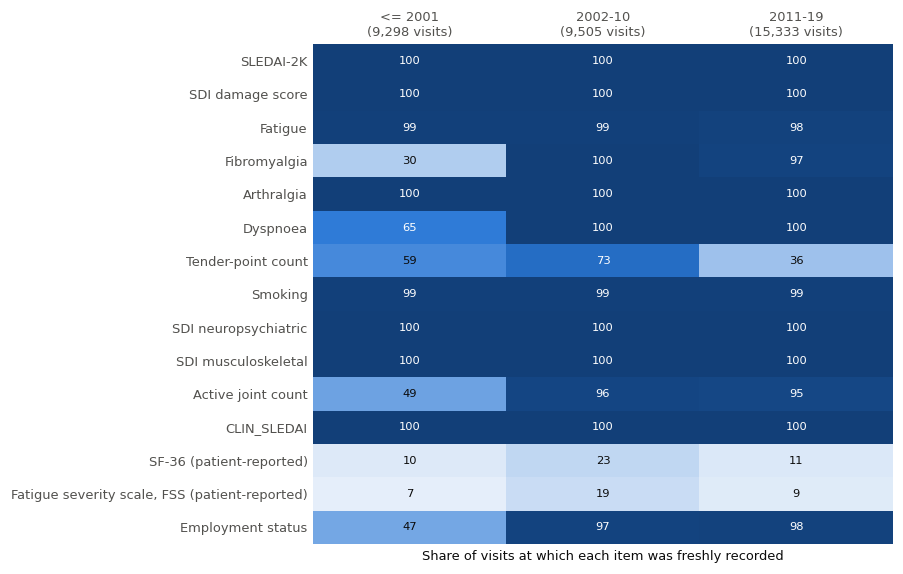

**What this means.** 5 item(s) changed recording rate by 30 percentage points or more between eras:
**FIBROMYALGIA**, **DYSPNOEA**, **TENDER_POINTS**, **JOINT_COUNT**, **HAS_STATUS**. For these, a recent value is often a
value carried forward from years earlier, so their coefficients should be read as markers of the clinic's records as
much as of the disease. The employment status itself (HAS_STATUS) is recorded at almost every visit from 2005
onward, so missing status fields cannot explain changes in the outcome rates after 2005.

In [3]:
"""Recording rate of each input by era (visits of patients ever employed)."""
_vv = visits[visits["PTNO"].isin(_emp_pts)].copy()
_vv["Era"] = pd.cut(_vv["ASSDT"].dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                    labels=[e[2] for e in ERAS])
_rec_cols = [c for c in _vv.columns if c.startswith("_REC_")] + ["HAS_STATUS"]
REC_TABLE = (_vv.groupby("Era", observed=True)[_rec_cols].mean() * 100).round(0).T
REC_TABLE.index = [c.replace("_REC_", "") for c in REC_TABLE.index]
REC_TABLE.loc["Visits (n)"] = _vv.groupby("Era", observed=True).size()
save_table(REC_TABLE, "recording_rates_by_era")
_REC_LABELS = {"SLEDAI2_I": "SLEDAI-2K", "score_n": "SDI damage score", "FATIGUE": "Fatigue", "FIBROMYALGIA": "Fibromyalgia",
               "ARTHRALGIA": "Arthralgia", "DYSPNOEA": "Dyspnoea", "TENDER_POINTS": "Tender-point count",
               "SMOKER": "Smoking", "SDI_NP": "SDI neuropsychiatric", "MSK_DAMAGE": "SDI musculoskeletal",
               "JOINT_COUNT": "Active joint count", "HAS_STATUS": "Employment status",
               "SF36": "SF-36 (patient-reported)", "FSS": "Fatigue severity scale, FSS (patient-reported)"}
_rt = REC_TABLE.drop(index="Visits (n)")
fig, ax = plt.subplots(figsize=(6.8, 0.32 * len(_rt) + 1.1))
ax.imshow(_rt.values.astype(float), cmap=SEQ_BLUE, vmin=0, vmax=100, aspect="auto")
for i in range(_rt.shape[0]):
    for j in range(_rt.shape[1]):
        v = float(_rt.iat[i, j])
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white" if v >= 60 else INK)
ax.set_xticks(range(_rt.shape[1]), [f"{c}\n({int(REC_TABLE.loc['Visits (n)', c]):,} visits)" for c in _rt.columns])
ax.set_yticks(range(_rt.shape[0]), [_REC_LABELS.get(c, c) for c in _rt.index])
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.xaxis.tick_top()
ax.set_title("Share of visits (%) at which each item was freshly recorded", loc="left", fontsize=9, pad=28)
save_fig("recording_rates_by_era")
_unstable = REC_TABLE.drop(index="Visits (n)").pipe(lambda t: t.loc[(t.max(1) - t.min(1)) >= 30])
say(f"""
**What this means.** {len(_unstable)} item(s) changed recording rate by 30 percentage points or more between eras:
{", ".join(f"**{c}**" for c in _unstable.index) if len(_unstable) else "none"}. For these, a recent value is often a
value carried forward from years earlier, so their coefficients should be read as markers of the clinic's records as
much as of the disease. The employment status itself (HAS_STATUS) is recorded at almost every visit from 2005
onward, so missing status fields cannot explain changes in the outcome rates after 2005.
""")

## 1.4 The outcome: leaving work for health reasons

> **The analysis period.** The outcome is built twice: from the visits before 1 March 2020, and from every visit to
> the end of the extract. **The whole analysis uses the visits before 1 March 2020**, before COVID-19 cut clinic
> visits and, with them, the chances to record a change of employment status. The whole extract is used only to
> describe the years from March 2020 (Section 4.0).

> **In plain words.** At every visit where a patient is working, we look ahead to see whether they leave work for
> health reasons, leave for another reason, or are simply no longer followed. The rules below turn the clinic's
> status field into those three outcomes.

The outcome is read from the employment status recorded at visits: **working** (employed), **sick leave**,
**disabled**, **other exit** (retired, homemaker, student, looking for work, other). Visits without a recorded
status are ignored for the outcome. Follow-up of a working patient ends at the first of:

| What happens next | Classified as | Dated at |
|---|---|---|
| A visit with status *disabled* | **Work-disability onset** | that visit |
| A sick-leave spell with no return to work lasting **≥ 6 months**, whatever status follows | **Onset** | the start of the spell |
| A shorter sick-leave spell followed by *disabled* | **Onset** | the start of the spell |
| A sick-leave spell followed by a return to work | nothing (still at risk) | – |
| An other-exit status (or a short sick-leave spell followed by one) | **Competing exit** | that visit (spell start) |
| An open sick-leave spell shorter than 6 months at the last visit | **Censored** | the start of the spell |
| Death within 12 months of the last visit recorded as working, before 65 | **Competing exit** | the date of death |
| The last visit with a recorded status, age 65, or a later death | **Censored** | that date |

**Landmarks: one prediction every 6 months, each over the next 36 months.** The model predicts at fixed times on a
**6-month grid**, not at every visit: at the patient's **first employed visit** (s = 0) and then every 6 months after it
(s = 6, 12, 18, ... months), the landmark design of van Houwelingen (*Scand J Stat* 2007). At each landmark time the
inputs are those of the **last visit at which the patient was recorded as employed** (and under 65) in the 12 months
before it; age, disease duration and years in clinic are moved forward to the landmark date. The patient must still
be at risk at that moment (no exit and no end of follow-up before it). A landmark with no employed visit in the 12
months before it is skipped. A patient who returns to paid work after an onset re-enters at the next landmark time.

Every landmark predicts work disability **within the next 36 months**, so a patient's prediction windows overlap: an
onset falls in the windows of up to six landmarks. Each patient contributes about two landmarks per year of follow-up
whatever their visit frequency, so a patient seen often does not weigh more than a patient seen rarely. The design
with a landmark at every working visit is kept as a design check (Section 3.8.5).

**The hazard models are trained on the stacked landmark set.** Every landmark is followed to s + 36 months (or its
earlier exit or censoring) with its inputs X(s) fixed, whatever landmarks come after it: X(s) is the input of a
36-month prediction and is used for exactly that window. The same person-year therefore enters the fit up to six
times. This changes no estimate's target, but it makes naive standard errors too small, so every interval in this
notebook comes from resampling patients. Rates, flags and descriptions count each person-year and exit once (each
landmark chained to the next). The next cell prints both.

The status is only seen when the patient comes to clinic. So every onset date is really an **interval**: the
change happened after the last visit recorded as working and no later than the visit that shows it. For sick
leave, the onset is **confirmed** only at the first visit at least 6 months after the spell started. The next cell
records both quantities for every onset.

In [4]:
"""States, competing-risk follow-up from every landmark, the H-month label, censoring weights, at-risk intervals."""
SICK_MIN_DAYS = SICK_LEAVE_MIN_MONTHS * MONTH_DAYS


def _state_of(emp):
    if emp in WORKING_STATES:
        return "W"
    if emp in SICK_STATES:
        return "S"
    if emp in DISABLED_STATES:
        return "D"
    if emp in OTHER_EXIT_STATES:
        return "O"
    return "U"


def _resolve_nonworking(states, emps, dates, j, n):
    """Outcome of the non-working spell starting at status-visit j: (kind, date, next index, detail)."""
    s = states[j]
    if s == "D":
        return "disability", dates[j], None, ("direct", emps[j], j, dates[j])
    if s == "O":
        return "other_exit", dates[j], None, ("direct", emps[j], j, dates[j])
    if s != "S":
        return "skip", None, j + 1, None
    r = j
    while r + 1 < n and states[r + 1] == "S":
        r += 1
    nxt = r + 1 if r + 1 < n else None
    if nxt is not None and states[nxt] == "W":
        return None, None, nxt, None                     # back to work: still at risk
    start = dates[j]
    spell = list(range(j, r + 1)) + ([nxt] if nxt is not None else [])
    long_enough = [q for q in spell if (dates[q] - start).days >= SICK_MIN_DAYS]
    end_emp = emps[nxt] if nxt is not None else "sick leave (open)"
    if long_enough:
        return "disability", start, None, ("long sick spell", end_emp, j, dates[long_enough[0]])
    if nxt is None:
        return "censored_sick", start, None, ("short open sick spell", end_emp, j, pd.NaT)
    if emps[nxt] in DISABLED_STATES:
        return "disability", start, None, ("short sick spell", end_emp, j, dates[nxt])
    return "other_exit", start, None, ("short sick spell", end_emp, j, dates[nxt])


def _follow_up_from(i, states, emps, dates, cap_date):
    n = len(states)
    j = i + 1
    while j < n:
        if states[j] == "W":
            j += 1
            continue
        kind, d, nxt, det = _resolve_nonworking(states, emps, dates, j, n)
        if kind in ("disability", "other_exit", "censored_sick"):
            if d > cap_date:
                return cap_date, 0, "age_cap", None
            return d, {"disability": 1, "other_exit": 2}.get(kind, 0), \
                {"censored_sick": "unresolved_sick_leave"}.get(kind, kind), det
        j = nxt
    if cap_date < dates[-1]:
        return cap_date, 0, "age_cap", None
    return dates[-1], 0, "end_of_follow_up", None


def build_landmarks(visits, end=None):
    """Visit-level landmarks with their competing-risk follow-up. A death within DEATH_COMPETING_MONTHS of the last
    status (recorded as working), before age 65 and no later than `end` (default: the last visit), is a competing
    exit dated at the death; a later death leaves the follow-up censored at the last status."""
    sv = visits[visits["HAS_STATUS"]]
    end = visits["ASSDT"].max() if end is None else end
    rows = []
    for pid, idx in sv.groupby("PTNO", sort=False).indices.items():
        p = sv.iloc[idx]
        vrow = p.index.values
        states = [_state_of(e) for e in p["EMP"].values]
        dates, emps, ages = list(p["ASSDT"]), list(p["EMP"].values), p["age_at_record"].values
        birth = p["BIRTHDT"].iloc[0]
        cap_date = birth + pd.DateOffset(years=AGE_CAP_YEARS) if pd.notna(birth) else pd.Timestamp.max
        for i, s in enumerate(states):
            if s != "W" or ages[i] >= AGE_CAP_YEARS or i == len(states) - 1:
                continue
            d_end, cause, typ, det = _follow_up_from(i, states, emps, dates, cap_date)
            death = p["DEATHDT"].iloc[0]
            if typ == "end_of_follow_up" and p["STATUS"].iloc[0] == "D" and pd.notna(death) and \
                    dates[-1] < death <= min(dates[-1] + pd.Timedelta(days=DEATH_COMPETING_MONTHS * MONTH_DAYS),
                                             cap_date, end):
                d_end, cause, typ, det = death, 2, "death", ("death", "died", len(states), death)
            t = (d_end - dates[i]).days
            if t <= 0:
                continue
            rows.append({"pid": pid, "visit_row": int(vrow[i]), "visit_date": dates[i], "time_days": t,
                         "cause": cause, "exit_type": typ, "event_date": d_end if cause == 1 else pd.NaT,
                         "route": det[0] if det else None, "exit_emp": det[1] if det else None,
                         "last_work_date": dates[det[2] - 1] if det else pd.NaT,
                         "confirm_date": det[3] if det else pd.NaT, "last_status_date": dates[-1],
                         "dead": p["STATUS"].iloc[0] == "D"})
    return pd.DataFrame(rows)


def landmarks_every(lv, months=LANDMARK_EVERY_MONTHS, stale_months=LANDMARK_MAX_STALE_MONTHS, trigger=None):
    """Landmarks every `months` from each patient's first employed visit, from the visit-level landmarks `lv`. At
    landmark time s, the inputs are those of the last employed visit in the `stale_months` before s, and that visit's
    follow-up is shifted to start at s. A landmark exists only if the patient is still at risk at s (no exit and no
    end of follow-up before s); a landmark without a visit in the window is skipped. trigger="SDI" adds a landmark at
    every employed visit whose SDI damage score is above every earlier one of that patient (landmark_k = -2)."""
    step, stale = months * MONTH_DAYS, stale_months * MONTH_DAYS
    sdi_all = visits["score_n"].astype(float)
    out = []
    for pid, g in lv.groupby("pid", sort=False):
        d = g["visit_date"].values.astype("datetime64[D]").astype(float)
        t0, end = d[0], (d + g["time_days"].values).max()
        times = [(t0 + k * step, k) for k in range(int((end - t0) // step) + 1) if t0 + k * step < end]
        if trigger == "SDI":
            sd = sdi_all.loc[g["visit_row"].values].values
            prev = np.r_[np.nan, np.fmax.accumulate(np.nan_to_num(sd, nan=-1.0))[:-1]]
            times += [(d[j], -2) for j in range(1, len(sd)) if np.isfinite(sd[j]) and prev[j] >= 0 and sd[j] > prev[j]
                      and d[j] < end]
        times.sort()
        last = -np.inf
        for s_, k in times:
            if s_ - last < 1:                          # a trigger on the day of a grid landmark: one landmark
                continue
            j = np.searchsorted(d, s_, side="right") - 1
            if j >= 0 and s_ - d[j] <= stale:
                gap = s_ - d[j]
                r = g.iloc[j].copy()
                if r["time_days"] > gap:
                    r["source_visit_date"], r["gap_days"] = r["visit_date"], gap
                    r["visit_date"] = pd.Timestamp("1970-01-01") + pd.Timedelta(days=s_)
                    r["time_days"] = r["time_days"] - gap
                    r["landmark_k"] = k
                    out.append(r)
                    last = s_
    return pd.DataFrame(out).reset_index(drop=True)


def _rname(c, h):
    """Name of the recency-weighted version of input c at half-life h (months)."""
    return f"{c}__R{h:g}"


def recency_features(lnd, vis, half_lives=RECENCY_HALF_LIVES, window_months=RECENCY_WINDOW_MONTHS):
    """For every landmark of `lnd` (pid, visit_date = landmark date), from the patient's visits in `vis` within the
    window before the landmark: the recency-weighted mean of each DECAY_ITEMS input for every half-life > 0, the
    RECENCY_EXTRAS, and the prednisone weighted-cumulative-exposure basis (PRED_WCE_k). A visit's value holds until
    the next visit (the last one until the landmark, at least one month); each visit is weighted by that time and by
    1/2 per half-life of the age of its midpoint."""
    from scipy.interpolate import BSpline
    win = window_months * MONTH_DAYS
    hs = [h for h in half_lives if h > 0]
    cols = {_rname(c, h): np.full(len(lnd), np.nan) for c in DECAY_ITEMS for h in hs}
    cols |= {c: np.full(len(lnd), np.nan) for c in RECENCY_EXTRAS}
    kn = np.r_[[0.0] * 3, np.linspace(0, window_months, WCE_DF - 2), [float(window_months)] * 3]
    bsp = [BSpline(kn, np.eye(WCE_DF)[k], 3, extrapolate=False) for k in range(WCE_DF)]   # len(kn) - 4 = WCE_DF bases
    cols |= {f"PRED_WCE_{k + 1}": np.full(len(lnd), np.nan) for k in range(WCE_DF)}
    vt_all = vis["ASSDT"].values.astype("datetime64[D]").astype(float)
    gidx = vis.groupby("PTNO", sort=False).indices
    items = {c: vis[v].values.astype(float) for c, v in DECAY_ITEMS.items()}
    sdi, sled, pred = vis["score_n"].values.astype(float), vis["SLEDAI2_I"].values.astype(float), vis["STERAVER_0"].values.astype(float)
    lt = lnd["visit_date"].values.astype("datetime64[D]").astype(float)
    for i, (p, s_) in enumerate(zip(lnd["pid"].values, lt)):
        ix = gidx[p]
        t = vt_all[ix]
        sel = ix[(t <= s_) & (t > s_ - win)]
        if not len(sel):
            continue
        t = vt_all[sel]
        nxt = np.r_[t[1:], max(s_, t[-1] + MONTH_DAYS)]
        dur = np.maximum(nxt - t, 1.0)
        age_mo = (s_ - (t + nxt) / 2) / MONTH_DAYS
        age_mo = np.clip(age_mo, 0, None)
        for h in hs:
            w = dur * (np.power(0.5, age_mo / h) if np.isfinite(h) else 1.0)
            for c, x in items.items():
                xv = x[sel]
                ok = ~np.isnan(xv)
                if ok.any():
                    cols[_rname(c, h)][i] = np.sum(w[ok] * xv[ok]) / np.sum(w[ok])
        cols["VISITS_24M"][i] = len(sel)
        for nm, x in [("SDI_CHG_24M", sdi), ("SLEDAI_CHG_24M", sled)]:
            xv = x[sel][~np.isnan(x[sel])]
            if len(xv):
                cols[nm][i] = xv[-1] - xv[0]
        pv = pred[sel]
        ok = ~np.isnan(pv)
        lag = np.clip(age_mo, 0, window_months - 1e-6)
        for k in range(WCE_DF):
            b = np.nan_to_num(bsp[k](lag))
            cols[f"PRED_WCE_{k + 1}"][i] = np.sum((pv * dur / 365.25 * b)[ok])
    return pd.DataFrame(cols)


def km_censoring(t, censored):
    """G(s-): probability of being still uncensored just before s."""
    ut = np.unique(t[censored])
    at_risk = np.array([(t >= u).sum() for u in ut], float)
    n_c = np.array([((t == u) & censored).sum() for u in ut], float)
    surv = np.cumprod(1.0 - n_c / at_risk)

    def G_minus(s):
        idx = np.searchsorted(ut, s, side="left") - 1
        return np.where(idx >= 0, surv[np.clip(idx, 0, None)], 1.0)
    return G_minus


def cox_censoring(t, censored, Z, strata):
    """G(s- | z, stratum) from a Cox model for censoring with a Breslow baseline per stratum (the landmark's era):
    returns a function of (s, row index). Falls back to the stratum's Kaplan-Meier if the fit fails."""
    from lifelines import CoxPHFitter
    df = pd.DataFrame(Z, columns=[f"z{j}" for j in range(Z.shape[1])])
    df["T"], df["E"], df["S"] = np.maximum(t, 0.5), censored.astype(int), strata
    try:
        cph = CoxPHFitter(penalizer=0.01).fit(df, "T", "E", strata=["S"])
        lp = Z @ cph.params_.values
    except Exception:
        lp = np.zeros(len(t))
    # Breslow cumulative baseline hazard per stratum on the risk-score scale
    base = {}
    for st in np.unique(strata):
        k = strata == st
        tk, ek, rk = t[k], censored[k], np.exp(lp[k])
        ut = np.unique(tk[ek])
        if not len(ut):
            base[st] = (np.array([np.inf]), np.array([0.0]))
            continue
        o = np.argsort(tk)
        ts, rs = tk[o], rk[o]
        risk_sum = np.cumsum(rs[::-1])[::-1]                       # sum of exp(lp) with t >= ts[i]
        at = risk_sum[np.searchsorted(ts, ut, side="left")]
        d = np.array([((tk == u) & ek).sum() for u in ut], float)
        base[st] = (ut, np.cumsum(d / at))

    def G_minus(s, idx):
        s, idx = np.atleast_1d(s).astype(float), np.atleast_1d(idx)
        out = np.ones(len(idx))
        for st in np.unique(strata[idx]):
            k = strata[idx] == st
            ut, H0 = base[st]
            j = np.searchsorted(ut, s[k], side="left") - 1
            Hs = np.where(j >= 0, H0[np.clip(j, 0, None)], 0.0)
            out[k] = np.exp(-Hs * np.exp(lp[idx[k]]))
        return out
    return G_minus


def ipcw_weights(t, c, rows=None, months=H, Z=None, strata=None, marginal=False):
    """IPCW weights at `months` for the cumulative-incidence target (competing exits are controls): w > 0 for every
    landmark whose status at the horizon is known; y = onset within the horizon. The censoring distribution is
    estimated on `rows`: a Cox model with covariates Z stratified by `strata` (default: CENS_Z and the landmark's era,
    when t has one entry per landmark), or a pooled Kaplan-Meier (marginal=True, or when no covariates are given).
    Weights are truncated at the IPCW_TRUNC quantile of the non-zero weights."""
    rows = np.arange(len(t)) if rows is None else np.asarray(rows)
    tt, cc = t[rows], c[rows]
    hd = round(months * MONTH_DAYS)
    ev = (cc >= 1) & (tt <= hd)
    surv = tt > hd
    if Z is None and strata is None and len(t) == N_LAND and not marginal:
        Z, strata = CENS_Z, ERA_LAB
    w = np.zeros(len(rows))
    if Z is None or marginal:
        G = km_censoring(tt, cc == 0)
        w[ev] = 1.0 / G(tt[ev])
        w[surv] = 1.0 / G(np.array([hd + 0.5]))[0]
    else:
        G = cox_censoring(tt, cc == 0, Z[rows], np.asarray(strata)[rows])
        idx = np.arange(len(rows))
        w[ev] = 1.0 / np.maximum(G(tt[ev], idx[ev]), 1e-3)
        w[surv] = 1.0 / np.maximum(G(np.full(surv.sum(), hd + 0.5), idx[surv]), 1e-3)
    if (w > 0).any():
        w = np.minimum(w, np.quantile(w[w > 0], IPCW_TRUNC))
    y = ((cc == 1) & (tt <= hd)).astype(float)
    return y, w




def derive(end=None, every=LANDMARK_EVERY_MONTHS, trigger=None, stacked=STACKED_TRAINING):
    """Every landmark-level array of the analysis, from the visits before `end` (None: the whole extract). The arrays
    are set as globals, so that every function below works on whichever version of the data is in use. every=None:
    a landmark at every working visit (the design check of Section 3.8.5). trigger: see landmarks_every. stacked: each
    landmark is followed to s + H months with X(s) fixed, whatever landmarks come after it, so the windows overlap
    (the stacked landmark set, van Houwelingen 2007). It sets the hazard models' training arrays (INT_YRS, D1, D2);
    the person-time arrays (INT_YRS_ALL, D1_ALL, D2_ALL, _cont) always chain each landmark to the next, so that
    rates, flags and descriptions count every person-year and exit once."""
    global land, N_LAND, PID_ALL, T_ALL, C_ALL, LAND_T, LAND_YEAR, LAND_X, SF_OK, IN_COVID, DEV_ROWS, Y24, Y_IP, W_IP, W_IP_KM, CENS_Z, ERA_LAB, ENTRY_ERA, _END, _same_next, _next, _cont, INT_END, INT_YRS, D1, D2, INT_END_ALL, INT_YRS_ALL, D1_ALL, D2_ALL, _ENDS, ALL_PIDS, PID_INDEX, ROW_PIDX, PT_ROWS, PID_EVENT, DATA_END_DATE, _h, _cz_, _COVID_T
    vis = visits if end is None else visits[visits["ASSDT"] < end]
    DATA_END_DATE = vis["ASSDT"].max() if end is None else end - pd.Timedelta(days=1)
    land = build_landmarks(vis, DATA_END_DATE)
    if every is not None:
        land = landmarks_every(land, every, trigger=trigger)
    else:
        land["source_visit_date"], land["gap_days"], land["landmark_k"] = land["visit_date"], 0.0, -1
    N_LAND = len(land)
    PID_ALL = land["pid"].values
    T_ALL = land["time_days"].values.astype(float)
    C_ALL = land["cause"].values.astype(int)
    LAND_T = ((land["visit_date"] - pd.Timestamp("1970-01-01")).dt.days).values.astype(float)
    LAND_YEAR = land["visit_date"].dt.year.values + (land["visit_date"].dt.dayofyear.values - 1) / 365.25
    _gap_yrs = land["gap_days"].values.astype(float) / 365.25        # landmark date - date of the source visit
    for c in ["age_at_record", "SEX_FEMALE", "RACE_GROUP", "YRS_IN_CLINIC"]:
        land[c] = visits.loc[land["visit_row"], c].values
        if c in LANDMARK_TIME_VARS:
            land[c] = land[c].astype(float) + _gap_yrs
    assert (np.diff(LAND_T)[PID_ALL[1:] == PID_ALL[:-1]] > 0).all()
    LAND_X = visits.loc[land["visit_row"], sorted(set(COMPACT_VARS + DEMO_VARS + LANDMARK_TIME_VARS + list(CANDIDATE_VARS)))].reset_index(drop=True)
    for c in LANDMARK_TIME_VARS:                       # time-dependent by definition: moved forward to the landmark
        LAND_X[c] = LAND_X[c].astype(float) + _gap_yrs
    # the SF-36 at the landmark (Section 3.7; not an input of HazReg): PCS / MCS from a form of the past 12 months, and the
    # most recent older form (an auxiliary of the imputation model)
    for _c in SF36_VARS + SF36_PREV_VARS + SF36_NEXT_VARS + [PCS_NR] + FSS_VARS:
        LAND_X[_c] = visits.loc[land["visit_row"], _c].values
    LAND_X["SF36_PREV_AGE_YRS"] = LAND_X["SF36_PREV_AGE_YRS"] + _gap_yrs
    LAND_X["SF36_NEXT_GAP_YRS"] = (LAND_X["SF36_NEXT_GAP_YRS"] - _gap_yrs).clip(lower=0)
    LOG1P_VARS.update({"SF36_PREV_AGE_YRS", "SF36_NEXT_GAP_YRS"})
    SF_OK = LAND_X[SF36_VARS].notna().all(axis=1).values          # landmarks with a valid form
    _rf = recency_features(land, visits)                           # recency-weighted inputs (Section 2.1); visits <= landmark
    for _c in _rf.columns:
        LAND_X[_c] = _rf[_c].values
    # calendar time of the landmark (used only by the time-adjusted model of Section 4.3, never by HazReg)
    _COVID_T = [float((pd.Timestamp(d) - pd.Timestamp("1970-01-01")).days) for d in COVID_WINDOW]
    IN_COVID = (LAND_T >= _COVID_T[0]) & (LAND_T <= _COVID_T[1])
    LAND_X["GAP_YRS"] = _gap_yrs                       # age of the inputs at the landmark (only used by the check of Section 3.8.8)
    LOG1P_VARS.add("GAP_YRS")
    LAND_X["CAL_YEAR"] = LAND_YEAR
    LAND_X["COVID"] = IN_COVID.astype(float)
    DEV_ROWS = LAND_YEAR >= DEV_START                  # the co-primary development set (landmarks from 2000 on)

    # ---- the H-month label (complete case) and censoring weights (Cox model for censoring, stratified by era)
    land["admin_days"] = np.minimum((DATA_END_DATE - land["visit_date"]).dt.days.values.astype(float),
                                    (AGE_CAP_YEARS - land["age_at_record"].values) * 365.25)
    _h = T_ALL <= HORIZON_DAYS
    Y24 = np.where((C_ALL == 1) & _h, 1.0, np.where(~_h | (C_ALL == 2), 0.0, np.nan))
    Y24[land["admin_days"].values < HORIZON_DAYS] = np.nan


    ERA_LAB = era_of(land["visit_date"])                                           # calendar period of the prediction
    ENTRY_ERA = era_of(land.groupby("pid")["visit_date"].transform("min"))         # era the patient entered the cohort
    # covariates of the censoring model, standardised (median-filled; log1p for skewed inputs)
    _cz_ = LAND_X[CENS_VARS].astype(float).copy()
    for _c in CENS_VARS:
        if _c in LOG1P_VARS:
            _cz_[_c] = np.sign(_cz_[_c]) * np.log1p(np.abs(_cz_[_c]))
    _cz_ = _cz_.fillna(_cz_.median())
    CENS_Z = ((_cz_ - _cz_.mean()) / _cz_.std().replace(0, 1)).clip(-CLIP_Z, CLIP_Z).values


    Y_IP, W_IP = ipcw_weights(T_ALL, C_ALL)
    _, W_IP_KM = ipcw_weights(T_ALL, C_ALL, marginal=True)       # the pooled Kaplan-Meier weights (sensitivity analysis)

    # ---- at-risk intervals between consecutive landmarks (the hazard models' target)
    _END = LAND_T + T_ALL
    _same_next = np.r_[PID_ALL[1:] == PID_ALL[:-1], False]
    _next = np.r_[LAND_T[1:], np.inf]
    _cont = _same_next & (_next < _END)
    INT_END_ALL = np.where(_cont, _next, _END)                 # the whole interval: person-time and exits, as recorded
    INT_YRS_ALL = (INT_END_ALL - LAND_T) / 365.25
    D1_ALL = (~_cont & (C_ALL == 1)).astype(float)
    D2_ALL = (~_cont & (C_ALL == 2)).astype(float)
    _cap = LAND_T + H * MONTH_DAYS                             # the hazard models' target: X(s) is used for H months at most
    _tr_end = _END if stacked else INT_END_ALL                 # stacked: every landmark followed to its own exit, up to the cap
    INT_END = np.minimum(_tr_end, _cap)
    INT_YRS = (INT_END - LAND_T) / 365.25
    _ENDS = (True if stacked else ~_cont) & (_END <= _cap)     # the exit falls inside the (capped) training interval
    D1 = (_ENDS & (C_ALL == 1)).astype(float)
    D2 = (_ENDS & (C_ALL == 2)).astype(float)
    ALL_PIDS = np.array(sorted(land["pid"].unique()))
    PID_INDEX = {p: i for i, p in enumerate(ALL_PIDS)}
    ROW_PIDX = np.array([PID_INDEX[p] for p in PID_ALL])
    PT_ROWS = {p: np.flatnonzero(PID_ALL == p) for p in ALL_PIDS}
    PID_EVENT = np.array([int((C_ALL[PT_ROWS[p]] == 1).any()) for p in ALL_PIDS])
    if end is not None:                                # a later form does not exist in an extract ending at `end`
        _next_form = land["visit_date"] + pd.to_timedelta(LAND_X["SF36_NEXT_GAP_YRS"].values * 365.25, unit="D")
        LAND_X.loc[(_next_form >= end).fillna(False).values, SF36_NEXT_VARS] = np.nan


DATA_KEYS = ['land', 'N_LAND', 'PID_ALL', 'T_ALL', 'C_ALL', 'LAND_T', 'LAND_YEAR', 'LAND_X', 'SF_OK', 'IN_COVID', 'DEV_ROWS', 'Y24', 'Y_IP', 'W_IP', 'W_IP_KM', 'CENS_Z', 'ERA_LAB', 'ENTRY_ERA', '_END', '_same_next', '_next', '_cont', 'INT_END', 'INT_YRS', 'D1', 'D2', 'INT_END_ALL', 'INT_YRS_ALL', 'D1_ALL', 'D2_ALL', '_ENDS', 'ALL_PIDS', 'PID_INDEX', 'ROW_PIDX', 'PT_ROWS', 'PID_EVENT', 'DATA_END_DATE', '_h', '_cz_', '_COVID_T']
DATA, CURRENT_DATA = {}, None


def use_data(name):
    """Switch every landmark-level global to the named version of the data ("main": the visits before MAIN_END; "full":
    the whole extract, for the years from MAIN_END in Section 4.0), keeping the version in use (with anything added to it
    since) for later."""
    global CURRENT_DATA
    if CURRENT_DATA is not None:
        DATA[CURRENT_DATA] = {k: globals()[k] for k in DATA_KEYS if k in globals()}
    globals().update(DATA[name])
    CURRENT_DATA = name


derive(None)                                           # the whole extract: the years from MAIN_END (Section 4.0)
DATA["full"] = {k: globals()[k] for k in DATA_KEYS}
derive(MAIN_END, every=None, stacked=False)            # every working visit a landmark, chained: the design check of Section 3.8.5
DATA["main_visits"] = {k: globals()[k] for k in DATA_KEYS}
derive(MAIN_END)                                       # the main analysis: the extract as if it had ended at MAIN_END
DATA["main"] = {k: globals()[k] for k in DATA_KEYS}
CURRENT_DATA = "main"
_day = lambda y: float((pd.Timestamp(f"{y}-01-01") - pd.Timestamp("1970-01-01")).days)   # Jan 1 of year y, in days
_nf = DATA["full"]
_nm = DATA["main"]
print(f"Main analysis, visits before {MAIN_END.date()}: {_nm['N_LAND']:,} landmarks of "
      f"{len(_nm['ALL_PIDS']):,} patients, {int(_nm['D1_ALL'].sum())} onsets. Whole extract (to {_nf['DATA_END_DATE'].date()}, "
      f"Section 4.0 only): {_nf['N_LAND']:,} landmarks of {len(_nf['ALL_PIDS']):,} patients, {int(_nf['D1_ALL'].sum())} onsets.")

_nv = DATA["main_visits"]
_in_win = lambda d: int(((d["C_ALL"] == 1) & (d["T_ALL"] <= HORIZON_DAYS)).sum())
print(f"Landmarks every {LANDMARK_EVERY_MONTHS} months (main analysis): {_nm['N_LAND']:,} landmarks, against "
      f"{_nv['N_LAND']:,} working visits. Onsets: {int(_nm['D1_ALL'].sum())} (every working visit: {int(_nv['D1_ALL'].sum())}); "
      f"{_in_win(_nm)} landmarks are followed by an onset within {H} months (an onset falls in the window of up to {H // LANDMARK_EVERY_MONTHS} landmarks).")
print(f"Landmarks (main analysis): {N_LAND:,} of {len(ALL_PIDS):,} patients (median "
      f"{land.groupby('pid').size().median():.0f} per patient; inputs from a visit a median "
      f"{np.median(land['gap_days']) / MONTH_DAYS:.1f} months before the landmark, 90th percentile "
      f"{np.percentile(land['gap_days'], 90) / MONTH_DAYS:.1f})")
print(f"Stacked training set (main analysis): each of the {_nm['N_LAND']:,} landmarks followed to s + {H} months with its inputs fixed: "
      f"{_nm['INT_YRS'].sum():,.0f} landmark-years (against {_nm['INT_YRS_ALL'].sum():,.0f} person-years at risk, so each "
      f"person-year is used {_nm['INT_YRS'].sum() / _nm['INT_YRS_ALL'].sum():.1f} times); {int(_nm['D1'].sum())} landmark-onset pairs "
      f"from {int(_nm['D1_ALL'].sum())} onsets. Uncertainty is always taken over patients, so the overlap is accounted for.")
print(f"At-risk intervals: {INT_YRS_ALL.sum():,.0f} person-years | onsets {int(D1_ALL.sum())} in "
      f"{land.loc[C_ALL == 1, 'pid'].nunique()} patients | competing exits {int(D2_ALL.sum())} | "
      f"crude onset rate {100 * D1_ALL.sum() / INT_YRS_ALL.sum():.2f} per 100 person-years")
print(f"{H}-month label: onset {int(np.nansum(Y24 == 1)):,} | no onset {int(np.nansum(Y24 == 0)):,} | unresolved "
      f"{int(np.isnan(Y24).sum()):,}; IPCW cumulative incidence at {H} months {np.sum(W_IP * Y_IP) / N_LAND:.3f} "
      f"({int((W_IP > 0).sum()):,} landmarks with a known {H}-month status)")

say(f"""
**What this means.** The main analysis has {N_LAND:,} landmarks (one every {LANDMARK_EVERY_MONTHS} months of employed follow-up) from
{len(ALL_PIDS):,} patients, with {int(D1_ALL.sum())} work-disability onsets and {int(D2_ALL.sum())} other exits over
{INT_YRS_ALL.sum():,.0f} person-years at risk. About {100 * np.sum(W_IP * Y_IP) / N_LAND:.1f} % of landmarks are followed
by work disability within {H} months. The outcome is uncommon, so the tool's main job is to separate a small high-risk group from a large
low-risk one. At the patient level, {int(PID_EVENT.sum())} of the {len(ALL_PIDS):,} patients
({100 * PID_EVENT.mean():.0f} %) had at least one onset; these are the cases of the patient-level evaluation
(Section 3.0.1).
""")

Main analysis, visits before 2020-03-01: 12,976 landmarks of 958 patients, 150 onsets. Whole extract (to 2024-04-08, Section 4.0 only): 15,116 landmarks of 1,059 patients, 158 onsets.
Landmarks every 6 months (main analysis): 12,976 landmarks, against 15,385 working visits. Onsets: 150 (every working visit: 150); 588 landmarks are followed by an onset within 36 months (an onset falls in the window of up to 6 landmarks).
Landmarks (main analysis): 12,976 of 958 patients (median 10 per patient; inputs from a visit a median 2.3 months before the landmark, 90th percentile 6.4)
Stacked training set (main analysis): each of the 12,976 landmarks followed to s + 36 months with its inputs fixed: 31,504 landmark-years (against 7,078 person-years at risk, so each person-year is used 4.5 times); 588 landmark-onset pairs from 150 onsets. Uncertainty is always taken over patients, so the overlap is accounted for.
At-risk intervals: 7,078 person-years | onsets 150 in 142 patients | competing exits 24

**What this means.** The main analysis has 12,976 landmarks (one every 6 months of employed follow-up) from
958 patients, with 150 work-disability onsets and 241 other exits over
7,078 person-years at risk. About 5.0 % of landmarks are followed
by work disability within 36 months. The outcome is uncommon, so the tool's main job is to separate a small high-risk group from a large
low-risk one. At the patient level, 142 of the 958 patients
(15 %) had at least one onset; these are the cases of the patient-level evaluation
(Section 3.0.1).

In [5]:
"""The eras: the calendar period of each prediction against the era its patient entered the working cohort."""
ERA_DEF = pd.DataFrame({"Era": ERA_NAMES, "Years": [f"{a}-{b - 1}" if k else f"1996-{b - 1} (earlier landmarks pooled)"
                                                    for k, (a, b, _) in enumerate(ERAS)],
                        "What changed": [ERA_NOTES[e] for e in ERA_NAMES]}).set_index("Era")
ERA_DEF.loc[ERA_NAMES[-1], "Years"] = f"{ERAS[-1][0]}-February {MAIN_END.year}"
ERA_DEF.loc[POST_ERA] = [f"March {MAIN_END.year} to the end of the extract", "COVID-19 and after: outside the analysis, described in Section 4.0"]
display(ERA_DEF)


def era_grid(d):
    """Landmarks / patients / onsets within H months, by entry era (rows) and calendar era of the prediction (columns)."""
    t = pd.DataFrame({"Entry era": d["ENTRY_ERA"], "Calendar era": d["ERA_LAB"], "pid": d["PID_ALL"],
                      "on": d["Y24"] == 1})
    g = t.groupby(["Entry era", "Calendar era"]).agg(n=("pid", "size"), p=("pid", "nunique"), o=("on", "sum"))
    return g.apply(lambda r: f"{r.n:,} / {r.p} / {r.o}", axis=1).unstack("Calendar era") \
        .reindex(index=ERA_NAMES, columns=ERA_NAMES).fillna("")


ERA_GRID = {nm: era_grid(DATA[nm]) for nm in ["main"]}
for nm, lab in [("main", f"Main analysis (visits before {MAIN_END.date()})")]:
    print(f"{lab}: landmarks / patients / onsets within {H} months")
    display(ERA_GRID[nm])
    save_table(ERA_GRID[nm], f"entry_by_calendar_era_{nm}")
say(f"""
**What this means.** Every prediction carries two eras: the **calendar era** of its own date (the clinic, treatments
and recording practice when the risk was scored) and the **entry era** of its patient (when the patient first
attended while working). The two differ for long-followed patients: of the main analysis's landmarks,
{100 * np.mean(DATA["main"]["ENTRY_ERA"] != DATA["main"]["ERA_LAB"]):.0f} % were scored in a later era than the
patient's entry. Results by era are given for both.
""")

,Years,What changed
Era,,
<= 2001,1996-2001 (earlier landmarks pooled),pre-SLEDAI-2K
2002-10,2002-2010,SLEDAI-2K
2011-19,2011-February 2020,belimumab
2020 on,March 2020 to the end of the extract,"COVID-19 and after: outside the analysis, desc..."


Main analysis (visits before 2020-03-01): landmarks / patients / onsets within 36 months


Calendar era,<= 2001,2002-10,2011-19
Entry era,,,
<= 2001,"2,514 / 335 / 155","2,579 / 225 / 157","1,468 / 133 / 43"
2002-10,,"1,907 / 291 / 111","2,293 / 210 / 46"
2011-19,,,"2,215 / 332 / 50"


**What this means.** Every prediction carries two eras: the **calendar era** of its own date (the clinic, treatments
and recording practice when the risk was scored) and the **entry era** of its patient (when the patient first
attended while working). The two differ for long-followed patients: of the main analysis's landmarks,
49 % were scored in a later era than the
patient's entry. Results by era are given for both.

## 1.5 Audit of how the outcome is recorded

A prediction model can only be as good as its outcome. Here the outcome is read from a single form field filled
in at clinic visits, so five questions come before any model:

| | Question | Why it matters |
|:--|:--|:--|
| 1 | Do recorded exits from work stay put? | Frequent *disabled → employed* reversals would mean the status is noisy, or that exits are often temporary |
| 2 | How precisely is an onset dated, and how long until it is confirmed? | Onsets near the end of the data may not be visible yet |
| 3 | How does each patient's follow-up end, era by era? | A patient who stops attending while employed is counted as event-free. If some of them left work, recent risk is understated |
| 4 | How do exit rates change over calendar time, and through which route? | A change in how statuses are recorded looks exactly like a change in risk |
| 5 | Does the change survive a model built for status snapshots? | Rules out visit timing as the explanation |
| 6 | Is the status field still being updated? | A field that stops being updated produces exactly this pattern: every kind of change falls together, statuses go stale, and implausible statuses persist |

### 1.5.1 Transitions in the status record

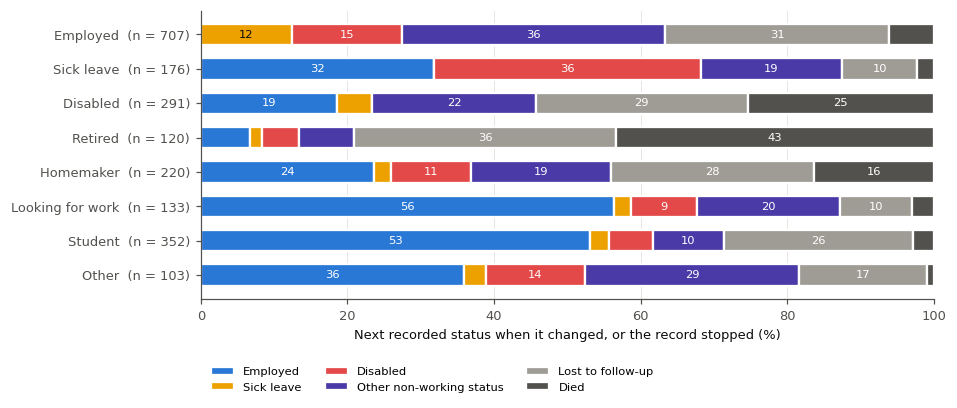

The status was unchanged at 96.7 % of consecutive recorded visits; the figure shows the changes, and the patients lost to follow-up or who died after their last recorded status.


**What this means.** For every 106 moves from *employed* to *disabled* there are 54 moves back
(51%). A recorded disability is therefore often not permanent: some patients do return to work, and some
statuses are probably mis-recorded. The model handles real returns by letting a patient re-enter the risk set at
the next employed visit. Mis-recording can only be measured against the chart (Section 7.2).

In [6]:
"""Transitions between consecutive recorded statuses."""
_sv = visits.loc[visits["HAS_STATUS"], ["PTNO", "ASSDT", "EMP"]].copy()
_sv["prev"] = _sv.groupby("PTNO")["EMP"].shift()
TRANSITIONS = pd.crosstab(_sv["prev"], _sv["EMP"], rownames=["Status at a visit"], colnames=["Status at the next"])
save_table(TRANSITIONS, "status_transitions")
# where patients went when the recorded status changed (staying in the same status excluded), plus loss to
# follow-up and death after the last recorded status
_grp_next = lambda s: {"employed": "Employed", "sick leave": "Sick leave", "disabled": "Disabled"}.get(s, "Other non-working status")
_moves = TRANSITIONS.copy()
for s in _moves.index:
    if s in _moves.columns:
        _moves.loc[s, s] = 0
_mv = _moves.T.groupby(_grp_next).sum().T
# patients whose record simply stops: lost to follow-up (last visit > LEFT_CLINIC_YEARS before the extract end, alive)
# or died, counted from their last recorded status
_lastv = visits.groupby("PTNO").agg(last=("ASSDT", "max"), dead=("STATUS", lambda s: (s == "D").any()))
_lasts = _sv.groupby("PTNO")["EMP"].last()
_gone = _lastv.reindex(_lasts.index)
_lost = (~_gone["dead"]) & ((DATA_END_DATE - _gone["last"]).dt.days / 365.25 > LEFT_CLINIC_YEARS)
_mv["Lost to follow-up"] = _lasts[_lost.values].value_counts().reindex(_mv.index).fillna(0)
_mv["Died"] = _lasts[_gone["dead"].values].value_counts().reindex(_mv.index).fillna(0)
_cats = [("Employed", STATE_COLORS["W"]), ("Sick leave", STATE_COLORS["S"]), ("Disabled", STATE_COLORS["D"]),
         ("Other non-working status", STATE_COLORS["O"]), ("Lost to follow-up", "#9e9c95"), ("Died", "#52514e")]
_order = ["employed", "sick leave", "disabled", "retired", "homemaker", "looking for work", "student", "other"]
_mv = _mv.reindex([s for s in _order if s in _mv.index])
_share = _mv.div(_mv.sum(1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8.6, 3.4))
left = np.zeros(len(_share))
for nm, col in _cats:
    v = _share[nm].values if nm in _share else np.zeros(len(_share))
    ax.barh(range(len(_share)), v, left=left, color=col, edgecolor="white", linewidth=1.5, height=0.62, label=nm)
    for i, (l_, w_) in enumerate(zip(left, v)):
        if w_ >= 9:
            ax.text(l_ + w_ / 2, i, f"{w_:.0f}", ha="center", va="center", fontsize=7.5,
                    color="white" if nm != "Sick leave" else INK)
    left += v
ax.set_yticks(range(len(_share)), [f"{s.capitalize()}  (n = {int(_mv.loc[s].sum())})" for s in _share.index])
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("Next recorded status when it changed, or the record stopped (%)")
ax.set_title(f"Where patients went when their recorded status changed, or were lost to follow-up "
             f"(no visit in the last {LEFT_CLINIC_YEARS:g} years of the extract)", loc="left", fontsize=9)
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.2), fontsize=7.5)
save_fig("status_transitions")
_stay = np.diag(TRANSITIONS.reindex(index=TRANSITIONS.columns).fillna(0).values).sum() / TRANSITIONS.values.sum()
print(f"The status was unchanged at {100 * _stay:.1f} % of consecutive recorded visits; the figure shows the changes, and the patients lost to follow-up or who died after their last recorded status.")
_dw = int(TRANSITIONS.loc["disabled", "employed"]) if "employed" in TRANSITIONS else 0
_wd = int(TRANSITIONS.loc["employed", "disabled"])
say(f"""
**What this means.** For every {_wd} moves from *employed* to *disabled* there are {_dw} moves back
({_dw / _wd:.0%}). A recorded disability is therefore often not permanent: some patients do return to work, and some
statuses are probably mis-recorded. The model handles real returns by letting a patient re-enter the risk set at
the next employed visit. Mis-recording can only be measured against the chart (Section 7.2).
""")

### 1.5.2 How onsets are dated and confirmed

In [7]:
"""Onset interval (bracket) and sick-leave confirmation lag, by era."""
_on = land[C_ALL == 1].drop_duplicates(["pid", "event_date"]).copy()
_on["Bracket (months)"] = (_on["event_date"] - _on["last_work_date"]).dt.days / MONTH_DAYS
_on["Confirmation lag (months)"] = ((_on["confirm_date"] - _on["event_date"]).dt.days / MONTH_DAYS).where(
    _on["route"] != "direct")                            # sick-leave routes only (a direct onset is seen at once)
_on["Era"] = pd.cut(_on["event_date"].dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                    labels=[e[2] for e in ERAS])
ONSET_AUDIT = _on.groupby("Era", observed=True).agg(
    Onsets=("pid", "size"), **{"Direct (disabled)": ("route", lambda s: int((s == "direct").sum())),
                               "Long sick spell": ("route", lambda s: int((s == "long sick spell").sum())),
                               "Short spell then disabled": ("route", lambda s: int((s == "short sick spell").sum())),
                               "Bracket, median (months)": ("Bracket (months)", "median"),
                               "Bracket > 12 months (%)": ("Bracket (months)", lambda s: 100 * (s > 12).mean()),
                               "Sick-leave confirmation lag, median (months)": ("Confirmation lag (months)", "median"),
                               "Sick-leave lag, 90th pct": ("Confirmation lag (months)",
                                                              lambda s: s.quantile(0.9))}).round(1)
display(ONSET_AUDIT)
CONFIRM_P90 = float(_on["Confirmation lag (months)"].quantile(0.9))
say(f"""
**What this means.** An onset is known only to within the gap between two visits (median
{_on["Bracket (months)"].median():.1f} months), which is short relative to a {H}-month horizon. Onsets through sick
leave take longer to become visible: 90 % are confirmed within {CONFIRM_P90:.0f} months of the spell's start. Onsets
in the last months of the data are therefore under-counted, which is why every estimate of the baseline level in
Part IV stops {RECAL_LAG_MONTHS} months before the data end.
""")

,Onsets,Direct (disabled),Long sick spell,Short spell then disabled,"Bracket, median (months)",Bracket > 12 months (%),"Sick-leave confirmation lag, median (months)","Sick-leave lag, 90th pct"
Era,,,,,,,,
<= 2001,34,26,8,0,3.4,11.8,7.8,13.6
2002-10,73,45,24,4,4.1,15.1,7.2,11.0
2011-19,43,25,17,1,3.2,4.7,7.8,10.5


**What this means.** An onset is known only to within the gap between two visits (median
3.7 months), which is short relative to a 36-month horizon. Onsets through sick
leave take longer to become visible: 90 % are confirmed within 11 months of the spell's start. Onsets
in the last months of the data are therefore under-counted, which is why every estimate of the baseline level in
Part IV stops 12 months before the data end.

### 1.5.3 Sick leave has changed meaning over time

The outcome counts sick leave lasting 6 months or more as work disability. The table follows every sick-leave
spell that begins straight after an *employed* status: how long it lasts and what comes next.

In [8]:
"""Sick-leave spells starting from employment: length and what follows, by era of the spell's start."""
_svr = visits.loc[visits["HAS_STATUS"], ["PTNO", "ASSDT", "EMP"]].sort_values(["PTNO", "ASSDT"]).reset_index(drop=True)
_svr["_run"] = ((_svr["EMP"] != _svr.groupby("PTNO")["EMP"].shift()) |
                (_svr["PTNO"] != _svr["PTNO"].shift())).cumsum()
_runs = _svr.groupby("_run").agg(pid=("PTNO", "first"), emp=("EMP", "first"), start=("ASSDT", "first"),
                                 end=("ASSDT", "last"))
_runs["prev"] = _runs.groupby("pid")["emp"].shift()
_runs["next"] = _runs.groupby("pid")["emp"].shift(-1).fillna("(no later status)")
_sl = _runs[(_runs["emp"] == "sick leave") & (_runs["prev"] == "employed")].copy()
_sl["Era"] = pd.cut(_sl["start"].dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                    labels=[e[2] for e in ERAS])
_sl["months"] = (_sl["end"] - _sl["start"]).dt.days / MONTH_DAYS
SICK_SPELLS = _sl.groupby("Era", observed=True).agg(
    **{"Spells": ("pid", "size"), "Median recorded length (months)": ("months", "median"),
       "Then disabled": ("next", lambda s: int((s == "disabled").sum())),
       "Then back to work": ("next", lambda s: int((s == "employed").sum())),
       "Then another exit": ("next", lambda s: int(s.isin(OTHER_EXIT_STATES).sum())),
       "Still on sick leave at last status": ("next", lambda s: int((s == "(no later status)").sum()))}).round(1)
display(SICK_SPELLS)
_e_ = SICK_SPELLS.index.astype(str)
_early = SICK_SPELLS.loc[[e for e in _e_ if e in ("<= 2001", "2002-10")]]
_late = SICK_SPELLS.loc[[e for e in _e_ if e in ("2011-19",)]]
say(f"""
**What this means.** Sick leave used to be a short stop on the way back to work or on to *disabled*. In recent
eras it has become a long-term status in its own right: the median recorded spell is
{_late["Median recorded length (months)"].max():.0f} months, against {_early["Median recorded length (months)"].min():.0f}
months early on, and it is rarely followed by *disabled* ({int(_late["Then disabled"].sum())} of
{int(_late["Spells"].sum())} spells from 2011 to 2019). Patients on long-term disability insurance appear to be
recorded as *on sick leave* rather than *disabled*. The 6-month sick-leave rule is what still counts these patients
as work-disabled. Without it, recent onsets would almost vanish from the record.
""")

,Spells,Median recorded length (months),Then disabled,Then back to work,Then another exit,Still on sick leave at last status
Era,,,,,,
<= 2001,18,7.9,5,9,4,0
2002-10,47,16.8,17,18,6,6
2011-19,23,70.8,2,4,0,17


**What this means.** Sick leave used to be a short stop on the way back to work or on to *disabled*. In recent
eras it has become a long-term status in its own right: the median recorded spell is
71 months, against 8
months early on, and it is rarely followed by *disabled* (2 of
23 spells from 2011 to 2019). Patients on long-term disability insurance appear to be
recorded as *on sick leave* rather than *disabled*. The 6-month sick-leave rule is what still counts these patients
as work-disabled. Without it, recent onsets would almost vanish from the record.

### 1.5.4 How follow-up ends, and how exit rates change over calendar time

Ending,age 65,competing exit,died (censored),died (competing exit),left clinic (> 2 y before extract end),onset,open short sick leave,still attending,Patients
Era of the ending,,,,,,,,,
<= 2001,8.0,29.0,5.0,3.0,25.0,30.0,0.0,0.0,91
2002-10,4.0,29.0,2.0,3.0,34.0,28.0,0.0,0.0,184
2011-19,4.0,8.0,1.0,0.0,13.0,6.0,0.0,67.0,683


,Person-years,Onsets,Onset rate /100 py,95% CI,Competing exits,Competing rate /100 py
Era,,,,,,
<= 2001,1357.0,34,2.51,1.74-3.50,53,3.91
2002-10,2433.0,73,3.00,2.35-3.77,111,4.56
2011-19,3288.0,43,1.31,0.95-1.76,77,2.34


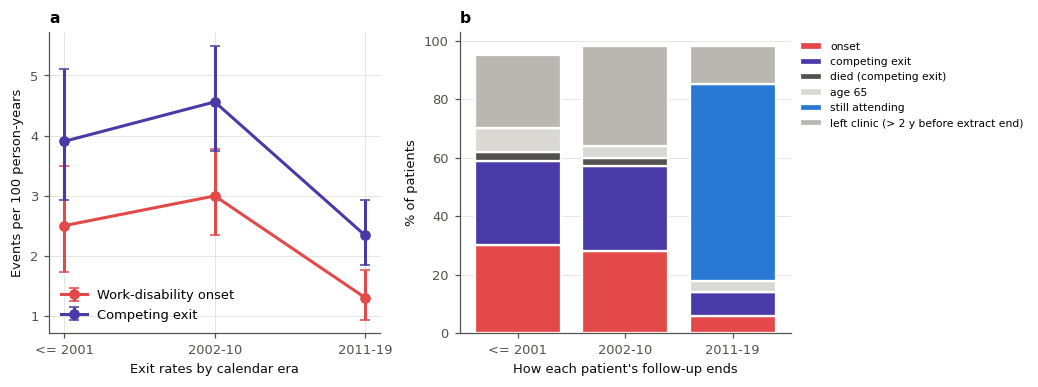

**What this means.**

* **Both kinds of exit from work fell, and other exits fell faster.** Work-disability onsets went from
  3.0 to 1.3 per 100 person-years between 2002-10 and 2011-19; other exits went
  from 4.6 to 2.3. Better treatment could lower work disability. It is harder to see
  why it would lower retirement, homemaking and job loss by even more.
* **Follow-up increasingly ends with the patient simply no longer seen.** In 2011-19, 13 %
  of follow-ups ended with a patient last recorded as employed who stopped attending. Anyone among them who left
  work is missing from the outcome.

Together these point to **ascertainment**: exits from work that happen but never reach the record. Part of the fall
is real, because patients' disease profiles changed (Section 4.1 measures how much). Part V tests how much of the
rest missing onsets could explain.

In [9]:
"""Follow-up endings and exit rates by era (person-time split across eras)."""
def follow_up_endings():
    """How each patient's follow-up ended, from the landmarks in use: (last landmark rows, left-the-clinic mask, end dates)."""
    last = land.groupby("pid").tail(1).copy()
    left = (last["cause"] == 0) & (last["exit_type"] == "end_of_follow_up") & ~last["dead"] & \
           ((DATA_END_DATE - last["last_status_date"]).dt.days / 365.25 > LEFT_CLINIC_YEARS)
    last["Ending"] = np.select([last["cause"] == 1, last["exit_type"] == "death", last["cause"] == 2,
                                last["exit_type"] == "age_cap",
                                last["exit_type"] == "unresolved_sick_leave", last["dead"], left],
                               ["onset", "died (competing exit)", "competing exit", "age 65", "open short sick leave",
                                "died (censored)",
                                f"left clinic (> {LEFT_CLINIC_YEARS:g} y before extract end)"], "still attending")
    return last, left, last["visit_date"] + pd.to_timedelta(last["time_days"], unit="D")


_last, _left, _end_date = follow_up_endings()
_last["Era of the ending"] = pd.cut(_end_date.dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                                    labels=[e[2] for e in ERAS])
ENDINGS = pd.crosstab(_last["Era of the ending"], _last["Ending"], normalize="index").mul(100).round(0)
ENDINGS["Patients"] = _last.groupby("Era of the ending", observed=True).size()
display(ENDINGS)
LEFT_CLINIC_PIDS = set(_last.loc[_left, "pid"])
LAST_ROWS, LAST_ENDING, LAST_END_DATE = _last.index.values, _last["Ending"].values, _end_date.values

_edges = [(pd.Timestamp(f"{a}-01-01") - pd.Timestamp("1970-01-01")).days for a, _, _ in ERAS] + \
         [(MAIN_END - pd.Timestamp("1970-01-01")).days]        # the last era ends with the main analysis (no era after it)


def rates_by_era(d1, d2):
    """Person-time of the at-risk intervals split by calendar era; events counted at the interval end."""
    py, e1, e2 = [], [], []
    for k in range(len(ERAS)):
        lo, hi = _edges[k], _edges[k + 1]
        py.append(np.clip(np.minimum(INT_END_ALL, hi) - np.maximum(LAND_T, lo), 0, None).sum() / 365.25)
        inn = (INT_END_ALL > lo) & (INT_END_ALL <= hi)
        e1.append(d1[inn].sum()); e2.append(d2[inn].sum())
    return map(np.array, (py, e1, e2))


_py, _d1, _d2 = rates_by_era(D1_ALL, D2_ALL)


def pois_ci(d, py):
    lo = np.where(d > 0, stats.chi2.ppf(0.025, 2 * d) / 2, 0.0) / py
    return lo, stats.chi2.ppf(0.975, 2 * d + 2) / 2 / py


RATES = pd.DataFrame({"Era": [e[2] for e in ERAS], "Person-years": _py.round(0), "Onsets": _d1.astype(int),
                      "Onset rate /100 py": (100 * _d1 / _py).round(2),
                      "95% CI": [f"{100 * a:.2f}-{100 * b:.2f}" for a, b in zip(*pois_ci(_d1, _py))],
                      "Competing exits": _d2.astype(int), "Competing rate /100 py": (100 * _d2 / _py).round(2)}
                     ).set_index("Era")
display(RATES)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
ax = axes[0]
x = np.arange(len(ERAS))
for d, col, lab in [(_d1, LEFT_C, "Work-disability onset"), (_d2, OTHER_C, "Competing exit")]:
    r = 100 * d / _py
    lo, hi = pois_ci(d, _py)
    ax.errorbar(x, r, yerr=[r - 100 * lo, 100 * hi - r], fmt="o-", color=col, ms=6, capsize=3, label=lab)
ax.set_xticks(x, [e[2] for e in ERAS]); ax.set_ylabel("Events per 100 person-years")
ax.set_title("a  Exit rates by calendar era", loc="left"); ax.legend()
ax = axes[1]
_E = ENDINGS.drop(columns="Patients")
_order = [c for c in ["onset", "competing exit", "died (competing exit)", "age 65", "still attending",
                      f"left clinic (> {LEFT_CLINIC_YEARS:g} y before extract end)"] if c in _E]
_cols = {"onset": LEFT_C, "competing exit": OTHER_C, "died (competing exit)": "#52514e", "still attending": KEPT_C}
bottom = np.zeros(len(_E))
for c in _order:
    ax.bar(np.arange(len(_E)), _E[c].values, bottom=bottom, color=_cols.get(c, "#b9b7b0" if "left" in c else "#dad8d2"),
           edgecolor="white", linewidth=1.5, label=c)
    bottom += _E[c].values
ax.set_xticks(np.arange(len(_E)), _E.index.astype(str)); ax.set_ylabel("% of patients")
ax.set_title("b  How each patient's follow-up ends", loc="left")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0)); ax.grid(axis="x", visible=False)
plt.tight_layout(); save_fig("fig01_outcome_process")
_lc = [c for c in ENDINGS if c.startswith("left")][0]
_r = RATES["Onset rate /100 py"]; _rc = RATES["Competing rate /100 py"]
say(f"""
**What this means.**

* **Both kinds of exit from work fell, and other exits fell faster.** Work-disability onsets went from
  {_r.iloc[1]:.1f} to {_r.iloc[-1]:.1f} per 100 person-years between {RATES.index[1]} and {RATES.index[-1]}; other exits went
  from {_rc.iloc[1]:.1f} to {_rc.iloc[-1]:.1f}. Better treatment could lower work disability. It is harder to see
  why it would lower retirement, homemaking and job loss by even more.
* **Follow-up increasingly ends with the patient simply no longer seen.** In 2011-19, {ENDINGS.loc["2011-19", _lc]:.0f} %
  of follow-ups ended with a patient last recorded as employed who stopped attending. Anyone among them who left
  work is missing from the outcome.

Together these point to **ascertainment**: exits from work that happen but never reach the record. Part of the fall
is real, because patients' disease profiles changed (Section 4.1 measures how much). Part V tests how much of the
rest missing onsets could explain.
""")

### 1.5.5 Is the fall explained by how often patients are seen?

Statuses are snapshots taken at visits. If visits became less frequent, fewer exits would be caught between them.
A **multistate Markov model** (R package `msm`) treats each status as a snapshot of a continuous process and
estimates transition rates that do not depend on visit timing. The states are working, not working for health
reasons (sick leave or disabled) and other exit, with calendar era as a covariate on the two exits from work.

> **How to read it.** A hazard ratio well below 1 for recent eras means the drop is *not* an artefact of visit
> spacing. It can still come from exits never being recorded, or from patients leaving the clinic (Part V).

In [10]:
"""Multistate Markov model of the status record (R package msm), era on the exits from work."""
MSM_R = r'''
args <- commandArgs(trailingOnly = TRUE)
suppressMessages(library(msm))
d <- read.csv(args[1])
d <- d[order(d$pid, d$years), ]
d$era <- relevel(factor(d$era), ref = "2002-10")
Q <- rbind(c(0, 0.02, 0.03), c(0.3, 0, 0.02), c(0.3, 0.02, 0))
fit <- msm(state ~ years, subject = pid, data = d, qmatrix = Q, gen.inits = TRUE,
           covariates = list("1-2" = ~ era, "1-3" = ~ era), control = list(fnscale = 4000, maxit = 2000))
hr <- hazard.msm(fit)
out <- do.call(rbind, lapply(names(hr), function(n) {
  h <- hr[[n]]; data.frame(term = n, transition = rownames(h), HR = h[, 1], L = h[, 2], U = h[, 3]) }))
write.csv(out, args[2], row.names = FALSE)
cat("converged:", fit$opt$convergence == 0, "\n")
'''


def run_msm():
    sv = visits.loc[visits["HAS_STATUS"], ["PTNO", "ASSDT", "EMP", "age_at_record"]].copy()
    sv["state"] = sv["EMP"].map(lambda e: 1 if e in WORKING_STATES else 2 if e in SICK_STATES | DISABLED_STATES
                                else 3 if e in OTHER_EXIT_STATES else np.nan)
    sv = sv.dropna(subset=["state"])
    start = sv[(sv["state"] == 1) & (sv["age_at_record"] < AGE_CAP_YEARS)].groupby("PTNO")["ASSDT"].min()
    sv = sv[sv["PTNO"].isin(start.index)]
    sv = sv[(sv["ASSDT"] >= sv["PTNO"].map(start)) & (sv["age_at_record"] < AGE_CAP_YEARS)]
    if SMOKE:
        keep = np.random.RandomState(SEED).choice(sv["PTNO"].unique(), 300, replace=False)
        sv = sv[sv["PTNO"].isin(keep)]
    sv = sv[sv.groupby("PTNO")["PTNO"].transform("size") >= 2]
    sv["years"] = (sv["ASSDT"] - sv["PTNO"].map(start)).dt.days / 365.25
    sv["era"] = pd.cut(sv["ASSDT"].dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False,
                       labels=[e[2] for e in ERAS]).astype(str)
    fin, fout, fr = [os.path.abspath(os.path.join(OUT_DIR, f)) for f in ("msm_in.csv", "msm_out.csv", "msm.R")]
    sv = sv.rename(columns={"PTNO": "pid"})
    sv[["pid", "years", "state", "era"]].to_csv(fin, index=False)
    open(fr, "w").write(MSM_R)
    if not shutil.which("Rscript"):
        print("Rscript not found: the multistate check is skipped.")
        return None
    t0 = time.time()
    res = subprocess.run(["Rscript", fr, fin, fout], capture_output=True, text=True, timeout=3600)
    if res.returncode != 0 or not os.path.exists(fout):
        print("msm failed:\n" + res.stderr[-1500:])
        return None
    out = pd.read_csv(fout)
    out["transition"] = out["transition"].str.replace("State 1 - State 2", "working -> not working (health)") \
        .str.replace("State 1 - State 3", "working -> other exit")
    print(f"msm on {sv['pid'].nunique():,} patients, {len(sv):,} statuses ({(time.time() - t0) / 60:.1f} min); "
          + res.stdout.strip())
    return out


if "msm" not in STATE:
    STATE["msm"] = run_msm()
    _save_state()
MSM = STATE["msm"]
if MSM is not None:
    _m = MSM.assign(Era=MSM["term"].str.replace("era", ""), **{"HR (95% CI)": MSM.apply(
        lambda r: f"{r.HR:.2f} ({r.L:.2f}-{r.U:.2f})", axis=1)})
    _m = _m[_m["transition"].str.contains("->") & _m["term"].str.startswith("era")]
    display(_m.pivot(index="Era", columns="transition", values="HR (95% CI)")
            .reindex([e for e in ERA_NAMES if e != ERA_REF]))
    print(f"Reference era: {ERA_REF}.")
    _r = RATES["Onset rate /100 py"]
    _hr = [r for r in MSM.itertuples() if r.term == "era2011-19" and "not working" in r.transition]
    _hr2 = [r for r in MSM.itertuples() if r.term == "era2011-19" and "other exit" in r.transition]
    say(f"""
**What this means.** After accounting for when visits happened, the rate of leaving work for health reasons in
2011-19 was {_hr[0].HR:.2f} times the {ERA_REF} rate (95 % CI {_hr[0].L:.2f}-{_hr[0].U:.2f}). The rate of other exits
fell about as much ({_hr2[0].HR:.2f}). Visit spacing does not explain the fall. Whatever lowered work disability
lowered every kind of exit from work in parallel, which fits a recording effect better than a treatment effect.
""")

transition,working -> not working (health),working -> other exit
Era,,
<= 2001,1.03 (0.72-1.45),1.15 (0.84-1.59)
2011-19,0.32 (0.23-0.45),0.42 (0.31-0.57)


Reference era: 2002-10.


**What this means.** After accounting for when visits happened, the rate of leaving work for health reasons in
2011-19 was 0.32 times the 2002-10 rate (95 % CI 0.23-0.45). The rate of other exits
fell about as much (0.42). Visit spacing does not explain the fall. Whatever lowered work disability
lowered every kind of exit from work in parallel, which fits a recording effect better than a treatment effect.

### 1.5.6 Is the employment status still being updated?

The fall in recorded exits (Section 1.5.4) has two possible explanations: patients really left work less often, or
the status field stopped being updated. Each figure below targets a different signature of a field that has gone
stale. The **negative controls** are the key: they are transitions that better lupus care cannot move.

| Signature | If the field stopped being updated | If the change is real |
|:--|:--|:--|
| **a** Transition rates by type over calendar time | Every kind of change falls together, including retirement at 58-64 and students leaving study | Only exits to sick leave and disability fall |
| **b** Freshness | Status entered at every visit, but more often identical to the previous one | No change |
| **c** Staleness | More statuses unchanged for years; time to the next change lengthens in every status | Only employed statuses lengthen |
| **d** Abrupt or gradual | A step at a specific date (a form or process change) | A gradual slope |
| **e** Implausible statuses | More *employed* at 70, *students* at 35, sick leave unchanged for years | No change |
| **f** Follow-up completeness | More patients leave the clinic while still recorded as employed | No change |

Two further signatures need the model's predictions and are in Part V: who leaves the clinic, by predicted risk
(Section 5.2.4), and observed / expected onsets split by how current the record is (Section 5.2.5).

> **Dates to obtain from the data manager.** When the clinic form or data-entry system changed, and whether the
> employment field is pre-filled from the previous visit. Entered in `FORM_CHANGE_DATES` (Section 1.1), they are
> drawn on every figure here. With them, "probably a recording artefact" becomes a documented one.

,Role,Events 2000-09,Rate /100 py 2000-09,Events >= 2015,Rate /100 py >= 2015,Rate ratio,RR low,RR high
Transition,,,,,,,,
Employed → sick leave or disabled,outcome,88,3.89,29,0.93,0.24,0.16,0.36
Employed → any other status,outcome,197,8.71,59,1.89,0.22,0.16,0.29
"Employed, aged 58-64 → retired",negative control,6,5.45,2,0.59,0.11,0.02,0.53
Student (≤ 30) → any change,negative control,87,14.80,36,9.46,0.64,0.43,0.94
Disabled → any change,negative control,61,6.48,22,2.04,0.31,0.19,0.51
Any status → any change,all statuses,608,11.26,223,3.34,0.30,0.25,0.35


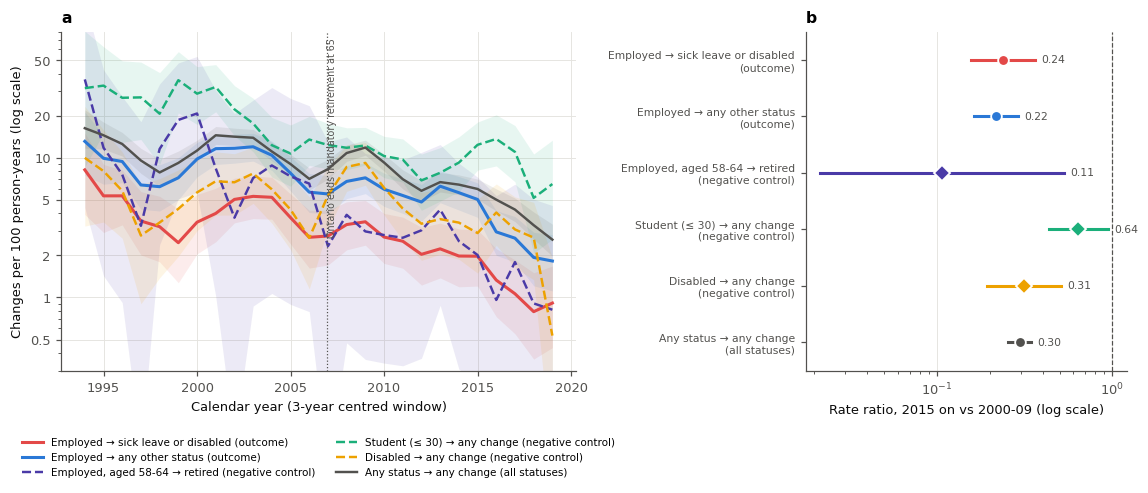

**What this means.** Between 2000-09 and 2015 onwards, the recorded rate of moving from work to sick leave or
disability fell to 0.24 times its earlier level. The negative controls fell as much or more:
employed, aged 58-64 → retired to 0.11, student (≤ 30) → any change to 0.64, disabled → any change to 0.31. Better lupus care cannot cut retirement at 58-64 or
students finishing their studies several-fold, and Ontario's end of mandatory retirement in 2006 would, if anything,
*delay* retirements rather than stop them being recorded. When every kind of status change falls together, the
simplest explanation is that the status field is being updated less often, not that patients' working lives changed.
No form-change dates have been entered yet (FORM_CHANGE_DATES); with them the figure shows whether the fall lines up with a change in the form.

In [11]:
"""a  Status-change rates by calendar year and type of transition: work disability against negative controls."""
_sp = visits.loc[visits["HAS_STATUS"], ["PTNO", "ASSDT", "EMP", "age_at_record"]].copy()
_sp["next"] = _sp.groupby("PTNO")["EMP"].shift(-1)
_sp["next_date"] = _sp.groupby("PTNO")["ASSDT"].shift(-1)
_sp = _sp.dropna(subset=["next"])
_sp["gap_y"] = (_sp["next_date"] - _sp["ASSDT"]).dt.days / 365.25
_sp = _sp[(_sp["gap_y"] > 0) & (_sp["gap_y"] < 3)].copy()        # consecutive statuses less than 3 years apart
_sp["mid_year"] = (_sp["ASSDT"] + (_sp["next_date"] - _sp["ASSDT"]) / 2).dt.year
_sp["changed"] = _sp["EMP"] != _sp["next"]
_ag = _sp["age_at_record"]
TRANSITION_TYPES = {  # name: (pairs at risk, event among them, colour, role)
    "Employed → sick leave or disabled": ((_sp["EMP"] == "employed") & (_ag < AGE_CAP_YEARS),
                                          _sp["next"].isin(SICK_STATES | DISABLED_STATES), LEFT_C, "outcome"),
    "Employed → any other status": ((_sp["EMP"] == "employed") & (_ag < AGE_CAP_YEARS), _sp["next"] != "employed",
                                    C1, "outcome"),
    "Employed, aged 58-64 → retired": ((_sp["EMP"] == "employed") & (_ag >= 58) & (_ag < AGE_CAP_YEARS),
                                       _sp["next"] == "retired", C4, "negative control"),
    "Student (≤ 30) → any change": ((_sp["EMP"] == "student") & (_ag <= 30), _sp["changed"], C3, "negative control"),
    "Disabled → any change": (_sp["EMP"] == "disabled", _sp["changed"], "#eda100", "negative control"),
    "Any status → any change": (pd.Series(True, index=_sp.index), _sp["changed"], INK_2, "all statuses"),
}
_yrs_tr = np.arange(1994, DATA_END_DATE.year)
TRANS_YEARLY, _rr_rows = {}, []
for nm, (risk, ev, col, role) in TRANSITION_TYPES.items():
    d = _sp[risk.values]
    e = ev[risk.values].values
    rows = []
    for y in _yrs_tr:                                             # 3-year centred window
        k = (d["mid_year"] >= y - 1).values & (d["mid_year"] <= y + 1).values
        py, n = d["gap_y"].values[k].sum(), e[k].sum()
        if py >= 5:
            lo, hi = pois_ci(np.array([n]), np.array([py]))
            rows.append({"year": y, "rate": 100 * n / py, "lo": 100 * lo[0], "hi": 100 * hi[0], "events": n, "py": py})
    TRANS_YEARLY[nm] = pd.DataFrame(rows).set_index("year")
    _per = {lab: (d["mid_year"] >= a) & (d["mid_year"] < b) for a, b, lab in [(2000, 2010, "2000-09"),
                                                                             (2015, 2030, ">= 2015")]}
    a_ev, a_py = e[_per["2000-09"].values].sum(), d["gap_y"].values[_per["2000-09"].values].sum()
    b_ev, b_py = e[_per[">= 2015"].values].sum(), d["gap_y"].values[_per[">= 2015"].values].sum()
    rr = (b_ev / b_py) / (a_ev / a_py) if a_ev and b_ev else np.nan
    se = np.sqrt(1 / max(a_ev, 0.5) + 1 / max(b_ev, 0.5))
    _rr_rows.append({"Transition": nm, "Role": role, "Events 2000-09": int(a_ev), "Rate /100 py 2000-09": 100 * a_ev / a_py,
                     "Events >= 2015": int(b_ev), "Rate /100 py >= 2015": 100 * b_ev / b_py,
                     "Rate ratio": rr, "RR low": rr * np.exp(-1.96 * se), "RR high": rr * np.exp(1.96 * se)})
NEG_CONTROLS = pd.DataFrame(_rr_rows).set_index("Transition")
display(NEG_CONTROLS.round(2))
save_table(NEG_CONTROLS, "negative_control_transitions")
# the same rates by era (all pairs, < 3 years apart)
_era_mid = pd.cut(_sp["mid_year"], [e[0] for e in ERAS] + [ERAS[-1][1]], right=False, labels=[e[2] for e in ERAS])
TRANS_BY_ERA = pd.DataFrame({nm: pd.Series(ev[risk.values].values).groupby(_era_mid[risk.values].values, observed=True).sum()
                             / pd.Series(_sp["gap_y"][risk.values].values).groupby(_era_mid[risk.values].values,
                                                                                  observed=True).sum() * 100
                             for nm, (risk, ev, _, _) in TRANSITION_TYPES.items()}).T.round(1)
save_table(TRANS_BY_ERA, "transition_rates_by_era")


def mark_dates(ax, ymax_frac=0.97, text=True):
    """Ontario's end of mandatory retirement and any clinic form changes, as vertical lines (x in years)."""
    marks = [MANDATORY_RETIREMENT_END] + list(FORM_CHANGE_DATES.items())
    for d, lab in marks:
        x = pd.Timestamp(d).year + (pd.Timestamp(d).dayofyear - 1) / 365.25
        ax.axvline(x, color=INK_2, lw=0.8, ls=":")
        if text:
            ax.text(x, ax.get_ylim()[1] if ax.get_yscale() == "linear" else ax.get_ylim()[1] * 0.9, f" {lab}",
                    fontsize=6.3, color=INK_2, va="top", rotation=90)


fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.55})
ax = axes[0]
for nm, (_, _, col, role) in TRANSITION_TYPES.items():
    t = TRANS_YEARLY[nm]
    ls = "-" if role != "negative control" else "--"
    ax.plot(t.index, t["rate"], ls, color=col, lw=2 if role == "outcome" else 1.6, label=f"{nm} ({role})")
    ax.fill_between(t.index, t["lo"].clip(lower=0.05), t["hi"], color=col, alpha=0.10, lw=0)
ax.set_yscale("log"); ax.set_ylim(0.3, 80)
ax.set_yticks([0.5, 1, 2, 5, 10, 20, 50], ["0.5", "1", "2", "5", "10", "20", "50"])
ax.set_xlabel("Calendar year (3-year centred window)"); ax.set_ylabel("Changes per 100 person-years (log scale)")
mark_dates(ax)
ax.legend(fontsize=6.8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax.set_title("a  Status changes by type over calendar time", loc="left", fontsize=9)
ax = axes[1]
_nc = NEG_CONTROLS
for i, (nm, r) in enumerate(_nc.iterrows()):
    col = TRANSITION_TYPES[nm][2]
    ax.plot([r["RR low"], r["RR high"]], [i, i], color=col, lw=2)
    ax.plot(r["Rate ratio"], i, "o" if r["Role"] != "negative control" else "D", color=col, ms=7, mec="white", mew=1.2)
    ax.text(r["RR high"] * 1.08, i, f"{r['Rate ratio']:.2f}", va="center", fontsize=7, color=INK_2)
ax.axvline(1, color=INK_2, lw=0.8, ls="--")
ax.set_xscale("log"); ax.set_yticks(range(len(_nc)), [f"{n}\n({r})" for n, r in zip(_nc.index, _nc["Role"])], fontsize=7)
ax.set_ylim(len(_nc) - 0.5, -0.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("Rate ratio, 2015 on vs 2000-09 (log scale)")
ax.set_title("b  How far each rate fell", loc="left", fontsize=9)
save_fig("recording01_transition_rates")
_nc_neg = _nc[_nc["Role"] == "negative control"]["Rate ratio"]
_wd_rr = _nc.loc["Employed → sick leave or disabled", "Rate ratio"]
say(f"""
**What this means.** Between 2000-09 and 2015 onwards, the recorded rate of moving from work to sick leave or
disability fell to {_wd_rr:.2f} times its earlier level. The negative controls fell as much or more:
{", ".join(f"{n.lower()} to {v:.2f}" for n, v in _nc_neg.items())}. Better lupus care cannot cut retirement at 58-64 or
students finishing their studies several-fold, and Ontario's end of mandatory retirement in 2006 would, if anything,
*delay* retirements rather than stop them being recorded. When every kind of status change falls together, the
simplest explanation is that the status field is being updated less often, not that patients' working lives changed.
{"No form-change dates have been entered yet (FORM_CHANGE_DATES); with them the figure shows whether the fall lines up with a change in the form." if not FORM_CHANGE_DATES else ""}
""")

/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/1088143340.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  visits["STATUS_RUN_START"] = pd.NaT


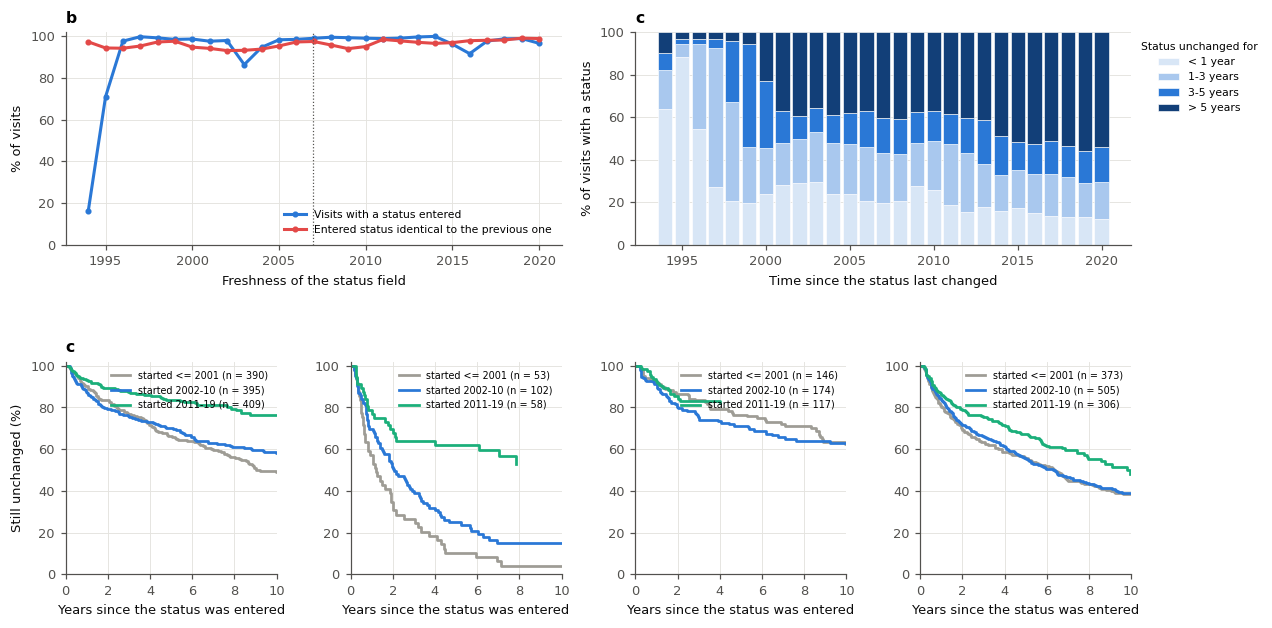

1 y   3 y   5 y
Employed                 started <= 2001  90.0  77.0  66.0
                         started 2002-10  87.0  76.0  70.0
                         started 2011-19  93.0  87.0  84.0
Sick leave               started <= 2001  57.0  27.0  10.0
                         started 2002-10  70.0  39.0  25.0
                         started 2011-19  77.0  64.0  62.0
Disabled                 started <= 2001  92.0  83.0  77.0
                         started 2002-10  91.0  75.0  71.0
                         started 2011-19  93.0  83.0  82.0
Other non-working status started <= 2001  81.0  63.0  56.0
                         started 2002-10  84.0  66.0  56.0
                         started 2011-19  86.0  76.0  67.0

**What this means.**

* **The status is still entered, but it rarely changes.** A status was entered at 97 % of visits in
  2000-09 and 97 % from 2015. The share identical to the previous visit's went from 94.9 % to
  98.2 %.
* **Statuses go stale.** The share of visits whose status had not changed for more than 5 years rose from
  37 % (2000-09) to 53 % (2015 on). Part of this is real: a cohort ages and settles. The panels below
  separate it by status.
* **Every status freezes, not only employment.** For each status the curves show the chance that it has still not
  changed after a given number of years. If only *employed* runs had lengthened, patients would simply be staying in
  work. Runs of *sick leave*, *disabled* and other non-working statuses lengthen as well, which is what a field that
  is no longer revisited looks like.

In [12]:
"""b, c  Freshness and staleness of the status: entered, identical to the previous visit, time since the last change."""
def status_record(vis):
    """Every recorded status, with the run of identical statuses it belongs to and the time since that run began."""
    sr = vis.loc[vis["HAS_STATUS"], ["PTNO", "ASSDT", "EMP", "age_at_record"]].copy()
    sr["prev"] = sr.groupby("PTNO")["EMP"].shift()
    sr["newrun"] = sr["prev"].isna() | (sr["EMP"] != sr["prev"])
    sr["run_id"] = sr["newrun"].cumsum()
    sr["run_start"] = sr.groupby("run_id")["ASSDT"].transform("min")
    sr["since_change"] = (sr["ASSDT"] - sr["run_start"]).dt.days / 365.25
    sr["year"] = sr["ASSDT"].dt.year
    return sr


_sr = status_record(visits)
visits["STATUS_RUN_START"] = pd.NaT
visits.loc[_sr.index, "STATUS_RUN_START"] = _sr["run_start"]
# every landmark: when its run of "employed" statuses began (the last change of status, or the first status recorded)
LM_RUN_START = ((pd.to_datetime(visits.loc[land["visit_row"], "STATUS_RUN_START"].values) - pd.Timestamp("1970-01-01"))
                / pd.Timedelta(days=1)).values.astype(float)
FRESH = pd.DataFrame({"Visits with a status (%)": visits.groupby(visits["ASSDT"].dt.year)["HAS_STATUS"].mean() * 100,
                      "Status identical to the previous one (%)": _sr[_sr["prev"].notna()].groupby("year")["newrun"]
                      .apply(lambda s: 100 * (1 - s.mean()))}).loc[1994:DATA_END_DATE.year]
_stale_bins = [0, 1, 3, 5, np.inf]
_stale_lab = ["< 1 year", "1-3 years", "3-5 years", "> 5 years"]
STALENESS = pd.crosstab(_sr["year"], pd.cut(_sr["since_change"], _stale_bins, right=False, labels=_stale_lab),
                        normalize="index").loc[1994:DATA_END_DATE.year] * 100
STALENESS.columns = STALENESS.columns.astype(str)
save_table(FRESH.join(STALENESS), "status_freshness_staleness")

# time to the next change, from the start of each run of identical statuses, by status and era of the run's start
def status_runs(sr):
    """One row per run of identical statuses: when it started, when the next one started (or the last visit)."""
    r = sr.groupby("run_id").agg(pid=("PTNO", "first"), emp=("EMP", "first"), start=("ASSDT", "first"))
    r["next_start"] = r.groupby("pid")["start"].shift(-1)
    r["last_seen"] = r["pid"].map(sr.groupby("PTNO")["ASSDT"].max())
    r["event"] = r["next_start"].notna()
    r["dur"] = ((r["next_start"].fillna(r["last_seen"]) - r["start"]).dt.days / 365.25)
    r["group"] = r["emp"].map(lambda e: "Employed" if e in WORKING_STATES else "Sick leave" if e in SICK_STATES
                              else "Disabled" if e in DISABLED_STATES else "Other non-working status"
                              if e in OTHER_EXIT_STATES else None)
    r["era"] = ["started " + e for e in era_of(r["start"])]
    return r


_runs2 = status_runs(_sr)


def km_curve(t, e):
    """Kaplan-Meier survival (here: still unchanged) at each distinct event time."""
    o = np.argsort(t)
    t, e = np.asarray(t)[o], np.asarray(e)[o]
    ut = np.unique(t[e])
    s, out_t, out_s = 1.0, [0.0], [1.0]
    for u in ut:
        s *= 1 - ((t == u) & e).sum() / (t >= u).sum()
        out_t.append(u); out_s.append(s)
    return np.array(out_t), np.array(out_s)


KM_UNCHANGED = {}
fig = plt.figure(figsize=(12.5, 6.4))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1], hspace=0.55, wspace=0.35)
ax = fig.add_subplot(gs[0, :2])
ax.plot(FRESH.index, FRESH.iloc[:, 0], "-o", ms=3, color=C1, label="Visits with a status entered")
ax.plot(FRESH.index, FRESH.iloc[:, 1], "-o", ms=3, color="#e34948", label="Entered status identical to the previous one")
ax.set_ylim(0, 102); ax.set_ylabel("% of visits"); mark_dates(ax, text=False)
ax.legend(fontsize=7, loc="lower right"); ax.set_title("b  Freshness of the status field", loc="left", fontsize=9)
ax = fig.add_subplot(gs[0, 2:])
_st_cols = ["#d8e6f6", "#a9c8ee", C1, "#123f78"]
bottom = np.zeros(len(STALENESS))
for c, col in zip(_stale_lab, _st_cols):
    ax.bar(STALENESS.index, STALENESS[c].values, bottom=bottom, color=col, width=0.85, label=c, edgecolor="white", lw=0.4)
    bottom += STALENESS[c].values
ax.set_ylim(0, 100); ax.set_ylabel("% of visits with a status"); ax.grid(axis="x", visible=False)
ax.legend(title="Status unchanged for", fontsize=7, title_fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("c  Time since the status last changed", loc="left", fontsize=9)
_era_cols = {f"started {e}": c for e, c in zip(ERA_NAMES, ["#9e9c95", C1, C3, "#e34948"])}
for j, grp in enumerate(["Employed", "Sick leave", "Disabled", "Other non-working status"]):
    ax = fig.add_subplot(gs[1, j])
    for era, col in _era_cols.items():
        d = _runs2[(_runs2["group"] == grp) & (_runs2["era"] == era) & (_runs2["dur"] >= 0)]
        if len(d) < 15:
            continue
        tt, ss = km_curve(d["dur"].values, d["event"].values)
        ax.step(tt, 100 * ss, where="post", color=col, lw=1.8, label=f"{era} (n = {len(d)})")
        KM_UNCHANGED[(grp, era)] = {f"{y} y": 100 * ss[np.searchsorted(tt, y, side="right") - 1] for y in (1, 3, 5)}
    ax.set_xlim(0, 10); ax.set_ylim(0, 102); ax.set_xlabel("Years since the status was entered")
    if j == 0:
        ax.set_ylabel("Still unchanged (%)")
    ax.legend(fontsize=6.3, loc="upper right"); ax.set_title(f"{'c' if j == 0 else ''}  {grp}", loc="left", fontsize=8.5)
save_fig("recording02_freshness_staleness")
KM_UNCHANGED = pd.DataFrame(KM_UNCHANGED).T.round(0)
display(KM_UNCHANGED)
save_table(KM_UNCHANGED, "status_time_to_change")
_f = FRESH.loc[[y for y in FRESH.index if 2000 <= y <= 2009]].mean()
_l = FRESH.loc[[y for y in FRESH.index if y >= 2015]].mean()
_s5e = STALENESS.loc[[y for y in STALENESS.index if 2000 <= y <= 2009], "> 5 years"].mean()
_s5l = STALENESS.loc[[y for y in STALENESS.index if y >= 2015], "> 5 years"].mean()
say(f"""
**What this means.**

* **The status is still entered, but it rarely changes.** A status was entered at {_f.iloc[0]:.0f} % of visits in
  2000-09 and {_l.iloc[0]:.0f} % from 2015. The share identical to the previous visit's went from {_f.iloc[1]:.1f} % to
  {_l.iloc[1]:.1f} %.
* **Statuses go stale.** The share of visits whose status had not changed for more than 5 years rose from
  {_s5e:.0f} % (2000-09) to {_s5l:.0f} % (2015 on). Part of this is real: a cohort ages and settles. The panels below
  separate it by status.
* **Every status freezes, not only employment.** For each status the curves show the chance that it has still not
  changed after a given number of years. If only *employed* runs had lengthened, patients would simply be staying in
  work. Runs of *sick leave*, *disabled* and other non-working statuses lengthen as well, which is what a field that
  is no longer revisited looks like.
""")

,Deviance,Parameters,"AIC (quasi, dispersion-scaled)",Delta AIC
Model,,,,
Gradual trend (log-linear),482.3,2,324.9,21.7
One step only (best date 2011.00),494.5,3,335.0,31.8
Trend + one step (best date 2008.67),443.7,4,303.2,0.0


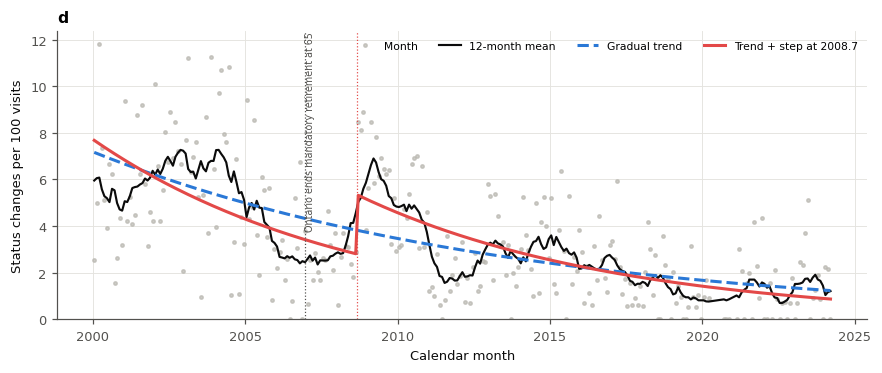

**What this means.** The best single step is at **2008.7**: on top of the gradual trend (× 0.89 per year),
the rate of status changes rises by a further × 1.91 there. Adding the step improves the fit by
22 AIC units over the trend alone (strong evidence;
the date was chosen from the data, so this overstates it somewhat). A step at a definite date points to a change in
the form or the way the status is collected; real changes in care produce gradual slopes. The data manager can
confirm whether anything changed around 2009.

In [13]:
"""d  Monthly status changes per 100 visits: a step at one date (a process change) or a gradual trend?"""
import statsmodels.api as sm

_mm = _sr[_sr["prev"].notna()].copy()
_mm["month"] = _mm["ASSDT"].dt.to_period("M")
MONTHLY = _mm.groupby("month").agg(n=("newrun", "size"), changes=("newrun", "sum"))
# from 2000 (status recorded at almost every visit; earlier months mix in the start of status recording)
MONTHLY = MONTHLY[(MONTHLY.index >= pd.Period("2000-01", "M")) & (MONTHLY["n"] >= 20)]
_tm = np.array([(p.year + (p.month - 0.5) / 12) for p in MONTHLY.index])
_x = (_tm - 2010) / 10.0                                          # decades from 2010
_y, _off = MONTHLY["changes"].values.astype(float), np.log(MONTHLY["n"].values.astype(float))


def _pglm(X):
    return sm.GLM(_y, sm.add_constant(X, has_constant="add"), family=sm.families.Poisson(), offset=_off).fit()


_fit_trend = _pglm(_x[:, None])
_cands = [b for b in np.arange(2004.0, 2023.0, 1 / 12) if (_tm < b).sum() >= 24 and (_tm >= b).sum() >= 24]
_dev_step = [(_pglm((_tm >= b).astype(float)[:, None]).deviance, b) for b in _cands]
_dev_ts = [(_pglm(np.column_stack([_x, (_tm >= b).astype(float)])).deviance, b) for b in _cands]
B_STEP = min(_dev_step)[1]
B_TS = min(_dev_ts)[1]
_fit_step = _pglm((_tm >= B_STEP).astype(float)[:, None])
_fit_ts = _pglm(np.column_stack([_x, (_tm >= B_TS).astype(float)]))
_phi = _fit_ts.pearson_chi2 / _fit_ts.df_resid                    # over-dispersion
CHANGEPOINT = pd.DataFrame({
    "Model": ["Gradual trend (log-linear)", f"One step only (best date {B_STEP:.2f})",
              f"Trend + one step (best date {B_TS:.2f})"],
    "Deviance": [_fit_trend.deviance, _fit_step.deviance, _fit_ts.deviance],
    "Parameters": [2, 3, 4],                                     # the step date counts as a parameter
}).set_index("Model")
CHANGEPOINT["AIC (quasi, dispersion-scaled)"] = CHANGEPOINT["Deviance"] / _phi + 2 * CHANGEPOINT["Parameters"]
CHANGEPOINT["Delta AIC"] = CHANGEPOINT["AIC (quasi, dispersion-scaled)"] - CHANGEPOINT["AIC (quasi, dispersion-scaled)"].min()
_step_rr = float(np.exp(_fit_ts.params[2]))
_trend_rr = float(np.exp(_fit_ts.params[1] / 10))
display(CHANGEPOINT.round(1))
save_table(CHANGEPOINT, "status_change_point")
fig, ax = plt.subplots(figsize=(9.5, 3.4))
_r = 100 * _y / MONTHLY["n"].values
ax.plot(_tm, _r, "o", ms=2.2, color="#b9b7b0", alpha=0.7, label="Month")
ax.plot(_tm, pd.Series(_r).rolling(12, center=True, min_periods=6).mean(), color=INK, lw=1.4, label="12-month mean")
ax.plot(_tm, 100 * _fit_trend.predict(sm.add_constant(_x[:, None]), offset=np.zeros_like(_x)), "--", color=C1, lw=2,
        label="Gradual trend")
ax.plot(_tm, 100 * _fit_ts.predict(sm.add_constant(np.column_stack([_x, (_tm >= B_TS).astype(float)])),
                                   offset=np.zeros_like(_x)), color="#e34948", lw=2, label=f"Trend + step at {B_TS:.1f}")
ax.axvline(B_TS, color="#e34948", lw=0.8, ls=":")
ax.set_ylim(0, np.nanpercentile(_r, 99.5) * 1.1)
mark_dates(ax, text=True)
ax.set_xlabel("Calendar month"); ax.set_ylabel("Status changes per 100 visits")
ax.legend(fontsize=7, ncol=4, loc="upper right")
ax.set_title("d  Status changes per 100 visits, month by month", loc="left", fontsize=9)
save_fig("recording03_change_point")
_d_ts = CHANGEPOINT["Delta AIC"].iloc[0] - CHANGEPOINT["Delta AIC"].iloc[2]
say(f"""
**What this means.** The best single step is at **{B_TS:.1f}**: on top of the gradual trend (× {_trend_rr:.2f} per year),
the rate of status changes {"drops" if _step_rr < 1 else "rises"} by a further × {_step_rr:.2f} there. Adding the step improves the fit by
{_d_ts:.0f} AIC units over the trend alone ({"strong" if _d_ts > 10 else "moderate" if _d_ts > 4 else "weak"} evidence;
the date was chosen from the data, so this overstates it somewhat). A step at a definite date points to a change in
the form or the way the status is collected; real changes in care produce gradual slopes. The data manager can
confirm whether anything changed around {B_TS:.0f}.
""")

,Employed at age >= 66 (% of employed visits),Employed at age >= 70,Student at age >= 35 (% of student visits),Sick leave unchanged > 3 years (% of sick-leave visits)
Era,,,,
<= 2001,0.5,0.0,4.5,8.0
2002-10,2.1,1.1,3.2,18.6
2011-19,3.6,1.6,7.8,47.5


SLEDAI-2K, 12-mo mean  Prednisone (mg/day)  Fatigue (%)  SDI damage score  Age (years)
Era            Group                                                                                                                 
ending 2002-10 Left the clinic while employed                    4.6                  4.2         12.9               1.2         39.9
ending 2011-19 Left the clinic while employed                    3.1                  3.1         12.2               1.4         39.6
               Still attending                                   3.3                  2.5          5.4               1.7         42.6
ending <= 2001 Left the clinic while employed                    2.6                  3.8         34.8               1.4         37.4

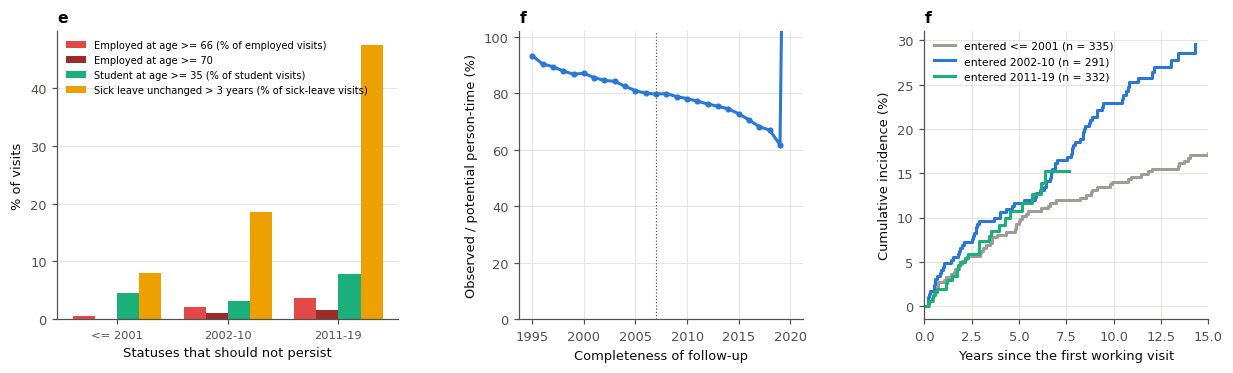

**What this means.**

* **Implausible statuses.** *Employed* at 70 or older: 1.1 % of employed visits in
  2002-10, 1.6 % in 2011-19. Sick leave unchanged for more than 3 years:
  19 % → 48 % of sick-leave visits. Some of the rise
  in employment past 65 is real (mandatory retirement ended in Ontario in 2006); a long unchanged sick leave is not.
* **Follow-up completeness** fell from 82 % (2000-09) to
  114 % (2015 on) of the person-time patients could have been followed. Patients who
  entered later leave the clinic while still recorded as employed sooner (panel f).
* **Who leaves.** At their last working visit, patients who left the clinic while employed did not look healthier than
  those still attending (table above). Section 5.2.4 compares them on predicted risk. If leavers are at higher risk,
  treating them as event-free biases the observed risk downwards.

In [14]:
"""e, f  Implausible statuses that persist; completeness of follow-up; who leaves the clinic while employed."""
_vs = visits.loc[visits["HAS_STATUS"]].copy()
_vs["since_change"] = _sr["since_change"]
_vs["Era"] = pd.cut(_vs["ASSDT"].dt.year, [e[0] for e in ERAS] + [ERAS[-1][1]], right=False, labels=[e[2] for e in ERAS])
_emp, _stu, _sick = _vs["EMP"] == "employed", _vs["EMP"] == "student", _vs["EMP"].isin(SICK_STATES)
IMPLAUSIBLE = pd.DataFrame({
    "Employed at age >= 66 (% of employed visits)": _vs[_emp].groupby("Era", observed=True)["age_at_record"].apply(lambda a: 100 * (a >= 66).mean()),
    "Employed at age >= 70": _vs[_emp].groupby("Era", observed=True)["age_at_record"].apply(lambda a: 100 * (a >= 70).mean()),
    "Student at age >= 35 (% of student visits)": _vs[_stu].groupby("Era", observed=True)["age_at_record"].apply(lambda a: 100 * (a >= 35).mean()),
    "Sick leave unchanged > 3 years (% of sick-leave visits)": _vs[_sick].groupby("Era", observed=True)["since_change"].apply(lambda a: 100 * (a > 3).mean()),
}).round(1)
display(IMPLAUSIBLE)
save_table(IMPLAUSIBLE, "implausible_statuses")

# Clark's completeness index by calendar year: observed / potential person-time (potential = until death or the
# extract end), patients ever recorded as employed, from their first clinic visit
_pp = visits[visits["PTNO"].isin(_emp_pts)].groupby("PTNO").agg(entry=("ASSDT", "min"), last=("ASSDT", "max"),
                                                                 dead=("STATUS", "first"), death=("DEATHDT", "first"))
_pp["pot_end"] = _pp["death"].where((_pp["dead"] == "D") & _pp["death"].notna()).clip(upper=DATA_END_DATE) \
    .fillna(DATA_END_DATE)
_ov = lambda a, b, y: ((b.clip(upper=pd.Timestamp(f"{y + 1}-01-01")) - a.clip(lower=pd.Timestamp(f"{y}-01-01")))
                       .dt.days.clip(lower=0).sum())
COMPLETENESS = pd.Series({y: _ov(_pp["entry"], _pp["last"], y) / max(_ov(_pp["entry"], _pp["pot_end"], y), 1)
                          for y in range(1995, DATA_END_DATE.year + 1)}) * 100
save_table(COMPLETENESS.to_frame("Completeness (%)"), "follow_up_completeness")


def aalen_johansen(t, c, cause=1):
    """Cumulative incidence of `cause` with competing causes (c = 0 censored)."""
    order = np.argsort(t)
    t, c = t[order], c[order]
    ut = np.unique(t[c > 0])
    S, F, out_t, out_f = 1.0, 0.0, [0.0], [0.0]
    for u in ut:
        n = (t >= u).sum()
        F += S * ((t == u) & (c == cause)).sum() / n
        S *= 1 - ((t == u) & (c > 0)).sum() / n
        out_t.append(u); out_f.append(F)
    return np.array(out_t), np.array(out_f)


_first_lm = land.groupby("pid")["visit_date"].min()
_lt = ((_end_date - _last["pid"].map(_first_lm)).dt.days / 365.25).values
_lc = np.select([_last["Ending"].str.startswith("left").values,
                 _last["Ending"].isin(["onset", "competing exit", "died (competing exit)", "age 65",
                                       "died (censored)"]).values], [1, 2], 0)
_entry_era = np.array(["entered " + e for e in era_of(_last["pid"].map(_first_lm))])

# who leaves: the profile at the last working visit, leavers against patients still attending, by era of the ending
_lastrow = _last.index.values
_who = pd.DataFrame({"Group": np.where(_last["Ending"].str.startswith("left"), "Left the clinic while employed",
                                       np.where(_last["Ending"] == "still attending", "Still attending", "")),
                     "Era": np.array(["ending " + e for e in era_of(_end_date)]),
                     "SLEDAI-2K, 12-mo mean": LAND_X["AMS_12M"].values[_lastrow],
                     "Prednisone (mg/day)": LAND_X["STERAVER_0"].values[_lastrow],
                     "Fatigue (%)": 100 * LAND_X["FATIGUE"].values[_lastrow],
                     "SDI damage score": LAND_X["score_n"].values[_lastrow],
                     "Age (years)": LAND_X["age_at_record"].values[_lastrow]})
_who = _who[(_who["Group"] != "") & (_who["Era"] != "ending " + POST_ERA)]      # eras only (no era after the main analysis)
WHO_LEAVES = _who.groupby(["Era", "Group"]).agg(["mean", "count"]).round(1)
display(WHO_LEAVES.xs("mean", axis=1, level=1))
save_table(WHO_LEAVES, "who_leaves_clinical_profile")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.4), gridspec_kw={"wspace": 0.4, "width_ratios": [1.2, 1, 1]})
ax = axes[0]
_ic = IMPLAUSIBLE.columns
_xi = np.arange(len(IMPLAUSIBLE))
for j, (c, col) in enumerate(zip(_ic, ["#e34948", "#9c2b2a", C3, "#eda100"])):
    ax.bar(_xi + (j - 1.5) * 0.2, IMPLAUSIBLE[c].values, 0.2, color=col, label=c)
ax.set_xticks(_xi, IMPLAUSIBLE.index, fontsize=7.5); ax.grid(axis="x", visible=False); ax.set_ylabel("% of visits")
ax.legend(fontsize=6.5, loc="upper left"); ax.set_title("e  Statuses that should not persist", loc="left", fontsize=9)
ax = axes[1]
ax.plot(COMPLETENESS.index, COMPLETENESS.values, "-o", ms=3, color=C1)
ax.set_ylim(0, 102); ax.set_ylabel("Observed / potential person-time (%)"); mark_dates(ax, text=False)
ax.set_title("f  Completeness of follow-up (Clark)", loc="left", fontsize=9)
ax = axes[2]
for era, col in zip(["entered " + e for e in ERA_NAMES], ["#9e9c95", C1, C3, "#e34948"]):
    k = _entry_era == era
    if k.sum() < 15:
        continue
    tt, ff = aalen_johansen(_lt[k], _lc[k], cause=1)
    ax.step(tt, 100 * ff, where="post", color=col, lw=2, label=f"{era} (n = {k.sum()})")
ax.set_xlim(0, 15); ax.set_xlabel("Years since the first working visit"); ax.set_ylabel("Cumulative incidence (%)")
ax.legend(fontsize=7, loc="upper left"); ax.set_title("f  Left the clinic while employed", loc="left", fontsize=9)
save_fig("recording04_implausible_completeness")
_wl = WHO_LEAVES.xs("mean", axis=1, level=1)
say(f"""
**What this means.**

* **Implausible statuses.** *Employed* at 70 or older: {IMPLAUSIBLE.iloc[:, 1].iloc[1]:.1f} % of employed visits in
  {IMPLAUSIBLE.index[1]}, {IMPLAUSIBLE.iloc[:, 1].iloc[-1]:.1f} % in {IMPLAUSIBLE.index[-1]}. Sick leave unchanged for more than 3 years:
  {IMPLAUSIBLE.iloc[:, 3].iloc[1]:.0f} % → {IMPLAUSIBLE.iloc[:, 3].iloc[-1]:.0f} % of sick-leave visits. Some of the rise
  in employment past 65 is real (mandatory retirement ended in Ontario in 2006); a long unchanged sick leave is not.
* **Follow-up completeness** fell from {COMPLETENESS.loc[2000:2009].mean():.0f} % (2000-09) to
  {COMPLETENESS.loc[2015:].mean():.0f} % (2015 on) of the person-time patients could have been followed. Patients who
  entered later leave the clinic while still recorded as employed sooner (panel f).
* **Who leaves.** At their last working visit, patients who left the clinic while employed did not look healthier than
  those still attending (table above). Section 5.2.4 compares them on predicted risk. If leavers are at higher risk,
  treating them as event-free biases the observed risk downwards.
""")

In [15]:
"""Discordance with independent work information (the yearly work-productivity questionnaire, when delivered)."""
_hc_path = os.path.join(REQUEST_DIR, "lup_healthc.csv")
if os.path.exists(_hc_path):
    _hc = pd.read_csv(_hc_path, low_memory=False)
    _hc.columns = [c.upper() for c in _hc.columns]
    _num = lambda c: pd.to_numeric(_hc.get(c), errors="coerce")
    _hc = pd.DataFrame({"PTNO": _num("PTNO"), "DATE": _date(_hc["ASSDT"]), "absent": _num("AFW_HEALTH"),
                        "unable": ((_num("UNABLE_WORK") == 1) | (_num("WORK_FT").isna() & _num("WORK_PT").isna()))})
    _hc = _hc.dropna(subset=["PTNO", "DATE"]).sort_values("DATE")
    _st = visits.loc[visits["HAS_STATUS"], ["PTNO", "ASSDT", "EMP"]].rename(columns={"ASSDT": "DATE"})
    _st["PTNO"] = _st["PTNO"].astype(float)
    _j = pd.merge_asof(_hc, _st.sort_values("DATE"), on="DATE", by="PTNO", direction="backward",
                       tolerance=pd.Timedelta(days=365))
    _j = _j[_j["EMP"] == "employed"]
    DISCORDANCE = _j.groupby(_j["DATE"].dt.year).agg(n=("PTNO", "size"),
                                                    absent_90=("absent", lambda s: 100 * (s >= 90).mean()),
                                                    reports_not_working=("unable", lambda s: 100 * s.mean())).round(1)
    display(DISCORDANCE)
    save_table(DISCORDANCE, "status_discordance")
else:
    print("Discordance check not run: lup_healthc.csv (LUP_HEALTHC, from 2016) is not in the requested folder. With "
          "it, the share of patients recorded as employed who report >= 90 absence days, or no paid work, is tabulated "
          "by year (Section 7.4 lists the request).")

Discordance check not run: lup_healthc.csv (LUP_HEALTHC, from 2016) is not in the requested folder. With it, the share of patients recorded as employed who report >= 90 absence days, or no paid work, is tabulated by year (Section 7.4 lists the request).


## 1.6 The cohort at a glance

> **In plain words.** Before any model, four pictures of the data: when patients joined the working cohort and how
> their follow-up ended; every patient's employment record on one page; what the record looks like for two
> individual patients; and how the disease looked in the years before a work-disability onset.

### 1.6.1 When patients entered, and how their follow-up ended

A patient **enters** at their first visit recorded as employed before age 65 (their first landmark). Each bar is
one calendar year of entry, split by how that patient's follow-up ended. Patients with any work-disability onset
are counted as such, even if they later returned to work.

,1983-93,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
Ending,,,,,,,,,,,,,,,,,,,,,,,,,,,
Work disability,9.0,5.0,31.0,7.0,8.0,2.0,7.0,3.0,8.0,15.0,1.0,6.0,3.0,5.0,3.0,3.0,2.0,3.0,4.0,3.0,4.0,2.0,3.0,2.0,1.0,1.0,1.0
Other exit from work,6.0,12.0,29.0,8.0,9.0,3.0,2.0,4.0,6.0,4.0,4.0,4.0,3.0,3.0,4.0,6.0,4.0,6.0,1.0,3.0,4.0,3.0,0.0,3.0,3.0,0.0,0.0
Still working and attending,1.0,1.0,22.0,4.0,5.0,6.0,6.0,7.0,9.0,13.0,10.0,7.0,12.0,12.0,13.0,15.0,22.0,18.0,23.0,11.0,23.0,25.0,25.0,37.0,33.0,51.0,34.0
Left the clinic while working,3.0,2.0,22.0,5.0,4.0,5.0,3.0,12.0,13.0,12.0,9.0,10.0,9.0,6.0,6.0,9.0,6.0,8.0,5.0,5.0,8.0,5.0,2.0,3.0,0.0,0.0,0.0
"Reached 65, died or other censoring",5.0,5.0,18.0,4.0,5.0,3.0,1.0,2.0,3.0,2.0,0.0,0.0,2.0,1.0,4.0,0.0,2.0,4.0,0.0,1.0,0.0,0.0,1.0,2.0,0.0,0.0,0.0
Patients,24.0,25.0,122.0,28.0,31.0,19.0,19.0,28.0,39.0,46.0,24.0,27.0,29.0,27.0,30.0,33.0,36.0,39.0,33.0,23.0,39.0,35.0,31.0,47.0,37.0,52.0,35.0
Median follow-up (years),25.3,24.6,23.8,19.4,17.5,21.0,20.0,11.9,15.2,14.9,15.4,10.8,14.0,13.1,12.1,10.6,9.9,8.5,8.4,7.2,6.2,5.1,4.2,3.4,2.5,1.2,0.6


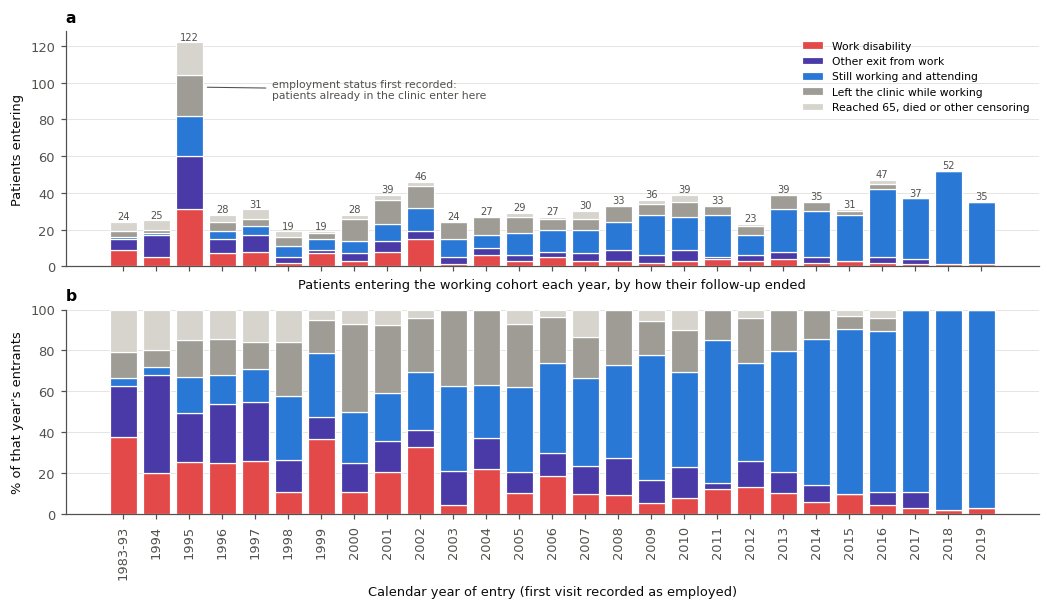

**What this means.** 958 patients entered the working cohort, 142 of whom later
left work for health reasons. The tall bar in 1995 is the year the clinic began recording employment status: everyone
already attending and working entered then. Patients who entered before 2005 had long follow-up (median
17 years), and 24 % of them had a
work-disability onset. Among those entering from 2015, only 4 % have had one so
far, partly because they have been followed for less time (median 2.1 years) and partly
because 2 % had already stopped attending while still working.
Recent entrants have had less time to show an outcome, and more of them leave without one recorded.

In [16]:
"""Cohort inception: year of entry and final state of every patient."""
STATE_COLORS = {"W": KEPT_C, "S": "#eda100", "D": LEFT_C, "O": OTHER_C, "U": "#d6d4cd"}
STATE_NAMES = {"W": "Employed", "S": "Sick leave", "D": "Disabled", "O": "Other exit", "U": "Not recorded"}
FINAL_ORDER = ["Work disability", "Other exit from work", "Still working and attending",
               "Left the clinic while working", "Reached 65, died or other censoring"]
FINAL_COLORS = dict(zip(FINAL_ORDER, [LEFT_C, OTHER_C, KEPT_C, "#9e9c95", "#d6d4cd"]))
_end_map = {"onset": "Work disability", "competing exit": "Other exit from work",
            "still attending": "Still working and attending",
            f"left clinic (> {LEFT_CLINIC_YEARS:g} y before extract end)": "Left the clinic while working"}


def cohort_states(last):
    """Entry date, final state and years of follow-up of every patient, from the landmarks in use."""
    entry = land.groupby("pid").head(1).set_index("pid")["visit_date"]
    fs = last.set_index("pid")["Ending"].map(_end_map).fillna(FINAL_ORDER[-1])
    fs[pd.Series(PID_EVENT.astype(bool), index=ALL_PIDS)] = "Work disability"
    fu = ((land.groupby("pid")["last_status_date"].max() - entry).dt.days / 365.25).reindex(ALL_PIDS)
    return entry, fs.reindex(ALL_PIDS), fu


ENTRY_DATE, FINAL_STATE, FU_YEARS = cohort_states(_last)
_last_seen = land.groupby("pid")["last_status_date"].max()

_ey = ENTRY_DATE.dt.year.reindex(ALL_PIDS)
_first_bar = 1994
_eyb = _ey.clip(lower=_first_bar - 1)
INCEPTION = pd.crosstab(_eyb, FINAL_STATE).reindex(columns=FINAL_ORDER, fill_value=0)
INCEPTION.index = [f"{int(_ey.min())}-{str(_first_bar - 1)[2:]}" if y < _first_bar else str(y) for y in INCEPTION.index]
_inc_tab = INCEPTION.copy()
_inc_tab["Patients"] = INCEPTION.sum(1)
_inc_tab["Median follow-up (years)"] = FU_YEARS.groupby(_eyb.values).median().round(1).values
display(_inc_tab.T)

fig, axes = plt.subplots(2, 1, figsize=(9.6, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.15, 1]})
x = np.arange(len(INCEPTION))
_pct = INCEPTION.div(INCEPTION.sum(1), axis=0) * 100
for ax, tab in zip(axes, [INCEPTION, _pct]):
    bottom = np.zeros(len(tab))
    for c in FINAL_ORDER:
        ax.bar(x, tab[c].values, 0.82, bottom=bottom, color=FINAL_COLORS[c], edgecolor="white", linewidth=0.8,
               label=c)
        bottom += tab[c].values
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Patients entering")
axes[0].set_title("a  Patients entering the working cohort each year, by how their follow-up ended", loc="left")
for xi, n in zip(x, INCEPTION.sum(1).values):
    axes[0].text(xi, n + 1.5, f"{n}", ha="center", fontsize=6.5, color=INK_2)
_i95 = list(INCEPTION.index).index("1995") if "1995" in INCEPTION.index else None
if _i95 is not None:
    axes[0].annotate("employment status first recorded:\npatients already in the clinic enter here",
                     xy=(_i95 + 0.45, INCEPTION.iloc[_i95].sum() * 0.8), xytext=(_i95 + 2.5, INCEPTION.iloc[_i95].sum() * 0.75),
                     fontsize=7, color=INK_2, arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.7))
axes[0].legend(loc="upper right", fontsize=7, ncol=1)
axes[1].set_ylabel("% of that year's entrants"); axes[1].set_ylim(0, 100)
axes[1].set_title("b  The same, as a share of each year's entrants", loc="left")
axes[1].set_xticks(x, INCEPTION.index, rotation=90)
axes[1].set_xlabel("Calendar year of entry (first visit recorded as employed)")
plt.tight_layout(); save_fig("explore01_cohort_inception")

_early = FINAL_STATE[_ey < 2005].value_counts(normalize=True)
_late = FINAL_STATE[_ey >= 2015].value_counts(normalize=True)
say(f"""
**What this means.** {len(ALL_PIDS):,} patients entered the working cohort, {int(PID_EVENT.sum())} of whom later
left work for health reasons. The tall bar in 1995 is the year the clinic began recording employment status: everyone
already attending and working entered then. Patients who entered before 2005 had long follow-up (median
{FU_YEARS[_ey < 2005].median():.0f} years), and {100 * _early.get("Work disability", 0):.0f} % of them had a
work-disability onset. Among those entering from 2015, only {100 * _late.get("Work disability", 0):.0f} % have had one so
far, partly because they have been followed for less time (median {FU_YEARS[_ey >= 2015].median():.1f} years) and partly
because {100 * _late.get("Left the clinic while working", 0):.0f} % had already stopped attending while still working.
Recent entrants have had less time to show an outcome, and more of them leave without one recorded.
""")

### 1.6.2 Every patient's employment record

One row per patient, ordered by date of entry. Each row runs from entry to the patient's last recorded status,
coloured by the status recorded at each visit (held until the next status). The picture shows the shape of the
data at once: the 1995 inception block, long records in early entrants, and how often a period of sick leave or
disability is followed by a return to work.

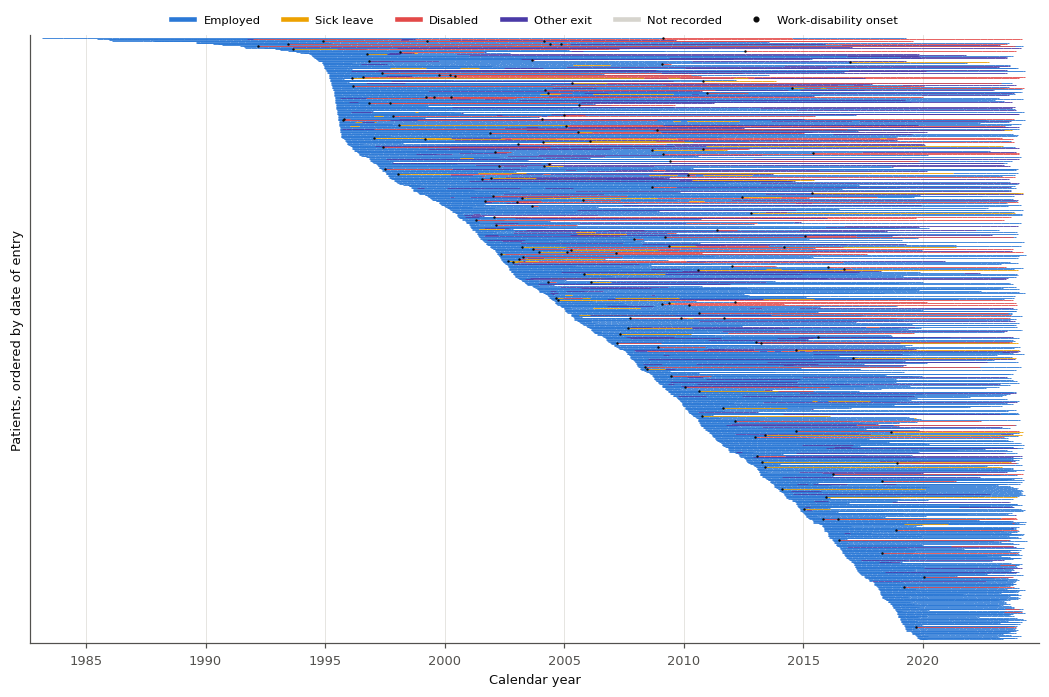

**What this means.** Most of the page is blue: working is the usual state, and work disability is a minority
outcome. 52 patients (5%) were recorded back at work after a period of sick
leave or disability, so leaving work is not always permanent. That is why the analysis lets a patient re-enter the
risk set when they return to work.

In [17]:
"""Every patient's employment record (calendar time)."""
from matplotlib.collections import LineCollection

_sv = visits.loc[visits["HAS_STATUS"] & visits["PTNO"].isin(ALL_PIDS), ["PTNO", "ASSDT", "EMP"]].copy()
_sv = _sv[_sv["ASSDT"] >= _sv["PTNO"].map(ENTRY_DATE)]
_sv["st"] = _sv["EMP"].map(_state_of)
_sv["end"] = _sv.groupby("PTNO")["ASSDT"].shift(-1)
_sv["end"] = _sv["end"].fillna(_sv["ASSDT"] + pd.Timedelta(days=30))     # last status: a short stub
_order = ENTRY_DATE.sort_values().index
_row = pd.Series(np.arange(len(_order)), index=_order)
_y = _sv["PTNO"].map(_row).values
_x0, _x1 = _sv["ASSDT"].dt.year + _sv["ASSDT"].dt.dayofyear / 365.25, _sv["end"].dt.year + _sv["end"].dt.dayofyear / 365.25
fig, ax = plt.subplots(figsize=(9.6, 6.4))
for st, col in STATE_COLORS.items():
    k = (_sv["st"] == st).values
    if k.any():
        seg = np.stack([np.column_stack([_x0.values[k], _y[k]]), np.column_stack([_x1.values[k], _y[k]])], 1)
        ax.add_collection(LineCollection(seg, colors=col, linewidths=0.55, label=STATE_NAMES[st]))
_ons = land[(C_ALL == 1)].drop_duplicates(["pid", "event_date"])
ax.scatter(_ons["event_date"].dt.year + _ons["event_date"].dt.dayofyear / 365.25, _ons["pid"].map(_row), s=2.5,
           color=INK, zorder=3, linewidths=0, label="Work-disability onset")
ax.set_xlim(_x0.min() - 0.5, _x1.max() + 0.5); ax.set_ylim(len(_order) + 5, -5)
ax.set_xlabel("Calendar year"); ax.set_ylabel("Patients, ordered by date of entry")
ax.set_yticks([]); ax.grid(axis="y", visible=False)
_h = [plt.Line2D([], [], color=STATE_COLORS[s], lw=3) for s in "WSDOU"] + \
     [plt.Line2D([], [], color=INK, marker="o", ls="", ms=3)]
ax.legend(_h, [STATE_NAMES[s] for s in "WSDOU"] + ["Work-disability onset"], ncol=6, loc="lower center",
          bbox_to_anchor=(0.5, 1.0), fontsize=7.5)
plt.tight_layout(); save_fig("explore02_every_patient")
_share_back = (_sv.assign(prev=_sv.groupby("PTNO")["st"].shift())
               .query("prev in ['S', 'D'] and st == 'W'")["PTNO"].nunique())
say(f"""
**What this means.** Most of the page is blue: working is the usual state, and work disability is a minority
outcome. {_share_back} patients ({_share_back / len(ALL_PIDS):.0%}) were recorded back at work after a period of sick
leave or disability, so leaving work is not always permanent. That is why the analysis lets a patient re-enter the
risk set when they return to work.
""")

### 1.6.3 Two patients: visits, landmarks and the clinical record

Two patients followed from entry: one who left work for health reasons and one who kept working. For each, the
top panel shows **every clinic visit** coloured by the employment status recorded there (the spacing shows how often
the patient was seen) and, underneath, the **landmarks**: the working visits at which a risk is computed. The two
lower panels show two of the model's inputs over time, disease activity (12-month adjusted mean SLEDAI-2K) and the prednisone dose. Time
is shown as years since entry, not calendar dates.

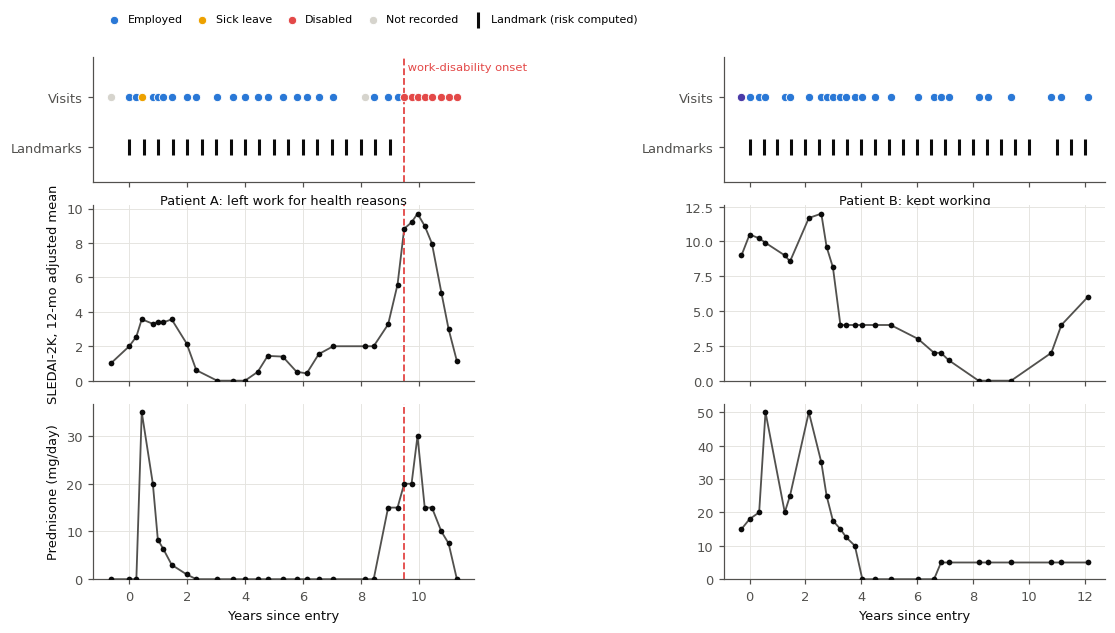

Patient A: left work for health reasons: 19 landmarks; visits every 3.9 months (median)
Patient B: kept working: 24 landmarks; visits every 4.2 months (median)


**What this means.** Patients are seen every few months, and each working visit is a fresh opportunity to compute a
risk. Disease activity and treatment vary from visit to visit in both patients. A single visit's value says little;
the model combines 20 such items at every visit.

In [18]:
"""Two example patients: visits, landmarks, disease activity and prednisone."""
def example_patients():
    """First onset dates; candidate example patients (an onset after > 4 years, and > 8 years still working)."""
    fod = land.loc[C_ALL == 1].groupby("pid")["event_date"].min()
    co = [p for p in fod.index if (fod[p] - ENTRY_DATE[p]).days > 4 * 365 and len(PT_ROWS[p]) >= 8
          and visits.loc[visits["PTNO"] == p, "STERAVER_0"].max() > 0]
    cw = [p for p in ALL_PIDS if not PID_EVENT[PID_INDEX[p]] and FINAL_STATE[p] == "Still working and attending"
          and FU_YEARS[p] >= 8 and len(PT_ROWS[p]) >= 10]
    ex = [sorted(co, key=lambda p: len(PT_ROWS[p]))[len(co) // 2], sorted(cw, key=lambda p: len(PT_ROWS[p]))[len(cw) // 2]]
    return fod, co, cw, ex


_nvis = visits.groupby("PTNO").size()
FIRST_ONSET_DATE, CAND_ONSET, CAND_WORKING, EXAMPLE_PIDS = example_patients()
EXAMPLE_TITLES = ["Patient A: left work for health reasons", "Patient B: kept working"]


def _yrs(d, pid):
    return (pd.to_datetime(np.asarray(d)) - ENTRY_DATE[pid]).days.values / 365.25 if np.ndim(d) else \
        (pd.Timestamp(d) - ENTRY_DATE[pid]).days / 365.25


fig, axes = plt.subplots(3, 2, figsize=(10.2, 5.8), sharex="col", gridspec_kw={"height_ratios": [1.0, 1.4, 1.4]})
for j, pid in enumerate(EXAMPLE_PIDS):
    pv = visits[(visits["PTNO"] == pid)]
    end = FIRST_ONSET_DATE[pid] + pd.DateOffset(years=2) if pid in FIRST_ONSET_DATE.index else _last_seen[pid]
    pv = pv[(pv["ASSDT"] >= ENTRY_DATE[pid] - pd.DateOffset(years=1)) & (pv["ASSDT"] <= end)]
    xv = _yrs(pv["ASSDT"].values, pid)
    ax = axes[0, j]
    for st, col in STATE_COLORS.items():
        k = np.array([_state_of(e) == st for e in pv["EMP"].values])
        if k.any():
            ax.scatter(xv[k], np.full(k.sum(), 1.0), s=30, color=col, edgecolor="white", linewidth=0.6, zorder=3,
                       label=STATE_NAMES[st])
    li = PT_ROWS[pid]
    li = li[land["visit_date"].values[li] <= np.datetime64(end)]
    ax.scatter(_yrs(land["visit_date"].values[li], pid), np.zeros(len(li)), marker="|", s=110, color=INK, zorder=3,
               label="Landmark (risk computed)")
    ax.set_yticks([0, 1], ["Landmarks", "Visits"]); ax.set_ylim(-0.7, 1.8); ax.grid(False)
    ax.set_title(EXAMPLE_TITLES[j], loc="left", fontsize=9, fontweight="bold")
    for col_, lab_, row in [("AMS_12M", "SLEDAI-2K, 12-mo adjusted mean", 1), ("STERAVER_0", "Prednisone (mg/day)", 2)]:
        a = axes[row, j]
        yv = pv[col_].values.astype(float)
        a.plot(xv, yv, "-", color=INK_2, lw=1.2, zorder=2)
        a.scatter(xv, yv, s=14, color=INK, zorder=3, linewidths=0)
        a.set_ylim(bottom=0)
        if j == 0:
            a.set_ylabel(lab_)
    if pid in FIRST_ONSET_DATE.index:
        xo = _yrs(FIRST_ONSET_DATE[pid], pid)
        for a in axes[:, j]:
            a.axvline(xo, color="#e34948", lw=1.2, ls="--")
        axes[0, j].text(xo, 1.6, " work-disability onset", color="#e34948", fontsize=7.5, va="center")
    axes[2, j].set_xlabel("Years since entry")
axes[0, 0].legend(ncol=6, loc="lower left", bbox_to_anchor=(0.0, 1.18), fontsize=7.2, handletextpad=0.2,
                  columnspacing=0.8)
plt.tight_layout(); save_fig("explore03_two_patients")
for j, pid in enumerate(EXAMPLE_PIDS):
    pv = visits[(visits["PTNO"] == pid) & (visits["ASSDT"] >= ENTRY_DATE[pid])]
    gap = pv["ASSDT"].diff().dt.days.dropna() / MONTH_DAYS
    print(f"{EXAMPLE_TITLES[j]}: {len(PT_ROWS[pid])} landmarks; visits every {gap.median():.1f} months (median)")
say("""
**What this means.** Patients are seen every few months, and each working visit is a fresh opportunity to compute a
risk. Disease activity and treatment vary from visit to visit in both patients. A single visit's value says little;
the model combines 20 such items at every visit.
""")

### 1.6.4 The clinical picture in the years before an onset

For the patients who left work for health reasons, each input is averaged over the working visits in 6-month
bins before their first onset. Patients who never left work are aligned at their last working visit for comparison.
A curve that **rises** towards the onset would be an early-warning signal; two curves that run **parallel** mean
the difference is a stable trait of the patient.

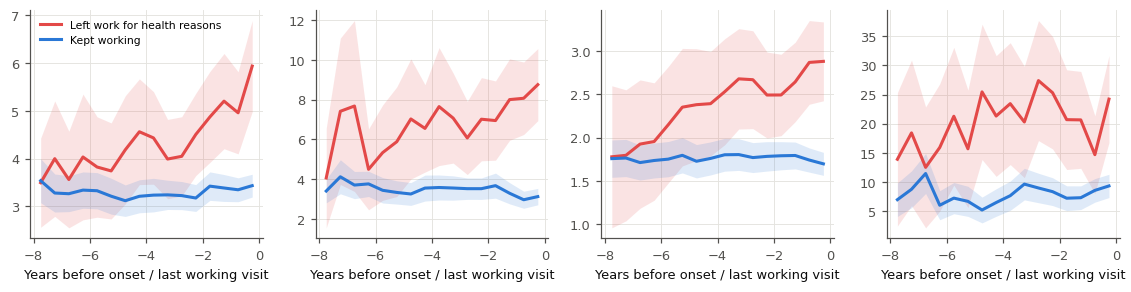

,"Onset patients, 4-6 y before","Onset patients, final year","Kept working, 4-6 y before","Kept working, final year"
SLEDAI-2K (12-mo adjusted mean),4.1,5.4,3.2,3.4
Prednisone (mg/day),6.2,8.4,3.4,3.0
SDI damage score,2.3,2.9,1.8,1.7
Fatigue reported (%),20.9,19.4,6.4,8.9


**What this means.**

* **A difference already present years earlier.** Four to six years before the onset, patients who would later
  leave work already had higher values than patients who kept working on
  4 of the 4 items (for example SLEDAI-2K 4.1 vs 3.2;
  fatigue reported at 21 % vs 6 % of visits).
* **A further rise close to the onset.** The gap widened in the final year for SLEDAI-2K (12-mo adjusted mean), Prednisone (mg/day), SDI damage score: prednisone went from 6.2 to 8.4
  mg/day in onset patients, against 3.4 and 3.0 in patients who kept working.

So the warning signs are partly a persistent trait and partly a change in the last year or two. The bands are wide
far from the onset because fewer patients were followed that long before it. Section 6.6 shows how the risk score
behaves over the same years.

In [19]:
"""Onset-aligned mean of key inputs (onset patients vs never-onset patients)."""
TRAJ_MAX_MONTHS = 96
def months_before_anchor():
    """Months from each landmark to its patient's first onset (or, without one, to the day after the last landmark)."""
    anc = {p: FIRST_ONSET_DATE[p] for p in FIRST_ONSET_DATE.index}
    anc.update({p: land["visit_date"].values[PT_ROWS[p]].max() + np.timedelta64(1, "D") for p in ALL_PIDS if p not in anc})
    a = pd.to_datetime(pd.Series(PID_ALL).map(anc)).values
    return (a - land["visit_date"].values) / np.timedelta64(1, "D") / MONTH_DAYS


MO_BEFORE = months_before_anchor()                                                   # months before anchor
_ever = PID_EVENT[ROW_PIDX].astype(bool)
_ok = (MO_BEFORE > 0) & (MO_BEFORE <= TRAJ_MAX_MONTHS)
_bins = np.arange(0, TRAJ_MAX_MONTHS + 1, 6)
_bin = np.digitize(MO_BEFORE, _bins)


def aligned_mean(v):
    """Per group and 6-month bin: mean over patients (each patient's mean within the bin), 95 % CI."""
    d = pd.DataFrame({"pid": PID_ALL, "ev": _ever, "bin": _bin, "v": v})[_ok]
    g = d.groupby(["ev", "bin", "pid"])["v"].mean().groupby(["ev", "bin"]).agg(["mean", "sem", "size"])
    return g


_TRAJ_VARS = [("AMS_12M", "SLEDAI-2K (12-mo adjusted mean)", 1), ("STERAVER_0", "Prednisone (mg/day)", 1),
              ("score_n", "SDI damage score", 1), ("FATIGUE", "Fatigue reported (%)", 100)]
fig, axes = plt.subplots(1, 4, figsize=(10.4, 2.9))
for ax, (c, lab, sc) in zip(axes, _TRAJ_VARS):
    g = aligned_mean(LAND_X[c].values.astype(float) * sc)
    for ev, col, nm in [(True, LEFT_C, "Left work for health reasons"), (False, KEPT_C, "Kept working")]:
        if ev not in g.index.get_level_values(0):
            continue
        s = g.loc[ev]
        s = s[s["size"] >= 10]
        xs = -(_bins[s.index.values - 1] + 3) / 12
        ax.fill_between(xs, s["mean"] - 1.96 * s["sem"], s["mean"] + 1.96 * s["sem"], color=col, alpha=0.15, lw=0)
        ax.plot(xs, s["mean"], "-", color=col, lw=2, label=nm)
    ax.set_title(lab, loc="left", fontsize=9)
    ax.set_xlabel("Years before onset / last working visit")
axes[0].legend(fontsize=7, loc="upper left")
plt.tight_layout(); save_fig("explore04_before_onset")
_g = {c: aligned_mean(LAND_X[c].values.astype(float) * sc) for c, _, sc in _TRAJ_VARS}


def _near_far(c, ev):
    """Mean of the patient means 0-12 months and 48-72 months before the anchor."""
    s = _g[c].loc[ev]
    return s.loc[s.index <= 2, "mean"].mean(), s.loc[(s.index >= 9) & (s.index <= 12), "mean"].mean()


BEFORE_ONSET = pd.DataFrame({lab: {"Onset patients, 4-6 y before": _near_far(c, True)[1],
                                   "Onset patients, final year": _near_far(c, True)[0],
                                   "Kept working, 4-6 y before": _near_far(c, False)[1],
                                   "Kept working, final year": _near_far(c, False)[0]}
                             for c, lab, _ in _TRAJ_VARS}).T.round(1)
display(BEFORE_ONSET)
_gap_far = (BEFORE_ONSET.iloc[:, 0] - BEFORE_ONSET.iloc[:, 2])
_gap_near = (BEFORE_ONSET.iloc[:, 1] - BEFORE_ONSET.iloc[:, 3])
_widen = [i for i in BEFORE_ONSET.index if _gap_near[i] > 1.3 * _gap_far[i] and _gap_far[i] > 0]
_b = BEFORE_ONSET
say(f"""
**What this means.**

* **A difference already present years earlier.** Four to six years before the onset, patients who would later
  leave work already had higher values than patients who kept working on
  {sum(_gap_far > 0)} of the {len(_gap_far)} items (for example SLEDAI-2K {_b.iloc[0, 0]:.1f} vs {_b.iloc[0, 2]:.1f};
  fatigue reported at {_b.iloc[3, 0]:.0f} % vs {_b.iloc[3, 2]:.0f} % of visits).
* **A further rise close to the onset.** {"The gap widened in the final year for " + ", ".join(_widen) + "" if _widen
  else "The gap did not widen much in the final year"}: prednisone went from {_b.iloc[1, 0]:.1f} to {_b.iloc[1, 1]:.1f}
  mg/day in onset patients, against {_b.iloc[1, 2]:.1f} and {_b.iloc[1, 3]:.1f} in patients who kept working.

{"So the warning signs are partly a persistent trait and partly a change in the last year or two." if _widen else
"So the warning signs are mostly a persistent trait, not a change that announces the onset."} The bands are wide
far from the onset because fewer patients were followed that long before it. Section 6.6 shows how the risk score
behaves over the same years.
""")

### 1.6.5 The outcome record year by year (the whole extract)

> **The question.** How did the clinic see patients and record their employment status in each calendar year,
> including the COVID-19 years that the calendar-time analyses of Part IV leave out?

Four views of the same record, over every visit to the end of the extract: how often working-age patients were
seen; at how many visits the employment status was recorded; which statuses were recorded; and how many work-disability
onsets and other exits were recorded per 100 person-years at risk. The grey band is the COVID-19 period (March
2020 - December 2021); the dashed line marks the end of the calendar-time analyses of Part IV (March 2020).

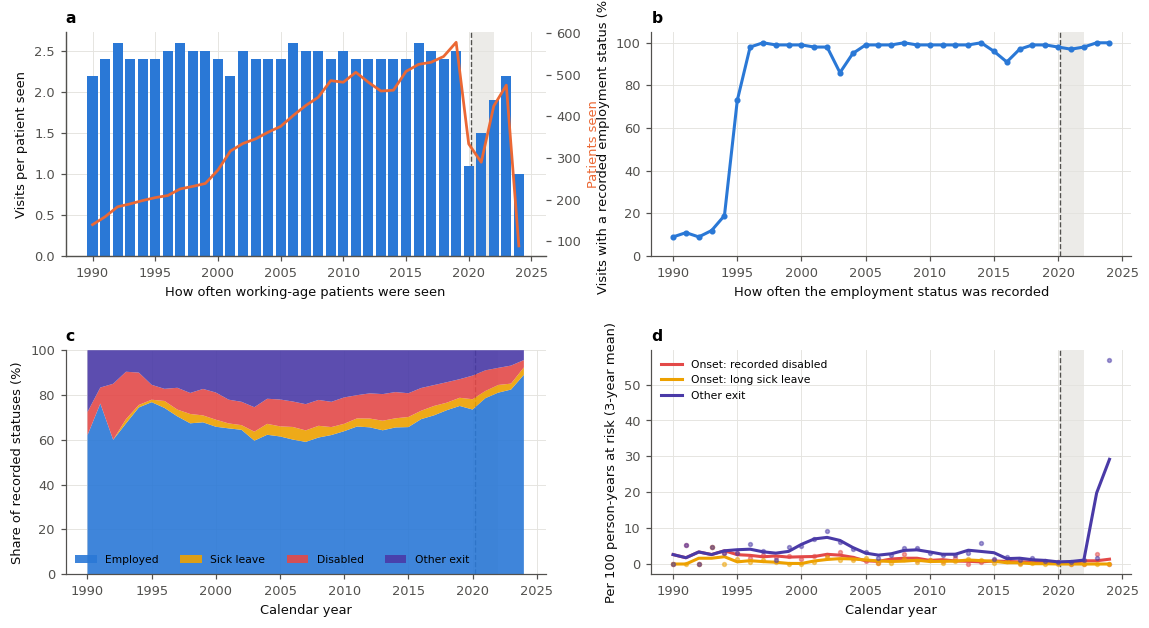

**What this means.** In 2015-19 the clinic saw about 537 working-age patients a year,
2.5 visits each, with the employment status recorded at
96 % of visits. In 2020-21 visits per patient fell to
1.3 and the status was recorded at 98 %
of visits; from 2022, 1.7 visits per patient and 99 %.
Recorded onsets fell from 2.67
per 100 person-years in 2000-09 to 1.00
in 2015-19, and other exits fell with them (panel d): the fall is in every kind of status change, as Section 1.5.6
shows in detail. Fewer visits during COVID-19 mean fewer chances to record a change of status, and a change that
happened in 2020-21 can only be seen at the next visit, often much later; this is why the calendar-time analyses of
Part IV (era effects and temporal validation) end in March 2020. The main analysis uses every year: its pooled results
include the years after, and its era comparisons leave them out.

In [20]:
"""Visits, status recording, status mix and recorded exits by calendar year (whole extract)."""
_F = DATA["full"]
_vy = visits[visits["PTNO"].isin(_emp_pts) & (visits["age_at_record"] < AGE_CAP_YEARS)].copy()
_vy["Year"] = _vy["ASSDT"].dt.year
_years = np.arange(max(1990, int(_vy["Year"].min())), int(_vy["Year"].max()) + 1)
_vy = _vy[_vy["Year"].isin(_years)]
_pt_seen = _vy.groupby("Year")["PTNO"].nunique().reindex(_years)
_vis_n = _vy.groupby("Year").size().reindex(_years)
_stat = _vy[_vy["HAS_STATUS"]].assign(S=lambda d: d["EMP"].map(_state_of))
_mix = (_stat.groupby(["Year", "S"]).size().unstack(fill_value=0).reindex(_years).fillna(0))
_mix = _mix.div(_mix.sum(1).replace(0, np.nan), axis=0) * 100
# recorded exits per 100 person-years at risk, by the calendar year of the at-risk interval's start
_ly = np.floor(_F["LAND_YEAR"]).astype(int)
_route = _F["land"]["route"].astype(object).fillna("").values
_byy = pd.DataFrame({"Year": _ly, "py": _F["INT_YRS_ALL"], "dis": _F["D1_ALL"] * (_route == "direct"),
                     "sick": _F["D1_ALL"] * (_route != "direct"), "oth": _F["D2_ALL"]}).groupby("Year").sum().reindex(_years)
OUTCOME_BY_YEAR = pd.DataFrame({"Patients seen": _pt_seen, "Visits per patient": (_vis_n / _pt_seen).round(1),
                                "Visits with a recorded status (%)": (100 * _vy.groupby("Year")["HAS_STATUS"].mean()).reindex(_years).round(0),
                                "Onsets /100 py: recorded disabled": (100 * _byy["dis"] / _byy["py"]).round(2),
                                "Onsets /100 py: long sick leave": (100 * _byy["sick"] / _byy["py"]).round(2),
                                "Other exits /100 py": (100 * _byy["oth"] / _byy["py"]).round(2),
                                "Person-years at risk": _byy["py"].round(0)})
save_table(OUTCOME_BY_YEAR, "outcome_record_by_year")
_cov = (pd.Timestamp(COVID_WINDOW[0]).year + 2 / 12, pd.Timestamp(COVID_WINDOW[1]).year + 1)
_me = MAIN_END.year + (MAIN_END.dayofyear - 1) / 365.25
fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.4), gridspec_kw={"hspace": 0.42, "wspace": 0.22})
for ax in axes.ravel():
    ax.axvspan(*_cov, color=GRID_C, alpha=0.7, lw=0, zorder=0)
    ax.axvline(_me, color=INK_2, lw=0.9, ls="--", zorder=1)
ax = axes[0, 0]
ax.bar(_years, OUTCOME_BY_YEAR["Visits per patient"], color=C1, width=0.8)
ax2 = ax.twinx()
ax2.plot(_years, _pt_seen, color=C2, lw=1.8)
ax.set_ylabel("Visits per patient seen"); ax2.set_ylabel("Patients seen", color=C2); ax2.grid(False)
ax.set_title("a  How often working-age patients were seen", loc="left", fontsize=9)
ax = axes[0, 1]
ax.plot(_years, OUTCOME_BY_YEAR["Visits with a recorded status (%)"], color=C1, lw=2, marker="o", ms=3)
ax.set_ylim(0, 105); ax.set_ylabel("Visits with a recorded employment status (%)")
ax.set_title("b  How often the employment status was recorded", loc="left", fontsize=9)
ax = axes[1, 0]
_order = [k for k in ["W", "S", "D", "O"] if k in _mix.columns]
ax.stackplot(_years, *[_mix[k].fillna(0).values for k in _order], colors=[STATE_COLORS[k] for k in _order],
             labels=[{"W": "Employed", "S": "Sick leave", "D": "Disabled", "O": "Other exit"}[k] for k in _order], alpha=0.9)
ax.set_ylim(0, 100); ax.set_ylabel("Share of recorded statuses (%)"); ax.legend(fontsize=7, loc="lower left", ncol=4)
ax.set_title("c  Which statuses were recorded", loc="left", fontsize=9)
ax = axes[1, 1]
for col, c_, lab in [("Onsets /100 py: recorded disabled", STATE_COLORS["D"], "Onset: recorded disabled"),
                     ("Onsets /100 py: long sick leave", STATE_COLORS["S"], "Onset: long sick leave"),
                     ("Other exits /100 py", C4, "Other exit")]:
    ax.plot(_years, OUTCOME_BY_YEAR[col].rolling(3, center=True, min_periods=2).mean(), color=c_, lw=2, label=lab)
    ax.plot(_years, OUTCOME_BY_YEAR[col], "o", color=c_, ms=2.5, alpha=0.5)
ax.set_ylabel("Per 100 person-years at risk (3-year mean)"); ax.legend(fontsize=7)
ax.set_title("d  Recorded exits from work", loc="left", fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("Calendar year")
save_fig("explore05_outcome_record_by_year")
_pre = OUTCOME_BY_YEAR.loc[2015:2019]
_cv_ = OUTCOME_BY_YEAR.loc[2020:2021]
_post = OUTCOME_BY_YEAR.loc[2022:]
say(f"""
**What this means.** In 2015-19 the clinic saw about {_pre['Patients seen'].mean():.0f} working-age patients a year,
{_pre['Visits per patient'].mean():.1f} visits each, with the employment status recorded at
{_pre['Visits with a recorded status (%)'].mean():.0f} % of visits. In 2020-21 visits per patient fell to
{_cv_['Visits per patient'].mean():.1f} and the status was recorded at {_cv_['Visits with a recorded status (%)'].mean():.0f} %
of visits{f"; from 2022, {_post['Visits per patient'].mean():.1f} visits per patient and {_post['Visits with a recorded status (%)'].mean():.0f} %" if len(_post) else ""}.
Recorded onsets fell from {OUTCOME_BY_YEAR.loc[2000:2009, ['Onsets /100 py: recorded disabled', 'Onsets /100 py: long sick leave']].sum(1).mean():.2f}
per 100 person-years in 2000-09 to {_pre[['Onsets /100 py: recorded disabled', 'Onsets /100 py: long sick leave']].sum(1).mean():.2f}
in 2015-19, and other exits fell with them (panel d): the fall is in every kind of status change, as Section 1.5.6
shows in detail. Fewer visits during COVID-19 mean fewer chances to record a change of status, and a change that
happened in 2020-21 can only be seen at the next visit, often much later; this is why the calendar-time analyses of
Part IV (era effects and temporal validation) end in March 2020. The main analysis uses every year: its pooled results
include the years after, and its era comparisons leave them out.
""")

### 1.6.6 The SF-36 and the fatigue scale

> **The question.** How often were the SF-36 and the fatigue severity scale (FSS; 9 items, 0-10) completed, by whom and when; how do
> their scores vary over calendar time and between patients; and how do they behave in the years before an onset?

A form counts at a visit for the 12 months after it was completed. Scores: SF-36 physical and mental component
summaries (PCS, MCS; mean 50, SD 10 in the 1990 US population; higher = better health) and the fatigue scale
(mean of nine items scored 0-10; higher = more fatigue). Every form of every patient with a working visit is used,
to the end of the extract.

,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Working visits,2.0,2.0,6.0,10.0,9.0,9.0,11.0,18.0,25.0,25.0,30.0,60.0,262.0,316.0,325.0,314.0,330.0,355.0,405.0,435.0,...,458.0,476.0,506.0,548.0,582.0,636.0,653.0,634.0,622.0,589.0,639.0,682.0,716.0,754.0,767.0,674.0,292.0,543.0,520.0,24.0
With an SF-36 (%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,49.0,60.0,64.0,70.0,64.0,60.0,61.0,63.0,...,64.0,71.0,71.0,69.0,61.0,59.0,47.0,24.0,24.0,38.0,42.0,42.0,35.0,31.0,20.0,24.0,24.0,11.0,11.0,29.0
With a fatigue scale (%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,26.0,34.0,56.0,61.0,61.0,59.0,...,65.0,70.0,64.0,65.0,54.0,43.0,30.0,18.0,24.0,39.0,42.0,43.0,35.0,31.0,20.0,24.0,24.0,11.0,0.0,0.0


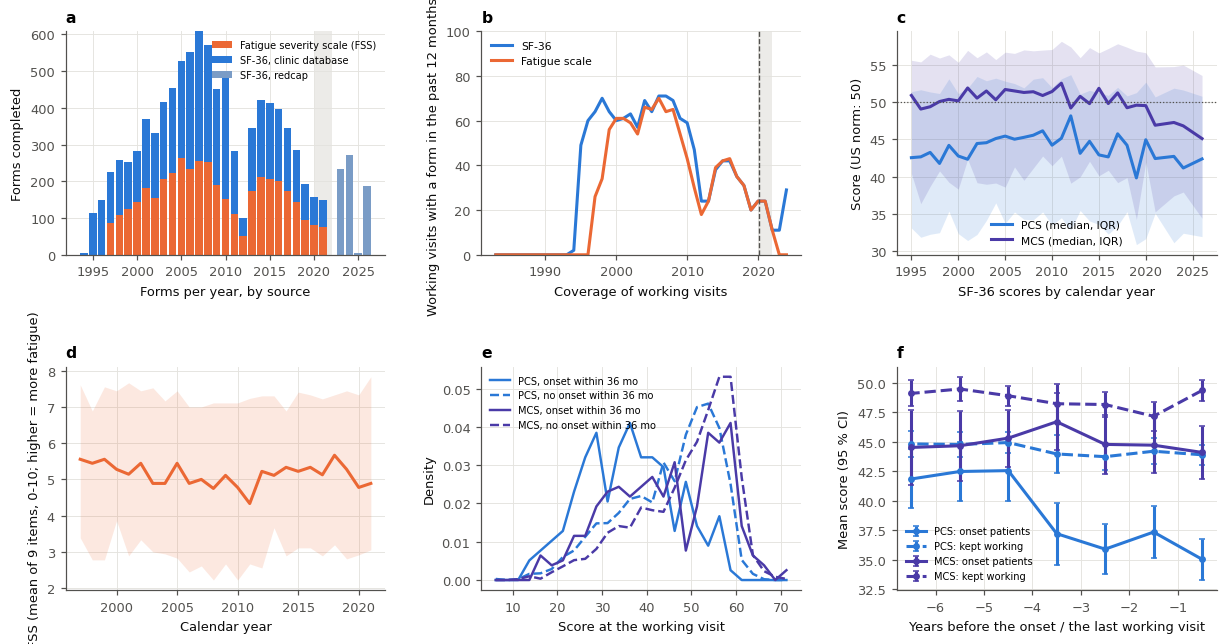

**What this means.**

* **When the forms were collected.** 5,748 SF-36 forms and 4,099 fatigue scales from patients of the
  cohort. The SF-36 covered 65 % of working visits in 2000-09 and 34 % in 2015-19; REDCap collection resumes
  from 2023 (panel a), after the end of the outcome follow-up, so those forms can describe patients but not yet predict.
* **The scores over calendar time** (panels c-d): the median PCS sits around 44 and the
  median MCS around 50 (US norm: 50). Physical health is the domain most affected
  in this cohort; the year-by-year medians move within a few points, far less than the recorded outcome moved.
* **Between patients** (panel e): visits followed by an onset within 36 months have lower PCS and MCS.
* **Before an onset** (panel f): in the final year before an onset the mean PCS is 35.0, against
  43.9 in the year before the last working visit of patients who kept working; four to six years
  earlier the means are 42.3 and 44.8. The
  difference is partly long-standing and partly a decline as the onset approaches.

In [21]:
"""Forms per year by source; coverage of working visits; scores by calendar year; distributions; before an onset."""
_sf_all = read_sf36()
_fs_all = read_fss()
_cohort = set(_F["land"]["pid"])
_sf_all = _sf_all[_sf_all["PTNO"].isin(_cohort)]
_fs_all = _fs_all[_fs_all["PTNO"].isin(_cohort)]
_fy = pd.concat([_sf_all.assign(Form="SF-36, " + _sf_all["source"].str.lower()), _fs_all.assign(Form="Fatigue severity scale (FSS)")])
_fy["Year"] = _fy["date"].dt.year
FORMS_BY_YEAR = _fy.groupby(["Year", "Form"]).size().unstack(fill_value=0)
_LX = _F["LAND_X"]
_lyr = np.floor(_F["LAND_YEAR"]).astype(int)
COVER_BY_YEAR = pd.DataFrame({"Working visits": pd.Series(_lyr).value_counts().sort_index(),
                              "With an SF-36 (%)": 100 * pd.Series(_LX["PCS"].notna().values).groupby(_lyr).mean(),
                              "With a fatigue scale (%)": 100 * pd.Series(_LX["FSS10"].notna().values).groupby(_lyr).mean()}).round(0)
SCORES_BY_YEAR = pd.concat({k: d.groupby(d["date"].dt.year)[k].describe()[["count", "25%", "50%", "75%"]]
                            for k, d in [("PCS", _sf_all), ("MCS", _sf_all), ("FSS10", _fs_all)]}, axis=1)
save_table(FORMS_BY_YEAR, "pro_forms_by_year")
save_table(COVER_BY_YEAR, "pro_coverage_by_year")
save_table(SCORES_BY_YEAR.round(1), "pro_scores_by_year")
display(COVER_BY_YEAR.T)

fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.6), gridspec_kw={"hspace": 0.5, "wspace": 0.3})
ax = axes[0, 0]
_bot = np.zeros(len(FORMS_BY_YEAR))
for k, col in zip(FORMS_BY_YEAR.columns, [C2, C1, "#7a9cc6", C3]):
    ax.bar(FORMS_BY_YEAR.index, FORMS_BY_YEAR[k], bottom=_bot, color=col, width=0.85, label=k)
    _bot += FORMS_BY_YEAR[k].values
ax.axvspan(*_cov, color=GRID_C, alpha=0.7, lw=0, zorder=0)
ax.set_ylabel("Forms completed"); ax.legend(fontsize=6.5); ax.set_title("a  Forms per year, by source", loc="left", fontsize=9)
ax = axes[0, 1]
ax.plot(COVER_BY_YEAR.index, COVER_BY_YEAR["With an SF-36 (%)"], color=C1, lw=2, label="SF-36")
ax.plot(COVER_BY_YEAR.index, COVER_BY_YEAR["With a fatigue scale (%)"], color=C2, lw=2, label="Fatigue scale")
ax.axvspan(*_cov, color=GRID_C, alpha=0.7, lw=0, zorder=0); ax.axvline(_me, color=INK_2, lw=0.9, ls="--")
ax.set_ylim(0, 100); ax.set_ylabel("Working visits with a form in the past 12 months (%)"); ax.legend(fontsize=7)
ax.set_title("b  Coverage of working visits", loc="left", fontsize=9)
ax = axes[0, 2]
for k, col, lab in [("PCS", C1, "PCS"), ("MCS", C4, "MCS")]:
    t_ = SCORES_BY_YEAR[k][SCORES_BY_YEAR[k]["count"] >= 10]
    ax.fill_between(t_.index, t_["25%"], t_["75%"], color=col, alpha=0.15, lw=0)
    ax.plot(t_.index, t_["50%"], color=col, lw=2, label=f"{lab} (median, IQR)")
ax.axhline(50, color=INK_2, lw=0.8, ls=":"); ax.set_ylabel("Score (US norm: 50)"); ax.legend(fontsize=7)
ax.set_title("c  SF-36 scores by calendar year", loc="left", fontsize=9)
ax = axes[1, 0]
t_ = SCORES_BY_YEAR["FSS10"][SCORES_BY_YEAR["FSS10"]["count"] >= 10]
ax.fill_between(t_.index, t_["25%"], t_["75%"], color=C2, alpha=0.15, lw=0)
ax.plot(t_.index, t_["50%"], color=C2, lw=2)
ax.set_ylabel("FSS (mean of 9 items, 0-10; higher = more fatigue)"); ax.set_xlabel("Calendar year")
ax.set_title("d  Fatigue scale by calendar year", loc="left", fontsize=9)
# distributions at working visits, by whether an onset followed within 36 months
ax = axes[1, 1]
_yk = (_F["W_IP"] > 0)
for k, col in [("PCS", C1), ("MCS", C4)]:
    for yv, ls in [(1, "-"), (0, "--")]:
        v_ = _LX[k].values[_yk & (_F["Y_IP"] == yv)]
        v_ = v_[~np.isnan(v_)]
        if len(v_) > 20:
            h_, e_ = np.histogram(v_, bins=np.arange(5, 75, 2.5), density=True)
            ax.plot((e_[1:] + e_[:-1]) / 2, h_, color=col, ls=ls, lw=1.6,
                    label=f"{k}, {'onset' if yv else 'no onset'} within 36 mo")
ax.set_xlabel("Score at the working visit"); ax.set_ylabel("Density"); ax.legend(fontsize=6.5)
ax.set_title("e  Scores by what followed", loc="left", fontsize=9)
# before an onset: years to onset (onset patients) against years to the last working visit (patients who kept working)
ax = axes[1, 2]
_land_f = _F["land"]
_end_row = _land_f["visit_date"] + pd.to_timedelta(_F["T_ALL"], unit="D")
_yrs_to = (_end_row - _land_f["visit_date"]).dt.days.values / 365.25
_on = _F["C_ALL"] == 1
_kept = ~np.isin(_F["PID_ALL"], _F["ALL_PIDS"][_F["PID_EVENT"] == 1])
_lastv = _land_f.groupby("pid")["visit_date"].transform("max")
_yrs_last = (_lastv - _land_f["visit_date"]).dt.days.values / 365.25
_rows_tr = []
for k, col in [("PCS", C1), ("MCS", C4)]:
    for grp, m_, yy, ls in [("Onset patients (years to onset)", _on, _yrs_to, "-"),
                            ("Kept working (years to last working visit)", _kept, _yrs_last, "--")]:
        b_ = np.floor(yy[m_]).astype(int)
        v_ = _LX[k].values[m_]
        d_ = pd.DataFrame({"b": b_, "v": v_}).dropna()
        d_ = d_[d_["b"] <= 6].groupby("b")["v"].agg(["mean", "sem", "count"])
        d_ = d_[d_["count"] >= 15]
        ax.errorbar(-d_.index - 0.5, d_["mean"], yerr=1.96 * d_["sem"], color=col, ls=ls, marker="o", ms=3.5, capsize=2,
                    label=f"{k}: {grp.split(' (')[0].lower()}")
        _rows_tr += [{"Score": k, "Group": grp, "Years before": int(i), "Mean": r["mean"], "n": int(r["count"])}
                     for i, r in d_.iterrows()]
ax.set_xlabel("Years before the onset / the last working visit"); ax.set_ylabel("Mean score (95 % CI)")
ax.legend(fontsize=6.5); ax.set_title("f  SF-36 in the years before an onset", loc="left", fontsize=9)
save_fig("explore06_sf36_fatigue")
PRO_BEFORE = pd.DataFrame(_rows_tr)
save_table(PRO_BEFORE.round(2), "pro_before_onset")
_c0 = COVER_BY_YEAR.loc[2000:2009, "With an SF-36 (%)"].mean()
_c1 = COVER_BY_YEAR.loc[2015:2019, "With an SF-36 (%)"].mean()
_pb = PRO_BEFORE[(PRO_BEFORE["Score"] == "PCS")]
_pcs_on = _pb[_pb["Group"].str.startswith("Onset")].set_index("Years before")["Mean"]
_pcs_k = _pb[_pb["Group"].str.startswith("Kept")].set_index("Years before")["Mean"]
say(f"""
**What this means.**

* **When the forms were collected.** {len(_sf_all):,} SF-36 forms and {len(_fs_all):,} fatigue scales from patients of the
  cohort. The SF-36 covered {_c0:.0f} % of working visits in 2000-09 and {_c1:.0f} % in 2015-19; REDCap collection resumes
  from 2023 (panel a), after the end of the outcome follow-up, so those forms can describe patients but not yet predict.
* **The scores over calendar time** (panels c-d): the median PCS sits around {SCORES_BY_YEAR['PCS']['50%'].median():.0f} and the
  median MCS around {SCORES_BY_YEAR['MCS']['50%'].median():.0f} (US norm: 50). Physical health is the domain most affected
  in this cohort; the year-by-year medians move within a few points, far less than the recorded outcome moved.
* **Between patients** (panel e): visits followed by an onset within 36 months have lower PCS and MCS.
* **Before an onset** (panel f): in the final year before an onset the mean PCS is {_pcs_on.get(0, np.nan):.1f}, against
  {_pcs_k.get(0, np.nan):.1f} in the year before the last working visit of patients who kept working; four to six years
  earlier the means are {_pcs_on.loc[_pcs_on.index >= 4].mean():.1f} and {_pcs_k.loc[_pcs_k.index >= 4].mean():.1f}. The
  difference is partly long-standing and partly a decline as the onset approaches.
""")

### 1.6.7 Follow-up after March 2020 (the whole extract)

> **The question.** What did clinic follow-up and the employment record look like from March 2020, the period the
> calendar-time analyses of Part IV leave out, for patients already attending and for patients whose follow-up began then?

Patients under 65 seen from 1 March 2020 to the end of the extract are split by when their clinic follow-up began:
**returning** (first clinic visit before March 2020) and **new** (first clinic visit from March 2020). The same split
is made in a window of the same length ending in February 2020, where *new* means a first clinic visit inside that
window. Only visits inside each window are counted.

* **a** Visits and follow-up in each window (table and figure).
* **b** Every record from 2018 of the patients seen after March 2020: returning patients whose last status before
  March 2020 was *employed*, and every new patient.
* **c** Changes of employment status recorded in each window.
* **d** Exits from work in the working cohort: onsets by how they were recorded, other exits and person-years at
  risk, by window and by calendar year.
* **e** Every work-disability onset from March 2020.

Before (Jan 2016 - Feb 2020)                                    After (Mar 2020 - Apr 2024)                                    
                                                                      Returning              New               All                   Returning               New               All
Patients seen                                                               794              238              1032                         647               145               792
Recorded as employed at a visit in the window                               424              143               567                         381                71               452
With a landmark in the window (working cohort)                              405              142               547                         372                69               441
Visits                                                                     6574             1340              7914                        2944               734              3678
Visits per patient, median (IQR)                                 9.0 (4.0-13.0)    5.0 (3.0-8.0)    8.0 (3.0-12.0)               4.0 (2.0-6.0)     5.0 (3.0-6.0)     4.0 (3.0-6.0)
Seen once only (%)                                                            8                9                 8                          12                 0                 9
Months from first to last visit, median (IQR)                  41.9 (27.0-45.3)  16.3 (7.1-30.2)  37.0 (16.5-44.6)            22.3 (11.1-32.0)  20.3 (12.8-28.3)  22.1 (11.7-31.4)
Months between visits, median (IQR)                               3.7 (3.0-5.1)    3.4 (3.0-4.4)     3.6 (3.0-5.1)               4.4 (3.4-6.5)     3.9 (3.2-5.7)     4.1 (3.3-6.4)
Visits per person-year                                                     2.25              2.9              2.34                        1.76              2.22              1.83
Visits with a recorded employment status (%)                                 97               95                97                          99                87                97
Patients with more than one status recorded (%)                               9                6                 8                           3                 7                 4
Months from last visit to the end of the window...               3.8 (1.7-12.1)    2.7 (1.3-4.3)     3.3 (1.5-9.6)              6.7 (4.5-10.3)     5.8 (3.0-8.0)     6.5 (4.4-9.9)
Not seen in the last 12 months of the window (%)                             25                7                21                          20                12                18

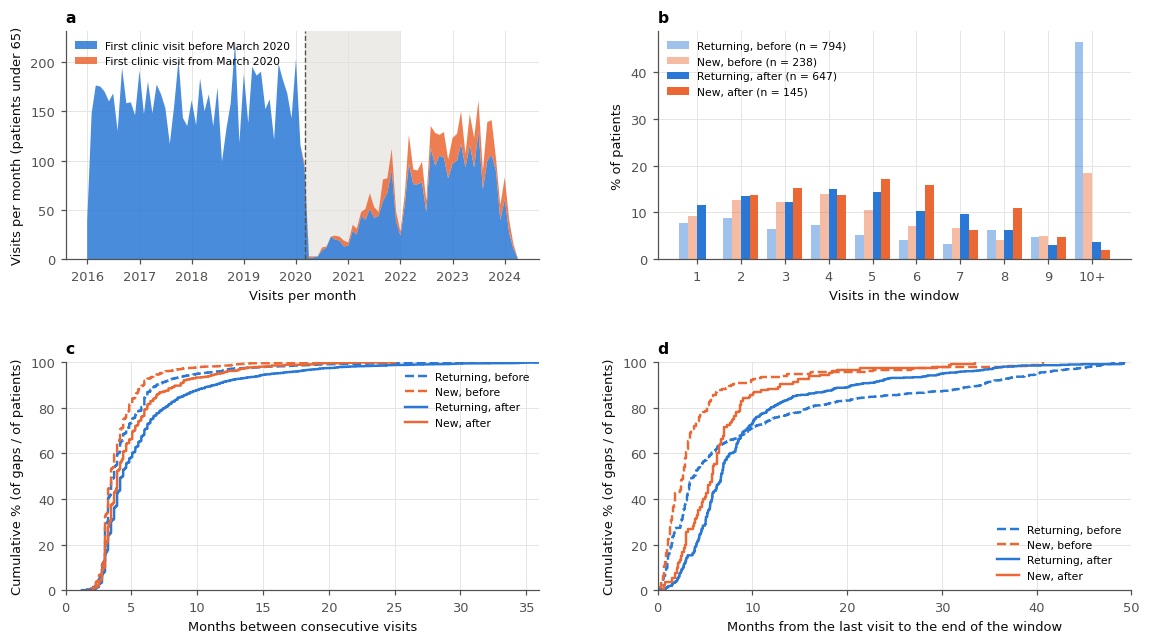

In [22]:
"""a  Visits and follow-up from March 2020 against a window of the same length before it: returning and new patients."""
_F = DATA["full"]
_XEND = pd.Timestamp(_F["DATA_END_DATE"]) + pd.Timedelta(days=1)          # the day after the last visit of the extract
_WIN = {"Before": (MAIN_END - (_XEND - MAIN_END), MAIN_END), "After": (MAIN_END, _XEND)}
_WIN_LAB = {k: f"{k} ({a:%b %Y} - {b - pd.Timedelta(days=1):%b %Y})" for k, (a, b) in _WIN.items()}
_GROUPS = ["Returning", "New"]
_first_clinic = visits.groupby("PTNO")["ASSDT"].min()
_wa = visits[visits["age_at_record"] < AGE_CAP_YEARS]
_lm_dates = _F["land"][["pid", "visit_date"]]


def _window_visits(w):
    """Visits of patients under 65 inside window w, with the patient's group in that window."""
    a, b = _WIN[w]
    v_ = _wa[(_wa["ASSDT"] >= a) & (_wa["ASSDT"] < b)].copy()
    v_["Group"] = np.where(v_["PTNO"].map(_first_clinic) >= a, "New", "Returning")
    return v_


def _q(s):
    s = pd.Series(s, dtype=float).dropna()
    return f"{s.median():.1f} ({s.quantile(0.25):.1f}-{s.quantile(0.75):.1f})" if len(s) else "-"


def _follow_stats(v_, a, b):
    """Follow-up of the patients seen in [a, b), from their visits inside the window."""
    v_ = v_.sort_values(["PTNO", "ASSDT"])
    g = v_.groupby("PTNO")["ASSDT"]
    n = g.size()
    if not len(n):
        return {}
    gaps = g.diff().dt.days.dropna() / MONTH_DAYS
    since_last = (b - g.max()).dt.days / MONTH_DAYS
    py = ((b - g.min()).dt.days / 365.25).sum()                            # from the first visit in the window to its end
    st = v_[v_["HAS_STATUS"]]
    lm = _lm_dates[(_lm_dates["visit_date"] >= a) & (_lm_dates["visit_date"] < b) & _lm_dates["pid"].isin(n.index)]
    return {"Patients seen": len(n),
            "Recorded as employed at a visit in the window": v_.loc[v_["EMP"] == "employed", "PTNO"].nunique(),
            "With a landmark in the window (working cohort)": lm["pid"].nunique(),
            "Visits": len(v_),
            "Visits per patient, median (IQR)": _q(n),
            "Seen once only (%)": round(100 * (n == 1).mean()),
            "Months from first to last visit, median (IQR)": _q((g.max() - g.min()).dt.days / MONTH_DAYS),
            "Months between visits, median (IQR)": _q(gaps),
            "Visits per person-year": round(len(v_) / py, 2),
            "Visits with a recorded employment status (%)": round(100 * v_["HAS_STATUS"].mean()),
            "Patients with more than one status recorded (%)": round(100 * (st.groupby("PTNO")["EMP"].nunique() > 1)
                                                                     .reindex(n.index, fill_value=False).mean()),
            "Months from last visit to the end of the window, median (IQR)": _q(since_last),
            "Not seen in the last 12 months of the window (%)": round(100 * (since_last > 12).mean())}


def _as_counts(df):
    """Show count rows as integers (rates, person-years and years keep their decimals)."""
    df = df.astype(object)
    for r in df.index:
        if not any(k in r for k in ("per ", "Person-years", "Years between")):
            df.loc[r] = [int(x) if isinstance(x, (int, float, np.integer, np.floating)) and not pd.isna(x) else x
                         for x in df.loc[r]]
    return df


_PCV = {w: _window_visits(w) for w in _WIN}
FOLLOW_UP_COVID = pd.DataFrame({(_WIN_LAB[w], grp): _follow_stats(_PCV[w] if grp == "All" else
                                                                  _PCV[w][_PCV[w]["Group"] == grp], *_WIN[w])
                                for w in _WIN for grp in _GROUPS + ["All"]})
save_table(FOLLOW_UP_COVID, "postcovid_follow_up")
display(FOLLOW_UP_COVID)

_GCOL = {"Returning": C1, "New": C2}
_WLS = {"Before": "--", "After": "-"}
_cov = (pd.Timestamp(COVID_WINDOW[0]), pd.Timestamp(COVID_WINDOW[1]))
fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.6), gridspec_kw={"hspace": 0.45, "wspace": 0.25})
ax = axes[0, 0]
_mv = _wa[_wa["ASSDT"] >= _WIN["Before"][0]].copy()
_mv["Group"] = np.where(_mv["PTNO"].map(_first_clinic) >= MAIN_END, "New", "Returning")
_mv["Month"] = _mv["ASSDT"].dt.to_period("M").dt.to_timestamp()
_mtab = _mv.groupby(["Month", "Group"]).size().unstack(fill_value=0).reindex(columns=_GROUPS, fill_value=0)
ax.stackplot(_mtab.index, *[_mtab[k].values for k in _GROUPS], colors=[_GCOL[k] for k in _GROUPS],
             labels=["First clinic visit before March 2020", "First clinic visit from March 2020"], alpha=0.85)
ax.axvspan(*_cov, color=GRID_C, alpha=0.7, lw=0, zorder=0); ax.axvline(MAIN_END, color=INK_2, lw=0.9, ls="--")
ax.set_ylabel("Visits per month (patients under 65)"); ax.legend(fontsize=7, loc="upper left")
ax.set_title("a  Visits per month", loc="left", fontsize=9)
ax = axes[0, 1]
_cats = list(range(1, 10)) + ["10+"]
_bw = 0.2
for i, (w, grp) in enumerate([(w, g) for w in _WIN for g in _GROUPS]):
    n_ = _PCV[w][_PCV[w]["Group"] == grp].groupby("PTNO").size()
    if not len(n_):
        continue
    sh = n_.clip(upper=10).value_counts(normalize=True).reindex(range(1, 11), fill_value=0) * 100
    ax.bar(np.arange(10) + (i - 1.5) * _bw, sh.values, _bw, color=_GCOL[grp], alpha=1.0 if w == "After" else 0.45,
           label=f"{grp}, {w.lower()} (n = {len(n_)})")
ax.set_xticks(np.arange(10), [str(c) for c in _cats]); ax.set_xlabel("Visits in the window")
ax.set_ylabel("% of patients"); ax.legend(fontsize=7); ax.set_title("b  Visits per patient in each window", loc="left", fontsize=9)
for ax, what, xl, ttl in [(axes[1, 0], "gap", "Months between consecutive visits", "c  Time between visits"),
                          (axes[1, 1], "since", "Months from the last visit to the end of the window",
                           "d  Time since the last visit at the end of the window")]:
    for w in _WIN:
        for grp in _GROUPS:
            v_ = _PCV[w][_PCV[w]["Group"] == grp].sort_values(["PTNO", "ASSDT"])
            if not len(v_):
                continue
            x_ = (v_.groupby("PTNO")["ASSDT"].diff().dt.days.dropna() if what == "gap"
                  else (_WIN[w][1] - v_.groupby("PTNO")["ASSDT"].max()).dt.days) / MONTH_DAYS
            x_ = np.sort(x_.values)
            if len(x_):
                ax.step(x_, np.arange(1, len(x_) + 1) / len(x_) * 100, where="post", color=_GCOL[grp], ls=_WLS[w],
                        lw=1.6, label=f"{grp}, {w.lower()}")
    ax.set_xlim(0, 36 if what == "gap" else 50); ax.set_ylim(0, 100)
    ax.set_xlabel(xl); ax.set_ylabel("Cumulative % (of gaps / of patients)"); ax.legend(fontsize=7)
    ax.set_title(ttl, loc="left", fontsize=9)
save_fig("explore07a_postcovid_follow_up")

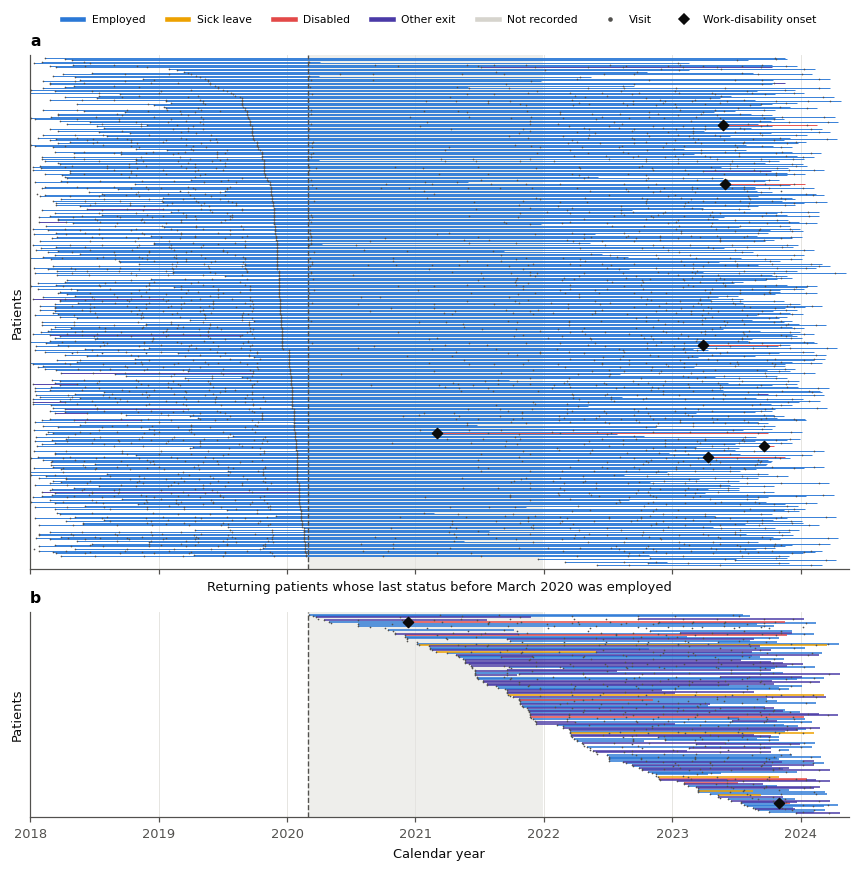

In [23]:
"""b  Every record from 2018 of the patients seen after March 2020: returning patients working before it, and new patients."""
from matplotlib.collections import LineCollection

_X0 = pd.Timestamp("2018-01-01")
_seen_after = set(_PCV["After"]["PTNO"])
_pre_st = visits[visits["HAS_STATUS"] & (visits["ASSDT"] < MAIN_END)].sort_values("ASSDT").groupby("PTNO")["EMP"].last()
_ret_pts = [p for p in _seen_after if _first_clinic[p] < MAIN_END and _pre_st.get(p) == "employed"]
_new_pts = [p for p in _seen_after if _first_clinic[p] >= MAIN_END]
_dec = lambda d: d.dt.year + (d.dt.dayofyear - 1) / 365.25
_ons_all = _F["land"][_F["C_ALL"] == 1].drop_duplicates(["pid", "event_date"])
_n_r, _n_n = max(len(_ret_pts), 1), max(len(_new_pts), 1)
fig, axes = plt.subplots(2, 1, figsize=(9.6, 9.0), sharex=True,
                         gridspec_kw={"height_ratios": [_n_r, max(_n_n, _n_r / 4)], "hspace": 0.12})
for ax, pts, ttl in [(axes[0], _ret_pts, f"a  Returning patients whose last status before March 2020 was employed (n = {len(_ret_pts)})"),
                     (axes[1], _new_pts, f"b  New patients: first clinic visit from March 2020 (n = {len(_new_pts)})")]:
    v_ = visits[visits["PTNO"].isin(pts) & (visits["ASSDT"] >= _X0)].sort_values(["PTNO", "ASSDT"])
    order = v_[v_["ASSDT"] >= MAIN_END].groupby("PTNO")["ASSDT"].min().sort_values().index if ttl.startswith("b") \
        else v_[v_["ASSDT"] < MAIN_END].groupby("PTNO")["ASSDT"].max().reindex(pts).sort_values().index
    row = pd.Series(np.arange(len(order)), index=order)
    s_ = v_[v_["HAS_STATUS"]].copy()
    s_["st"] = s_["EMP"].map(_state_of)
    s_["end"] = s_.groupby("PTNO")["ASSDT"].shift(-1).fillna(s_["ASSDT"] + pd.Timedelta(days=30))
    y_ = s_["PTNO"].map(row).values
    for st, col in STATE_COLORS.items():
        k = (s_["st"] == st).values
        if k.any():
            seg = np.stack([np.column_stack([_dec(s_["ASSDT"]).values[k], y_[k]]),
                            np.column_stack([_dec(s_["end"]).values[k], y_[k]])], 1)
            ax.add_collection(LineCollection(seg, colors=col, linewidths=1.0 if len(order) < 200 else 0.6))
    ax.scatter(_dec(v_["ASSDT"]), v_["PTNO"].map(row), s=1.2, color=INK_2, linewidths=0, zorder=3)
    o_ = _ons_all[_ons_all["pid"].isin(pts) & (_ons_all["event_date"] >= _X0)]
    ax.scatter(_dec(o_["event_date"]), o_["pid"].map(row), s=22, marker="D", color=INK, zorder=4)
    ax.axvspan(_dec(pd.Series(_cov[0:1])).iloc[0], _dec(pd.Series(_cov[1:2])).iloc[0], color=GRID_C, alpha=0.6, lw=0, zorder=0)
    ax.axvline(_dec(pd.Series([MAIN_END])).iloc[0], color=INK_2, lw=0.9, ls="--")
    ax.set_ylim(len(order) + 2, -2); ax.set_yticks([]); ax.grid(axis="y", visible=False)
    ax.set_ylabel("Patients"); ax.set_title(ttl, loc="left", fontsize=9)
axes[1].set_xlim(_dec(pd.Series([_X0])).iloc[0], _dec(pd.Series([_XEND])).iloc[0] + 0.1)
axes[1].set_xlabel("Calendar year")
_h = [plt.Line2D([], [], color=STATE_COLORS[s], lw=3) for s in "WSDOU"] + \
     [plt.Line2D([], [], color=INK_2, marker="o", ls="", ms=2), plt.Line2D([], [], color=INK, marker="D", ls="", ms=5)]
axes[0].legend(_h, [STATE_NAMES[s] for s in "WSDOU"] + ["Visit", "Work-disability onset"], ncol=7, loc="lower center",
               bbox_to_anchor=(0.5, 1.04), fontsize=7)
save_fig("explore07b_postcovid_records")

In [24]:
"""c  Changes of employment status recorded inside each window (consecutive recorded statuses, both inside it)."""
def _transitions(v_):
    s_ = v_[v_["HAS_STATUS"]].sort_values(["PTNO", "ASSDT"])[["PTNO", "ASSDT", "EMP"]].copy()
    s_["prev"] = s_.groupby("PTNO")["EMP"].shift()
    s_["gap"] = s_.groupby("PTNO")["ASSDT"].diff().dt.days / 365.25
    s_ = s_.dropna(subset=["prev"])
    fe, fs, fd = s_["prev"] == "employed", s_["prev"] == "sick leave", s_["prev"] == "disabled"
    to = s_["EMP"]
    out = {"Pairs of consecutive recorded statuses": len(s_),
           "Years between them": round(s_["gap"].sum(), 1),
           "Employed → employed": int((fe & (to == "employed")).sum()),
           "Employed → sick leave": int((fe & (to == "sick leave")).sum()),
           "Employed → disabled": int((fe & (to == "disabled")).sum())}
    out.update({f"Employed → {e}": int((fe & (to == e)).sum()) for e in sorted(OTHER_EXIT_STATES)})
    out.update({"Sick leave → disabled": int((fs & (to == "disabled")).sum()),
                "Sick leave → employed": int((fs & (to == "employed")).sum()),
                "Disabled → employed": int((fd & (to == "employed")).sum()),
                "Any change": int((to != s_["prev"]).sum())})
    out["Any change per 100 person-years"] = round(100 * out["Any change"] / max(out["Years between them"], 1e-9), 1)
    return out


STATUS_CHANGES_COVID = pd.DataFrame({(_WIN_LAB[w], grp): _transitions(_PCV[w] if grp == "All" else
                                                                      _PCV[w][_PCV[w]["Group"] == grp])
                                     for w in _WIN for grp in _GROUPS + ["All"]})
save_table(STATUS_CHANGES_COVID, "postcovid_status_changes")
display(_as_counts(STATUS_CHANGES_COVID))

Before (Jan 2016 - Feb 2020)                After (Mar 2020 - Apr 2024)               
                                                          Returning    New     All                   Returning    New     All
Pairs of consecutive recorded statuses                         5593   1052    6645                        2280    497    2777
Years between them                                           2202.1  355.7  2557.8                      1157.4  211.5  1368.9
Employed → employed                                            2713    618    3331                        1301    254    1555
Employed → sick leave                                             5      0       5                           0      0       0
Employed → disabled                                               5      4       9                           4      2       6
Employed → homemaker                                              3      0       3                           0      0       0
Employed → looking for work                                       7      0       7                           1      1       2
Employed → other                                                  2      1       3                           0      0       0
Employed → retired                                                3      1       4                           0      0       0
Employed → student                                                2      0       2                           0      1       1
Sick leave → disabled                                             3      0       3                           1      0       1
Sick leave → employed                                             2      0       2                           0      0       0
Disabled → employed                                               5      1       6                           2      0       2
Any change                                                       88     15     103                          22     13      35
Any change per 100 person-years                                 4.0    4.2     4.0                         1.9    6.1     2.6

Before (Jan 2016 - Feb 2020)                After (Mar 2020 - Apr 2024)               
                                                                   Returning    New     All                   Returning    New     All
Patients at risk                                                         425    142     567                         395     70     465
Person-years at risk                                                  1399.1  241.3  1640.4                      1253.3  108.2  1361.6
Onset: recorded as disabled                                                6      4      10                           6      2       8
Onset: sick leave ≥ 6 months, no return to work                            4      0       4                           0      0       0
Onset: short sick leave, then disabled                                     0      0       0                           0      0       0
Onsets, all                                                               10      4      14                           6      2       8
Other exits                                                               20      2      22                           9      3      12
  of which homemaker                                                       3      0       3                           0      0       0
  of which looking for work                                                7      0       7                           2      1       3
  of which other                                                           2      1       3                           1      0       1
  of which retired                                                         5      1       6                           0      0       0
  of which student                                                         3      0       3                           1      1       2
Open short sick leave at the end of follow-up                              1      0       1                           0      0       0
Onsets per 100 person-years                                             0.71   1.66    0.85                        0.48   1.85    0.59
Other exits per 100 person-years                                        1.43   0.83    1.34                        0.72   2.77    0.88

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024 (to Apr)
Patients at risk,364,370,370,388,397,406,424,431,460,461,396,403,415,403,80
Person-years at risk,327.7,341.9,342.9,349.5,362.7,366.6,385.0,394.3,416.3,404.5,373.9,373.3,381.5,287.7,7.0
Onset: recorded as disabled,6,2,5,2,1,4,4,0,4,2,2,1,0,6,0
"Onset: sick leave ≥ 6 months, no return to work",4,1,2,4,3,3,2,1,1,0,0,0,0,0,0
"Onset: short sick leave, then disabled",0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
"Onsets, all",10,3,7,6,5,7,6,1,5,2,2,1,0,6,0
Other exits,15,7,6,13,19,10,6,6,6,3,1,2,3,6,1
Onsets per 100 person-years,3.05,0.88,2.04,1.72,1.38,1.91,1.56,0.25,1.2,0.49,0.53,0.27,0.0,2.09,NaN
Other exits per 100 person-years,4.58,2.05,1.75,3.72,5.24,2.73,1.56,1.52,1.44,0.74,0.27,0.54,0.79,2.09,NaN


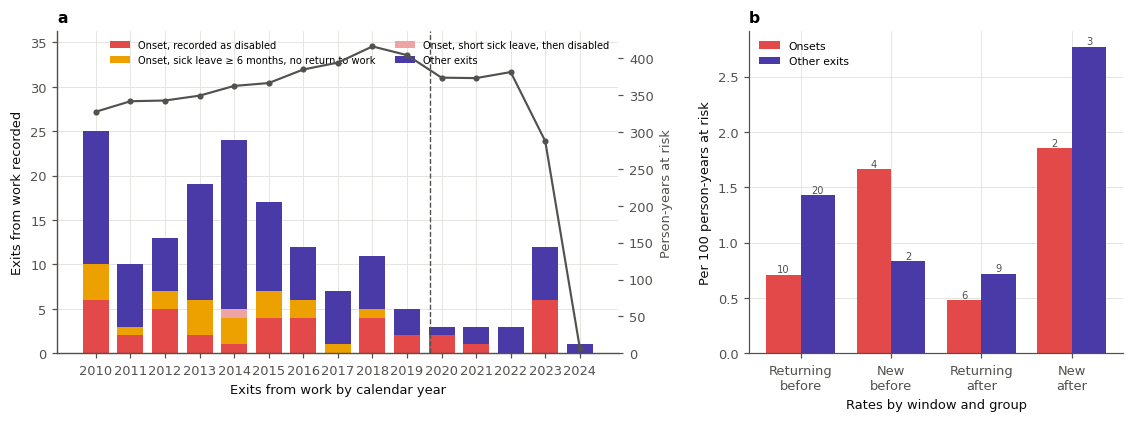

In [25]:
"""d  Exits from work in the working cohort (at-risk intervals of the whole extract, person-time split at the windows)."""
_l = _F["land"]
_t0 = pd.Series(pd.to_datetime(_F["LAND_T"], unit="D"))
_t1 = pd.Series(pd.to_datetime(_F["INT_END_ALL"], unit="D"))
_ev_d = _t1.where(_F["D1_ALL"] + _F["D2_ALL"] > 0)
_ROUTE = {"direct": "Onset: recorded as disabled", "long sick spell": "Onset: sick leave ≥ 6 months, no return to work",
          "short sick spell": "Onset: short sick leave, then disabled"}
_route_lab = _l["route"].map(_ROUTE).fillna("").values
_open_sick = (_l["exit_type"] == "unresolved_sick_leave").values & ~_F["_cont"]


def _exits(a, b, pids=None):
    k = np.ones(len(_l), bool) if pids is None else np.isin(_F["PID_ALL"], list(pids))
    py = ((_t1.clip(upper=b) - _t0.clip(lower=a)).dt.days.clip(lower=0) / 365.25).values[k]
    ev = _ev_d.between(a, b - pd.Timedelta(days=1)).values & k
    out = {"Patients at risk": int(len(np.unique(_F["PID_ALL"][k][py > 0]))), "Person-years at risk": round(py.sum(), 1)}
    for lab in _ROUTE.values():
        out[lab] = int((ev & (_F["D1_ALL"] == 1) & (_route_lab == lab)).sum())
    out["Onsets, all"] = int((ev & (_F["D1_ALL"] == 1)).sum())
    out["Other exits"] = int((ev & (_F["D2_ALL"] == 1)).sum())
    out.update({f"  of which {e}": int((ev & (_F["D2_ALL"] == 1) & (_l["exit_emp"].values == e)).sum())
                for e in sorted(OTHER_EXIT_STATES)})
    out["Open short sick leave at the end of follow-up"] = int((_t1.between(a, b - pd.Timedelta(days=1)).values & k &
                                                                _open_sick).sum())
    out["Onsets per 100 person-years"] = round(100 * out["Onsets, all"] / max(out["Person-years at risk"], 1e-9), 2)
    out["Other exits per 100 person-years"] = round(100 * out["Other exits"] / max(out["Person-years at risk"], 1e-9), 2)
    return out


EXITS_COVID = pd.DataFrame({(_WIN_LAB[w], grp): _exits(*_WIN[w], None if grp == "All" else
                                                       [p for p in _F["ALL_PIDS"] if (_first_clinic[p] >= _WIN[w][0]) == (grp == "New")])
                            for w in _WIN for grp in _GROUPS + ["All"]})
save_table(EXITS_COVID, "postcovid_exits")
display(_as_counts(EXITS_COVID))

_yr_range = range(2010, _XEND.year + 1)
EXITS_BY_YEAR = pd.DataFrame({str(y) if y < _XEND.year else f"{y} (to {_XEND - pd.Timedelta(days=1):%b})":
                              _exits(pd.Timestamp(f"{y}-01-01"), min(pd.Timestamp(f"{y + 1}-01-01"), _XEND))
                              for y in _yr_range})
EXITS_BY_YEAR = EXITS_BY_YEAR.loc[["Patients at risk", "Person-years at risk"] + list(_ROUTE.values()) +
                                  ["Onsets, all", "Other exits", "Onsets per 100 person-years",
                                   "Other exits per 100 person-years"]]
_thin = EXITS_BY_YEAR.loc["Person-years at risk"].astype(float) < 50          # rates not shown for a year with < 50 py
EXITS_BY_YEAR.loc[["Onsets per 100 person-years", "Other exits per 100 person-years"], _thin] = np.nan
save_table(EXITS_BY_YEAR, "postcovid_exits_by_year")
display(_as_counts(EXITS_BY_YEAR))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"wspace": 0.28, "width_ratios": [1.5, 1]})
ax = axes[0]
_xy = np.arange(len(EXITS_BY_YEAR.columns))
_bot = np.zeros(len(_xy))
for lab, col in [(list(_ROUTE.values())[0], STATE_COLORS["D"]), (list(_ROUTE.values())[1], STATE_COLORS["S"]),
                 (list(_ROUTE.values())[2], "#f0a3a3"), ("Other exits", C4)]:
    vals = EXITS_BY_YEAR.loc[lab].values.astype(float)
    ax.bar(_xy, vals, 0.75, bottom=_bot, color=col, label=lab.replace("Onset: ", "Onset, "))
    _bot += vals
ax2 = ax.twinx(); ax2.plot(_xy, EXITS_BY_YEAR.loc["Person-years at risk"].values, color=INK_2, lw=1.4, marker="o", ms=3)
ax2.set_ylabel("Person-years at risk", color=INK_2); ax2.grid(False); ax2.set_ylim(0, None)
_im = list(_yr_range).index(MAIN_END.year)
ax.axvline(_im - 0.5 + (MAIN_END.dayofyear - 1) / 365.25, color=INK_2, lw=0.9, ls="--")
ax.set_xticks(_xy, [c.split(" ")[0] for c in EXITS_BY_YEAR.columns]); ax.set_ylabel("Exits from work recorded")
ax.set_ylim(0, EXITS_BY_YEAR.loc[list(_ROUTE.values()) + ["Other exits"]].astype(float).sum().max() * 1.45)
ax.legend(fontsize=6.5, loc="upper right", ncol=2); ax.set_title("a  Exits from work by calendar year (counts)", loc="left", fontsize=9)
ax = axes[1]
_cols = [(w, g) for w in _WIN for g in _GROUPS]
for j, (rate, col) in enumerate([("Onsets per 100 person-years", STATE_COLORS["D"]), ("Other exits per 100 person-years", C4)]):
    vals = [EXITS_COVID.loc[rate, (_WIN_LAB[w], g)] for w, g in _cols]
    ax.bar(np.arange(len(_cols)) + (j - 0.5) * 0.38, vals, 0.38, color=col, label=rate.split(" per")[0])
    for i, (w, g) in enumerate(_cols):
        n_ = EXITS_COVID.loc["Onsets, all" if j == 0 else "Other exits", (_WIN_LAB[w], g)]
        ax.text(i + (j - 0.5) * 0.38, vals[i], f"{int(n_)}", ha="center", va="bottom", fontsize=6.5, color=INK_2)
ax.set_xticks(np.arange(len(_cols)), [f"{g}\n{w.lower()}" for w, g in _cols]); ax.set_ylabel("Per 100 person-years at risk")
ax.legend(fontsize=7); ax.set_title("b  Rates by window and group (numbers = counts)", loc="left", fontsize=9)
save_fig("explore07d_postcovid_exits")

In [26]:
"""e  Every work-disability onset from March 2020."""
_po = _ons_all[_ons_all["event_date"] >= MAIN_END].sort_values("event_date")
_po_v = _wa[_wa["ASSDT"] >= MAIN_END]
ONSETS_POSTCOVID = pd.DataFrame({
    "Group": np.where(_po["pid"].map(_first_clinic) >= MAIN_END, "New", "Returning"),
    "Onset (month)": _po["event_date"].dt.strftime("%b %Y").values,
    "How recorded": _po["route"].map(_ROUTE).str.replace("Onset: ", "").values,
    "Status recorded": _po["exit_emp"].values,
    "Last employed visit": _po["last_work_date"].dt.strftime("%b %Y").values,
    "Months from last employed visit to onset": ((_po["event_date"] - _po["last_work_date"]).dt.days / MONTH_DAYS).round(1).values,
    "Visits from March 2020 to onset": [int(((_po_v["PTNO"] == p) & (_po_v["ASSDT"] <= d)).sum())
                                        for p, d in zip(_po["pid"], _po["event_date"])],
    "Years in clinic at onset": [round((d - _first_clinic[p]).days / 365.25, 1) for p, d in zip(_po["pid"], _po["event_date"])]},
    index=pd.RangeIndex(1, len(_po) + 1, name="Onset"))
save_table(ONSETS_POSTCOVID, "postcovid_onsets")
display(ONSETS_POSTCOVID)

,Group,Onset (month),How recorded,Status recorded,Last employed visit,Months from last employed visit to onset,Visits from March 2020 to onset,Years in clinic at onset
Onset,,,,,,,,
1,New,Dec 2020,recorded as disabled,disabled,Apr 2020,7.4,2,0.6
2,Returning,Mar 2021,recorded as disabled,disabled,Jan 2020,13.3,1,4.8
3,Returning,Mar 2023,recorded as disabled,disabled,Nov 2022,4.4,5,6.1
4,Returning,Apr 2023,recorded as disabled,disabled,Aug 2022,8.3,3,8.1
5,Returning,May 2023,recorded as disabled,disabled,Sep 2019,44.2,1,4.5
6,Returning,Jun 2023,recorded as disabled,disabled,Nov 2022,6.4,8,4.6
7,Returning,Sep 2023,recorded as disabled,disabled,Apr 2023,4.8,5,8.3
8,New,Oct 2023,recorded as disabled,disabled,Jul 2023,3.6,2,0.3


## 1.7 Table 1: the patients at entry

One column per way follow-up ended (Section 1.6.1), at each patient's **first landmark** (first employed visit before
65): median [IQR] or %, with the share missing where any value is missing. For the SF-36 scales and the fatigue
severity scale (FSS) the score is that of the first landmark with a form in the past 12 months, and the share given
beside it is the share of the group's **employed visits with no form in the 12 months before** (the score the model
then predicts, Section 1.2), not the share of patients who never completed one.

In [27]:
"""Table 1 by how follow-up ended; SF-36 and FSS with the share of employed visits without a form in the past 12 months."""
T1_GROUPS = {"Work disability": ["Work disability"], "Other exit from work": ["Other exit from work"],
             "No exit recorded": ["Still working and attending", "Left the clinic while working",
                                  "Reached 65, died or other censoring"]}
_SF_T1 = [("SF_PF", "SF-36 physical functioning (0-100)"), ("SF_RP", "SF-36 role physical (0-100)"),
          ("SF_BP", "SF-36 bodily pain (0-100)"), ("SF_GH", "SF-36 general health (0-100)"),
          ("SF_VT", "SF-36 vitality (0-100)"), ("SF_SF", "SF-36 social functioning (0-100)"),
          ("SF_RE", "SF-36 role emotional (0-100)"), ("SF_MH", "SF-36 mental health (0-100)"),
          ("PCS", "SF-36 physical component summary"), ("MCS", "SF-36 mental component summary"),
          ("FSS10", "Fatigue severity scale (0-10)")]
_T1_VARS = [("age_at_record", "Age (years)", False), ("SEX_FEMALE", "Female", True),
            ("RACE_WHITE", "Race: White", True), ("RACE_BLACK", "Race: Black", True),
            ("RACE_ASIAN", "Race: Asian (Chinese, Filipino)", True), ("RACE_OTHER_UNKNOWN", "Race: other, mixed or not recorded", True),
            ("EDU_HIGHER", "Education: post-secondary", True), ("SMOKER", "Current smoker", True),
            ("disease_duration_yrs", "Disease duration (years)", False), ("YRS_IN_CLINIC", "Years since first clinic visit", False),
            ("AMS_12M", "SLEDAI-2K, 12-month adjusted mean", False), ("CLIN_SLEDAI", "Clinical SLEDAI-2K (no serology)", False),
            ("score_n", "SDI damage score", False), ("SDI_NP", "SDI neuropsychiatric", False), ("MSK_DAMAGE", "SDI musculoskeletal", False),
            ("FATIGUE", "Fatigue", True), ("FM_ANY", "Fibromyalgia (diagnosis or >= 11 tender points)", True),
            ("ARTHRALGIA", "Arthralgia", True), ("DYSPNOEA", "Dyspnoea", True), ("JOINT_COUNT", "Active joint count", False),
            ("STERAVER_0", "Prednisone (mg/day)", False), ("PRED_ABOVE_TARGET", "Prednisone above the target of the time", True),
            ("AM_CLASS", "Antimalarial", True), ("IS_CLASS", "Conventional immunosuppressant", True),
            ("ADV_CLASS", "Advanced therapy (cyclophosphamide or biologic)", True),
            ("YRS_IS", "Years on any immunosuppressant", False), ("VISIT_RATE_1Y", "Clinic visits per year", False)]
_first_lm = land.groupby("pid").head(1)
_t1 = visits.loc[_first_lm["visit_row"].values].reset_index(drop=True)
_t1["pid"] = _first_lm["pid"].values
for _c in LANDMARK_TIME_VARS:                                     # moved forward to the landmark date, as the model reads them
    _t1[_c] = LAND_X[_c].values[_first_lm.index.values] if _c in LAND_X else _t1[_c]
_t1["RACE_WHITE"] = (_t1["RACE_GROUP"] == "White").astype(float)
_t1["group"] = FINAL_STATE.reindex(_t1["pid"]).values
# employed visits under 65 of the cohort, from each patient's entry: is there a form in the 12 months before?
_ev_v = visits[(visits["EMP"] == "employed") & (visits["age_at_record"] < AGE_CAP_YEARS)
               & visits["PTNO"].isin(set(ALL_PIDS))].copy()
_ev_v = _ev_v[_ev_v["ASSDT"] >= _ev_v["PTNO"].map(ENTRY_DATE)]
_ev_v["group"] = FINAL_STATE.reindex(_ev_v["PTNO"]).values
_sf_first = {}
for _c, _ in _SF_T1:                                              # the first landmark with a form in the past 12 months
    _x = pd.Series(visits.loc[land["visit_row"].values, _c].values, index=land.index)
    _ok = land.assign(v=_x.values).dropna(subset=["v"])
    _sf_first[_c] = _ok.groupby("pid")["v"].first()


def _t1_cell(x, binary):
    x = pd.Series(x, dtype=float)
    miss = x.isna().mean()
    x = x.dropna()
    if not len(x):
        return "–"
    s = f"{100 * x.mean():.0f} %" if binary else f"{x.median():.1f} [{x.quantile(.25):.1f}, {x.quantile(.75):.1f}]"
    return s + (f" ({100 * miss:.0f} % missing)" if miss > 0.005 else "")


_t1_cols = {"All": np.ones(len(_t1), bool)} | {g: _t1["group"].isin(m).values for g, m in T1_GROUPS.items()}
_rows_t1 = {}
_rows_t1["Patients (n)"] = {g: f"{int(m.sum()):,}" for g, m in _t1_cols.items()}
for _c, _lab, _bin in _T1_VARS:
    _rows_t1[_lab] = {g: _t1_cell(_t1.loc[m, _c], _bin) for g, m in _t1_cols.items()}
for _c, _lab in _SF_T1:
    _r = {}
    for g, m in _t1_cols.items():
        _pids = set(_t1.loc[m, "pid"])
        _x = _sf_first[_c].reindex(sorted(_pids)).dropna()
        _vv_g = _ev_v[_ev_v["PTNO"].isin(_pids)]
        _none = 100 * _vv_g[_c].isna().mean() if len(_vv_g) else np.nan
        _r[g] = (f"{_x.median():.1f} [{_x.quantile(.25):.1f}, {_x.quantile(.75):.1f}]" if len(_x) else "–") + \
            f"; no form in the past 12 months at {_none:.0f} % of visits"
    _rows_t1[_lab] = _r
_lm_n = pd.Series(PID_ALL).value_counts()
_rows_t1["Landmarks per patient"] = {g: (lambda n: f"{n.median():.0f} [{n.quantile(.25):.0f}, {n.quantile(.75):.0f}]")(
    _lm_n.reindex(_t1.loc[m, "pid"]).astype(float)) for g, m in _t1_cols.items()}
_rows_t1["Follow-up from entry (years)"] = {g: (lambda f: f"{f.median():.1f} [{f.quantile(.25):.1f}, {f.quantile(.75):.1f}]")(
    FU_YEARS.reindex(_t1.loc[m, "pid"])) for g, m in _t1_cols.items()}
_rows_t1["Employed visits (n)"] = {g: f"{int(_ev_v['group'].isin(T1_GROUPS.get(g, FINAL_ORDER)).sum()):,}" for g in _t1_cols}
TABLE1 = pd.DataFrame(_rows_t1).T
TABLE1.columns = [f"{g} (n = {int(m.sum()):,})" for g, m in _t1_cols.items()]
display(TABLE1)
save_table(TABLE1, "table1")
_nf_all = 100 * _ev_v["PCS"].isna().mean()
say(f"""
**What this means.** At entry, the {int(_t1_cols['Work disability'].sum())} patients who later left work for health
reasons were {"older" if _t1.loc[_t1_cols['Work disability'], 'age_at_record'].median() > _t1.loc[_t1_cols['No exit recorded'], 'age_at_record'].median() else "younger"}
and had more damage and symptoms than those with no exit recorded (table). The SF-36 was missing at
{_nf_all:.0f} % of employed visits (no form in the 12 months before), and the FSS at
{100 * _ev_v["FSS10"].isna().mean():.0f} %, so at most visits the model reads the predicted score (Section 1.2).
""")

,All (n = 958),Work disability (n = 142),Other exit from work (n = 134),No exit recorded (n = 682)
Patients (n),958,142,134,682
Age (years),"34.6 [27.3, 43.9]","38.4 [29.9, 46.5]","37.3 [26.5, 47.2]","33.6 [27.2, 42.2]"
Female,89 %,92 %,91 %,87 %
Race: White,61 %,66 %,77 %,57 %
Race: Black,14 %,20 %,10 %,13 %
"Race: Asian (Chinese, Filipino)",15 %,11 %,7 %,18 %
"Race: other, mixed or not recorded",10 %,4 %,5 %,12 %
Education: post-secondary,46 % (16 % missing),36 % (11 % missing),35 % (83 % missing),48 % (4 % missing)
Current smoker,13 % (3 % missing),20 % (1 % missing),14 % (1 % missing),11 % (3 % missing)
Disease duration (years),"5.5 [0.9, 11.4]","6.5 [0.9, 14.2]","6.5 [1.0, 13.0]","5.2 [0.9, 10.8]"


**What this means.** At entry, the 142 patients who later left work for health
reasons were older
and had more damage and symptoms than those with no exit recorded (table). The SF-36 was missing at
53 % of employed visits (no form in the 12 months before), and the FSS at
61 %, so at most visits the model reads the predicted score (Section 1.2).

---
# Part II. The models

> **The analysis period.** Every visit, outcome and censoring date is taken from the extract as if it had ended on
> 1 March 2020. Only Section 4.0 looks at the years after that, on the whole extract.

## 2.1 The reported model: HazReg

> **In plain words.** HazReg asks two questions at every landmark: *how fast is this patient likely to leave
> work for health reasons?* and *how fast for any other reason?* It combines the two answers into the chance of
> work disability within 36 months. Someone likely to retire soon has less time in which to become work-disabled,
> and the model accounts for that.

**Why a hazard model.** Two features of the data make it the natural choice:

* **Competing exits.** Retirement or homemaking ends the risk of work disability. Treating these patients as
  simply "no outcome" would overstate how safe they were.
* **Partial follow-up counts.** A visit from 2023 has only a few months of follow-up. A hazard model still learns
  from those months. A model of the 36-month yes / no outcome must discard them.

**Specification**

| | |
|:--|:--|
| Inputs | 23 routine variables and three patient-reported scores at the landmark (Section 3.4 lists them): the SF-36 physical and mental component summaries and the fatigue severity scale. Each is the score of a form from the past 12 months or, without one, its prediction from the patient's older forms and the routine variables (Section 1.2) |
| Time since the landmark | The linear predictors are fitted on follow-up to s + 36 months. Each training set then estimates a multiplier of each hazard for months 0-6, 6-12 and 12 onwards, with the linear predictors held fixed, and the risk integrates the hazards piece by piece. The multipliers move the absolute risks and the percentage cut points of the bands; they barely reorder patients (Section 3.10.1) |
| Calendar time | None. The model has no calendar term, so it carries a single risk scale, the average recording of the development years. The comparator with a calendar-year spline is in Section 4.3 |
| Flexible effects | Restricted cubic splines for prednisone, SDI damage, 12-month adjusted mean SLEDAI-2K and age |
| Missing values | Median imputation; a missing-value indicator only for inputs missing at ≥ 2 % of landmarks |
| Fitting | Two ridge-penalised Poisson regressions on the at-risk time between visits, one per exit type. Spline and missing-indicator terms are penalised 4 times as hard as the main effects, which keeps the effective number of parameters near what the data support (Section 2.4) |
| Tuning | The penalty for each exit type, by 3-fold patient-grouped inner cross-validation. It is repeated inside every refit, so every performance figure includes it |
| Output | Cumulative incidence of onset at 36 months under the two hazards, reported as a **relative risk** (the risk ÷ the risk of the median landmark in the development cohort) and a **relative tier** (Section 3.0). The absolute risk is a secondary output, labelled as the risk under the average recording of the development years |

In [28]:
"""Switch to the main analysis (visits before MAIN_END) and rebuild the Part I objects that later parts reuse."""
use_data("main")
_last, _left, _end_date = follow_up_endings()
LEFT_CLINIC_PIDS = set(_last.loc[_left, "pid"])
LAST_ROWS, LAST_ENDING, LAST_END_DATE = _last.index.values, _last["Ending"].values, _end_date.values
_py, _d1, _d2 = rates_by_era(D1_ALL, D2_ALL)
LM_RUN_START = ((pd.to_datetime(visits.loc[land["visit_row"], "STATUS_RUN_START"].values) - pd.Timestamp("1970-01-01"))
                / pd.Timedelta(days=1)).values.astype(float)
_runs2 = status_runs(status_record(visits))
ENTRY_DATE, FINAL_STATE, FU_YEARS = cohort_states(_last)
FIRST_ONSET_DATE, CAND_ONSET, CAND_WORKING, EXAMPLE_PIDS = example_patients()
MO_BEFORE = months_before_anchor()
_ever = PID_EVENT[ROW_PIDX].astype(bool)
_bin = np.digitize(MO_BEFORE, _bins)
print(f"Main analysis: {N_LAND:,} landmarks of {len(ALL_PIDS):,} patients, {int(D1_ALL.sum())} onsets, visits to "
      f"{DATA_END_DATE.date()}.")

Main analysis: 12,976 landmarks of 958 patients, 150 onsets, visits to 2020-02-29.


In [29]:
"""HazReg: preprocessing, the fitting procedure, prediction."""
DISPLAY = {"age_at_record": "Age (years)", "disease_duration_yrs": "Disease duration (years)",
           "AMS_12M": "SLEDAI-2K, 12-month adjusted mean", "score_n": "SDI damage score", "STERAVER_0": "Prednisone (mg/day)",
           "FATIGUE": "Fatigue", "FM_ANY": "Fibromyalgia (diagnosis or >= 11 tender points)", "ARTHRALGIA": "Arthralgia", "DYSPNOEA": "Dyspnoea",
           "TREAT_LADDER": "Treatment ladder (0 none - 3 advanced)", "YRS_IN_CLINIC": "Years since first clinic visit",
           "AM_CLASS": "Antimalarial", "IS_CLASS": "Conventional immunosuppressant", "ADV_CLASS": "Advanced therapy",
           "PRED_ABOVE_TARGET": "Prednisone above the target of the time", "SDI_NP": "SDI neuropsychiatric",
           "CAL_YEAR": "Calendar year", "COVID": "COVID-19 period (Mar 2020 - Dec 2021)",
           "JOINT_COUNT": "Active joint count", "MSK_DAMAGE": "SDI musculoskeletal",
           "EDU_HIGHER": "Education: post-secondary", "SMOKER": "Current smoker", "RACE_BLACK": "Race: Black",
           "RACE_ASIAN": "Race: Asian", "RACE_OTHER_UNKNOWN": "Race: other / not recorded",
           "PCS": "SF-36 physical component summary (PCS)", "MCS": "SF-36 mental component summary (MCS)",
           PCS_NR: "SF-36 physical score without the role scales (PF, BP, GH)", "FSS10": "Fatigue severity scale (FSS)",
           PCS_INPUT: "SF-36 PCS (form in the past 12 months, else predicted)",
           MCS_INPUT: "SF-36 MCS (form in the past 12 months, else predicted)",
           FSS_INPUT: "Fatigue severity scale (form in the past 12 months, else predicted)",
           "CLIN_SLEDAI": "Clinical SLEDAI-2K (no serology)", "VISIT_RATE_1Y": "Clinic visits per year",
           "YRS_IS": "Years on any immunosuppressant"}

DISPLAY |= {"VISITS_24M": "Clinic visits in the last 24 months", "SDI_CHG_24M": "SDI damage score, change over 24 months",
            "SLEDAI_CHG_24M": "SLEDAI-2K, change over 24 months"}
DISPLAY |= {f"PRED_WCE_{k + 1}": f"Prednisone, weighted cumulative exposure (basis {k + 1})" for k in range(WCE_DF)}
# ---- From here on the analysis uses the visits before MAIN_END; only Section 4.0 switches to the whole extract.
# ---- the first-visit rung of the ladder: every input at the patient's first employed visit, + years since it
FIRST_VARS = [f"{c}__IDX" for c in COMPACT_VARS] + ["YRS_SINCE_INDEX"]
LOG1P_VARS |= {f"{c}__IDX" for c in COMPACT_VARS if c in LOG1P_VARS} | {"YRS_SINCE_INDEX"}
for c in COMPACT_VARS:
    DISPLAY[f"{c}__IDX"] = DISPLAY[c] + " at first employed visit"
DISPLAY["YRS_SINCE_INDEX"] = "Years since first employed visit"

# ---- the landmark supermodel (Section 3.8), on the landmark clock s = years since the first employed visit, with
# f(s) = (min(s, 20) - 5) / 10: beta(s) = b0 + b1 f + b2 f^2 for each input (input on the model's scale, centred at its
# median), and a main effect gamma(s) = g1 f + g2 f^2 (the ipl* model of van Houwelingen & Putter)
XS_COLS = [f"{c}__XS" for c in XS_VARS] + [f"{c}__XS2" for c in XS_VARS] + ["LM_S1", "LM_S2"]
for c in XS_VARS:
    DISPLAY[f"{c}__XS"] = DISPLAY[c] + " x f(s)"
    DISPLAY[f"{c}__XS2"] = DISPLAY[c] + " x f(s)²"
DISPLAY["LM_S1"], DISPLAY["LM_S2"] = "Landmark time, f(s)", "Landmark time, f(s)²"
DISPLAY["GAP_YRS"] = "Age of the inputs at the landmark (years)"

# ---- history summaries (Section 3.5): over the last 2 years, or the whole record since the first clinic visit, the
# mean of each time-varying input and its change (current value - first value in the window), + visits per year
HIST_ITEMS = ["SLEDAI2_I", "STERAVER_0", "score_n", "FATIGUE", "ARTHRALGIA", "DYSPNOEA", "FM_ANY", "JOINT_COUNT",
              "TREAT_LADDER"]
HIST_WINDOWS = {"2Y": 2 * 365.25, "ALL": np.inf}
_vt = visits["ASSDT"].values.astype("datetime64[D]").astype(float)


def history_summaries(win_days, tag):
    out = {f"{c}__MEAN_{tag}": np.full(len(visits), np.nan) for c in HIST_ITEMS}
    out |= {f"{c}__CHG_{tag}": np.full(len(visits), np.nan) for c in HIST_ITEMS}
    out[f"VISITS_PER_YR_{tag}"] = np.full(len(visits), np.nan)
    vals = {c: visits[c].values.astype(float) for c in HIST_ITEMS}
    for idx in visits.groupby("PTNO", sort=False).indices.values():
        t = _vt[idx]
        j = np.arange(len(idx))
        lo = np.searchsorted(t, t - win_days, "left") if np.isfinite(win_days) else np.zeros(len(idx), int)
        out[f"VISITS_PER_YR_{tag}"][idx] = (j - lo) / np.maximum((t - t[lo]) / 365.25, 0.5)
        for c in HIST_ITEMS:
            x = vals[c][idx]
            ok = ~np.isnan(x)
            cs, cn = np.r_[0.0, np.cumsum(np.where(ok, x, 0.0))], np.r_[0, np.cumsum(ok)]
            cnt = cn[j + 1] - cn[lo]
            out[f"{c}__MEAN_{tag}"][idx] = np.where(cnt > 0, (cs[j + 1] - cs[lo]) / np.maximum(cnt, 1), np.nan)
            nxt = np.minimum.accumulate(np.where(ok, j, len(idx))[::-1])[::-1]   # next recorded value at or after
            first = np.where(nxt[lo] <= j, x[np.minimum(nxt[lo], len(idx) - 1)], np.nan)
            out[f"{c}__CHG_{tag}"][idx] = x - first
    return out


HIST_V = {_tag: history_summaries(_win, _tag) for _tag, _win in HIST_WINDOWS.items()}     # one row per clinic visit
HIST_VARS = {_tag: list(_hs) for _tag, _hs in HIST_V.items()}
for _tag in HIST_WINDOWS:
    LOG1P_VARS |= {f"{c}__{s}_{_tag}" for c in ["SLEDAI2_I", "STERAVER_0", "score_n", "JOINT_COUNT"]
                   for s in ("MEAN", "CHG")} | {f"VISITS_PER_YR_{_tag}"}
    _wl = "last 2 years" if _tag == "2Y" else "whole record"
    for c in HIST_ITEMS:
        _base = {"SLEDAI2_I": "SLEDAI-2K at the visit"}.get(c, DISPLAY.get(c, c))
        DISPLAY[f"{c}__MEAN_{_tag}"] = f"{_base}, mean over the {_wl}"
        DISPLAY[f"{c}__CHG_{_tag}"] = f"{_base}, change over the {_wl}"
    DISPLAY[f"VISITS_PER_YR_{_tag}"] = f"Clinic visits per year, {_wl}"


def augment_land_x():
    """Add the first-visit inputs, the supermodel interactions and the history summaries to the LAND_X in use."""
    fr = land.groupby("pid")["visit_row"].transform("first").values
    for c in COMPACT_VARS:
        LAND_X[f"{c}__IDX"] = visits.loc[fr, c].values
    LAND_X["YRS_SINCE_INDEX"] = (land["visit_date"].values - visits.loc[fr, "ASSDT"].values) / np.timedelta64(1, "D") / 365.25
    s_xs = (np.minimum(LAND_X["YRS_SINCE_INDEX"].astype(float), XS_CAP) - XS_CENTRE) / 10
    LAND_X["LM_S1"], LAND_X["LM_S2"] = s_xs.values, (s_xs ** 2).values
    for c in XS_VARS:
        x = LAND_X[c].astype(float)
        x = _slog1p(x) if c in LOG1P_VARS else x
        LAND_X[f"{c}__XS"] = ((x - x.median()).fillna(0) * s_xs).values
        LAND_X[f"{c}__XS2"] = ((x - x.median()).fillna(0) * s_xs ** 2).values
    for _tag, hs in HIST_V.items():
        for c, v in hs.items():
            LAND_X[c] = v[land["visit_row"].values]


augment_land_x()
MISSING_COLS = [c for c in LAND_X.columns if LAND_X[c].isna().any()]   # used by Prep


_BASE_LO = np.array(BASELINE_EDGES, float) / 12.0
_BASE_WIDTH = np.r_[np.diff(_BASE_LO), np.inf]


def fit_baseline(eta, d1, d2, dt, w=None):
    """Log multipliers (cause, band) of the fitted hazards in each band of time since the landmark, with the linear
    predictors held fixed: (events + prior) / (expected + prior) in each band, the Poisson maximum likelihood estimate
    given exp(eta) as offset. An event belongs to the band in which its interval ends."""
    dt = np.asarray(dt, float)
    w = np.ones(len(dt)) if w is None else np.asarray(w, float)
    expo = np.minimum(np.maximum(dt[:, None] - _BASE_LO, 0.0), _BASE_WIDTH)      # years of each interval in each band
    band = np.searchsorted(_BASE_LO[1:], dt, side="left")
    out = np.zeros((2, NB))
    for c, d in enumerate((d1, d2)):
        O = np.bincount(band, weights=w * np.asarray(d, float), minlength=NB)
        E = ((w * np.exp(np.clip(eta[:, c], -30, 5)))[:, None] * expo).sum(0)
        out[c] = np.log((O + BASELINE_PRIOR) / (E + BASELINE_PRIOR))
    return out


def cif_both(eta, months=H, *, base):
    """Cumulative incidence of (onset, other exit) by `months`: hazards exp(eta) per year, times exp(base) in each band of
    time since the landmark, integrated piece by piece. base: (2, NB), (n, 2, NB), or 0.0 for hazards that stay flat."""
    n = len(eta)
    rate = np.exp(np.clip(eta[:, :2], -30, 5))
    g = np.exp(np.broadcast_to(np.asarray(base, float), (n, 2, NB)))
    width = np.minimum(np.maximum(months / 12.0 - _BASE_LO, 0.0), _BASE_WIDTH)
    out, S = np.zeros((n, 2)), np.ones(n)
    for b in range(NB):
        r = rate * g[:, :, b]
        tot = r.sum(1)
        out += (S * -np.expm1(-tot * width[b]) / tot)[:, None] * r
        S = S * np.exp(-tot * width[b])
    return out


def cif(eta, months=H, *, base):
    """Cumulative incidence of onset by `months` (see cif_both). `base` is required: the baseline of the model that gave eta."""
    return cif_both(eta, months, base=base)[:, 0]


def _logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _expit(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, float)))


def _pois_path(X, d, dt, alphas, w=None):
    """Ridge Poisson fits along the penalty path (largest first, warm-started); w: optional row weights."""
    m = PoissonRegressor(alpha=alphas[0], max_iter=3000, warm_start=True)
    out = {}
    for a in sorted(alphas, reverse=True):
        m.set_params(alpha=a)
        m.fit(X, d / np.maximum(dt, 1e-9), sample_weight=dt if w is None else dt * w)
        out[a] = (m.coef_.copy(), float(m.intercept_))
    return out


def _inner_folds(rows, seed):
    pids = PID_ALL[rows]
    up = np.unique(pids)
    fold_of = dict(zip(up, np.random.RandomState(seed).permutation(len(up)) % INNER_SPLITS))
    return np.array([fold_of[p] for p in pids])


def with_calendar(cols, spline, rows, calendar=None, frame=None):
    """The inputs plus the calendar terms (a calendar-year spline, and the COVID-19 step when the rows include that
    period), unless calendar=False or the calendar terms are already among the inputs."""
    calendar = MODEL_CALENDAR if calendar is None else calendar
    cols, spline = list(cols), list(spline)
    if not calendar or "CAL_YEAR" in cols:
        return cols, spline
    F = LAND_X if frame is None else frame
    extra = ["CAL_YEAR"] + (["COVID"] if F["COVID"].values[np.asarray(rows)].any() else [])
    return cols + extra, spline + ["CAL_YEAR"]


def recency_frame(F, h):
    """F with each DECAY_ITEMS input replaced by its recency-weighted mean at half-life h (months; 0 / None: as is)."""
    if not h:
        return F
    return F.assign(**{c: F[_rname(c, h)].values for c in DECAY_ITEMS if c in F.columns})


def recency_inputs(cols, spline, h):
    """The inputs of a model read at half-life h: the same names (their values come from recency_frame) plus, for
    h > 0, the RECENCY_EXTRAS."""
    cols = list(cols)
    return (cols + [c for c in RECENCY_EXTRAS if c not in cols] if h else cols), list(spline)


def _recency_on(cols, recency=None):
    return (MODEL_RECENCY if recency is None else recency) and any(c in DECAY_ITEMS for c in cols)


def design(model, F):
    """A model's design matrix for the rows of frame F: the inputs at the model's half-life (model['half_life']),
    and the calendar terms fixed where the model scores them, the latest year of its training data, outside the
    COVID-19 period (model['cal_ref']; none for a model without calendar time)."""
    F = recency_frame(F, model.get("half_life"))
    if model.get("cal_ref") is not None:
        F = F.assign(CAL_YEAR=float(model["cal_ref"]), COVID=0.0)
    return model["prep"].transform(F)


def fit_procedure(rows, cols=COMPACT_VARS, spline=SPLINE_VARS, dt=None, d1=None, d2=None, alphas=None, seed=0, frame=None,
                  w=None, calendar=None, half_life=None, recency=None):
    """The whole hazard-model procedure on landmark rows (duplicates allowed: bootstrap). Inner 3-fold patient-grouped
    CV chooses the penalty of each cause on the Poisson deviance (the onset penalty is then divided by
    ONSET_PENALTY_DIV), then both causes are refitted on all `rows`. The inner-CV onset deviance of every half-life is
    returned ("h_dev"), so that the final model's half-life can be chosen on all the cross-validation fits together. The
    person-time and events default to those of the data in use (Section 1.4). Calendar time is added to the inputs
    (with_calendar) and fixed at the latest training year when the model scores (design). w: row weights (Section
    4.4.1, down-weighting of older data). The half-life of the recency-weighted inputs is tuned with the penalties
    (RECENCY_HALF_LIVES) on the onset deviance, unless given (half_life, or a third element of alphas); the model's
    "alphas" carry it."""
    dt, d1, d2 = INT_YRS if dt is None else dt, D1 if d1 is None else d1, D2 if d2 is None else d2
    rows = np.asarray(rows)
    F0 = LAND_X if frame is None else frame           # frame: a copy of LAND_X with imputed values (Section 3.7)
    rec = _recency_on(cols, recency)
    if alphas is not None and len(alphas) == 3:
        alphas, half_life = list(alphas[:2]), alphas[2]
    h_grid = [0.0] if not rec else (RECENCY_HALF_LIVES if half_life is None else [half_life])
    wr = None if w is None else np.asarray(w, float)

    def _setup(h):
        Fh = recency_frame(F0, h)
        return (Fh, *with_calendar(*recency_inputs(cols, spline, h), rows, calendar, Fh))

    h_dev = {}
    if alphas is None:
        f = _inner_folds(rows, seed)
        best = None
        for h in h_grid:
            Fh, cols_h, spl_h = _setup(h)
            dev = np.zeros((2, len(ALPHA_GRID)))
            for k in range(INNER_SPLITS):
                tr, va = rows[f != k], rows[f == k]
                pr = Prep(cols_h, spl_h).fit(Fh.iloc[tr])
                Xt, Xv = pr.transform(Fh.iloc[tr]), pr.transform(Fh.iloc[va])
                for c, d in enumerate((d1, d2)):
                    path = _pois_path(Xt, d[tr], dt[tr], ALPHA_GRID, None if wr is None else wr[tr])
                    wv = 1.0 if wr is None else wr[va]
                    for j, a in enumerate(ALPHA_GRID):
                        eta = np.clip(Xv @ path[a][0] + path[a][1], -30, 5)
                        dev[c, j] += np.sum(wv * (np.exp(eta) * dt[va] - d[va] * eta))
            h_dev[h] = float(dev[0].min())
            if best is None or dev[0].min() < best[0] - 1e-9:     # the half-life is chosen on the onset hazard
                best = (dev[0].min(), h, [ALPHA_GRID[int(np.argmin(dev[c]))] for c in range(2)])
        _, h, alphas = best
        alphas = [alphas[0] / ONSET_PENALTY_DIV, alphas[1]]       # relaxed shrinkage of the onset hazard
    else:
        h = h_grid[0]
    F, cols, spline = _setup(h)
    prep = Prep(cols, spline).fit(F.iloc[rows])
    X = prep.transform(F.iloc[rows])
    coef, icpt = [], []
    for c, d in enumerate((d1, d2)):
        b, a0 = _pois_path(X, d[rows], dt[rows], [alphas[c]], None if wr is None else wr[rows])[alphas[c]]
        coef.append(b); icpt.append(a0)
    cal_ref = float(F["CAL_YEAR"].values[rows].max()) if "CAL_YEAR" in cols else None
    base = fit_baseline(X @ np.vstack(coef).T + np.array(icpt)[None, :], d1[rows], d2[rows], dt[rows], None if wr is None else wr[rows])
    return {"prep": prep, "coef": np.vstack(coef), "intercept": np.array(icpt), "cal_ref": cal_ref, "base": base,
            "alphas": list(alphas) + ([h] if rec else []), "half_life": h if rec else None, "h_dev": h_dev}


def predict_eta(model, rows=None, X=None, own_year=False):
    """Log-hazards (onset, other exit). A model with a calendar term (Section 4.3) has it fixed at its latest training
    year, unless own_year (each landmark's own calendar year, as recorded then)."""
    if X is None:
        F = LAND_X if rows is None else LAND_X.iloc[rows]
        X = model["prep"].transform(recency_frame(F, model.get("half_life"))) if own_year else design(model, F)
    return X @ model["coef"].T + model["intercept"][None, :]

/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/3759067527.py:88: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAND_X[f"{c}__IDX"] = visits.loc[fr, c].values
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/3759067527.py:88: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAND_X[f"{c}__IDX"] = visits.loc[fr, c].values
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/3759067527.py:88: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.i

## 2.2 The model ladder

> **The question.** Does the predictive information come from *how the patient's disease looked when we first saw
> them working*, or from *how they are now*?

Two hazard models with the same machinery differ only in when the inputs are read:

| Rung | Inputs | What it represents |
|:--|:--|:--|
| **First visit** | All inputs at the patient's first employed visit, plus years since that visit | A risk score computed once and never updated |
| **HazReg** (current visit) | All inputs at the current visit | A risk score refreshed at every visit |

If the current visit adds little to the first visit, a patient's risk is mostly a stable trait. A score computed
once would then serve almost as well, and the tool's role is stratification rather than early warning.

## 2.3 Two comparators: a different target and a different architecture

| Model | How it differs from HazReg | The question it answers |
|:--|:--|:--|
| **LogReg** | Logistic regression of the 36-month yes / no outcome, same inputs and splines, censoring-weighted | Does the hazard formulation matter? |
| **LSTM** | A recurrent neural network that reads *every* earlier clinic visit (the same inputs and the time since the previous visit) and outputs the same two hazards | Does the patient's history, read flexibly, add anything to the current visit? |

**LogReg** learns only from visits whose 36-month outcome is known. Visits with shorter follow-up enter through
censoring weights. The penalty is chosen by inner cross-validation on the weighted log-loss.

**LSTM** is a one-layer LSTM (16 units) whose output at each landmark visit is joined to that visit's inputs and
mapped to the two log-hazards. It is trained on the same Poisson likelihood as HazReg, with weight decay, dropout
and early stopping on 15 % of the training patients. Each network's two log-hazards are then recalibrated (intercept and
slope, Poisson) on those held-out patients, and the risk comes from the mean log-hazards of 5 networks with different
seeds and held-out patients, so a small network's noise and a calibration slope below 1 do not handicap the comparison.

Section 3.5 varies how much of the patient's history each family reads: the current visit alone, the last 2 years,
or the whole record.

In [30]:
"""LogReg, the LSTM family and LightGBM: fitting and prediction."""
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence


def fit_logreg(rows, cols=COMPACT_VARS, spline=SPLINE_VARS, y=None, w=None, C=None, seed=0, calendar=None, half_life=None):
    """Penalised logistic regression of the 36-month label, IPCW-weighted; C (and the half-life of the
    recency-weighted inputs) chosen by inner CV (weighted log-loss). Calendar time as in fit_procedure."""
    y = Y_IP if y is None else y
    w = W_IP if w is None else w
    rows = np.asarray(rows)
    rows = rows[w[rows] > 0]
    rec = _recency_on(cols)
    h_grid = [0.0] if not rec else (RECENCY_HALF_LIVES if half_life is None else [half_life])

    def _setup(h):
        Fh = recency_frame(LAND_X, h)
        return (Fh, *with_calendar(*recency_inputs(cols, spline, h), rows, calendar, Fh))

    if C is None:
        f = _inner_folds(rows, seed)
        best = None
        for h in h_grid:
            Fh, cols_h, spl_h = _setup(h)
            loss = np.zeros(len(LOGREG_C_GRID))
            for k in range(INNER_SPLITS):
                tr, va = rows[f != k], rows[f == k]
                pr = Prep(cols_h, spl_h).fit(Fh.iloc[tr])
                Xt, Xv = pr.transform(Fh.iloc[tr]), pr.transform(Fh.iloc[va])
                for j, c in enumerate(LOGREG_C_GRID):
                    m = LogisticRegression(C=c, max_iter=3000).fit(Xt, y[tr], sample_weight=w[tr])
                    p = np.clip(m.predict_proba(Xv)[:, 1], 1e-9, 1 - 1e-9)
                    loss[j] -= np.sum(w[va] * (y[va] * np.log(p) + (1 - y[va]) * np.log(1 - p)))
            if best is None or loss.min() < best[0] - 1e-9:
                best = (loss.min(), h, LOGREG_C_GRID[int(np.argmin(loss))])
        _, h, C = best
    else:
        h = h_grid[0]
    F, cols, spline = _setup(h)
    prep = Prep(cols, spline).fit(F.iloc[rows])
    lr = LogisticRegression(C=C, max_iter=3000).fit(prep.transform(F.iloc[rows]), y[rows], sample_weight=w[rows])
    cal_ref = float(F["CAL_YEAR"].values[rows].max()) if "CAL_YEAR" in cols else None
    return {"prep": prep, "lr": lr, "C": C, "cal_ref": cal_ref, "half_life": h if rec else None}


def predict_logreg(model, rows=None, own_year=False):
    F = LAND_X if rows is None else LAND_X.iloc[rows]
    X = model["prep"].transform(recency_frame(F, model.get("half_life"))) if own_year else design(model, F)
    return model["lr"].predict_proba(X)[:, 1]


# ---- the 6-month grid: every patient's record, from the first clinic visit to the last landmark, cut into cells that end
# at the landmark times (s = 0, 6, 12, ... months from the first employed visit, and back in 6-month steps before it).
# A cell holds the mean of each input over its visits, the number of visits, and whether it had none (then the inputs
# carry the last cell's values forward); age, disease duration and years in clinic are read at the cell's end
GRID_STEP = LANDMARK_EVERY_MONTHS * MONTH_DAYS
GRID_EXTRA = ["GRID_NVIS", "GRID_EMPTY"]


def build_grid():
    """GRID_FRAME (one row per patient-cell), GRID_POS[p] (its rows), GRID_LPOS[p] (the cell of each landmark of p)."""
    vt = visits["ASSDT"].values.astype("datetime64[D]").astype(float)
    gidx = visits.groupby("PTNO", sort=False).indices
    vals = visits[COMPACT_VARS].astype(float).values
    tcol = [COMPACT_VARS.index(c) for c in LANDMARK_TIME_VARS if c in COMPACT_VARS]
    blocks, pos, lpos, n0 = [], {}, {}, 0
    for p in ALL_PIDS:
        lt = LAND_T[PT_ROWS[p]]
        t0 = lt[0]
        ix = gidx[p]
        ix = ix[vt[ix] <= lt[-1]]
        t = vt[ix]
        kl = np.round((lt - t0) / GRID_STEP).astype(int)
        jmin = -int(np.ceil(max(t0 - t.min(), 0.0) / GRID_STEP - 1e-9))
        ends = t0 + np.arange(jmin, kl.max() + 1) * GRID_STEP
        cell = np.ceil((t - t0) / GRID_STEP - 1e-9).astype(int) - jmin
        M = np.full((len(ends), len(COMPACT_VARS)), np.nan)
        nv = np.bincount(cell, minlength=len(ends)).astype(float)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            for j in np.unique(cell):
                M[j] = np.nanmean(vals[ix[cell == j]], axis=0)
        M = pd.DataFrame(M).ffill().values                     # an empty cell carries the inputs of the last one
        last = np.searchsorted(t, ends, side="right") - 1      # the last visit at or before each cell's end
        for c in tcol:
            M[:, c] = vals[ix[last], c] + (ends - t[last]) / 365.25
        blocks.append(np.column_stack([M, np.log1p(nv), (nv == 0).astype(float)]))
        pos[p] = np.arange(n0, n0 + len(ends))
        lpos[p] = kl - jmin
        n0 += len(ends)
    return pd.DataFrame(np.vstack(blocks), columns=COMPACT_VARS + GRID_EXTRA), pos, lpos


GRID_FRAME, GRID_POS, GRID_LPOS = build_grid()
GRID_LM = np.empty(N_LAND, int)                               # the grid row of each landmark (its own cell)
for _p in ALL_PIDS:
    GRID_LM[PT_ROWS[_p]] = GRID_POS[_p][GRID_LPOS[_p]]
print(f"6-month grid: {len(GRID_FRAME):,} cells of {len(ALL_PIDS):,} patients (median "
      f"{np.median([len(v) for v in GRID_POS.values()]):.0f} per patient, of which "
      f"{100 * GRID_FRAME['GRID_EMPTY'].mean():.0f} % without a visit); {N_LAND:,} landmarks, each at the end of a cell")


class SeqNet(nn.Module):
    """One-layer LSTM over a sequence of grid cells (or one step); at each landmark, [hidden state, landmark-step inputs]
    -> two log-hazards."""

    def __init__(self, n_in, hidden, dropout):
        super().__init__()
        self.rnn = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden + n_in, 2)

    def forward(self, x, lens, pb, pt):
        out, _ = self.rnn(pack_padded_sequence(x, lens, batch_first=True, enforce_sorted=False))
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.shape[1])
        return self.head(torch.cat([self.drop(out[pb, pt]), x[pb, pt]], -1))


def _batch_all(pids, VX):
    """One sequence per patient: every grid cell; outputs at the landmark cells."""
    lens = [len(GRID_POS[p]) for p in pids]
    x = np.zeros((len(pids), max(lens), VX.shape[1]), np.float32)
    pb, pt, rows = [], [], []
    for b, p in enumerate(pids):
        x[b, :lens[b]] = VX[GRID_POS[p]]
        pb.append(np.full(len(GRID_LPOS[p]), b)); pt.append(GRID_LPOS[p]); rows.append(PT_ROWS[p])
    return (torch.from_numpy(x), torch.tensor(lens), torch.from_numpy(np.concatenate(pb)),
            torch.from_numpy(np.concatenate(pt)), np.concatenate(rows))


def _batch_last(pids, VX, k):
    """One sequence per landmark: its last k grid cells (fewer at the start of the record)."""
    seqs, rows = [], []
    for p in pids:
        gp = GRID_POS[p]
        seqs += [gp[max(0, l - k + 1):l + 1] for l in GRID_LPOS[p]]
        rows.append(PT_ROWS[p])
    lens = np.array([len(s_) for s_ in seqs])
    x = np.zeros((len(seqs), lens.max(), VX.shape[1]), np.float32)
    for b, s_ in enumerate(seqs):
        x[b, :len(s_)] = VX[s_]
    return (torch.from_numpy(x), torch.from_numpy(lens), torch.arange(len(seqs)), torch.from_numpy(lens - 1),
            np.concatenate(rows))


def _batch_visit(pids, VL):
    """One step per landmark: the landmark's own inputs (VL, one row per landmark)."""
    rows = np.concatenate([PT_ROWS[p] for p in pids])
    n = len(rows)
    return (torch.from_numpy(VL[rows][:, None, :]), torch.ones(n, dtype=torch.long), torch.arange(n),
            torch.zeros(n, dtype=torch.long), rows)


def _recal_hazard(eta, d, dt):
    """Intercept and slope of a Poisson recalibration of one log-hazard on held-out rows (slope kept within 0.25-1.5,
    and 1 with fewer than 5 events; the intercept then matches the observed events)."""
    k = dt > 0
    eta, d, dt = eta[k], d[k], dt[k]
    b = 1.0
    if d.sum() >= 5:
        b = float(np.clip(PoissonRegressor(alpha=0, max_iter=1000).fit(eta[:, None], d / dt, sample_weight=dt).coef_[0], 0.25, 1.5))
    return np.log(max(d.sum(), 0.5) / np.sum(np.exp(np.clip(b * eta, -30, 5)) * dt)), b


def _split_holdout(fit_pids, d1, rng, share):
    """Hold out `share` of the patients, stratified by whether they have an onset (early stopping, recalibration)."""
    fit_pids = np.asarray(fit_pids)
    ev = np.array([d1[PT_ROWS[p]].sum() > 0 for p in fit_pids])
    va = np.zeros(len(fit_pids), bool)
    for g in (True, False):
        ix = np.flatnonzero(ev == g)
        if len(ix):
            va[rng.choice(ix, max(1, int(round(share * len(ix)))), replace=False)] = True
    return fit_pids[~va], fit_pids[va]


def fit_predict_lstm(fit_pids, pred_pids, seed, dt=None, d1=None, d2=None, history="all", half_life=None):
    """The LSTM: the mean log-hazards of LSTM_SEEDS networks; returns (rows, log-hazards, median epochs, baseline in
    time since the landmark, from the training patients' log-hazards). history: "all" (every grid cell since the first
    clinic visit), an integer k (the last k cells) or "visit" (the landmark's own inputs, recency-weighted at half_life)."""
    dt, d1, d2 = INT_YRS if dt is None else dt, D1 if d1 is None else d1, D2 if d2 is None else d2
    runs = [_fit_predict_lstm_one(fit_pids, pred_pids, seed + 1000 * s, dt, d1, d2, history, half_life) for s in range(LSTM_SEEDS)]
    _rf = runs[0][3]
    base = fit_baseline(np.mean([r[4] for r in runs], axis=0), d1[_rf], d2[_rf], dt[_rf])
    return runs[0][0], np.mean([r[1] for r in runs], axis=0), int(np.median([r[2] for r in runs])), base


def _fit_predict_lstm_one(fit_pids, pred_pids, seed, dt=None, d1=None, d2=None, history="all", half_life=None):
    """Train one network on `fit_pids` (early stopping on 15 % of them, recalibration on the same 15 %); return (rows,
    log-hazards, epochs, fit rows, fit log-hazards)."""
    dt, d1, d2 = INT_YRS if dt is None else dt, D1 if d1 is None else d1, D2 if d2 is None else d2
    torch.set_num_threads(1)
    torch.manual_seed(seed)
    rng = np.random.RandomState(seed)
    cfg = LSTM_CFG
    fit_pids = np.asarray(fit_pids)
    tr_p, va_p = _split_holdout(fit_pids, d1, rng, cfg["val_share"])
    tr_rows = np.concatenate([PT_ROWS[p] for p in tr_p])
    if history == "visit":
        cols_v, _ = recency_inputs(COMPACT_VARS, (), half_life)
        Fv = recency_frame(LAND_X, half_life)
        prep = Prep(cols_v).fit(Fv.iloc[tr_rows])
        VX = prep.transform(Fv).astype(np.float32)
        batch = lambda b: _batch_visit(b, VX)
    else:
        prep = Prep(COMPACT_VARS).fit(LAND_X.iloc[tr_rows])
        _ge = GRID_FRAME[GRID_EXTRA].values
        VX = np.hstack([prep.transform(GRID_FRAME), (_ge - _ge.mean(0)) / _ge.std(0).clip(1e-6)]).astype(np.float32)
        batch = (lambda b: _batch_all(b, VX)) if history == "all" else (lambda b: _batch_last(b, VX, int(history)))
    net = SeqNet(VX.shape[1], cfg["hidden"], cfg["dropout"])
    with torch.no_grad():
        yrs = dt[tr_rows].sum()
        net.head.bias[:] = torch.tensor([np.log(max(d1[tr_rows].sum(), 1) / yrs), np.log(max(d2[tr_rows].sum(), 1) / yrs)])
    opt = torch.optim.AdamW(net.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    DT, DD = torch.from_numpy(dt.astype(np.float32)), torch.from_numpy(np.column_stack([d1, d2]).astype(np.float32))

    def deviance(pids_b):
        x, lens, pb, pt, rows = batch(pids_b)
        eta = net(x, lens, pb, pt).clamp(-30, 5)
        r = torch.from_numpy(rows)
        return (torch.exp(eta) * DT[r][:, None] - DD[r] * eta).sum(), len(rows)

    best, best_state, wait = np.inf, None, 0
    for epoch in range(cfg["max_epochs"]):
        net.train()
        order = rng.permutation(tr_p)
        for i in range(0, len(order), cfg["batch_patients"]):
            loss, n = deviance(order[i:i + cfg["batch_patients"]])
            opt.zero_grad(); (loss / n).backward(); opt.step()
        net.eval()
        with torch.no_grad():
            v = sum(deviance(va_p[i:i + 128])[0].item() for i in range(0, len(va_p), 128))
        if v < best - 1e-6:
            best, wait = v, 0
            best_state = {k: t.clone() for k, t in net.state_dict().items()}
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break
    net.load_state_dict(best_state)
    net.eval()

    def _predict(pids_p):
        r_, e_ = [], []
        with torch.no_grad():
            for i in range(0, len(pids_p), 128):
                x, lens, pb, pt, rows = batch(pids_p[i:i + 128])
                r_.append(rows); e_.append(net(x, lens, pb, pt).numpy())
        return np.concatenate(r_), np.vstack(e_).astype(float)

    r_va, e_va = _predict(va_p)
    r_te, e_te = _predict(pred_pids)
    r_fit, e_fit = _predict(fit_pids)
    for c, d in enumerate((d1, d2)):
        a, b = _recal_hazard(e_va[:, c], d[r_va], dt[r_va])
        e_te[:, c] = a + b * e_te[:, c]
        e_fit[:, c] = a + b * e_fit[:, c]
    return r_te, e_te, epoch + 1, r_fit, e_fit


# ---- LightGBM on the landmark's own 6-month cell: two Poisson boosted-tree models of the hazards (onset, other exit) on
# the same stacked person-time as HazReg, the log of the time at risk as offset; the number of trees by early stopping
# on 15 % of the training patients; the risk from the same baseline and cumulative incidence as HazReg
import lightgbm as lgb
GBM_FEATURES = COMPACT_VARS + GRID_EXTRA
GBM_PARAMS = dict(objective="poisson", learning_rate=0.03, num_leaves=7, max_depth=3, min_child_samples=100,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, n_estimators=2000 if not SMOKE else 100,
                  verbose=-1, n_jobs=1)


def fit_predict_gbm(fit_pids, pred_pids, seed, dt=None, d1=None, d2=None):
    """Returns (rows, log-hazards, trees per cause, baseline)."""
    dt, d1, d2 = INT_YRS if dt is None else dt, D1 if d1 is None else d1, D2 if d2 is None else d2
    rng = np.random.RandomState(seed)
    tr_p, va_p = _split_holdout(fit_pids, d1, rng, LSTM_CFG["val_share"])
    rows_of = lambda ps: np.concatenate([PT_ROWS[p] for p in ps])
    tr, va, te, fr = rows_of(tr_p), rows_of(va_p), rows_of(pred_pids), rows_of(fit_pids)
    X = GRID_FRAME[GBM_FEATURES].values[GRID_LM]
    off = np.log(np.maximum(dt, 1e-6))
    eta_te, eta_fr, trees = np.zeros((len(te), 2)), np.zeros((len(fr), 2)), []
    for c, d in enumerate((d1, d2)):
        m = lgb.LGBMRegressor(random_state=seed, **GBM_PARAMS)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m.fit(X[tr], d[tr], init_score=off[tr], eval_set=[(X[va], d[va])], eval_init_score=[off[va]],
                  callbacks=[lgb.early_stopping(50, verbose=False)])
        eta_te[:, c] = m.predict(X[te], raw_score=True, num_iteration=m.best_iteration_)
        eta_fr[:, c] = m.predict(X[fr], raw_score=True, num_iteration=m.best_iteration_)
        trees.append(int(m.best_iteration_ or GBM_PARAMS["n_estimators"]))
        # recalibration (intercept and slope, Poisson) on the held-out patients, as for the LSTM
        eta_va = m.predict(X[va], raw_score=True, num_iteration=m.best_iteration_)
        a, b = _recal_hazard(eta_va, d[va], dt[va])
        eta_te[:, c], eta_fr[:, c] = a + b * eta_te[:, c], a + b * eta_fr[:, c]
    base = fit_baseline(eta_fr, d1[fr], d2[fr], dt[fr])
    return te, eta_te, trees, base

6-month grid: 21,068 cells of 958 patients (median 17 per patient, of which 23 % without a visit); 12,976 landmarks, each at the end of a cell


## 2.4 Is the sample large enough?

> **The question.** With fewer than 150 onsets in the main analysis, how complex can a model be before it learns noise?

The criteria of Riley et al. (2019) for time-to-event models give the number of parameters the data can support
without penalisation, and the shrinkage expected at the model's actual size. A shrinkage near 1 means the model
needs little correction for overfitting.

In [31]:
"""Sample-size check (Riley et al. 2019, time-to-event)."""


def riley_tte(n, events, person_years, P, S=0.9, delta=0.05):
    """Patients as the unit; R2_CS anticipated as 15 % of its maximum (the conservative default)."""
    ln_null = events * np.log(events / person_years) - events
    r2max = 1 - np.exp(2 * ln_null / n)
    r2 = 0.15 * r2max
    S2 = r2 / (r2 + delta * r2max)
    n_req = max(P / ((S - 1) * np.log(1 - r2 / S)), P / ((S2 - 1) * np.log(1 - r2 / S2)))
    Pmax = min(n * (S - 1) * np.log(1 - r2 / S), n * (S2 - 1) * np.log(1 - r2 / S2))
    f = lambda s: n * (s - 1) * np.log(1 - r2 / s) - P
    try:
        S_exp = brentq(f, r2 + 1e-6, 1 - 1e-9)
    except ValueError:
        S_exp = np.nan
    return {"R2_CS max": r2max, "R2_CS anticipated": r2, "Parameters": P, "Patients needed": n_req,
            "Patients available": n, "Max parameters at this n": Pmax, "Expected shrinkage": S_exp}


_P = len(Prep(COMPACT_VARS, SPLINE_VARS).fit(LAND_X).names)
_prep_all = Prep(COMPACT_VARS, SPLINE_VARS).fit(LAND_X)
_n_ind = sum(n.endswith("__MISSING") for n in _prep_all.names)
RILEY = riley_tte(len(ALL_PIDS), D1_ALL.sum(), INT_YRS_ALL.sum(), _P)     # each person-year once (not the stacked set)
display(pd.Series(RILEY).round(3).to_frame("Sample-size check (onset hazard)"))
print(f"Terms per exit type: {len(COMPACT_VARS)} main effects, {len(_prep_all.knots)} spline terms, {_n_ind} missing-value "
      f"indicators ({', '.join(n.replace('__MISSING', '') for n in _prep_all.names if n.endswith('__MISSING')) or 'none'}).")
say(f"""
**What this means.** HazReg has {_P} terms per exit type, while the data support about
{RILEY['Max parameters at this n']:.0f} without help. Unpenalised, the model would be expected to overfit (expected
shrinkage {RILEY['Expected shrinkage']:.2f}, against a target of 0.9). Three things bring it back towards what the data
support: indicators only for inputs that are actually missing (≥ 2 % of landmarks), a heavier penalty on the spline and
indicator terms, and the ridge penalty itself. What matters is the **effective** number of parameters after
penalisation, which Section 3.3 reports for the final model. The practical tests remain: are the predictions
calibrated in new patients (Section 3.1), and does a refit on another sample of this size give the same patient the
same risk (Section 3.3)? The LSTM has many more parameters again, which is why it is a comparator and not a candidate.
""")

,Sample-size check (onset hazard)
R2_CS max,0.781
R2_CS anticipated,0.117
Parameters,30.000
Patients needed,2150.352
Patients available,958.000
Max parameters at this n,13.365
Expected shrinkage,0.802


Terms per exit type: 26 main effects, 4 spline terms, 0 missing-value indicators (none).


**What this means.** HazReg has 30 terms per exit type, while the data support about
13 without help. Unpenalised, the model would be expected to overfit (expected
shrinkage 0.80, against a target of 0.9). Three things bring it back towards what the data
support: indicators only for inputs that are actually missing (≥ 2 % of landmarks), a heavier penalty on the spline and
indicator terms, and the ridge penalty itself. What matters is the **effective** number of parameters after
penalisation, which Section 3.3 reports for the final model. The practical tests remain: are the predictions
calibrated in new patients (Section 3.1), and does a refit on another sample of this size give the same patient the
same risk (Section 3.3)? The LSTM has many more parameters again, which is why it is a comparator and not a candidate.

## 2.5 From landmark risks to a patient-level flag

> **In plain words.** The model gives a risk each time it is scored. A clinic acts on *patients*. The flag turns
> that risk into one message: *this patient should be asked about work and offered support*.

**Three bands.** The risk is placed in one of three **relative bands**, by where it ranks among the landmarks of the
development cohort: **Low**, **Raised** and **High**. The two cut points are chosen from the data (Section 3.0.2): the
pair of percentiles whose bands best describe the observed 36-month risk, chosen inside patient folds.

**The flag** is built on the bands. Section 3.0.2 compares five rules (Raised or High at the latest score; High only;
High once or Raised at two consecutive scores; and two that keep the flag up until the risk has been Low twice) and
the tool uses the one with the highest Youden index. High marks the patients to contact first.

**When it is scored.** Every 6 months from the patient's first employed visit: the landmarks on which the model is
developed and validated (Section 1.4). Every patient-level result uses these 6-monthly scores, so the flag is judged
exactly as the clinic would run it.

**Why relative.** The recorded level of risk fell several-fold over calendar time, largely because exits stopped
being recorded (Section 1.5.6). A flag set at an absolute risk (say 4 %) is switched on or off by whatever baseline
level the model carries, and a baseline updated to the recent recorded level would flag almost no one. A relative
flag depends only on the ranking, which does carry over in time (Part IV), and on the patient's own inputs: a
healthier recent cohort still gets fewer flags, because fewer of its landmarks rank in the upper bands of the
development cohort.

Each run of flagged scores is one **flag episode**: what a clinic would experience as one alert.

In [32]:
"""The patient-level flag: flag state at every landmark, from any model's visit risks."""


def band_rule(shares=None):
    """The flag: the most recent score in the Raised or High band (shares: the band cut points)."""
    lo, hi = REL_TIER_SHARES if shares is None else shares
    return dict(type="tier", on=lo, n_on=1, high=None, off=None, stay_on=False)


def rule_variants(shares=None):
    """The rules compared in Section 3.0.2: {label: rule}. The flag the tool uses is chosen among them (RULE_NAME)."""
    lo, hi = REL_TIER_SHARES if shares is None else shares
    return {"Raised or High at the latest score": band_rule((lo, hi)),
            "High at the latest score": dict(type="tier", on=hi, n_on=1, high=None, off=None, stay_on=False),
            "High once or Raised twice in a row": dict(type="tier", on=lo, n_on=2, high=hi, off=None, stay_on=False),
            "Raised or High, kept up until Low twice": dict(type="tier", on=lo, n_on=1, high=None, off=lo, n_off=2,
                                                            stay_on=True),
            "High once or Raised twice, kept up until Low twice": dict(type="tier", on=lo, n_on=2, high=hi, off=lo,
                                                                       n_off=2, stay_on=True)}


ALARM_RULE = band_rule()


PREV_SAME = np.r_[False, _cont[:-1]]          # the previous landmark belongs to the same at-risk episode


def _chain(mask):
    """prev_ok (the previous landmark continues the chain) and each landmark's position in its chain."""
    m = np.ones(N_LAND, bool) if mask is None else np.asarray(mask, bool)
    prev_ok = np.r_[False, _cont[:-1]] & m & np.r_[False, m[:-1]]   # the data in use (any landmark schedule)
    cid = np.cumsum(~prev_ok)
    pos = np.arange(N_LAND) - np.flatnonzero(~prev_ok)[cid - 1]
    return m, prev_ok, pos


def to_pct(p, ref=None):
    """Percentile of each risk within a reference distribution of risks (default: the same model's risks at every
    landmark, i.e. the development cohort). p is (n,) or (B, n); a 2-D p without ref uses each row's own risks."""
    P = np.atleast_2d(np.asarray(p, float))
    out = np.empty_like(P)
    for b in range(P.shape[0]):
        r = P[b] if ref is None else np.asarray(ref, float)
        r = np.sort(r[np.isfinite(r)])
        out[b] = np.searchsorted(r, P[b], side="right") / len(r)
    return out[0] if np.ndim(p) == 1 else out


def alarm_flags(p, rule=None, mask=None, ref=None, is_pct=False):
    """Alarm state (bool) at every landmark; p is (n,) or (B, n) risks, converted to percentiles of `ref` (default:
    their own distribution) unless is_pct. Chains run over consecutive landmarks of one at-risk episode, restricted to
    `mask` (landmarks outside it are never flagged and break the chain). rule (default ALARM_RULE) has a "type":
    "tier" (the percentile at the landmark; n_on = 2 asks for two landmarks in a row; "high" raises at once),
    "smooth" (the mean of this landmark's and the previous one's percentile), "runmean" (the mean percentile of every
    landmark of the episode so far) or "ever" (once raised, kept for the rest of the episode); and an optional
    stay-on part (kept until the percentile falls below "off" at n_off landmarks in a row)."""
    rule = ALARM_RULE if rule is None else rule
    typ = rule.get("type", "tier")
    P = np.atleast_2d(np.asarray(p, float))
    if not is_pct:
        P = np.atleast_2d(to_pct(P if np.ndim(p) > 1 else P[0], ref))
    m, prev_ok, pos = _chain(mask)
    F = np.zeros(P.shape, bool)
    R = np.zeros(P.shape)                                  # running sum of percentiles along the episode
    for k in range(int(pos[m].max()) + 1 if m.any() else 0):
        r = np.flatnonzero((pos == k) & m)
        cur = P[:, r]
        R[:, r] = cur + (R[:, r - 1] if k > 0 else 0.0)
        if typ == "smooth":
            on = ((cur + P[:, r - 1]) / 2 if k > 0 else cur) >= rule["on"]
        elif typ == "runmean":
            on = R[:, r] / (k + 1) >= rule["on"]
        elif typ == "ever":
            on = (cur >= rule["on"]) | (F[:, r - 1] if k > 0 else False)
        elif rule.get("n_on", 1) == 1:
            on = cur >= rule["on"]
        else:
            on = (cur >= rule["on"]) & (P[:, r - 1] >= rule["on"]) if k > 0 else np.zeros(cur.shape, bool)
        if rule.get("high") is not None:
            on |= cur >= rule["high"]
        if k > 0 and rule.get("stay_on"):
            off = cur < rule["off"]
            if rule.get("n_off", 1) == 2:
                off &= P[:, r - 1] < rule["off"]
            on |= F[:, r - 1] & ~off
        F[:, r] = on
    return F[0] if np.ndim(p) == 1 else F


def alarm_starts(flags, mask=None):
    """The landmarks at which an alarm episode begins."""
    _, prev_ok, _ = _chain(mask)
    return flags & ~(np.r_[False, flags[:-1]] & prev_ok)

---
# Part III. How well does it work?

## 3.0 How performance is measured

Every model is judged on patients it has never seen. **5 × 5-fold cross-validation** splits the *patients* into
five groups, fits on four and predicts the fifth, and repeats this with five different splits. All the models use
the same splits, so their differences are paired. All tuning happens inside the training folds.

| Measure | What it tells you | Good value |
|:--|:--|:--|
| **AUROC** | How often a patient who goes on to work disability is ranked above one who does not | 0.5 = chance; 0.7 = useful ranking; 0.8 = strong |
| **Within-era AUROC** | The same, comparing only patients seen in the same calendar era, so falling exit rates over time cannot help | Close to the AUROC |
| **O/E** | Observed risk ÷ predicted risk overall | 1 |
| **Calibration slope** | Whether predictions are too extreme (< 1) or too timid (> 1) | 1 |
| **IPA** | How much the model improves on predicting the clinic's average risk for everyone (Brier score scale) | > 0 |

**Relative bands.** The tool reports where a landmark's risk ranks among the landmarks of the development cohort, in
three bands: **Low**, **Raised** and **High**, with cut points chosen in Section 3.0.2. Each band boundary is a fixed
relative risk: the landmark's risk divided by the risk of the median landmark. Because the boundaries are fixed in
the development cohort, a healthier later cohort has fewer visits in the upper bands, while a change in the baseline
level (or in how outcomes are recorded) moves no one between bands.

All measures are taken at 36 months. Censoring weights account for patients whose follow-up ended early. They come
from a Cox model for censoring stratified by the landmark's era (leaving the clinic and the end of the extract both
depend strongly on calendar time) with the patient's age, years in clinic, disease activity, damage, fatigue,
prednisone and education as covariates, and are truncated at their 99th percentile.
Patients who leave work for another reason count as not having the outcome. 95 % confidence intervals come from
resampling patients (all of a patient's visits together).

**Every model is judged twice: at the visit and at the patient.** The visit-level measures above score each working
visit. The patient-level measures below score the flag of Section 2.5, which is what a clinic would act on. They are
reported beside the visit-level results in every section.

In [33]:
"""Cross-validation of the four models on the same patient splits."""
P_N = len(ALL_PIDS)
_rng_b = np.random.RandomState(SEED + 99)
W_BOOT = np.vstack([np.ones((1, P_N)), _rng_b.multinomial(P_N, np.full(P_N, 1 / P_N), size=BOOT_CI)]).astype(np.float32)


def _chunks(n, size=200):
    return [slice(i, min(i + size, n)) for i in range(0, n, size)]


def wauc(y, p, Wr):
    """Weighted AUROC for each row of Wr (B, n); ties count 1/2."""
    o = np.argsort(p, kind="mergesort")
    ps, ys = p[o], y[o]
    starts = np.r_[0, np.flatnonzero(np.diff(ps)) + 1]
    out = np.empty(Wr.shape[0])
    for sl in _chunks(Wr.shape[0]):
        Ws = Wr[sl][:, o]
        pos = np.add.reduceat(Ws * (ys == 1), starts, axis=1)
        neg = np.add.reduceat(Ws * (ys == 0), starts, axis=1)
        cneg = np.cumsum(neg, 1) - neg
        out[sl] = (pos * (cneg + 0.5 * neg)).sum(1) / (pos.sum(1) * neg.sum(1))
    return out


def wcalibration(y, p, w):
    """Calibration slope (logistic on logit p) and calibration-in-the-large intercept, weights w."""
    k = w > 0
    z = _logit(p[k])
    slope = LogisticRegression(C=1e6, max_iter=1000).fit(z[:, None], y[k], sample_weight=w[k]).coef_[0, 0]
    f = lambda a: np.average(_expit(a + z), weights=w[k]) - np.average(y[k], weights=w[k])
    return float(slope), float(brentq(f, -20, 20))


def metric_arrays(p, Wrow, y=None, w=None, era=None, p_abs=None):
    """AUROC, within-era AUROC (from p), and O/E, Brier, IPA, log score (from p_abs, default p) for each row of the
    row-weight matrix Wrow (B, n)."""
    y = Y_IP if y is None else y
    w = W_IP if w is None else w
    era = ERA_LAB if era is None else era
    Wrow = np.atleast_2d(Wrow)
    k = w > 0
    Wk = Wrow[:, k] * w[k]
    out = {"AUROC": wauc(y[k], p[k], Wk)}
    num, den = np.zeros(len(Wrow)), np.zeros(len(Wrow))
    for e in np.unique(era[k]):
        ke = era[k] == e
        ne = (Wk[:, ke] * y[k][ke]).sum(1)
        if (y[k][ke] == 1).sum() >= 3 and (y[k][ke] == 0).sum() >= 3:
            a = wauc(y[k][ke], p[k][ke], Wk[:, ke])
            num += np.nan_to_num(a) * ne; den += ne
    out["Within-era AUROC"] = num / den
    p = p if p_abs is None else p_abs
    tot = Wrow.sum(1)
    obs = (Wrow * w * y).sum(1) / tot
    out["O/E"] = obs / ((Wrow * p).sum(1) / tot)
    out["Brier"] = (Wrow * w * (y - p) ** 2).sum(1) / tot
    b0 = (Wrow * w * (y - obs[:, None]) ** 2).sum(1) / tot
    out["IPA"] = 1 - out["Brier"] / b0
    pc = np.clip(p, 1e-6, 1 - 1e-6)
    out["Log score"] = (Wrow * w * (y * np.log(pc) + (1 - y) * np.log1p(-pc))).sum(1) / tot   # higher = better
    return out


def summarise(p, n_slope=200, y=None, w=None, era=None, W=None, p_abs=None):
    """Point estimate and patient-cluster bootstrap 95 % CI of every metric. Ranking measures from p; absolute-risk measures
    (O/E, Brier, IPA, log score, calibration) from p_abs when given (for a model with a calendar term, Section 4.3, the
    risk at each landmark's own calendar year; without one, P_ABS equals p)."""
    y = Y_IP if y is None else y
    w = W_IP if w is None else w
    W = W_BOOT[:, ROW_PIDX] if W is None else W
    A = metric_arrays(p, W, y, w, era, p_abs)
    res = {k: (v[0], *np.nanpercentile(v[1:], [2.5, 97.5])) for k, v in A.items()}
    p = p if p_abs is None else p_abs
    sl = np.array([wcalibration(y, p, w * W[b]) for b in range(min(n_slope, len(W) - 1) + 1)])
    res["Calibration slope"] = (sl[0, 0], *np.percentile(sl[1:, 0], [2.5, 97.5]))
    res["Calibration intercept"] = (sl[0, 1], *np.percentile(sl[1:, 1], [2.5, 97.5]))
    return res, A


def fmt(t, nd=3):
    return f"{t[0]:.{nd}f} ({t[1]:.{nd}f} to {t[2]:.{nd}f})"


def ci_of(arr):
    return (arr[0], *np.nanpercentile(arr[1:], [2.5, 97.5]))


# ---- one fold of each model family
def _fold_rows(tr_p, te_p):
    return np.concatenate([PT_ROWS[p] for p in tr_p]), np.concatenate([PT_ROWS[p] for p in te_p])


def _cv_fold_haz(cols, spline, tr_p, te_p, seed, d1, d2, rowmask=None, own_year=False, calendar=None, half_life=None):
    tr, te = _fold_rows(tr_p, te_p)
    if rowmask is not None:
        tr = tr[rowmask[tr]]                                    # fit on the selected rows; predict every test row
    m = fit_procedure(tr, cols, spline, d1=d1, d2=d2, seed=seed, calendar=calendar, half_life=half_life)
    eta_own = predict_eta(m, te, own_year=True) if own_year else None
    return te, predict_eta(m, te), m["alphas"], eta_own, m["base"], m.get("h_dev", {})


def _cv_fold_lr(tr_p, te_p, seed):
    tr, te = _fold_rows(tr_p, te_p)
    m = fit_logreg(tr, seed=seed)
    return te, predict_logreg(m, te), m["C"], predict_logreg(m, te, own_year=True)


def _cv_fold_lstm(tr_p, te_p, seed, history="all", half_life=None):
    rows, eta, epochs, base = fit_predict_lstm(tr_p, te_p, seed, history=history, half_life=half_life)
    return rows, eta, epochs, None, base


def _cv_fold_gbm(tr_p, te_p, seed):
    rows, eta, trees, base = fit_predict_gbm(tr_p, te_p, seed)
    return rows, eta, trees, None, base


def cv_tasks(make):
    """The same patient splits for every model: StratifiedKFold by ever-onset, seeds SEED + repeat."""
    tasks = []
    for r in range(CV_REPEATS):
        skf = StratifiedKFold(CV_SPLITS, shuffle=True, random_state=SEED + r)
        for f, (a, b) in enumerate(skf.split(ALL_PIDS, PID_EVENT)):
            tasks.append((r, make(ALL_PIDS[a], ALL_PIDS[b], SEED + 10 * r + f)))
    return tasks


def run_cv(kind, cols=None, spline=(), d1=None, d2=None, window=None, rowmask=None, own_year=True, calendar=None,
           half_life=None):
    """Cross-validated predictions of one model family on the common patient splits. own_year: also the hazard
    model's predictions at each landmark's own calendar year ("pred_own"); calendar=False: no calendar time;
    half_life: fixed half-life of the recency-weighted inputs (None: tuned in each fold; 0: last values). kind "lstm":
    window is the history the LSTM reads ("all", k cells, or "visit"); kind "gbm": LightGBM on the last 6-month cell."""
    if kind == "haz":
        tasks = cv_tasks(lambda a, b, s: delayed(_cv_fold_haz)(cols, spline, a, b, s, d1, d2, rowmask, own_year, calendar,
                                                               half_life))
    elif kind == "lr":
        tasks = cv_tasks(lambda a, b, s: delayed(_cv_fold_lr)(a, b, s))
    elif kind == "gbm":
        tasks = cv_tasks(lambda a, b, s: delayed(_cv_fold_gbm)(a, b, s))
    else:
        tasks = cv_tasks(lambda a, b, s: delayed(_cv_fold_lstm)(a, b, s, "all" if window is None else window, half_life))
    res = Parallel(n_jobs=N_JOBS)(t[1] for t in tasks)
    shape = (CV_REPEATS, N_LAND) if kind == "lr" else (CV_REPEATS, N_LAND, 2)
    out = np.full(shape, np.nan)
    own_year = own_year and kind in ("haz", "lr")
    out_own = np.full(shape, np.nan) if own_year else None
    base = None if kind == "lr" else np.zeros((CV_REPEATS, N_LAND, 2, NB), np.float32)   # each test row: its fold's baseline
    tuned, h_dev = [], []
    for (r, _), res_i in zip(tasks, res):
        te, pred, tu = res_i[:3]
        out[r, te] = pred; tuned.append(tu)
        h_dev.append(res_i[5] if len(res_i) > 5 else {})
        if own_year:
            out_own[r, te] = res_i[3]
        if base is not None:
            base[r, te] = res_i[4]
    return {"pred": out, "tuned": tuned, "h_dev": h_dev} | ({"pred_own": out_own} if own_year else {}) | ({"base": base} if base is not None else {})


MODELS = {  # name: (kind, inputs, spline terms)
    "First visit": ("haz", FIRST_VARS, ()),
    "HazReg": ("haz", COMPACT_VARS, SPLINE_VARS),
    "LogReg": ("lr", COMPACT_VARS, SPLINE_VARS),
    "LSTM": ("lstm", COMPACT_VARS, ()),               # the whole 6-month grid since the first clinic visit
    "LightGBM": ("gbm", COMPACT_VARS, ()),            # the landmark's own 6-month cell
}
for name, (kind, cols, spline) in MODELS.items():
    if f"cv_{name}" not in STATE:
        t0 = time.time()
        STATE[f"cv_{name}"] = run_cv(kind, cols, spline)
        _save_state()
        print(f"{name}: cross-validated in {(time.time() - t0) / 60:.1f} min")


def cv_cif(S, key="pred", months=H, flat=False):
    """Cross-validated risk at `months` from the log-hazards in S, each repeat with its folds' baselines, averaged over the
    repeats. flat=True: no baseline (the hazards stay flat over the horizon)."""
    base = 0.0 if flat else S["base"].reshape(-1, 2, NB)
    return cif(S[key].reshape(-1, 2), months, base=base).reshape(CV_REPEATS, N_LAND).mean(0)


P_ABS = {}                # each model's cross-validated risk for the absolute-risk measures (= P_CV without a calendar term)


def cv_risk(name, key="pred"):
    """Cross-validated risk, averaged over the repeats. For key "pred", the model's own-year risk (if it has one) is
    registered in P_ABS[name] as a side effect."""
    def _r(k):
        pr = STATE[f"cv_{name}"][k]
        return pr.mean(0) if pr.ndim == 2 else cv_cif(STATE[f"cv_{name}"], k)
    if key == "pred" and "pred_own" in STATE[f"cv_{name}"]:
        P_ABS[name] = _r("pred_own")
    return _r(key)


def cv_eta(name, key="pred"):
    """Cross-validated log-hazards (onset, other exit), averaged over the repeats."""
    return STATE[f"cv_{name}"][key].mean(0)


P_CV = {name: cv_risk(name) for name in MODELS}
ETA_CV = cv_eta("HazReg")

REF_RISK = float(np.median(P_CV["HazReg"]))                 # the risk of the median landmark
CV_RES, CV_ARR = {}, {}
for name in MODELS:
    CV_RES[name], CV_ARR[name] = summarise(P_CV[name], p_abs=P_ABS.get(name))


def paired(a, b, key="AUROC"):
    """Difference a - b on the same bootstrap resamples: (estimate, low, high)."""
    return ci_of(CV_ARR[a][key] - CV_ARR[b][key])


HYP = {}   # every hypothesis and its result, filled as the notebook runs (Part VIII)


def record(code, label, measure, est, rule, nd=3, within=None):
    """est = (estimate, low, high). rule: 'above0' (CI above 0), 'equiv' (CI inside +/- EQUIV_MARGIN), 'within'
    (CI inside the range `within`), 'includes1', 'includes0', ('slope', lo, hi) (point estimate in the range).
    Questions in ESTIMATED are recorded as estimates: no verdict; for equivalence questions, the smallest margin the
    interval fits inside."""
    e, lo, hi = est
    if code in ESTIMATED:
        ctr = 0.0 if rule == "equiv" else (1.0 if rule == "within" and within is not None and within[0] < 1 < within[1] else 0.0)
        smallest = max(abs(lo - ctr), abs(hi - ctr))
        HYP[code] = {"Hypothesis": label, "Measure": measure, "Result": f"{e:.{nd}f} ({lo:.{nd}f} to {hi:.{nd}f})",
                     "Met": "estimate", "_met": None, "_est": est,
                     "_margin": smallest if rule in ("equiv", "within") else None, "_centre": ctr}
        return None
    if rule == "above0":
        met = lo > 0
    elif rule == "includes0":
        met = lo <= 0 <= hi
    elif rule == "equiv":
        met = (lo > -EQUIV_MARGIN) and (hi < EQUIV_MARGIN)
    elif rule == "includes1":
        met = lo <= 1 <= hi
    elif rule == "within":                               # the whole CI inside a range given as `nd`-independent bounds
        met = (lo > within[0]) and (hi < within[1])
    else:
        met = rule[1] <= e <= rule[2]
    HYP[code] = {"Hypothesis": label, "Measure": measure, "Result": f"{e:.{nd}f} ({lo:.{nd}f} to {hi:.{nd}f})",
                 "Met": "yes" if met else "no", "_met": met, "_est": est}
    return met


def metrics_table(names):
    t = pd.DataFrame({n: {k: fmt(v) for k, v in CV_RES[n].items() if k != "Brier"} for n in names})
    return t.loc[["AUROC", "Within-era AUROC", "IPA", "O/E", "Calibration slope", "Calibration intercept"]]

### 3.0.1 How the patient-level alarm is judged

> **The idea.** Compare each patient who left work with the patients who were still working **at the same moment**
> and did not leave in the following 36 months, and ask whether the alarm told them apart over the **same 36
> calendar months**. Matching on calendar time means that falling exit rates over the years, or a longer follow-up,
> cannot help.

For each patient's **first work-disability onset** (date *E*):

| | Who | Their window |
|:--|:--|:--|
| **Case** | The patient with the onset | Their landmarks in the 36 months before *E* |
| **Controls** | Every other patient at risk at *E* (working and followed) who has no onset in the 36 months after *E* | Their landmarks in the same 36 calendar months |

A patient enters the comparison only with at least one landmark in the window. Then:

| Measure | Definition |
|:--|:--|
| **Patient C (time-matched)** | How often the case's mean risk (logit) over the window exceeds a control's, each onset's controls weighted equally. Threshold-free: the patient-level counterpart of the AUROC |
| **Sensitivity** | Share of cases whose alarm was up at any visit in the window |
| **Specificity** | Share of controls with no alarm in the window (each onset's controls weighted equally) |
| **Alarm episodes per 100 person-years** | The workload: how often a new alert is raised, over all working follow-up |
| **Episode PPV** | Share of alarm episodes followed by an onset within 36 months of the alert (censoring-weighted) |
| **Lead time** | For cases detected: months from the start of the alarm episode that covered the window to the onset |

The alarm may have been raised before the window started; it counts if it was still up during the window, as it
would be in clinic. Confidence intervals resample patients, so cases and controls move together.

In [34]:
"""Time-matched patient evaluation: cases, controls, and patient-level metrics for any model's risks."""
from scipy import sparse

PT_WINDOW_MONTHS = H
PT_WINDOW_DAYS = PT_WINDOW_MONTHS * MONTH_DAYS


def build_pt_eval(T=None, C=None, use=None, atrisk=None, onset_from=-np.inf, onset_to=np.inf):
    """Case-control structure of the time-matched patient evaluation.
    T, C: follow-up time and cause from every landmark (default: the main outcome). use: landmarks with a prediction
    (the windows read only these). atrisk: landmarks that may define being at risk at E. Onsets with E in
    [onset_from, onset_to) only."""
    T = T_ALL if T is None else T
    C = C_ALL if C is None else C
    use = np.ones(N_LAND, bool) if use is None else np.asarray(use, bool)
    atrisk = np.ones(N_LAND, bool) if atrisk is None else np.asarray(atrisk, bool)
    end = LAND_T + T
    first = {}
    for i in np.flatnonzero(atrisk & (C == 1)):
        first.setdefault(PID_ALL[i], i)                      # landmarks are in date order: the first onset
    ent_rows, ent_pid, case_ent, pair_c, pair_k, pair_on, E_on, case_rows = [], [], [], [], [], [], [], []
    for pc, i in first.items():
        E = end[i]
        if not (onset_from <= E < onset_to):
            continue
        win = use & (LAND_T >= E - PT_WINDOW_DAYS) & (LAND_T < E)
        rc = PT_ROWS[pc][win[PT_ROWS[pc]]]
        if not len(rc):
            continue
        cov = atrisk & (LAND_T < E) & (end >= E)
        ok = np.zeros(P_N, bool)
        ok[ROW_PIDX[cov]] = True
        ok[ROW_PIDX[cov & (C == 1) & (end < E + PT_WINDOW_DAYS)]] = False     # onset within 36 months after E
        ok[PID_INDEX[pc]] = False
        wr = np.flatnonzero(win)
        wr = wr[ok[ROW_PIDX[wr]]]
        if not len(wr):
            continue
        kp, inv = np.unique(ROW_PIDX[wr], return_inverse=True)
        on = len(case_ent)
        case_ent.append(len(ent_rows)); ent_rows.append(rc); ent_pid.append(PID_INDEX[pc])
        order = np.argsort(inv, kind="stable")
        splits = np.split(wr[order], np.flatnonzero(np.diff(inv[order])) + 1)
        for kpi, rows_k in zip(kp, splits):
            pair_c.append(case_ent[-1]); pair_k.append(len(ent_rows)); pair_on.append(on)
            ent_rows.append(rows_k); ent_pid.append(kpi)
        E_on.append(E); case_rows.append(rc)
    n = np.array([len(r) for r in ent_rows])
    M = sparse.csr_matrix((np.ones(n.sum()), (np.repeat(np.arange(len(ent_rows)), n), np.concatenate(ent_rows))),
                          shape=(len(ent_rows), N_LAND))
    pair_on = np.array(pair_on)
    return {"M": M, "n": n, "ent_pid": np.array(ent_pid), "case_ent": np.array(case_ent), "pc": np.array(pair_c),
            "pk": np.array(pair_k), "pon": pair_on, "pstart": np.r_[0, np.flatnonzero(np.diff(pair_on)) + 1],
            "E": np.array(E_on), "case_rows": case_rows, "n_onsets": len(case_ent),
            "controls_per_onset": np.bincount(pair_on) if len(pair_on) else np.array([0])}


def pt_metric_arrays(ev, p, flags, W=None):
    """Patient C, sensitivity, specificity and balanced accuracy for each row of the patient weights W (B, P_N)."""
    W = W_BOOT if W is None else W
    s = (ev["M"] @ _logit(np.nan_to_num(p, nan=0.5))) / ev["n"]
    a = (ev["M"] @ flags.astype(float)) > 0
    pc, pk = ev["pc"], ev["pk"]
    conc = np.where(s[pc] > s[pk], 1.0, np.where(s[pc] == s[pk], 0.5, 0.0)).astype(np.float32)
    neg = (~a[pk]).astype(np.float32)
    hit = a[ev["case_ent"]].astype(np.float32)
    out = {k: np.empty(W.shape[0]) for k in ["C", "Sensitivity", "Specificity"]}
    for sl in _chunks(W.shape[0], 100):
        Wc = W[sl][:, ev["ent_pid"][ev["case_ent"]]]
        Wk = W[sl][:, ev["ent_pid"][pk]]
        den = np.add.reduceat(Wk, ev["pstart"], axis=1)
        okd = den > 0
        wc = Wc * okd
        sd = np.where(okd, den, 1.0)
        out["C"][sl] = (wc * np.add.reduceat(Wk * conc, ev["pstart"], axis=1) / sd).sum(1) / wc.sum(1)
        out["Specificity"][sl] = (wc * np.add.reduceat(Wk * neg, ev["pstart"], axis=1) / sd).sum(1) / wc.sum(1)
        out["Sensitivity"][sl] = (wc * hit).sum(1) / wc.sum(1)
    out["Balanced accuracy"] = (out["Sensitivity"] + out["Specificity"]) / 2
    return out


def lead_times(ev, flags, mask=None):
    """Months from the start of the alarm episode that covered each detected case's window to the onset."""
    st = alarm_starts(flags, mask)
    run_start = np.flatnonzero(st)[np.maximum(np.cumsum(st) - 1, 0)]
    out = []
    for E, rc in zip(ev["E"], ev["case_rows"]):
        f = rc[flags[rc]]
        if len(f):
            out.append((E - LAND_T[run_start[f[-1]]]) / MONTH_DAYS)
    return np.array(out)


def alarm_burden(flags, sel=None, y=None, w=None, W=None, mask=None):
    """Workload of the alarm over the landmarks in `sel`: visits flagged, patients ever flagged, episodes per 100
    person-years at risk, episode PPV (onset within 36 months of the alert, censoring-weighted) with a 95 % CI."""
    y = Y_IP if y is None else y
    w = W_IP if w is None else w
    W = W_BOOT if W is None else W
    sel = np.ones(N_LAND, bool) if sel is None else np.asarray(sel, bool)
    st = alarm_starts(flags, mask) & sel
    pts = np.unique(PID_ALL[sel])
    ever = np.unique(PID_ALL[flags & sel])
    Wr = W[:, ROW_PIDX[st]]
    ppv = (Wr * (w * y)[st]).sum(1) / np.maximum((Wr * w[st]).sum(1), 1e-12)
    return {"Visits flagged (%)": 100 * flags[sel].mean(), "Patients ever flagged (%)": 100 * len(ever) / max(len(pts), 1),
            "Alarm episodes per 100 person-years": 100 * st.sum() / INT_YRS_ALL[sel].sum(),
            "Episode PPV (%)": tuple(100 * np.array(ci_of(ppv)))}


def pt_summary(ev, p, flags, W=None, mask=None, burden=True):
    """Patient-level results for one model: (point, CI) of C, sensitivity, specificity; burden; lead time."""
    A = pt_metric_arrays(ev, p, flags, W)
    res = {k: ci_of(v) for k, v in A.items()}
    if burden:
        res |= alarm_burden(flags, mask=mask)
        lt = lead_times(ev, flags, mask)
        res["Lead time, median (months)"] = float(np.median(lt)) if len(lt) else np.nan
        res["Lead time, IQR"] = tuple(np.percentile(lt, [25, 75])) if len(lt) else (np.nan, np.nan)
    return res, A


PT_EVAL = build_pt_eval()

### 3.0.2 The bands and the flag

> **The question.** Where should the bands be cut, and which flag rule should the clinic use?

**The bands.** Two cut points split the landmarks into Low, Raised and High. Each candidate pair (lower cut at the
40th, 50th, 60th or 70th percentile; upper cut at the 80th, 85th, 90th or 94th) describes the observed 36-month
risk as a step function: one censoring-weighted observed risk per band. The pair is chosen by the likelihood of that
step function, **inside patient folds**: for each of 5 folds, the pair that fits the other 4 folds best is scored on
the held-out fold. Bands are useful when the observed risk is flat within a band and steps up between bands, which
is exactly what this criterion rewards. The bands used from here on are the pair chosen on all patients.

**The flag.** Five rules built on the bands are compared on the same patients: Raised or High at the latest score;
High at the latest score; High once or Raised at two consecutive scores (6 months apart); and the first and third
kept up until the risk has been Low twice (a "pathway" that a patient leaves only after repeated low scores). **The
flag the tool uses is the rule with the highest Youden index** (sensitivity + specificity − 1) in the time-matched
patient evaluation: it weighs a missed onset and a needless flag equally, as no exchange rate has yet been elicited
from the clinic (Section 7.5). How often each rule wins over 1,000 patient bootstrap samples shows how firm the choice
is. The earlier flag (Raised or High) caught most onsets but flagged about three in four patients at some point, at an
episode PPV near 7 %.

In [35]:
"""The bands: two cut points chosen by the held-out step-function likelihood, nested in patient folds; the flag."""
_y_b, _w_b = np.nan_to_num(Y_IP), np.nan_to_num(W_IP) * np.isfinite(Y_IP)
_pct_h = to_pct(P_CV["HazReg"])


def _band_ll(cut, fit, score):
    """Censoring-weighted log-likelihood on `score` rows of the band risks estimated on `fit` rows."""
    b = np.digitize(_pct_h, cut)
    ll = 0.0
    for k in range(3):
        mf, ms = fit & (b == k), score & (b == k)
        r = np.clip((_w_b * _y_b)[mf].sum() / max(_w_b[mf].sum(), 1e-9), 1e-4, 1 - 1e-4)
        ll += (_w_b[ms] * (_y_b[ms] * np.log(r) + (1 - _y_b[ms]) * np.log1p(-r))).sum()
    return ll


_skf = StratifiedKFold(5, shuffle=True, random_state=SEED + 5)
_fold_of = np.zeros(P_N, int)
for f, (_, te_) in enumerate(_skf.split(ALL_PIDS, PID_EVENT)):
    _fold_of[te_] = f
_rf_b = _fold_of[ROW_PIDX]
BAND_CHOSEN_FOLD, _held = [], {c: 0.0 for c in TIER_CANDIDATES}
for f in range(5):
    tr_, te_ = _rf_b != f, _rf_b == f
    _sc = {c: _band_ll(c, tr_, tr_) for c in TIER_CANDIDATES}
    BAND_CHOSEN_FOLD.append(max(_sc, key=_sc.get))
    for c in TIER_CANDIDATES:
        _held[c] += _band_ll(c, tr_, te_)
_all_b = {c: _band_ll(c, np.ones(N_LAND, bool), np.ones(N_LAND, bool)) for c in TIER_CANDIDATES}
REL_TIER_SHARES = list(max(_all_b, key=_all_b.get))
_lo, _hi = REL_TIER_SHARES
REL_TIER_DESC = [f"bottom {100 * _lo:.0f} %", f"{100 * _lo:.0f}th-{100 * _hi:.0f}th percentile", f"top {100 - 100 * _hi:.0f} %"]
# honest band risks: each fold's landmarks banded by the pair chosen without them
_band_nested = np.zeros(N_LAND, int)
for f in range(5):
    _band_nested[_rf_b == f] = np.digitize(_pct_h[_rf_b == f], BAND_CHOSEN_FOLD[f])
BAND_TABLE = pd.DataFrame({f"{c[0]:.2f} / {c[1]:.2f}": {"Held-out log-likelihood": _held[c],
                                                       "Chosen in folds": sum(x == c for x in BAND_CHOSEN_FOLD)}
                           for c in TIER_CANDIDATES}).T.sort_values("Held-out log-likelihood", ascending=False)
display(BAND_TABLE.head(8).round(2))
save_table(BAND_TABLE.round(3), "band_candidates")

TIER_CUTS = np.quantile(P_CV["HazReg"], REL_TIER_SHARES)
RISK_TIERS = [(lo, hi, lab) for lo, hi, lab in zip([0.0, *TIER_CUTS], [*TIER_CUTS, 1.01], REL_TIER_LABELS)]


def rel_tier(p, ref=None):
    """Relative band (0 Low, 1 Raised, 2 High) of each risk against a reference distribution (default: its own)."""
    return np.digitize(to_pct(p, ref), REL_TIER_SHARES)


_Wb_t = W_BOOT[:, ROW_PIDX]


def _band_obs(b):
    out = []
    for k in range(3):
        m_ = b == k
        o = (_Wb_t[:, m_] * (_w_b * _y_b)[m_]).sum(1) / np.maximum((_Wb_t[:, m_] * _w_b[m_]).sum(1), 1e-12)
        out.append(f"{100 * o[0]:.1f} ({100 * np.percentile(o[1:], 2.5):.1f}-{100 * np.percentile(o[1:], 97.5):.1f})")
    return out


TIER_DEF = pd.DataFrame({"Share of development landmarks": REL_TIER_DESC,
                         "Relative risk (vs median visit)": [f"< {TIER_CUTS[0] / REF_RISK:.2f}",
                                                             f"{TIER_CUTS[0] / REF_RISK:.2f}-{TIER_CUTS[1] / REF_RISK:.2f}",
                                                             f">= {TIER_CUTS[1] / REF_RISK:.2f}"],
                         "Predicted 36-month risk (%)":
                             [f"< {100 * TIER_CUTS[0]:.1f}", f"{100 * TIER_CUTS[0]:.1f}-{100 * TIER_CUTS[1]:.1f}",
                              f">= {100 * TIER_CUTS[1]:.1f}"],
                         "Observed 36-month risk (%)": _band_obs(rel_tier(P_CV["HazReg"])),
                         "Observed, bands chosen without the patient (%)": _band_obs(_band_nested)},
                        index=REL_TIER_LABELS)
display(TIER_DEF)
save_table(TIER_DEF, "relative_tiers")

# observed risk by tenth of predicted risk: the shape the bands summarise
_dec_t = np.minimum((_pct_h * 10).astype(int), 9)
DECILE_OBS = pd.Series({d + 1: 100 * (_w_b * _y_b)[_dec_t == d].sum() / _w_b[_dec_t == d].sum() for d in range(10)},
                       name="Observed 36-month risk (%)")

# ---- the flag: the rule with the highest Youden index among the band rules, on the development landmarks
ALARM_VARIANTS = rule_variants()
_rv, _rv_arr = {}, {}
for _nm, _r in ALARM_VARIANTS.items():
    _rv[_nm], _rv_arr[_nm] = pt_summary(PT_EVAL, P_CV["HazReg"], alarm_flags(P_CV["HazReg"], _r))
_J = pd.DataFrame({nm: a["Sensitivity"] + a["Specificity"] - 1 for nm, a in _rv_arr.items()})
RULE_NAME = _J.iloc[0].idxmax()
RULE_WINS = (100 * _J.iloc[1:].idxmax(axis=1).value_counts(normalize=True)).reindex(list(ALARM_VARIANTS)).fillna(0)
ALARM_RULE = ALARM_VARIANTS[RULE_NAME]
RULE_COMPARE = pd.DataFrame({lab + (" (the flag)" if lab == RULE_NAME else ""): {
                                   "Youden index": fmt(ci_of(_J[lab].values), 2),
                                   "Highest Youden index in bootstrap samples (%)": f"{RULE_WINS[lab]:.0f}",
                                   "Sensitivity": fmt(r["Sensitivity"], 2), "Specificity": fmt(r["Specificity"], 2),
                                   "Balanced accuracy": fmt(r["Balanced accuracy"], 2),
                                   "Patients ever flagged (%)": f"{r['Patients ever flagged (%)']:.0f}",
                                   "New flags per 100 person-years": f"{r['Alarm episodes per 100 person-years']:.1f}",
                                   "Episode PPV (%)": fmt(r["Episode PPV (%)"], 1)}
                             for lab, r in _rv.items()}).T
display(RULE_COMPARE)
save_table(RULE_COMPARE, "patient_rule_choice")
_t_obs = TIER_DEF["Observed, bands chosen without the patient (%)"]
_nchosen = sum(tuple(x) == tuple(REL_TIER_SHARES) for x in BAND_CHOSEN_FOLD)
say(f"""
**What this means.** The bands are cut at the **{100 * _lo:.0f}th and {100 * _hi:.0f}th percentiles**: Low is the
{REL_TIER_DESC[0]} of development landmarks, Raised the next {100 * (_hi - _lo):.0f} % and High the {REL_TIER_DESC[2]}.
This pair was chosen in {_nchosen} of the 5 folds ({"a stable choice" if _nchosen >= 3 else "the folds disagree, so neighbouring cuts fit about as well"});
the held-out likelihoods of the next pairs are close (table), so the exact cut matters little. Banded without their
own patients, the observed 36-month risks are {_t_obs.iloc[0]} % (Low), {_t_obs.iloc[1]} % (Raised) and
{_t_obs.iloc[2]} % (High). By tenth of predicted risk the observed risk is
{", ".join(f"{v:.1f}" for v in DECILE_OBS.values)} %: flat over most of the range and rising only in the top tenths,
which is why finer bands at the bottom would not mean different risks.

**The flag: {RULE_NAME}.** It has the highest Youden index ({fmt(ci_of(_J[RULE_NAME].values), 2)}) and wins in
{RULE_WINS[RULE_NAME]:.0f} % of bootstrap samples ({"a firm choice" if RULE_WINS[RULE_NAME] >= 70 else "neighbouring rules are close"}). It catches
{100 * _rv[RULE_NAME]['Sensitivity'][0]:.0f} % of the patients who go on to leave work in the {H} months before their
onset, leaves {100 * _rv[RULE_NAME]['Specificity'][0]:.0f} % of patients who keep working unflagged over the same months,
flags {_rv[RULE_NAME]['Patients ever flagged (%)']:.0f} % of patients at some point, and {_rv[RULE_NAME]['Episode PPV (%)'][0]:.1f} % of its
alerts are followed by an onset within {H} months. Raised or High at the latest score, the most sensitive rule, catches
{100 * _rv['Raised or High at the latest score']['Sensitivity'][0]:.0f} % at a specificity of
{100 * _rv['Raised or High at the latest score']['Specificity'][0]:.0f} %, flagging
{_rv['Raised or High at the latest score']['Patients ever flagged (%)']:.0f} % of patients.
""")

,Held-out log-likelihood,Chosen in folds
0.50 / 0.85,-2353.01,2.0
0.50 / 0.90,-2356.77,1.0
0.50 / 0.80,-2357.80,0.0
0.40 / 0.85,-2358.88,0.0
0.40 / 0.80,-2360.48,1.0
0.60 / 0.85,-2363.58,0.0
0.60 / 0.90,-2364.41,1.0
0.70 / 0.90,-2366.01,0.0


,Share of development landmarks,Relative risk (vs median visit),Predicted 36-month risk (%),Observed 36-month risk (%),"Observed, bands chosen without the patient (%)"
Low,bottom 50 %,< 1.00,< 3.4,1.7 (1.0-2.4),2.0 (1.2-2.7)
Raised,50th-85th percentile,1.00-2.54,3.4-8.6,5.7 (4.4-7.2),5.7 (4.4-7.1)
High,top 15 %,>= 2.54,>= 8.6,14.2 (11.0-17.9),13.6 (10.4-17.2)


,Youden index,Highest Youden index in bootstrap samples (%),Sensitivity,Specificity,Balanced accuracy,Patients ever flagged (%),New flags per 100 person-years,Episode PPV (%)
Raised or High at the latest score,0.25 (0.20 to 0.31),0,0.91 (0.86 to 0.96),0.34 (0.31 to 0.38),0.63 (0.60 to 0.65),77,17.2,7.6 (6.0 to 9.3)
High at the latest score (the flag),0.39 (0.31 to 0.47),100,0.64 (0.57 to 0.72),0.75 (0.72 to 0.78),0.70 (0.66 to 0.74),42,8.8,14.0 (10.8 to 17.7)
High once or Raised twice in a row,0.28 (0.21 to 0.34),0,0.85 (0.78 to 0.90),0.43 (0.39 to 0.47),0.64 (0.61 to 0.67),71,13.9,8.5 (6.7 to 10.7)
"Raised or High, kept up until Low twice",0.23 (0.18 to 0.28),0,0.91 (0.86 to 0.96),0.32 (0.29 to 0.36),0.62 (0.59 to 0.64),77,15.0,8.3 (6.5 to 10.1)
"High once or Raised twice, kept up until Low twice",0.26 (0.20 to 0.32),0,0.85 (0.79 to 0.91),0.41 (0.37 to 0.45),0.63 (0.60 to 0.66),71,12.7,9.0 (7.0 to 11.2)


**What this means.** The bands are cut at the **50th and 85th percentiles**: Low is the
bottom 50 % of development landmarks, Raised the next 35 % and High the top 15 %.
This pair was chosen in 2 of the 5 folds (the folds disagree, so neighbouring cuts fit about as well);
the held-out likelihoods of the next pairs are close (table), so the exact cut matters little. Banded without their
own patients, the observed 36-month risks are 2.0 (1.2-2.7) % (Low), 5.7 (4.4-7.1) % (Raised) and
13.6 (10.4-17.2) % (High). By tenth of predicted risk the observed risk is
1.2, 1.6, 1.2, 1.8, 2.7, 4.1, 4.4, 7.1, 9.4, 16.1 %: flat over most of the range and rising only in the top tenths,
which is why finer bands at the bottom would not mean different risks.

**The flag: High at the latest score.** It has the highest Youden index (0.39 (0.31 to 0.47)) and wins in
100 % of bootstrap samples (a firm choice). It catches
64 % of the patients who go on to leave work in the 36 months before their
onset, leaves 75 % of patients who keep working unflagged over the same months,
flags 42 % of patients at some point, and 14.0 % of its
alerts are followed by an onset within 36 months. Raised or High at the latest score, the most sensitive rule, catches
91 % at a specificity of
34 %, flagging
77 % of patients.

In [36]:
"""Every model's patient-level results under the flag."""
FLAGS = {n: alarm_flags(P_CV[n]) for n in MODELS}
PT_RES, PT_ARR = {}, {}
for name in MODELS:
    PT_RES[name], PT_ARR[name] = pt_summary(PT_EVAL, P_CV[name], FLAGS[name])
_cpo = PT_EVAL["controls_per_onset"]
print(f"Time-matched patient evaluation: {PT_EVAL['n_onsets']} first onsets with a landmark in the 36 months "
      f"before; controls per onset median {np.median(_cpo):.0f} (range {_cpo.min()}-{_cpo.max()}); "
      f"{len(np.unique(PT_EVAL['ent_pid'][PT_EVAL['pk']])):,} different control patients.")


def _ci_panel(ax, items, title, ref=None, band=None, xlabel=None, nd=3):
    """Point estimates with 95 % CIs, one row per (label, estimate tuple, colour)."""
    if band is not None:
        ax.axvspan(*band, color=GRID_C, alpha=0.7, lw=0, zorder=0)
    if ref is not None:
        ax.axvline(ref, color=INK_2, lw=0.8, ls="--", zorder=1)
    for i, (lab, t, col) in enumerate(items):
        ax.plot([t[1], t[2]], [i, i], color=col, lw=2, solid_capstyle="round", zorder=2)
        ax.plot(t[0], i, "o", color=col, ms=7, mec="white", mew=1.5, zorder=3)
        ax.text(t[0], i - 0.3, f"{t[0]:.{nd}f}", fontsize=7, color=INK_2, ha="center", va="bottom")
    ax.set_yticks(range(len(items)), [it[0] for it in items])
    ax.set_ylim(len(items) - 0.5, -0.6); ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontsize=8.5)
    if xlabel:
        ax.set_xlabel(xlabel)


def ppaired(a, b, key="C", arr=None):
    """Patient-level difference a - b on the same bootstrap resamples."""
    arr = PT_ARR if arr is None else arr
    return ci_of(arr[a][key] - arr[b][key])


def record_pt(code, est, rule="above0"):
    """The patient-level counterpart of a hypothesis (same rule, on the time-matched patient C)."""
    e, lo, hi = est
    met = None if code in ESTIMATED else (lo > 0 if rule == "above0" else (lo > -EQUIV_MARGIN and hi < EQUIV_MARGIN))
    HYP[code]["Patient"] = f"{e:.3f} ({lo:.3f} to {hi:.3f})" + (
        f"; within ± {max(abs(lo), abs(hi)):.3f}" if code in ESTIMATED and rule == "equiv" else "")
    HYP[code]["_pmet"] = met
    HYP[code]["_pest"] = est
    return met


def pt_table(names, res=None):
    """Patient-level results, one column per model."""
    res = PT_RES if res is None else res
    rows = {}
    for n in names:
        r = res[n]
        rows[n] = {"Patient C (time-matched)": fmt(r["C"]), "Sensitivity": fmt(r["Sensitivity"], 2),
                   "Specificity": fmt(r["Specificity"], 2), "Balanced accuracy": fmt(r["Balanced accuracy"], 2)}
        if "Episode PPV (%)" in r:
            rows[n] |= {"Patients ever flagged (%)": f"{r['Patients ever flagged (%)']:.0f}",
                        "Alarm episodes per 100 person-years": f"{r['Alarm episodes per 100 person-years']:.1f}",
                        "Episode PPV (%)": fmt(r["Episode PPV (%)"], 1),
                        "Lead time, median (IQR), months": f"{r['Lead time, median (months)']:.0f} "
                                                           f"({r['Lead time, IQR'][0]:.0f}-{r['Lead time, IQR'][1]:.0f})"}
    return pd.DataFrame(rows)

Time-matched patient evaluation: 137 first onsets with a landmark in the 36 months before; controls per onset median 248 (range 11-399); 888 different control patients.


In [37]:
"""HazReg's flag in clinic terms: PPV, number needed to flag per onset, and new flags per 100 clinic visits."""
_vd = visits.loc[visits["ASSDT"] <= DATA_END_DATE, ["PTNO", "ASSDT"]].drop_duplicates()
_vday = {p: np.sort((g - pd.Timestamp("1970-01-01")).dt.days.values.astype(float))
         for p, g in _vd.groupby("PTNO")["ASSDT"]}
VISITS_AT_RISK = np.zeros(N_LAND)                # clinic visits (distinct days) in each landmark's working interval
for _p, _rows in PT_ROWS.items():
    _d = _vday.get(_p, np.empty(0))
    VISITS_AT_RISK[_rows] = np.searchsorted(_d, INT_END_ALL[_rows]) - np.searchsorted(_d, LAND_T[_rows])


def flag_yield(flags, sel=None, W=None, mask=None):
    """Episode PPV (onset within H months of the alert, censoring-weighted), number needed to flag per onset (1 / PPV)
    and new flags per 100 clinic visits attended while working, each with a patient-bootstrap 95 % CI."""
    W = W_BOOT if W is None else W
    sel = np.ones(N_LAND, bool) if sel is None else np.asarray(sel, bool)
    ppv = np.array(alarm_burden(flags, sel=sel, W=W, mask=mask)["Episode PPV (%)"]) / 100
    st = (alarm_starts(flags, mask) & sel).astype(float)
    per100 = 100 * (W @ np.bincount(ROW_PIDX, st, minlength=P_N)) / \
        np.maximum(W @ np.bincount(ROW_PIDX, VISITS_AT_RISK * sel, minlength=P_N), 1e-12)
    return {"New flags": int(st.sum()), "Clinic visits while working": int(VISITS_AT_RISK[sel].sum()),
            "PPV (%)": tuple(100 * ppv),
            "Number needed to flag per onset": (1 / ppv[0], 1 / ppv[2], 1 / ppv[1]),
            "New flags per 100 clinic visits": ci_of(per100)}


FLAG_YIELD = {"All": flag_yield(FLAGS["HazReg"])}
for _e in ERA_NAMES:
    if (ERA_LAB == _e).any():
        FLAG_YIELD[_e] = flag_yield(FLAGS["HazReg"], sel=ERA_LAB == _e)
FLAG_YIELD_TABLE = pd.DataFrame({k: {"New flags": f"{r['New flags']:,}",
                                     "Clinic visits while working": f"{r['Clinic visits while working']:,}",
                                     "PPV (%)": fmt(r["PPV (%)"], 1),
                                     "Number needed to flag per onset": fmt(r["Number needed to flag per onset"], 1),
                                     "New flags per 100 clinic visits": fmt(r["New flags per 100 clinic visits"], 1)}
                                 for k, r in FLAG_YIELD.items()}).T
display(FLAG_YIELD_TABLE)
save_table(FLAG_YIELD_TABLE, "hazreg_flag_yield")
_fy = FLAG_YIELD["All"]
say(f"""
**What this means.** Under the flag ({RULE_NAME}), {_fy['PPV (%)'][0]:.1f} % of HazReg's new flags are followed by a
work-disability onset within {H} months, so the clinic flags about **{_fy['Number needed to flag per onset'][0]:.0f}
patients for each onset** it precedes ({_fy['Number needed to flag per onset'][1]:.0f} to
{_fy['Number needed to flag per onset'][2]:.0f}). That is **{_fy['New flags per 100 clinic visits'][0]:.1f} new flags per
100 clinic visits** of working patients. The PPV depends on how common onsets are, so it is lower in eras with fewer
recorded onsets (table); the number per visit is the workload the clinic would see.
""")

,New flags,Clinic visits while working,PPV (%),Number needed to flag per onset,New flags per 100 clinic visits
All,624,"15,643",14.0 (10.8 to 17.7),7.1 (5.6 to 9.2),4.0 (3.6 to 4.4)
<= 2001,181,"3,047",12.0 (7.4 to 17.3),8.3 (5.8 to 13.4),5.9 (5.1 to 6.8)
2002-10,249,"5,581",16.8 (11.5 to 22.1),6.0 (4.5 to 8.7),4.5 (3.9 to 5.1)
2011-19,194,"7,015",12.4 (7.4 to 18.8),8.1 (5.3 to 13.5),2.8 (2.4 to 3.2)


**What this means.** Under the flag (High at the latest score), 14.0 % of HazReg's new flags are followed by a
work-disability onset within 36 months, so the clinic flags about **7
patients for each onset** it precedes (6 to
9). That is **4.0 new flags per
100 clinic visits** of working patients. The PPV depends on how common onsets are, so it is lower in eras with fewer
recorded onsets (table); the number per visit is the workload the clinic would see.

## 3.1 The model ladder: does the current visit add to the first one?

> **The question (H1).** Both models use every routine input. The first-visit model reads them once, at the
> patient's first employed visit (plus the years since then); HazReg reads them at the current visit. Does
> refreshing the inputs at each visit predict better than a score computed once?

**The decision measure is the cross-validated log score**: the mean censoring-weighted log-likelihood of each
visit's 36-month outcome under its predicted risk. It is the likelihood-based measure of added information, it rewards
both ranking and the size of the risks, and it is far more sensitive than the Brier score (IPA) when the outcome is
rare. A difference in AUROC between nested or near-nested models is an insensitive test of added information (Pepe
et al. 2013); the AUROC and the IPA are reported beside the log score, not used to decide.

,First visit,HazReg
AUROC,0.618 (0.565 to 0.677),0.744 (0.700 to 0.786)
Within-era AUROC,0.607 (0.553 to 0.667),0.733 (0.689 to 0.775)
IPA,0.004 (-0.015 to 0.017),0.041 (0.009 to 0.068)
O/E,0.950 (0.771 to 1.127),0.959 (0.787 to 1.139)
Calibration slope,0.802 (0.466 to 1.298),0.915 (0.752 to 1.105)
Calibration intercept,-0.061 (-0.281 to 0.129),-0.053 (-0.280 to 0.149)


,Log score,IPA,AUROC,Within-era AUROC
H1 HazReg − First visit,0.0151 (0.0086 to 0.0212),0.0376 (0.0096 to 0.0620),0.126 (0.081 to 0.170),0.126 (0.082 to 0.172)


,First visit,HazReg
Patient C (time-matched),0.643 (0.598 to 0.693),0.758 (0.717 to 0.798)
Sensitivity,0.38 (0.30 to 0.46),0.64 (0.57 to 0.72)
Specificity,0.83 (0.79 to 0.85),0.75 (0.72 to 0.78)
Balanced accuracy,0.60 (0.56 to 0.64),0.70 (0.66 to 0.74)
Patients ever flagged (%),25,42
Alarm episodes per 100 person-years,3.6,8.8
Episode PPV (%),17.0 (12.1 to 22.1),14.0 (10.8 to 17.7)
"Lead time, median (IQR), months",21 (9-42),15 (6-30)


,Patient C,Sensitivity,Specificity
H1 HazReg − First visit,0.115 (0.075 to 0.154),0.263 (0.176 to 0.350),-0.075 (-0.105 to -0.044)


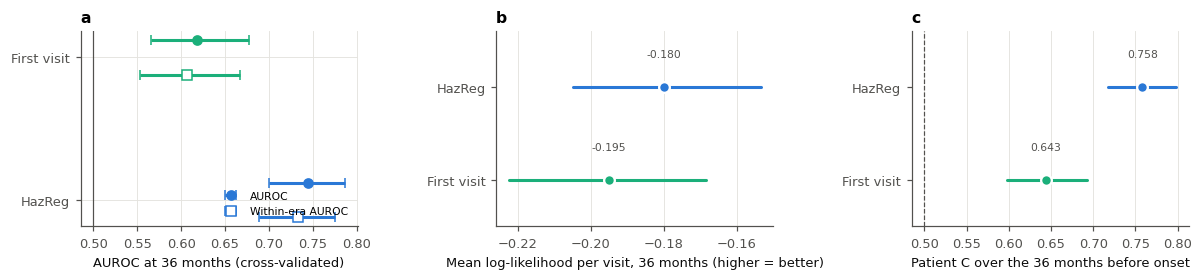

**What this means.**

* **A score computed once at the first employed visit already ranks patients** (AUROC 0.62). How
  a patient's lupus looked when we first saw them working says a good deal about their risk years later.
* **Refreshing the inputs at each visit changes the log score by +0.0151** per visit (95 % CI +0.0086 to
  +0.0212): **H1 is met**. The AUROC changes by +0.126
  (+0.081 to +0.170) and the IPA by +0.0376 (+0.0096 to +0.0620).
  The current visit carries information the first visit lacks.

**At the patient level** the current visit changes the time-matched patient C by +0.115 (+0.075 to
+0.154): 0.64 → 0.76. HazReg's alarm caught
64 % of patients in the 36 months before their onset, and left
75 % of patients who kept working unflagged over the same months.

Most of the ranking is already there at the first employed visit, so risk of work disability in SLE behaves largely as
a **stable trait of the patient** that becomes visible early. That supports using the tool to *stratify* patients, so
that clinicians know whom to watch, rather than to sound an alarm just before someone leaves work.

In [38]:
"""The ladder: every input at the first employed visit -> every input at the current visit (HazReg)."""
LADDER = ["First visit", "HazReg"]
display(metrics_table(LADDER))
STEPS = pd.DataFrame({
    "H1  HazReg − First visit": {k: fmt(paired("HazReg", "First visit", k), 4 if k in ("Log score", "IPA") else 3)
                                 for k in ["Log score", "IPA", "AUROC", "Within-era AUROC"]},
}).T
display(STEPS)
record("H1", "The current visit predicts better than the first employed visit (all inputs in both)",
       "Log score (mean log-likelihood per visit), HazReg − First visit", paired("HazReg", "First visit", "Log score"),
       "above0", nd=4)
HYP["H1"]["Also"] = (f"IPA {fmt(paired('HazReg', 'First visit', 'IPA'), 4)}; "
                     f"AUROC {fmt(paired('HazReg', 'First visit'))}")

# ---- the same ladder at the patient level (time-matched patient C; the alarm's sensitivity and specificity)
display(pt_table(LADDER))
PT_STEPS = pd.DataFrame({
    "H1  HazReg − First visit": {k: fmt(ppaired("HazReg", "First visit", k)) for k in ["C", "Sensitivity", "Specificity"]},
}).T.rename(columns={"C": "Patient C"})
display(PT_STEPS)
record_pt("H1", ppaired("HazReg", "First visit"))

fig, axes = plt.subplots(1, 3, figsize=(13, 2.3), gridspec_kw={"wspace": 0.5})
ax = axes[0]
for i, n in enumerate(LADDER[::-1]):
    for j, k in enumerate(["AUROC", "Within-era AUROC"]):
        e, lo, hi = CV_RES[n][k]
        ax.errorbar([e], [i + (0.12 if j == 0 else -0.12)], xerr=[[e - lo], [hi - e]], fmt="o" if j == 0 else "s",
                    color=MODEL_COLORS[n], mfc=MODEL_COLORS[n] if j == 0 else "white", ms=6, capsize=3,
                    label=k if i == 0 else None)
ax.axvline(0.5, color=INK_2, lw=0.8)
ax.set_yticks(range(len(LADDER)), LADDER[::-1]); ax.set_xlabel("AUROC at 36 months (cross-validated)")
ax.set_title("a  Visit level: ranking", loc="left"); ax.legend(loc="lower right", fontsize=7)
_ci_panel(axes[1], [(n, CV_RES[n]["Log score"], MODEL_COLORS[n]) for n in LADDER[::-1]], "b  Visit level: log score (H1)",
          xlabel="Mean log-likelihood per visit, 36 months (higher = better)")
_ci_panel(axes[2], [(n, PT_RES[n]["C"], MODEL_COLORS[n]) for n in LADDER[::-1]], "c  Patient level (time-matched C)",
          ref=0.5, xlabel="Patient C over the 36 months before onset")
save_fig("fig02_ladder")
_a = {n: CV_RES[n]["AUROC"][0] for n in LADDER}
_s2, _i2, _l2 = paired("HazReg", "First visit"), paired("HazReg", "First visit", "IPA"), paired("HazReg", "First visit", "Log score")
_ps2 = ppaired("HazReg", "First visit")
say(f"""
**What this means.**

* **A score computed once at the first employed visit already ranks patients** (AUROC {_a['First visit']:.2f}). How
  a patient's lupus looked when we first saw them working says a good deal about their risk years later.
* **Refreshing the inputs at each visit changes the log score by {_l2[0]:+.4f}** per visit (95 % CI {_l2[1]:+.4f} to
  {_l2[2]:+.4f}): **H1 is {"met" if HYP['H1']['_met'] else "not met"}**. The AUROC changes by {_s2[0]:+.3f}
  ({_s2[1]:+.3f} to {_s2[2]:+.3f}) and the IPA by {_i2[0]:+.4f} ({_i2[1]:+.4f} to {_i2[2]:+.4f}).
  {"The current visit carries information the first visit lacks." if _l2[1] > 0 else
  "The gain is not distinguishable from zero: a score computed once would serve about as well."}

**At the patient level** the current visit changes the time-matched patient C by {_ps2[0]:+.3f} ({_ps2[1]:+.3f} to
{_ps2[2]:+.3f}): {PT_RES['First visit']['C'][0]:.2f} → {PT_RES['HazReg']['C'][0]:.2f}. HazReg's alarm caught
{100 * PT_RES['HazReg']['Sensitivity'][0]:.0f} % of patients in the 36 months before their onset, and left
{100 * PT_RES['HazReg']['Specificity'][0]:.0f} % of patients who kept working unflagged over the same months.

Most of the ranking is already there at the first employed visit, so risk of work disability in SLE behaves largely as
a **stable trait of the patient** that becomes visible early. That supports using the tool to *stratify* patients, so
that clinicians know whom to watch, rather than to sound an alarm just before someone leaves work.
""")

## 3.2 Does a different kind of model do better?

> **The question.** Would a logistic regression, a deep-learning model that reads the whole 6-month grid of the
> patient's record, or gradient-boosted trees on the landmark's own 6-month cell rank patients better than HazReg?

| Model | How it differs from HazReg |
|:--|:--|
| **LogReg** | The 36-month yes / no outcome, censoring-weighted, same inputs and splines |
| **LSTM** | Reads the whole 6-month grid since the first clinic visit (cell means of every input, visits per cell, empty cells), outputs the same two hazards (Section 3.5 varies how much of the grid it reads) |
| **LightGBM** | Boosted trees (depth ≤ 3) on the landmark's own 6-month cell; two Poisson hazard models on the same stacked person-time, so interactions and non-linear effects are free to emerge |

**H4a and H4b are answered by estimation.** There is no accepted margin below which two risk models count as
equivalent, so none is imposed: each difference is reported with the smallest margin that holds its 95 % CI, and
Section 8.1 shows the verdict at margins of 0.01, 0.02, 0.03 and 0.05 AUROC.

**The figure.** Every model's overall performance, cross-validated: the visit-level measures in the left column and
the patient-level measures of the flag in the right column. Each row is one measure, and each line within it one model
(point estimate and 95 % CI). The paired differences from HazReg are given below the figure.

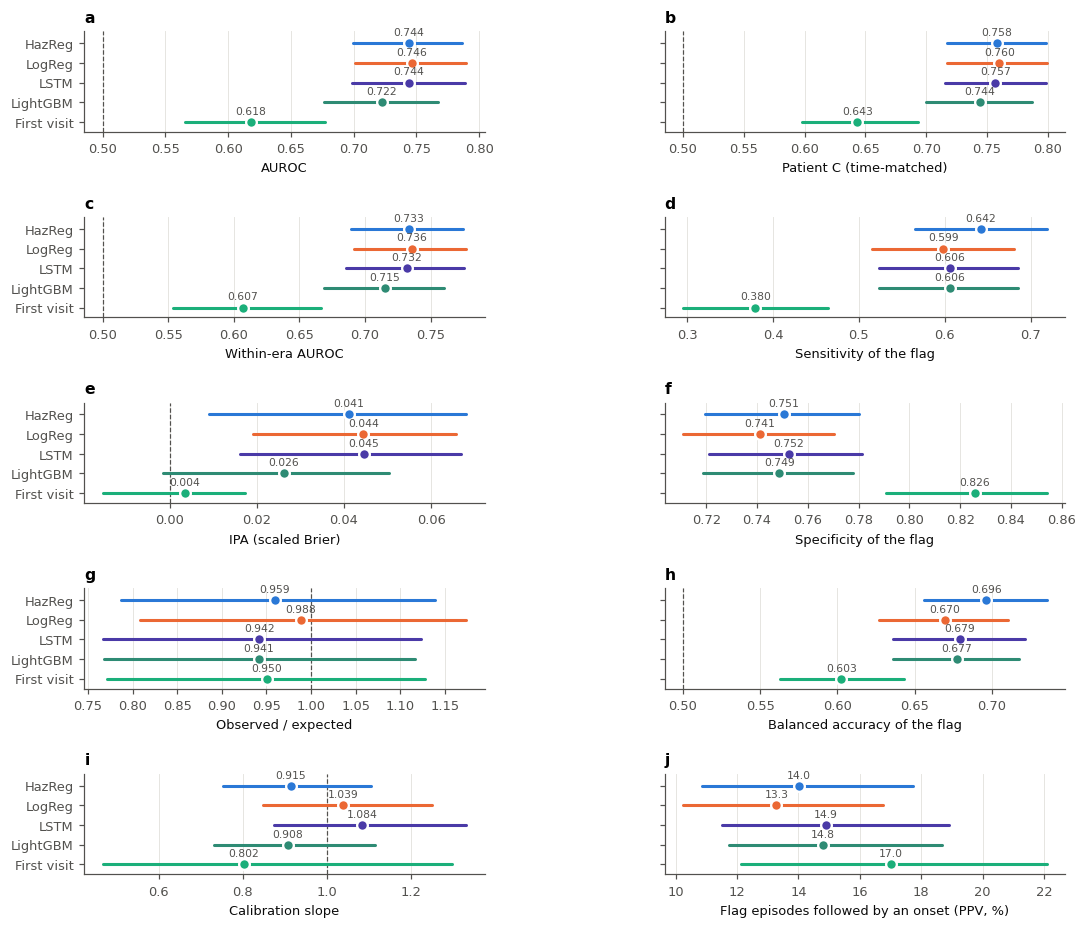

Rank correlation of the cross-validated risks: HazReg-LogReg 0.99, HazReg-LSTM 0.96, HazReg-LightGBM 0.84; LightGBM used a median of 459 trees for onset. LSTM training stopped after a median of 21 epochs (range 18-27).


**What this means.**

* **LogReg vs HazReg: +0.002** (95 % CI -0.004 to +0.007); no difference shown; the difference lies within ± 0.007. The two models
  produce nearly the same ranking (rank correlation 0.99). The hazard formulation is
  chosen for its handling of competing exits and partial follow-up, not for better ranking. That matters most over
  calendar time (Section 4.1).
* **LSTM vs HazReg: -0.000** (95 % CI -0.011 to +0.011); no difference shown; the difference lies within ± 0.011. Reading the whole
  6-month grid of the record flexibly does not find signal the current inputs miss.
* **LightGBM vs HazReg: -0.022** (95 % CI -0.047 to +0.002); no difference shown; the difference lies within ± 0.047. Free interactions
  and non-linear effects on the last 6-month cell add nothing to the additive hazard model.
* **At the patient level:** LogReg − HazReg +0.002 (-0.006 to +0.010; no difference shown; the difference lies within ± 0.010); LSTM −
  HazReg -0.001 (-0.013 to +0.010; no difference shown; the difference lies within ± 0.013); LightGBM − HazReg -0.014
  (-0.038 to +0.009; no difference shown; the difference lies within ± 0.038) in time-matched patient C. Neither comparator
  ranks patients better than HazReg. Because each model's risks have a
  different spread, the same alarm rule flags different numbers of patients: sensitivity
  HazReg 64 %, LogReg 60 %, LSTM 61 %, LightGBM 61 %; specificity
  HazReg 75 %, LogReg 74 %, LSTM 75 %, LightGBM 75 %. At a fixed rule these partly reflect
  the level of risk each model assigns, not only its ranking; the patient C compares ranking alone.

In [39]:
"""HazReg against LogReg, the LSTM and LightGBM (same splits, paired)."""
COMPARE = ["HazReg", "LogReg", "LSTM", "LightGBM"]
_ALT = COMPARE[1:]
save_table(metrics_table(COMPARE), "model_comparison_metrics")
CMP = pd.DataFrame({f"{n} − HazReg": {k: fmt(paired(n, "HazReg", k)) for k in ["AUROC", "Within-era AUROC", "IPA"]}
                    for n in _ALT}).T
save_table(CMP, "model_comparison_differences")


PT_CMP = pt_table(COMPARE)
save_table(PT_CMP, "model_comparison_patient")
# ---- every model's overall performance as a forest plot: visit level (left), patient level (right); one metric per
# row, one line (95 % CI) per model within it
FOREST_MODELS = COMPARE + ["First visit"]
_VISIT_M = [("AUROC", "AUROC", 0.5), ("Within-era AUROC", "Within-era AUROC", 0.5), ("IPA", "IPA (scaled Brier)", 0.0),
            ("O/E", "Observed / expected", 1.0), ("Calibration slope", "Calibration slope", 1.0)]
_PT_M = [("C", "Patient C (time-matched)", 0.5), ("Sensitivity", "Sensitivity of the flag", None),
         ("Specificity", "Specificity of the flag", None), ("Balanced accuracy", "Balanced accuracy of the flag", 0.5),
         ("Episode PPV (%)", "Flag episodes followed by an onset (PPV, %)", None)]
fig, axes = plt.subplots(len(_VISIT_M), 2, figsize=(11.5, 1.05 * len(_VISIT_M) * len(FOREST_MODELS) / 3 + 1.2),
                         gridspec_kw={"wspace": 0.45, "hspace": 0.85})
for col, (mets, res) in enumerate([(_VISIT_M, CV_RES), (_PT_M, PT_RES)]):
    for row, (k, lab, ref) in enumerate(mets):
        ax = axes[row, col]
        _ci_panel(ax, [(n, res[n][k], MODEL_COLORS[n]) for n in FOREST_MODELS],
                  f"{'abcdefghij'[2 * row + col]}  {lab}", ref=ref, xlabel=lab, nd=1 if k.endswith("(%)") else 3)
        if col == 1:
            ax.set_yticklabels([])
save_fig("model_comparison")
MODEL_FOREST = pd.DataFrame({n: {**{f"Visit: {lab}": fmt(CV_RES[n][k], 3) for k, lab, _ in _VISIT_M},
                                 **{f"Patient: {lab}": fmt(PT_RES[n][k], 1 if k.endswith("(%)") else 3) for k, lab, _ in _PT_M}}
                             for n in FOREST_MODELS})
save_table(MODEL_FOREST, "model_comparison_forest")
record("H4a", "How different is LogReg from HazReg?", "AUROC, LogReg − HazReg",
       paired("LogReg", "HazReg"), "equiv")
record("H4b", "How different is the LSTM from HazReg?", "AUROC, LSTM − HazReg",
       paired("LSTM", "HazReg"), "equiv")
record_pt("H4a", ppaired("LogReg", "HazReg"), "equiv")
record_pt("H4b", ppaired("LSTM", "HazReg"), "equiv")
record("H4c", "How different is LightGBM from HazReg?", "AUROC, LightGBM − HazReg", paired("LightGBM", "HazReg"), "equiv")
record_pt("H4c", ppaired("LightGBM", "HazReg"), "equiv")
_rho = pd.DataFrame({n: P_CV[n] for n in COMPARE}).corr(method="spearman")
_ep = np.array(STATE["cv_LSTM"]["tuned"])
print(f"Rank correlation of the cross-validated risks: HazReg-LogReg {_rho.loc['HazReg', 'LogReg']:.2f}, "
      f"HazReg-LSTM {_rho.loc['HazReg', 'LSTM']:.2f}, HazReg-LightGBM {_rho.loc['HazReg', 'LightGBM']:.2f}; LightGBM used a median "
      f"of {np.median([t[0] for t in STATE['cv_LightGBM']['tuned']]):.0f} trees for onset. LSTM training stopped after a median of {np.median(_ep):.0f} "
      f"epochs (range {_ep.min()}-{_ep.max()}).")
_dl, _dn = paired("LogReg", "HazReg"), paired("LSTM", "HazReg")
_pl, _pn = ppaired("LogReg", "HazReg"), ppaired("LSTM", "HazReg")
_dg, _pg = paired("LightGBM", "HazReg"), ppaired("LightGBM", "HazReg")


def _verdict(d):
    if d[1] > 0:
        return "better than HazReg"
    if d[2] < 0:
        return "worse than HazReg"
    return f"no difference shown; the difference lies within ± {max(abs(d[1]), abs(d[2])):.3f}"


say(f"""
**What this means.**

* **LogReg vs HazReg: {_dl[0]:+.3f}** (95 % CI {_dl[1]:+.3f} to {_dl[2]:+.3f}); {_verdict(_dl)}. The two models
  produce nearly the same ranking (rank correlation {_rho.loc['HazReg', 'LogReg']:.2f}). The hazard formulation is
  chosen for its handling of competing exits and partial follow-up, not for better ranking. That matters most over
  calendar time (Section 4.1).
* **LSTM vs HazReg: {_dn[0]:+.3f}** (95 % CI {_dn[1]:+.3f} to {_dn[2]:+.3f}); {_verdict(_dn)}. Reading the whole
  6-month grid of the record flexibly {"does not find signal the current inputs miss" if _dn[1] <= 0 else "finds signal the current inputs miss"}.
* **LightGBM vs HazReg: {_dg[0]:+.3f}** (95 % CI {_dg[1]:+.3f} to {_dg[2]:+.3f}); {_verdict(_dg)}. Free interactions
  and non-linear effects on the last 6-month cell {"add nothing to the additive hazard model" if _dg[1] <= 0 else "add to the additive hazard model"}.
* **At the patient level:** LogReg − HazReg {_pl[0]:+.3f} ({_pl[1]:+.3f} to {_pl[2]:+.3f}; {_verdict(_pl)}); LSTM −
  HazReg {_pn[0]:+.3f} ({_pn[1]:+.3f} to {_pn[2]:+.3f}; {_verdict(_pn)}); LightGBM − HazReg {_pg[0]:+.3f}
  ({_pg[1]:+.3f} to {_pg[2]:+.3f}; {_verdict(_pg)}) in time-matched patient C. Neither comparator
  ranks patients better than HazReg. Because each model's risks have a
  different spread, the same alarm rule flags different numbers of patients: sensitivity
  {", ".join(f"{n} {100 * PT_RES[n]['Sensitivity'][0]:.0f} %" for n in COMPARE)}; specificity
  {", ".join(f"{n} {100 * PT_RES[n]['Specificity'][0]:.0f} %" for n in COMPARE)}. At a fixed rule these partly reflect
  the level of risk each model assigns, not only its ranking; the patient C compares ranking alone.
""")

## 3.3 Optimism and stability of the final model

The final HazReg is fitted on all patients. Two questions are answered with **200 bootstrap refits** (each a full
rerun of the procedure, tuning included, on a resample of patients):

1. **How optimistic is its apparent performance?** (Harrell's bootstrap) Each refit is scored on its own sample and
   on the original data. The average gap is the optimism.
2. **Would a model built on another sample of this size give this patient the same risk?** (Riley & Collins 2023)
   For each visit, the spread of its 200 bootstrap risks shows how much the prediction depends on the particular
   sample. For a tiered tool, the key figure is how often the bootstrap models put the visit in the same tier.

Final model: 30 terms per exit type; effective number of parameters after penalisation (intercept included) 22.1 for onset and 6.3 for other exits (Riley maximum without penalisation: 13.4). Ridge penalty 0.00333333 / 0.1.


,Apparent,Optimism,Optimism-corrected,Cross-validated
AUROC,0.779,0.027,0.752,0.744
Within-era AUROC,0.771,0.028,0.742,0.733
O/E,0.977,-0.006,0.982,0.959
Brier,0.044,-0.002,0.046,0.045
IPA,0.070,0.028,0.043,0.041
Log score,-0.172,0.008,-0.180,-0.180
Calibration slope,1.065,0.148,0.917,0.915
Calibration intercept,-0.034,-0.000,-0.034,-0.053


,Landmarks,Median MAPE (risk points),Same tier as final model (mean %)
Low,6487,0.005,88.961
Raised,4542,0.013,74.544
High,1947,0.036,76.964


,Patients,Same status in >= 80 % of refits (%),Mean agreement (%)
Ever flagged by the final model,419,71.8,86.0
Never flagged by the final model,539,84.6,92.0


/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/3579492646.py:147: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); save_fig("fig03_instability")
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/3471544493.py:365: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(os.path.join(OUT_DIR, f"{name}.png"), bbox_inches="tight")
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/3471544493.py:366: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(os.path.join(OUT_DIR, f"{name}.pdf"), bbox_inches="tight")


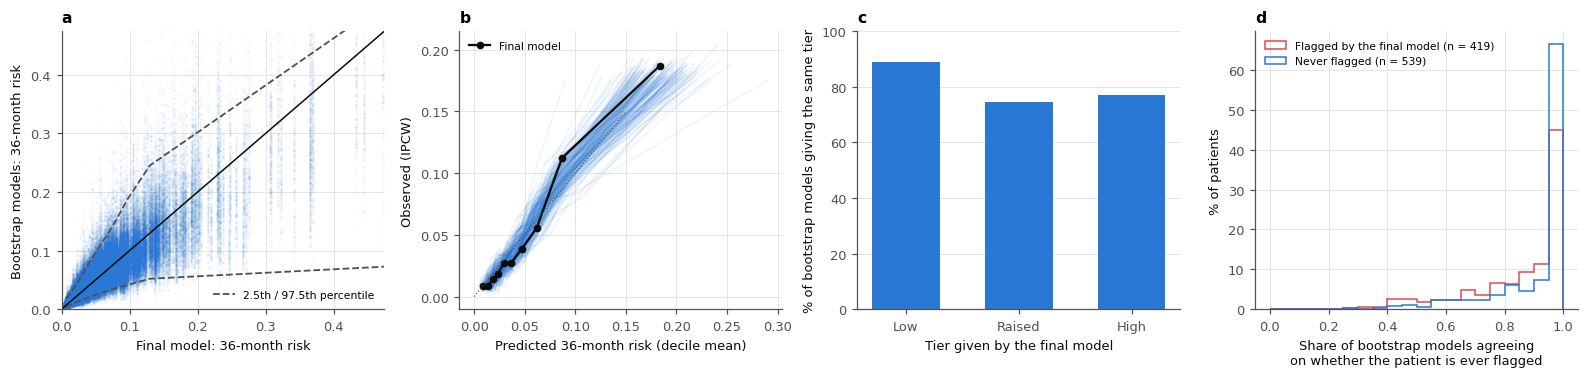

**What this means.**

* **Little optimism.** The apparent AUROC of 0.779 drops only to 0.752
  after correction, matching cross-validation (0.744). The penalty keeps the model honest at
  the population level.
* **Individual risks are less certain than the summary suggests.** On average a landmark's risk moves by
  1.5 percentage points between bootstrap models, against a mean risk of 5.1 %.
  Only 62 % of visits get the same tier in at least 80 % of the bootstrap models.
  Visits near a tier boundary can fall either side of it.

* **The patient alarm is steadier than the visit tier.**
  79 % of patients get the same answer (ever flagged or never flagged) from at least
  80 % of the bootstrap models, against 62 % of visits for the tier; a visit's alarm
  state agrees with the final model in 93 % of refits on average. Among patients flagged
  by the final model 72 % are stable, against 85 % of those never flagged.

In practice: present the tier as a **guide to whom to talk to**, not as a precise number. Report the bottom and top
tiers with most confidence, because tier instability is concentrated in the middle.

In [40]:
"""Final model, 200 bootstrap refits, optimism-corrected performance, instability."""
# the final model's half-life: the one with the lowest inner-CV onset deviance summed over all the cross-validation fits
# (25 x 3 inner folds), not the choice of a single inner CV on the whole data, which is far noisier
HALF_LIFE_DEV = pd.DataFrame(STATE["cv_HazReg"]["h_dev"])
FINAL_HALF_LIFE = float(HALF_LIFE_DEV.sum().idxmin()) if len(HALF_LIFE_DEV.columns) else None
if "final" not in STATE:
    STATE["final"] = fit_procedure(np.arange(N_LAND), seed=SEED, half_life=FINAL_HALF_LIFE)
    _save_state()
FINAL = STATE["final"]
ETA_FULL = predict_eta(FINAL)
P_FULL = cif(ETA_FULL, base=FINAL["base"])
if FINAL.get("half_life"):                             # the inputs are read recency-weighted: label them so
    _hl_txt = f"half-life {FINAL['half_life']:g} months" if np.isfinite(FINAL["half_life"]) else "equal weights"
    DISPLAY["AMS_12M"] = f"SLEDAI-2K, recency-weighted 24-month mean ({_hl_txt})"
    for _c in DECAY_ITEMS:
        if _c != "AMS_12M":
            DISPLAY[_c] = DISPLAY[_c] + " (recency-weighted)"


def effective_df(model, cause, rows=None):
    """Effective number of parameters of a ridge Poisson fit: trace((H + alpha P)^-1 H), H the Fisher information of
    the data term of sklearn's objective (intercept unpenalised, counted as 1)."""
    rows = np.arange(N_LAND) if rows is None else rows
    X = np.column_stack([np.ones(len(rows)), model["prep"].transform(recency_frame(LAND_X.iloc[rows], model.get("half_life")))])
    mu = np.exp(np.clip(X[:, 1:] @ model["coef"][cause] + model["intercept"][cause], -30, 5))
    w = INT_YRS[rows] * mu / INT_YRS[rows].sum()
    Hm = X.T @ (X * w[:, None])
    Pm = np.diag([0.0] + [model["alphas"][cause]] * (X.shape[1] - 1))
    return float(np.trace(np.linalg.solve(Hm + Pm, Hm)))


EFF_DF = [effective_df(FINAL, c) for c in range(2)]
print(f"Final model: {len(FINAL['prep'].names)} terms per exit type; effective number of parameters after "
      f"penalisation (intercept included) {EFF_DF[0]:.1f} for onset and {EFF_DF[1]:.1f} for other exits "
      f"(Riley maximum without penalisation: {RILEY['Max parameters at this n']:.1f}). Ridge penalty "
      f"{FINAL['alphas'][0]:g} / {FINAL['alphas'][1]:g}.")


def _boot_refit(b):
    rng = np.random.RandomState(SEED + 7000 + b)
    draw = rng.randint(0, P_N, P_N)
    mult = np.bincount(draw, minlength=P_N).astype(float)
    rows = np.concatenate([PT_ROWS[ALL_PIDS[i]] for i in draw])
    m = fit_procedure(rows, seed=SEED + 7000 + b)
    eta = predict_eta(m).astype(np.float32)
    return {"eta": eta, "coef": m["coef"], "intercept": m["intercept"], "alphas": m["alphas"], "prep": m["prep"], "base": m["base"],
            "mult": mult.astype(np.float32)}


if "boot" not in STATE or len(STATE["boot"]) < BOOT_REFITS:
    t0 = time.time()
    STATE["boot"] = Parallel(n_jobs=N_JOBS)(delayed(_boot_refit)(b) for b in range(BOOT_REFITS))
    _save_state()
    print(f"{BOOT_REFITS} bootstrap refits ({(time.time() - t0) / 60:.1f} min).")
BOOT = STATE["boot"][:BOOT_REFITS]
P_B = np.vstack([cif(b["eta"].astype(float), base=b["base"]) for b in BOOT])        # (B, n): bootstrap models on the original data


def _point(p, wrow):
    a = {k: v[0] for k, v in metric_arrays(p, wrow[None, :]).items()}
    a["Calibration slope"], a["Calibration intercept"] = wcalibration(Y_IP, p, W_IP * wrow)
    return a


APPARENT = _point(P_FULL, np.ones(N_LAND))
_opt = []
for b, pb in zip(BOOT, P_B):
    app = _point(pb, b["mult"][ROW_PIDX])
    tst = _point(pb, np.ones(N_LAND))
    _opt.append({k: app[k] - tst[k] for k in app})
OPTIMISM = pd.DataFrame(_opt).mean()
OPT_TABLE = pd.DataFrame({"Apparent": pd.Series(APPARENT), "Optimism": OPTIMISM,
                          "Optimism-corrected": pd.Series(APPARENT) - OPTIMISM,
                          "Cross-validated": pd.Series({k: v[0] for k, v in CV_RES["HazReg"].items()})}).round(3)
display(OPT_TABLE)

MAPE = np.abs(P_B - P_FULL[None, :]).mean(0)
TIER_FULL = rel_tier(P_FULL)                                 # each model's relative tiers, against its own risks
TIER_AGREE = (np.vstack([rel_tier(pb) for pb in P_B]) == TIER_FULL[None, :]).mean(0)
INSTAB = pd.DataFrame({"Landmarks": pd.Series(TIER_FULL).value_counts().reindex(range(len(RISK_TIERS))).fillna(0).values,
                       "Median MAPE (risk points)": [np.median(MAPE[TIER_FULL == k]) if (TIER_FULL == k).any() else np.nan
                                                     for k in range(len(RISK_TIERS))],
                       "Same tier as final model (mean %)": [100 * TIER_AGREE[TIER_FULL == k].mean()
                                                             if (TIER_FULL == k).any() else np.nan
                                                             for k in range(len(RISK_TIERS))]},
                      index=[t[2] for t in RISK_TIERS]).round(3)
display(INSTAB)

# ---- the same at the patient level: does a refit on another sample flag the same patients?
FLAGS_FULL = alarm_flags(P_FULL)
FLAGS_B = alarm_flags(P_B)
_pst = np.array([PT_ROWS[p][0] for p in ALL_PIDS])
assert (np.diff(_pst) > 0).all()
EVER_FULL = np.add.reduceat(FLAGS_FULL.astype(int), _pst) > 0
EVER_B = np.add.reduceat(FLAGS_B.astype(int), _pst, axis=1) > 0
PT_AGREE = (EVER_B == EVER_FULL[None, :]).mean(0)
VISIT_FLAG_AGREE = (FLAGS_B == FLAGS_FULL[None, :]).mean(0)
PT_INSTAB = pd.DataFrame({
    "Patients": [int(EVER_FULL.sum()), int((~EVER_FULL).sum())],
    "Same status in >= 80 % of refits (%)": [100 * (PT_AGREE[EVER_FULL] >= 0.8).mean(), 100 * (PT_AGREE[~EVER_FULL] >= 0.8).mean()],
    "Mean agreement (%)": [100 * PT_AGREE[EVER_FULL].mean(), 100 * PT_AGREE[~EVER_FULL].mean()]},
    index=["Ever flagged by the final model", "Never flagged by the final model"]).round(1)
display(PT_INSTAB)

fig, axes = plt.subplots(1, 4, figsize=(14.5, 3.5))
ax = axes[0]
_s = np.random.RandomState(1).choice(N_LAND, min(1500, N_LAND), replace=False)
ax.scatter(np.repeat(P_FULL[_s], len(P_B)), P_B[:, _s].T.ravel(), s=2, color=C1, alpha=0.05, linewidths=0)
_qbins = np.quantile(P_FULL, np.linspace(0, 1, 21))
_bc = 0.5 * (_qbins[1:] + _qbins[:-1])
_qs = np.array([np.percentile(P_B[:, (P_FULL >= a) & (P_FULL <= b_)], [2.5, 97.5]) for a, b_ in zip(_qbins[:-1], _qbins[1:])])
ax.plot(_bc, _qs[:, 0], "--", color=INK_2, lw=1.2); ax.plot(_bc, _qs[:, 1], "--", color=INK_2, lw=1.2,
                                                            label="2.5th / 97.5th percentile")
lim = np.percentile(P_FULL, 99.5) * 1.3
ax.plot([0, lim], [0, lim], color=INK, lw=1); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Final model: 36-month risk"); ax.set_ylabel("Bootstrap models: 36-month risk")
ax.set_title("a  Prediction instability", loc="left"); ax.legend(fontsize=7)
ax = axes[1]


def _cal_points(p):
    dec = pd.qcut(p, 10, labels=False, duplicates="drop")
    o = np.array([np.sum((W_IP * Y_IP)[dec == k]) / (dec == k).sum() for k in range(dec.max() + 1)])
    e = np.array([p[dec == k].mean() for k in range(dec.max() + 1)])
    return e, o


for pb in P_B:
    ax.plot(*_cal_points(pb), color=C1, alpha=0.08, lw=1)
ax.plot(*_cal_points(P_FULL), "o-", color=INK, ms=4, lw=1.5, label="Final model")
ax.plot([0, 0.15], [0, 0.15], color=INK_2, lw=0.8, ls=":")
ax.set_xlabel("Predicted 36-month risk (decile mean)"); ax.set_ylabel("Observed (IPCW)")
ax.set_title("b  Calibration instability", loc="left"); ax.legend(fontsize=7)
ax = axes[2]
ax.bar(np.arange(len(RISK_TIERS)), INSTAB["Same tier as final model (mean %)"], color=C1, width=0.6)
ax.set_xticks(np.arange(len(RISK_TIERS)), INSTAB.index); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
ax.set_xlabel("Tier given by the final model"); ax.set_ylabel("% of bootstrap models giving the same tier")
ax.set_title("c  Tier instability", loc="left")
ax = axes[3]
_hb = np.linspace(0, 1, 21)
for flag, col, nm in [(True, LEFT_C, "Flagged by the final model"), (False, KEPT_C, "Never flagged")]:
    k = EVER_FULL == flag
    ax.hist(PT_AGREE[k], bins=_hb, weights=np.full(k.sum(), 100 / max(k.sum(), 1)), histtype="step", lw=2, color=col,
            label=f"{nm} (n = {k.sum():,})")
ax.set_xlabel("Share of bootstrap models agreeing\non whether the patient is ever flagged"); ax.set_ylabel("% of patients")
ax.set_title("d  Patient alarm instability", loc="left"); ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); save_fig("fig03_instability")
_oc = OPT_TABLE.loc["AUROC"]
say(f"""
**What this means.**

* **Little optimism.** The apparent AUROC of {_oc['Apparent']:.3f} drops only to {_oc['Optimism-corrected']:.3f}
  after correction, matching cross-validation ({_oc['Cross-validated']:.3f}). The penalty keeps the model honest at
  the population level.
* **Individual risks are less certain than the summary suggests.** On average a landmark's risk moves by
  {100 * MAPE.mean():.1f} percentage points between bootstrap models, against a mean risk of {100 * P_FULL.mean():.1f} %.
  Only {100 * (TIER_AGREE >= 0.8).mean():.0f} % of visits get the same tier in at least 80 % of the bootstrap models.
  Visits near a tier boundary can fall either side of it.

* **The patient alarm{" is steadier than the visit tier" if (PT_AGREE >= 0.8).mean() > (TIER_AGREE >= 0.8).mean() else " is no steadier than the visit tier"}.**
  {100 * (PT_AGREE >= 0.8).mean():.0f} % of patients get the same answer (ever flagged or never flagged) from at least
  80 % of the bootstrap models, against {100 * (TIER_AGREE >= 0.8).mean():.0f} % of visits for the tier; a visit's alarm
  state agrees with the final model in {100 * VISIT_FLAG_AGREE.mean():.0f} % of refits on average. Among patients flagged
  by the final model {PT_INSTAB.iloc[0, 1]:.0f} % are stable, against {PT_INSTAB.iloc[1, 1]:.0f} % of those never flagged.

In practice: present the tier as a **guide to whom to talk to**, not as a precise number. Report the bottom and top
tiers with most confidence, because tier instability is concentrated in the middle.
""")

## 3.4 What the model has learned

The table gives each input's hazard ratio per standard deviation, with bootstrap intervals and the share of
refits that agree on its direction; the forest plot shows the same for both hazards (work-disability onset in red,
other exits from work in purple). The curves show the four inputs with flexible effects (onset hazard).

> **How to read it.** These are *predictive* associations, shrunk toward no effect by the penalty. They say which
> patients are at higher risk, not what would lower that risk. An input marked by unstable direction (same sign in
> well under 90 % of refits) should not be interpreted on its own.

,Onset HR per SD,95% bootstrap interval,Same sign (%),Competing-exit HR per SD
Term,,,,
SDI damage score,1.28,1.07-1.47,100.00,1.01
Dyspnoea,1.15,1.05-1.21,100.00,1.01
"SLEDAI-2K, 12-month adjusted mean",1.12,1.02-1.27,97.89,1.02
"Fatigue severity scale (form in the past 12 months, else predicted)",1.11,0.91-1.26,92.63,1.00
Clinic visits per year,1.11,0.99-1.21,95.79,1.01
Current smoker,1.11,1.00-1.21,97.89,1.01
Prednisone (mg/day),1.10,1.03-1.20,100.00,1.02
SDI damage score (spline term),1.10,1.00-1.19,95.79,1.01
Age (years) (spline term),1.09,0.98-1.22,89.47,1.02


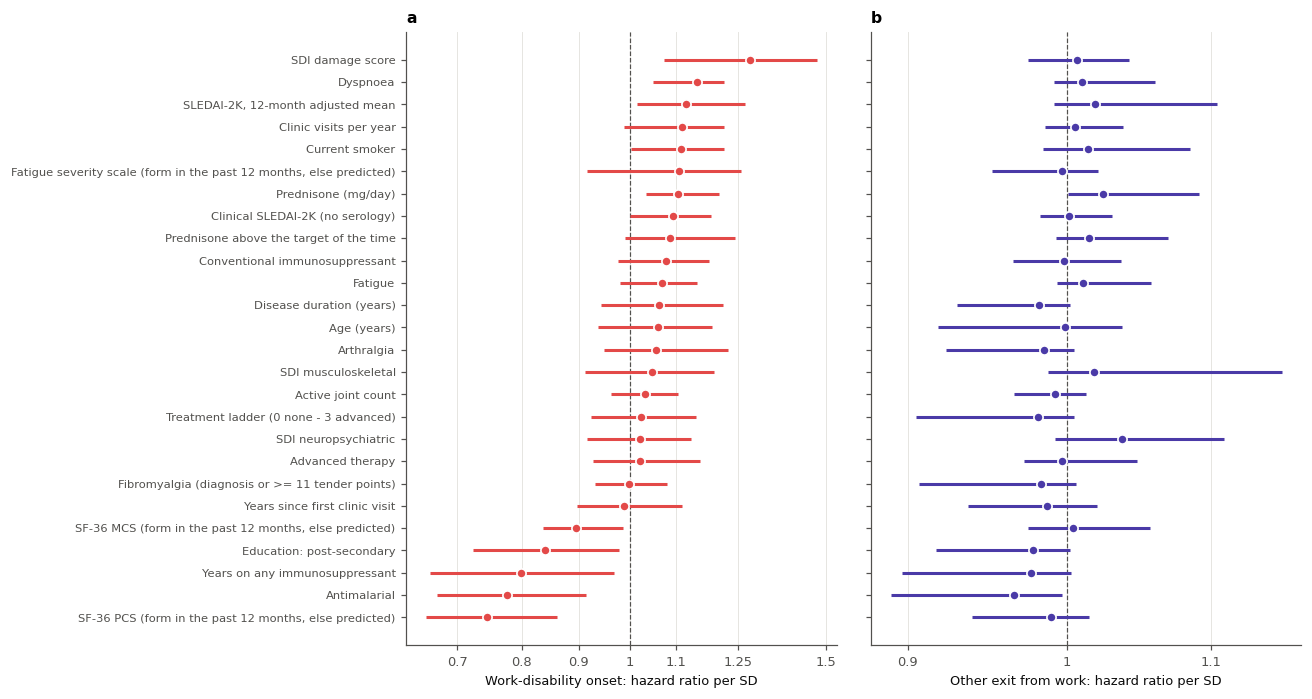

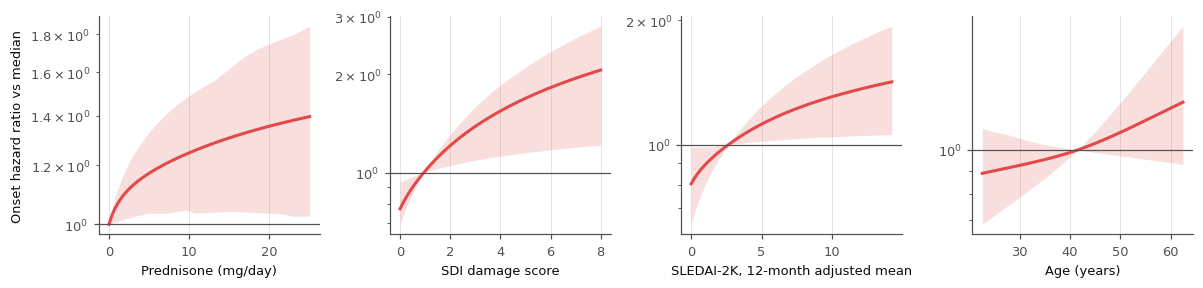

,Flagged: at the first alarm,Never flagged: at the last landmark
Age (years),40.1,40.9
"SLEDAI-2K, 12-mo adjusted mean",8.1,3.1
Prednisone (mg/day),12.8,2.3
SDI damage score,2.0,1.1
Fatigue (%),42.3,6.8
Fibromyalgia (%),22.1,6.0
Treatment ladder (0-3),1.2,1.2
Post-secondary education (%),32.9,54.5
Patients (n),401.0,557.0
Later work disability (%),25.9,6.8


**What this means.** The inputs most consistently linked to **higher** risk are SDI damage score, Dyspnoea, SLEDAI-2K, 12-month adjusted mean, Current smoker. Those most
consistently linked to **lower** risk are SF-36 PCS (form in the past 12 months, else predicted), Antimalarial, Years on any immunosuppressant. The picture is of a patient carrying a heavier disease
and symptom burden (more treatment, more damage, more pain and fatigue), rather than of one isolated marker. Several
of these inputs are defined so that they mean the same in every era: the treatment ladder counts drug classes only,
and fibromyalgia combines the recorded diagnosis with the tender-point count, which is examined less often in recent
years (Section 1.3).

**The patients the alarm picks out.** At their first alarm they were on
12.8 mg/day of prednisone (against
2.3 in never-flagged patients at their last landmark), reported
fatigue at 42 % of visits (against 7 %),
and had an SDI of 2.0 (against 1.1).
26 % of flagged patients later left work for health reasons,
against 7 % of those never flagged.

In [41]:
"""Coefficients of the final model and the spline curves, with bootstrap intervals."""
_names = FINAL["prep"].names
_cb = np.stack([b["coef"] for b in BOOT if b["prep"].names == _names])
COEF = pd.DataFrame({"Term": [DISPLAY.get(n.replace("__NL", "").replace("__MISSING", ""), n) +
                              (" (spline term)" if n.endswith("__NL") else " (missing)" if n.endswith("__MISSING") else "")
                              for n in _names],
                     "Onset HR per SD": np.exp(FINAL["coef"][0]),
                     "95% bootstrap interval": [f"{np.exp(a):.2f}-{np.exp(b_):.2f}" for a, b_ in
                                                np.percentile(_cb[:, 0], [2.5, 97.5], axis=0).T],
                     "Same sign (%)": 100 * (np.sign(_cb[:, 0]) == np.sign(FINAL["coef"][0])[None, :]).mean(0),
                     "Competing-exit HR per SD": np.exp(FINAL["coef"][1])}).round(2)
display(COEF.sort_values("Onset HR per SD", ascending=False).set_index("Term"))
# forest plot of the main effects (the spline terms are shown as curves below): onset (red) and other exits (purple)
_main_t = np.array([not n.endswith(("__NL", "__MISSING")) for n in _names])
_ord = np.argsort(FINAL["coef"][0][_main_t])
_yf = np.arange(_main_t.sum())
fig, axes = plt.subplots(1, 2, figsize=(10.5, 0.24 * _main_t.sum() + 1.0), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, j, col, lab in [(axes[0], 0, LEFT_C, "Work-disability onset: hazard ratio per SD"),
                        (axes[1], 1, OTHER_C, "Other exit from work: hazard ratio per SD")]:
    est = np.exp(FINAL["coef"][j][_main_t])[_ord]
    lo, hi = np.exp(np.percentile(_cb[:, j][:, _main_t], [2.5, 97.5], axis=0))[:, _ord]
    ax.axvline(1, color=INK_2, lw=0.8, ls="--")
    ax.hlines(_yf, lo, hi, color=col, lw=2)
    ax.plot(est, _yf, "o", color=col, ms=6, mec="white", mew=1.1)
    ax.set_xscale("log"); ax.grid(axis="y", visible=False); ax.set_xlabel(lab)
    log_ticks(ax)
    ax.set_title(f"{'ab'[j]}  {lab}", loc="left", fontsize=9)
axes[0].set_yticks(_yf, COEF["Term"].values[_main_t][_ord], fontsize=7.5)
save_fig("fig04a_hazard_ratios")


def _partial(m, c, grid):
    """Log-hazard of onset across `grid` (raw values of input c), other inputs at the training medians."""
    pr = m["prep"]
    X = pd.DataFrame({k: np.full(len(grid), np.nan) for k in pr.cols})
    for k in pr.cols:
        X[k] = np.expm1(pr.med[k]) if k in LOG1P_VARS else pr.med[k]
    X[c] = grid
    eta = predict_eta(m, X=pr.transform(X))[:, 0]
    return eta - eta[np.argmin(np.abs(grid - np.nanmedian(LAND_X[c])))]


fig, axes = plt.subplots(1, len(SPLINE_VARS), figsize=(11, 2.8))
for ax, c in zip(axes, SPLINE_VARS):
    grid = np.linspace(*np.nanpercentile(LAND_X[c], [2, 98]), 60)
    curves = np.array([_partial({"prep": b["prep"], "coef": b["coef"], "intercept": b["intercept"]}, c, grid)
                       for b in BOOT])
    lo, hi = np.percentile(curves, [2.5, 97.5], axis=0)
    ax.fill_between(grid, np.exp(lo), np.exp(hi), color=LEFT_C, alpha=0.18, linewidth=0)
    ax.plot(grid, np.exp(_partial(FINAL, c, grid)), color=LEFT_C)
    ax.axhline(1, color=INK_2, lw=0.8)
    ax.set_yscale("log"); ax.set_xlabel(DISPLAY[c]); ax.set_title(DISPLAY[c], loc="left", fontsize=8.5)
axes[0].set_ylabel("Onset hazard ratio vs median")
plt.tight_layout(); save_fig("fig04_spline_effects")
# ---- at the patient level: what the patients the alarm picks out look like (cross-validated HazReg alarm)
_fl = FLAGS["HazReg"]
_first_flag = pd.Series(np.where(_fl, np.arange(N_LAND), N_LAND)).groupby(PID_ALL).min().reindex(ALL_PIDS).values
_last_lm = np.array([PT_ROWS[p][-1] for p in ALL_PIDS])
_flagged = _first_flag < N_LAND
_prof_rows = np.where(_flagged, np.minimum(_first_flag, N_LAND - 1), _last_lm)
_PROF = [("age_at_record", "Age (years)", 1), ("AMS_12M", "SLEDAI-2K, 12-mo adjusted mean", 1),
         ("STERAVER_0", "Prednisone (mg/day)", 1), ("score_n", "SDI damage score", 1), ("FATIGUE", "Fatigue (%)", 100),
         ("FM_ANY", "Fibromyalgia (%)", 100), ("TREAT_LADDER", "Treatment ladder (0-3)", 1),
         ("EDU_HIGHER", "Post-secondary education (%)", 100)]
FLAG_PROFILE = pd.DataFrame({lab: {"Flagged: at the first alarm": np.nanmean(LAND_X[c].values[_prof_rows[_flagged]]) * sc,
                                   "Never flagged: at the last landmark": np.nanmean(LAND_X[c].values[_prof_rows[~_flagged]]) * sc}
                             for c, lab, sc in _PROF}).T.round(1)
FLAG_PROFILE.loc["Patients (n)"] = [int(_flagged.sum()), int((~_flagged).sum())]
FLAG_PROFILE.loc["Later work disability (%)"] = [100 * PID_EVENT[_flagged].mean(), 100 * PID_EVENT[~_flagged].mean()]
display(FLAG_PROFILE.round(1))

_main = COEF[[not n.endswith(("__NL", "__MISSING")) for n in _names]].copy()
_stable = _main[_main["Same sign (%)"] >= 90]
_up = _stable.sort_values("Onset HR per SD", ascending=False).head(4)["Term"].tolist()
_dn_ = _stable.sort_values("Onset HR per SD").head(3)["Term"].tolist()
say(f"""
**What this means.** The inputs most consistently linked to **higher** risk are {", ".join(_up)}. Those most
consistently linked to **lower** risk are {", ".join(_dn_)}. The picture is of a patient carrying a heavier disease
and symptom burden (more treatment, more damage, more pain and fatigue), rather than of one isolated marker. Several
of these inputs are defined so that they mean the same in every era: the treatment ladder counts drug classes only,
and fibromyalgia combines the recorded diagnosis with the tender-point count, which is examined less often in recent
years (Section 1.3).

**The patients the alarm picks out.** At their first alarm they were on
{FLAG_PROFILE.loc['Prednisone (mg/day)'].iloc[0]:.1f} mg/day of prednisone (against
{FLAG_PROFILE.loc['Prednisone (mg/day)'].iloc[1]:.1f} in never-flagged patients at their last landmark), reported
fatigue at {FLAG_PROFILE.loc['Fatigue (%)'].iloc[0]:.0f} % of visits (against {FLAG_PROFILE.loc['Fatigue (%)'].iloc[1]:.0f} %),
and had an SDI of {FLAG_PROFILE.loc['SDI damage score'].iloc[0]:.1f} (against {FLAG_PROFILE.loc['SDI damage score'].iloc[1]:.1f}).
{FLAG_PROFILE.loc['Later work disability (%)'].iloc[0]:.0f} % of flagged patients later left work for health reasons,
against {FLAG_PROFILE.loc['Later work disability (%)'].iloc[1]:.0f} % of those never flagged.
""")

## 3.5 Does the patient's recent history add to the last visit?

> **The question.** At a landmark, is it enough to know how the patient was at their **last visit**, or does
> reading every visit of the **last 2 years**, with recent visits counting more, or their **whole record** since
> the first clinic visit, rank them better?

**How HazReg reads the last 2 years.** Each input that changes from visit to visit (SLEDAI-2K, prednisone and
prednisone above target, fatigue, fibromyalgia, arthralgia, dyspnoea, active joint count, the treatment ladder and
the three treatment classes) enters as its **recency-weighted mean** over the clinic visits of the 24 months before
the landmark: a visit's value holds until the next visit, and each stretch of time is weighted by ½ per *half-life*
of its age (the exponentially weighted moving average of EHR risk scores, and a parametric form of the weighted
cumulative exposure of pharmacoepidemiology). For SLEDAI-2K this replaces the 12-month adjusted mean. Three inputs
are added: the number of visits in the 24 months, and the change in SDI and in SLEDAI-2K from the first visit of
the window to the last. **The half-life is tuned** with the penalties by the inner cross-validation, from 0 (the
last visit's values alone, as in a model without history), 3, 6 and 12 months, and ∞ (all 24 months weighted
equally). The number of inputs does not grow with the number of visits read, so the sample-size budget of Section
2.4 is unchanged except for the three added inputs. Age, disease duration, years in clinic, SDI and education are
read as they are: they are cumulative or fixed.

The same question is asked of both model families, so that a null result cannot be blamed on one way of reading
history:

| | **Last visit** | **Last 2 years** | **Whole record** |
|:--|:--|:--|:--|
| **Regression** (hazard model) | HazReg with the half-life fixed at 0 | **HazReg** (recency-weighted, half-life tuned): the reported model | HazReg at half-life 0 + summaries of the whole record (mean and change of nine inputs, visits per year) |
| **LSTM** (reads visits in order) | The landmark visit alone | Every clinic visit in the 2 years before the landmark | Every clinic visit since the first (the LSTM of Section 3.2) |

**Prednisone as a weighted cumulative exposure** (Sylvestre & Abrahamowicz, *Stat Med* 2009). Instead of assuming
an exponential weight, the weight of a dose taken *u* months before the landmark is *learned*: prednisone enters as
four terms, the dose history over the 24 months integrated against a cubic B-spline basis in *u*, and the fitted
coefficients trace the weight function. It replaces the prednisone input of HazReg (at HazReg's half-life for the
other inputs) and is compared with HazReg.

| | Hypothesis | What is compared | Met if |
|:--|:--|:--|:--|
| H7a | How much do the last 2 years, recency-weighted, add to the last visit? | AUROC, HazReg − HazReg at half-life 0 | Estimated: the smallest margin holding the CI |
| H7b | How much does the whole record add to the last visit? | AUROC, HazReg at half-life 0 + whole-record history − HazReg at half-life 0 | Estimated: the smallest margin holding the CI |

Both are answered by **estimation**: the difference is reported with the smallest margin that holds its 95 % CI
(and against a grid of margins in Section 8.1), so that "history does not help" is supported by how small the gain
can be, not only by the absence of a significant one.

,Folds choosing it (%),"Inner-CV onset deviance, summed over all fits − best"
0 months,36.0,0.0
∞ (equal weights),24.0,9.8
12 months,20.0,11.0
3 months,16.0,24.8
6 months,4.0,18.9
Final model: 0 months,NaN,NaN


,Regression: Last visit,"Regression: Last 2 years, recency-weighted",Regression: Whole record,"LSTM: Last visit, recency-weighted",LSTM: Last 6-month cell,LSTM: Last two cells (12 months),LSTM: Whole 6-month grid
AUROC,0.744 (0.701 to 0.788),0.744 (0.700 to 0.786),0.732 (0.689 to 0.777),0.739 (0.693 to 0.783),0.737 (0.691 to 0.781),0.738 (0.691 to 0.782),0.744 (0.698 to 0.788)
Within-era AUROC,0.734 (0.690 to 0.774),0.733 (0.689 to 0.775),0.723 (0.680 to 0.767),0.728 (0.682 to 0.771),0.725 (0.680 to 0.768),0.726 (0.680 to 0.770),0.732 (0.685 to 0.776)
IPA,0.042 (0.011 to 0.068),0.041 (0.009 to 0.068),0.039 (0.007 to 0.067),0.041 (0.014 to 0.062),0.042 (0.016 to 0.064),0.044 (0.015 to 0.066),0.045 (0.016 to 0.067)
O/E,0.960 (0.786 to 1.139),0.959 (0.787 to 1.139),0.942 (0.771 to 1.119),0.942 (0.768 to 1.120),0.947 (0.775 to 1.127),0.946 (0.772 to 1.125),0.942 (0.766 to 1.123)
Calibration slope,0.916 (0.757 to 1.113),0.915 (0.752 to 1.105),0.901 (0.717 to 1.100),1.024 (0.833 to 1.244),1.035 (0.838 to 1.254),1.036 (0.830 to 1.258),1.084 (0.875 to 1.333)
Calibration intercept,-0.052 (-0.280 to 0.149),-0.053 (-0.280 to 0.149),-0.076 (-0.307 to 0.125),-0.071 (-0.301 to 0.124),-0.068 (-0.294 to 0.133),-0.069 (-0.296 to 0.133),-0.075 (-0.301 to 0.120)
Patient C (time-matched),0.762 (0.720 to 0.801),0.758 (0.717 to 0.798),0.748 (0.706 to 0.788),0.755 (0.712 to 0.794),0.752 (0.708 to 0.793),0.752 (0.709 to 0.793),0.757 (0.716 to 0.798)
Sensitivity,0.63 (0.54 to 0.71),0.64 (0.57 to 0.72),0.61 (0.52 to 0.68),0.61 (0.53 to 0.69),0.59 (0.51 to 0.67),0.60 (0.51 to 0.68),0.61 (0.52 to 0.69)
Specificity,0.73 (0.70 to 0.76),0.75 (0.72 to 0.78),0.74 (0.71 to 0.77),0.74 (0.70 to 0.77),0.74 (0.70 to 0.77),0.74 (0.71 to 0.77),0.75 (0.72 to 0.78)
Balanced accuracy,0.68 (0.64 to 0.72),0.70 (0.66 to 0.74),0.67 (0.63 to 0.72),0.68 (0.63 to 0.72),0.66 (0.62 to 0.70),0.67 (0.63 to 0.71),0.68 (0.64 to 0.72)


,Visit AUROC,Within-era AUROC,Patient C,Alarm sensitivity,Alarm specificity
"Regression: Last 2 years, recency-weighted − last visit",-0.000 (-0.005 to 0.005),-0.001 (-0.006 to 0.005),-0.004 (-0.011 to 0.003),0.01 (-0.03 to 0.06),0.02 (0.01 to 0.03)
Regression: Whole record − last visit,-0.012 (-0.026 to 0.003),-0.011 (-0.026 to 0.004),-0.014 (-0.028 to 0.001),-0.02 (-0.08 to 0.04),0.01 (-0.01 to 0.02)
"LSTM: Last 6-month cell − last visit, recency-weighted",-0.003 (-0.008 to 0.003),-0.003 (-0.009 to 0.003),-0.003 (-0.012 to 0.007),-0.02 (-0.06 to 0.01),-0.00 (-0.01 to 0.01)
"LSTM: Last two cells (12 months) − last visit, recency-weighted",-0.002 (-0.008 to 0.004),-0.002 (-0.008 to 0.005),-0.003 (-0.012 to 0.007),-0.01 (-0.05 to 0.02),0.00 (-0.01 to 0.01)
"LSTM: Whole 6-month grid − last visit, recency-weighted",0.005 (-0.004 to 0.013),0.004 (-0.005 to 0.013),0.002 (-0.009 to 0.016),-0.01 (-0.05 to 0.03),0.02 (0.00 to 0.03)


Parameters per exit type: HazReg at half-life 0 30 (+ 3 at a half-life > 0), + whole-record history 49. Median clinic visits read per landmark: 5 in the last 2 years; the whole grid has a median 17 cells per patient up to their last landmark.


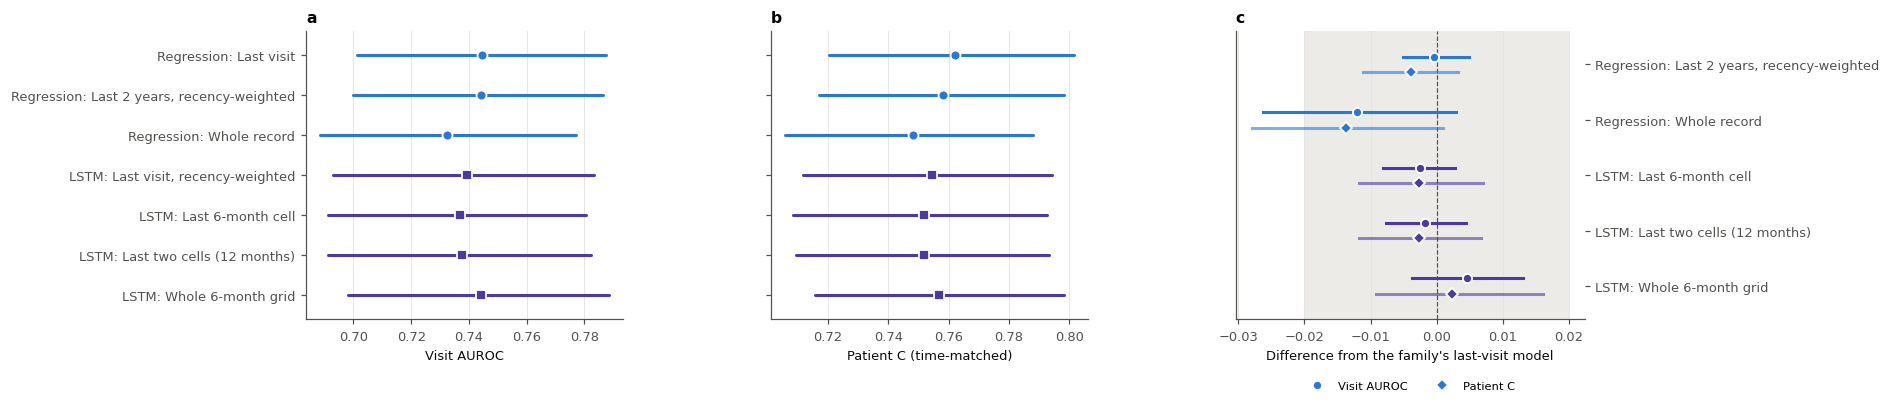

**What this means.**

* **Half-life.** The inner cross-validation of each fold chose a half-life of 0 months in 36 % of folds, ∞ (equal weights) in 24 % of folds, 12 months in 20 % of folds, 3 months in 16 % of folds, 6 months in 4 % of folds.
  The final model uses the half-life with the lowest inner-CV onset deviance summed over all 25 fits,
  0 months, so that the reported model follows the bulk of the evidence rather than
  the single inner cross-validation run on the whole data.
* **Regression family.** Reading the last 2 years with recency weights changes the AUROC by -0.000
  (-0.005 to +0.005; no clear difference) and the log score by -0.0002 (-0.0011 to 0.0008) against the last visit alone;
  the whole record changes the AUROC by -0.012 (-0.026 to +0.003; no clear difference). At the
  patient level the changes are -0.004 and -0.014 in time-matched C.
* **LSTM family.** Against the LSTM that reads the landmark's own recency-weighted inputs (the inputs of HazReg),
  reading the last 6-month cell changes the visit AUROC by -0.003 (-0.008 to 0.003), the last two cells by -0.002 (-0.008 to 0.004), and the
  whole 6-month grid since the first clinic visit by 0.005 (-0.004 to 0.013).
* **Neither family finds information in the history that the last visit lacks**, at the visit or at the patient level. That is what a stable trait predicts: damage, treatment and symptom burden accumulate and are carried into the last visit.

In [42]:
"""Last visit vs recency-weighted last 2 years vs whole record, in the regression and LSTM families (same splits, paired)."""
WCE_COLS = [f"PRED_WCE_{k + 1}" for k in range(WCE_DF)]
for c in WCE_COLS:
    LOG1P_VARS.discard(c)
WCE_INPUTS = [c for c in COMPACT_VARS if c != "STERAVER_0"] + WCE_COLS
HIST_MODELS = {  # name: (kind, inputs, spline terms, LSTM history, half-life)
    "HazReg, last visit": ("haz", COMPACT_VARS, SPLINE_VARS, None, 0.0),
    "HazReg + whole-record history": ("haz", COMPACT_VARS + HIST_VARS["ALL"], SPLINE_VARS, None, 0.0),
    "HazReg, prednisone WCE": ("haz", WCE_INPUTS, [c for c in SPLINE_VARS if c != "STERAVER_0"], None,
                               FINAL.get("half_life")),
    "LSTM, last visit (recency-weighted)": ("lstm", None, (), "visit", FINAL.get("half_life")),
    "LSTM, last 6-month cell": ("lstm", None, (), 1, None),
    "LSTM, last two 6-month cells": ("lstm", None, (), 2, None),
}
for name, (kind, cols, spline, win, hl) in HIST_MODELS.items():
    if f"cv_{name}" not in STATE:
        t0 = time.time()
        STATE[f"cv_{name}"] = run_cv(kind, cols, spline, window=win, half_life=hl)
        _save_state()
        print(f"{name}: cross-validated in {(time.time() - t0) / 60:.1f} min")
for name in HIST_MODELS:
    P_CV[name] = cv_risk(name)
    CV_RES[name], CV_ARR[name] = summarise(P_CV[name], p_abs=P_ABS.get(name))
    FLAGS[name] = alarm_flags(P_CV[name])
    PT_RES[name], PT_ARR[name] = pt_summary(PT_EVAL, P_CV[name], FLAGS[name])
_hl_folds = pd.Series([t[2] for t in STATE["cv_HazReg"]["tuned"]]).map(lambda h: f"{h:g} months" if np.isfinite(h) else "∞ (equal weights)")
_hl_lab = lambda h: f"{h:g} months" if np.isfinite(h) else "∞ (equal weights)"
HALF_LIFE_CHOSEN = (100 * _hl_folds.value_counts(normalize=True)).round(0).to_frame("Folds choosing it (%)")
HALF_LIFE_CHOSEN["Inner-CV onset deviance, summed over all fits − best"] = (HALF_LIFE_DEV.sum() - HALF_LIFE_DEV.sum().min()).rename(_hl_lab).round(1)
HALF_LIFE_CHOSEN = HALF_LIFE_CHOSEN.fillna({"Folds choosing it (%)": 0})
HALF_LIFE_CHOSEN.loc[f"Final model: {_hl_lab(FINAL['half_life'])}"] = np.nan
display(HALF_LIFE_CHOSEN)
save_table(HALF_LIFE_CHOSEN, "recency_half_life")

HIST_GRID = {"Regression": ["HazReg, last visit", "HazReg", "HazReg + whole-record history"],
             "LSTM": ["LSTM, last visit (recency-weighted)", "LSTM, last 6-month cell", "LSTM, last two 6-month cells", "LSTM"]}
WINDOW_NAMES = {"Regression": ["Last visit", "Last 2 years, recency-weighted", "Whole record"],
                "LSTM": ["Last visit, recency-weighted", "Last 6-month cell", "Last two cells (12 months)", "Whole 6-month grid"]}
_hist_lab = {n: f"{fam}: {w}" for fam, ns in HIST_GRID.items() for n, w in zip(ns, WINDOW_NAMES[fam])}
_allh = [n for ns in HIST_GRID.values() for n in ns]
HIST_TABLE = pd.concat([metrics_table(_allh), pt_table(_allh)]).rename(columns=_hist_lab)
display(HIST_TABLE)
save_table(HIST_TABLE, "history_comparison")
HIST_DIFF = pd.DataFrame({
    f"{fam}: {w} − {WINDOW_NAMES[fam][0].lower()}": {
        "Visit AUROC": fmt(paired(n, ns[0])), "Within-era AUROC": fmt(paired(n, ns[0], "Within-era AUROC")),
        "Patient C": fmt(ppaired(n, ns[0])), "Alarm sensitivity": fmt(ppaired(n, ns[0], "Sensitivity"), 2),
        "Alarm specificity": fmt(ppaired(n, ns[0], "Specificity"), 2)}
    for fam, ns in HIST_GRID.items() for n, w in zip(ns[1:], WINDOW_NAMES[fam][1:])}).T
display(HIST_DIFF)
save_table(HIST_DIFF, "history_differences")
record("H7a", "How much do the last 2 years, recency-weighted, add to the last visit?",
       "AUROC, HazReg − HazReg at half-life 0", paired("HazReg", "HazReg, last visit"), "equiv")
record("H7b", "How much does the whole record add to the last visit?",
       "AUROC, HazReg at half-life 0 + whole-record history − HazReg at half-life 0",
       paired("HazReg + whole-record history", "HazReg, last visit"), "equiv")
record_pt("H7a", ppaired("HazReg", "HazReg, last visit"), "equiv")
record_pt("H7b", ppaired("HazReg + whole-record history", "HazReg, last visit"), "equiv")
_P_h = {t: len(Prep(COMPACT_VARS + HIST_VARS[t], SPLINE_VARS).fit(LAND_X).names) for t in HIST_VARS}
print(f"Parameters per exit type: HazReg at half-life 0 {_P} (+ {len(RECENCY_EXTRAS)} at a half-life > 0), + whole-record history {_P_h['ALL']}. "
      f"Median clinic visits read per landmark: {np.median(LAND_X['VISITS_24M'].fillna(0)):.0f} in the last 2 years; the whole grid "
      f"has a median {np.median([len(GRID_POS[p]) for p in ALL_PIDS]):.0f} cells per patient up to their last landmark.")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), gridspec_kw={"wspace": 0.45, "width_ratios": [1, 1, 1.1]})
_fam_col = {"Regression": C1, "LSTM": C4}
_ylab = [f"{fam}: {w}" for fam in HIST_GRID for w in WINDOW_NAMES[fam]]
for ax, (key, res, ttl) in zip(axes[:2], [("AUROC", CV_RES, "a"), ("C", PT_RES, "b")]):
    y = 0
    for fam, ns in HIST_GRID.items():
        for n in ns:
            e, lo, hi = res[n][key]
            ax.plot([lo, hi], [y, y], color=_fam_col[fam], lw=2, solid_capstyle="round")
            ax.plot(e, y, "o" if fam == "Regression" else "s", color=_fam_col[fam], ms=6.5, mec="white", mew=1.2)
            y += 1
    ax.set_yticks(range(len(_ylab)), _ylab); ax.set_ylim(len(_ylab) - 0.4, -0.6); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Visit AUROC" if key == "AUROC" else "Patient C (time-matched)")
    ax.set_title(ttl, loc="left", fontsize=9)
axes[1].tick_params(labelleft=False)
ax = axes[2]
ax.axvspan(-EQUIV_MARGIN, EQUIV_MARGIN, color=GRID_C, alpha=0.7, lw=0, zorder=0)
ax.axvline(0, color=INK_2, lw=0.8, ls="--")
_items = [(f"{fam}: {w}", n, ns[0], fam) for fam, ns in HIST_GRID.items() for n, w in zip(ns[1:], WINDOW_NAMES[fam][1:])]
for i, (lab, n, ref_, fam) in enumerate(_items):
    for j, (fn, mk) in enumerate([(paired, "o"), (ppaired, "D")]):
        t = fn(n, ref_)
        y = i + (j - 0.5) * 0.28
        ax.plot([t[1], t[2]], [y, y], color=_fam_col[fam], lw=2, alpha=1 if j == 0 else 0.6)
        ax.plot(t[0], y, mk, color=_fam_col[fam], ms=6, mec="white", mew=1.2,
                label=("Visit AUROC" if j == 0 else "Patient C") if i == 0 else None)
ax.set_yticks(range(len(_items)), [it[0] for it in _items]); ax.set_ylim(len(_items) - 0.4, -0.6)
ax.grid(axis="y", visible=False); ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax.yaxis.tick_right()
ax.set_xlabel("Difference from the family's last-visit model")
ax.set_title("c", loc="left", fontsize=9)
save_fig("history_comparison")
_h2, _ha = paired("HazReg", "HazReg, last visit"), paired("HazReg + whole-record history", "HazReg, last visit")
_lv = "LSTM, last visit (recency-weighted)"
_l1, _l2, _la = (paired(n, _lv) for n in ["LSTM, last 6-month cell", "LSTM, last two 6-month cells", "LSTM"])
_p2, _pa = ppaired("HazReg", "HazReg, last visit"), ppaired("HazReg + whole-record history", "HazReg, last visit")
_hl2 = paired("HazReg", "HazReg, last visit", "Log score")
_word = lambda d: "a real gain" if d[1] > 0 else "a loss" if d[2] < 0 else "no clear difference"
if max(_h2[1], _ha[1], _l1[1], _l2[1], _la[1], _p2[1], _pa[1]) <= 0 and _hl2[1] > 0:
    _hist_concl = ("* **The recency-weighted history sizes risk better (log score) without ranking patients better** "
                   "(AUROC and patient C): it sharpens the risk of the patients already ranked high or low rather than "
                   "reordering them. Risk behaves as a stable trait, and the history mostly confirms it.")
elif max(_h2[1], _ha[1], _l1[1], _l2[1], _la[1], _p2[1], _pa[1]) <= 0:
    _hist_concl = ("* **Neither family finds information in the history that the last visit lacks**, at the visit or at "
                   "the patient level. That is what a stable trait predicts: damage, treatment and symptom burden "
                   "accumulate and are carried into the last visit.")
else:
    _hist_concl = ("* **Some history adds information** (an interval above zero in the table above). The gain should be "
                   "weighed against the extra inputs the tool would need, and against the size of the gain relative to "
                   f"the ± {EQUIV_MARGIN} margin used for the model comparison.")
say(f"""
**What this means.**

* **Half-life.** The inner cross-validation of each fold chose a half-life of {", ".join(f"{i} in {v:.0f} % of folds" for i, v in HALF_LIFE_CHOSEN["Folds choosing it (%)"].dropna().items() if v > 0)}.
  The final model uses the half-life with the lowest inner-CV onset deviance summed over all {len(HALF_LIFE_DEV)} fits,
  {HALF_LIFE_CHOSEN.index[-1].split(": ")[1]}, so that the reported model follows the bulk of the evidence rather than
  the single inner cross-validation run on the whole data.
* **Regression family.** Reading the last 2 years with recency weights changes the AUROC by {_h2[0]:+.3f}
  ({_h2[1]:+.3f} to {_h2[2]:+.3f}; {_word(_h2)}) and the log score by {fmt(_hl2, 4)} against the last visit alone;
  the whole record changes the AUROC by {_ha[0]:+.3f} ({_ha[1]:+.3f} to {_ha[2]:+.3f}; {_word(_ha)}). At the
  patient level the changes are {_p2[0]:+.3f} and {_pa[0]:+.3f} in time-matched C.
* **LSTM family.** Against the LSTM that reads the landmark's own recency-weighted inputs (the inputs of HazReg),
  reading the last 6-month cell changes the visit AUROC by {fmt(_l1)}, the last two cells by {fmt(_l2)}, and the
  whole 6-month grid since the first clinic visit by {fmt(_la)}.
{_hist_concl}
""")

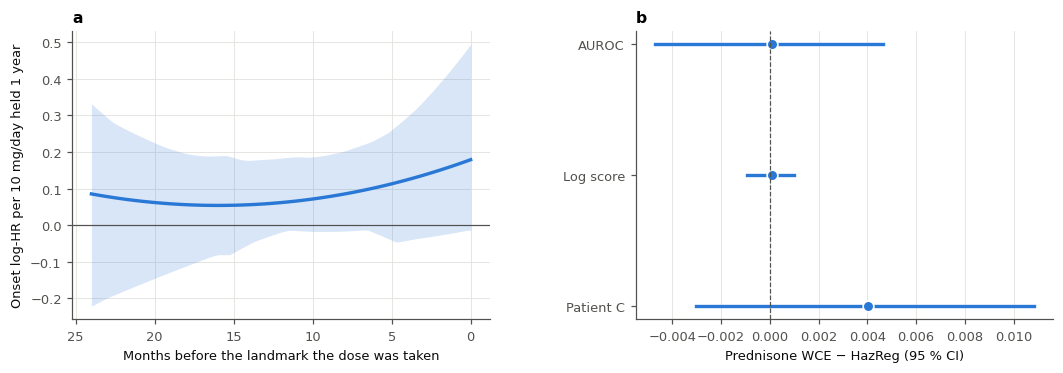

**What this means.** Learned freely, the weight of a prednisone dose falls with its age:
the last 6 months carry 40 % of the total weight over 24 months (an equal weighting would give
25 %). Against HazReg's exponential weighting, the learned weight changes the AUROC by 0.000 (-0.005 to 0.005), the log
score by 0.0001 (-0.0009 to 0.0010) and the patient C by 0.004 (-0.003 to 0.011). The band is wide: with about
588 onsets, a weight function of four terms is estimated loosely, which is why HazReg keeps the
one-parameter exponential weight unless the learned one clearly wins.

In [43]:
"""Prednisone as a weighted cumulative exposure: the learned weight function, and the model against HazReg."""
_wce_n = "HazReg, prednisone WCE"
if "final_wce" not in STATE:
    STATE["final_wce"] = fit_procedure(np.arange(N_LAND), *HIST_MODELS[_wce_n][1:3], half_life=FINAL.get("half_life"), seed=SEED)
    _save_state()
_fw = STATE["final_wce"]
from scipy.interpolate import BSpline as _BS
_kn = np.r_[[0.0] * 3, np.linspace(0, RECENCY_WINDOW_MONTHS, WCE_DF - 2), [float(RECENCY_WINDOW_MONTHS)] * 3]
_lag = np.linspace(0, RECENCY_WINDOW_MONTHS - 1e-6, 97)
_B = np.column_stack([np.nan_to_num(_BS(_kn, np.eye(WCE_DF)[k], 3, extrapolate=False)(_lag)) for k in range(WCE_DF)])
_ix = [_fw["prep"].names.index(c) for c in WCE_COLS]
# coefficient on the raw scale of each basis term: b x block scale / SD (terms are standardised before fitting)
_braw = np.array([_fw["coef"][0][i] * _fw["prep"].scale[i] / _fw["prep"].sd[c] for i, c in zip(_ix, WCE_COLS)])
WCE_WEIGHT = _B @ _braw                                    # log-HR per (mg/day x year) taken u months before
_rng_b = np.random.RandomState(SEED)
_wb = []
for b in range(min(50, BOOT_REFITS)):
    pid_b = _rng_b.choice(ALL_PIDS, len(ALL_PIDS))
    rows_b = np.concatenate([PT_ROWS[p] for p in pid_b])
    mb = fit_procedure(rows_b, *HIST_MODELS[_wce_n][1:3], alphas=_fw["alphas"], seed=SEED + b)
    _wb.append(_B @ np.array([mb["coef"][0][i] * mb["prep"].scale[i] / mb["prep"].sd[c] for i, c in zip(_ix, WCE_COLS)]))
_wlo, _whi = np.percentile(np.array(_wb), [2.5, 97.5], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4), gridspec_kw={"wspace": 0.35})
ax = axes[0]
ax.fill_between(_lag, 10 * _wlo, 10 * _whi, color=C1, alpha=0.18, lw=0)
ax.plot(_lag, 10 * WCE_WEIGHT, color=C1, lw=2.2)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlabel("Months before the landmark the dose was taken"); ax.set_ylabel("Onset log-HR per 10 mg/day held 1 year")
ax.set_title("a  Learned weight of a prednisone dose by its age (bootstrap 95 % band)", loc="left", fontsize=8.5)
ax.invert_xaxis()
ax = axes[1]
_wd = {k: paired(_wce_n, "HazReg", k) for k in ["AUROC", "Log score"]} | {"Patient C": ppaired(_wce_n, "HazReg")}
for i, (k, t) in enumerate(_wd.items()):
    ax.plot([t[1], t[2]], [i, i], color=C1, lw=2.2); ax.plot(t[0], i, "o", color=C1, ms=7, mec="white", mew=1.1)
ax.axvline(0, color=INK_2, lw=0.8, ls="--")
ax.set_yticks(range(len(_wd)), list(_wd)); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("Prednisone WCE − HazReg (95 % CI)")
ax.set_title("b  Does a learned weight beat the exponential one?", loc="left", fontsize=8.5)
save_fig("prednisone_wce")
_trap = getattr(np, "trapezoid", None) or np.trapz
_rec_share = float(_trap(np.abs(WCE_WEIGHT[_lag <= 6]), _lag[_lag <= 6]) / max(_trap(np.abs(WCE_WEIGHT), _lag), 1e-12))
say(f"""
**What this means.** Learned freely, the weight of a prednisone dose {"falls with its age" if WCE_WEIGHT[0] > WCE_WEIGHT[-1] else "does not fall with its age"}:
the last 6 months carry {100 * _rec_share:.0f} % of the total weight over 24 months (an equal weighting would give
25 %). Against HazReg's exponential weighting, the learned weight changes the AUROC by {fmt(_wd['AUROC'])}, the log
score by {fmt(_wd['Log score'], 4)} and the patient C by {fmt(_wd['Patient C'])}. The band is wide: with about
{int(D1.sum())} onsets, a weight function of four terms is estimated loosely, which is why HazReg keeps the
one-parameter exponential weight unless the learned one clearly wins.
""")

## 3.6 Development from 2000 onwards (co-primary analysis)

> **The question.** Does the primary result hold when the model is developed only on visits from 2000 onwards?

Before 2000 several inputs were recorded at only some visits (fibromyalgia at 18 % of visits, dyspnoea at 59 %,
the joint count at 42 %; Section 1.3), and the clinic's first status records in 1995 enter many prevalent patients
at once (Section 1.6). A missing value then partly encodes the era rather than the patient, and an input's
coefficient can pick up the era's outcome rate. Restricting development to 2000 onwards removes both.

**Design.** The same patient splits as Section 3.0. HazReg and the first-visit model are fitted only on the training
patients' landmarks from 2000 onwards. Both these models and the models developed on all years are then evaluated on
the same test landmarks from 2000 onwards, so every comparison is paired.

| | Hypothesis | What is compared | Met if |
|:--|:--|:--|:--|
| **H1-2000** | **The primary result holds when development starts in 2000** | Log score on landmarks from 2000: HazReg 2000+ − First visit 2000+ | CI above 0 |

,HazReg 2000+,First visit 2000+,HazReg,First visit
AUROC,0.725 (0.675 to 0.774),0.590 (0.529 to 0.658),0.728 (0.679 to 0.776),0.602 (0.540 to 0.668)
Within-era AUROC,0.713 (0.662 to 0.762),0.581 (0.521 to 0.648),0.716 (0.664 to 0.763),0.593 (0.531 to 0.659)
IPA,0.034 (0.004 to 0.061),0.003 (-0.012 to 0.015),0.031 (-0.001 to 0.059),-0.000 (-0.023 to 0.015)
O/E,0.956 (0.764 to 1.147),0.952 (0.758 to 1.146),0.957 (0.766 to 1.148),0.916 (0.729 to 1.105)
Calibration slope,0.887 (0.690 to 1.106),0.666 (0.260 to 1.222),0.854 (0.664 to 1.051),0.701 (0.298 to 1.246)
Patient C,0.748 (0.695 to 0.794),0.621 (0.567 to 0.680),0.749 (0.699 to 0.793),0.640 (0.587 to 0.697)
Alarm sensitivity,0.66 (0.57 to 0.75),0.34 (0.25 to 0.43),0.61 (0.51 to 0.69),0.33 (0.25 to 0.42)
Alarm specificity,0.72 (0.69 to 0.75),0.84 (0.80 to 0.87),0.77 (0.73 to 0.80),0.85 (0.82 to 0.88)


HazReg 2000+ − HazReg (all years), AUROC on landmarks from 2000: -0.003 (-0.014 to 0.006); patient C: -0.001 (-0.012 to 0.010)


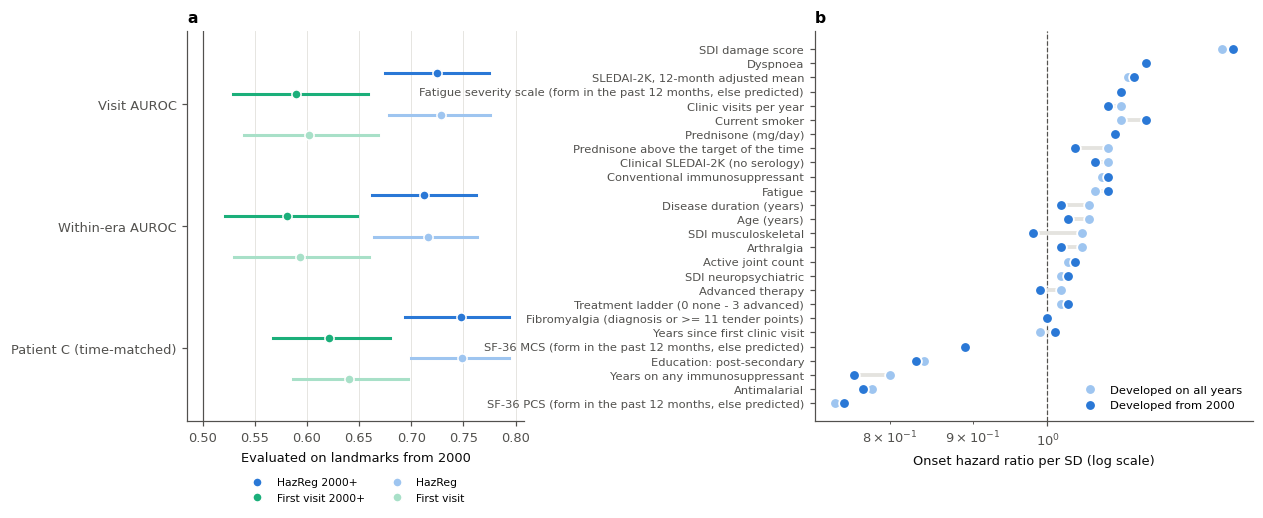

**What this means.**

* **H1-2000 is met.** Developed and evaluated from 2000, HazReg reaches
  an IPA of 0.0344 and an AUROC of 0.725, against
  0.0025 and 0.590 for the first-visit
  model: a log-score difference of 0.0134 (0.0068 to 0.0199) per visit (IPA 0.0319 (0.0052 to 0.0557); AUROC 0.135 (0.078 to 0.186)). At the patient level the difference in
  patient C is 0.127 (0.081 to 0.172).
* **Dropping the years before 2000 changes the ranking by -0.003** (-0.014 to +0.006) against the
  model developed on all years, evaluated on the same landmarks. The two are equivalent within ± 0.02.
* **What moves.** The largest changes in an input's effect are sdi musculoskeletal (-7 %), years on any immunosuppressant (-5 %), prednisone above the target of the time (-5 %).
  Missing-value indicators: none (all years) against none (from 2000).
  An input whose effect changes markedly when the early years are dropped was partly carrying the era.

The model developed on all years remains the reported one; this analysis shows how far its results depend on the
early, less complete records.

In [44]:
"""Co-primary analysis: HazReg and the first-visit model developed on landmarks from 2000, evaluated from 2000."""
for name, cols, spline in [("HazReg 2000+", COMPACT_VARS, SPLINE_VARS), ("First visit 2000+", FIRST_VARS, ())]:
    if f"cv_{name}" not in STATE:
        t0 = time.time()
        STATE[f"cv_{name}"] = run_cv("haz", cols, spline, rowmask=DEV_ROWS)
        _save_state()
        print(f"{name}: cross-validated in {(time.time() - t0) / 60:.1f} min")
    P_CV[name] = cv_risk(name)
_r2k = np.flatnonzero(DEV_ROWS)
_W2k = W_BOOT[:, ROW_PIDX[_r2k]]
DEV_MODELS = ["HazReg 2000+", "First visit 2000+", "HazReg", "First visit"]
DEV_RES, DEV_ARR = {}, {}
for name in DEV_MODELS:
    DEV_RES[name], DEV_ARR[name] = summarise(P_CV[name][_r2k], y=Y_IP[_r2k], w=W_IP[_r2k], era=ERA_LAB[_r2k], W=_W2k,
                                             p_abs=P_ABS[name][_r2k] if name in P_ABS else None)
_dd2k = lambda a, b, k="AUROC": ci_of(DEV_ARR[a][k] - DEV_ARR[b][k])
DEV_TABLE = pd.DataFrame({n: {k: fmt(v) for k, v in DEV_RES[n].items() if k != "Brier"} for n in DEV_MODELS}) \
    .loc[["AUROC", "Within-era AUROC", "IPA", "O/E", "Calibration slope"]]
# patient level: onsets from 2000, controls and windows from 2000; each model's alarm against its own development risks
EV_2K = build_pt_eval(use=DEV_ROWS, atrisk=DEV_ROWS, onset_from=_day(DEV_START))
DEV_PT = {}
for name in DEV_MODELS:
    _ref = P_CV[name][DEV_ROWS] if name.endswith("2000+") else P_CV[name]
    DEV_PT[name] = pt_metric_arrays(EV_2K, P_CV[name], alarm_flags(P_CV[name], mask=DEV_ROWS, ref=_ref))
    for k in ["C", "Sensitivity", "Specificity"]:
        DEV_TABLE.loc[f"Patient {k}" if k == "C" else f"Alarm {k.lower()}", name] = fmt(ci_of(DEV_PT[name][k]),
                                                                                     3 if k == "C" else 2)
display(DEV_TABLE)
save_table(DEV_TABLE, "dev2000_metrics")
_h12k = _dd2k("HazReg 2000+", "First visit 2000+", "Log score")
_h12k_ipa = _dd2k("HazReg 2000+", "First visit 2000+", "IPA")
_h12k_auc = _dd2k("HazReg 2000+", "First visit 2000+")
_eq2k = _dd2k("HazReg 2000+", "HazReg")
record("H1-2000", "The primary result holds when development starts in 2000",
       "Log score from 2000, HazReg 2000+ − First visit 2000+", _h12k, "above0", nd=4)
HYP["H1-2000"]["Also"] = f"IPA {fmt(_h12k_ipa, 4)}; AUROC {fmt(_h12k_auc)}"
record_pt("H1-2000", ci_of(DEV_PT["HazReg 2000+"]["C"] - DEV_PT["First visit 2000+"]["C"]))
print(f"HazReg 2000+ − HazReg (all years), AUROC on landmarks from 2000: {fmt(_eq2k)}; "
      f"patient C: {fmt(ci_of(DEV_PT['HazReg 2000+']['C'] - DEV_PT['HazReg']['C']))}")

if "final_2000" not in STATE:
    STATE["final_2000"] = fit_procedure(_r2k, seed=SEED)
    _save_state()
FINAL_2000 = STATE["final_2000"]
_main_idx = lambda m: {n: i for i, n in enumerate(m["prep"].names) if not n.endswith(("__NL", "__MISSING"))}
_ia, _ib = _main_idx(FINAL), _main_idx(FINAL_2000)
COEF_2000 = pd.DataFrame({"All years: onset HR per SD": {DISPLAY[n]: np.exp(FINAL["coef"][0][i]) for n, i in _ia.items()},
                          "From 2000: onset HR per SD": {DISPLAY[n]: np.exp(FINAL_2000["coef"][0][i])
                                                         for n, i in _ib.items()}}).round(2)
COEF_2000["Change (%)"] = (100 * (COEF_2000.iloc[:, 1] / COEF_2000.iloc[:, 0] - 1)).round(0)
save_table(COEF_2000, "dev2000_coefficients")
_ind_a = [n.replace("__MISSING", "") for n in FINAL["prep"].names if n.endswith("__MISSING")]
_ind_b = [n.replace("__MISSING", "") for n in FINAL_2000["prep"].names if n.endswith("__MISSING")]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1, 1.3], "wspace": 0.75})
ax = axes[0]
_cols2k = {"HazReg 2000+": C1, "HazReg": "#9ec5f0", "First visit 2000+": C3, "First visit": "#a8e0c8"}
for j, (k, src) in enumerate([("AUROC", "visit"), ("Within-era AUROC", "visit"), ("C", "patient")]):
    for i, n in enumerate(DEV_MODELS):
        t = DEV_RES[n][k] if src == "visit" else ci_of(DEV_PT[n]["C"])
        y = j + (i - 1.5) * 0.17
        ax.plot([t[1], t[2]], [y, y], color=_cols2k[n], lw=2)
        ax.plot(t[0], y, "o", color=_cols2k[n], ms=6, mec="white", mew=1, label=n if j == 0 else None)
ax.axvline(0.5, color=INK_2, lw=0.8)
ax.set_yticks(range(3), ["Visit AUROC", "Within-era AUROC", "Patient C (time-matched)"]); ax.set_ylim(2.6, -0.6)
ax.grid(axis="y", visible=False); ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title("a  Evaluated on landmarks from 2000", loc="left", fontsize=9)
ax = axes[1]
_c2 = COEF_2000.sort_values("All years: onset HR per SD")
_yc = np.arange(len(_c2))
ax.axvline(1, color=INK_2, ls="--", lw=0.8)
ax.hlines(_yc, _c2.iloc[:, 0], _c2.iloc[:, 1], color=GRID_C, lw=2.5)
ax.plot(_c2.iloc[:, 0], _yc, "o", color="#9ec5f0", ms=7, mec="white", mew=1.2, label="Developed on all years")
ax.plot(_c2.iloc[:, 1], _yc, "o", color=C1, ms=7, mec="white", mew=1.2, label="Developed from 2000")
ax.set_xscale("log"); ax.set_yticks(_yc, _c2.index, fontsize=7.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("Onset hazard ratio per SD (log scale)"); ax.legend(fontsize=7.5, loc="lower right")
ax.set_title("b  What each model learned", loc="left", fontsize=9)
save_fig("dev2000_coprimary")
_bigchg = COEF_2000.reindex(COEF_2000["Change (%)"].abs().sort_values(ascending=False).index).head(3)
say(f"""
**What this means.**

* **H1-2000 is {"met" if HYP['H1-2000']['_met'] else "not met"}.** Developed and evaluated from 2000, HazReg reaches
  an IPA of {DEV_RES['HazReg 2000+']['IPA'][0]:.4f} and an AUROC of {DEV_RES['HazReg 2000+']['AUROC'][0]:.3f}, against
  {DEV_RES['First visit 2000+']['IPA'][0]:.4f} and {DEV_RES['First visit 2000+']['AUROC'][0]:.3f} for the first-visit
  model: a log-score difference of {fmt(_h12k, 4)} per visit (IPA {fmt(_h12k_ipa, 4)}; AUROC {fmt(_h12k_auc)}). At the patient level the difference in
  patient C is {HYP['H1-2000']['Patient']}.
* **Dropping the years before 2000 changes the ranking by {_eq2k[0]:+.3f}** ({_eq2k[1]:+.3f} to {_eq2k[2]:+.3f}) against the
  model developed on all years, evaluated on the same landmarks. {"The two are equivalent within ± " + str(EQUIV_MARGIN) + "." if _eq2k[1] > -EQUIV_MARGIN and _eq2k[2] < EQUIV_MARGIN else "Equivalence within ± " + str(EQUIV_MARGIN) + " is not shown."}
* **What moves.** The largest changes in an input's effect are {", ".join(f"{n.lower()} ({r['Change (%)']:+.0f} %)" for n, r in _bigchg.iterrows())}.
  Missing-value indicators: {", ".join(_ind_a) or "none"} (all years) against {", ".join(_ind_b) or "none"} (from 2000).
  An input whose effect changes markedly when the early years are dropped was partly carrying the era.

The model developed on all years remains the reported one; this analysis shows how far its results depend on the
early, less complete records.
""")

## 3.7 Adding the SF-36 on every landmark

> **The question.** The SF-36 physical and mental component summaries (PCS, MCS) add to the routine variables on the
> visits that have a form. Under 50 % of landmarks have a form from the past 12 months, mostly before 2012.
> Does the SF-36 add to the routine record, once the visits without a form are handled properly?

A form counts for the 12 months after it was completed, until a newer form replaces it; nothing is taken from a
form completed after the visit to *score* it. **HazReg, the reported model, reads the PCS, the MCS and the fatigue severity
scale** (Section 1.2): the score of a form from the past 12 months, or, without one, a single prediction from the
patient's older forms and the routine variables (fitted once, frozen with the model). It and three other ways of handling
the visits without a form are compared with **HazReg, routine only** (the routine variables; the fallback where no form is
collected) on the same visits, splits and bootstrap resamples. HazReg's difference from routine only is that of all three
scores; the other approaches, and the test H8, concern the SF-36 alone:

| Approach | Visits with a form | Visits without | What it assumes |
|:--|:--|:--|:--|
| **HazReg** (reported) | Routine variables + PCS + MCS + FSS | Each score predicted once from past forms and routine variables | The prediction stands in for the missing score; its uncertainty is ignored (only ranking and calibration are judged, and the same rule scores a new visit) |
| **Multiple imputation** (inference) | Routine variables + PCS + MCS, one model on every visit | PCS and MCS imputed (20 imputations; risks averaged) | The forms are missing at random given the routine variables, the patient's other forms and the fatigue scale |
| **Pattern submodel** | Routine variables + PCS + MCS, fitted on the visits with a form | HazReg, routine only | Nothing about the missing values; but its hazard fit loses the onsets that follow a visit without a form |
| **Missing-form indicator** (negative control) | Routine variables + PCS + MCS | PCS and MCS set to the median, plus a "no form" indicator | That missing a form means the same thing in every year. It does not: forms stopped being routine after 2011, when recorded onsets also fell, so the indicator can stand in for calendar time |

**The imputation model.** Fitted inside each training fold on its visits with a form:

* **Predictive mean matching** (5 donors). Coefficients are drawn from the posterior of a Bayesian linear regression;
  each missing value is then taken from one of the 5 visits with a form whose predicted value is closest. Imputed
  values are always real, observed scores, so the skewed and bounded distribution of PCS and MCS is kept.
* **The patient's repeated forms.** A visit's PCS and MCS are predicted from the patient's most recent form completed
  more than 12 months earlier and, **for the training visits only**, the next form completed after the visit (its
  scores and how far ahead it is). Using a later form is legitimate when imputing development data, because the
  prediction model never sees it. A visit being *scored* has no future, so test visits are imputed by a second model
  fitted on the same training visits with the past forms only, exactly as a new clinic visit would be.
* **The fatigue severity scale (FSS; 9 items, 0-10)** of the past 12 months and the most recent older one are auxiliary predictors of this
  imputation model, whose prediction models read the routine variables and the SF-36 only.
* The SF-36 scores are imputed in sequence: PCS; MCS given PCS; the physical score without the role scales (H8c)
  given both. The imputation model uses neither the outcome nor calendar time.

Each of the 20 completed data sets is fitted with HazReg's procedure (the penalty is tuned on the first), and the 20
predicted risks of each test visit are averaged.

**The test (H8).** Whether the SF-36 adds information is tested on the coefficients, not on a difference in AUROC:
in each of the 20 completed data sets of all visits, the onset hazard is fitted with the routine variables, PCS
and MCS (unpenalised Poisson, patient-clustered covariance), and the two SF-36 terms are tested jointly with the
multiple-imputation Wald test D1 (Li, Raghunathan & Rubin 1991), with Rubin's rules for each hazard ratio. The
AUROC and IPA of the cross-validated risks are reported beside it.

**Do the role scales drive the signal (H8c)?** Two of the scales that load most on PCS, role-physical and
role-emotional, ask directly whether the patient has *cut down the time spent on work*. A low PCS can then partly be
an early record of the outcome itself. H8c repeats the test with a physical score built only from physical
functioning, bodily pain and general health (each norm-based, averaged).

| | Hypothesis | What is compared | Met if |
|:--|:--|:--|:--|
| **H8** | **The SF-36 PCS and MCS add to the routine variables** | Pooled Wald test (D1, 2 df) of PCS and MCS in the onset hazard, multiple imputation | p < 0.05 |
| H8c | A physical score without the role scales still adds | Pooled Wald test (1 df) of that score in the onset hazard, multiple imputation | p < 0.05 |

SF-36 approaches cross-validated in 0.0 min (20 imputations per fold)


,"HazReg, routine only",HazReg,Multiple imputation,Pattern submodel,Missing-form indicator
AUROC,0.727 (0.683 to 0.772),0.744 (0.700 to 0.786),0.745 (0.701 to 0.786),0.741 (0.699 to 0.783),0.740 (0.697 to 0.783)
Within-era AUROC,0.714 (0.667 to 0.757),0.733 (0.689 to 0.775),0.734 (0.692 to 0.775),0.732 (0.690 to 0.773),0.729 (0.686 to 0.770)
IPA,0.039 (0.010 to 0.062),0.041 (0.009 to 0.068),0.043 (0.012 to 0.069),0.033 (0.002 to 0.061),0.040 (0.008 to 0.067)
O/E,0.965 (0.789 to 1.148),0.959 (0.787 to 1.139),0.962 (0.790 to 1.142),0.969 (0.793 to 1.153),0.964 (0.790 to 1.147)
Calibration slope,0.931 (0.754 to 1.142),0.915 (0.752 to 1.105),0.922 (0.756 to 1.117),0.883 (0.714 to 1.083),0.924 (0.759 to 1.133)
Calibration intercept,-0.047 (-0.281 to 0.149),-0.053 (-0.280 to 0.149),-0.049 (-0.280 to 0.151),-0.040 (-0.279 to 0.160),-0.050 (-0.277 to 0.150)
Patient C (time-matched),0.734 (0.691 to 0.777),0.758 (0.717 to 0.798),0.758 (0.716 to 0.797),0.752 (0.708 to 0.792),0.756 (0.714 to 0.798)
Sensitivity,0.58 (0.50 to 0.66),0.64 (0.57 to 0.72),0.62 (0.54 to 0.70),0.61 (0.53 to 0.69),0.64 (0.56 to 0.71)
Specificity,0.75 (0.71 to 0.77),0.75 (0.72 to 0.78),0.74 (0.71 to 0.77),0.74 (0.71 to 0.77),0.74 (0.71 to 0.77)
Balanced accuracy,0.66 (0.62 to 0.71),0.70 (0.66 to 0.74),0.68 (0.64 to 0.72),0.68 (0.64 to 0.72),0.69 (0.65 to 0.73)


,AUROC,Within-era AUROC,IPA,Patient C (time-matched)
HazReg − routine only,0.017 (0.003 to 0.032),0.020 (0.004 to 0.036),0.002 (-0.013 to 0.015),0.024 (0.006 to 0.042)
Multiple imputation − routine only,0.018 (0.006 to 0.030),0.020 (0.007 to 0.034),0.004 (-0.009 to 0.015),0.024 (0.009 to 0.041)
Pattern submodel − routine only,0.014 (0.002 to 0.026),0.018 (0.004 to 0.031),-0.006 (-0.022 to 0.008),0.018 (0.001 to 0.036)
Missing-form indicator − routine only,0.013 (0.004 to 0.023),0.016 (0.005 to 0.026),0.001 (-0.011 to 0.013),0.022 (0.008 to 0.036)


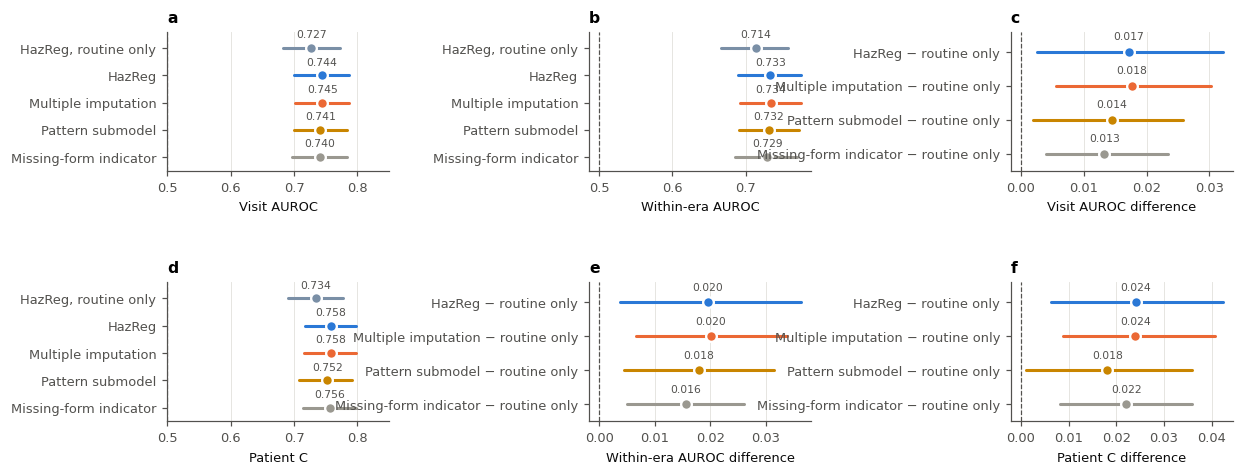

In [45]:
"""Multiple imputation (PMM, repeated forms, FSS), the pattern submodel and the missing-form indicator."""
import statsmodels.api as sm
from sklearn.linear_model import BayesianRidge

SF_ALL = ROUTINE_VARS + SF36_VARS
IMP_DEPLOY = ROUTINE_VARS + SF36_PREV_VARS + FSS_VARS        # past only: how a visit being scored is imputed
IMP_DEV = IMP_DEPLOY + SF36_NEXT_VARS                         # + the next form: how development landmarks are imputed
SF_TARGETS = SF36_VARS + [PCS_NR]                             # imputed in this order, each given the previous ones
SF_REF = ROUTINE_REF                                          # HazReg without the SF-36: the reference of this section
SF_NAMES = [SF_REF, "HazReg", "Multiple imputation", "Pattern submodel", "Missing-form indicator"]


def _pmm_draw(Xo, yo, Xm, rng, k=SF36_PMM_K):
    """One predictive-mean-matching draw (type 1): the donors' predicted means from the posterior mean, the
    recipients' from one draw of the coefficients; each recipient takes the value of one of its k nearest donors."""
    br = BayesianRidge().fit(Xo, yo)
    xm, ym = Xo.mean(0), yo.mean()
    L = np.linalg.cholesky(br.sigma_ + 1e-10 * np.eye(len(br.coef_)))
    b = br.coef_ + L @ rng.standard_normal(len(br.coef_))
    mu_d = ym + (Xo - xm) @ br.coef_
    mu_r = ym + (Xm - xm) @ b
    o = np.argsort(mu_d)
    sd_ = mu_d[o]
    pos = np.searchsorted(sd_, mu_r)
    win = np.clip(pos[:, None] + np.arange(-k, k)[None, :], 0, len(sd_) - 1)       # 2k candidates around each
    dist = np.abs(sd_[win] - mu_r[:, None])
    near = np.take_along_axis(win, np.argsort(dist, axis=1)[:, :k], axis=1)
    pick = near[np.arange(len(mu_r)), rng.randint(0, k, len(mu_r))]
    return yo[o][pick]


def impute_sf36(tr, te, m, seed):
    """m imputations of every SF-36 target for all landmarks. Donors: the training rows with a form. Training rows
    without a form use the development model (past and next forms); test rows without a form the deployment model
    (past forms only). Observed values are kept as they are."""
    rng = np.random.RandomState(seed)
    tr, te = np.asarray(tr), np.asarray(te)
    don = tr[SF_OK[tr]]
    groups = [(tr[~SF_OK[tr]], IMP_DEV), (te[~SF_OK[te]], IMP_DEPLOY)]
    preps = {id(cols): Prep(cols).fit(LAND_X.iloc[don]) for _, cols in groups}
    out = []
    for j in range(m):
        cur = {t: LAND_X[t].values.astype(float).copy() for t in SF_TARGETS}
        for rows, cols in groups:
            if not len(rows):
                continue
            pr = preps[id(cols)]
            Xd, Xr = pr.transform(LAND_X.iloc[don]), pr.transform(LAND_X.iloc[rows])
            for i, t in enumerate(SF_TARGETS):
                prev = SF_TARGETS[:i]
                Xd_ = np.column_stack([Xd] + [(cur[q][don] - 50) / 10 for q in prev])
                Xr_ = np.column_stack([Xr] + [(cur[q][rows] - 50) / 10 for q in prev])
                cur[t][rows] = _pmm_draw(Xd_, LAND_X[t].values[don], Xr_, rng)
        out.append(cur)
    return out


def _cv_fold_mi(tr_p, te_p, seed):
    tr, te = _fold_rows(tr_p, te_p)
    alphas, risks, risks_own = None, [], []
    for imp in impute_sf36(tr, te, SF36_MI_M, seed):
        F = LAND_X.copy()
        for t in SF36_VARS:
            F[t] = imp[t]
        mdl = fit_procedure(tr, SF_ALL, SPLINE_VARS, seed=seed, alphas=alphas, frame=F)
        alphas = mdl["alphas"]
        risks.append(cif(predict_eta(mdl, X=design(mdl, F.iloc[te])), base=mdl["base"]))
        risks_own.append(cif(predict_eta(mdl, X=mdl["prep"].transform(recency_frame(F.iloc[te], mdl.get("half_life")))), base=mdl["base"]))
    return te, np.mean(risks, 0), alphas, np.mean(risks_own, 0)


t0 = time.time()
if f"cv_{SF_REF}" not in STATE:
    STATE[f"cv_{SF_REF}"] = run_cv("haz", ROUTINE_VARS, SPLINE_VARS)
    _save_state()
if "cv_SF36 submodel" not in STATE:
    STATE["cv_SF36 submodel"] = run_cv("haz", SF_ALL, SPLINE_VARS, rowmask=SF_OK)
    _save_state()
if "cv_Pattern submodel" not in STATE:
    _sub, _haz = STATE["cv_SF36 submodel"], STATE[f"cv_{SF_REF}"]
    STATE["cv_Pattern submodel"] = {k: np.where(SF_OK[None, :, None], _sub[k], _haz[k]) for k in ["pred", "pred_own"]} | {
        "tuned": [], "base": np.where(SF_OK[None, :, None, None], _sub["base"], _haz["base"])}
if "cv_Multiple imputation (PMM)" not in STATE:
    _tasks = cv_tasks(lambda a, b, s: delayed(_cv_fold_mi)(a, b, s))
    _res = Parallel(n_jobs=N_JOBS)(t[1] for t in _tasks)
    _out, _own = np.full((CV_REPEATS, N_LAND), np.nan), np.full((CV_REPEATS, N_LAND), np.nan)
    for (r, _), (te, risk, al, risk_own) in zip(_tasks, _res):
        _out[r, te], _own[r, te] = risk, risk_own
    STATE["cv_Multiple imputation (PMM)"] = {"pred": _out, "pred_own": _own, "tuned": [x[2] for x in _res]}
    _save_state()
if "cv_Missing-form indicator" not in STATE:
    STATE["cv_Missing-form indicator"] = run_cv("haz", SF_ALL, SPLINE_VARS)
    _save_state()
print(f"SF-36 approaches cross-validated in {(time.time() - t0) / 60:.1f} min ({SF36_MI_M} imputations per fold)")

STATE["cv_Multiple imputation"] = STATE["cv_Multiple imputation (PMM)"]
for name in [n for n in SF_NAMES if n not in P_CV]:
    P_CV[name] = cv_risk(name)
    CV_RES[name], CV_ARR[name] = summarise(P_CV[name], p_abs=P_ABS.get(name))
    FLAGS[name] = alarm_flags(P_CV[name])
    PT_RES[name], PT_ARR[name] = pt_summary(PT_EVAL, P_CV[name], FLAGS[name])

SF_TABLE = pd.concat([metrics_table(SF_NAMES), pt_table(SF_NAMES)])
display(SF_TABLE)
save_table(SF_TABLE, "sf36_approaches")
SF_DIFF = pd.DataFrame({f"{n} − routine only": {**{k: fmt(paired(n, SF_REF, k)) for k in ["AUROC", "Within-era AUROC", "IPA"]},
                                                "Patient C (time-matched)": fmt(ppaired(n, SF_REF))} for n in SF_NAMES[1:]}).T
display(SF_DIFF)
save_table(SF_DIFF, "sf36_approaches_differences")
fig, axes = plt.subplots(2, 3, figsize=(12.5, 4.6), gridspec_kw={"wspace": 0.9, "hspace": 0.8})
_ci_panel(axes[0, 0], [(n, CV_RES[n]["AUROC"], MODEL_COLORS[n]) for n in SF_NAMES], "a  Visit AUROC", ref=0.5)
_ci_panel(axes[0, 1], [(n, CV_RES[n]["Within-era AUROC"], MODEL_COLORS[n]) for n in SF_NAMES], "b  Within-era AUROC", ref=0.5)
_ci_panel(axes[0, 2], [(f"{n} − routine only", paired(n, SF_REF), MODEL_COLORS[n]) for n in SF_NAMES[1:]],
          "c  Visit AUROC difference", ref=0.0)
_ci_panel(axes[1, 0], [(n, PT_RES[n]["C"], MODEL_COLORS[n]) for n in SF_NAMES], "d  Patient C (time-matched)", ref=0.5)
_ci_panel(axes[1, 1], [(f"{n} − routine only", paired(n, SF_REF, "Within-era AUROC"), MODEL_COLORS[n]) for n in SF_NAMES[1:]],
          "e  Within-era AUROC difference", ref=0.0)
_ci_panel(axes[1, 2], [(f"{n} − routine only", ppaired(n, SF_REF), MODEL_COLORS[n]) for n in SF_NAMES[1:]],
          "f  Patient C difference", ref=0.0)
for ax in axes[:, 0]:
    ax.set_xlim(0.5, 0.85)
save_fig("sf36_approaches")

### 3.7.1 Where the gain comes from: visits with and without a form, and by era

On visits without a form, the pattern submodel *is* HazReg, routine only, so its whole gain must come from the visits with one.
Imputation and the indicator change every visit's risk; the split shows where.

In [46]:
"""AUROC by whether the visit has a form, by calendar era and by entry era; differences from HazReg, routine only, on the same bootstrap resamples."""


def sub_arr(p, rows):
    return metric_arrays(p[rows], W_BOOT[:, ROW_PIDX[rows]], Y_IP[rows], W_IP[rows], ERA_LAB[rows])


_groups = [("Visits with a form", np.flatnonzero(SF_OK)), ("Visits without a form", np.flatnonzero(~SF_OK))]
_groups += [(f"Calendar era {lab}", np.flatnonzero(ERA_LAB == lab)) for lab in ERA_NAMES if (ERA_LAB == lab).sum() > 0]
_groups += [(f"Entry era {lab}", np.flatnonzero(ENTRY_ERA == lab)) for lab in ERA_NAMES if (ENTRY_ERA == lab).sum() > 0]
_rows = []
for gname, rows in _groups:
    if ((Y_IP[rows] == 1) & (W_IP[rows] > 0)).sum() < 10:
        continue
    A = {n: sub_arr(P_CV[n], rows)["AUROC"] for n in SF_NAMES}
    r_ = {"Visits": gname, "Landmarks": len(rows), "With a form (%)": round(100 * SF_OK[rows].mean()),
          "Onsets within 36 mo": int(((Y_IP[rows] == 1) & (W_IP[rows] > 0)).sum()),
          "Routine-only AUROC": fmt(ci_of(A[SF_REF]))}
    for n in SF_NAMES[1:]:
        r_[f"{n} − routine only"] = fmt(ci_of(A[n] - A[SF_REF]))
    _rows.append(r_)
SF_SUB = pd.DataFrame(_rows).set_index("Visits")
display(SF_SUB)
save_table(SF_SUB, "sf36_by_subgroup")

,Landmarks,With a form (%),Onsets within 36 mo,Routine-only AUROC,HazReg − routine only,Multiple imputation − routine only,Pattern submodel − routine only,Missing-form indicator − routine only
Visits,,,,,,,,
Visits with a form,6326,100,308,0.737 (0.677 to 0.787),0.029 (0.005 to 0.053),0.031 (0.011 to 0.053),0.026 (0.002 to 0.050),0.029 (0.012 to 0.048)
Visits without a form,6650,0,280,0.718 (0.657 to 0.776),0.004 (-0.010 to 0.020),0.002 (-0.009 to 0.014),0.000 (0.000 to 0.000),-0.003 (-0.012 to 0.007)
Calendar era <= 2001,2514,56,158,0.748 (0.677 to 0.814),0.029 (-0.002 to 0.060),0.029 (0.003 to 0.056),0.023 (-0.011 to 0.056),0.023 (-0.003 to 0.049)
Calendar era 2002-10,4486,65,268,0.684 (0.619 to 0.745),0.024 (-0.004 to 0.050),0.022 (-0.000 to 0.045),0.022 (-0.001 to 0.046),0.019 (-0.000 to 0.038)
Calendar era 2011-19,5976,34,162,0.727 (0.633 to 0.815),0.007 (-0.014 to 0.032),0.011 (-0.005 to 0.029),0.008 (-0.003 to 0.020),0.006 (-0.006 to 0.020)
Entry era <= 2001,6561,61,358,0.689 (0.630 to 0.751),0.014 (-0.008 to 0.036),0.019 (0.001 to 0.038),0.021 (0.001 to 0.040),0.017 (0.002 to 0.032)
Entry era 2002-10,4200,40,157,0.774 (0.703 to 0.835),0.025 (-0.002 to 0.055),0.017 (-0.007 to 0.044),0.005 (-0.015 to 0.026),0.009 (-0.008 to 0.029)
Entry era 2011-19,2215,28,73,0.765 (0.596 to 0.879),0.019 (0.002 to 0.041),0.014 (-0.004 to 0.037),0.009 (-0.008 to 0.026),0.009 (-0.010 to 0.031)


### 3.7.2 Why the missing-form indicator is a negative control

**The question.** Does "no form" carry information about the patient, or about the year? The onset rate per 100
person-years is compared between visits with and without a form, pooled and within each era (Mantel-Haenszel). If
the pooled rate ratio is further from 1 than the within-era one, part of what the indicator learns is calendar time.

In [47]:
"""Onset rates with and without a form, by era; pooled vs Mantel-Haenszel rate ratio; the indicator's coefficient."""
_rr, _mh_n, _mh_d = [], 0.0, 0.0
for _, _, lab in ERAS:
    k = ERA_LAB == lab
    if k.sum() == 0:
        continue
    d1, t1 = D1_ALL[k & ~SF_OK].sum(), INT_YRS_ALL[k & ~SF_OK].sum()
    d0, t0_ = D1_ALL[k & SF_OK].sum(), INT_YRS_ALL[k & SF_OK].sum()
    _rr.append({"Era": lab, "Visits without a form (%)": round(100 * (~SF_OK[k]).mean()),
                "Onsets /100 py, no form": 100 * d1 / max(t1, 1e-9), "Onsets /100 py, form": 100 * d0 / max(t0_, 1e-9),
                "Rate ratio (no form / form)": (d1 / t1) / (d0 / t0_) if d0 > 0 and t1 > 0 else np.nan})
    T = t1 + t0_
    _mh_n += d1 * t0_ / T; _mh_d += d0 * t1 / T
SF_RATES = pd.DataFrame(_rr).set_index("Era").round(2)
_pooled = (D1_ALL[~SF_OK].sum() / INT_YRS_ALL[~SF_OK].sum()) / (D1_ALL[SF_OK].sum() / INT_YRS_ALL[SF_OK].sum())
SF_RATES.loc["Pooled (crude)", "Rate ratio (no form / form)"] = round(_pooled, 2)
SF_RATES.loc["Within era (Mantel-Haenszel)", "Rate ratio (no form / form)"] = round(_mh_n / _mh_d, 2)
display(SF_RATES)
save_table(SF_RATES, "sf36_indicator_rates")

if "final_sf36_indicator" not in STATE:
    STATE["final_sf36_indicator"] = fit_procedure(np.arange(N_LAND), SF_ALL, SPLINE_VARS, seed=SEED)
    STATE["final_sf36_submodel"] = fit_procedure(np.flatnonzero(SF_OK), SF_ALL, SPLINE_VARS, seed=SEED)
    _save_state()
_rows = []
for lab_, mdl in [("Pattern submodel (visits with a form)", STATE["final_sf36_submodel"]),
                  ("Missing-form indicator (every visit)", STATE["final_sf36_indicator"])]:
    nm, sc, sd = list(mdl["prep"].names), mdl["prep"].scale, mdl["prep"].sd
    for t in SF36_VARS:                                  # per SD of the score (the inputs are standardised)
        i = nm.index(t)
        _rows.append({"Model": lab_, "Term": DISPLAY[t] + ", per SD", "Onset HR": np.exp(mdl["coef"][0, i] * sc[i]),
                      "Other exit HR": np.exp(mdl["coef"][1, i] * sc[i])})
    ind = [nm.index(f"{t}__MISSING") for t in SF36_VARS if f"{t}__MISSING" in nm]
    if ind:                                              # 0/1 columns (not standardised); the PCS and MCS indicators coincide: add them
        eff = [sum(mdl["coef"][c, i] * sc[i] for i in ind) for c in range(2)]
        _rows.append({"Model": lab_, "Term": "No form in the past 12 months (vs a form)", "Onset HR": np.exp(eff[0]),
                      "Other exit HR": np.exp(eff[1])})
SF_TERMS = pd.DataFrame(_rows).set_index(["Model", "Term"]).round(2)
display(SF_TERMS)
save_table(SF_TERMS, "sf36_terms")

,Visits without a form (%),"Onsets /100 py, no form","Onsets /100 py, form",Rate ratio (no form / form)
Era,,,,
<= 2001,44.0,2.70,2.68,1.00
2002-10,35.0,2.82,2.72,1.04
2011-19,66.0,1.32,1.44,0.92
Pooled (crude),NaN,NaN,NaN,0.83
Within era (Mantel-Haenszel),NaN,NaN,NaN,1.00


Onset HR  Other exit HR
Model                                 Term                                                                   
Pattern submodel (visits with a form) SF-36 physical component summary (PCS), per SD      0.65           1.00
                                      SF-36 mental component summary (MCS), per SD        0.81           1.00
Missing-form indicator (every visit)  SF-36 physical component summary (PCS), per SD      0.80           0.99
                                      SF-36 mental component summary (MCS), per SD        0.90           1.00
                                      No form in the past 12 months (vs a form)           1.13           0.99

### 3.7.3 The imputation model

How well each of the two imputation models predicts an observed score, on visits with a form held out by patient.
The development model (past and next forms) is the one used for training visits; the deployment model (past forms
only) the one used for a visit being scored.

In [48]:
"""Held-out R² of the development (past + next form) and deployment (past forms only) imputation models."""
_obs = np.flatnonzero(SF_OK)
_fold = np.array([PID_INDEX[p] % 5 for p in PID_ALL[_obs]])
_imp_rows = {}
for lab_, cols in [("Development: + next form", IMP_DEV), ("Deployment: past forms only", IMP_DEPLOY),
                   ("Deployment without the fatigue scale", ROUTINE_VARS + SF36_PREV_VARS)]:
    pred = {c: np.full(len(_obs), np.nan) for c in SF_TARGETS}
    for k in range(5):
        tr_, te_ = _obs[_fold != k], _obs[_fold == k]
        pr = Prep(cols).fit(LAND_X.iloc[tr_])
        for c in SF_TARGETS:
            br = BayesianRidge().fit(pr.transform(LAND_X.iloc[tr_]), LAND_X[c].values[tr_])
            pred[c][_fold == k] = br.predict(pr.transform(LAND_X.iloc[te_]))
    _imp_rows[lab_] = {DISPLAY.get(c, c): 1 - np.mean((LAND_X[c].values[_obs] - pred[c]) ** 2) / LAND_X[c].values[_obs].var()
                       for c in SF_TARGETS}
IMP_FIT = pd.DataFrame(_imp_rows).T.round(2)
_miss = ~SF_OK
IMP_COVER = pd.Series({"Visits without a form (%)": 100 * _miss.mean(),
                       "... with an older form (%)": 100 * LAND_X["PCS_PREV"].notna().values[_miss].mean(),
                       "... with a later form (%)": 100 * LAND_X["PCS_NEXT"].notna().values[_miss].mean(),
                       "... with a fatigue scale in the past 12 months (%)": 100 * LAND_X["FSS10"].notna().values[_miss].mean()}).round(0)
display(IMP_FIT)
display(IMP_COVER.to_frame("Share"))
save_table(IMP_FIT, "sf36_imputation_fit")

,SF-36 physical component summary (PCS),SF-36 mental component summary (MCS),"SF-36 physical score without the role scales (PF, BP, GH)"
Development: + next form,0.57,0.39,0.63
Deployment: past forms only,0.51,0.32,0.59
Deployment without the fatigue scale,0.43,0.23,0.48


,Share
Visits without a form (%),51.0
... with an older form (%),60.0
... with a later form (%),59.0
... with a fatigue scale in the past 12 months (%),2.0


### 3.7.4 Does the SF-36 add to the routine variables? (H8, H8c)

The test pools, over the imputed data sets of **all** landmarks (the development imputation model), an
unpenalised Poisson model of the onset hazard with the routine variables (same splines and missing-value
indicators as HazReg) and the SF-36 terms, calendar time as in HazReg, with patient-clustered covariance. Hazard ratios are per SD of the score
(higher = better health).

In [49]:
"""Multiple-imputation pooled inference: Rubin's rules, the D1 Wald test of PCS + MCS (H8) and of the score without the role scales (H8c)."""


def rubin_pool(Q, U):
    """Rubin's rules for m estimates Q (m, k) with covariances U (m, k, k): pooled estimate, total covariance,
    D1 Wald test (Li, Raghunathan & Rubin 1991) with its F statistic, df and p, and per-term Barnard-Rubin df."""
    Q, U = np.asarray(Q), np.asarray(U)
    m, k = Q.shape
    qbar, Ubar = Q.mean(0), U.mean(0)
    B = np.atleast_2d(np.cov(Q, rowvar=False, ddof=1)) if m > 1 else np.zeros((k, k))
    T = Ubar + (1 + 1 / m) * B
    Ui = np.linalg.inv(Ubar)
    r = (1 + 1 / m) * np.trace(B @ Ui) / k
    D1 = float(qbar @ Ui @ qbar) / (k * (1 + r))
    t = k * (m - 1)
    nu = 4 + (t - 4) * (1 + (1 - 2 / t) / r) ** 2 if t > 4 else t * (1 + 1 / k) * (1 + r) ** 2 / 2
    p = float(stats.f.sf(D1, k, nu))
    lam = np.clip((1 + 1 / m) * np.diag(B) / np.diag(T), 1e-9, 1)
    df_old = (m - 1) / lam ** 2
    return {"q": qbar, "T": T, "D1": D1, "df": (k, nu), "p": p, "df_term": df_old, "fmi": lam}


def pooled_sf36_test(imps, sf_terms, test_terms):
    """Onset hazard ~ routine variables + sf_terms in each imputed frame; pooled coefficients of test_terms."""
    F0 = LAND_X.copy()
    for t in sf_terms:
        F0[t] = imps[0][t]
    _h = FINAL.get("half_life")                                       # as HazReg: its half-life and calendar time
    F0 = recency_frame(F0, _h)
    _c, _s = with_calendar(*recency_inputs(ROUTINE_VARS + sf_terms, SPLINE_VARS, _h), np.arange(N_LAND), frame=F0)
    pr = Prep(_c, _s).fit(F0)                                         # one standardisation for every imputation
    idx = [1 + pr.names.index(t) for t in test_terms]
    Q, U = [], []
    for imp in imps:
        F = recency_frame(LAND_X, _h).copy()
        for t in sf_terms:
            F[t] = imp[t]
        X = sm.add_constant(pr.transform(F), has_constant="add")
        f = sm.GLM(D1, X, family=sm.families.Poisson(), offset=np.log(INT_YRS)).fit(
            cov_type="cluster", cov_kwds={"groups": ROW_PIDX})
        cp = np.asarray(f.cov_params())
        Q.append(np.asarray(f.params)[idx]); U.append(cp[np.ix_(idx, idx)])
    return rubin_pool(Q, U)


if "sf36_final_imputations" not in STATE:
    STATE["sf36_final_imputations"] = impute_sf36(np.arange(N_LAND), np.array([], int), SF36_MI_M, SEED + 808)
    _save_state()
_IMPS = STATE["sf36_final_imputations"]
POOL_H8 = pooled_sf36_test(_IMPS, SF36_VARS, SF36_VARS)
POOL_H8c = pooled_sf36_test(_IMPS, [PCS_NR], [PCS_NR])
# the same on the visits with a form only (complete case), for comparison
_cc = SF_OK
_Fcc = recency_frame(LAND_X, FINAL.get("half_life")).iloc[np.flatnonzero(_cc)]
_Xcc_pr = Prep(*with_calendar(*recency_inputs(SF_ALL, SPLINE_VARS, FINAL.get("half_life")), np.flatnonzero(_cc))).fit(_Fcc)
_fcc = sm.GLM(D1[_cc], sm.add_constant(_Xcc_pr.transform(_Fcc), has_constant="add"),
              family=sm.families.Poisson(), offset=np.log(INT_YRS[_cc])).fit(cov_type="cluster", cov_kwds={"groups": ROW_PIDX[_cc]})
_rows = []
for lab_, P_, terms in [("Multiple imputation, all visits", POOL_H8, SF36_VARS),
                        ("Multiple imputation, all visits (H8c model)", POOL_H8c, [PCS_NR])]:
    se = np.sqrt(np.diag(P_["T"]))
    for j, t in enumerate(terms):
        tq = stats.t.ppf(0.975, P_["df_term"][j])
        _rows.append({"Analysis": lab_, "Term": DISPLAY[t], "Onset HR per SD": np.exp(P_["q"][j]),
                      "95% CI": f"{np.exp(P_['q'][j] - tq * se[j]):.2f}-{np.exp(P_['q'][j] + tq * se[j]):.2f}",
                      "Fraction of missing information": P_["fmi"][j]})
for t in SF36_VARS:
    j = 1 + _Xcc_pr.names.index(t)
    b, se_ = np.asarray(_fcc.params)[j], np.asarray(_fcc.bse)[j]
    _rows.append({"Analysis": "Complete case (visits with a form)", "Term": DISPLAY[t], "Onset HR per SD": np.exp(b),
                  "95% CI": f"{np.exp(b - 1.96 * se_):.2f}-{np.exp(b + 1.96 * se_):.2f}", "Fraction of missing information": np.nan})
SF_POOLED = pd.DataFrame(_rows).set_index(["Analysis", "Term"]).round(3)
display(SF_POOLED)
save_table(SF_POOLED, "sf36_pooled_hazard_ratios")
SF_TESTS = pd.DataFrame({"H8: PCS + MCS": {"D1 (F)": POOL_H8["D1"], "df": f"{POOL_H8['df'][0]}, {POOL_H8['df'][1]:.0f}",
                                           "p": POOL_H8["p"]},
                         "H8c: physical score without the role scales": {"D1 (F)": POOL_H8c["D1"],
                                                                         "df": f"{POOL_H8c['df'][0]}, {POOL_H8c['df'][1]:.0f}",
                                                                         "p": POOL_H8c["p"]}}).T
display(SF_TESTS)
save_table(SF_TESTS, "sf36_pooled_tests")


def _rec_test(code, label, measure, P_, terms):
    hrs = "; ".join(f"{DISPLAY[t].split('(')[-1].rstrip(')') if '(' in DISPLAY[t] else t} HR per SD {np.exp(P_['q'][j]):.2f}"
                    for j, t in enumerate(terms))
    HYP[code] = {"Hypothesis": label, "Measure": measure,
                 "Result": f"F = {P_['D1']:.2f} (df {P_['df'][0]}, {P_['df'][1]:.0f}), p = {P_['p']:.2g}; {hrs}",
                 "Met": "yes" if P_["p"] < 0.05 else "no", "_met": P_["p"] < 0.05, "_est": (P_["D1"], P_["p"], P_["p"])}


_rec_test("H8", "The SF-36 PCS and MCS add to the routine variables",
          "Pooled Wald test (D1, 2 df) of PCS and MCS, onset hazard, multiple imputation", POOL_H8, SF36_VARS)
HYP["H8"]["Also"] = (f"Cross-validated, HazReg (with PCS, MCS and FSS) − routine only: IPA {fmt(paired('HazReg', SF_REF, 'IPA'), 4)}, "
                     f"AUROC {fmt(paired('HazReg', SF_REF))}; MI − routine only: AUROC {fmt(paired('Multiple imputation', SF_REF))}")
record_pt("H8", ppaired("HazReg", SF_REF), "above0")
_rec_test("H8c", "A physical score without the role scales still adds",
          "Pooled Wald test (1 df) of PF + BP + GH score, onset hazard, multiple imputation", POOL_H8c, [PCS_NR])

_a, _b, _c = paired("Pattern submodel", SF_REF), paired("Multiple imputation", SF_REF), paired("Missing-form indicator", SF_REF)
_bi = paired("Multiple imputation", SF_REF, "IPA")
_ce = paired("Missing-form indicator", SF_REF, "Within-era AUROC")
_bp = ppaired("Multiple imputation", SF_REF)
_r, _ri, _rp = paired("HazReg", SF_REF), paired("HazReg", SF_REF, "IPA"), ppaired("HazReg", SF_REF)
_rs = SF_SUB.loc["Visits with a form", "HazReg − routine only"] if "Visits with a form" in SF_SUB.index else "–"
_hr = SF_POOLED.xs("Multiple imputation, all visits", level="Analysis")
_hrc = SF_POOLED.xs("Complete case (visits with a form)", level="Analysis")
say(f"""
**What this means.**

* **H8 is {'met' if HYP['H8']['_met'] else 'not met'}.** Pooled over {len(_IMPS)} imputations of all {N_LAND:,} working
  visits, PCS and MCS together give F = {POOL_H8['D1']:.2f} (p = {POOL_H8['p']:.2g}). A PCS one SD higher (better
  physical health) carries an onset hazard ratio of {_hr.iloc[0]['Onset HR per SD']:.2f} ({_hr.iloc[0]['95% CI']});
  for MCS {_hr.iloc[1]['Onset HR per SD']:.2f} ({_hr.iloc[1]['95% CI']}). On the visits with a form alone the
  hazard ratios are {_hrc.iloc[0]['Onset HR per SD']:.2f} and {_hrc.iloc[1]['Onset HR per SD']:.2f}.
* **H8c is {'met' if HYP['H8c']['_met'] else 'not met'}.** Without the role scales, the physical score has an onset hazard
  ratio of {SF_POOLED.xs("Multiple imputation, all visits (H8c model)", level="Analysis").iloc[0]['Onset HR per SD']:.2f}
  per SD (p = {POOL_H8c['p']:.2g}). {"The signal does not rest on the items that ask about cutting down work." if HYP['H8c']['_met'] else "Much of the PCS signal may come from the role scales, which partly record the work loss itself."}
* **The reported model.** HazReg, which reads the PCS, MCS and fatigue severity scale of a recent form or their single
  deterministic predictions,
  changes the AUROC by {_r[0]:+.3f} ({_r[1]:+.3f} to {_r[2]:+.3f}), the IPA by {_ri[0]:+.4f} ({_ri[1]:+.4f} to
  {_ri[2]:+.4f}) and the patient C by {_rp[0]:+.3f} ({_rp[1]:+.3f} to {_rp[2]:+.3f}) against the same model without
  the three scores; on the visits with a form, the AUROC by {_rs}. HazReg, routine only, stays the fallback for a clinic
  that does not collect these forms.
* **Multiple imputation.** The cross-validated risks of the imputation model change the IPA by {_bi[0]:+.4f}
  ({_bi[1]:+.4f} to {_bi[2]:+.4f}), the AUROC by {_b[0]:+.3f} ({_b[1]:+.3f} to {_b[2]:+.3f}) and the patient C by
  {_bp[0]:+.3f} ({_bp[1]:+.3f} to {_bp[2]:+.3f}). The pattern submodel changes the AUROC by {_a[0]:+.3f}
  ({_a[1]:+.3f} to {_a[2]:+.3f}). The gain is confined to visits with a form (Section 3.7.1).
* **The imputation model.** With the patient's next form, the development model explains
  {100 * IMP_FIT.iloc[0, 0]:.0f} % of the variance of an observed PCS; the deployment model, with past forms only,
  {100 * IMP_FIT.iloc[1, 0]:.0f} % ({100 * IMP_FIT.iloc[2, 0]:.0f} % without the fatigue scale).
* **The missing-form indicator** gives {_c[0]:+.3f} pooled and {_ce[0]:+.3f} within era, and its "no form" term has an
  onset hazard ratio of {SF_TERMS.xs("No form in the past 12 months (vs a form)", level="Term")["Onset HR"].iloc[0]:.2f}.
  Crude onset rates without a form are {_pooled:.2f} times those with one, but {_mh_n / _mh_d:.2f} times within era:
  the crude contrast is calendar time, so the indicator is not a candidate for the tool, whatever its AUROC.
""")

Onset HR per SD     95% CI  Fraction of missing information
Analysis                                    Term                                                                                                           
Multiple imputation, all visits             SF-36 physical component summary (PCS)                        0.657  0.57-0.76                            0.115
                                            SF-36 mental component summary (MCS)                          0.819  0.71-0.94                            0.113
Multiple imputation, all visits (H8c model) SF-36 physical score without the role scales (P...            0.671  0.58-0.78                            0.107
Complete case (visits with a form)          SF-36 physical component summary (PCS)                        0.601  0.49-0.73                              NaN
                                            SF-36 mental component summary (MCS)                          0.784  0.65-0.94                              NaN

,D1 (F),df,p
H8: PCS + MCS,18.470547,"2, 2217",0.0
H8c: physical score without the role scales,27.473445,"1, 1085",0.0


**What this means.**

* **H8 is met.** Pooled over 20 imputations of all 12,976 working
  visits, PCS and MCS together give F = 18.47 (p = 1.1e-08). A PCS one SD higher (better
  physical health) carries an onset hazard ratio of 0.66 (0.57-0.76);
  for MCS 0.82 (0.71-0.94). On the visits with a form alone the
  hazard ratios are 0.60 and 0.78.
* **H8c is met.** Without the role scales, the physical score has an onset hazard
  ratio of 0.67
  per SD (p = 1.9e-07). The signal does not rest on the items that ask about cutting down work.
* **The reported model.** HazReg, which reads the PCS, MCS and fatigue severity scale of a recent form or their single
  deterministic predictions,
  changes the AUROC by +0.017 (+0.003 to +0.032), the IPA by +0.0020 (-0.0129 to
  +0.0147) and the patient C by +0.024 (+0.006 to +0.042) against the same model without
  the three scores; on the visits with a form, the AUROC by 0.029 (0.005 to 0.053). HazReg, routine only, stays the fallback for a clinic
  that does not collect these forms.
* **Multiple imputation.** The cross-validated risks of the imputation model change the IPA by +0.0037
  (-0.0086 to +0.0150), the AUROC by +0.018 (+0.006 to +0.030) and the patient C by
  +0.024 (+0.009 to +0.041). The pattern submodel changes the AUROC by +0.014
  (+0.002 to +0.026). The gain is confined to visits with a form (Section 3.7.1).
* **The imputation model.** With the patient's next form, the development model explains
  57 % of the variance of an observed PCS; the deployment model, with past forms only,
  51 % (43 % without the fatigue scale).
* **The missing-form indicator** gives +0.013 pooled and +0.016 within era, and its "no form" term has an
  onset hazard ratio of 1.13.
  Crude onset rates without a form are 0.83 times those with one, but 1.00 times within era:
  the crude contrast is calendar time, so the indicator is not a candidate for the tool, whatever its AUROC.

## 3.8 Design checks

> **The question.** HazReg rests on eight design choices that a reviewer can fairly question. Does any of them change
> the results?

| Check | The concern | What is done | Compared on |
|:--|:--|:--|:--|
| **(a) Visit frequency** | Sicker patients are seen more often. With a landmark every 6 months they no longer contribute more landmarks, but their inputs are fresher at each landmark | Each landmark is weighted by the inverse of its predicted visit intensity (Lin, Scharfstein & Rosenheck 2004), so that the evaluation represents patient-time rather than visits | Every model's performance, unweighted and weighted |
| **(b) Effects that change with landmark time** | HazReg assumes a predictor means the same at s = 0 and at s = 15 years | A landmark supermodel on the landmark clock, s = years since the first employed visit (the ipl* model of van Houwelingen & Putter): each effect is β(s) = b₀ + b₁f(s) + b₂f(s)², with a main effect γ(s) = g₁f(s) + g₂f(s)², f(s) = (min(s, 20) − 5) / 10, penalised like the spline terms. The β(s) paths are plotted with bootstrap bands | AUROC, IPA, patient C against HazReg; flat paths justify one model for every s |
| **(c) When the onset happened** | The onset is only known to lie between the last working visit and the visit that records it; HazReg dates it at the later visit | The same two hazards fitted with the interval-censored competing-risks likelihood over that interval (same inputs and penalties) | The same |
| **(d) Uncertainty for the individual patient** | Ridge regression gives a point risk; the sample is small (about 160 patients with an onset) | A Bayesian version of HazReg with weakly informative priors (log hazard ratio per SD ~ N(0, 0.5²); half that for spline and indicator terms), fitted by a Laplace approximation; 95 % credible intervals for each visit's risk and the probability that its tier is right | The same, plus the width of each visit's interval |
| **(e) One landmark every 6 months** | The model is trained on fewer rows than there are working visits | HazReg trained on every working visit (intervals to the next visit), scored at the same 6-monthly landmarks (Section 3.8.5) | AUROC, log score, patient C against HazReg |
| **(f) The penalty** | The tuned penalty left the predictions too timid; HazReg divides the onset penalty by 3 | The onset penalty as tuned, and divided by 10 and 30, in each fold (Section 3.8.6) | Calibration slope, log score, AUROC against HazReg |
| **(g) The stacked training set** | HazReg follows every landmark to s + 36 months with X(s) fixed, so the same person-year enters up to six times | HazReg trained on the same 6-monthly landmarks chained (each followed to the next landmark only), and on a stacked landmark at every working visit (Section 3.8.7) | Ranking and calibration on the same 6-monthly landmarks against HazReg |
| **(h) Staleness of the inputs** | At a landmark the inputs may be months old | The age of the inputs as an extra input, scored as recorded and at 0 as in clinic (Section 3.8.8) | AUROC, O/E, calibration slope against HazReg |

None of these is a hypothesis: each is a check on a design choice. The reported model is HazReg unless a check
shows a clear gain.

In [50]:
"""(a) Inverse-intensity-of-visit weights, and every model's performance with and without them."""
# the visit process: from each landmark, the rate of the next working visit (Poisson, exposure = time to it or to the
# end of follow-up), on the routine inputs and the calendar era (visit schedules changed over the years)
_vis_pr = Prep(ROUTINE_VARS, SPLINE_VARS).fit(LAND_X)
_era_d = pd.get_dummies(pd.Series(ERA_LAB), drop_first=True).astype(float).values
_Xv = sm.add_constant(np.column_stack([_vis_pr.transform(LAND_X), _era_d]), has_constant="add")
VISIT_FIT = sm.GLM(_cont.astype(float), _Xv, family=sm.families.Poisson(), offset=np.log(INT_YRS_ALL)).fit(
    cov_type="cluster", cov_kwds={"groups": ROW_PIDX})
_lam_v = np.exp(_Xv @ VISIT_FIT.params)                          # predicted visits per year
IIVW = 1 / _lam_v
IIVW = np.clip(IIVW, *np.quantile(IIVW, IIVW_TRUNC))
IIVW = IIVW / IIVW.mean()
_W_IIVW = W_BOOT[:, ROW_PIDX] * IIVW[None, :].astype(np.float32)
_iv_names = [n for n in ["HazReg", "First visit", "LogReg", "LSTM", "Multiple imputation"] if n in P_CV]
IIVW_RES, IIVW_ARR = {}, {}
for n in _iv_names:
    IIVW_RES[n], IIVW_ARR[n] = summarise(P_CV[n], W=_W_IIVW, p_abs=P_ABS.get(n))
_keys = ["AUROC", "Within-era AUROC", "IPA", "O/E", "Calibration slope"]
IIVW_TABLE = pd.concat({"Unweighted (every visit counts once)": pd.DataFrame({n: {k: fmt(CV_RES[n][k]) for k in _keys} for n in _iv_names}),
                        "Visit-intensity weighted (patient-time)": pd.DataFrame({n: {k: fmt(IIVW_RES[n][k]) for k in _keys} for n in _iv_names})})
display(IIVW_TABLE)
save_table(IIVW_TABLE, "design_visit_weighting")
_dw = lambda a, b, k="AUROC": ci_of(IIVW_ARR[a][k] - IIVW_ARR[b][k])
IIVW_DIFF = pd.DataFrame({"Unweighted": {"HazReg − First visit, log score": fmt(paired("HazReg", "First visit", "Log score"), 4),
                                         "HazReg − First visit, IPA": fmt(paired("HazReg", "First visit", "IPA"), 4),
                                         "HazReg − First visit, AUROC": fmt(paired("HazReg", "First visit")),
                                         "LogReg − HazReg, AUROC": fmt(paired("LogReg", "HazReg")),
                                         "Multiple imputation − HazReg, AUROC": fmt(paired("Multiple imputation", "HazReg"))},
                          "Visit-intensity weighted": {"HazReg − First visit, log score": fmt(_dw("HazReg", "First visit", "Log score"), 4),
                                                       "HazReg − First visit, IPA": fmt(_dw("HazReg", "First visit", "IPA"), 4),
                                                       "HazReg − First visit, AUROC": fmt(_dw("HazReg", "First visit")),
                                                       "LogReg − HazReg, AUROC": fmt(_dw("LogReg", "HazReg")),
                                                       "Multiple imputation − HazReg, AUROC": fmt(_dw("Multiple imputation", "HazReg"))}})
display(IIVW_DIFF)
save_table(IIVW_DIFF, "design_visit_weighting_differences")
_vhr = pd.Series(np.exp(VISIT_FIT.params[1:len(_vis_pr.names) + 1]), index=[DISPLAY.get(n, n) for n in _vis_pr.names])
_vhr = _vhr[[not n.endswith(("__NL", "__MISSING")) for n in _vis_pr.names]]
print("Visit intensity: rate ratio per SD, largest effects: " +
      ", ".join(f"{n} {v:.2f}" for n, v in _vhr.iloc[np.argsort(-np.abs(np.log(_vhr.values)))].head(5).items()) +
      f". Weights: 10th-90th percentile {np.percentile(IIVW, 10):.2f}-{np.percentile(IIVW, 90):.2f}.")

HazReg              First visit                  LogReg                    LSTM     Multiple imputation
Unweighted (every visit counts once)    AUROC              0.744 (0.700 to 0.786)   0.618 (0.565 to 0.677)  0.746 (0.701 to 0.790)  0.744 (0.698 to 0.788)  0.745 (0.701 to 0.786)
                                        Within-era AUROC   0.733 (0.689 to 0.775)   0.607 (0.553 to 0.667)  0.736 (0.692 to 0.777)  0.732 (0.685 to 0.776)  0.734 (0.692 to 0.775)
                                        IPA                0.041 (0.009 to 0.068)  0.004 (-0.015 to 0.017)  0.044 (0.019 to 0.066)  0.045 (0.016 to 0.067)  0.043 (0.012 to 0.069)
                                        O/E                0.959 (0.787 to 1.139)   0.950 (0.771 to 1.127)  0.988 (0.808 to 1.174)  0.942 (0.766 to 1.123)  0.962 (0.790 to 1.142)
                                        Calibration slope  0.915 (0.752 to 1.105)   0.802 (0.466 to 1.298)  1.039 (0.848 to 1.252)  1.084 (0.875 to 1.333)  0.922 (0.756 to 1.117)
Visit-intensity weighted (patient-time) AUROC              0.746 (0.699 to 0.789)   0.620 (0.566 to 0.681)  0.748 (0.701 to 0.792)  0.747 (0.697 to 0.792)  0.747 (0.702 to 0.788)
                                        Within-era AUROC   0.736 (0.690 to 0.779)   0.609 (0.554 to 0.669)  0.739 (0.694 to 0.781)  0.736 (0.686 to 0.781)  0.737 (0.693 to 0.779)
                                        IPA                0.043 (0.011 to 0.071)  0.005 (-0.012 to 0.019)  0.047 (0.021 to 0.069)  0.047 (0.019 to 0.069)  0.045 (0.013 to 0.072)
                                        O/E                0.956 (0.783 to 1.139)   0.948 (0.775 to 1.128)  0.984 (0.806 to 1.170)  0.942 (0.768 to 1.119)  0.959 (0.787 to 1.141)
                                        Calibration slope  0.916 (0.745 to 1.114)   0.835 (0.482 to 1.331)  1.041 (0.842 to 1.263)  1.091 (0.872 to 1.352)  0.924 (0.760 to 1.120)

,Unweighted,Visit-intensity weighted
"HazReg − First visit, log score",0.0151 (0.0086 to 0.0212),0.0151 (0.0088 to 0.0214)
"HazReg − First visit, IPA",0.0376 (0.0096 to 0.0620),0.0386 (0.0109 to 0.0631)
"HazReg − First visit, AUROC",0.126 (0.081 to 0.170),0.126 (0.082 to 0.169)
"LogReg − HazReg, AUROC",0.002 (-0.004 to 0.007),0.002 (-0.004 to 0.007)
"Multiple imputation − HazReg, AUROC",0.001 (-0.005 to 0.006),0.001 (-0.005 to 0.007)


Visit intensity: rate ratio per SD, largest effects: Prednisone (mg/day) 0.89, Prednisone above the target of the time 1.11, Clinic visits per year 1.09, SDI damage score 1.03, Age (years) 1.02. Weights: 10th-90th percentile 0.87-1.15.


In [51]:
"""(b) Landmark supermodel, (c) interval-censored likelihood, (d) Bayesian HazReg: cross-validated on HazReg's splits."""
from scipy.optimize import minimize


def _fit_ic(rows, cols, spline, alphas, init=None):
    """Both cause-specific hazards by the interval-censored competing-risks likelihood: an onset or other exit at the
    end of an interval happened somewhere in it. Same ridge penalties (scaled as in PoissonRegressor) as HazReg."""
    rows = np.asarray(rows)
    h = alphas[2] if len(alphas) == 3 else None
    F = recency_frame(LAND_X, h)
    cols, spline = with_calendar(*recency_inputs(cols, spline, h), rows)
    prep = Prep(cols, spline).fit(F.iloc[rows])
    X = prep.transform(F.iloc[rows])
    dt, d1, d2 = INT_YRS[rows], D1[rows], D2[rows]
    ev = (d1 + d2) > 0
    N, P = dt.sum(), X.shape[1]
    if init is None:
        init = np.zeros(2 * (P + 1))
        init[0], init[P + 1] = np.log(max(d1.sum(), 1) / N), np.log(max(d2.sum(), 1) / N)

    def f(th):
        a1, b1, a2, b2 = th[0], th[1:P + 1], th[P + 1], th[P + 2:]
        e1, e2 = np.clip(a1 + X @ b1, -30, 5), np.clip(a2 + X @ b2, -30, 5)
        l1, l2 = np.exp(e1), np.exp(e2)
        L = l1 + l2
        x = L * dt
        ll = np.where(ev, np.where(d1 > 0, e1, e2) - np.log(L) + np.log(-np.expm1(-np.maximum(x, 1e-12))), -x)
        g = dt / np.expm1(np.maximum(x, 1e-12))
        g1 = np.where(ev, (d1 > 0) - l1 / L + l1 * g, -l1 * dt)
        g2 = np.where(ev, (d2 > 0) - l2 / L + l2 * g, -l2 * dt)
        obj = -ll.sum() / N + alphas[0] / 2 * b1 @ b1 + alphas[1] / 2 * b2 @ b2
        grad = np.concatenate([[-g1.sum() / N], -X.T @ g1 / N + alphas[0] * b1, [-g2.sum() / N], -X.T @ g2 / N + alphas[1] * b2])
        return obj, grad
    r = minimize(f, init, jac=True, method="L-BFGS-B", options={"maxiter": 3000})
    th = r.x
    _eta = np.column_stack([th[0] + X @ th[1:P + 1], th[P + 1] + X @ th[P + 2:]])
    return {"prep": prep, "coef": np.vstack([th[1:P + 1], th[P + 2:]]), "intercept": np.array([th[0], th[P + 1]]),
            "base": fit_baseline(_eta, d1, d2, dt), "alphas": list(alphas), "converged": bool(r.success), "half_life": h,
            "cal_ref": float(LAND_YEAR[rows].max()) if "CAL_YEAR" in cols else None}


def _fit_bayes(rows, cols=COMPACT_VARS, spline=SPLINE_VARS, prior_sd=BAYES_PRIOR_SD, prior_means=None, half_life=None):
    """Bayesian HazReg by a Laplace approximation: for each cause, the posterior mode of the Poisson likelihood with
    N(prior mean, prior_sd^2) priors on the coefficients of the transformed inputs (flat on the intercept), and the
    inverse Hessian at the mode as the posterior covariance."""
    rows = np.asarray(rows)
    prior_means = PRIOR_MEANS if prior_means is None else prior_means
    F = recency_frame(LAND_X, half_life)
    cols, spline = with_calendar(*recency_inputs(cols, spline, half_life), rows)
    prep = Prep(cols, spline).fit(F.iloc[rows])
    X1 = np.column_stack([np.ones(len(rows)), prep.transform(F.iloc[rows])])
    P = X1.shape[1]
    prec = np.r_[1e-6, np.full(P - 1, 1 / prior_sd ** 2)]
    dt = INT_YRS[rows]
    out = {"prep": prep, "mode": [], "cov": [], "half_life": half_life, "cal_ref": float(LAND_YEAR[rows].max()) if "CAL_YEAR" in cols else None}
    for c, d in enumerate((D1[rows], D2[rows])):
        m0 = np.zeros(P)
        if c == 0:
            for name, v in prior_means.items():
                if name in prep.names:
                    m0[1 + prep.names.index(name)] = v

        def f(b):
            eta = np.clip(X1 @ b, -30, 5)
            mu = np.exp(eta) * dt
            return (mu - d * eta).sum() + 0.5 * (prec * (b - m0) ** 2).sum(), X1.T @ (mu - d) + prec * (b - m0)
        b0 = np.zeros(P); b0[0] = np.log(max(d.sum(), 1) / dt.sum())
        b = minimize(f, b0, jac=True, method="L-BFGS-B", options={"maxiter": 3000}).x
        mu = np.exp(np.clip(X1 @ b, -30, 5)) * dt
        Hs = (X1 * mu[:, None]).T @ X1 + np.diag(prec)
        out["mode"].append(b); out["cov"].append(np.linalg.inv(Hs))
    out["base"] = fit_baseline(np.column_stack([X1 @ out["mode"][0], X1 @ out["mode"][1]]), D1[rows], D2[rows], dt)
    return out


def bayes_risk_draws(model, rows=None, n=BAYES_DRAWS, seed=0, own_year=False):
    """Posterior draws (n, len(rows)) of the 36-month onset risk."""
    rng = np.random.RandomState(seed)
    F = LAND_X if rows is None else LAND_X.iloc[rows]
    X1 = np.column_stack([np.ones(len(F)), model["prep"].transform(recency_frame(F, model.get("half_life"))) if own_year
                          else design(model, F)])
    eta = []
    for c in range(2):
        L = np.linalg.cholesky(model["cov"][c] + 1e-12 * np.eye(len(model["mode"][c])))
        B = model["mode"][c][None, :] + rng.standard_normal((n, len(model["mode"][c]))) @ L.T
        eta.append(X1 @ B.T)                                           # (rows, n)
    e = np.stack(eta, -1)                                              # (rows, n, 2)
    return cif(e.reshape(-1, 2), base=model["base"]).reshape(e.shape[0], n).T


def _cv_fold_ic(tr_p, te_p, seed, alphas):
    tr, te = _fold_rows(tr_p, te_p)
    base = fit_procedure(tr, alphas=alphas, seed=seed)
    init = np.concatenate([[base["intercept"][0]], base["coef"][0], [base["intercept"][1]], base["coef"][1]])
    m = _fit_ic(tr, COMPACT_VARS, SPLINE_VARS, alphas, init=init)
    return te, predict_eta(m, te), m["converged"], predict_eta(m, te, own_year=True), m["base"]


def _cv_fold_bayes(tr_p, te_p, seed, half_life=None):
    tr, te = _fold_rows(tr_p, te_p)
    m = _fit_bayes(tr, half_life=half_life)
    return (te, bayes_risk_draws(m, te, n=100, seed=seed).mean(0), None,
            bayes_risk_draws(m, te, n=100, seed=seed, own_year=True).mean(0))


def _run_custom(make, risk=False):
    tasks = cv_tasks(make)
    res = Parallel(n_jobs=N_JOBS)(t[1] for t in tasks)
    out = np.full((CV_REPEATS, N_LAND) if risk else (CV_REPEATS, N_LAND, 2), np.nan)
    own = np.full_like(out, np.nan)
    base = np.zeros((CV_REPEATS, N_LAND, 2, NB), np.float32)
    for (r, _), (te, pred, _x, pred_own, *b_) in zip(tasks, res):
        out[r, te], own[r, te] = pred, pred_own
        if b_:
            base[r, te] = b_[0]
    return {"pred": out, "pred_own": own, "tuned": [x[2] for x in res]} | ({} if risk else {"base": base})


t0 = time.time()
if "cv_Supermodel" not in STATE:
    STATE["cv_Supermodel"] = run_cv("haz", COMPACT_VARS + XS_COLS, SPLINE_VARS)
    _save_state()
if "cv_Interval-censored" not in STATE:
    _it = iter(STATE["cv_HazReg"]["tuned"])                            # HazReg's penalties, fold by fold
    STATE["cv_Interval-censored"] = _run_custom(lambda a, b, s: delayed(_cv_fold_ic)(a, b, s, next(_it)))
    _save_state()
if "cv_Bayesian" not in STATE:
    _it = iter(STATE["cv_HazReg"]["tuned"])                            # HazReg's half-life, fold by fold
    STATE["cv_Bayesian"] = _run_custom(lambda a, b, s: delayed(_cv_fold_bayes)(a, b, s, (list(next(_it)) + [None])[2]),
                                       risk=True)
    _save_state()
print(f"Design checks cross-validated in {(time.time() - t0) / 60:.1f} min; interval-censored fits converged in "
      f"{sum(STATE['cv_Interval-censored']['tuned'])} of {len(STATE['cv_Interval-censored']['tuned'])} folds.")
DESIGN_NAMES = ["HazReg", "Supermodel", "Interval-censored", "Bayesian"]
for n in DESIGN_NAMES[1:]:
    P_CV[n] = cv_risk(n)
    CV_RES[n], CV_ARR[n] = summarise(P_CV[n], p_abs=P_ABS.get(n))
    FLAGS[n] = alarm_flags(P_CV[n])
    PT_RES[n], PT_ARR[n] = pt_summary(PT_EVAL, P_CV[n], FLAGS[n])
DESIGN_TABLE = pd.concat([metrics_table(DESIGN_NAMES), pt_table(DESIGN_NAMES)])
display(DESIGN_TABLE)
save_table(DESIGN_TABLE, "design_checks")
DESIGN_DIFF = pd.DataFrame({f"{n} − HazReg": {**{k: fmt(paired(n, "HazReg", k), 4 if k == "IPA" else 3)
                                                 for k in ["AUROC", "Within-era AUROC", "IPA"]},
                                              "Patient C (time-matched)": fmt(ppaired(n, "HazReg"))}
                            for n in DESIGN_NAMES[1:]}).T
display(DESIGN_DIFF)
save_table(DESIGN_DIFF, "design_checks_differences")

Design checks cross-validated in 0.0 min; interval-censored fits converged in 25 of 25 folds.


,HazReg,Supermodel,Interval-censored,Bayesian
AUROC,0.744 (0.700 to 0.786),0.747 (0.701 to 0.790),0.744 (0.700 to 0.786),0.736 (0.693 to 0.780)
Within-era AUROC,0.733 (0.689 to 0.775),0.735 (0.690 to 0.778),0.733 (0.689 to 0.775),0.725 (0.681 to 0.768)
IPA,0.041 (0.009 to 0.068),0.047 (0.011 to 0.079),0.039 (0.005 to 0.067),0.025 (-0.016 to 0.057)
O/E,0.959 (0.787 to 1.139),0.955 (0.787 to 1.136),0.961 (0.789 to 1.142),0.939 (0.769 to 1.113)
Calibration slope,0.915 (0.752 to 1.105),0.898 (0.740 to 1.076),0.883 (0.726 to 1.066),0.769 (0.616 to 0.947)
Calibration intercept,-0.053 (-0.280 to 0.149),-0.057 (-0.287 to 0.157),-0.051 (-0.281 to 0.152),-0.078 (-0.315 to 0.121)
Patient C (time-matched),0.758 (0.717 to 0.798),0.759 (0.716 to 0.802),0.758 (0.716 to 0.798),0.750 (0.707 to 0.791)
Sensitivity,0.64 (0.57 to 0.72),0.64 (0.56 to 0.72),0.63 (0.55 to 0.71),0.59 (0.51 to 0.67)
Specificity,0.75 (0.72 to 0.78),0.75 (0.72 to 0.78),0.75 (0.72 to 0.78),0.75 (0.71 to 0.78)
Balanced accuracy,0.70 (0.66 to 0.74),0.69 (0.65 to 0.73),0.69 (0.65 to 0.73),0.67 (0.63 to 0.71)


,AUROC,Within-era AUROC,IPA,Patient C (time-matched)
Supermodel − HazReg,0.002 (-0.011 to 0.014),0.002 (-0.012 to 0.013),0.0060 (-0.0059 to 0.0179),0.001 (-0.013 to 0.013)
Interval-censored − HazReg,-0.000 (-0.001 to 0.000),-0.000 (-0.001 to 0.001),-0.0021 (-0.0042 to -0.0003),-0.000 (-0.002 to 0.001)
Bayesian − HazReg,-0.008 (-0.016 to -0.000),-0.008 (-0.017 to -0.001),-0.0165 (-0.0305 to -0.0063),-0.009 (-0.020 to 0.003)


,Onset HR per SD at s = 0,Onset HR per SD at s = 5,Onset HR per SD at s = 10,Onset HR per SD at s = 15,"Ratio of HRs, s = 15 against s = 0",95 % bootstrap interval
Current smoker,1.06,1.09,1.21,1.46,1.39,0.87-2.23
Active joint count,1.08,1.07,0.96,0.80,0.74,0.58-1.00
Fatigue,1.08,1.03,1.14,1.46,1.35,0.98-1.88
Age (years),1.13,1.08,1.00,0.88,0.78,0.58-1.02
Fibromyalgia (diagnosis or >= 11 tender points),0.97,0.94,1.02,1.23,1.26,0.97-1.62
Treatment ladder (0 none - 3 advanced),1.04,1.05,0.97,0.84,0.81,0.60-1.03
SDI neuropsychiatric,1.12,1.06,0.99,0.92,0.82,0.66-1.03
SDI damage score,1.28,1.30,1.22,1.08,0.84,0.68-1.07
Prednisone (mg/day),1.12,1.11,1.05,0.94,0.84,0.70-0.99
Education: post-secondary,0.86,0.86,0.81,0.73,0.85,0.70-1.07


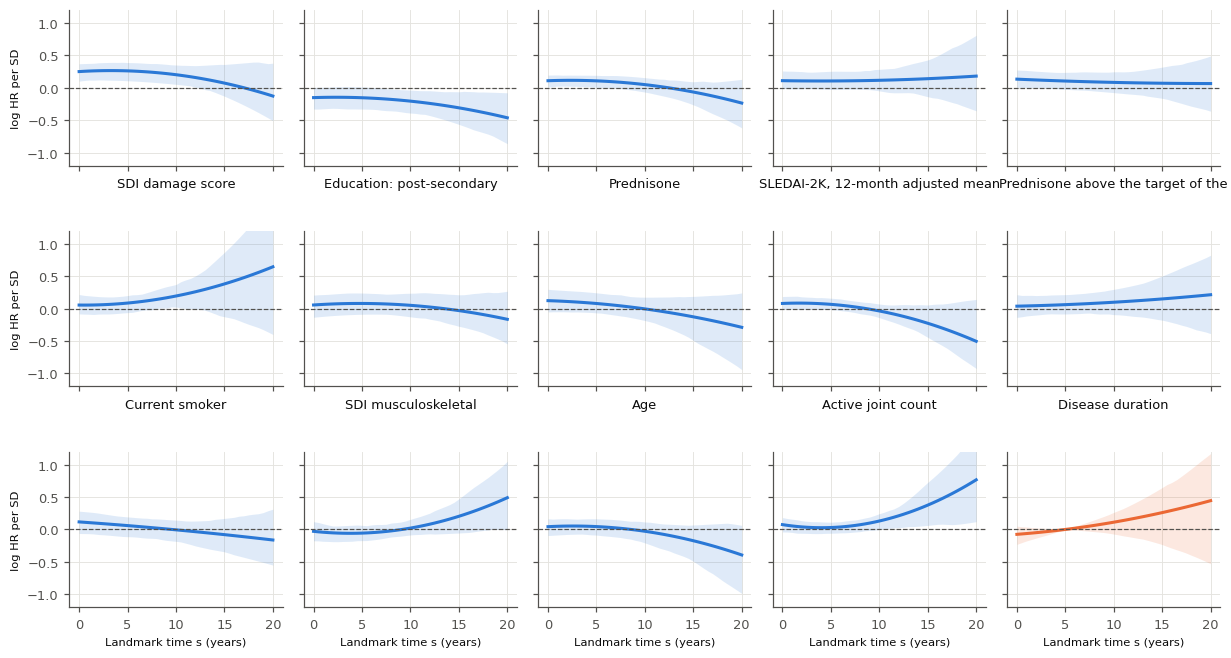

,Visits,Median risk (%),Median 95 % credible interval (%),Median width ÷ risk,"Probability the tier is right, median",Visits with that probability ≥ 0.8 (%)
Low,6926,1.708948,1.1-2.5,0.771589,1.0,88.478198
Raised,4012,5.101306,3.3-7.5,0.79614,0.8675,62.911266
High,2038,12.902077,8.3-19.1,0.793123,0.96625,69.970559


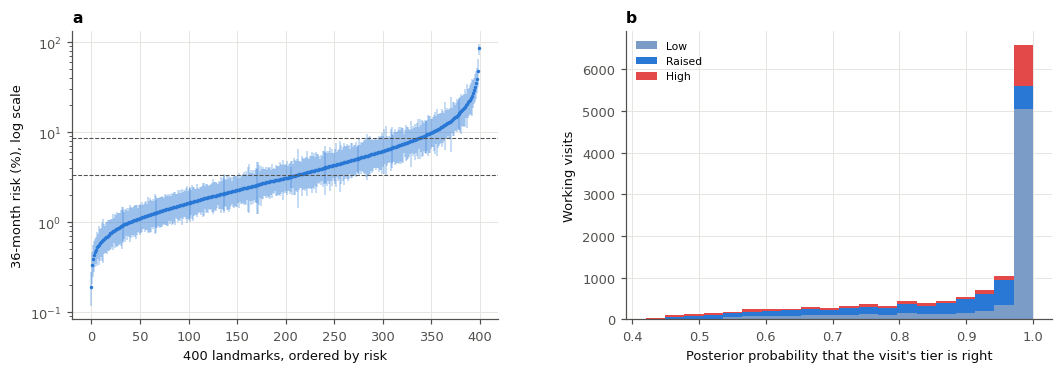

**What this means.**

* **(a) Visit frequency.** Weighted to represent patient-time instead of visits, HazReg's AUROC is
  0.746 (unweighted 0.744), its calibration slope 0.92
  and O/E 0.96. The comparisons between models (table above) keep their direction: the
  results do not rest on frequent attenders counting more.
* **(b) Landmark supermodel.** Letting every effect and a main effect follow the landmark clock changes the AUROC by
  +0.002 (-0.011 to +0.014) and the IPA by
  +0.0060. The largest changes between s = 0 and s = 15 years are for current smoker, active joint count, fatigue;
  the bootstrap interval of that change excludes no change for 2 of 14 inputs (prednisone (mg/day), active joint count).
  Those paths are not flat, which a model with one coefficient for every s cannot follow. Effects are penalised here, so the bands are narrower than unpenalised ones would be.
* **(c) Interval-censored onsets.** Fitting the hazards as if the onset could have happened anywhere between the two
  visits changes the AUROC by -0.000 (-0.001 to
  +0.000): the dating of the onset at the visit that records it does not matter for the
  ranking.
* **(d) Bayesian HazReg.** With fixed weakly informative priors in place of a tuned penalty, the AUROC changes by
  -0.008 (-0.016 to -0.000). Its posterior gives each visit
  a credible interval: in the High tier the median interval is 8.3-19.1 %,
  and the tier is right with a median posterior probability of 0.97
  (78 %
  of all landmarks have a tier that is right with probability ≥ 0.8). Neighbouring tiers overlap, so the tier is best
  read as a band.

**No design check improves on HazReg** with an interval above 0 for both the AUROC and the IPA, so HazReg stays the reported model.

In [52]:
"""What the supermodel learned, and the Bayesian model's uncertainty for each visit."""
if "final_supermodel" not in STATE:
    STATE["final_supermodel"] = fit_procedure(np.arange(N_LAND), COMPACT_VARS + XS_COLS, SPLINE_VARS, seed=SEED)
    STATE["final_bayes"] = _fit_bayes(np.arange(N_LAND), half_life=FINAL.get("half_life"))
    _save_state()
_sm = STATE["final_supermodel"]


def _sm_boot(b):
    rng = np.random.RandomState(SEED + 8000 + b)
    rows = np.concatenate([PT_ROWS[ALL_PIDS[i]] for i in rng.randint(0, P_N, P_N)])
    m = fit_procedure(rows, COMPACT_VARS + XS_COLS, SPLINE_VARS, alphas=_sm["alphas"], seed=SEED + 8000 + b)
    return {"coef": m["coef"][0], "names": list(m["prep"].names), "scale": m["prep"].scale, "sd": m["prep"].sd}


if "supermodel_boot" not in STATE or len(STATE["supermodel_boot"]) < BOOT_REFITS:
    STATE["supermodel_boot"] = Parallel(n_jobs=N_JOBS)(delayed(_sm_boot)(b) for b in range(BOOT_REFITS))
    _save_state()
_SM_S = np.arange(0.0, XS_CAP + 0.5, 0.5)                               # landmark time s, in years
_sm_f = (np.minimum(_SM_S, XS_CAP) - XS_CENTRE) / 10


def _sm_paths(coef, names, scale, sd):
    """log HR per SD of each input along s (the linear term), and gamma(s), from the onset coefficients of one fit. A
    coefficient per unit of an interaction column = b x scale / SD(column), so per SD of the input: x SD(input)."""
    ix = {n: i for i, n in enumerate(names)}
    per = lambda n: coef[ix[n]] * scale[ix[n]] / sd[n]
    out = {c: coef[ix[c]] * scale[ix[c]] + (per(f"{c}__XS") * _sm_f + per(f"{c}__XS2") * _sm_f ** 2) * sd[c] for c in XS_VARS}
    out["Landmark time"] = per("LM_S1") * _sm_f + per("LM_S2") * _sm_f ** 2
    return out


_SM_POINT = _sm_paths(_sm["coef"][0], list(_sm["prep"].names), _sm["prep"].scale, _sm["prep"].sd)
_sm_b = [_sm_paths(b["coef"], b["names"], b["scale"], b["sd"]) for b in STATE["supermodel_boot"]]
_SM_BAND = {k: np.percentile([b[k] for b in _sm_b], [2.5, 97.5], axis=0) for k in _SM_POINT}
_sm_i = {y: int(np.argmin(np.abs(_SM_S - y))) for y in (0, 5, 10, 15, 20)}
_sm_lab = lambda k: DISPLAY.get(k, k)
_sm_dif = {k: np.array([b[k][_sm_i[15]] - b[k][_sm_i[0]] for b in _sm_b]) for k in XS_VARS}
XS_TABLE = pd.DataFrame({_sm_lab(c): {**{f"Onset HR per SD at s = {y}": np.exp(_SM_POINT[c][_sm_i[y]]) for y in (0, 5, 10, 15)},
                                      "Ratio of HRs, s = 15 against s = 0": np.exp(_SM_POINT[c][_sm_i[15]] - _SM_POINT[c][_sm_i[0]]),
                                      "95 % bootstrap interval": "{:.2f}-{:.2f}".format(*np.exp(np.percentile(_sm_dif[c], [2.5, 97.5])))}
                         for c in XS_VARS}).T
XS_TABLE = XS_TABLE.loc[XS_TABLE["Ratio of HRs, s = 15 against s = 0"].astype(float).apply(lambda v: -abs(np.log(v))).sort_values().index]
display(XS_TABLE.map(lambda v: round(v, 2) if isinstance(v, float) else v))
save_table(XS_TABLE, "design_supermodel_interactions")
_SM_NOTFLAT = [_sm_lab(c) for c in XS_VARS if np.prod(np.percentile(_sm_dif[c], [2.5, 97.5])) > 0]

_sm_keys = sorted(XS_VARS, key=lambda c: -abs(_SM_POINT[c][_sm_i[5]])) + ["Landmark time"]
_sm_rows = int(np.ceil(len(_sm_keys) / 5))
fig, axes = plt.subplots(_sm_rows, 5, figsize=(13.5, 2.35 * _sm_rows), sharex=True, sharey=True, gridspec_kw={"hspace": 0.42, "wspace": 0.1})
axes = np.atleast_2d(axes)
for ax in axes.ravel()[len(_sm_keys):]:
    ax.set_visible(False)
for ax, k in zip(axes.ravel(), _sm_keys):
    _col = C2 if k == "Landmark time" else C1
    ax.fill_between(_SM_S, *_SM_BAND[k], color=_col, alpha=0.15, lw=0)
    ax.plot(_SM_S, _SM_POINT[k], color=_col, lw=2)
    ax.axhline(0, color=INK_2, lw=0.8, ls="--")
    _ttl = "γ(s), landmark time main effect" if k == "Landmark time" else _sm_lab(k).split(" (recency")[0].split(", recency")[0]
    ax.set_title(_ttl[:34], loc="left", fontsize=7.5)
    ax.set_ylim(-1.2, 1.2)
for ax in axes[-1]:
    ax.set_xlabel("Landmark time s (years)", fontsize=7.5)
    ax.tick_params(labelbottom=True)
for ax in axes[:, 0]:
    ax.set_ylabel("log HR per SD", fontsize=7.5)
save_fig("design_supermodel_paths")

_bd = bayes_risk_draws(STATE["final_bayes"], n=BAYES_DRAWS, seed=SEED)          # (draws, landmarks)
_bm = _bd.mean(0)
_lo, _hi = np.percentile(_bd, [2.5, 97.5], axis=0)
_tier_pt = np.digitize(_bm, TIER_CUTS)
_p_same = (np.digitize(_bd, TIER_CUTS) == _tier_pt[None, :]).mean(0)
BAYES_UNC = pd.DataFrame({REL_TIER_LABELS[i]: {"Visits": int((_tier_pt == i).sum()),
                                                 "Median risk (%)": 100 * np.median(_bm[_tier_pt == i]),
                                                 "Median 95 % credible interval (%)": f"{100 * np.median(_lo[_tier_pt == i]):.1f}-{100 * np.median(_hi[_tier_pt == i]):.1f}",
                                                 "Median width ÷ risk": np.median(((_hi - _lo) / _bm)[_tier_pt == i]),
                                                 "Probability the tier is right, median": np.median(_p_same[_tier_pt == i]),
                                                 "Visits with that probability ≥ 0.8 (%)": 100 * (_p_same[_tier_pt == i] >= 0.8).mean()}
                          for i in range(len(REL_TIER_LABELS)) if (_tier_pt == i).any()}).T
display(BAYES_UNC.round(2))
save_table(BAYES_UNC.round(3), "design_bayesian_uncertainty")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4), gridspec_kw={"wspace": 0.3})
ax = axes[0]
_o = np.argsort(_bm)
_sel = _o[np.linspace(0, len(_o) - 1, 400).astype(int)]
ax.vlines(np.arange(len(_sel)), 100 * _lo[_sel], 100 * _hi[_sel], color=C1, alpha=0.35, lw=1)
ax.plot(np.arange(len(_sel)), 100 * _bm[_sel], ".", color=C1, ms=2.5)
for c_ in TIER_CUTS:
    ax.axhline(100 * c_, color=INK_2, lw=0.7, ls="--")
ax.set_yscale("log"); ax.set_xlabel("400 landmarks, ordered by risk"); ax.set_ylabel("36-month risk (%), log scale")
ax.set_title("a  Posterior mean and 95 % credible interval (dashed: tier boundaries)", loc="left", fontsize=8.5)
ax = axes[1]
ax.hist([_p_same[_tier_pt == i] for i in range(len(REL_TIER_LABELS))], bins=20, stacked=True,
        color=["#9ec5f0", "#7a9cc6", C1, "#e34948"][-len(REL_TIER_LABELS):], label=REL_TIER_LABELS)
ax.set_xlabel("Posterior probability that the visit's tier is right"); ax.set_ylabel("Working visits")
ax.legend(fontsize=7); ax.set_title("b  How sure is each visit's tier?", loc="left", fontsize=8.5)
save_fig("design_bayesian_uncertainty")

_ds = {n: paired(n, "HazReg") for n in DESIGN_NAMES[1:]}
_di = {n: paired(n, "HazReg", "IPA") for n in DESIGN_NAMES[1:]}
_clear = [n for n in DESIGN_NAMES[1:] if _ds[n][1] > 0 and _di[n][1] > 0]
_iw = IIVW_RES["HazReg"]
say(f"""
**What this means.**

* **(a) Visit frequency.** Weighted to represent patient-time instead of visits, HazReg's AUROC is
  {_iw['AUROC'][0]:.3f} (unweighted {CV_RES['HazReg']['AUROC'][0]:.3f}), its calibration slope {_iw['Calibration slope'][0]:.2f}
  and O/E {_iw['O/E'][0]:.2f}. The comparisons between models (table above) {"keep their direction" if np.sign(_dw('HazReg', 'First visit', 'IPA')[0]) == np.sign(paired('HazReg', 'First visit', 'IPA')[0]) else "change direction"}: the
  results do not rest on frequent attenders counting more.
* **(b) Landmark supermodel.** Letting every effect and a main effect follow the landmark clock changes the AUROC by
  {_ds['Supermodel'][0]:+.3f} ({_ds['Supermodel'][1]:+.3f} to {_ds['Supermodel'][2]:+.3f}) and the IPA by
  {_di['Supermodel'][0]:+.4f}. The largest changes between s = 0 and s = 15 years are for {", ".join(XS_TABLE.index[:3]).lower()};
  the bootstrap interval of that change excludes no change for {len(_SM_NOTFLAT)} of {len(XS_VARS)} inputs{(" (" + ", ".join(_SM_NOTFLAT).lower() + ")") if _SM_NOTFLAT else ""}.
  {"Flat paths justify using one model for every s." if len(_SM_NOTFLAT) <= 1 else "Those paths are not flat, which a model with one coefficient for every s cannot follow."} Effects are penalised here, so the bands are narrower than unpenalised ones would be.
* **(c) Interval-censored onsets.** Fitting the hazards as if the onset could have happened anywhere between the two
  visits changes the AUROC by {_ds['Interval-censored'][0]:+.3f} ({_ds['Interval-censored'][1]:+.3f} to
  {_ds['Interval-censored'][2]:+.3f}): the dating of the onset at the visit that records it does not matter for the
  ranking.
* **(d) Bayesian HazReg.** With fixed weakly informative priors in place of a tuned penalty, the AUROC changes by
  {_ds['Bayesian'][0]:+.3f} ({_ds['Bayesian'][1]:+.3f} to {_ds['Bayesian'][2]:+.3f}). Its posterior gives each visit
  a credible interval: in the High tier the median interval is {BAYES_UNC.iloc[-1]['Median 95 % credible interval (%)']} %,
  and the tier is right with a median posterior probability of {BAYES_UNC.iloc[-1]['Probability the tier is right, median']:.2f}
  ({BAYES_UNC['Visits with that probability ≥ 0.8 (%)'].mul(BAYES_UNC['Visits']).sum() / BAYES_UNC['Visits'].sum():.0f} %
  of all landmarks have a tier that is right with probability ≥ 0.8). Neighbouring tiers overlap, so the tier is best
  read as a band.

{"**" + ", ".join(_clear) + " improve" + ("s" if len(_clear) == 1 else "") + " both the AUROC and the IPA with intervals above 0**; this would justify changing the reported model." if _clear else "**No design check improves on HazReg** with an interval above 0 for both the AUROC and the IPA, so HazReg stays the reported model."}
""")

### 3.8.5 Landmarks every 6 months against a landmark at every working visit

> **The question.** The model predicts once every 6 months (Section 1.4). Would it predict better at those same
> moments if it had been **trained on every working visit**, as in the design this one replaces? Training on every
> visit uses about four times as many rows, but they overlap, frequent attenders weigh more, and the rows are not the
> ones the model is used on.

HazReg is fitted on every working visit of the training patients (same inputs and tuning) and scored
at the 6-monthly landmarks of the test patients, on the same patient splits as HazReg. Both are therefore evaluated
on the same rows. Its intervals restart at every visit, so it is a time-dependent hazard model, time since the landmark is
not its clock, and its hazards stay flat. Section 3.8.7 gives the landmark version.

In [53]:
"""HazReg trained on every working visit, scored at the 6-monthly landmarks of the same test patients."""


def _fit_visit_level(tr_p, seed):
    rows = np.concatenate([PT_ROWS[p] for p in tr_p if p in PT_ROWS])
    return fit_procedure(rows, seed=seed)


if "cv_Every-visit training" not in STATE:
    t0 = time.time()
    _splits = cv_tasks(lambda a, b, s: (a, b, s))
    use_data("main_visits")
    _n_vis = N_LAND
    _vm = Parallel(n_jobs=N_JOBS)(delayed(_fit_visit_level)(a, s) for _, (a, b, s) in _splits)
    use_data("main")
    _o, _oo = np.full((CV_REPEATS, N_LAND, 2), np.nan), np.full((CV_REPEATS, N_LAND, 2), np.nan)
    for (r, (a, b, s)), m in zip(_splits, _vm):
        te = np.concatenate([PT_ROWS[p] for p in b])
        _o[r, te], _oo[r, te] = predict_eta(m, te), predict_eta(m, te, own_year=True)
    # intervals restart at every visit, so time since the landmark is not this model's clock: its hazards stay flat
    STATE["cv_Every-visit training"] = {"pred": _o, "pred_own": _oo, "base": np.zeros((CV_REPEATS, N_LAND, 2, NB), np.float32),
                                        "tuned": [m["alphas"] for m in _vm], "n_visits": _n_vis}
    _save_state()
    print(f"Every-visit training: cross-validated in {(time.time() - t0) / 60:.1f} min")
_ev = "Every-visit training"
P_CV[_ev] = cv_risk(_ev)
CV_RES[_ev], CV_ARR[_ev] = summarise(P_CV[_ev], p_abs=P_ABS.get(_ev))
FLAGS[_ev] = alarm_flags(P_CV[_ev])
PT_RES[_ev], PT_ARR[_ev] = pt_summary(PT_EVAL, P_CV[_ev], FLAGS[_ev])
EV_TABLE = pd.concat([metrics_table(["HazReg", _ev]), pt_table(["HazReg", _ev])])
EV_TABLE.loc["Training rows (per full data set)"] = [f"{N_LAND:,} landmarks", f"{STATE['cv_' + _ev]['n_visits']:,} working visits"]
display(EV_TABLE)
save_table(EV_TABLE, "design_every_visit_training")
_de = {k: paired(_ev, "HazReg", k) for k in ["AUROC", "Within-era AUROC", "Log score"]}
say(f"""
**What this means.** Trained on every working visit ({STATE['cv_' + _ev]['n_visits']:,} rows instead of {N_LAND:,}) and
scored at the same 6-monthly landmarks, HazReg changes the AUROC by {fmt(_de['AUROC'])}, the within-era AUROC by
{fmt(_de['Within-era AUROC'])} and the log score by {fmt(_de['Log score'], 4)}.
{"Training on every visit does not help: the extra rows repeat the same patients and add no information about the outcome, so the simpler design costs nothing." if _de['AUROC'][1] < 0 < _de['AUROC'][2] or _de['AUROC'][2] < 0 else "Training on every visit helps at the landmarks: the extra rows carry information the 6-monthly landmarks lose. A model trained on every visit and used every 6 months is then the better tool."}
""")

,HazReg,Every-visit training
AUROC,0.744 (0.700 to 0.786),0.742 (0.699 to 0.785)
Within-era AUROC,0.733 (0.689 to 0.775),0.732 (0.689 to 0.775)
IPA,0.041 (0.009 to 0.068),0.027 (-0.019 to 0.064)
O/E,0.959 (0.787 to 1.139),0.901 (0.743 to 1.077)
Calibration slope,0.915 (0.752 to 1.105),0.790 (0.654 to 0.941)
Calibration intercept,-0.053 (-0.280 to 0.149),-0.127 (-0.360 to 0.086)
Patient C (time-matched),0.758 (0.717 to 0.798),0.766 (0.725 to 0.805)
Sensitivity,0.64 (0.57 to 0.72),0.63 (0.55 to 0.71)
Specificity,0.75 (0.72 to 0.78),0.74 (0.71 to 0.77)
Balanced accuracy,0.70 (0.66 to 0.74),0.68 (0.64 to 0.73)


**What this means.** Trained on every working visit (15,385 rows instead of 12,976) and
scored at the same 6-monthly landmarks, HazReg changes the AUROC by -0.002 (-0.014 to 0.009), the within-era AUROC by
-0.001 (-0.013 to 0.011) and the log score by -0.0013 (-0.0040 to 0.0014).
Training on every visit does not help: the extra rows repeat the same patients and add no information about the outcome, so the simpler design costs nothing.

### 3.8.6 How much should the onset hazard be shrunk?

> **The question.** With the penalty chosen by the inner cross-validation, HazReg's predictions were too timid
> (calibration slope above 1), which is what too heavy a ridge penalty does. The reported model therefore divides the
> tuned onset penalty by 3. Does that choice hold up against the tuned penalty itself and against lighter ones?

Each fold of the main cross-validation is refitted with its own tuned penalties and half-life, with the onset penalty
at the tuned value, at a third of it (the reported model), at a tenth and at a thirtieth. The other-exit hazard is left
as tuned. Compared with HazReg on the same splits.

In [54]:
"""HazReg with the tuned onset penalty, and lighter ones (same folds, same half-life and other-exit penalty)."""
PEN_DIVS = [1, 10, 30]                       # divisors of the tuned onset penalty; HazReg itself uses ONSET_PENALTY_DIV
_pen_name = lambda k: "Onset penalty as tuned" if k == 1 else f"Onset penalty ÷ {k}"


def _fold_pen(a, b, s, al, k):
    tr, te = _fold_rows(a, b)
    m = fit_procedure(tr, COMPACT_VARS, SPLINE_VARS, alphas=[al[0] * ONSET_PENALTY_DIV / k, al[1], al[2]], seed=s)
    return te, predict_eta(m, te), predict_eta(m, te, own_year=True), m["base"]


_tu_h = STATE["cv_HazReg"]["tuned"]
for k in PEN_DIVS:
    nm = _pen_name(k)
    if f"cv_{nm}" not in STATE:
        _sp = cv_tasks(lambda a, b, s: (a, b, s))
        res = Parallel(n_jobs=N_JOBS)(delayed(_fold_pen)(a, b, s, al, k) for (_, (a, b, s)), al in zip(_sp, _tu_h))
        _o, _oo = np.full((CV_REPEATS, N_LAND, 2), np.nan), np.full((CV_REPEATS, N_LAND, 2), np.nan)
        _b_pen = np.zeros((CV_REPEATS, N_LAND, 2, NB), np.float32)
        for (r, _), (te, e, eo, b_) in zip(_sp, res):
            _o[r, te], _oo[r, te], _b_pen[r, te] = e, eo, b_
        STATE[f"cv_{nm}"] = {"pred": _o, "pred_own": _oo, "base": _b_pen, "tuned": [None] * len(_sp)}
        _save_state()
    P_CV[nm] = cv_risk(nm)
    CV_RES[nm], CV_ARR[nm] = summarise(P_CV[nm], p_abs=P_ABS.get(nm))
_pen_names = ["HazReg"] + [_pen_name(k) for k in PEN_DIVS]
PEN_TABLE = metrics_table(_pen_names)
for nm in _pen_names[1:]:
    PEN_TABLE.loc["Log score − HazReg", nm] = fmt(paired(nm, "HazReg", "Log score"), 4)
    PEN_TABLE.loc["AUROC − HazReg", nm] = fmt(paired(nm, "HazReg", "AUROC"))
PEN_TABLE = PEN_TABLE.rename(columns={"HazReg": f"HazReg (tuned onset penalty ÷ {ONSET_PENALTY_DIV:g})"})
display(PEN_TABLE)
save_table(PEN_TABLE, "design_onset_penalty")
_p1 = _pen_name(1)
_d1p = paired("HazReg", _p1, "Log score")
_sl0, _sl1 = CV_RES["HazReg"]["Calibration slope"], CV_RES[_p1]["Calibration slope"]
say(f"""
**What this means.** With the onset penalty as tuned, the calibration slope is {fmt(_sl1, 2)}; with a third of it (the
reported model) {fmt(_sl0, 2)}. The reported model's log score differs from the tuned penalty's by {fmt(_d1p, 4)} and its
AUROC by {fmt(paired("HazReg", _p1))}. {"The lighter penalty brings the slope closer to 1 at no cost in ranking or log score, which is why it is used." if abs(_sl0[0] - 1) <= abs(_sl1[0] - 1) and _d1p[1] > -0.0005 else "On these data the lighter penalty does not bring the slope closer to 1 without a cost; the choice was made on the previous design and is reported as a deviation (Section 8.1.2)."}
Still lighter penalties ({", ".join(_pen_name(k) for k in PEN_DIVS[1:])}) show how far the shrinkage can be relaxed before the slope
falls below 1 (overfitting).
""")

,HazReg (tuned onset penalty ÷ 3),Onset penalty as tuned,Onset penalty ÷ 10,Onset penalty ÷ 30
AUROC,0.744 (0.700 to 0.786),0.746 (0.701 to 0.789),0.741 (0.698 to 0.782),0.738 (0.695 to 0.781)
Within-era AUROC,0.733 (0.689 to 0.775),0.735 (0.691 to 0.777),0.730 (0.686 to 0.774),0.728 (0.684 to 0.771)
IPA,0.041 (0.009 to 0.068),0.047 (0.021 to 0.068),0.034 (-0.004 to 0.064),0.029 (-0.011 to 0.061)
O/E,0.959 (0.787 to 1.139),0.959 (0.784 to 1.139),0.959 (0.786 to 1.138),0.958 (0.785 to 1.136)
Calibration slope,0.915 (0.752 to 1.105),1.091 (0.891 to 1.300),0.825 (0.670 to 1.012),0.784 (0.631 to 0.968)
Calibration intercept,-0.053 (-0.280 to 0.149),-0.051 (-0.279 to 0.149),-0.054 (-0.286 to 0.151),-0.055 (-0.290 to 0.145)
Log score − HazReg,NaN,0.0004 (-0.0009 to 0.0019),-0.0012 (-0.0024 to -0.0002),-0.0021 (-0.0039 to -0.0006)
AUROC − HazReg,NaN,0.002 (-0.003 to 0.007),-0.003 (-0.008 to 0.001),-0.006 (-0.013 to 0.001)


**What this means.** With the onset penalty as tuned, the calibration slope is 1.09 (0.89 to 1.30); with a third of it (the
reported model) 0.92 (0.75 to 1.11). The reported model's log score differs from the tuned penalty's by -0.0004 (-0.0019 to 0.0009) and its
AUROC by -0.002 (-0.007 to 0.003). On these data the lighter penalty does not bring the slope closer to 1 without a cost; the choice was made on the previous design and is reported as a deviation (Section 8.1.2).
Still lighter penalties (Onset penalty ÷ 10, Onset penalty ÷ 30) show how far the shrinkage can be relaxed before the slope
falls below 1 (overfitting).

### 3.8.7 The stacked training set

> **The question.** HazReg is trained on the stacked landmark set of the landmarking literature: each 6-monthly landmark
> is followed to s + 36 months with X(s) held fixed, so a patient's windows overlap. Would the same landmarks chained
> (each followed only to the next landmark, so every person-year is used once and the inputs update every 6 months)
> predict as well? And would stacking every working visit instead of the 6-month grid add anything?

| Training set | Landmarks | Follow-up of each |
|:--|:--|:--|
| **HazReg** | Every 6 months | To s + 36 months, X(s) fixed |
| **Chained, every 6 months** | Every 6 months | To the next landmark, at most s + 36 months |
| **Stacked, every working visit** | At every working visit | To s + 36 months, X(s) fixed |

A chained model's intervals are at most 6 months long, so the months 6-36 of its baseline rest on the few landmarks
whose next landmark was skipped. A patient seen often contributes more rows to the every-visit set, so sicker patients
count more there; the 6-month grid avoids that. Every model is fitted on the same training patients (tuning and baseline included) and scored on the
same 6-monthly landmarks of the same test patients. Section 3.10.1 gives their calibration by horizon. Patients are the unit of resampling and the folds, so the overlap does not
narrow any interval.

In [55]:
"""HazReg trained on overlapping landmark windows, scored at the 6-monthly landmarks of the same test patients."""
STACK_SETS = {"Chained, every 6 months": ("main_chain", LANDMARK_EVERY_MONTHS, False),
              "Stacked, every working visit": ("main_visit_stack", None, True)}
for _sk_key, _sk_every, _sk_st in STACK_SETS.values():
    if _sk_key not in DATA:
        use_data("main")
        derive(MAIN_END, every=_sk_every, stacked=_sk_st)
        DATA[_sk_key] = {k: globals()[k] for k in DATA_KEYS}
        CURRENT_DATA = _sk_key
use_data("main")
if "stack_models" not in STATE:
    STATE["stack_models"] = {}


def _fit_stack(tr_p, seed):
    return fit_procedure(np.concatenate([PT_ROWS[p] for p in tr_p if p in PT_ROWS]), seed=seed)


for _sk_name, (_sk_key, _, _) in STACK_SETS.items():
    if f"cv_{_sk_name}" not in STATE:
        t0 = time.time()
        _sk_sp = cv_tasks(lambda a, b, s: (a, b, s))
        use_data(_sk_key)
        _sk_n, _sk_on = N_LAND, int(D1.sum())
        _sk_m = Parallel(n_jobs=N_JOBS)(delayed(_fit_stack)(a, s) for _, (a, b, s) in _sk_sp)
        use_data("main")
        _sk_o, _sk_oo = np.full((CV_REPEATS, N_LAND, 2), np.nan), np.full((CV_REPEATS, N_LAND, 2), np.nan)
        _sk_b = np.zeros((CV_REPEATS, N_LAND, 2, NB), np.float32)
        for (r, (a, b, s)), m in zip(_sk_sp, _sk_m):
            te = np.concatenate([PT_ROWS[p] for p in b])
            _sk_o[r, te], _sk_oo[r, te], _sk_b[r, te] = predict_eta(m, te), predict_eta(m, te, own_year=True), m["base"]
        STATE[f"cv_{_sk_name}"] = {"pred": _sk_o, "pred_own": _sk_oo, "base": _sk_b, "tuned": [m["alphas"] for m in _sk_m],
                                   "n_rows": _sk_n, "n_onsets": _sk_on}
        STATE["stack_models"][_sk_name] = _sk_m
        _save_state()
        print(f"{_sk_name}: cross-validated in {(time.time() - t0) / 60:.1f} min")
_sk_names = list(STACK_SETS)
for n in _sk_names:
    P_CV[n] = cv_risk(n)
    CV_RES[n], CV_ARR[n] = summarise(P_CV[n], p_abs=P_ABS.get(n))
    FLAGS[n] = alarm_flags(P_CV[n])
    PT_RES[n], PT_ARR[n] = pt_summary(PT_EVAL, P_CV[n], FLAGS[n])
STACK_TABLE = pd.concat([metrics_table(["HazReg"] + _sk_names), pt_table(["HazReg"] + _sk_names)])
STACK_TABLE.loc["Training rows (per full data set)"] = [f"{N_LAND:,}"] + [f"{STATE['cv_' + n]['n_rows']:,}" for n in _sk_names]
STACK_TABLE.loc["Log score − HazReg"] = [""] + [fmt(paired(n, "HazReg", "Log score"), 4) for n in _sk_names]
STACK_TABLE.loc["AUROC − HazReg"] = [""] + [fmt(paired(n, "HazReg")) for n in _sk_names]
display(STACK_TABLE)
save_table(STACK_TABLE, "design_stacked_training")


def stack_verdict(n):
    """As good as HazReg: no clear loss in the AUROC or the log score, and a calibration slope at least as close to 1."""
    _a, _l = paired(n, "HazReg"), paired(n, "HazReg", "Log score")
    _sl = CV_RES[n]["Calibration slope"][0]
    return (_a[2] > 0) and (_l[2] > 0) and abs(_sl - 1) <= abs(CV_RES["HazReg"]["Calibration slope"][0] - 1)


_sk_txt = "; ".join(f"**{n}** ({STATE['cv_' + n]['n_rows']:,} rows): AUROC {fmt(paired(n, 'HazReg'))}, log score "
                    f"{fmt(paired(n, 'HazReg', 'Log score'), 4)}, calibration slope {fmt(CV_RES[n]['Calibration slope'], 2)} "
                    f"(HazReg {fmt(CV_RES['HazReg']['Calibration slope'], 2)})" for n in _sk_names)
_sk_ok = [n for n in _sk_names if stack_verdict(n)]
say(f"""
**What this means.** Against HazReg on the same landmarks: {_sk_txt}.
{"**" + ", ".join(_sk_ok) + " ranks and calibrates at least as well** (no clear loss in AUROC or log score, slope at least as close to 1), so the choice of training set does not drive the results." if _sk_ok else "Neither alternative training set ranks and calibrates at least as well as HazReg on these landmarks: the stacked 6-monthly set is kept."}
""")

,HazReg,"Chained, every 6 months","Stacked, every working visit"
AUROC,0.744 (0.700 to 0.786),0.741 (0.697 to 0.784),0.744 (0.700 to 0.786)
Within-era AUROC,0.733 (0.689 to 0.775),0.731 (0.688 to 0.774),0.734 (0.690 to 0.774)
IPA,0.041 (0.009 to 0.068),0.033 (-0.006 to 0.065),0.042 (0.012 to 0.069)
O/E,0.959 (0.787 to 1.139),0.994 (0.818 to 1.185),0.974 (0.798 to 1.153)
Calibration slope,0.915 (0.752 to 1.105),0.799 (0.660 to 0.952),0.921 (0.761 to 1.112)
Calibration intercept,-0.053 (-0.280 to 0.149),-0.016 (-0.244 to 0.189),-0.037 (-0.275 to 0.163)
Patient C (time-matched),0.758 (0.717 to 0.798),0.761 (0.720 to 0.801),0.756 (0.716 to 0.797)
Sensitivity,0.64 (0.57 to 0.72),0.64 (0.56 to 0.72),0.65 (0.57 to 0.73)
Specificity,0.75 (0.72 to 0.78),0.75 (0.72 to 0.78),0.74 (0.71 to 0.77)
Balanced accuracy,0.70 (0.66 to 0.74),0.70 (0.65 to 0.74),0.69 (0.65 to 0.73)


**What this means.** Against HazReg on the same landmarks: **Chained, every 6 months** (12,976 rows): AUROC -0.003 (-0.015 to 0.008), log score -0.0011 (-0.0038 to 0.0016), calibration slope 0.80 (0.66 to 0.95) (HazReg 0.92 (0.75 to 1.11)); **Stacked, every working visit** (15,385 rows): AUROC -0.000 (-0.007 to 0.006), log score 0.0002 (-0.0010 to 0.0014), calibration slope 0.92 (0.76 to 1.11) (HazReg 0.92 (0.75 to 1.11)).
**Stacked, every working visit ranks and calibrates at least as well** (no clear loss in AUROC or log score, slope at least as close to 1), so the choice of training set does not drive the results.

### 3.8.8 How old are the inputs?

> **The question.** At a landmark the inputs come from the last employed visit in the 12 months before it. Does the age
> of those inputs carry information beyond the inputs themselves?

The age of the inputs (years from that visit to the landmark, on the log scale) is added as an input, on the same patient
splits. The model is scored twice: **as recorded**, and with the age **set to 0**, which is how a clinic would score it,
because the inputs are always those of the visit being scored. Section 3.10.2 looks at the same question without
refitting, in the first 6 months after a landmark.

In [56]:
"""HazReg with the age of the inputs as an input: scored as recorded and with the age set to 0."""


def _fold_gap(a, b, s):
    tr, te = _fold_rows(a, b)
    m = fit_procedure(tr, COMPACT_VARS + ["GAP_YRS"], SPLINE_VARS, seed=s)
    return te, predict_eta(m, te), predict_eta(m, X=design(m, LAND_X.iloc[te].assign(GAP_YRS=0.0))), m["base"]


_gp_names = {"as recorded": "Age of inputs, as recorded", "at 0": "Age of inputs, scored at 0"}
if f"cv_{_gp_names['at 0']}" not in STATE:
    _gp_t = cv_tasks(lambda a, b, s: delayed(_fold_gap)(a, b, s))
    _gp_o, _gp_0 = np.full((CV_REPEATS, N_LAND, 2), np.nan), np.full((CV_REPEATS, N_LAND, 2), np.nan)
    _gp_b = np.zeros((CV_REPEATS, N_LAND, 2, NB), np.float32)
    for (r, _), (te, e_, e0_, b_) in zip(_gp_t, Parallel(n_jobs=N_JOBS)(t[1] for t in _gp_t)):
        _gp_o[r, te], _gp_0[r, te], _gp_b[r, te] = e_, e0_, b_
    STATE[f"cv_{_gp_names['as recorded']}"] = {"pred": _gp_o, "base": _gp_b, "tuned": []}
    STATE[f"cv_{_gp_names['at 0']}"] = {"pred": _gp_0, "base": _gp_b, "tuned": []}
    STATE["final_gap"] = fit_procedure(np.arange(N_LAND), COMPACT_VARS + ["GAP_YRS"], SPLINE_VARS, seed=SEED)
    _save_state()
for n in _gp_names.values():
    P_CV[n] = cv_risk(n)
    CV_RES[n], CV_ARR[n] = summarise(P_CV[n], p_abs=P_ABS.get(n))
GAP_TABLE = metrics_table(["HazReg"] + list(_gp_names.values()))
GAP_TABLE.loc["AUROC − HazReg"] = [""] + [fmt(paired(n, "HazReg")) for n in _gp_names.values()]
GAP_TABLE.loc["Log score − HazReg"] = [""] + [fmt(paired(n, "HazReg", "Log score"), 4) for n in _gp_names.values()]
display(GAP_TABLE)
save_table(GAP_TABLE, "design_input_age")
_gp_m = STATE["final_gap"]
_gp_ix = list(_gp_m["prep"].names).index("GAP_YRS")
GAP_HR = np.exp(_gp_m["coef"][:, _gp_ix] * _gp_m["prep"].scale[_gp_ix])
_gp_q = np.percentile(land["gap_days"] / MONTH_DAYS, [50, 90])
say(f"""
**What this means.** The inputs are a median {_gp_q[0]:.1f} months old at a landmark (90th percentile {_gp_q[1]:.1f}). Per SD of
their age, the penalised hazard ratio is {GAP_HR[0]:.2f} for onset and {GAP_HR[1]:.2f} for other exits. Scored as recorded, the AUROC
changes by {fmt(paired(_gp_names['as recorded'], 'HazReg'))}; scored at 0, as in clinic, by {fmt(paired(_gp_names['at 0'], 'HazReg'))},
with O/E {fmt(CV_RES[_gp_names['at 0']]['O/E'], 2)} (HazReg {fmt(CV_RES['HazReg']['O/E'], 2)}).
""")

,HazReg,"Age of inputs, as recorded","Age of inputs, scored at 0"
AUROC,0.744 (0.700 to 0.786),0.744 (0.700 to 0.786),0.744 (0.699 to 0.786)
Within-era AUROC,0.733 (0.689 to 0.775),0.733 (0.689 to 0.775),0.733 (0.689 to 0.775)
IPA,0.041 (0.009 to 0.068),0.041 (0.009 to 0.068),0.040 (0.008 to 0.068)
O/E,0.959 (0.787 to 1.139),0.959 (0.787 to 1.139),0.937 (0.769 to 1.113)
Calibration slope,0.915 (0.752 to 1.105),0.915 (0.751 to 1.104),0.921 (0.753 to 1.104)
Calibration intercept,-0.053 (-0.280 to 0.149),-0.053 (-0.280 to 0.149),-0.079 (-0.307 to 0.123)
AUROC − HazReg,,-0.000 (-0.001 to 0.000),-0.000 (-0.001 to 0.000)
Log score − HazReg,,-0.0000 (-0.0001 to 0.0001),-0.0001 (-0.0003 to 0.0002)


**What this means.** The inputs are a median 2.3 months old at a landmark (90th percentile 6.4). Per SD of
their age, the penalised hazard ratio is 0.98 for onset and 1.01 for other exits. Scored as recorded, the AUROC
changes by -0.000 (-0.001 to 0.000); scored at 0, as in clinic, by -0.000 (-0.001 to 0.000),
with O/E 0.94 (0.77 to 1.11) (HazReg 0.96 (0.79 to 1.14)).

## 3.9 What the model is predicting, whether more data would help, and a simple benchmark

### 3.9.1 Treatments as inputs: the estimand

> **The question.** Six inputs describe treatment (prednisone dose and whether it is above the target of the time,
> the treatment ladder, antimalarial, conventional immunosuppressant, advanced therapy). Treated patients are sicker,
> so these inputs carry risk partly because of *why* a patient is treated. Does the ranking depend on them?

**The estimand.** HazReg predicts the risk of work disability within 36 months **under the care that patients in this
clinic received during the development years**. It is not the risk the patient would have without treatment, and
its treatment coefficients are not effects of treatment: a positive one does not mean that the treatment causes work
loss. If care changes (for example, faster steroid tapering), the risk of a patient with the same record changes too.

The check below refits HazReg without the six treatment inputs, keeping disease activity, damage, symptoms and the
patient's background, and compares the two on the same splits.

In [57]:
"""HazReg without the treatment inputs: cross-validated on the same splits; what moves when treatment is removed."""
NOTX_VARS = [c for c in COMPACT_VARS if c not in TREATMENT_VARS]
NOTX_SPLINE = [c for c in SPLINE_VARS if c not in TREATMENT_VARS]
if "cv_HazReg without treatment" not in STATE:
    STATE["cv_HazReg without treatment"] = run_cv("haz", NOTX_VARS, NOTX_SPLINE)
    STATE["final_notx"] = fit_procedure(np.arange(N_LAND), NOTX_VARS, NOTX_SPLINE, seed=SEED)
    _save_state()
MODEL_COLORS["HazReg without treatment"] = "#9a988f"
P_CV["HazReg without treatment"] = cv_risk("HazReg without treatment")
CV_RES["HazReg without treatment"], CV_ARR["HazReg without treatment"] = summarise(P_CV["HazReg without treatment"], p_abs=P_ABS.get("HazReg without treatment"))
FLAGS["HazReg without treatment"] = alarm_flags(P_CV["HazReg without treatment"])
PT_RES["HazReg without treatment"], PT_ARR["HazReg without treatment"] = pt_summary(PT_EVAL, P_CV["HazReg without treatment"],
                                                                                    FLAGS["HazReg without treatment"])
_tx_names = ["HazReg", "HazReg without treatment"]
TX_TABLE = pd.concat([metrics_table(_tx_names), pt_table(_tx_names)])
TX_TABLE["Difference"] = ""
for k in ["AUROC", "Within-era AUROC", "IPA"]:
    TX_TABLE.loc[k, "Difference"] = fmt(paired("HazReg without treatment", "HazReg", k), 4 if k == "IPA" else 3)
TX_TABLE.loc["Patient C (time-matched)", "Difference"] = fmt(ppaired("HazReg without treatment", "HazReg"))
display(TX_TABLE)
save_table(TX_TABLE, "treatment_free_model")
_nx = STATE["final_notx"]
_ia, _ib = ({n: i for i, n in enumerate(m["prep"].names) if not n.endswith(("__NL", "__MISSING"))} for m in (FINAL, _nx))
TX_COEF = pd.DataFrame({"With treatment inputs: onset HR per SD": {DISPLAY[n]: np.exp(FINAL["coef"][0][i]) for n, i in _ia.items()},
                        "Without: onset HR per SD": {DISPLAY[n]: np.exp(_nx["coef"][0][i]) for n, i in _ib.items()}}).round(2)
display(TX_COEF)
save_table(TX_COEF, "treatment_free_coefficients")
_rho_tx = pd.Series(P_CV["HazReg"]).rank().corr(pd.Series(P_CV["HazReg without treatment"]).rank())
_dtx = paired("HazReg without treatment", "HazReg")
_tier_same = np.mean(rel_tier(P_CV["HazReg"]) == rel_tier(P_CV["HazReg without treatment"]))
say(f"""
**What this means.** Without the treatment inputs the AUROC changes by {_dtx[0]:+.3f} ({_dtx[1]:+.3f} to
{_dtx[2]:+.3f}); the two models' risks have a rank correlation of {_rho_tx:.2f}, and {100 * _tier_same:.0f} % of visits
fall in the same tier. {"Most of the ranking survives without treatment: it rests on disease activity, damage, symptoms and the patient's background, and the treatment inputs mainly stand in for how sick the patient is." if _dtx[1] > -0.03 else "The treatment inputs carry a substantial part of the ranking."}
Where a disease input's hazard ratio grows once treatment is removed (table), treatment was standing in for it.
""")

,HazReg,HazReg without treatment,Difference
AUROC,0.744 (0.700 to 0.786),0.732 (0.686 to 0.775),-0.012 (-0.031 to 0.006)
Within-era AUROC,0.733 (0.689 to 0.775),0.724 (0.678 to 0.766),-0.010 (-0.028 to 0.008)
IPA,0.041 (0.009 to 0.068),0.037 (0.005 to 0.063),-0.0037 (-0.0154 to 0.0086)
O/E,0.959 (0.787 to 1.139),0.953 (0.779 to 1.134),
Calibration slope,0.915 (0.752 to 1.105),0.933 (0.748 to 1.128),
Calibration intercept,-0.053 (-0.280 to 0.149),-0.052 (-0.279 to 0.165),
Patient C (time-matched),0.758 (0.717 to 0.798),0.749 (0.706 to 0.790),-0.009 (-0.029 to 0.010)
Sensitivity,0.64 (0.57 to 0.72),0.59 (0.51 to 0.67),
Specificity,0.75 (0.72 to 0.78),0.76 (0.73 to 0.78),
Balanced accuracy,0.70 (0.66 to 0.74),0.67 (0.63 to 0.72),


,With treatment inputs: onset HR per SD,Without: onset HR per SD
Age (years),1.06,1.06
Disease duration (years),1.06,1.09
"SLEDAI-2K, 12-month adjusted mean",1.12,1.15
SDI damage score,1.28,1.25
Prednisone (mg/day),1.10,NaN
Fatigue,1.07,1.11
Fibromyalgia (diagnosis or >= 11 tender points),1.00,0.94
Arthralgia,1.05,1.09
Dyspnoea,1.15,1.20
Treatment ladder (0 none - 3 advanced),1.02,NaN


**What this means.** Without the treatment inputs the AUROC changes by -0.012 (-0.031 to
+0.006); the two models' risks have a rank correlation of 0.92, and 82 % of visits
fall in the same tier. The treatment inputs carry a substantial part of the ranking.
Where a disease input's hazard ratio grows once treatment is removed (table), treatment was standing in for it.

### 3.9.2 Would more data help? A learning curve

> **The question.** Every model family reaches about the same ranking (Sections 3.2 and 3.5). Is that ceiling set by
> the number of patients, or by what the routine record contains?

Within each training fold, HazReg (tuning included) is refitted on 20 %, 40 %, 60 %, 80 % and 100 % of the training
patients, drawn at random within those with and without an onset, and scored on the same test fold. If the curve is
still rising at 100 %, more patients would help; if it has flattened, the limit is the predictors.

,"Training patients with an onset, mean","AUROC, mean","AUROC − 100 %, mean",± 1.96 SE,"Log score − 100 %, mean"
Share of training patients,,,,,
0.2,23.0,0.6908,-0.0527,0.0146,-0.0120
0.4,46.0,0.7135,-0.0300,0.0110,-0.0043
0.6,68.0,0.7322,-0.0113,0.0084,-0.0020
0.8,91.0,0.7386,-0.0049,0.0057,-0.0004
1.0,114.0,0.7435,0.0000,0.0000,0.0000


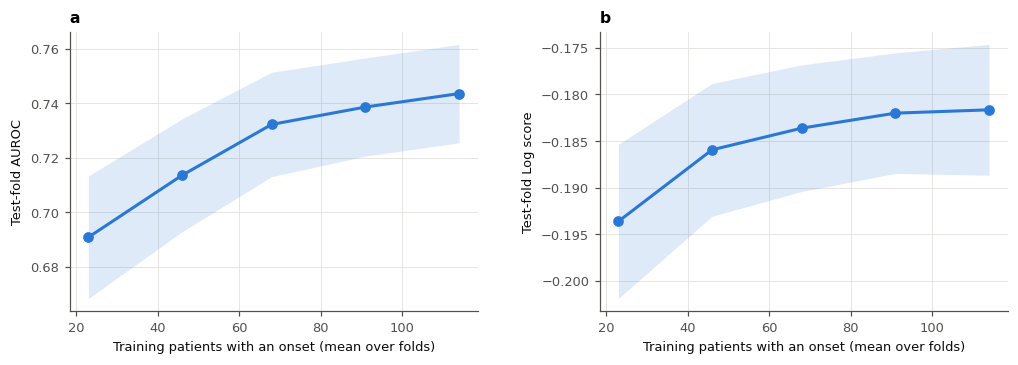

**What this means.** Going from 80 % to 100 % of the training patients changes the test AUROC by +0.005 on
average, and from 40 % to 100 % by +0.030. The curve has nearly flattened: adding patients like these would raise the ranking only a little. The ceiling is set mainly by what the routine record contains, which is why new kinds of information (the SF-36, Section 3.7) move it and new model families do not.

In [58]:
"""Learning curve: HazReg on growing shares of each training fold, scored on the same test fold."""


def _fold_metrics(te, p):
    k = W_IP[te] > 0
    y, w, pp = Y_IP[te][k], W_IP[te][k], np.clip(p[k], 1e-6, 1 - 1e-6)
    return {"AUROC": float(wauc(y, pp, w[None, :])[0]),
            "Log score": float(np.sum(w * (y * np.log(pp) + (1 - y) * np.log1p(-pp))) / w.sum())}


def _cv_fold_learn(tr_p, te_p, seed):
    rng = np.random.RandomState(seed)
    ev = np.array([PID_EVENT[PID_INDEX[p]] for p in tr_p])
    order = {g: rng.permutation(np.flatnonzero(ev == g)) for g in (0, 1)}
    _, te = _fold_rows(tr_p, te_p)
    out = []
    for f in LEARN_FRACS:
        keep = np.concatenate([order[g][:max(2, int(round(f * len(order[g]))))] for g in (0, 1)])
        tr = np.concatenate([PT_ROWS[p] for p in tr_p[keep]])
        m = fit_procedure(tr, seed=seed)
        out.append({"Share of training patients": f, "Training patients": len(keep),
                    "Training patients with an onset": int(ev[keep].sum()), **_fold_metrics(te, cif(predict_eta(m, te), base=m["base"]))})
    return out


if "learning_curve" not in STATE:
    _lt = cv_tasks(lambda a, b, s: delayed(_cv_fold_learn)(a, b, s))
    _lr = Parallel(n_jobs=N_JOBS)(t[1] for t in _lt)
    STATE["learning_curve"] = pd.DataFrame([dict(r, Fold=i) for i, rr in enumerate(_lr) for r in rr])
    _save_state()
LC = STATE["learning_curve"]
_full = LC[LC["Share of training patients"] == 1.0].set_index("Fold")
LC = LC.join(_full[["AUROC", "Log score"]], on="Fold", rsuffix=" at 100 %")
LC["AUROC − 100 %"] = LC["AUROC"] - LC["AUROC at 100 %"]
LC["Log score − 100 %"] = LC["Log score"] - LC["Log score at 100 %"]
_g = LC.groupby("Share of training patients")
LC_TABLE = pd.DataFrame({"Training patients with an onset, mean": _g["Training patients with an onset"].mean().round(0),
                         "AUROC, mean": _g["AUROC"].mean(), "AUROC − 100 %, mean": _g["AUROC − 100 %"].mean(),
                         "± 1.96 SE": 1.96 * _g["AUROC − 100 %"].std() / np.sqrt(_g.size()),
                         "Log score − 100 %, mean": _g["Log score − 100 %"].mean()}).round(4)
display(LC_TABLE)
save_table(LC_TABLE, "learning_curve")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"wspace": 0.3})
for ax, k in zip(axes, ["AUROC", "Log score"]):
    m_, se_ = _g[k].mean(), _g[k].std() / np.sqrt(_g.size())
    x_ = LC_TABLE["Training patients with an onset, mean"].values
    ax.fill_between(x_, m_ - 1.96 * se_, m_ + 1.96 * se_, color=C1, alpha=0.15, lw=0)
    ax.plot(x_, m_, "-o", color=C1)
    ax.set_xlabel("Training patients with an onset (mean over folds)"); ax.set_ylabel(f"Test-fold {k}")
    ax.set_title(f"{'ab'[['AUROC', 'Log score'].index(k)]}  {k} by training size", loc="left", fontsize=9)
save_fig("learning_curve")
_last = LC_TABLE.loc[0.8, "AUROC − 100 %, mean"]
_half = LC_TABLE.loc[0.4, "AUROC − 100 %, mean"] if 0.4 in LC_TABLE.index else np.nan
say(f"""
**What this means.** Going from 80 % to 100 % of the training patients changes the test AUROC by {-_last:+.3f} on
average, and from 40 % to 100 % by {-_half:+.3f}. {"The curve has nearly flattened: adding patients like these would raise the ranking only a little. The ceiling is set mainly by what the routine record contains, which is why new kinds of information (the SF-36, Section 3.7) move it and new model families do not." if abs(_last) < 0.005 else "The curve is still rising: more patients of the same kind would still improve the ranking."}
""")

### 3.9.3 A benchmark a clinician could apply without a model

A rule built **from the literature, not from these data**: one point for each risk factor reported consistently in
studies of work disability in SLE, at a conventional cut-off. Older age (≥ 50), no post-secondary education, active
disease (12-month adjusted mean SLEDAI-2K ≥ 4), any organ damage (SDI ≥ 1), fatigue, and prednisone above 7.5 mg/day
(the EULAR maintenance target). The rule is not fitted, so it needs no cross-validation; HazReg is cross-validated.
A missing input counts as the factor being absent.

In [59]:
"""The literature rule: points, its ranking against HazReg's (same visits, same resamples)."""
_ops = {">=": np.greater_equal, ">": np.greater, "==": np.equal}
LIT_POINTS = pd.DataFrame({lab: _ops[op](LAND_X[c].astype(float).values, v) & LAND_X[c].notna().values
                           for lab, (c, op, v) in LIT_RULE.items()}).astype(int)
LIT_SCORE = LIT_POINTS.sum(axis=1).values
P_CV["Literature rule"] = (LIT_SCORE + 0.5) / (len(LIT_RULE) + 1)         # a rank-preserving map to (0, 1)
MODEL_COLORS["Literature rule"] = "#c98500"
_A = metric_arrays(P_CV["Literature rule"], W_BOOT[:, ROW_PIDX])
CV_ARR["Literature rule"] = _A
CV_RES["Literature rule"] = {k: ci_of(v) for k, v in _A.items()}
FLAGS["Literature rule"] = alarm_flags(P_CV["Literature rule"])
PT_RES["Literature rule"], PT_ARR["Literature rule"] = pt_summary(PT_EVAL, P_CV["Literature rule"], FLAGS["Literature rule"])
_lr_rows = []
for s_ in range(len(LIT_RULE) + 1):
    m_ = LIT_SCORE == s_
    if m_.sum() < 20:
        continue
    _lr_rows.append({"Points": s_, "Visits (%)": 100 * m_.mean(),
                     "Observed 36-mo onset (%)": 100 * np.sum((W_IP * Y_IP)[m_]) / m_.sum(),
                     "HazReg mean predicted (%)": 100 * P_CV["HazReg"][m_].mean()})
LIT_BY_SCORE = pd.DataFrame(_lr_rows).set_index("Points").round(2)
display(LIT_BY_SCORE)
LIT_TABLE = pd.DataFrame({
    "Literature rule": {"AUROC": fmt(CV_RES["Literature rule"]["AUROC"]), "Within-era AUROC": fmt(CV_RES["Literature rule"]["Within-era AUROC"]),
                        "Patient C (time-matched)": fmt(PT_RES["Literature rule"]["C"])},
    "HazReg (cross-validated)": {"AUROC": fmt(CV_RES["HazReg"]["AUROC"]), "Within-era AUROC": fmt(CV_RES["HazReg"]["Within-era AUROC"]),
                                 "Patient C (time-matched)": fmt(PT_RES["HazReg"]["C"])},
    "HazReg − rule": {"AUROC": fmt(paired("HazReg", "Literature rule")),
                      "Within-era AUROC": fmt(paired("HazReg", "Literature rule", "Within-era AUROC")),
                      "Patient C (time-matched)": fmt(ppaired("HazReg", "Literature rule"))}})
LIT_TABLE.loc["Share of visits with each factor (%)", "Literature rule"] = "; ".join(
    f"{k}: {100 * v:.0f}" for k, v in LIT_POINTS.mean().items())
display(LIT_TABLE)
save_table(LIT_TABLE, "literature_rule_benchmark")
_dl_ = paired("HazReg", "Literature rule")
say(f"""
**What this means.** The six-factor rule ranks visits with an AUROC of {CV_RES['Literature rule']['AUROC'][0]:.3f};
HazReg's is {_dl_[0]:+.3f} higher ({_dl_[1]:+.3f} to {_dl_[2]:+.3f}), and its patient C is
{ppaired('HazReg', 'Literature rule')[0]:+.3f} higher. {"The model earns its complexity over what a clinician could count on their fingers." if _dl_[1] > 0 else "The model does not clearly beat a rule a clinician could apply by hand."}
""")

,Visits (%),Observed 36-mo onset (%),HazReg mean predicted (%)
Points,,,
0,7.03,1.02,1.67
1,24.76,1.70,2.73
2,33.74,3.92,4.13
3,24.00,6.56,6.85
4,8.71,14.13,12.02
5,1.68,20.25,17.06


,Literature rule,HazReg (cross-validated),HazReg − rule
AUROC,0.707 (0.662 to 0.746),0.744 (0.700 to 0.786),0.038 (0.001 to 0.076)
Within-era AUROC,0.702 (0.657 to 0.741),0.733 (0.689 to 0.775),0.031 (-0.004 to 0.068)
Patient C (time-matched),0.710 (0.659 to 0.753),0.758 (0.717 to 0.798),0.048 (0.008 to 0.087)
Share of visits with each factor (%),Age >= 50: 26; No post-secondary education: 46...,NaN,NaN


**What this means.** The six-factor rule ranks visits with an AUROC of 0.707;
HazReg's is +0.038 higher (+0.001 to +0.076), and its patient C is
+0.048 higher. The model earns its complexity over what a clinician could count on their fingers.

## 3.10 How far ahead does the ranking hold?

> **The question.** The tool reports a 36-month risk. How well do the same scores rank patients for nearer and more
> distant horizons, and does a score read at the current visit keep its lead over one read at the first visit?

Two views, on the cross-validated predictions of the same patient splits:

| View | Cases | Controls | Reads as |
|:--|:--|:--|:--|
| **Cumulative, at 12, 24, 36 and 48 months** | Onset at any time up to the horizon | Known to be free of onset at the horizon | The risk the tool would report at that horizon (36 months: the tool's own) |
| **Mutually exclusive 12-month intervals, 0-12 to 84-96 months** | Onset inside the interval; each onset landmark counts in one interval only | Known to be free of onset at the end of the interval | How far ahead the score still separates who leaves work *then* |

**The risks.** HazReg, First visit and the LSTM estimate hazards, so the same fit gives the cumulative incidence at any
horizon, under the baseline of Section 2.1, whose last band (from 24 months) is fitted on follow-up to 36 months and
extrapolated beyond it: the observed / expected ratio by horizon checks that baseline, and Section 3.10.1 compares it
with hazards that stay flat. LogReg has no hazards and is refitted for each horizon (at HazReg's half-life, the penalty tuned in each
fold). An interval ending at *b* months is scored with the risk at *b*.

**Which landmarks count.** A horizon is evaluated only on landmarks whose whole window lies inside the data (before the
end of the extract and age 65), and the censoring weights are re-estimated on those landmarks, so they correct for
patients who left the clinic and not for windows that could not have been completed. Long horizons therefore rest on
earlier landmarks, whose recording of exits was fuller: a comparison across horizons is also a comparison across eras.
The table gives the median landmark year behind each interval. Competing exits count as controls, as everywhere.

,Landmarks,Onset landmarks,HazReg: AUROC,HazReg: O/E,First visit: AUROC,First visit: O/E,LSTM: AUROC,LSTM: O/E,LightGBM: AUROC,LightGBM: O/E,LogReg: AUROC,LogReg: O/E,HazReg: calibration slope
Horizon (months),,,,,,,,,,,,,
12,11810,249,0.760 (0.721 to 0.796),0.94 (0.77 to 1.11),0.636 (0.585 to 0.688),0.94 (0.77 to 1.11),0.758 (0.719 to 0.798),0.94 (0.76 to 1.11),0.742 (0.700 to 0.780),0.95 (0.78 to 1.11),0.763 (0.722 to 0.800),0.94 (0.77 to 1.10),1.00 (0.86 to 1.19)
24,10778,425,0.751 (0.710 to 0.791),0.90 (0.74 to 1.06),0.622 (0.568 to 0.679),0.90 (0.74 to 1.06),0.750 (0.707 to 0.791),0.89 (0.73 to 1.05),0.726 (0.681 to 0.765),0.89 (0.73 to 1.05),0.753 (0.712 to 0.791),0.89 (0.73 to 1.05),0.96 (0.79 to 1.15)
36,9847,562,0.739 (0.698 to 0.781),0.86 (0.70 to 1.02),0.610 (0.553 to 0.670),0.85 (0.69 to 1.01),0.740 (0.698 to 0.782),0.85 (0.69 to 1.00),0.719 (0.675 to 0.761),0.84 (0.69 to 1.00),0.738 (0.698 to 0.778),0.84 (0.68 to 1.00),0.89 (0.74 to 1.07)
48,9007,672,0.726 (0.684 to 0.772),0.82 (0.67 to 0.97),0.599 (0.537 to 0.661),0.81 (0.65 to 0.96),0.728 (0.683 to 0.774),0.80 (0.65 to 0.95),0.708 (0.663 to 0.753),0.80 (0.65 to 0.95),0.723 (0.680 to 0.766),0.78 (0.64 to 0.93),0.84 (0.67 to 1.02)


,Onset landmarks,Patients with an onset,Control landmarks,Median landmark year,HazReg: AUROC,First visit: AUROC,LSTM: AUROC,LightGBM: AUROC,LogReg: AUROC,HazReg − First visit,LSTM − HazReg,LightGBM − HazReg,LogReg − HazReg
Interval (months),,,,,,,,,,,,,
0-12,249,131,11561,2009,0.760 (0.721 to 0.796),0.636 (0.585 to 0.688),0.758 (0.719 to 0.798),0.742 (0.700 to 0.780),0.763 (0.722 to 0.800),0.124 (0.082 to 0.167),-0.002 (-0.014 to 0.012),-0.018 (-0.042 to 0.004),0.003 (-0.010 to 0.016)
12-24,184,99,10353,2008,0.739 (0.688 to 0.785),0.605 (0.548 to 0.667),0.739 (0.686 to 0.786),0.704 (0.648 to 0.753),0.743 (0.694 to 0.790),0.135 (0.087 to 0.186),-0.000 (-0.012 to 0.013),-0.035 (-0.063 to -0.007),0.004 (-0.005 to 0.014)
24-36,151,82,9285,2008,0.706 (0.655 to 0.755),0.583 (0.514 to 0.650),0.711 (0.656 to 0.762),0.697 (0.644 to 0.745),0.711 (0.661 to 0.759),0.122 (0.064 to 0.182),0.005 (-0.009 to 0.018),-0.009 (-0.044 to 0.024),0.005 (-0.005 to 0.015)
36-48,132,70,8335,2007,0.684 (0.623 to 0.742),0.568 (0.490 to 0.634),0.686 (0.621 to 0.742),0.670 (0.608 to 0.725),0.676 (0.616 to 0.735),0.117 (0.054 to 0.183),0.001 (-0.015 to 0.019),-0.014 (-0.053 to 0.026),-0.008 (-0.022 to 0.006)
48-60,114,62,7506,2006,0.680 (0.606 to 0.746),0.566 (0.487 to 0.639),0.674 (0.604 to 0.738),0.663 (0.591 to 0.729),0.673 (0.600 to 0.739),0.114 (0.047 to 0.187),-0.006 (-0.026 to 0.017),-0.017 (-0.057 to 0.020),-0.007 (-0.027 to 0.014)
60-72,96,52,6717,2006,0.637 (0.555 to 0.710),0.544 (0.454 to 0.629),0.629 (0.546 to 0.696),0.618 (0.541 to 0.688),0.638 (0.552 to 0.709),0.093 (0.007 to 0.176),-0.008 (-0.030 to 0.012),-0.019 (-0.058 to 0.017),0.001 (-0.023 to 0.024)
72-84,82,44,5950,2005,0.606 (0.513 to 0.691),0.489 (0.393 to 0.583),0.610 (0.519 to 0.693),0.606 (0.518 to 0.691),0.616 (0.526 to 0.705),0.117 (0.033 to 0.209),0.004 (-0.016 to 0.021),-0.000 (-0.042 to 0.034),0.010 (-0.020 to 0.039)
84-96,73,39,5247,2004,0.587 (0.499 to 0.683),0.485 (0.391 to 0.584),0.596 (0.514 to 0.679),0.592 (0.509 to 0.675),0.594 (0.494 to 0.690),0.103 (0.015 to 0.188),0.009 (-0.015 to 0.033),0.004 (-0.052 to 0.050),0.006 (-0.022 to 0.038)


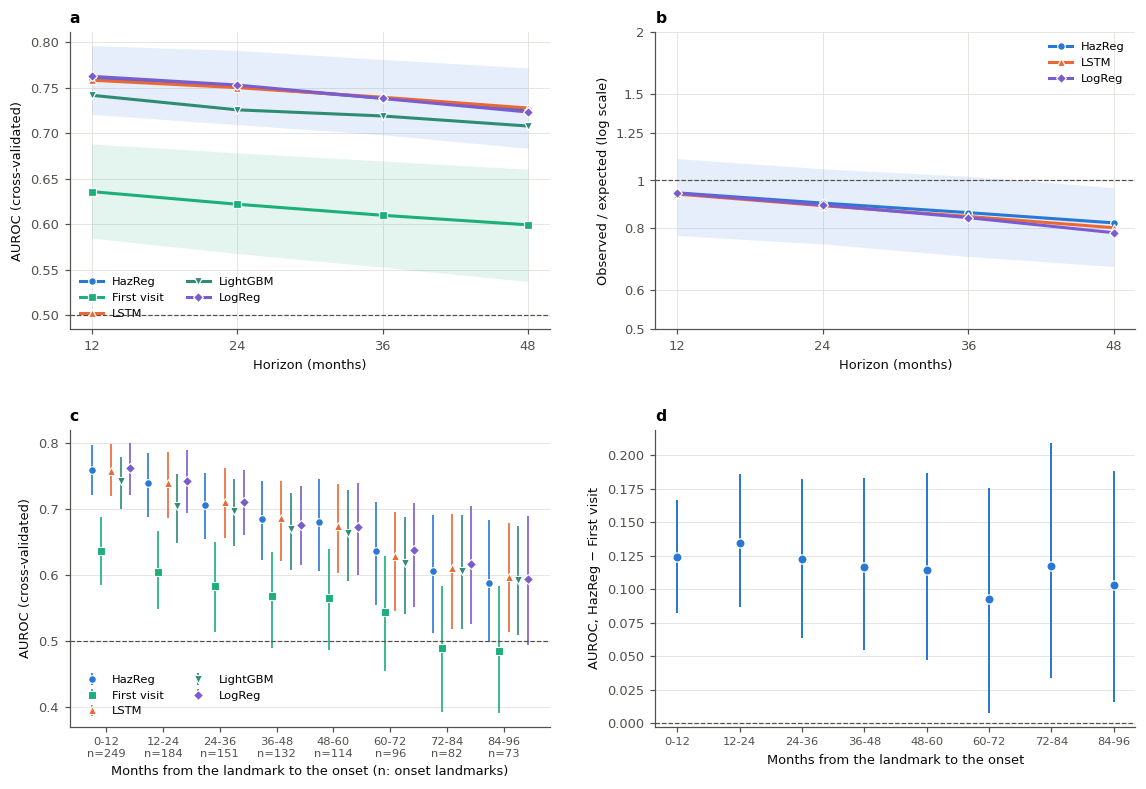

**What this means.**

* **Cumulative.** HazReg's AUROC is 0.760 (0.721 to 0.796) at 12 months and 0.726 (0.684 to 0.772) at 48 months
  (at 36 months 0.739 here, on the landmarks with a complete 36-month window, against
  0.744 on all landmarks in Section 3.1).
* **By interval.** Onsets 0-12 months ahead are ranked at 0.760 (0.721 to 0.796); onsets
  84-96 months ahead at 0.587 (0.499 to 0.683), on 73 onset
  landmarks.
* **Current visit against first visit.** HazReg − First visit is 0.124 (0.082 to 0.167) in the first interval and 0.103 (0.015 to 0.188) in the last. A lead that
  holds over the intervals points to a stable risk that the current visit measures better; a lead that closes only at long
  range points to information that goes stale.
* **Absolute risk by horizon.** HazReg's O/E is 0.94 (0.77 to 1.11) at 12 months, 0.90 (0.74 to 1.06) at 24 and 0.82 (0.67 to 0.97)
  at 48. Beyond 36 months the baseline is extrapolated, so a ratio that moves away from 1 there means the absolute
  risk should not be read at that horizon. Section 3.10.1 shows what the baseline changes.
* **Reading across horizons.** Each horizon rests on the landmarks that could complete it. The interval
  84-96 has a median landmark year of 2004, against
  2009 for 0-12, so a difference between them is not only distance.

In [60]:
"""Horizons: cumulative risk at 12, 24, 36 and 48 months, and mutually exclusive 12-month intervals to 96 months."""
HZ_CUM = [12, 24, 36, 48]
HZ_BINS = [(a, a + 12) for a in range(0, 96, 12)]
HZ_ALL = sorted(set(HZ_CUM) | {b for _, b in HZ_BINS} | {6})          # 6 months: the check of Section 3.10.2
HZ_MODELS = ["HazReg", "First visit", "LSTM", "LightGBM", "LogReg"]


def horizon_target(months):
    """(y, w) on all landmarks: onset within `months`, and censoring weights estimated on the landmarks whose whole window
    lies inside the data (the others get weight 0)."""
    y, w = np.zeros(N_LAND), np.zeros(N_LAND)
    rows = np.flatnonzero(land["admin_days"].values >= round(months * MONTH_DAYS))
    if len(rows):
        y[rows], w[rows] = ipcw_weights(T_ALL, C_ALL, rows=rows, months=months, Z=CENS_Z, strata=ERA_LAB)
    return y, w


HZ_T = {m: horizon_target(m) for m in HZ_ALL}


def _fold_lr_h(tr_p, te_p, seed, m, h):
    tr, te = _fold_rows(tr_p, te_p)
    y, w = HZ_T[m]
    return te, predict_logreg(fit_logreg(tr, y=y, w=w, seed=seed, half_life=h), te)


if "cv_horizon_lr" not in STATE:
    t0 = time.time()
    _hz_lr = {}
    for m in HZ_ALL:
        _hz_tk = cv_tasks(lambda a, b, s: delayed(_fold_lr_h)(a, b, s, m, FINAL.get("half_life")))
        _hz_o = np.full((CV_REPEATS, N_LAND), np.nan)
        for (r, _), (te, pr) in zip(_hz_tk, Parallel(n_jobs=N_JOBS)(t[1] for t in _hz_tk)):
            _hz_o[r, te] = pr
        _hz_lr[m] = _hz_o.mean(0)
    STATE["cv_horizon_lr"] = _hz_lr
    _save_state()
    print(f"LogReg refitted at {len(HZ_ALL)} horizons in {(time.time() - t0) / 60:.1f} min")


def horizon_risk(name, m):
    """Cross-validated risk of model `name` at `m` months."""
    if name == "LogReg":
        return STATE["cv_horizon_lr"][m]
    return cv_cif(STATE[f"cv_{name}"], "pred", m)


_Wh = W_BOOT[:501, ROW_PIDX]
HORIZON_ARR, HORIZON_POINT, _hz_rows, _hz_cal = {}, {}, [], {}
for m in HZ_CUM:
    y, w = HZ_T[m]
    _hz_on = (y == 1) & (w > 0)
    row = {"Horizon (months)": m, "Landmarks": int((w > 0).sum()), "Onset landmarks": int(_hz_on.sum())}
    for n in HZ_MODELS:
        A = metric_arrays(horizon_risk(n, m), _Wh, y, w)
        HORIZON_ARR[(n, m)] = A
        HORIZON_POINT[(n, m)] = A["AUROC"][0]
        row[f"{n}: AUROC"] = fmt(ci_of(A["AUROC"]))
        row[f"{n}: O/E"] = fmt(ci_of(A["O/E"]), 2)
    _hz_sl = np.array([wcalibration(y, horizon_risk("HazReg", m), w * _Wh[b])[0] for b in range(min(100, len(_Wh) - 1) + 1)])
    _hz_cal[m] = (_hz_sl[0], *np.percentile(_hz_sl[1:], [2.5, 97.5]))
    row["HazReg: calibration slope"] = fmt(_hz_cal[m], 2)
    _hz_rows.append(row)
HORIZON_CUM = pd.DataFrame(_hz_rows).set_index("Horizon (months)")
display(HORIZON_CUM)
save_table(HORIZON_CUM, "horizons_cumulative")

HORIZON_BIN_ARR, HORIZON_BIN_POINT, HORIZON_BIN_N, _hb_rows = {}, {}, {}, []
for a, b in HZ_BINS:
    y, w = HZ_T[b]
    wi = np.where((y == 1) & (T_ALL <= round(a * MONTH_DAYS)), 0.0, w)      # an earlier onset is in an earlier interval
    _hz_on = (y == 1) & (wi > 0)
    HORIZON_BIN_N[(a, b)] = int(_hz_on.sum())
    row = {"Interval (months)": f"{a}-{b}", "Onset landmarks": int(_hz_on.sum()), "Patients with an onset": len(np.unique(PID_ALL[_hz_on])),
           "Control landmarks": int(((y == 0) & (wi > 0)).sum()),
           "Median landmark year": int(np.median(LAND_YEAR[wi > 0])) if (wi > 0).any() else np.nan}
    for n in HZ_MODELS:
        A = metric_arrays(horizon_risk(n, b), _Wh, y, wi)
        HORIZON_BIN_ARR[(n, (a, b))] = A
        HORIZON_BIN_POINT[(n, (a, b))] = A["AUROC"][0]
        row[f"{n}: AUROC"] = fmt(ci_of(A["AUROC"]))
    for n0, n1 in [("HazReg", "First visit"), ("LSTM", "HazReg"), ("LightGBM", "HazReg"), ("LogReg", "HazReg")]:
        row[f"{n0} − {n1}"] = fmt(ci_of(HORIZON_BIN_ARR[(n0, (a, b))]["AUROC"] - HORIZON_BIN_ARR[(n1, (a, b))]["AUROC"]))
    _hb_rows.append(row)
HORIZON_BINS = pd.DataFrame(_hb_rows).set_index("Interval (months)")
display(HORIZON_BINS)
save_table(HORIZON_BINS, "horizons_mutually_exclusive")

_hz_col = {"HazReg": C1, "First visit": C3, "LSTM": C2, "LightGBM": MODEL_COLORS["LightGBM"], "LogReg": "#7a5cd0"}
_hz_mk = {"HazReg": "o", "First visit": "s", "LSTM": "^", "LightGBM": "v", "LogReg": "D"}
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2), gridspec_kw={"hspace": 0.34, "wspace": 0.22})
ax = axes[0, 0]
for n in HZ_MODELS:
    t = np.array([ci_of(HORIZON_ARR[(n, m)]["AUROC"]) for m in HZ_CUM])
    if n in ("HazReg", "First visit"):
        ax.fill_between(HZ_CUM, t[:, 1], t[:, 2], color=_hz_col[n], alpha=0.12, lw=0)
    ax.plot(HZ_CUM, t[:, 0], "-", marker=_hz_mk[n], ms=5, lw=2, color=_hz_col[n], mec="white", mew=0.8, label=n)
ax.set_xticks(HZ_CUM); ax.set_xlabel("Horizon (months)"); ax.set_ylabel("AUROC (cross-validated)")
ax.axhline(0.5, color=INK_2, ls="--", lw=0.8); ax.legend(fontsize=7.5, loc="lower left", ncol=2)
ax.set_title("a  Cumulative: onset by the horizon (bands: 95 % CI)", loc="left", fontsize=9)
ax = axes[0, 1]
for n in ["HazReg", "LSTM", "LogReg"]:
    t = np.array([ci_of(HORIZON_ARR[(n, m)]["O/E"]) for m in HZ_CUM])
    if n == "HazReg":
        ax.fill_between(HZ_CUM, t[:, 1], t[:, 2], color=_hz_col[n], alpha=0.12, lw=0)
    ax.plot(HZ_CUM, t[:, 0], "-", marker=_hz_mk[n], ms=5, lw=2, color=_hz_col[n], mec="white", mew=0.8, label=n)
ax.axhline(1, color=INK_2, ls="--", lw=0.8); ax.set_xticks(HZ_CUM); ax.set_yscale("log")
ax.set_yticks([0.5, 0.6, 0.8, 1, 1.25, 1.5, 2], ["0.5", "0.6", "0.8", "1", "1.25", "1.5", "2"]); ax.yaxis.set_minor_locator(plt.NullLocator())
ax.set_xlabel("Horizon (months)"); ax.set_ylabel("Observed / expected (log scale)"); ax.legend(fontsize=7.5)
ax.set_title("b  Does the baseline fit? (LogReg is refitted at each horizon)", loc="left", fontsize=9)
ax = axes[1, 0]
_hz_x = np.arange(len(HZ_BINS))
for j, n in enumerate(HZ_MODELS):
    t = np.array([ci_of(HORIZON_BIN_ARR[(n, k)]["AUROC"]) for k in HZ_BINS])
    xx = _hz_x + (j - 1.5) * 0.17
    ax.errorbar(xx, t[:, 0], yerr=[t[:, 0] - t[:, 1], t[:, 2] - t[:, 0]], fmt=_hz_mk[n], ms=5, color=_hz_col[n], ecolor=_hz_col[n],
                elinewidth=1.1, mec="white", mew=0.7, label=n)
ax.axhline(0.5, color=INK_2, ls="--", lw=0.8)
ax.set_xticks(_hz_x, [f"{a}-{b}\nn={HORIZON_BIN_N[(a, b)]}" for a, b in HZ_BINS], fontsize=7.5); ax.grid(axis="x", visible=False)
ax.set_xlabel("Months from the landmark to the onset (n: onset landmarks)"); ax.set_ylabel("AUROC (cross-validated)")
ax.legend(fontsize=7.5, loc="lower left", ncol=2); ax.set_title("c  Mutually exclusive intervals", loc="left", fontsize=9)
ax = axes[1, 1]
t = np.array([ci_of(HORIZON_BIN_ARR[("HazReg", k)]["AUROC"] - HORIZON_BIN_ARR[("First visit", k)]["AUROC"]) for k in HZ_BINS])
ax.errorbar(_hz_x, t[:, 0], yerr=[t[:, 0] - t[:, 1], t[:, 2] - t[:, 0]], fmt="o", ms=6, color=C1, elinewidth=1.3, mec="white", mew=0.8)
ax.axhline(0, color=INK_2, ls="--", lw=0.8)
ax.set_xticks(_hz_x, [f"{a}-{b}" for a, b in HZ_BINS], fontsize=7.5); ax.grid(axis="x", visible=False)
ax.set_xlabel("Months from the landmark to the onset"); ax.set_ylabel("AUROC, HazReg − First visit")
ax.set_title("d  What reading the current visit adds, by interval", loc="left", fontsize=9)
save_fig("horizons")

_hz_a0, _hz_a1 = HORIZON_ARR[("HazReg", HZ_CUM[0])]["AUROC"], HORIZON_ARR[("HazReg", HZ_CUM[-1])]["AUROC"]
_hz_oe = {m: ci_of(HORIZON_ARR[("HazReg", m)]["O/E"]) for m in HZ_CUM}
_hz_thin = [f"{a}-{b}" for a, b in HZ_BINS if HORIZON_BIN_N[(a, b)] < 20]
_hz_d0 = HORIZON_BINS["HazReg − First visit"].iloc[0]; _hz_d1 = HORIZON_BINS["HazReg − First visit"].iloc[-1]
say(f"""
**What this means.**

* **Cumulative.** HazReg's AUROC is {fmt(ci_of(_hz_a0))} at {HZ_CUM[0]} months and {fmt(ci_of(_hz_a1))} at {HZ_CUM[-1]} months
  (at 36 months {HORIZON_POINT[('HazReg', 36)]:.3f} here, on the landmarks with a complete 36-month window, against
  {CV_RES['HazReg']['AUROC'][0]:.3f} on all landmarks in Section 3.1).
* **By interval.** Onsets {HZ_BINS[0][0]}-{HZ_BINS[0][1]} months ahead are ranked at {HORIZON_BINS['HazReg: AUROC'].iloc[0]}; onsets
  {HZ_BINS[-1][0]}-{HZ_BINS[-1][1]} months ahead at {HORIZON_BINS['HazReg: AUROC'].iloc[-1]}, on {HORIZON_BIN_N[HZ_BINS[-1]]} onset
  landmarks.{f" Intervals with fewer than 20 onset landmarks ({', '.join(_hz_thin)}) are too thin to read one by one." if _hz_thin else ""}
* **Current visit against first visit.** HazReg − First visit is {_hz_d0} in the first interval and {_hz_d1} in the last. A lead that
  holds over the intervals points to a stable risk that the current visit measures better; a lead that closes only at long
  range points to information that goes stale.
* **Absolute risk by horizon.** HazReg's O/E is {fmt(_hz_oe[HZ_CUM[0]], 2)} at {HZ_CUM[0]} months, {fmt(_hz_oe[24], 2)} at 24 and {fmt(_hz_oe[HZ_CUM[-1]], 2)}
  at {HZ_CUM[-1]}. Beyond 36 months the baseline is extrapolated, so a ratio that moves away from 1 there means the absolute
  risk should not be read at that horizon. Section 3.10.1 shows what the baseline changes.
* **Reading across horizons.** Each horizon rests on the landmarks that could complete it. The interval
  {HZ_BINS[-1][0]}-{HZ_BINS[-1][1]} has a median landmark year of {HORIZON_BINS['Median landmark year'].iloc[-1]:.0f}, against
  {HORIZON_BINS['Median landmark year'].iloc[0]:.0f} for {HZ_BINS[0][0]}-{HZ_BINS[0][1]}, so a difference between them is not only distance.
""")

### 3.10.1 The baseline in time since the landmark, and the follow-up cap

> **The question.** A flat hazard over 36 months misfits if onsets come early after a landmark. What do the stacked
> training set and the hazard multipliers for months 0-6, 6-12, 12-24 and 24 onwards (Section 2.1) do to the absolute
> risks and to the ranking?

Three versions of HazReg on the same splits. **Chained, flat hazards**: each landmark followed to the next one only
(follow-up not capped), hazards flat. **Flat**: the stacked set, hazards flat. **HazReg** (reported): the stacked set,
with the baseline. The chained model with a baseline of Section 3.8.7 is shown beside them. Horizons of 36 months or
less are inside the data used for the baseline. Longer ones are extrapolated.

Person-years  Events  Multiplier of the hazard 95 % bootstrap interval
Exit       Months since the landmark                                                                        
Onset      0-6                             6254.08     136                      1.14               1.04-1.22
           6-12                            5795.94     115                      1.06               0.98-1.11
           12-24                          10411.56     186                      0.96               0.91-1.01
           24 onwards                      9042.41     151                      0.91               0.82-1.00
Other exit 0-6                             6254.08     215                      1.15               1.08-1.24
           6-12                            5795.94     184                      1.06               1.01-1.12
           12-24                          10411.56     293                      0.94               0.90-0.98
           24 onwards                      9042.41     247                      0.92               0.85-0.97

,"Chained, flat hazards","HazReg, flat",HazReg,"Chained, every 6 months"
AUROC,0.742 (0.698 to 0.785),0.744 (0.700 to 0.786),0.744 (0.700 to 0.786),0.741 (0.697 to 0.784)
Within-era AUROC,0.732 (0.689 to 0.775),0.733 (0.689 to 0.775),0.733 (0.689 to 0.775),0.731 (0.688 to 0.774)
IPA,0.027 (-0.019 to 0.064),0.041 (0.008 to 0.068),0.041 (0.009 to 0.068),0.033 (-0.006 to 0.065)
O/E,0.873 (0.718 to 1.042),0.949 (0.779 to 1.127),0.959 (0.787 to 1.139),0.994 (0.818 to 1.185)
Calibration slope,0.810 (0.667 to 0.964),0.918 (0.752 to 1.104),0.915 (0.752 to 1.105),0.799 (0.660 to 0.952)
Calibration intercept,-0.165 (-0.399 to 0.046),-0.064 (-0.292 to 0.137),-0.053 (-0.280 to 0.149),-0.016 (-0.244 to 0.189)
AUROC − HazReg,-0.002 (-0.014 to 0.009),-0.000 (-0.000 to 0.000),,-0.003 (-0.015 to 0.008)
Log score − HazReg,-0.0014 (-0.0042 to 0.0013),-0.0000 (-0.0001 to 0.0001),,-0.0011 (-0.0038 to 0.0016)
O/E at 12 months,0.92 (0.76 to 1.08),1.03 (0.84 to 1.20),0.94 (0.77 to 1.11),1.06 (0.86 to 1.24)
O/E at 24 months,0.84 (0.70 to 0.99),0.92 (0.76 to 1.08),0.90 (0.74 to 1.06),0.98 (0.81 to 1.15)


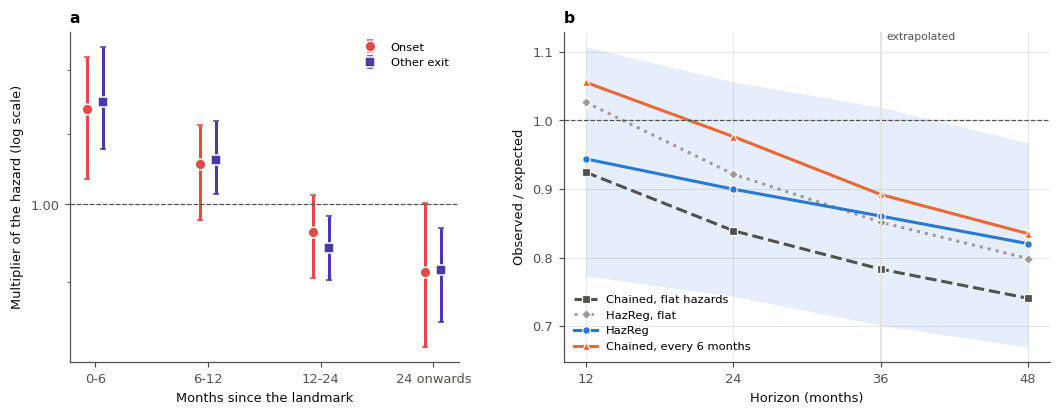

**What this means.**

* **The baseline in time since the landmark.** The final model's onset hazard is multiplied by
  1.14 in months 0-6, 1.06 in months 6-12, 0.96 in months 12-24, 0.91 in months 24 onwards.
* **The absolute risks.** O/E at 12 / 24 / 36 months is 0.92 (0.76 to 1.08) / 0.84 (0.70 to 0.99) / 0.78 (0.64 to 0.92)
  for the chained model with flat hazards and 0.94 (0.77 to 1.11) / 0.90 (0.74 to 1.06) / 0.86 (0.70 to 1.02) for HazReg. Beyond the data of the baseline, at 48 months, it is 0.82 (0.67 to 0.97).
* **The ranking is essentially unchanged.** HazReg against the same fit with flat hazards: AUROC -0.000 (-0.000 to 0.000),
  Spearman correlation of the risks 1.0000. So this supports reading the absolute risk as secondary to the ranking; it does not
  replace that reading.
* **The band cut points in percent move** although the bands are the same percentiles: Raised and High start at
  3.4 % and 9.6 % in the chained model with flat hazards, 3.4 % and 8.6 % now.
* **The stacked set alone** (chained against stacked, both flat) changes the AUROC by 0.002 (-0.009 to 0.014).

In [61]:
"""What the baseline and the follow-up cap change: multipliers, ranking, O/E by horizon."""


def _fold_prev(a, b, s):
    tr, te = _fold_rows(a, b)
    m = fit_procedure(tr, dt=INT_YRS_ALL, d1=D1_ALL, d2=D2_ALL, seed=s)
    return te, predict_eta(m, te)


if "cv_Chained, flat hazards" not in STATE:
    _bl_t = cv_tasks(lambda a, b, s: delayed(_fold_prev)(a, b, s))
    _bl_o = np.full((CV_REPEATS, N_LAND, 2), np.nan)
    for (r, _), (te, e_) in zip(_bl_t, Parallel(n_jobs=N_JOBS)(t[1] for t in _bl_t)):
        _bl_o[r, te] = e_
    STATE["cv_Chained, flat hazards"] = {"pred": _bl_o, "base": np.zeros((CV_REPEATS, N_LAND, 2, NB), np.float32), "tuned": []}
    _save_state()
STATE["cv_HazReg, flat"] = {"pred": STATE["cv_HazReg"]["pred"], "base": np.zeros_like(STATE["cv_HazReg"]["base"]), "tuned": []}
for n in ["Chained, flat hazards", "HazReg, flat"]:
    P_CV[n] = cv_risk(n)
    CV_RES[n], CV_ARR[n] = summarise(P_CV[n])
_bl_names = ["Chained, flat hazards", "HazReg, flat", "HazReg", _sk_names[0]]

# ---- the multipliers of the final model, with the bootstrap refits' intervals
_bl_lab = [f"{a}-{b}" for a, b in zip(BASELINE_EDGES, BASELINE_EDGES[1:])] + [f"{BASELINE_EDGES[-1]} onwards"]
_bl_b = np.array([b["base"] for b in BOOT])
_bl_expo = np.minimum(np.maximum(INT_YRS[:, None] - _BASE_LO, 0.0), _BASE_WIDTH)
_bl_band = np.searchsorted(_BASE_LO[1:], INT_YRS, side="left")
BASELINE_TABLE = pd.DataFrame([{"Exit": _c, "Months since the landmark": _bl_lab[j], "Person-years": _bl_expo[:, j].sum(),
                                "Events": int(_d[_bl_band == j].sum()),
                                "Multiplier of the hazard": np.exp(FINAL["base"][k, j]),
                                "95 % bootstrap interval": "{:.2f}-{:.2f}".format(*np.exp(np.percentile(_bl_b[:, k, j], [2.5, 97.5])))}
                               for k, (_c, _d) in enumerate([("Onset", D1), ("Other exit", D2)]) for j in range(NB)]).set_index(["Exit", "Months since the landmark"])
display(BASELINE_TABLE.round(2))
save_table(BASELINE_TABLE, "baseline_multipliers")

BASELINE_COMPARE = metrics_table(_bl_names)
BASELINE_COMPARE.loc["AUROC − HazReg"] = [fmt(paired(n, "HazReg")) if n != "HazReg" else "" for n in _bl_names]
BASELINE_COMPARE.loc["Log score − HazReg"] = [fmt(paired(n, "HazReg", "Log score"), 4) if n != "HazReg" else "" for n in _bl_names]
_bl_hz = [m for m in HZ_CUM if m <= 48]
_bl_oe = {}
for n in _bl_names:
    for m in _bl_hz:
        _y, _w = HZ_T[m]
        _bl_oe[(n, m)] = ci_of(metric_arrays(horizon_risk(n, m), _Wh, _y, _w)["O/E"])
    _sl_ = {m: wcalibration(HZ_T[m][0], horizon_risk(n, m), HZ_T[m][1])[0] for m in (12, 24, 36)}
    for m in _bl_hz:
        BASELINE_COMPARE.loc[f"O/E at {m} months", n] = fmt(_bl_oe[(n, m)], 2)
    for m in (12, 24, 36):
        BASELINE_COMPARE.loc[f"Calibration slope at {m} months", n] = f"{_sl_[m]:.2f}"
display(BASELINE_COMPARE)
save_table(BASELINE_COMPARE, "baseline_comparison")
_bl_rho = stats.spearmanr(P_CV["HazReg"], P_CV["HazReg, flat"])[0]
_bl_cut = {n: np.quantile(P_CV[n], REL_TIER_SHARES) for n in ["Chained, flat hazards", "HazReg"]}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"wspace": 0.24, "width_ratios": [1, 1.25]})
ax = axes[0]
_bl_x = np.arange(NB)
for k, (_c, _col, _mk) in enumerate([("Onset", LEFT_C, "o"), ("Other exit", OTHER_C, "s")]):
    _pt = np.exp(FINAL["base"][k])
    _lo, _hi = np.exp(np.percentile(_bl_b[:, k], [2.5, 97.5], axis=0))
    ax.errorbar(_bl_x + (k - 0.5) * 0.14, _pt, yerr=[_pt - _lo, _hi - _pt], fmt=_mk, color=_col, ms=7, capsize=2, mec="white", mew=1, label=_c)
ax.axhline(1, color=INK_2, ls="--", lw=0.8)
ax.set_xticks(_bl_x, _bl_lab); ax.set_xlabel("Months since the landmark"); ax.set_ylabel("Multiplier of the hazard (log scale)")
ax.set_yscale("log"); ax.yaxis.set_major_formatter(plt.ScalarFormatter()); ax.yaxis.set_minor_formatter(plt.NullFormatter()); ax.grid(axis="x", visible=False)
ax.legend(fontsize=7.5); ax.set_title("a  The baseline of the final model (95 % bootstrap intervals)", loc="left", fontsize=9)
ax = axes[1]
_bl_sty = {"Chained, flat hazards": (INK_2, "s", "--"), "HazReg, flat": ("#9e9c95", "D", ":"), "HazReg": (C1, "o", "-"), _sk_names[0]: (C2, "^", "-")}
for n in _bl_names:
    _t = np.array([_bl_oe[(n, m)] for m in _bl_hz])
    if n == "HazReg":
        ax.fill_between(_bl_hz, _t[:, 1], _t[:, 2], color=C1, alpha=0.12, lw=0)
    ax.plot(_bl_hz, _t[:, 0], color=_bl_sty[n][0], marker=_bl_sty[n][1], ls=_bl_sty[n][2], ms=5, lw=2, mec="white", mew=0.8, label=n)
ax.axhline(1, color=INK_2, ls="--", lw=0.8); ax.axvline(H, color=GRID_C, lw=1.2)
ax.text(H + 0.5, ax.get_ylim()[1], "extrapolated", fontsize=7, va="top", color=INK_2)
ax.set_xticks(_bl_hz); ax.set_xlabel("Horizon (months)"); ax.set_ylabel("Observed / expected")
ax.legend(fontsize=7.5); ax.set_title("b  Observed / expected by horizon (band: HazReg, 95 % CI)", loc="left", fontsize=9)
save_fig("baseline_time_since_landmark")

_bl_e = lambda n, m: fmt(_bl_oe[(n, m)], 2)
say(f"""
**What this means.**

* **The baseline in time since the landmark.** The final model's onset hazard is multiplied by
  {", ".join(f"{np.exp(FINAL['base'][0, j]):.2f} in months {_bl_lab[j]}" for j in range(NB))}.
* **The absolute risks.** O/E at 12 / 24 / 36 months is {_bl_e('Chained, flat hazards', 12)} / {_bl_e('Chained, flat hazards', 24)} / {_bl_e('Chained, flat hazards', 36)}
  for the chained model with flat hazards and {_bl_e('HazReg', 12)} / {_bl_e('HazReg', 24)} / {_bl_e('HazReg', 36)} for HazReg. Beyond the data of the baseline, at 48 months, it is {_bl_e('HazReg', 48)}.
* **The ranking is essentially unchanged.** HazReg against the same fit with flat hazards: AUROC {fmt(paired('HazReg, flat', 'HazReg'))},
  Spearman correlation of the risks {_bl_rho:.4f}. So this supports reading the absolute risk as secondary to the ranking; it does not
  replace that reading.
* **The band cut points in percent move** although the bands are the same percentiles: Raised and High start at
  {100 * _bl_cut['Chained, flat hazards'][0]:.1f} % and {100 * _bl_cut['Chained, flat hazards'][1]:.1f} % in the chained model with flat hazards, {100 * _bl_cut['HazReg'][0]:.1f} % and {100 * _bl_cut['HazReg'][1]:.1f} % now.
* **The stacked set alone** (chained against stacked, both flat) changes the AUROC by {fmt(ci_of(CV_ARR['HazReg, flat']['AUROC'] - CV_ARR['Chained, flat hazards']['AUROC']))}.
""")

### 3.10.2 Are the early onsets a dating artefact?

> **The question.** If the inputs are old at a landmark, an onset recorded just after the landmark may have happened before
> it, between the last working visit and the landmark. Part of the early excess would then be a dating artefact, not a real
> early risk.

No refit. On the cross-validated risks, the observed / expected ratio in the first 6 months is split by the age of the inputs at
the landmark. Also shown: the share of those early onsets whose interval (from the last visit recorded as working to the visit that
shows the change) opens before the landmark. These could have happened before s. Flat risks are used, because the baseline
would absorb the excess this check looks for.

In [62]:
"""O/E in the first 6 months by the age of the inputs at the landmark; early onsets whose interval opens before the landmark."""
_st_y, _st_w = HZ_T[6]
_st_gap = land["gap_days"].values / MONTH_DAYS
_st_groups = {"0 (the visit itself)": _st_gap == 0, "Up to 1 month": (_st_gap > 0) & (_st_gap <= 1), "1-3 months": (_st_gap > 1) & (_st_gap <= 3),
              "3-6 months": (_st_gap > 3) & (_st_gap <= 6), "6-12 months": _st_gap > 6}
_st_p = {n: horizon_risk(n, 6) for n in ["HazReg, flat", "HazReg"]}
_st_lw = (pd.to_datetime(land["last_work_date"]) - pd.Timestamp("1970-01-01")).dt.days.values.astype(float)
_st_on = (C_ALL == 1) & (T_ALL <= round(6 * MONTH_DAYS)) & (_st_w > 0)
_st_open = _st_on & (_st_lw < LAND_T)


def _st_oe(k, p):
    Wk = _Wh[:, k]
    return ci_of((Wk * (_st_w * _st_y)[k]).sum(1) / np.maximum((Wk * p[k]).sum(1), 1e-12))


STALE_TABLE = pd.DataFrame({g: {"Landmarks": int((k & (_st_w > 0)).sum()), "Onsets in the first 6 months": int((k & _st_on).sum()),
                                "Of which the interval opens before the landmark": int((k & _st_open).sum()),
                                "O/E, flat hazards": fmt(_st_oe(k & (_st_w > 0), _st_p["HazReg, flat"]), 2),
                                "O/E, with the baseline": fmt(_st_oe(k & (_st_w > 0), _st_p["HazReg"]), 2)}
                            for g, k in _st_groups.items() if (k & (_st_w > 0)).any()}).T
display(STALE_TABLE)
save_table(STALE_TABLE, "baseline_early_onsets_by_input_age")
_st_fresh = (_st_gap <= 1) & (_st_w > 0)
_st_stale = (_st_gap > 3) & (_st_w > 0)
_st_ofr, _st_ost = _st_oe(_st_fresh, _st_p["HazReg, flat"]), _st_oe(_st_stale, _st_p["HazReg, flat"])
_st_share = 100 * _st_open.sum() / max(_st_on.sum(), 1)
say(f"""
**What this means.** With flat hazards, O/E in the first 6 months is {fmt(_st_ofr, 2)} when the inputs are up to a month old and
{fmt(_st_ost, 2)} when they are more than 3 months old. {_st_open.sum()} of {_st_on.sum()} early onsets ({_st_share:.0f} %) have an interval that opens before the landmark,
so they may have happened before it.
{"The early excess sits mainly in the landmarks with old inputs, so part of it is likely to be onsets dated after they happened: a dating artefact, not a real early risk. The baseline still corrects the absolute risks, because the clinic's records are dated the same way, but the excess should not be read as a biological early risk." if _st_ofr[1] <= 1 and _st_ost[1] > 1 else "The early excess is present with fresh inputs too, so a dating artefact cannot explain all of it." if _st_ofr[1] > 1 else "The groups cannot be told apart at this sample size, so this check neither confirms nor excludes a dating artefact."}
""")

,Landmarks,Onsets in the first 6 months,Of which the interval opens before the landmark,"O/E, flat hazards","O/E, with the baseline"
0 (the visit itself),936,19,0,1.64 (1.01 to 2.33),1.45 (0.90 to 2.07)
Up to 1 month,2373,24,16,1.00 (0.64 to 1.45),0.89 (0.57 to 1.28)
1-3 months,4364,50,33,1.13 (0.83 to 1.44),1.00 (0.74 to 1.27)
3-6 months,3296,36,23,1.26 (0.84 to 1.77),1.12 (0.75 to 1.57)
6-12 months,1412,7,6,0.62 (0.20 to 1.07),0.55 (0.18 to 0.94)


**What this means.** With flat hazards, O/E in the first 6 months is 1.21 (0.88 to 1.59) when the inputs are up to a month old and
1.08 (0.76 to 1.46) when they are more than 3 months old. 78 of 136 early onsets (57 %) have an interval that opens before the landmark,
so they may have happened before it.
The groups cannot be told apart at this sample size, so this check neither confirms nor excludes a dating artefact.

## 3.11 Is there anything else in the extract?

> **The question.** The extract holds more than the model reads. Does any other routinely recorded item add to HazReg?

Every item of the visit form and the laboratory table that is recorded at most working visits and is not already an
input: body-mass index (weight over the patient's median recorded height squared), blood pressure, antihypertensive
use, hyperlipidaemia, diabetes, hypothyroidism, Raynaud's phenomenon, alopecia, photosensitivity, active arthritis,
joint deformity, osteoporosis, fracture, headache, neurological disorder, infection, malignancy, NSAID use, alcohol,
and the ESR, C3, C4 and serum creatinine. CRP (7 % of visits) and the cognitive items (fewer than 60 visits) are too
sparse. Each item is carried forward like every other input.

Each candidate is added **on its own** to HazReg, refitted in the first cross-validation repeat (5 folds) with each
fold's own penalties and half-life, and compared with HazReg on the same folds and patient bootstrap samples. This is
a screen, not a model search: no candidate is added to the reported model on this evidence, because 24 comparisons
on the same data would find some gains by chance. An item worth adding would show a log-score gain whose interval
excludes zero, and should be confirmed on new data.

In [63]:
"""Screen of the other items in the extract: each added on its own to HazReg (first CV repeat, fold penalties fixed)."""
_cv_rows = [(a, b, s_) for r, (a, b, s_) in cv_tasks(lambda a, b, s_: (a, b, s_)) if r == 0]
_tu0 = STATE["cv_HazReg"]["tuned"][:CV_SPLITS]


def _fold_cand(a, b, s_, al, c):
    tr, te = _fold_rows(a, b)
    m = fit_procedure(tr, COMPACT_VARS + [c], SPLINE_VARS, alphas=list(al), seed=s_)
    return te, predict_eta(m, te), m["base"]


if "cand_screen" not in STATE:
    t0 = time.time()
    _res = Parallel(n_jobs=N_JOBS)(delayed(_fold_cand)(a, b, s_, al, c) for c in CANDIDATE_VARS
                                   for (a, b, s_), al in zip(_cv_rows, _tu0))
    STATE["cand_screen"] = {}
    for i, c in enumerate(CANDIDATE_VARS):
        p_ = np.full(N_LAND, np.nan)
        for te, eta, base in _res[i * CV_SPLITS:(i + 1) * CV_SPLITS]:
            p_[te] = cif(eta, base=base)
        STATE["cand_screen"][c] = p_
    _save_state()
    print(f"Candidate screen: {len(CANDIDATE_VARS)} items x {CV_SPLITS} folds in {(time.time() - t0) / 60:.1f} min")
_p_ref0 = cif(STATE["cv_HazReg"]["pred"][0], base=STATE["cv_HazReg"]["base"][0])     # HazReg, the same repeat
_Wc = W_BOOT[:, ROW_PIDX]
_A_ref = metric_arrays(_p_ref0, _Wc)
_cov = {c: 100 * LAND_X[c].notna().mean() for c in CANDIDATE_VARS}
_rows_c = {}
for c, p_ in STATE["cand_screen"].items():
    A_ = metric_arrays(p_, _Wc)
    _rows_c[CANDIDATE_VARS[c]] = {"Landmarks with a value (%)": f"{_cov[c]:.0f}",
                                  "AUROC − HazReg": fmt(ci_of(A_["AUROC"] - _A_ref["AUROC"])),
                                  "Log score − HazReg": fmt(ci_of(A_["Log score"] - _A_ref["Log score"]), 4),
                                  "_ls": ci_of(A_["Log score"] - _A_ref["Log score"]), "_auc": ci_of(A_["AUROC"] - _A_ref["AUROC"])}
CAND_TABLE = pd.DataFrame(_rows_c).T.sort_values("_ls", key=lambda s_: s_.map(lambda t: -t[0]))
_cand_hits = [n for n, r in CAND_TABLE.iterrows() if r["_ls"][1] > 0]
_cand_best = CAND_TABLE.index[0]
CAND_TABLE = CAND_TABLE.drop(columns=["_ls", "_auc"])
display(CAND_TABLE)
save_table(CAND_TABLE, "extract_candidates_screen")
_bt = _rows_c[_cand_best]
say(f"""
**What this means.** Of {len(CANDIDATE_VARS)} other items in the extract, {"none adds to HazReg: no log-score gain has an interval above zero" if not _cand_hits else f"{len(_cand_hits)} show a log-score gain whose interval excludes zero ({', '.join(_cand_hits)})"}.
The largest is {_cand_best.lower() if _cand_best[1:].islower() else _cand_best} (AUROC {fmt(_bt['_auc'])}; log score {fmt(_bt['_ls'], 4)}).
{"With this many comparisons, a gain this size is what chance alone would produce; the reported model is left as it is." if not _cand_hits else "These are candidates for the next version of the model, to be confirmed on new data; with this many comparisons, one or two such gains are expected by chance, and the reported model is left as it is."}
The routine record the model already reads appears to hold what this extract can offer; the predictors the literature
points to beyond it (physical job demands, depression and anxiety, cognitive complaints, work productivity) are not
recorded here (Section 7.4).
""")

,Landmarks with a value (%),AUROC − HazReg,Log score − HazReg
Serum creatinine (µmol/L),100,0.003 (-0.003 to 0.009),0.0007 (-0.0006 to 0.0020)
Systolic blood pressure,100,-0.001 (-0.006 to 0.003),0.0002 (-0.0007 to 0.0011)
Osteoporosis,100,0.005 (-0.004 to 0.014),0.0002 (-0.0016 to 0.0020)
Photosensitivity,100,0.001 (-0.002 to 0.004),0.0002 (-0.0004 to 0.0008)
ESR (mm/h),95,0.002 (-0.002 to 0.007),0.0002 (-0.0006 to 0.0009)
Infection,100,0.001 (-0.001 to 0.003),0.0001 (-0.0002 to 0.0005)
Hypothyroidism,100,-0.001 (-0.005 to 0.003),0.0001 (-0.0008 to 0.0009)
Malignancy,100,0.001 (-0.003 to 0.006),-0.0000 (-0.0007 to 0.0007)
Diastolic blood pressure,100,-0.002 (-0.005 to 0.002),-0.0000 (-0.0007 to 0.0006)
Headache,100,-0.000 (-0.001 to 0.000),-0.0000 (-0.0001 to 0.0001)


**What this means.** Of 24 other items in the extract, none adds to HazReg: no log-score gain has an interval above zero.
The largest is Serum creatinine (µmol/L) (AUROC 0.003 (-0.003 to 0.009); log score 0.0007 (-0.0006 to 0.0020)).
With this many comparisons, a gain this size is what chance alone would produce; the reported model is left as it is.
The routine record the model already reads appears to hold what this extract can offer; the predictors the literature
points to beyond it (physical job demands, depression and anxiety, cognitive complaints, work productivity) are not
recorded here (Section 7.4).

---
# Part IV. Over calendar time

Exit rates from work fell several-fold over the study period (Section 1.5). "Drift" here is four different things,
and each needs its own handling:

| Type of drift | What changes | How it is handled |
|:--|:--|:--|
| **Recording** | Exits are under-recorded (the main problem: Section 1.5.6) | Not recalibrated to; bounded by the sensitivity analyses of Part V |
| **Case mix** | Patients are healthier and take less prednisone | The model's inputs carry it (4.1); its size by era (4.1.2); era proxies are checked (3.6, 4.1.1) |
| **True baseline risk** | Real change in exit rates | Not separable from recording without linkage or tracing (Part VII) |
| **Coefficients** | The ranking changes over time | Tested directly: year-by-year validation (4.2), coefficient paths and closed testing (4.2.1), leaving one era out (4.2.2), LP × calendar time (4.3) |

The questions, in order:

1. **How much of the fall do patients' own characteristics explain, and does treatment explain more?** (4.1)
2. **Does the model still rank patients in later years, and do its relative risks stay calibrated?** Year by year
   (4.2), and with each clinical era held out in turn (4.2.2)
3. **What changes when calendar time is put into the model?** HazReg, which has no calendar term, against the same model with one (4.3)
4. **If the level is updated at all, how should it be done?** No update, a recent window, or exponential forgetting (4.4)
5. **What would each deployment option flag in today's clinic?** (4.5)

> **The data of this part.** Like the rest of the analysis, **this part uses the extract as if it had ended on
> 1 March 2020**, before COVID-19 cut the number of clinic visits and, with them, the chances to record a change of
> employment status. **Section 4.0 alone** (4.0.1-4.0.3) describes the years from March 2020 on the whole extract:
> HazReg and its routine-only version are cross-validated on the whole extract for it, and the final model (fitted
> on the visits before March 2020) is scored on the later landmarks. These descriptions make no claim about ranking
> performance: few landmarks from March 2020 have a full 36-month follow-up.

In [64]:
"""Section 4.0 only: the whole extract (visits to the end of the extract), HazReg and its routine-only version
cross-validated on it, and the final model (fitted on the visits before MAIN_END) scored on its landmarks."""
for k in ["PREV_SAME", "P_N", "W_BOOT", "P_CV", "P_ABS", "CV_RES", "CV_ARR", "PT_RES", "PT_ARR", "FLAGS", "ETA_CV", "PT_EVAL",
          "ETA_FULL", "P_FULL"]:                      # Part III objects that depend on the landmarks: kept per version
    if k not in DATA_KEYS:
        DATA_KEYS.append(k)
use_data("full")
augment_land_x()
PREV_SAME = np.r_[False, _cont[:-1]]
P_N = len(ALL_PIDS)
W_BOOT = np.vstack([np.ones((1, P_N)), np.random.RandomState(SEED + 99).multinomial(
    P_N, np.full(P_N, 1 / P_N), size=BOOT_CI)]).astype(np.float32)
P_CV, P_ABS, CV_RES, CV_ARR, PT_RES, PT_ARR, FLAGS = {}, {}, {}, {}, {}, {}, {}
for _nm_, _cols_ in [("HazReg", COMPACT_VARS), (ROUTINE_REF, ROUTINE_VARS)]:
    if f"cv_{_nm_} (whole extract)" not in STATE:
        t0 = time.time()
        STATE[f"cv_{_nm_} (whole extract)"] = run_cv("haz", _cols_, SPLINE_VARS)
        _save_state()
        print(f"{_nm_} on the whole extract: cross-validated in {(time.time() - t0) / 60:.1f} min")
    P_CV[_nm_] = cv_risk(f"{_nm_} (whole extract)")
ETA_FULL = predict_eta(FINAL)                     # the final model (visits before MAIN_END), on every landmark of the extract
P_FULL = cif(ETA_FULL, base=FINAL["base"])
print(f"Section 4.0, whole extract to {DATA_END_DATE.date()}: {N_LAND:,} landmarks of {P_N:,} patients, "
      f"{int(D1_ALL.sum())} onsets.")

/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/3759067527.py:88: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAND_X[f"{c}__IDX"] = visits.loc[fr, c].values
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/3759067527.py:88: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAND_X[f"{c}__IDX"] = visits.loc[fr, c].values
/var/folders/x9/3zl22m596tl6d44cbs62z6h00000gn/T/ipykernel_51666/3759067527.py:88: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.i

Section 4.0, whole extract to 2024-04-08: 15,116 landmarks of 1,059 patients, 158 onsets.


### 4.0.1 The SF-36 after March 2020: REDCap forms

> **The question.** The clinic stopped collecting the SF-36 on paper in 2021 and restarted it as a REDCap survey in
> 2023, both after March 2020. HazReg reads the PCS of a REDCap form exactly as it reads one from the clinic
> database: the same scoring, the same 12-month validity, the same prediction at a visit without a form (the
> imputation model of Section 1.2). How many landmarks have a
> form, from which source; what does the PCS add on these data; and are REDCap scores on the same footing as the
> paper forms they follow?

A REDCap form from 2023 has at most a short follow-up in this extract, so these forms cannot yet carry much evidence
about discrimination. They are included so that the main model is the one the clinic would run today, and the
mode-of-administration check below is ready before REDCap-era outcomes accrue. The risks are those of the main
cross-validation (Sections 3.0 and 3.7).

**The mode check.** For patients with a clinic-database form followed by a REDCap form, the change in score is
compared with the change expected over the same gap. The expected change comes from consecutive pairs of
clinic-database forms: a linear regression of the change on the gap and on the earlier score (regression to the
mean). A difference far from 0 means REDCap scores are shifted, and the PCS coefficient would not carry over as it is.

In [65]:
"""SF-36 coverage by source and period; HazReg vs routine only; REDCap vs clinic-database scores (main cross-validation)."""
_after = LAND_T >= float((MAIN_END - pd.Timestamp("1970-01-01")).days)

_NOFORM = "No form (PCS predicted)"
_src = pd.Series(visits.loc[land["visit_row"], "SF36_SOURCE"].values).fillna(_NOFORM).values
_per = pd.cut(land["visit_date"].dt.year, [1970, 2000, 2010, 2016, 2020, 2023, 2100], right=False,
              labels=["< 2000", "2000-09", "2010-15", "2016-19", "2020-22", "2023 on"]).values
_onset24 = (Y_IP == 1) & (W_IP > 0)
SF_SOURCE_BY_PERIOD = pd.crosstab(_per, _src, normalize="index").mul(100).round(0)
SF_SOURCE_BY_PERIOD.columns = [f"{c} (%)" for c in SF_SOURCE_BY_PERIOD.columns]
SF_SOURCE_BY_PERIOD.index.name = "Landmark period"
SF_SOURCE_BY_PERIOD["Landmarks"] = pd.Series(_per).value_counts().reindex(SF_SOURCE_BY_PERIOD.index).values
SF_SOURCE_BY_PERIOD["Onsets within 36 mo"] = pd.Series(_onset24).groupby(_per, observed=True).sum() \
    .reindex(SF_SOURCE_BY_PERIOD.index).values
display(SF_SOURCE_BY_PERIOD)
save_table(SF_SOURCE_BY_PERIOD, "sf36_source_by_period")

_rows = []
for gname, sel in [("All landmarks", np.ones(N_LAND, bool)), (f"From {MAIN_END.date()}", _after),
                   ("With a clinic-database form", _src == "Clinic database"), ("With a REDCap form", _src == "REDCap"),
                   ("Without a form", _src == _NOFORM)]:
    rows = np.flatnonzero(sel)
    n_on, n_off = int(_onset24[rows].sum()), int(((Y_IP[rows] == 0) & (W_IP[rows] > 0)).sum())
    r_ = {"Landmarks": len(rows), "Onsets within 36 mo": n_on}
    if n_on >= 10 and n_off >= 10:
        A = {n: sub_arr(P_CV[n], rows)["AUROC"] for n in ["HazReg", ROUTINE_REF]}
        r_ |= {"HazReg AUROC": fmt(ci_of(A["HazReg"])), "Routine-only AUROC": fmt(ci_of(A[ROUTINE_REF])),
               "HazReg − routine only": fmt(ci_of(A["HazReg"] - A[ROUTINE_REF]))}
    else:
        r_ |= {"HazReg AUROC": "fewer than 10 onsets", "Routine-only AUROC": "–", "HazReg − routine only": "–"}
    _rows.append({"Landmarks in": gname} | r_)
SF_WHOLE = pd.DataFrame(_rows).set_index("Landmarks in")
display(SF_WHOLE)
save_table(SF_WHOLE, "sf36_auroc_by_form_source")

# the mode check: clinic-database form -> next form (clinic database or REDCap)
_f = read_sf36()
_f = _f[_f["PTNO"].isin(set(visits["PTNO"]))].sort_values(["PTNO", "date"]).reset_index(drop=True)
_g = _f.groupby("PTNO")
for c in ["PCS", "MCS", "date", "source"]:
    _f[f"prev_{c}"] = _g[c].shift()
_f["gap_yrs"] = (_f["date"] - _f["prev_date"]).dt.days / 365.25
_cc = _f[(_f["source"] == "Clinic database") & (_f["prev_source"] == "Clinic database") & (_f["gap_yrs"] > 0)]
_cr = _f[(_f["source"] == "REDCap") & (_f["prev_source"] == "Clinic database")]
_mode_rows = []
for sc in ["PCS", "MCS"]:
    if len(_cr) < 2:
        continue
    Xc = np.column_stack([np.ones(len(_cc)), _cc["gap_yrs"], _cc[f"prev_{sc}"] - 50])
    beta = np.linalg.lstsq(Xc, (_cc[sc] - _cc[f"prev_{sc}"]).values, rcond=None)[0]
    Xr = np.column_stack([np.ones(len(_cr)), _cr["gap_yrs"], _cr[f"prev_{sc}"] - 50])
    obs_chg = (_cr[sc] - _cr[f"prev_{sc}"]).values
    diff = obs_chg - Xr @ beta
    se = diff.std(ddof=1) / np.sqrt(len(diff))
    _mode_rows.append({"Score": sc, "Patients (clinic form -> REDCap form)": len(_cr),
                       "Median gap (years)": float(np.median(_cr["gap_yrs"])),
                       "Observed change": obs_chg.mean(), "Expected change (clinic pairs)": (Xr @ beta).mean(),
                       "REDCap shift": diff.mean(),
                       "95% CI": f"{diff.mean() - 1.96 * se:.1f} to {diff.mean() + 1.96 * se:.1f}",
                       "Clinic pairs used": len(_cc)})
MODE_CHECK = pd.DataFrame(_mode_rows).set_index("Score").round(2) if _mode_rows else pd.DataFrame()
display(MODE_CHECK)
save_table(MODE_CHECK, "sf36_redcap_mode_check")

_rc = SF_SOURCE_BY_PERIOD.get("REDCap (%)")
_rc_last = float(_rc.iloc[-1]) if _rc is not None else 0.0
_ms = MODE_CHECK.loc["PCS"] if "PCS" in MODE_CHECK.index else None
say(f"""
**What this means.**

* **Coverage.** {int((_src == "REDCap").sum()):,} landmarks have a REDCap form from the past 12 months
  ({_rc_last:.0f} % of landmarks from 2023 on), with {int(_onset24[_src == "REDCap"].sum())} onsets within 36 months
  recorded after them. In 2020-22, between the last paper forms (2021) and the first REDCap forms,
  {SF_SOURCE_BY_PERIOD.loc["2020-22", "No form (PCS predicted) (%)"]:.0f} % of landmarks read the predicted PCS.
* **Discrimination.** HazReg (with the three scores) − routine only: {SF_WHOLE.loc["All landmarks", "HazReg − routine only"]}
  in AUROC. Too few onsets follow the REDCap forms to judge them on their own; the gain comes from the clinic-database
  years.
* **Mode of administration.** {"No patient has a clinic-database form followed by a REDCap form." if _ms is None else
  f"Over {int(_ms['Patients (clinic form -> REDCap form)'])} patients with a clinic-database form followed by a REDCap form (median gap "
  f"{_ms['Median gap (years)']:.1f} years), the PCS changed by {_ms['Observed change']:+.1f} points against "
  f"{_ms['Expected change (clinic pairs)']:+.1f} expected from consecutive clinic forms: a REDCap shift of "
  f"{_ms['REDCap shift']:+.1f} points ({_ms['95% CI']}; the SD of PCS is 10). The CI ignores the uncertainty of the "
  "expected change, and the gap of the REDCap pairs (2021 or earlier to 2023 or later) is longer than most clinic pairs."}
""")

,Clinic database (%),No form (PCS predicted) (%),REDCap (%),Landmarks,Onsets within 36 mo
Landmark period,,,,,
< 2000,55.0,45.0,0.0,1754,115
2000-09,65.0,35.0,0.0,4617,278
2010-15,39.0,61.0,0.0,3773,152
2016-19,32.0,68.0,0.0,2919,46
2020-22,19.0,81.0,0.0,1509,21
2023 on,0.0,88.0,12.0,544,5


,Landmarks,Onsets within 36 mo,HazReg AUROC,Routine-only AUROC,HazReg − routine only
Landmarks in,,,,,
All landmarks,15116,617,0.727 (0.679 to 0.775),0.711 (0.659 to 0.762),0.015 (0.002 to 0.030)
From 2020-03-01,1932,26,0.473 (0.225 to 0.767),0.457 (0.201 to 0.826),0.016 (-0.056 to 0.075)
With a clinic-database form,6643,312,0.749 (0.694 to 0.805),0.722 (0.661 to 0.787),0.027 (0.003 to 0.052)
With a REDCap form,63,0,fewer than 10 onsets,–,–
Without a form,8410,305,0.705 (0.638 to 0.770),0.701 (0.634 to 0.768),0.003 (-0.009 to 0.016)


,Patients (clinic form -> REDCap form),Median gap (years),Observed change,Expected change (clinic pairs),REDCap shift,95% CI,Clinic pairs used
Score,,,,,,,
PCS,401,5.42,-1.36,-0.93,-0.44,-1.3 to 0.4,5878
MCS,401,5.42,-1.45,-0.39,-1.06,-2.0 to -0.1,5878


**What this means.**

* **Coverage.** 63 landmarks have a REDCap form from the past 12 months
  (12 % of landmarks from 2023 on), with 0 onsets within 36 months
  recorded after them. In 2020-22, between the last paper forms (2021) and the first REDCap forms,
  81 % of landmarks read the predicted PCS.
* **Discrimination.** HazReg (with the three scores) − routine only: 0.015 (0.002 to 0.030)
  in AUROC. Too few onsets follow the REDCap forms to judge them on their own; the gain comes from the clinic-database
  years.
* **Mode of administration.** Over 401 patients with a clinic-database form followed by a REDCap form (median gap 5.4 years), the PCS changed by -1.4 points against -0.9 expected from consecutive clinic forms: a REDCap shift of -0.4 points (-1.3 to 0.4; the SD of PCS is 10). The CI ignores the uncertainty of the expected change, and the gap of the REDCap pairs (2021 or earlier to 2023 or later) is longer than most clinic pairs.

### 4.0.2 Loss to follow-up while employed, by year

> **The question.** In each calendar year, how many working patients were seen for the last time, and which HazReg
> band were they in when last scored?

Here a patient is **lost to follow-up while employed** if their follow-up as a working patient ended without an
outcome (no onset, no other exit, not age 65, not an open sick leave), they were alive, and **their last clinic
visit of any kind was in 2022 or earlier** (the extract ends in April 2024). The year is that of their last clinic
visit. Patients seen in 2023 or 2024 are left out: with the extract ending in April 2024, a patient last seen in
2023 has usually just not reached the next visit yet. Every patient counted has at least 15 months without a visit.

The band is that of the patient's last landmark, from the main cross-validation of HazReg (Section 3.0), with the
cut points of the tool's bands (Section 3.0.2).

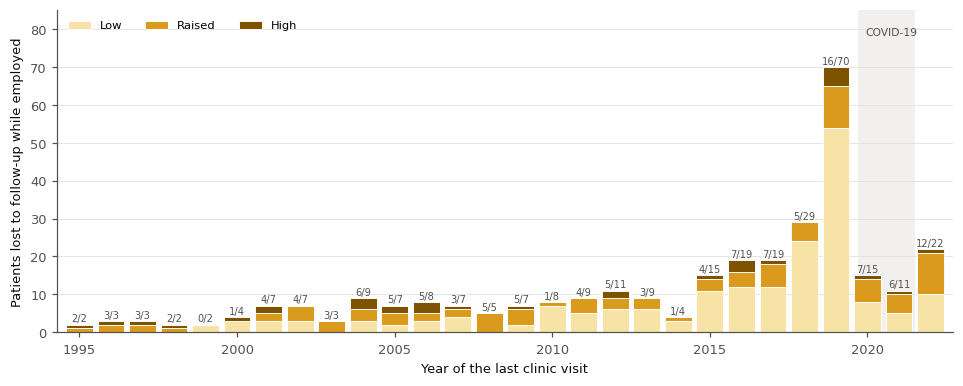

Year of the last clinic visit,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
Low,0.0,0.0,0.0,0.0,2.0,3.0,3.0,3.0,0.0,3.0,2.0,3.0,4.0,0.0,2.0,7.0,5.0,6.0,6.0,3.0,11.0,12.0,12.0,24.0,54.0,8.0,5.0,10.0
Raised,1.0,2.0,2.0,1.0,0.0,0.0,2.0,4.0,3.0,3.0,3.0,2.0,2.0,5.0,4.0,1.0,4.0,3.0,3.0,1.0,3.0,4.0,6.0,5.0,11.0,6.0,5.0,11.0
High,1.0,1.0,1.0,1.0,0.0,1.0,2.0,0.0,0.0,3.0,2.0,3.0,1.0,0.0,1.0,0.0,0.0,2.0,0.0,0.0,1.0,3.0,1.0,0.0,5.0,1.0,1.0,1.0
Raised or High (%),100.0,100.0,100.0,100.0,0.0,25.0,57.0,57.0,100.0,67.0,71.0,62.0,43.0,100.0,71.0,12.0,44.0,45.0,33.0,25.0,27.0,37.0,37.0,17.0,23.0,47.0,55.0,55.0


**What this means.** 317 working patients were last seen in 1995-2022 and not
again; 129 (41 %) were Raised or High at their last score
(32 High). 551 working patients without an outcome were seen after 2022 and are
not counted. Up to 2009, 67 % of the patients
lost were Raised or High; from 2020, 52 %
(48 patients). The last score was a median of
4 months (IQR 2-9)
before the last visit, because landmarks fall every 6 months.

In [66]:
"""Patients lost to follow-up while employed, by year of the last clinic visit (to 2022), by HazReg band at the last score."""
LOST_LAST_YEAR = 2022                 # last year counted: every patient counted has >= 15 months without a visit
_lw = follow_up_endings()[0]
_last_visit = visits.groupby("PTNO")["ASSDT"].max()
_lw["last_visit"] = _lw["pid"].map(_last_visit)
_lost_w = _lw[(_lw["cause"] == 0) & (_lw["exit_type"] == "end_of_follow_up") & ~_lw["dead"].astype(bool)
              & (_lw["last_visit"].dt.year <= LOST_LAST_YEAR)].copy()
_cuts_w = np.quantile(P_CV["HazReg"], REL_TIER_SHARES)
_lost_w["band"] = np.digitize(P_CV["HazReg"][_lost_w.index.values], _cuts_w)
_lost_w["year"] = _lost_w["last_visit"].dt.year
_lost_w["months_from_score"] = (_lost_w["last_visit"] - _lost_w["visit_date"]).dt.days / MONTH_DAYS
LOST_BY_YEAR = pd.crosstab(_lost_w["year"], _lost_w["band"]).reindex(columns=range(len(REL_TIER_LABELS)), fill_value=0)
LOST_BY_YEAR = LOST_BY_YEAR.reindex(range(int(_lost_w["year"].min()), LOST_LAST_YEAR + 1), fill_value=0)
LOST_BY_YEAR.columns = REL_TIER_LABELS
LOST_BY_YEAR.index.name = "Year of the last clinic visit"
LOST_BY_YEAR["Raised or High (%)"] = (100 * LOST_BY_YEAR[REL_TIER_LABELS[1:]].sum(1)
                                      / LOST_BY_YEAR[REL_TIER_LABELS].sum(1).replace(0, np.nan)).round(0)
save_table(LOST_BY_YEAR, "lost_to_follow_up_by_year_and_band")
_n_seen24 = int((_lw["last_visit"].dt.year > LOST_LAST_YEAR).sum())

fig, ax = plt.subplots(figsize=(10.5, 3.8))
_lost_yrs = LOST_BY_YEAR.index.values
_bottom = np.zeros(len(_lost_yrs))
for k, nm in enumerate(REL_TIER_LABELS):
    ax.bar(_lost_yrs, LOST_BY_YEAR[nm].values, bottom=_bottom, color=TIER_COLORS[k], edgecolor="white", linewidth=0.6,
           width=0.85, label=nm)
    _bottom += LOST_BY_YEAR[nm].values
_tot, _hi_n = LOST_BY_YEAR[REL_TIER_LABELS].sum(1).values, LOST_BY_YEAR[REL_TIER_LABELS[1:]].sum(1).values
for x, t, h in zip(_lost_yrs, _tot, _hi_n):
    if t > 0:
        ax.text(x, t + 0.25, f"{h}/{t}", ha="center", va="bottom", fontsize=6.5, color=INK_2)
ax.axvspan(2020.2 - 0.5, 2021.5, color=GRID_C, alpha=0.5, lw=0, zorder=0)
ax.text(2020.75, _tot.max() * 1.12, "COVID-19", ha="center", fontsize=7, color=INK_2)
ax.set_ylim(0, _tot.max() * 1.2 + 1)
ax.set_xlim(_lost_yrs.min() - 0.7, _lost_yrs.max() + 0.7)
ax.set_xlabel("Year of the last clinic visit"); ax.set_ylabel("Patients lost to follow-up while employed")
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper left", fontsize=7.5, frameon=False)
ax.set_title(f"Patients lost to follow-up while employed (no visit after 2022), by HazReg band at the last score "
             f"(above the bars: Raised or High / all)", loc="left", fontsize=9)
save_fig("lost_to_follow_up_by_year")
display(LOST_BY_YEAR.T)

_pre = LOST_BY_YEAR.loc[:2009, REL_TIER_LABELS]
_post = LOST_BY_YEAR.loc[2020:, REL_TIER_LABELS]
say(f"""
**What this means.** {int(_tot.sum())} working patients were last seen in {int(_lost_yrs.min())}-{LOST_LAST_YEAR} and not
again; {int(_hi_n.sum())} ({100 * _hi_n.sum() / _tot.sum():.0f} %) were Raised or High at their last score
({int(LOST_BY_YEAR["High"].sum())} High). {_n_seen24} working patients without an outcome were seen after {LOST_LAST_YEAR} and are
not counted. Up to 2009, {100 * _pre[REL_TIER_LABELS[1:]].values.sum() / max(_pre.values.sum(), 1):.0f} % of the patients
lost were Raised or High; from 2020, {100 * _post[REL_TIER_LABELS[1:]].values.sum() / max(_post.values.sum(), 1):.0f} %
({int(_post.values.sum())} patients). The last score was a median of
{_lost_w["months_from_score"].median():.0f} months (IQR {_lost_w["months_from_score"].quantile(0.25):.0f}-{_lost_w["months_from_score"].quantile(0.75):.0f})
before the last visit, because landmarks fall every 6 months.
""")

### 4.0.3 The landmarks from March 2020: a descriptive check

> **The question.** How do the risks of the landmarks from March 2020 compare with the onsets recorded after them?

Two sets of risks: the **final model**, fitted on the visits before March 2020 and scored on the later landmarks (a
temporal check), and HazReg **cross-validated on the whole extract**. Only landmarks up to about April 2021 have a
full 36-month follow-up, and COVID-19 cut both visits and status recording, so the counts are small and the AUROC is
given only with at least 10 onsets. This section is descriptive: it makes no claim about ranking performance.

In [67]:
"""Landmarks from MAIN_END: observed against expected onsets within 36 months, final model and whole-extract CV."""
_after = LAND_T >= float((MAIN_END - pd.Timestamp("1970-01-01")).days)
_rows_pc = []
for gname, sel in [(f"Before {MAIN_END.date()}", ~_after), (f"From {MAIN_END.date()}", _after)]:
    rows = np.flatnonzero(sel)                    # unlabelled landmarks stay in: the censoring weights stand in for them in O/E
    lab_ = rows[W_IP[rows] > 0]
    n_on, n_off = int((Y_IP[lab_] == 1).sum()), int((Y_IP[lab_] == 0).sum())
    r_ = {"Landmarks": len(rows), "Patients": len(np.unique(PID_ALL[rows])),
          f"Landmarks with a known {H}-month status": len(lab_), f"Onsets within {H} mo": n_on}
    for lab_m, p in [("Final model (to March 2020)", P_FULL), ("HazReg, CV on the whole extract", P_CV["HazReg"])]:
        if lab_m.startswith("Final") and not gname.startswith("From"):
            r_ |= {f"{lab_m}: O/E": "in-sample (fitted on these landmarks)", f"{lab_m}: AUROC": "in-sample (fitted on these landmarks)"}
            continue
        a = sub_arr(p, rows)
        r_[f"{lab_m}: O/E"] = fmt(ci_of(a["O/E"]), 2)
        r_[f"{lab_m}: AUROC"] = fmt(ci_of(a["AUROC"])) if min(n_on, n_off) >= 10 else "fewer than 10 onsets"
    _rows_pc.append({"Period": gname} | r_)
POSTCOVID_CHECK = pd.DataFrame(_rows_pc).set_index("Period").T
display(POSTCOVID_CHECK)
save_table(POSTCOVID_CHECK, "postcovid_check")
_pc = POSTCOVID_CHECK[f"From {MAIN_END.date()}"]
say(f"""
**What this means.** {int(_pc['Landmarks']):,} landmarks of {int(_pc['Patients'])} patients fall from March 2020;
{int(_pc[f'Landmarks with a known {H}-month status']):,} have a known {H}-month status and {int(_pc[f'Onsets within {H} mo'])}
are followed by a recorded onset. The final model's observed/expected ratio on them is
{_pc['Final model (to March 2020): O/E']}. With so few onsets, and with follow-up and status recording cut by
COVID-19, these years cannot show whether the model ranks patients as well as before; they are reported for
completeness, outside every result of the main analysis.
""")

Period,Before 2020-03-01,From 2020-03-01
Landmarks,13184,1932
Patients,971,449
Landmarks with a known 36-month status,11805,391
Onsets within 36 mo,591,26
Final model (to March 2020): O/E,in-sample (fitted on these landmarks),0.72 (0.20 to 1.39)
Final model (to March 2020): AUROC,in-sample (fitted on these landmarks),0.440 (0.231 to 0.727)
"HazReg, CV on the whole extract: O/E",0.97 (0.80 to 1.14),0.83 (0.22 to 1.59)
"HazReg, CV on the whole extract: AUROC",0.747 (0.705 to 0.787),0.473 (0.225 to 0.767)


**What this means.** 1,932 landmarks of 449 patients fall from March 2020;
391 have a known 36-month status and 26
are followed by a recorded onset. The final model's observed/expected ratio on them is
0.72 (0.20 to 1.39). With so few onsets, and with follow-up and status recording cut by
COVID-19, these years cannot show whether the model ranks patients as well as before; they are reported for
completeness, outside every result of the main analysis.

In [68]:
"""Back to the main analysis (visits before MAIN_END) for Sections 4.1-4.5."""
use_data("main")
print(f"Part IV from Section 4.1: {N_LAND:,} landmarks of {P_N:,} patients, {int(D1_ALL.sum())} onsets, visits before "
      f"{MAIN_END.date()}. HazReg cross-validated: AUROC {fmt(CV_RES['HazReg']['AUROC'])}.")

Part IV from Section 4.1: 12,976 landmarks of 958 patients, 150 onsets, visits before 2020-03-01. HazReg cross-validated: AUROC 0.744 (0.700 to 0.786).


## 4.1 How much of the fall is explained by who the patients are?

> **The idea.** HazReg has no calendar term, so its predictions change over the years only because patients
> changed: less prednisone, less damage, different symptoms. Comparing the onsets it *expects* era by era with
> those *observed* splits the fall into a part explained by patients (case mix) and a part that is not.

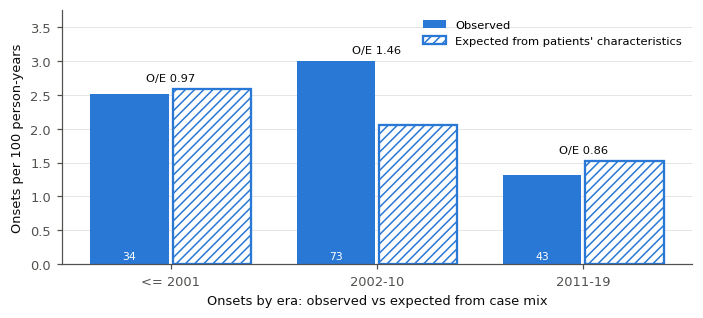

**What this means.** From 2002-10 to 2011-19, the observed onset rate fell to 0.44 times its earlier
level. The rate expected from patients' characteristics fell to 0.74 times. On the log scale, **case mix
accounts for about 36 % of the fall.** The rest shows as observed / expected drifting from
1.46 to 0.86. Other exits drift the
same way (1.51 → 0.80).

Patients really have become healthier in ways that matter for work, and the model sees that without being told the
year. The unexplained remainder affects every kind of exit from work alike, as the negative controls of Section
1.5.6 do. Section 4.1.1 asks whether treatment explains it; Part V tests it as under-recording.

,Patients seen,Visits flagged (%),Patients ever flagged (%),Alarm episodes per 100 person-years,Episode PPV (%),Episode PPV 95% CI
Era,,,,,,
<= 2001,335,23.6,42.4,12.2,12.0,7.4-17.3
2002-10,516,16.7,38.6,10.2,16.8,11.5-22.1
2011-19,675,10.1,24.9,6.1,12.4,7.4-18.8


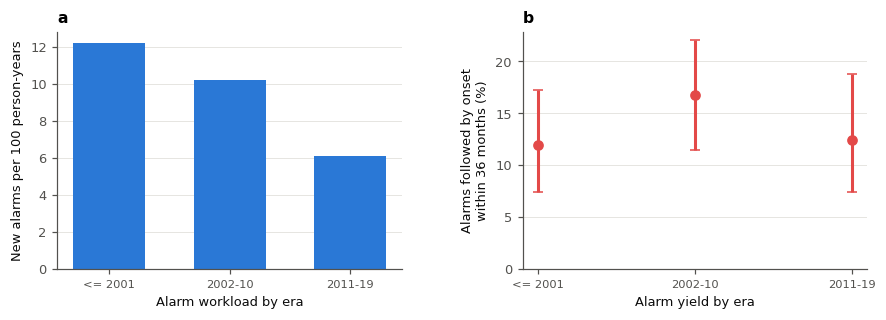

**At the patient level**, new alarms went from 12.2 per 100
person-years in <= 2001 to 6.1 in 2011-19
(× 0.50), as the case mix changed. The share of alarms followed by a recorded onset within 36 months went from
12 % to 12 % (× 1.03).
The yield of an alarm did not fall with the number of alarms.

In [69]:
"""Expected (from patient characteristics, no calendar time) vs observed onsets by era."""
_rows_ce = []
for k, (a, b, lab) in enumerate(ERAS):
    lo, hi = _edges[k], _edges[k + 1]
    expo = np.clip(np.minimum(INT_END_ALL, hi) - np.maximum(LAND_T, lo), 0, None) / 365.25     # each person-year once
    inn = (INT_END_ALL > lo) & (INT_END_ALL <= hi)
    py = expo.sum()
    if py < 50:
        continue
    e1 = np.sum(np.exp(ETA_FULL[:, 0]) * expo)
    e2 = np.sum(np.exp(ETA_FULL[:, 1]) * expo)
    _rows_ce.append({"Era": lab, "Person-years": round(py), "Onsets observed": int(D1_ALL[inn].sum()),
                     "Onsets expected": e1, "Observed / expected": D1_ALL[inn].sum() / e1,
                     "Expected rate /100 py": 100 * e1 / py, "Observed rate /100 py": 100 * D1_ALL[inn].sum() / py,
                     "Other exits O/E": D2_ALL[inn].sum() / e2})
CASE_MIX = pd.DataFrame(_rows_ce).set_index("Era").round(2)
save_table(CASE_MIX, "case_mix_by_era")
fig, ax = plt.subplots(figsize=(7.4, 3.0))
_x = np.arange(len(CASE_MIX))
_bo = ax.bar(_x - 0.2, CASE_MIX["Observed rate /100 py"], 0.38, color=C1, label="Observed")
_be = ax.bar(_x + 0.2, CASE_MIX["Expected rate /100 py"], 0.38, color="white", edgecolor=C1, linewidth=1.5, hatch="////",
             label="Expected from patients' characteristics")
for i, (o, e, oe) in enumerate(zip(CASE_MIX["Observed rate /100 py"], CASE_MIX["Expected rate /100 py"],
                                   CASE_MIX["Observed / expected"])):
    ax.text(i, max(o, e) + 0.12, f"O/E {oe:.2f}", ha="center", fontsize=7.5, color=INK)
    ax.text(i - 0.2, 0.08, f"{int(CASE_MIX['Onsets observed'].iloc[i])}", ha="center", fontsize=7, color="white")
ax.set_xticks(_x, CASE_MIX.index); ax.grid(axis="x", visible=False)
ax.set_ylabel("Onsets per 100 person-years")
ax.set_ylim(0, CASE_MIX[["Observed rate /100 py", "Expected rate /100 py"]].values.max() * 1.25)
ax.set_title("Onsets by era: observed vs expected from case mix (in bars: number of onsets)",
             loc="left", fontsize=9)
ax.legend(loc="upper right", fontsize=7.5)
save_fig("case_mix_by_era")
_cm = CASE_MIX
_first, _lastera = (ERA_REF if ERA_REF in _cm.index else _cm.index[0]), _cm.index[-1]
_exp_ratio = _cm.loc[_lastera, "Expected rate /100 py"] / _cm.loc[_first, "Expected rate /100 py"]
_obs_ratio = _cm.loc[_lastera, "Observed rate /100 py"] / _cm.loc[_first, "Observed rate /100 py"]
_share = np.log(_exp_ratio) / np.log(_obs_ratio) if _obs_ratio < 1 else np.nan
say(f"""
**What this means.** From {_first} to {_lastera}, the observed onset rate fell to {_obs_ratio:.2f} times its earlier
level. The rate expected from patients' characteristics fell to {_exp_ratio:.2f} times. On the log scale, **case mix
accounts for about {100 * _share:.0f} % of the fall.** The rest shows as observed / expected drifting from
{_cm.loc[_first, "Observed / expected"]:.2f} to {_cm.loc[_lastera, "Observed / expected"]:.2f}. Other exits drift the
same way ({_cm.loc[_first, "Other exits O/E"]:.2f} → {_cm.loc[_lastera, "Other exits O/E"]:.2f}).

Patients really have become healthier in ways that matter for work, and the model sees that without being told the
year. The unexplained remainder affects every kind of exit from work alike, as the negative controls of Section
1.5.6 do. Section 4.1.1 asks whether treatment explains it; Part V tests it as under-recording.
""")

# ---- the patient alarm by era: workload and yield (cross-validated HazReg, alarm rule of Section 2.5)
_rows_ae = []
for e in [x[2] for x in ERAS]:
    sel = ERA_LAB == e
    if INT_YRS_ALL[sel].sum() < 50:
        continue
    b = alarm_burden(FLAGS["HazReg"], sel=sel)
    _rows_ae.append({"Era": e, "Patients seen": len(np.unique(PID_ALL[sel])), **{k: v for k, v in b.items() if k != "Episode PPV (%)"},
                     "Episode PPV (%)": b["Episode PPV (%)"][0],
                     "Episode PPV 95% CI": f"{b['Episode PPV (%)'][1]:.1f}-{b['Episode PPV (%)'][2]:.1f}"})
ALARM_BY_ERA = pd.DataFrame(_rows_ae).set_index("Era").round(1)
display(ALARM_BY_ERA)
save_table(ALARM_BY_ERA, "alarm_by_era")
fig, axes = plt.subplots(1, 2, figsize=(9.5, 2.8), gridspec_kw={"wspace": 0.35})
_xa = np.arange(len(ALARM_BY_ERA))
axes[0].bar(_xa, ALARM_BY_ERA["Alarm episodes per 100 person-years"], 0.6, color=C1)
axes[0].set_ylabel("New alarms per 100 person-years"); axes[0].set_title("a  Alarm workload by era", loc="left", fontsize=9)
_pp = ALARM_BY_ERA["Episode PPV (%)"].values
_lo_hi = np.array([[float(x) for x in c.split("-")] for c in ALARM_BY_ERA["Episode PPV 95% CI"]])
axes[1].errorbar(_xa, _pp, yerr=[_pp - _lo_hi[:, 0], _lo_hi[:, 1] - _pp], fmt="o", color="#e34948", ms=6, capsize=3)
axes[1].set_ylabel("Alarms followed by onset\nwithin 36 months (%)"); axes[1].set_ylim(bottom=0)
axes[1].set_title("b  Alarm yield (episode PPV) by era", loc="left", fontsize=9)
for ax in axes:
    ax.set_xticks(_xa, ALARM_BY_ERA.index, fontsize=7.5); ax.grid(axis="x", visible=False)
save_fig("alarm_by_era")
_ae = ALARM_BY_ERA
_r_epi = _ae['Alarm episodes per 100 person-years'].iloc[-1] / _ae['Alarm episodes per 100 person-years'].iloc[0]
_r_ppv = _ae['Episode PPV (%)'].iloc[-1] / max(_ae['Episode PPV (%)'].iloc[0], 1e-9)
say(f"""
**At the patient level**, new alarms went from {_ae['Alarm episodes per 100 person-years'].iloc[0]:.1f} per 100
person-years in {_ae.index[0]} to {_ae['Alarm episodes per 100 person-years'].iloc[-1]:.1f} in {_ae.index[-1]}
(× {_r_epi:.2f}), as the case mix changed. The share of alarms followed by a recorded onset within 36 months went from
{_ae['Episode PPV (%)'].iloc[0]:.0f} % to {_ae['Episode PPV (%)'].iloc[-1]:.0f} % (× {_r_ppv:.2f}).
{"The yield fell faster than the number of alarms: the alarms follow case mix, but not the part of the fall that case mix does not explain." if _r_ppv < _r_epi else "The yield of an alarm did not fall with the number of alarms."}
""")

### 4.1.1 Does treatment explain the drift?

> **The idea.** If better treatment lowered work disability, adding patients' treatment to a model with an era term
> in the baseline should absorb part of the era effect. A variable that depends only on the visit date (an era
> indicator, "after EULAR 2019") cannot do this: it takes the same value for everyone seen that year, so it is just
> another era term. Patient-level treatment can: the treatment ladder, the prednisone dose, and whether that dose is
> above the target of the time.

Three Poisson models of each exit, with the era (reference 2002-10) in the baseline: **(a)** era only; **(b)** era +
the patient's non-treatment inputs; **(c)** era + all inputs, the treatment block included. The share of the era
effect absorbed by treatment is what (c) removes beyond (b). The other exits are a negative control: better lupus
treatment should not explain them.

,,"Era HR, era only",after patients' inputs,after treatment too,Absorbed by patients' inputs (%),"Absorbed by treatment, beyond them (%)"
Exit,Era,,,,,
Onset,2011-19,0.49,0.56,0.64,17.34,19.82
Other exit,2011-19,0.55,0.51,0.55,-11.42,12.84


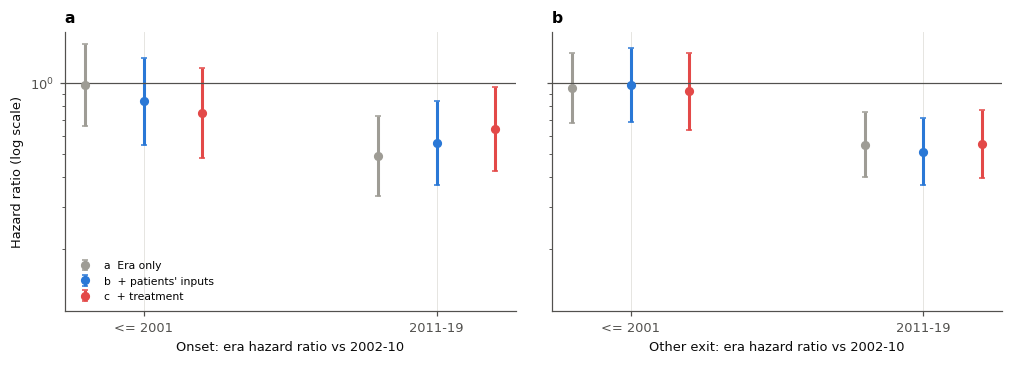

**What this means.** The era effect on onsets in 2011-19 is a hazard ratio of
0.49 against 2002-10. Patients' own inputs bring it to
0.56 (17 % of
the effect on the log scale). Adding the treatment block moves it to 0.64: treatment
absorbs a further **20 %**. For the other exits, the negative control,
treatment absorbs 13 %.
Treatment explains little of the drift. Together with the negative controls of Section 1.5.6, this argues against a change in the standard of care as the reason recorded exits fell.

In [70]:
"""Era effects on the baseline hazards, before and after adjusting for patients' characteristics and treatment."""
import statsmodels.api as sm
from patsy import dmatrix, build_design_matrices

_NONTREAT = [c for c in COMPACT_VARS if c not in TREATMENT_VARS]
_ERA_NAMES = ERA_NAMES
_IN_ERA = np.isin(ERA_LAB, _ERA_NAMES)             # landmarks after the main analysis belong to no era: left out
_ERA_D = pd.get_dummies(pd.Categorical(ERA_LAB[_IN_ERA], categories=_ERA_NAMES)).astype(float).drop(columns=ERA_REF)


def era_glm(d, cols):
    """Poisson GLM of one exit: era dummies (+ preprocessed inputs), offset log person-time (each person-year once),
    patient-clustered SEs; landmarks of the eras only."""
    k = _IN_ERA
    parts, names = [_ERA_D.values], list(_ERA_D.columns)
    if cols:
        pr = Prep(cols, [s for s in SPLINE_VARS if s in cols]).fit(LAND_X.iloc[np.flatnonzero(k)])
        parts.append(pr.transform(LAND_X.iloc[np.flatnonzero(k)])); names += pr.names
    X = sm.add_constant(np.hstack(parts))
    f = sm.GLM(d[k], X, family=sm.families.Poisson(), offset=np.log(np.maximum(INT_YRS_ALL[k], 1e-6))).fit(
        cov_type="cluster", cov_kwds={"groups": ROW_PIDX[k]}, maxiter=200)
    return pd.DataFrame({"b": f.params[1:len(_ERA_D.columns) + 1], "se": f.bse[1:len(_ERA_D.columns) + 1]},
                        index=_ERA_D.columns)


if "era_decomposition" not in STATE:
    STATE["era_decomposition"] = {(cause, lab): era_glm(d, cols) for cause, d in [("Onset", D1_ALL), ("Other exit", D2_ALL)]
                                  for lab, cols in [("a  Era only", []), ("b  + patients' inputs", _NONTREAT),
                                                    ("c  + treatment", COMPACT_VARS)]}
    _save_state()
ERA_DEC = STATE["era_decomposition"]
_rows_ed = []
for (cause, lab), t in ERA_DEC.items():
    for era, r in t.iterrows():
        _rows_ed.append({"Exit": cause, "Model": lab, "Era": era, "HR": np.exp(r.b), "low": np.exp(r.b - 1.96 * r.se),
                         "high": np.exp(r.b + 1.96 * r.se)})
ERA_HR = pd.DataFrame(_rows_ed)
save_table(ERA_HR.round(3), "era_decomposition")
_absorb = []
for cause in ["Onset", "Other exit"]:
    for era in [e for e in _ERA_NAMES if e not in (ERA_REF, _ERA_NAMES[0])]:
        ba, bb, bc = (ERA_DEC[(cause, m)].loc[era, "b"] for m in ["a  Era only", "b  + patients' inputs", "c  + treatment"])
        _absorb.append({"Exit": cause, "Era": era, "Era HR, era only": np.exp(ba), "after patients' inputs": np.exp(bb),
                        "after treatment too": np.exp(bc), "Absorbed by patients' inputs (%)": 100 * (1 - bb / ba),
                        "Absorbed by treatment, beyond them (%)": 100 * (bb - bc) / ba})
ERA_ABSORB = pd.DataFrame(_absorb).set_index(["Exit", "Era"]).round(2)
display(ERA_ABSORB)
save_table(ERA_ABSORB, "era_absorbed_by_treatment")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True, gridspec_kw={"wspace": 0.08})
_mcol = {"a  Era only": "#9e9c95", "b  + patients' inputs": C1, "c  + treatment": "#e34948"}
_eras_shown = [e for e in _ERA_NAMES if e != ERA_REF]
for ax, cause in zip(axes, ["Onset", "Other exit"]):
    for j, (m, col) in enumerate(_mcol.items()):
        t = ERA_HR[(ERA_HR["Exit"] == cause) & (ERA_HR["Model"] == m)].set_index("Era").reindex(_eras_shown)
        x = np.arange(len(t)) + (j - 1) * 0.2
        ax.errorbar(x, t["HR"], yerr=[t["HR"] - t["low"], t["high"] - t["HR"]], fmt="o", color=col, ms=5, capsize=2,
                    label=m)
    ax.axhline(1, color=INK_2, lw=0.8)
    ax.set_yscale("log"); ax.set_xticks(range(len(_eras_shown)), _eras_shown)
    ax.set_title(f"{'a' if cause == 'Onset' else 'b'}  {cause}: era hazard ratio vs {ERA_REF}", loc="left", fontsize=9)
axes[0].set_ylabel("Hazard ratio (log scale)"); axes[0].legend(fontsize=7, loc="lower left")
save_fig("era_decomposition")
_ab = ERA_ABSORB
say(f"""
**What this means.** The era effect on onsets in 2011-19 is a hazard ratio of
{_ab.loc[('Onset', '2011-19'), 'Era HR, era only']:.2f} against {ERA_REF}. Patients' own inputs bring it to
{_ab.loc[('Onset', '2011-19'), "after patients' inputs"]:.2f} ({_ab.loc[('Onset', '2011-19'), "Absorbed by patients' inputs (%)"]:.0f} % of
the effect on the log scale). Adding the treatment block moves it to {_ab.loc[('Onset', '2011-19'), 'after treatment too']:.2f}: treatment
absorbs a further **{_ab.loc[('Onset', '2011-19'), 'Absorbed by treatment, beyond them (%)']:.0f} %**. For the other exits, the negative control,
treatment absorbs {_ab.loc[('Other exit', '2011-19'), 'Absorbed by treatment, beyond them (%)']:.0f} %.
{"Treatment explains little of the drift. Together with the negative controls of Section 1.5.6, this argues against a change in the standard of care as the reason recorded exits fell." if abs(_ab.loc[('Onset', '2011-19'), 'Absorbed by treatment, beyond them (%)']) < 20 else "Treatment absorbs a material part of the era effect on onsets; compare it with the other exits before reading it as a treatment effect."}
""")

### 4.1.2 How different are the patients of each era?

> **The idea.** If a model given only the inputs of a landmark can tell which era it comes from, the eras differ
> in case mix, and the AUROC of that classifier measures by how much (0.5: no difference; 1: no overlap). This is
> case-mix shift in the strict sense: it concerns the inputs only, not the outcome. Section 4.1 showed what the
> shift does to the expected onsets; this section shows its size and which inputs carry it.

For each era, a ridge logistic regression of *this era against all the others* on the model's inputs (same
preprocessing as HazReg), cross-validated in 5 patient-grouped folds. The headline is the most recent era against
the development years, the comparison a clinic adopting the model today faces. Standardised mean differences (SMD)
of each input, era against the rest, show where the shift lies; |SMD| ≥ 0.2 is a conventional marker of a
material difference.

,Landmarks,Era vs the rest: AUROC (95% CI)
Era,,
<= 2001,2514,0.759 (0.735 to 0.783)
2002-10,4486,0.585 (0.563 to 0.606)
2011-19,5976,0.737 (0.715 to 0.759)


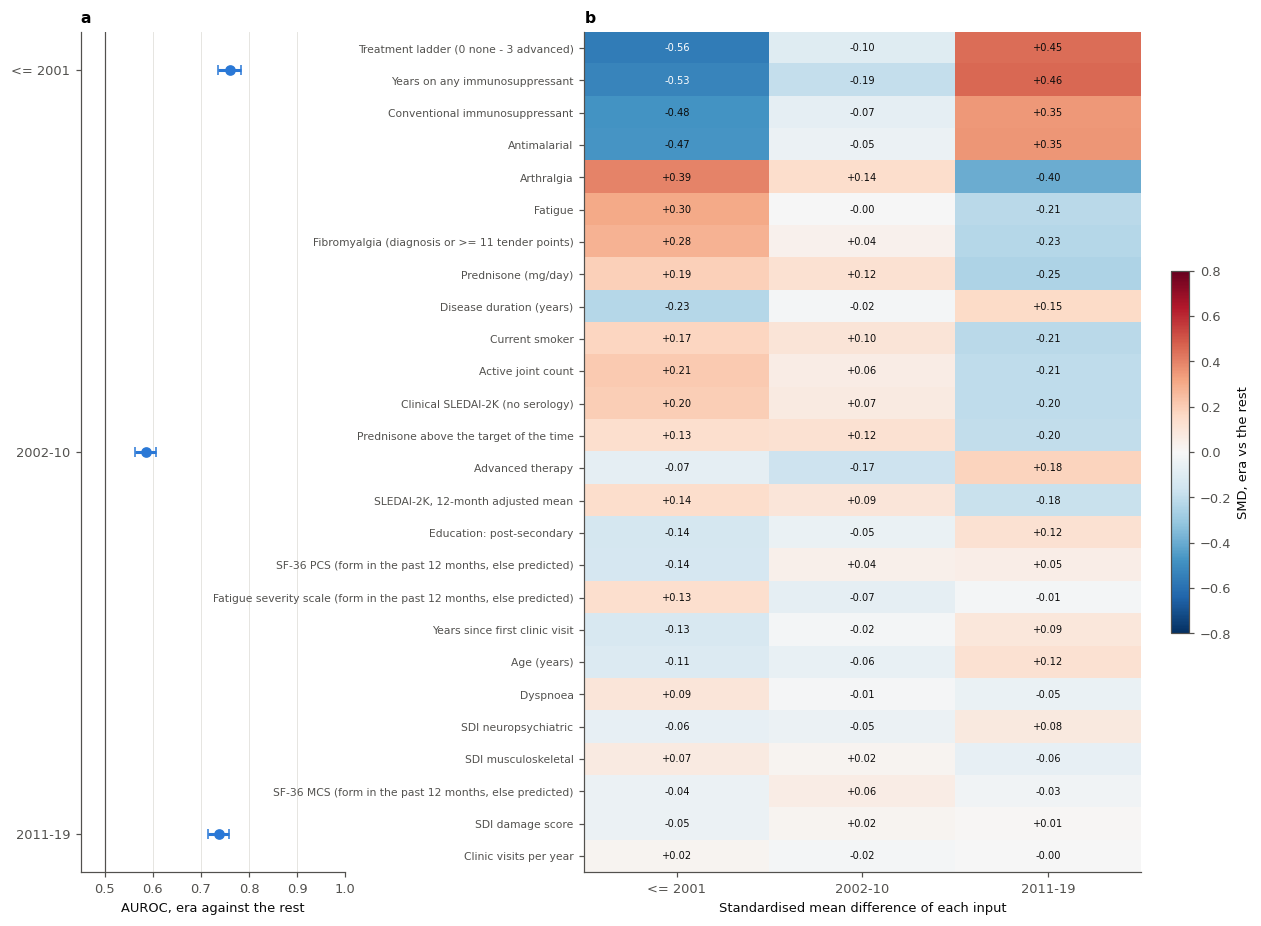

**What this means.** The inputs of a landmark tell its era with an AUROC of
0.76 (0.73 to 0.78) (<= 2001), 0.58 (0.56 to 0.61) (2002-10), 0.74 (0.72 to 0.76) (2011-19). The patients of the most recent era (2011-19) are clearly distinguishable from those the model was developed on:
11 of 26 inputs differ by |SMD| ≥ 0.2 (years on any immunosuppressant +0.46, treatment ladder (0 none - 3 advanced) +0.45, arthralgia -0.40, antimalarial +0.35, conventional immunosuppressant +0.35).
A shift in the inputs alone does not miscalibrate a correctly specified model; it matters where the model must
extrapolate, and it is why the expected onsets of Section 4.1 fall over the eras. The part of the fall that the
inputs do not carry is what Sections 4.2-4.4 examine.

In [71]:
"""Era-membership classifier on the model's inputs (case-mix shift), and standardised mean differences by era."""


def era_membership_auc(target, cols=COMPACT_VARS, n_folds=5, seed=SEED):
    """Cross-validated AUROC (patient-grouped folds) of a ridge logistic regression telling `target` landmarks from
    the rest, on `cols`; patient-cluster bootstrap CI of the AUROC of the held-out scores."""
    y = (ERA_LAB == target).astype(int)
    rng = np.random.RandomState(seed)
    fold_of_pt = rng.permutation(P_N) % n_folds
    fold = fold_of_pt[ROW_PIDX]
    score = np.zeros(N_LAND)
    spl = [c for c in SPLINE_VARS if c in cols]
    for k in range(n_folds):
        tr, te = fold != k, fold == k
        pr = Prep(cols, spl).fit(LAND_X.iloc[np.flatnonzero(tr)])
        m = LogisticRegression(C=1.0, max_iter=5000).fit(pr.transform(LAND_X.iloc[np.flatnonzero(tr)]), y[tr])
        score[te] = m.decision_function(pr.transform(LAND_X.iloc[np.flatnonzero(te)]))
    A = wauc(y, score, W_BOOT[:, ROW_PIDX])
    return ci_of(A), score


def smd_by_era(cols=COMPACT_VARS):
    """SMD of each input, each era against all other landmarks (pooled SD; missing values left out)."""
    out = {}
    for e in ERA_NAMES:
        k = ERA_LAB == e
        if k.sum() < 30:
            continue
        r = {}
        for c in cols:
            x = pd.to_numeric(LAND_X[c], errors="coerce").values.astype(float)
            a, b = x[k & np.isfinite(x)], x[~k & np.isfinite(x)]
            sd = np.sqrt((np.var(a, ddof=1) + np.var(b, ddof=1)) / 2) if len(a) > 1 and len(b) > 1 else np.nan
            r[DISPLAY.get(c, c)] = (a.mean() - b.mean()) / sd if sd and sd > 0 else np.nan
        out[e] = r
    return pd.DataFrame(out)


ERA_CLS = {}
for e in ERA_NAMES:
    if (ERA_LAB == e).sum() >= 30:
        ERA_CLS[e], _ = era_membership_auc(e)
ERA_CLS_TABLE = pd.DataFrame({"Landmarks": {e: int((ERA_LAB == e).sum()) for e in ERA_CLS},
                              "Era vs the rest: AUROC (95% CI)": {e: fmt(v) for e, v in ERA_CLS.items()}})
ERA_CLS_TABLE.index.name = "Era"
display(ERA_CLS_TABLE)
save_table(ERA_CLS_TABLE, "era_membership_auroc")
ERA_SMD = smd_by_era()
ERA_SMD = ERA_SMD.loc[ERA_SMD.abs().max(1).sort_values(ascending=False).index]
save_table(ERA_SMD.round(2), "smd_by_era")

fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * len(ERA_SMD) + 1.6), gridspec_kw={"width_ratios": [0.7, 1.6],
                                                                                         "wspace": 0.55})
ax = axes[0]
_ce = np.array([list(v) for v in ERA_CLS.values()])
ax.errorbar(_ce[:, 0], np.arange(len(_ce)), xerr=[_ce[:, 0] - _ce[:, 1], _ce[:, 2] - _ce[:, 0]], fmt="o", color=C1,
            ms=6, capsize=3)
ax.axvline(0.5, color=INK_2, lw=0.8); ax.set_xlim(0.45, 1.0)
ax.set_yticks(range(len(_ce)), list(ERA_CLS)); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUROC, era against the rest"); ax.set_title("a  How well the inputs tell the era", loc="left", fontsize=9)
ax = axes[1]
_v = ERA_SMD.values
im = ax.imshow(np.clip(_v, -0.8, 0.8), cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
for (i, j), v in np.ndenumerate(_v):
    if np.isfinite(v):
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.5 else INK)
ax.set_xticks(range(_v.shape[1]), ERA_SMD.columns); ax.set_yticks(range(_v.shape[0]), ERA_SMD.index, fontsize=7)
ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.03, label="SMD, era vs the rest")
ax.set_title("b  Standardised mean difference of each input", loc="left", fontsize=9)
save_fig("era_membership_case_mix")
_last_e = ERA_NAMES[-1] if ERA_NAMES[-1] in ERA_CLS else list(ERA_CLS)[-1]
_top = ERA_SMD[_last_e].dropna().abs().sort_values(ascending=False)
_big = _top[_top >= 0.2]
say(f"""
**What this means.** The inputs of a landmark tell its era with an AUROC of
{", ".join(f"{fmt(v, 2)} ({e})" for e, v in ERA_CLS.items())}. {"The patients of the most recent era (" + _last_e + ") are clearly distinguishable from those the model was developed on" if ERA_CLS[_last_e][0] >= 0.7 else "The patients of the most recent era (" + _last_e + ") overlap substantially with those the model was developed on"}:
{len(_big)} of {len(_top)} inputs differ by |SMD| ≥ 0.2 ({", ".join(f"{i.lower()} {ERA_SMD.loc[i, _last_e]:+.2f}" for i in _big.index[:5]) if len(_big) else "none"}).
A shift in the inputs alone does not miscalibrate a correctly specified model; it matters where the model must
extrapolate, and it is why the expected onsets of Section 4.1 fall over the eras. The part of the fall that the
inputs do not carry is what Sections 4.2-4.4 examine.
""")

## 4.2 Validation year by year (annual rolling origins)

> **The idea.** Stand at 1 January of each year from 2005 to 2019, with only the data available then. Fit HazReg,
> LogReg and the first-visit model on earlier visits, with their follow-up cut at that date, and score the visits
> of that year. Every landmark from 2005 then has a **prequential** risk: one computed by a model that had seen
> only the past. This is how the tool would be maintained in practice.

Three measures are tracked year by year, because each answers a different question:

| Measure | Question | Depends on the baseline level? |
|:--|:--|:--|
| **AUROC** (visits of the year) and **time-matched patient C** (onsets of the year) | Does the ranking carry over? | No |
| **Calibration slope** within a model with the year's own baseline | Are the *relative* risks right: is a patient with twice the predicted risk at twice the observed risk? | No |
| **Observed / expected onsets** | Is the absolute level right? | Yes, and so does the recording |

Relative bands and the flag use each origin's own training risks as the reference, as a frozen model would.
Pooled estimates use a random-effects model with a prediction interval for the next year.

| | Hypothesis | What is compared | Met if |
|:--|:--|:--|:--|
| H5a | The ranking carries over to later years | Prequential AUROC, HazReg − first-visit model, pooled over years | CI above 0 |
| H5c | How well calibrated are the relative risks in later years? | Calibration slope with each year's own baseline, pooled | Estimated: the smallest margin around 1 that holds the 95 % CI |

In [72]:
"""Annual rolling origins: models fitted on the past only; prequential risks for every landmark from 2005."""


def _origin_fit(Y):
    cut = _day(Y)
    tr = np.flatnonzero(LAND_T < cut)
    dt = (np.minimum(INT_END, cut) - LAND_T) / 365.25
    keep = INT_END <= cut
    d1, d2 = D1 * keep, D2 * keep
    m = fit_procedure(tr, dt=dt, d1=d1, d2=d2, seed=SEED + Y)
    md = fit_procedure(tr, FIRST_VARS, (), dt=dt, d1=d1, d2=d2, seed=SEED + Y)
    t_c = np.minimum(T_ALL, cut - LAND_T)
    c_c = np.where(LAND_T + T_ALL <= cut, C_ALL, 0)
    yv, wv = ipcw_weights(t_c, c_c, rows=tr)
    yf, wf = np.zeros(N_LAND), np.zeros(N_LAND)
    yf[tr], wf[tr] = yv, wv
    ml = fit_logreg(tr, y=yf, w=wf, seed=SEED + Y)
    return {"Y": Y, "n_tr": len(tr), "model": m, "base": m["base"], "base_demo": md["base"], "eta": predict_eta(m).astype(np.float32),
            "eta_demo": predict_eta(md).astype(np.float32), "p_lr": predict_logreg(ml).astype(np.float32)}


if "origins" not in STATE or [o["Y"] for o in STATE["origins"]] != ORIGINS:
    t0 = time.time()
    STATE["origins"] = Parallel(n_jobs=min(N_JOBS, len(ORIGINS)))(delayed(_origin_fit)(Y) for Y in ORIGINS)
    _save_state()
    print(f"{len(ORIGINS)} rolling origins fitted ({(time.time() - t0) / 60:.1f} min).")
ORIG = {o["Y"]: o for o in STATE["origins"]}

# prequential risks: each landmark scored by the model of its own year's origin
_lyr = np.floor(LAND_YEAR).astype(int)
PREQ_OK = np.isin(_lyr, ORIGINS)
ETA_PREQ = np.full((N_LAND, 2), np.nan)
BASE_PREQ = np.zeros((N_LAND, 2, NB))                  # the baseline of each landmark's own origin
P_PREQ, PCT_PREQ = np.full(N_LAND, np.nan), np.full(N_LAND, np.nan)
P_PREQ_DEMO, PCT_PREQ_DEMO, P_PREQ_LR = (np.full(N_LAND, np.nan) for _ in range(3))
for Y, o in ORIG.items():
    k = _lyr == Y
    tr = LAND_T < _day(Y)
    p_all, pd_all = cif(o["eta"].astype(float), base=o["base"]), cif(o["eta_demo"].astype(float), base=o["base_demo"])
    ETA_PREQ[k] = o["eta"][k]
    BASE_PREQ[k] = o["base"]
    P_PREQ[k], PCT_PREQ[k] = p_all[k], to_pct(p_all[k], p_all[tr])
    P_PREQ_DEMO[k], PCT_PREQ_DEMO[k] = pd_all[k], to_pct(pd_all[k], pd_all[tr])
    P_PREQ_LR[k] = o["p_lr"][k]
FLAGS_PREQ = alarm_flags(PCT_PREQ, mask=PREQ_OK, is_pct=True)
FLAGS_PREQ_DEMO = alarm_flags(PCT_PREQ_DEMO, mask=PREQ_OK, is_pct=True)
print(f"Prequential risks for {PREQ_OK.sum():,} landmarks ({ORIGINS[0]}-{ORIGINS[-1]}); "
      f"{int(D1_ALL[PREQ_OK].sum())} onsets at the end of their intervals.")

Prequential risks for 9,156 landmarks (2005-2019); 81 onsets at the end of their intervals.


The flag on the prequential risks (each year scored by a model of the past only):


,Sensitivity,Specificity,Balanced accuracy
High at the latest score,0.49 (0.37 to 0.59),0.84 (0.81 to 0.86),0.66 (0.60 to 0.72)
High once or Raised twice in a row,0.70 (0.60 to 0.80),0.58 (0.54 to 0.62),0.64 (0.59 to 0.69)


,Pooled (95% CI),"Prediction interval, next year"
AUROC HazReg,nan (nan to nan),nan to nan
AUROC LogReg,nan (nan to nan),nan to nan
AUROC First visit,0.588 (0.538 to 0.636),0.533 to 0.641
AUROC HazReg − First visit,0.145 (0.107 to 0.182),0.104 to 0.186
Calibration slope (own baseline),0.863 (0.704 to 1.021),0.480 to 1.246
O/E,0.765 (0.643 to 0.910),0.424 to 1.378


Prequential patient C over every onset 2005-2019 (76 onsets): HazReg 0.747 (0.685 to 0.804), First visit 0.607 (0.543 to 0.675), difference 0.140 (0.079 to 0.199); alarm sensitivity 0.49 (0.37 to 0.59), specificity 0.84 (0.81 to 0.86).


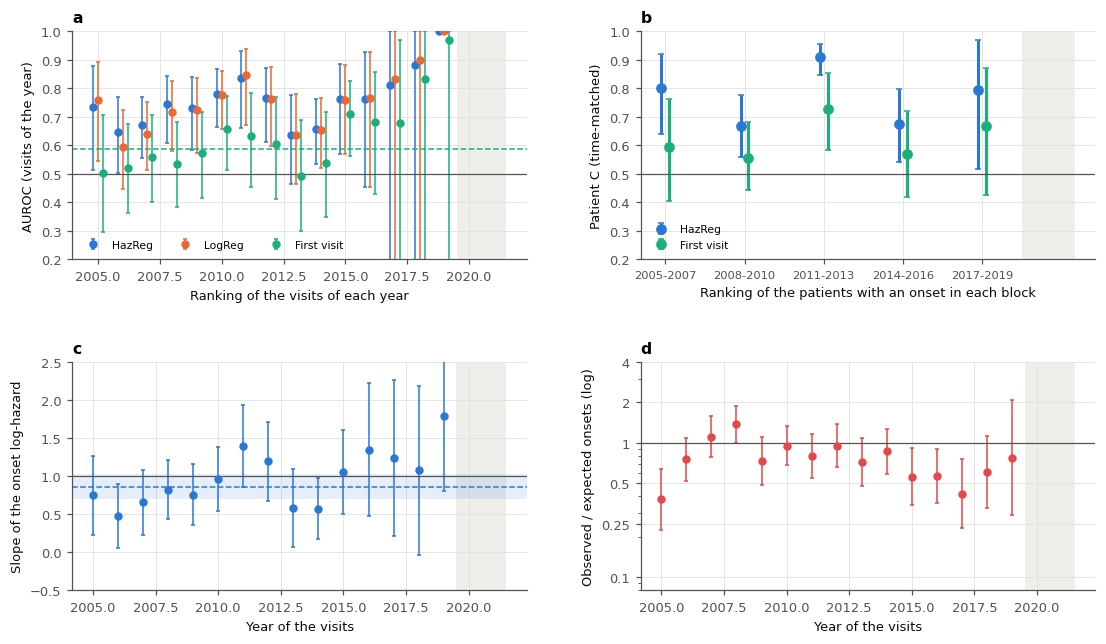

**What this means** (grey band: the COVID-19 period).

* **The ranking carries over.** Pooled over 15 years with enough onsets, the
  prequential AUROC is nan for HazReg, nan for LogReg and
  0.588 for the first-visit model. HazReg − first visit: 0.145 (0.107 to 0.182)
  (**H5a met**). Any single year is noisy (a year has
  23 onsets within 36 months, as a median): the next year's AUROC is expected
  between nan and nan. Over every onset from 2005, the
  prequential patient C is 0.747, 0.140 (0.079 to 0.199) above the first-visit model.
* **The relative risks in later years (H5c, estimated).** With each year's own baseline, the slope of the onset
  log-hazard pools to 0.86 (0.70 to 1.02): the interval lies within ± 0.30
  of 1. A slope of 1 means a patient the model ranks at twice the risk of another is at twice the recorded risk in
  later years too.
* **The absolute level does not carry over, and is not expected to.** Recorded onsets fall below the expected number
  year after year (pooled O/E 0.76; prediction interval 0.42-1.38). This is
  the pattern of Section 1.5.6: the field that records the outcome is being updated less often. **O/E is reported here,
  not tested**: after about 2015 the absolute level cannot be identified from the status field.

In [73]:
"""Year-by-year performance of the prequential risks; pooled estimates; H5a and H5c."""


def _fin_sd(x):
    """SD of the finite bootstrap values (a resample without onsets gives O/E = 0, log = -inf)."""
    x = np.asarray(x, float)
    return float(np.std(x[np.isfinite(x)], ddof=1))


def dl_pool(est, se):
    """DerSimonian-Laird random-effects pool: estimate, 95 % CI, tau^2, 95 % prediction interval."""
    est, se = np.asarray(est, float), np.asarray(se, float)
    ok = np.isfinite(est) & np.isfinite(se) & (se > 0)
    est, se = est[ok], se[ok]
    w = 1 / se ** 2
    fe = np.sum(w * est) / w.sum()
    q = np.sum(w * (est - fe) ** 2)
    k = len(est)
    tau2 = max(0.0, (q - (k - 1)) / (w.sum() - np.sum(w ** 2) / w.sum()))
    wr = 1 / (se ** 2 + tau2)
    mu = np.sum(wr * est) / wr.sum()
    se_mu = np.sqrt(1 / wr.sum())
    t = stats.t.ppf(0.975, max(k - 2, 1))
    return mu, mu - 1.96 * se_mu, mu + 1.96 * se_mu, tau2, mu - t * np.sqrt(tau2 + se_mu ** 2), \
        mu + t * np.sqrt(tau2 + se_mu ** 2)


def slope_with_own_baseline(rows, eta1):
    """Calibration slope of the onset log-hazard with the rows' own baseline: Poisson d1 ~ a + b * eta1, offset log
    person-time, patient-clustered SE. Returns (b, se)."""
    f = sm.GLM(D1[rows], sm.add_constant(eta1), family=sm.families.Poisson(), offset=np.log(INT_YRS[rows])).fit(
        cov_type="cluster", cov_kwds={"groups": ROW_PIDX[rows]})
    return float(f.params[1]), float(f.bse[1])


_rows_y = []
for Y in ORIGINS:
    te = np.flatnonzero(_lyr == Y)
    y, w = ipcw_weights(T_ALL, C_ALL, rows=te)
    Wb = W_BOOT[:, ROW_PIDX[te]]
    n_on24 = int((y * (w > 0)).sum())
    O, E = D1[te].sum(), np.sum(np.exp(ETA_PREQ[te, 0]) * INT_YRS[te])
    r = {"Year": Y, "Training landmarks": ORIG[Y]["n_tr"], "Test landmarks": len(te), "Onsets within 36 mo": n_on24,
         "Onsets (person-time)": int(O), "O/E": O / E, "O/E SE (log)": 1 / np.sqrt(max(O, 0.5))}
    if n_on24 >= 3:
        A = {n: metric_arrays(p[te], Wb, y, w, ERA_LAB[te])["AUROC"]
             for n, p in [("HazReg", P_PREQ), ("First visit", P_PREQ_DEMO), ("LogReg", P_PREQ_LR)]}
        for n, a in A.items():
            r[f"AUROC {n}"], r[f"AUROC {n} SE"] = a[0], _fin_sd(_logit(a[1:]))
        d = A["HazReg"] - A["First visit"]
        r["AUROC diff"], r["AUROC diff SE"] = d[0], _fin_sd(d[1:])
    if O >= 3:
        r["Slope"], r["Slope SE"] = slope_with_own_baseline(te, ETA_PREQ[te, 0])
    _rows_y.append(r)
PREQ = pd.DataFrame(_rows_y).set_index("Year")
save_table(PREQ.round(4), "prequential_by_year")

# patient level: time-matched C for the onsets of each 3-year block, and pooled over every onset from the first origin
PT_PREQ_ALL = build_pt_eval(use=PREQ_OK, onset_from=_day(ORIGINS[0]), onset_to=_day(ORIGINS[-1] + 1))
_pp_h = pt_metric_arrays(PT_PREQ_ALL, P_PREQ, FLAGS_PREQ)
_pp_d = pt_metric_arrays(PT_PREQ_ALL, P_PREQ_DEMO, FLAGS_PREQ_DEMO)
PREQ_PT = {"HazReg": {k: ci_of(v) for k, v in _pp_h.items()}, "First visit": {k: ci_of(v) for k, v in _pp_d.items()}}
PREQ_PT_DIFF = ci_of(_pp_h["C"] - _pp_d["C"])
_alt = next(n for n in ["High once or Raised twice in a row", "Raised or High at the latest score"] if n != RULE_NAME)
_pp_s = pt_metric_arrays(PT_PREQ_ALL, P_PREQ, alarm_flags(PCT_PREQ, ALARM_VARIANTS[_alt], mask=PREQ_OK, is_pct=True))
PREQ_RULES = pd.DataFrame({lab: {k: fmt(ci_of(A[k]), 2) for k in ["Sensitivity", "Specificity", "Balanced accuracy"]}
                           for lab, A in [(RULE_NAME, _pp_h), (_alt, _pp_s)]}).T
print("The flag on the prequential risks (each year scored by a model of the past only):")
display(PREQ_RULES)
_blocks = [(a, min(a + 3, ORIGINS[-1] + 1)) for a in range(ORIGINS[0], ORIGINS[-1] + 1, 3)]
_rows_b = []
for a, b in _blocks:
    ev = build_pt_eval(use=PREQ_OK, onset_from=_day(a), onset_to=_day(b))
    if ev["n_onsets"] < 3:
        continue
    for n, p, fl in [("HazReg", P_PREQ, FLAGS_PREQ), ("First visit", P_PREQ_DEMO, FLAGS_PREQ_DEMO)]:
        A = pt_metric_arrays(ev, p, fl)
        _rows_b.append({"Onsets in": f"{a}-{b - 1}", "Model": n, "Onsets": ev["n_onsets"],
                        **{k: ci_of(A[k]) for k in ["C", "Sensitivity", "Specificity"]}})
PREQ_PT_BLOCKS = pd.DataFrame(_rows_b)

_pool = lambda col, se, f=lambda x: x, finv=lambda x: x: tuple(finv(v) for v in np.array(
    dl_pool(f(PREQ[col].values), PREQ[se].values))[[0, 1, 2, 4, 5]])
PREQ_POOLED = {"AUROC HazReg": _pool("AUROC HazReg", "AUROC HazReg SE", _logit, _expit),
               "AUROC LogReg": _pool("AUROC LogReg", "AUROC LogReg SE", _logit, _expit),
               "AUROC First visit": _pool("AUROC First visit", "AUROC First visit SE", _logit, _expit),
               "AUROC HazReg − First visit": _pool("AUROC diff", "AUROC diff SE"),
               "Calibration slope (own baseline)": _pool("Slope", "Slope SE"),
               "O/E": _pool("O/E", "O/E SE (log)", np.log, np.exp)}
display(pd.DataFrame({k: {"Pooled (95% CI)": f"{v[0]:.3f} ({v[1]:.3f} to {v[2]:.3f})",
                          "Prediction interval, next year": f"{v[3]:.3f} to {v[4]:.3f}"} for k, v in PREQ_POOLED.items()}).T)
print(f"Prequential patient C over every onset {ORIGINS[0]}-{ORIGINS[-1]} ({PT_PREQ_ALL['n_onsets']} onsets): "
      f"HazReg {fmt(PREQ_PT['HazReg']['C'])}, First visit {fmt(PREQ_PT['First visit']['C'])}, difference "
      f"{fmt(PREQ_PT_DIFF)}; alarm sensitivity {fmt(PREQ_PT['HazReg']['Sensitivity'], 2)}, specificity "
      f"{fmt(PREQ_PT['HazReg']['Specificity'], 2)}.")
record("H5a", "The ranking carries over to later years", "Prequential AUROC, HazReg − First visit, pooled over years",
       PREQ_POOLED["AUROC HazReg − First visit"][:3], "above0")
record_pt("H5a", PREQ_PT_DIFF)
record("H5c", "How well calibrated are the relative risks in later years?",
       "Calibration slope with each year's own baseline, pooled",
       PREQ_POOLED["Calibration slope (own baseline)"][:3], "within", nd=2, within=CAL_EQUIV)

fig, axes = plt.subplots(2, 2, figsize=(12, 6.6), gridspec_kw={"hspace": 0.45, "wspace": 0.25})
_yy = PREQ.index.values
_covid_y = [int(COVID_WINDOW[0][:4]), int(COVID_WINDOW[1][:4])]
for ax in axes.ravel():
    ax.axvspan(_covid_y[0] - 0.5, _covid_y[1] + 0.5, color=GRID_C, alpha=0.6, lw=0, zorder=0)
ax = axes[0, 0]
for j, (n, col) in enumerate([("HazReg", C1), ("LogReg", C2), ("First visit", C3)]):
    a, se = PREQ[f"AUROC {n}"], PREQ[f"AUROC {n} SE"]
    ax.errorbar(_yy + (j - 1) * 0.2, a, yerr=[a - _expit(_logit(a) - 1.96 * se), _expit(_logit(a) + 1.96 * se) - a],
                fmt="o", color=col, ms=4.5, capsize=1.5, lw=1, label=n)
    ax.axhline(PREQ_POOLED[f"AUROC {n}"][0], color=col, lw=1, ls="--")
ax.axhline(0.5, color=INK_2, lw=0.8); ax.set_ylim(0.2, 1.0); ax.set_ylabel("AUROC (visits of the year)")
ax.legend(fontsize=7, ncol=3, loc="lower left"); ax.set_title("a  Ranking of the visits of each year", loc="left", fontsize=9)
ax = axes[0, 1]
for j, (n, col) in enumerate([("HazReg", C1), ("First visit", C3)]):
    t = PREQ_PT_BLOCKS[PREQ_PT_BLOCKS["Model"] == n]
    xs = np.array([int(s[:4]) + 1 for s in t["Onsets in"]]) + (j - 0.5) * 0.3
    c = np.array([list(v) for v in t["C"]])
    ax.errorbar(xs, c[:, 0], yerr=[c[:, 0] - c[:, 1], c[:, 2] - c[:, 0]], fmt="o", color=col, ms=6, capsize=2, label=n)
ax.axhline(0.5, color=INK_2, lw=0.8); ax.set_ylim(0.2, 1.0); ax.set_ylabel("Patient C (time-matched)")
ax.set_xticks([int(s[:4]) + 1 for s in PREQ_PT_BLOCKS["Onsets in"].unique()], PREQ_PT_BLOCKS["Onsets in"].unique(), fontsize=7.5)
ax.legend(fontsize=7, loc="lower left"); ax.set_title("b  Ranking of the patients with an onset in each block", loc="left", fontsize=9)
ax = axes[1, 0]
s_, se_ = PREQ["Slope"], PREQ["Slope SE"]
ax.errorbar(_yy, s_, yerr=1.96 * se_, fmt="o", color=C1, ms=4.5, capsize=1.5, lw=1)
_ps = PREQ_POOLED["Calibration slope (own baseline)"]
ax.axhspan(_ps[1], _ps[2], color=C1, alpha=0.12, lw=0); ax.axhline(_ps[0], color=C1, lw=1, ls="--")
ax.axhline(1, color=INK_2, lw=0.8); ax.set_ylim(-0.5, 2.5)
ax.set_ylabel("Slope of the onset log-hazard"); ax.set_xlabel("Year of the visits")
ax.set_title("c  Calibration of the relative risks (each year's own baseline)", loc="left", fontsize=9)
ax = axes[1, 1]
oe, se = PREQ["O/E"], PREQ["O/E SE (log)"]
ax.errorbar(_yy, oe, yerr=[oe - oe * np.exp(-1.96 * se), oe * np.exp(1.96 * se) - oe], fmt="o", color="#e34948", ms=4.5,
            capsize=1.5, lw=1)
ax.axhline(1, color=INK_2, lw=0.8); ax.set_yscale("log"); ax.set_ylim(0.08, 4)
ax.set_yticks([0.1, 0.25, 0.5, 1, 2, 4], ["0.1", "0.25", "0.5", "1", "2", "4"])
ax.set_ylabel("Observed / expected onsets (log)"); ax.set_xlabel("Year of the visits")
ax.set_title("d  Absolute level: recorded onsets against the model as fitted", loc="left", fontsize=9)
save_fig("fig05_temporal")
_pa = PREQ_POOLED
say(f"""
**What this means** (grey band: the COVID-19 period).

* **The ranking carries over.** Pooled over {len(PREQ.dropna(subset=['AUROC HazReg']))} years with enough onsets, the
  prequential AUROC is {_pa['AUROC HazReg'][0]:.3f} for HazReg, {_pa['AUROC LogReg'][0]:.3f} for LogReg and
  {_pa['AUROC First visit'][0]:.3f} for the first-visit model. HazReg − first visit: {fmt(_pa['AUROC HazReg − First visit'][:3])}
  (**H5a {"met" if HYP['H5a']['_met'] else "not met"}**). Any single year is noisy (a year has
  {int(PREQ['Onsets within 36 mo'].median())} onsets within 36 months, as a median): the next year's AUROC is expected
  between {_pa['AUROC HazReg'][3]:.2f} and {_pa['AUROC HazReg'][4]:.2f}. Over every onset from {ORIGINS[0]}, the
  prequential patient C is {PREQ_PT['HazReg']['C'][0]:.3f}, {fmt(PREQ_PT_DIFF)} above the first-visit model.
* **The relative risks in later years (H5c, estimated).** With each year's own baseline, the slope of the onset
  log-hazard pools to {_ps[0]:.2f} ({_ps[1]:.2f} to {_ps[2]:.2f}): the interval lies within ± {HYP['H5c']['_margin']:.2f}
  of 1. A slope of 1 means a patient the model ranks at twice the risk of another is at twice the recorded risk in
  later years too.
* **The absolute level does not carry over, and is not expected to.** Recorded onsets fall below the expected number
  year after year (pooled O/E {_pa['O/E'][0]:.2f}; prediction interval {_pa['O/E'][3]:.2f}-{_pa['O/E'][4]:.2f}). This is
  the pattern of Section 1.5.6: the field that records the outcome is being updated less often. **O/E is reported here,
  not tested**: after about 2015 the absolute level cannot be identified from the status field.
""")

### 4.2.1 Do the predictor effects drift?

**Coefficient paths.** The onset model refitted at each origin on all data up to then (an expanding window). Each
panel follows one input's hazard ratio per SD across origins; the dashed line is the final model.

**Closed testing** (Vergouwe et al., *Stat Med* 2017). At each origin, the model fitted on the past is confronted
with the next 3 years of data. Four candidates are compared by likelihood-ratio tests in a fixed order: **keep** the
model; **recalibrate the intercept** (a new baseline level); **recalibrate the intercept and slope**; **revise** (refit
every coefficient). The procedure stops at the simplest model that the refit does not significantly beat. It answers
the question every maintenance plan has to: is it only the level that moves, or the ranking too?

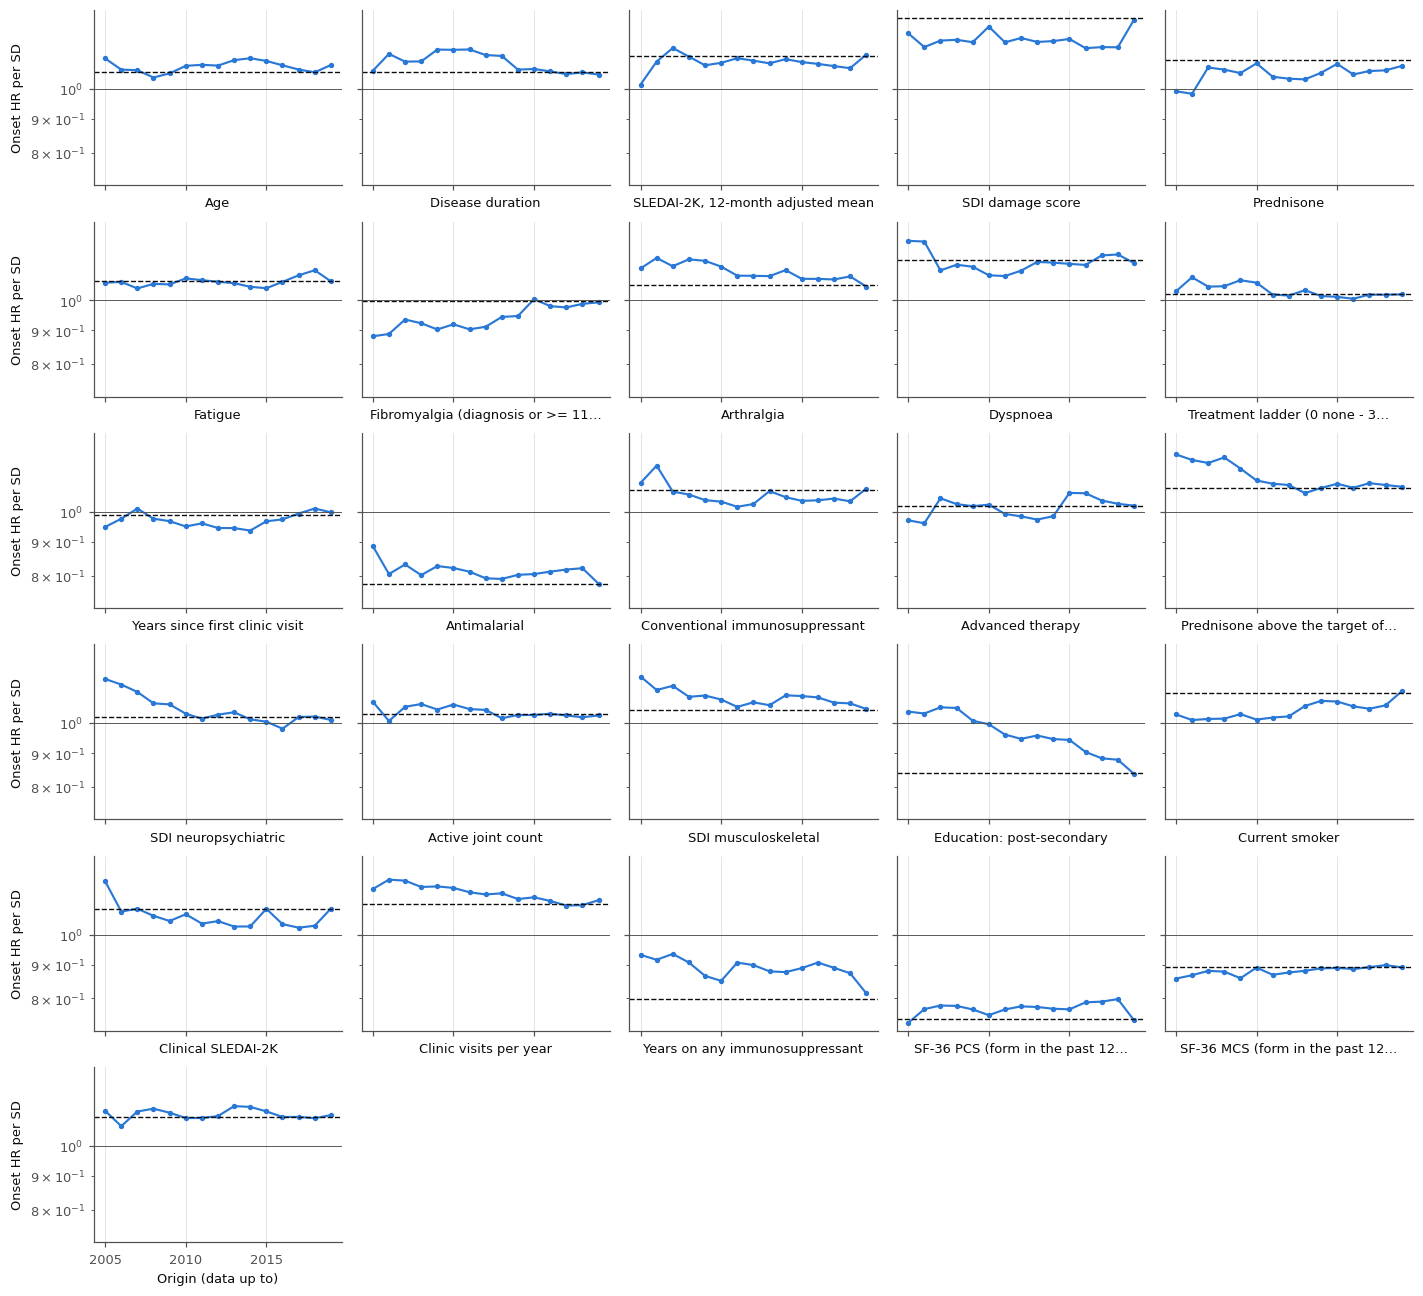

,Onsets,p: revised vs kept,p: revised vs intercept,p: revised vs intercept + slope,New intercept (O/E),New slope,Decision
2005,74,0.0,0.0,0.0,0.719183,0.527703,Revise
2006,97,0.0,0.0,0.0,0.933312,0.656029,Revise
2007,92,0.000002,0.000001,0.000006,0.986365,0.736685,Revise
2008,93,0.0,0.0,0.0,1.028045,0.809625,Revise
2009,83,0.000001,0.000001,0.000001,0.870829,1.025026,Revise
2010,88,0.000002,0.000002,0.000002,0.889568,1.139611,Revise
2011,78,0.0,0.0,0.0,0.792326,1.096238,Revise
2012,76,0.0,0.0,0.0,0.837408,0.807847,Revise
2013,64,0.0,0.0,0.0,0.685963,0.746199,Revise
2014,59,0.0,0.0,0.0,0.66723,0.988357,Revise


**What this means.**

* **Closed testing.** Over 14 origins, the procedure chose: revise 14
  time(s). Revisions are frequent: the ranking itself is moving and the model needs refitting, not only recalibration.
  The refit has as many parameters as the model, against 75 onsets (median) in each
  3-year window, so the test has little power to demand a revision: "keep the coefficients" means *no evidence that
  they changed*, not proof that they did not.
* **Coefficient paths.** The inputs whose effect moved most across origins are Education: post-secondary, SDI neuropsychiatric, Prednisone above the target of the time.
  Early origins rest on few onsets and wobble; from about 2012 the paths settle near the final model.

In [74]:
"""Coefficient paths over the rolling origins, and the closed testing procedure at each origin."""
_main_terms = [c for c in COMPACT_VARS]
_paths = {}
for Y, o in ORIG.items():
    names = o["model"]["prep"].names
    _paths[Y] = {DISPLAY[c]: np.exp(o["model"]["coef"][0][names.index(c)]) for c in _main_terms if c in names}
COEF_PATHS = pd.DataFrame(_paths).T
save_table(COEF_PATHS.round(3), "coefficient_paths")
_final_hr = {DISPLAY[c]: np.exp(FINAL["coef"][0][FINAL["prep"].names.index(c)]) for c in _main_terms}
_nc = 5
_nr = int(np.ceil(len(COEF_PATHS.columns) / _nc))
fig, axes = plt.subplots(_nr, _nc, figsize=(13, 2.0 * _nr), sharex=True, sharey=True)
for ax, c in zip(axes.ravel(), COEF_PATHS.columns):
    ax.plot(COEF_PATHS.index, COEF_PATHS[c], "-o", ms=2.5, color=C1, lw=1.4)
    ax.axhline(_final_hr[c], color=INK, lw=0.9, ls="--")
    ax.axhline(1, color=INK_2, lw=0.6)
    ax.set_title(textwrap.shorten(c, 34, placeholder="…"), loc="left", fontsize=7.5)
    ax.set_yscale("log")
for ax in axes.ravel()[len(COEF_PATHS.columns):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("Onset HR per SD")
for ax in axes[-1]:
    ax.set_xlabel("Origin (data up to)")
plt.tight_layout(); save_fig("coefficient_paths")


def closed_test(m, rows, alpha=0.05, eta=None, d=None, dt=None):
    """Vergouwe et al. (2017) closed testing for a Poisson hazard model on new data `rows`. eta, d, dt: the current
    onset log-hazard (a recalibrated model) and the events and person-time (follow-up cut at a date), if not the
    model's own and the full follow-up."""
    X = design(m, LAND_X.iloc[rows])
    eta = X @ m["coef"][0] + m["intercept"][0] if eta is None else eta
    d = D1[rows] if d is None else d
    dt = INT_YRS[rows] if dt is None else dt
    ll = lambda mu: float(np.sum(d * np.log(np.maximum(mu, 1e-300)) - mu))
    mu0 = np.exp(eta) * dt
    ll0 = ll(mu0)
    a1 = np.log(max(d.sum(), 0.5) / mu0.sum())
    ll1 = ll(mu0 * np.exp(a1))
    f2 = sm.GLM(d, sm.add_constant(eta), family=sm.families.Poisson(), offset=np.log(dt)).fit()
    ll2 = ll(f2.mu)
    f3 = PoissonRegressor(alpha=1e-6, max_iter=5000).fit(X, d / dt, sample_weight=dt)
    ll3 = ll(f3.predict(X) * dt)
    p = X.shape[1]
    pv = lambda lr, df: float(stats.chi2.sf(max(lr, 0.0), df))
    p03, p13, p23 = pv(2 * (ll3 - ll0), p + 1), pv(2 * (ll3 - ll1), p), pv(2 * (ll3 - ll2), p - 1)
    decision = ("Keep" if p03 >= alpha else "Recalibrate intercept" if p13 >= alpha else
                "Recalibrate intercept + slope" if p23 >= alpha else "Revise")
    return {"Onsets": int(d.sum()), "p: revised vs kept": p03, "p: revised vs intercept": p13,
            "p: revised vs intercept + slope": p23, "New intercept (O/E)": float(np.exp(a1)),
            "New slope": float(f2.params[1]), "_c0": float(f2.params[0]), "Decision": decision}


_ct = {}
for Y, o in ORIG.items():
    rows = np.flatnonzero((LAND_T >= _day(Y)) & (LAND_T < _day(Y + CLOSED_TEST_YEARS)))
    if D1[rows].sum() >= 5:
        _ct[Y] = closed_test(o["model"], rows)
CLOSED = pd.DataFrame(_ct).T.drop(columns="_c0")
display(CLOSED.round(3))
save_table(CLOSED, "closed_testing")
_dec = CLOSED["Decision"].value_counts()
_drift = COEF_PATHS.apply(lambda s: np.log(s).std()).sort_values(ascending=False)
say(f"""
**What this means.**

* **Closed testing.** Over {len(CLOSED)} origins, the procedure chose: {", ".join(f"{k.lower()} {v}" for k, v in _dec.items())}
  time(s). {"A new baseline level is enough far more often than a revision: the ranking is stable and only the level moves." if _dec.get("Revise", 0) <= len(CLOSED) / 4 else "Revisions are frequent: the ranking itself is moving and the model needs refitting, not only recalibration."}
  The refit has as many parameters as the model, against {int(CLOSED['Onsets'].median())} onsets (median) in each
  3-year window, so the test has little power to demand a revision: "keep the coefficients" means *no evidence that
  they changed*, not proof that they did not.
* **Coefficient paths.** The inputs whose effect moved most across origins are {", ".join(_drift.index[:3])}.
  Early origins rest on few onsets and wobble; from about {ORIGINS[len(ORIGINS) // 2]} the paths settle near the final model.
""")

### 4.2.2 Leaving one era out (internal-external cross-validation)

> **The idea.** The rolling origins of Section 4.2 only look forward, one year at a time. Here each clinical era is
> held out in turn, HazReg is fitted on every other era, and the held-out era is scored (Steyerberg & Harrell, *J
> Clin Epidemiol* 2016). The eras' performances are then pooled with a random-effects model, so the result says not
> only how well the model does on average but **how much its performance varies from one era to the next**
> (Snell et al., *Stat Methods Med Res* 2018).

Training uses the landmarks outside the held-out era. Follow-up that runs into the held-out era is cut at its start,
so no outcome from those calendar years enters the fit; a patient followed across eras can contribute to training
in one era and be scored in another. Measures per held-out era: AUROC of the 36-month risk (IPCW), calibration slope
of the onset log-hazard with the era's own baseline (the relative risks), and observed / expected onsets (the
absolute level, which depends on the recording: Section 1.5.6). Pooled on the logit, identity and log scales; the
prediction interval is the range expected for a new era.

,Training landmarks,Test landmarks,Onsets within 36 mo,AUROC 95% CI,Calibration slope,O/E
Held-out era,,,,,,
<= 2001,10462,2514,158,0.760 (0.687 to 0.826),0.98 (0.68 to 1.28),0.88 (0.75 to 1.03)
2002-10,8490,4486,268,0.719 (0.658 to 0.776),0.73 (0.53 to 0.93),1.31 (1.16 to 1.47)
2011-19,7000,5976,162,0.737 (0.644 to 0.826),1.10 (0.75 to 1.45),0.64 (0.55 to 0.75)


,Pooled (95% CI),"Prediction interval, new era",Between-era tau
AUROC,0.736 (0.692 to 0.775),0.413 to 0.917,0.000
Calibration slope (own baseline),0.903 (0.674 to 1.132),-1.473 to 3.279,0.146
O/E,0.905 (0.592 to 1.383),0.004 to 204.956,0.368


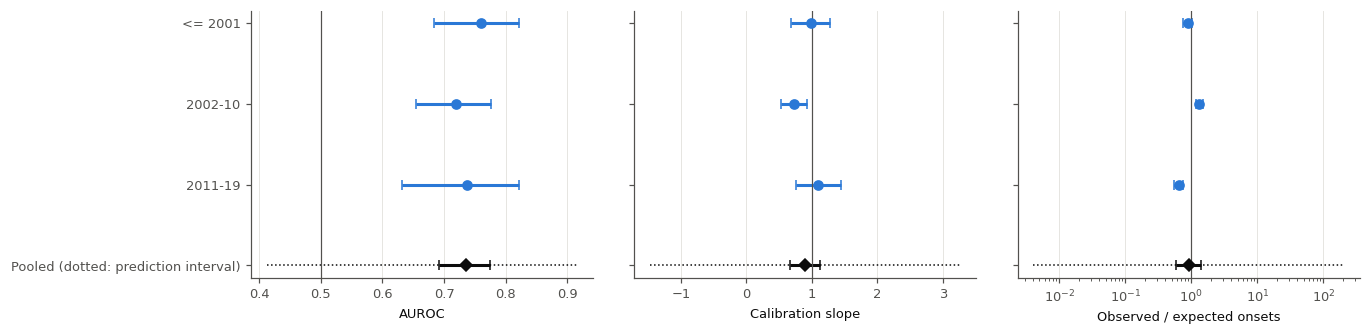

**What this means.** Held out one era at a time, HazReg ranks the landmarks of that era with a pooled AUROC of
0.736 (0.692 to 0.775); a new era is expected between 0.41 and 0.92
(between-era τ on the logit scale 0.00). With each era's own baseline, the
slope of the onset log-hazard pools to 0.90 (0.67 to 1.13); in 2002-10 the slope's interval excludes 1, so the relative risks there are not those the model predicts.
The absolute level moves: O/E runs from 1.31 (2002-10) to
0.64 (2011-19), and with 3 eras the prediction interval for a
new era (0.00-204.96) is wide. Holding out the first era asks the model to predict *backwards*. The
latest era rests on 162 onsets within 36 months, so its estimates are
the least precise.

In [75]:
"""Leave-one-era-out: HazReg fitted on the other eras, scored on the held-out one; random-effects pooling over eras."""


def _era_out_fit(e):
    a, b = [(x[0], x[1]) for x in ERAS if x[2] == e][0]
    lo, hi = _day(a), _day(b)
    before, after = LAND_T < lo, LAND_T >= hi
    tr = np.flatnonzero(before | after)
    dt = np.where(before, (np.minimum(INT_END, lo) - LAND_T) / 365.25, INT_YRS)
    keep = ~before | (INT_END <= lo)                 # an interval of a landmark before the era is cut at its start
    m = fit_procedure(tr, dt=dt, d1=D1 * keep, d2=D2 * keep, seed=SEED + 7 * ERA_NAMES.index(e))
    return {"era": e, "n_tr": len(tr), "base": m["base"], "eta": predict_eta(m).astype(np.float32)}


_iecv_eras = [e for e in ERA_NAMES if (D1[ERA_LAB == e].sum() >= 5)]
if STATE.get("iecv_eras", {}).get("eras") != _iecv_eras:
    t0 = time.time()
    _fits = Parallel(n_jobs=min(N_JOBS, len(_iecv_eras)))(delayed(_era_out_fit)(e) for e in _iecv_eras)
    STATE["iecv_eras"] = {"eras": _iecv_eras, "fits": {f["era"]: f for f in _fits}}
    _save_state()
    print(f"{len(_iecv_eras)} leave-one-era-out fits ({(time.time() - t0) / 60:.1f} min).")
_IE = STATE["iecv_eras"]["fits"]
_rows_ie = []
for e in _iecv_eras:
    te = np.flatnonzero(ERA_LAB == e)
    eta = _IE[e]["eta"].astype(float)
    y, w = ipcw_weights(T_ALL, C_ALL, rows=te)
    Wb = W_BOOT[:, ROW_PIDX[te]]
    a = metric_arrays(cif(eta, base=_IE[e]["base"])[te], Wb, y, w, ERA_LAB[te])["AUROC"]
    O, E = D1[te].sum(), np.sum(np.exp(eta[te, 0]) * INT_YRS[te])
    sl, sl_se = slope_with_own_baseline(te, eta[te, 0])
    _rows_ie.append({"Held-out era": e, "Training landmarks": _IE[e]["n_tr"], "Test landmarks": len(te),
                     "Onsets within 36 mo": int((y * (w > 0)).sum()), "Onsets (person-time)": int(O),
                     "AUROC": a[0], "AUROC SE (logit)": _fin_sd(_logit(a[1:])), "AUROC 95% CI": fmt(ci_of(a)),
                     "Slope": sl, "Slope SE": sl_se, "O/E": O / E, "O/E SE (log)": 1 / np.sqrt(max(O, 0.5))})
IECV_ERA = pd.DataFrame(_rows_ie).set_index("Held-out era")
IECV_POOLED = {"AUROC": tuple(_expit(v) for v in np.array(dl_pool(_logit(IECV_ERA["AUROC"].values),
                                                                  IECV_ERA["AUROC SE (logit)"].values))[[0, 1, 2, 4, 5]]),
               "Calibration slope (own baseline)": tuple(np.array(dl_pool(IECV_ERA["Slope"].values,
                                                                          IECV_ERA["Slope SE"].values))[[0, 1, 2, 4, 5]]),
               "O/E": tuple(np.exp(v) for v in np.array(dl_pool(np.log(IECV_ERA["O/E"].values),
                                                               IECV_ERA["O/E SE (log)"].values))[[0, 1, 2, 4, 5]])}
IECV_TAU = {"AUROC (logit)": dl_pool(_logit(IECV_ERA["AUROC"].values), IECV_ERA["AUROC SE (logit)"].values)[3],
            "Calibration slope": dl_pool(IECV_ERA["Slope"].values, IECV_ERA["Slope SE"].values)[3],
            "O/E (log)": dl_pool(np.log(IECV_ERA["O/E"].values), IECV_ERA["O/E SE (log)"].values)[3]}
display(IECV_ERA[["Training landmarks", "Test landmarks", "Onsets within 36 mo", "AUROC 95% CI"]].assign(
    **{"Calibration slope": [f"{s:.2f} ({s - 1.96 * se:.2f} to {s + 1.96 * se:.2f})"
                             for s, se in zip(IECV_ERA["Slope"], IECV_ERA["Slope SE"])],
       "O/E": [f"{o:.2f} ({o * np.exp(-1.96 * se):.2f} to {o * np.exp(1.96 * se):.2f})"
               for o, se in zip(IECV_ERA["O/E"], IECV_ERA["O/E SE (log)"])]}))
IECV_POOLED_TABLE = pd.DataFrame({k: {"Pooled (95% CI)": f"{v[0]:.3f} ({v[1]:.3f} to {v[2]:.3f})",
                                      "Prediction interval, new era": f"{v[3]:.3f} to {v[4]:.3f}",
                                      "Between-era tau": f"{np.sqrt(t):.3f}"}
                                  for (k, v), t in zip(IECV_POOLED.items(), IECV_TAU.values())}).T
display(IECV_POOLED_TABLE)
save_table(IECV_ERA.round(4), "iecv_by_era")
save_table(IECV_POOLED_TABLE, "iecv_pooled")

fig, axes = plt.subplots(1, 3, figsize=(13, 0.45 * len(IECV_ERA) + 1.8), sharey=True, gridspec_kw={"wspace": 0.12})
_yy = np.arange(len(IECV_ERA))
for ax, (lab, est, lo, hi, pooled, ref, log) in zip(axes, [
        ("AUROC", IECV_ERA["AUROC"], _expit(_logit(IECV_ERA["AUROC"]) - 1.96 * IECV_ERA["AUROC SE (logit)"]),
         _expit(_logit(IECV_ERA["AUROC"]) + 1.96 * IECV_ERA["AUROC SE (logit)"]), IECV_POOLED["AUROC"], 0.5, False),
        ("Calibration slope (own baseline)", IECV_ERA["Slope"], IECV_ERA["Slope"] - 1.96 * IECV_ERA["Slope SE"],
         IECV_ERA["Slope"] + 1.96 * IECV_ERA["Slope SE"], IECV_POOLED["Calibration slope (own baseline)"], 1.0, False),
        ("Observed / expected onsets", IECV_ERA["O/E"], IECV_ERA["O/E"] * np.exp(-1.96 * IECV_ERA["O/E SE (log)"]),
         IECV_ERA["O/E"] * np.exp(1.96 * IECV_ERA["O/E SE (log)"]), IECV_POOLED["O/E"], 1.0, True)]):
    ax.errorbar(est, _yy, xerr=[est - lo, hi - est], fmt="o", color=C1, ms=6, capsize=3)
    ax.errorbar([pooled[0]], [len(_yy)], xerr=[[pooled[0] - pooled[1]], [pooled[2] - pooled[0]]], fmt="D", color=INK,
                ms=6, capsize=3)
    ax.hlines(len(_yy), pooled[3], pooled[4], color=INK, lw=1, ls=":")
    ax.axvline(ref, color=INK_2, lw=0.8)
    if log:
        ax.set_xscale("log")
    ax.set_title(lab, loc="left", fontsize=9); ax.grid(axis="y", visible=False)
axes[0].set_yticks(list(_yy) + [len(_yy)], list(IECV_ERA.index) + ["Pooled (dotted: prediction interval)"])
axes[0].invert_yaxis()
save_fig("iecv_by_era")
_pa, _ps, _po = IECV_POOLED["AUROC"], IECV_POOLED["Calibration slope (own baseline)"], IECV_POOLED["O/E"]
_sl_off = [e for e, r in IECV_ERA.iterrows() if abs(r["Slope"] - 1) > 1.96 * r["Slope SE"]]
say(f"""
**What this means.** Held out one era at a time, HazReg ranks the landmarks of that era with a pooled AUROC of
{_pa[0]:.3f} ({_pa[1]:.3f} to {_pa[2]:.3f}); a new era is expected between {_pa[3]:.2f} and {_pa[4]:.2f}
(between-era τ on the logit scale {np.sqrt(IECV_TAU['AUROC (logit)']):.2f}). With each era's own baseline, the
slope of the onset log-hazard pools to {_ps[0]:.2f} ({_ps[1]:.2f} to {_ps[2]:.2f}){
"" if not len(_sl_off) else "; in " + ", ".join(_sl_off) + " the slope's interval excludes 1, so the relative risks there are " + ("more spread out than the model predicts" if all(IECV_ERA.loc[_sl_off, "Slope"] > 1) else "not those the model predicts")}.
The absolute level moves: O/E runs from {IECV_ERA['O/E'].max():.2f} ({IECV_ERA['O/E'].idxmax()}) to
{IECV_ERA['O/E'].min():.2f} ({IECV_ERA['O/E'].idxmin()}), and with {len(IECV_ERA)} eras the prediction interval for a
new era ({_po[3]:.2f}-{_po[4]:.2f}) is wide. Holding out the first era asks the model to predict *backwards*. The
latest era rests on {int(IECV_ERA['Onsets within 36 mo'].iloc[-1])} onsets within 36 months, so its estimates are
the least precise.
""")

## 4.3 Calendar time in the model: HazReg against a model with a calendar term

> **The question.** HazReg has no calendar term. What would one change, and what would scoring it at the latest year do?

Temporal recalibration (Booth et al., *Stat Med* 2020) adds a calendar-year spline to both baselines and scores every landmark at the **latest year of the training data**. Its predictor effects are
then estimated *within* calendar time, and its absolute risk is the risk *under the most recent recording the model has
seen*. Without the term, HazReg has one risk scale, the average recording of the development years, and an input that fell
over the years together with the recorded exits (prednisone, for example) can borrow part of the trend of the outcome.

Two analyses, with the same inputs and the same patient splits:

1. **The calendar-time model.** The cross-validated linear predictor of HazReg is entered into a Poisson model of each exit
   with a smooth function of calendar year (natural cubic spline, 4 df) in the baseline and an **LP × calendar time**
   interaction (a step for the COVID-19 period only if the data reach it). The spline shows how the recorded level drifted away from HazReg's level,
   with a confidence band; the interaction tests whether the ranking drifts (H5b).
2. **Three scorings.** HazReg; the model with the calendar term at the landmark's **own** year (what was recorded then);
   and the same model at the **latest** year.

| | Hypothesis | What is compared | Met if |
|:--|:--|:--|:--|
| H5b | How much does the ranking drift over calendar time? | LP × calendar time (per decade) in the calendar-time model | Estimated: the smallest margin around 0 that holds the 95 % CI |

Estimate            95% CI      p
Exit       Term                                                             
Onset      Calibration slope of the LP        0.916    0.713 to 1.119  0.417
           LP x calendar time, per decade    -0.012   -0.274 to 0.251  0.930
Other exit Calibration slope of the LP       -0.171   -1.211 to 0.870  0.027
           LP x calendar time, per decade    -1.699  -3.044 to -0.355  0.013

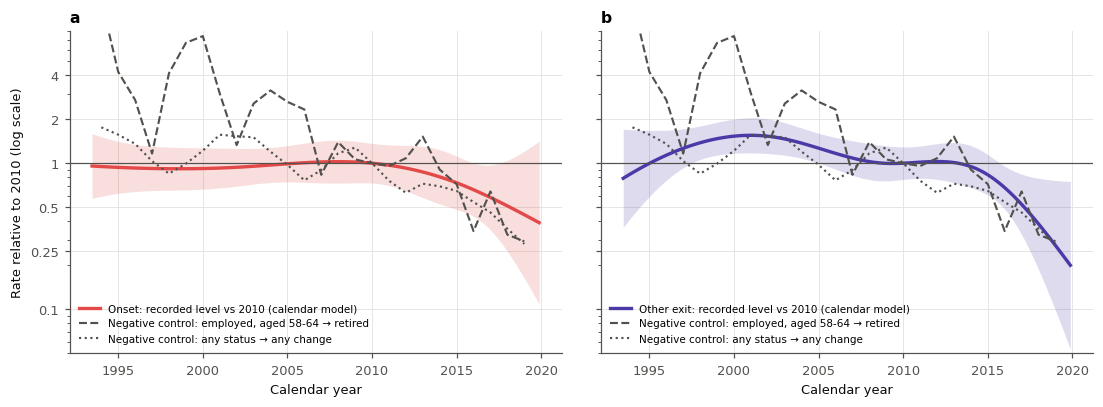

**What this means.**

* **The recorded level drifts by about -5 % a year** between 2007 and 2017, for
  onsets and for other exits alike (panels a and b). The negative controls of Section 1.5.6 (dashed and dotted) drift
  with them: the onset curve moves like the curves of transitions that lupus care cannot affect.
* **The COVID-19 period** is outside the data of this part (visits before March 2020).
* **Drift of the ranking (H5b, estimated).** The cross-validated LP has a slope of 0.92
  (0.713 to 1.119) once the baseline follows calendar time, and its interaction with
  calendar time is -0.012 per decade
  (-0.274 to 0.251): any drift lies within ± 0.27 per decade.

In [76]:
"""The calendar-time model: cross-validated LP, calendar spline per cause, COVID step, LP x calendar time."""
_cal = {"x": LAND_YEAR}
_CR = dmatrix("cr(x, df=4, constraints='center') - 1", _cal, return_type="dataframe")
_CR_INFO = _CR.design_info
_cr_at = lambda yrs: np.asarray(build_design_matrices([_CR_INFO], {"x": np.asarray(yrs, float)})[0])
_dec10 = (LAND_YEAR - 2010) / 10.0
_HAS_COVID = bool(np.any(IN_COVID))              # the data of this part end before the COVID-19 period
_cov_cols = [IN_COVID.astype(float)] if _HAS_COVID else []
CAL_MODEL = {}
for k, (cause, d) in enumerate([("Onset", D1), ("Other exit", D2)]):
    lp = ETA_CV[:, k]
    # level: HazReg's prediction as offset, so exp(intercept + spline) is O/E by calendar time
    Xl = sm.add_constant(np.column_stack([_CR.values] + _cov_cols))
    fl = sm.GLM(d, Xl, family=sm.families.Poisson(), offset=np.log(INT_YRS) + lp).fit(
        cov_type="cluster", cov_kwds={"groups": ROW_PIDX})
    # slope and drift of the slope: LP and LP x calendar time, with the same baseline terms
    Xs = sm.add_constant(np.column_stack([_CR.values] + _cov_cols + [lp, lp * _dec10]))
    fs = sm.GLM(d, Xs, family=sm.families.Poisson(), offset=np.log(INT_YRS)).fit(
        cov_type="cluster", cov_kwds={"groups": ROW_PIDX})
    CAL_MODEL[cause] = {"level": fl, "slope": fs}
_grid = np.linspace(np.percentile(LAND_YEAR, 1), np.percentile(LAND_YEAR, 99.5), 120)


def level_curve(cause, yrs, covid=0.0):
    """O/E of HazReg by calendar year (log scale, with SE), from the calendar-time level model."""
    f = CAL_MODEL[cause]["level"]
    X = np.column_stack([np.ones(len(yrs)), _cr_at(yrs)] + ([np.full(len(yrs), covid)] if _HAS_COVID else []))
    est = X @ f.params
    se = np.sqrt(np.einsum("ij,jk,ik->i", X, f.cov_params(), X))
    return est, se


def cal_multiplier(cause, yrs):
    """The recorded level at calendar time `yrs` relative to HazReg (exp of the level curve, COVID included)."""
    yrs = np.asarray(yrs, float)
    covid = ((yrs >= 2020 + 2 / 12) & (yrs < 2022)).astype(float)
    f = CAL_MODEL[cause]["level"]
    X = np.column_stack([np.ones(len(yrs)), _cr_at(np.clip(yrs, _grid[0], _grid[-1]))] + ([covid] if _HAS_COVID else []))
    return np.exp(X @ f.params)


_rows_cm = []
for cause, f in CAL_MODEL.items():
    fs = f["slope"]
    nb = _CR.shape[1]
    _h = int(_HAS_COVID)
    for nm, j in ([("COVID-19 step (HR)", nb + 1)] if _HAS_COVID else []) + [("Calibration slope of the LP", nb + 1 + _h),
                                                                              ("LP x calendar time, per decade", nb + 2 + _h)]:
        b, se = fs.params[j], fs.bse[j]
        tr = np.exp if nm.startswith("COVID") else (lambda x: x)
        _rows_cm.append({"Exit": cause, "Term": nm, "Estimate": tr(b), "95% CI": f"{tr(b - 1.96 * se):.3f} to {tr(b + 1.96 * se):.3f}",
                         "p": 2 * stats.norm.sf(abs(b / se)) if not nm.startswith("Calibration") else
                         2 * stats.norm.sf(abs((b - 1) / se))})
CAL_TERMS = pd.DataFrame(_rows_cm).set_index(["Exit", "Term"])
display(CAL_TERMS.round(3))
save_table(CAL_TERMS, "calendar_model_terms")
_fs1 = CAL_MODEL["Onset"]["slope"]
_jx = _CR.shape[1] + 2 + int(_HAS_COVID)
record("H5b", "How much does the ranking drift over calendar time?",
       "LP × calendar time, onset, per decade",
       (_fs1.params[_jx], _fs1.params[_jx] - 1.96 * _fs1.bse[_jx], _fs1.params[_jx] + 1.96 * _fs1.bse[_jx]), "within",
       within=(-DRIFT_MARGIN, DRIFT_MARGIN))

# the drift of the recorded level against the drift of the negative controls (Section 1.5.6), both relative to 2010
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, gridspec_kw={"wspace": 0.08})
_ref_l = {c: level_curve(c, np.array([2010.0]))[0][0] for c in CAL_MODEL}
for ax, cause, col in [(axes[0], "Onset", LEFT_C), (axes[1], "Other exit", OTHER_C)]:
    est, se = level_curve(cause, _grid)
    est = est - _ref_l[cause]
    ax.fill_between(_grid, np.exp(est - 1.96 * se), np.exp(est + 1.96 * se), color=col, alpha=0.18, lw=0)
    ax.plot(_grid, np.exp(est), color=col, lw=2.2, label=f"{cause}: recorded level vs 2010 (calendar model)")
    for nm, ls in [("Employed, aged 58-64 → retired", "--"), ("Any status → any change", ":")]:
        t = TRANS_YEARLY[nm]
        if 2010 in t.index:
            ax.plot(t.index, t["rate"] / t.loc[2010, "rate"], ls, color=INK_2, lw=1.4, label=f"Negative control: {nm.lower()}")
    if _HAS_COVID:
        ax.axvspan(2020 + 2 / 12, 2022, color=GRID_C, alpha=0.6, lw=0)
    ax.axhline(1, color=INK_2, lw=0.8); ax.set_yscale("log"); ax.set_ylim(0.05, 8)
    ax.set_yticks([0.1, 0.25, 0.5, 1, 2, 4], ["0.1", "0.25", "0.5", "1", "2", "4"])
    ax.set_xlabel("Calendar year"); ax.legend(fontsize=6.8, loc="lower left")
    ax.set_title(f"{'a' if cause == 'Onset' else 'b'}  {cause}", loc="left", fontsize=9)
axes[0].set_ylabel("Rate relative to 2010 (log scale)")
save_fig("calendar_drift")
_e07, _ = level_curve("Onset", np.array([2007.0])); _e17, _ = level_curve("Onset", np.array([2017.0]))
TREND_PER_YEAR = float((_e17[0] - _e07[0]) / 10)
_cm = CAL_TERMS.loc["Onset"]
say(f"""
**What this means.**

* **The recorded level drifts by about {100 * (np.exp(TREND_PER_YEAR) - 1):+.0f} % a year** between 2007 and 2017, for
  onsets and for other exits alike (panels a and b). The negative controls of Section 1.5.6 (dashed and dotted) drift
  with them: the onset curve moves like the curves of transitions that lupus care cannot affect.
{f"* **The COVID-19 period** adds a step of {_cm.loc['COVID-19 step (HR)', 'Estimate']:.2f} ({_cm.loc['COVID-19 step (HR)', '95% CI']}) on top of the trend." if _HAS_COVID else "* **The COVID-19 period** is outside the data of this part (visits before March 2020)."}
* **Drift of the ranking (H5b, estimated).** The cross-validated LP has a slope of {_cm.loc['Calibration slope of the LP', 'Estimate']:.2f}
  ({_cm.loc['Calibration slope of the LP', '95% CI']}) once the baseline follows calendar time, and its interaction with
  calendar time is {_cm.loc['LP x calendar time, per decade', 'Estimate']:+.3f} per decade
  ({_cm.loc['LP x calendar time, per decade', '95% CI']}): any drift lies within ± {HYP['H5b']['_margin']:.2f} per decade.
""")

,HazReg (no calendar term),"Calendar term, at the landmark's own year","Calendar term, at the latest year"
AUROC,0.744 (0.700 to 0.786),0.745 (0.701 to 0.787),0.744 (0.699 to 0.786)
Within-era AUROC,0.733 (0.689 to 0.775),0.731 (0.687 to 0.772),0.734 (0.691 to 0.776)
IPA,0.041 (0.009 to 0.068),0.037 (0.005 to 0.064),0.037 (0.005 to 0.064)
O/E,0.959 (0.787 to 1.139),0.984 (0.807 to 1.170),0.984 (0.807 to 1.170)
Calibration slope,0.915 (0.752 to 1.105),0.901 (0.737 to 1.097),0.901 (0.737 to 1.097)
Patient C (time-matched),0.758 (0.717 to 0.798),0.756 (0.713 to 0.796),0.761 (0.719 to 0.800)
AUROC − HazReg,NaN,0.001 (-0.007 to 0.009),-0.000 (-0.005 to 0.004)
Within-era AUROC − HazReg,NaN,-0.003 (-0.007 to 0.002),0.001 (-0.003 to 0.005)
Patient C − HazReg,NaN,-0.003 (-0.008 to 0.002),0.003 (-0.003 to 0.008)


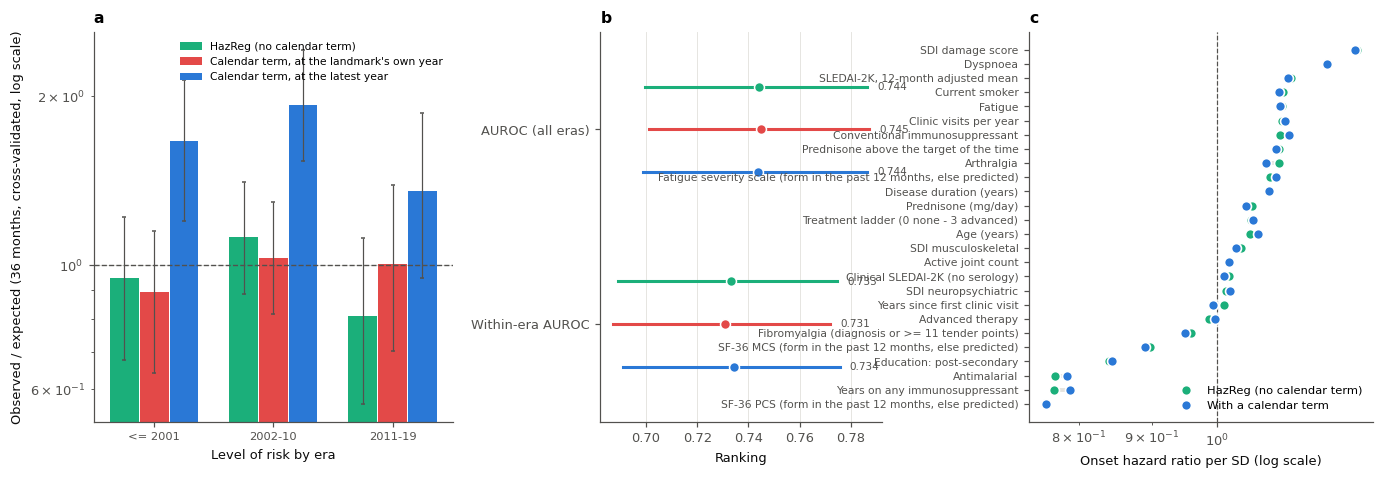

**What this means.**

* **Level.** HazReg's O/E falls from 0.95 (<= 2001) to 0.81
  (2011-19): one risk scale, the average recording of the development years, set against a recorded level that fell.
  Scored at the landmark's own year, the calendar model tracks the recorded level in every era
  (0.89 → 1.00), as it must: it has been told the year. Scored at the latest
  year, it predicts the risk under the most recent recording for every landmark, so its O/E is
  1.66 in the first era and 1.36 in the last. **None of the three can say what the
  true recent level is**; they differ in which recording they assume.
* **Ranking.** Within eras, which is the fair comparison, a calendar term changes the AUROC by 0.001 (-0.003 to 0.005) (latest year) and
  -0.003 (-0.007 to 0.002) (own year) against HazReg. Any higher all-eras AUROC at the landmark's own year comes from ranking early
  landmarks above recent ones, which is the recording trend, not the patients.
* **Predictor effects.** Estimated within calendar time, the largest changes are in
  years on any immunosuppressant (+3 %), conventional immunosuppressant (+2 %), arthralgia (-2 %). These inputs changed over the
  years together with the recorded exits, so in HazReg part of their effect may be the era.

In [77]:
"""HazReg (no calendar term) against the model with a calendar term, at the landmark's own year and at the latest year."""
if "cv_HazReg + calendar (to March 2020)" not in STATE:
    t0 = time.time()
    STATE["cv_HazReg + calendar (to March 2020)"] = run_cv("haz", COMPACT_VARS, SPLINE_VARS, calendar=True)
    _save_state()
    print(f"HazReg with a calendar term: cross-validated in {(time.time() - t0) / 60:.1f} min")
TA_NAMES = {"HazReg (no calendar term)": "HazReg", "Calendar term, at the landmark's own year": "TA actual",
            "Calendar term, at the latest year": "TA latest"}
P_CV["TA latest"] = cv_risk("HazReg + calendar (to March 2020)")
P_CV["TA actual"] = cv_risk("HazReg + calendar (to March 2020)", "pred_own")
for n, pa in [("TA latest", P_CV["TA actual"]), ("TA actual", None)]:      # absolute measures at the recording of the landmark's own year
    CV_RES[n], CV_ARR[n] = summarise(P_CV[n], p_abs=pa)
    FLAGS[n] = alarm_flags(P_CV[n])
    PT_RES[n], PT_ARR[n] = pt_summary(PT_EVAL, P_CV[n], FLAGS[n])
for k_, kw in [("final_cal_pre2020", {"calendar": True}), ("final_raw_pre2020", {})]:
    if k_ not in STATE:
        STATE[k_] = fit_procedure(np.arange(N_LAND), seed=SEED, **kw)
        _save_state()
FINAL_TA, FINAL_RAW = STATE["final_cal_pre2020"], STATE["final_raw_pre2020"]
P_FULL_TA_REF = cif(predict_eta(FINAL_TA), base=FINAL_TA["base"])           # calendar fixed at the latest year before March 2020

TA_TABLE = pd.DataFrame({lab: {k: fmt(CV_RES[n][k]) for k in ["AUROC", "Within-era AUROC", "IPA", "O/E", "Calibration slope"]}
                         | {"Patient C (time-matched)": fmt(PT_RES[n]["C"])} for lab, n in TA_NAMES.items()})
for lab, n in list(TA_NAMES.items())[1:]:
    TA_TABLE.loc["AUROC − HazReg", lab] = fmt(paired(n, "HazReg"))
    TA_TABLE.loc["Within-era AUROC − HazReg", lab] = fmt(paired(n, "HazReg", "Within-era AUROC"))
    TA_TABLE.loc["Patient C − HazReg", lab] = fmt(ppaired(n, "HazReg"))
display(TA_TABLE)
save_table(TA_TABLE, "raw_vs_time_adjusted_metrics")


def oe_by_era(p):
    """IPCW 36-month O/E by era, with a patient bootstrap CI."""
    out = {}
    for e in _ERA_NAMES:
        k = ERA_LAB == e
        if k.sum() < 100:
            continue
        Wb = W_BOOT[:201][:, ROW_PIDX[k]]
        oe = (Wb * (W_IP * Y_IP)[k]).sum(1) / (Wb * p[k]).sum(1)
        out[e] = ci_of(oe)
    return out


OE_ERA = {lab: oe_by_era(P_CV[n]) for lab, n in TA_NAMES.items()}
_names_r, _names_a = FINAL_RAW["prep"].names, FINAL_TA["prep"].names
COEF_TA = pd.DataFrame({"HazReg: onset HR per SD": {DISPLAY[c]: np.exp(FINAL_RAW["coef"][0][_names_r.index(c)]) for c in COMPACT_VARS},
                        "Calendar time: onset HR per SD": {DISPLAY[c]: np.exp(FINAL_TA["coef"][0][_names_a.index(c)])
                                                           for c in COMPACT_VARS}}).round(3)
COEF_TA["Change (%)"] = (100 * (COEF_TA.iloc[:, 1] / COEF_TA.iloc[:, 0] - 1)).round(0)
save_table(COEF_TA, "raw_vs_time_adjusted_coefficients")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.15, 0.9, 1.1], "wspace": 0.45})
ax = axes[0]
_lab_col = dict(zip(TA_NAMES, [C3, "#e34948", C1]))
_eras_oe = list(OE_ERA[list(TA_NAMES)[0]])
for j, lab in enumerate(TA_NAMES):
    v = np.array([OE_ERA[lab][e] for e in _eras_oe])
    x = np.arange(len(_eras_oe)) + (j - 1) * 0.25
    ax.bar(x, v[:, 0], 0.24, color=_lab_col[lab], label=lab)
    ax.errorbar(x, v[:, 0], yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="none", ecolor=INK_2, capsize=1.5, lw=0.8)
ax.axhline(1, color=INK_2, ls="--", lw=0.9); ax.set_yscale("log")
ax.set_xticks(range(len(_eras_oe)), _eras_oe, fontsize=7.5); ax.grid(axis="x", visible=False)
ax.set_ylabel("Observed / expected (36 months, cross-validated, log scale)")
ax.legend(fontsize=7, loc="upper right"); ax.set_title("a  Level of risk by era", loc="left", fontsize=9)
ax = axes[1]
for i, k in enumerate(["AUROC", "Within-era AUROC"]):
    for j, (lab, n) in enumerate(TA_NAMES.items()):
        t = CV_RES[n][k]
        y = i + (j - 1) * 0.22
        ax.plot([t[1], t[2]], [y, y], color=_lab_col[lab], lw=2)
        ax.plot(t[0], y, "o", color=_lab_col[lab], ms=6.5, mec="white", mew=1)
        ax.text(t[2] + 0.004, y, f"{t[0]:.3f}", va="center", fontsize=6.8, color=INK_2)
ax.set_yticks([0, 1], ["AUROC (all eras)", "Within-era AUROC"]); ax.set_ylim(1.5, -0.5); ax.grid(axis="y", visible=False)
ax.set_title("b  Ranking (cross-validated)", loc="left", fontsize=9)
ax = axes[2]
_ct_ = COEF_TA.sort_values("HazReg: onset HR per SD")
_yc = np.arange(len(_ct_))
ax.axvline(1, color=INK_2, ls="--", lw=0.8)
ax.hlines(_yc, _ct_.iloc[:, 0], _ct_.iloc[:, 1], color=GRID_C, lw=2.5)
ax.plot(_ct_.iloc[:, 0], _yc, "o", color=C3, ms=6.5, mec="white", mew=1.1, label="HazReg (no calendar term)")
ax.plot(_ct_.iloc[:, 1], _yc, "o", color=C1, ms=6.5, mec="white", mew=1.1, label="With a calendar term")
ax.set_xscale("log"); ax.set_yticks(_yc, _ct_.index, fontsize=7); ax.grid(axis="y", visible=False)
ax.set_xlabel("Onset hazard ratio per SD (log scale)"); ax.legend(fontsize=7.5, loc="lower right")
ax.set_title("c  What each model learned", loc="left", fontsize=9)
save_fig("raw_vs_time_adjusted")
_ta_moves = COEF_TA.reindex(COEF_TA["Change (%)"].abs().sort_values(ascending=False).index).head(3)
_dA = paired("TA actual", "HazReg", "Within-era AUROC"); _dR = paired("TA latest", "HazReg", "Within-era AUROC")
_oe_hz, _oe_ta, _oe_lt = (OE_ERA[l] for l in TA_NAMES)
_last_e = _eras_oe[-1]
say(f"""
**What this means.**

* **Level.** HazReg's O/E falls from {_oe_hz[_eras_oe[0]][0]:.2f} ({_eras_oe[0]}) to {_oe_hz[_last_e][0]:.2f}
  ({_last_e}): one risk scale, the average recording of the development years, set against a recorded level that fell.
  Scored at the landmark's own year, the calendar model tracks the recorded level in every era
  ({_oe_ta[_eras_oe[0]][0]:.2f} → {_oe_ta[_last_e][0]:.2f}), as it must: it has been told the year. Scored at the latest
  year, it predicts the risk under the most recent recording for every landmark, so its O/E is
  {_oe_lt[_eras_oe[0]][0]:.2f} in the first era and {_oe_lt[_last_e][0]:.2f} in the last. **None of the three can say what the
  true recent level is**; they differ in which recording they assume.
* **Ranking.** Within eras, which is the fair comparison, a calendar term changes the AUROC by {fmt(_dR)} (latest year) and
  {fmt(_dA)} (own year) against HazReg. Any higher all-eras AUROC at the landmark's own year comes from ranking early
  landmarks above recent ones, which is the recording trend, not the patients.
* **Predictor effects.** Estimated within calendar time, the largest changes are in
  {", ".join(f"{n.lower()} ({r['Change (%)']:+.0f} %)" for n, r in _ta_moves.iterrows())}. These inputs changed over the
  years together with the recorded exits, so in HazReg part of their effect may be the era.
""")

## 4.4 If the level is updated, how should it be done? (exploratory: yearly recalibration)

> **The question.** Each January, a clinic using the tool could re-estimate the baseline level from its recent data.
> Which rule tracks the recorded level best, judged on the following year?

**Exploratory only.** The reported model is not recalibrated: the fall in the recorded onset rate is taken to be a
recording artefact (Section 1.5.6), not a real drop in risk, and a recalibrated baseline would learn the artefact.
These rules show what yearly recalibration would do if the fall were real.

All rules keep the predictor effects of that year's origin model and re-estimate only the onset baseline, from data
that end **12 months** before the year starts (sick-leave onsets need time to be confirmed). Person-time in the
COVID-19 period is left out of every estimate.

| Rule | Data used |
|:--|:--|
| **No update** | The origin model as fitted (its baseline averages all past years) |
| **Window** (Booth et al. 2020) | The 4 most recent years only, weighted equally |
| **Exponential forgetting** | All past years, each weighted by ½ per *half-life* of age (1, 2, 4 or 8 years); ∞ = all years weighted equally |

Each rule is judged **prequentially**: its level is set before the year and scored on that year's recorded onsets
(Poisson log-likelihood, summed over years). This is a demonstration of method. Because the recorded level is
mostly recording, the best rule here is the one that best follows the *recording*.

,"Prequential log-likelihood, all years",Gain over no update,excluding COVID years,Median O/E,Median shift (HR)
Rule,,,,,
No update,689.24,0.00,689.24,0.76,1.00
Window (4 y),695.50,6.26,695.50,0.73,0.98
"Forgetting, half-life 1 y",686.41,-2.83,686.41,1.24,0.57
"Forgetting, half-life 2 y",703.11,13.87,703.11,1.02,0.75
"Forgetting, half-life 4 y",701.05,11.81,701.05,0.87,0.87
"Forgetting, half-life 8 y",696.95,7.71,696.95,0.83,0.93
"All past years, equal weight",690.79,1.55,690.79,0.77,1.01


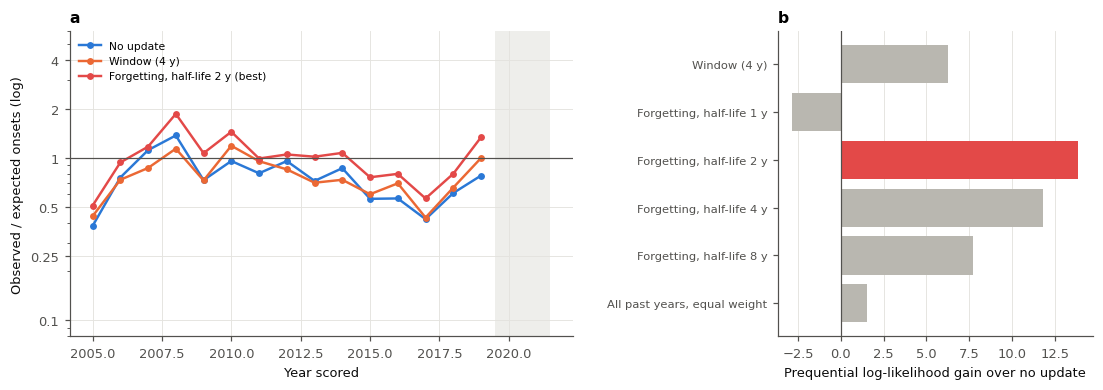

**What this means.**

* **Why a recent window falls short.** The recorded level falls about 5 % a year
  (Section 4.3). A 4-year window that ends 12 months before the year starts is centred about
  3.5 years before the middle of the year it is used for, so even a perfect estimate of its own level
  over-predicts by a factor of about exp(0.056 × 3.5) = 1.22,
  i.e. an O/E of about 0.82. Any lagged rule lags a trend.
* **Which rule tracks best.** The best updating rule here is **Forgetting, half-life 2 y**, with a gain of
  +13.9 log-likelihood units over no update (median O/E
  1.02, against 0.76 with no update).
  Forgetting beats the window: it follows the trend while averaging over more onsets than one window holds.
* **Why none of them is deployed.** Every rule here learns the *recorded* level. Section 1.5.6 shows that the recent
  recorded level reflects a status field that has stopped being updated. A baseline that follows it would teach the
  tool the artefact, and with absolute thresholds it would switch the tool off (Section 4.5). Updating the level
  becomes worthwhile once the outcome is ascertained independently of the form (Part VII).

In [78]:
"""Prequential comparison of baseline-updating rules: none, the window rule, exponential forgetting."""
_mid_t = (LAND_T + INT_END) / 2
_in_covid_iv = (_mid_t >= _COVID_T[0]) & (_mid_t <= _COVID_T[1])
LEVEL_RULES = {"No update": None, f"Window ({RECAL_YEARS} y)": "window"} |               {(f"Forgetting, half-life {h:g} y" if np.isfinite(h) else "All past years, equal weight"): h
               for h in FORGET_HALF_LIVES}


def level_shift(eta1, cut, rule):
    """Log-shift of the onset baseline from data before cut - lag, under one rule (None: no shift)."""
    if rule is None:
        return 0.0
    ce = cut - RECAL_LAG_MONTHS * MONTH_DAYS
    expo = np.clip(np.minimum(INT_END, ce) - LAND_T, 0, None) / 365.25
    obs = D1 * (INT_END <= ce)
    if rule == "window":
        w0 = ce - RECAL_YEARS * 365.25
        expo = np.clip(np.minimum(INT_END, ce) - np.maximum(LAND_T, w0), 0, None) / 365.25
        obs = obs * (INT_END > w0)
        wt = np.ones(N_LAND)
    else:
        age_y = np.clip(ce - _mid_t, 0, None) / 365.25
        wt = np.power(0.5, age_y / rule) if np.isfinite(rule) else np.ones(N_LAND)
    wt = wt * ~_in_covid_iv
    return float(np.log(max(np.sum(wt * obs), 0.5) / np.sum(wt * np.exp(eta1) * expo)))


_rows_l = []
for Y, o in ORIG.items():
    te = _lyr == Y
    eta1 = o["eta"][:, 0].astype(float)
    O = D1[te].sum()
    for nm, rule in LEVEL_RULES.items():
        sh = level_shift(eta1, _day(Y), rule)
        E = np.sum(np.exp(eta1[te] + sh) * INT_YRS[te])
        _rows_l.append({"Year": Y, "Rule": nm, "Shift (HR)": np.exp(sh), "Observed": O, "Expected": E, "O/E": O / E,
                        "Log-likelihood": O * np.log(E) - E})
LEVELS = pd.DataFrame(_rows_l)
_covid_years = list(range(_covid_y[0], _covid_y[1] + 1))
LEVEL_SCORE = pd.DataFrame({
    "Prequential log-likelihood, all years": LEVELS.groupby("Rule")["Log-likelihood"].sum(),
    "excluding COVID years": LEVELS[~LEVELS["Year"].isin(_covid_years)].groupby("Rule")["Log-likelihood"].sum(),
    "Median O/E": LEVELS.groupby("Rule")["O/E"].median(),
    "Median shift (HR)": LEVELS.groupby("Rule")["Shift (HR)"].median()}).reindex(list(LEVEL_RULES))
LEVEL_SCORE.insert(1, "Gain over no update", LEVEL_SCORE.iloc[:, 0] - LEVEL_SCORE.loc["No update"].iloc[0])
display(LEVEL_SCORE.round(2))
save_table(LEVEL_SCORE, "level_update_rules")
BEST_RULE = LEVEL_SCORE.drop(index="No update")["excluding COVID years"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.5})
ax = axes[0]
ax.axvspan(_covid_y[0] - 0.5, _covid_y[1] + 0.5, color=GRID_C, alpha=0.6, lw=0)
for nm, col in [("No update", C1), (f"Window ({RECAL_YEARS} y)", C2), (BEST_RULE, "#e34948")]:
    t = LEVELS[LEVELS["Rule"] == nm]
    ax.plot(t["Year"], t["O/E"], "-o", ms=3.5, color=col, lw=1.6, label=nm + (" (best)" if nm == BEST_RULE else ""))
ax.axhline(1, color=INK_2, lw=0.8); ax.set_yscale("log"); ax.set_ylim(0.08, 6)
ax.set_yticks([0.1, 0.25, 0.5, 1, 2, 4], ["0.1", "0.25", "0.5", "1", "2", "4"])
ax.set_xlabel("Year scored"); ax.set_ylabel("Observed / expected onsets (log)"); ax.legend(fontsize=7)
ax.set_title("a  Level set before each year, judged on that year", loc="left", fontsize=9)
ax = axes[1]
_g = LEVEL_SCORE["Gain over no update"].drop(index="No update")
ax.barh(range(len(_g)), _g.values, color=[("#e34948" if n == BEST_RULE else "#b9b7b0") for n in _g.index])
ax.set_yticks(range(len(_g)), _g.index, fontsize=7.5); ax.invert_yaxis(); ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlabel("Prequential log-likelihood gain over no update"); ax.grid(axis="y", visible=False)
ax.set_title("b  Which rule tracks the recorded level", loc="left", fontsize=9)
save_fig("level_update_rules")
_lag = RECAL_LAG_MONTHS / 12 + RECAL_YEARS / 2 + 0.5
say(f"""
**What this means.**

* **Why a recent window falls short.** The recorded level falls about {100 * (1 - np.exp(TREND_PER_YEAR)):.0f} % a year
  (Section 4.3). A {RECAL_YEARS}-year window that ends {RECAL_LAG_MONTHS} months before the year starts is centred about
  {_lag:.1f} years before the middle of the year it is used for, so even a perfect estimate of its own level
  over-predicts by a factor of about exp({-TREND_PER_YEAR:.3f} × {_lag:.1f}) = {np.exp(-TREND_PER_YEAR * _lag):.2f},
  i.e. an O/E of about {np.exp(TREND_PER_YEAR * _lag):.2f}. Any lagged rule lags a trend.
* **Which rule tracks best.** The best updating rule here is **{BEST_RULE}**, with a gain of
  {LEVEL_SCORE.loc[BEST_RULE, 'Gain over no update']:+.1f} log-likelihood units over no update (median O/E
  {LEVEL_SCORE.loc[BEST_RULE, 'Median O/E']:.2f}, against {LEVEL_SCORE.loc['No update', 'Median O/E']:.2f} with no update).
  {"Forgetting beats the window: it follows the trend while averaging over more onsets than one window holds." if LEVEL_SCORE.loc[BEST_RULE, 'Gain over no update'] > 0 and BEST_RULE.startswith("Forgetting") and LEVEL_SCORE.loc[BEST_RULE].iloc[0] > LEVEL_SCORE.loc[f"Window ({RECAL_YEARS} y)"].iloc[0] else "No updating rule clearly beats leaving the level alone: with few onsets a year, re-estimating the level adds as much noise as it removes."}
* **Why none of them is deployed.** Every rule here learns the *recorded* level. Section 1.5.6 shows that the recent
  recorded level reflects a status field that has stopped being updated. A baseline that follows it would teach the
  tool the artefact, and with absolute thresholds it would switch the tool off (Section 4.5). Updating the level
  becomes worthwhile once the outcome is ascertained independently of the form (Part VII).
""")

### 4.4.1 Updating the whole model: down-weighting older data, and closed testing applied year by year

Section 4.4 updates the level only. Two standard ways of keeping the **whole model** current are compared here,
prequentially, on the same annual origins as Section 4.2 (each strategy uses only the data available on 1 January
of the year it scores):

| Strategy | What is refitted, and when |
|:--|:--|
| **Frozen** | The model of the first origin, never changed |
| **Annual refit, all years equal** | Every coefficient refitted each year on all past data (the prequential HazReg of Section 4.2) |
| **Annual refit, down-weighting older data** | The same, with each landmark weighted by ½ per *half-life* of its age at the origin (2, 4 or 8 years): recent years count more, so effects that drift are followed, at the cost of a smaller effective sample (exponential forgetting of the whole likelihood; Jenkins et al., *Diagn Progn Res* 2018) |
| **Closed testing** (Vergouwe et al., *Stat Med* 2017) | Start from the frozen model. Each year, test the current model on the landmarks of the previous 3 years (follow-up cut at the origin; the window ends 12 months before it, so that recent onsets have had time to be recorded) and apply the decision: **keep**, **recalibrate the intercept**, **recalibrate intercept and slope**, or **revise** (replace by the annual refit). Only the onset hazard is recalibrated |

As in HazReg, no strategy carries a calendar term. Measures: AUROC over
every scored landmark, AUROC within the year scored (the ranking alone), the log score (ranking and level), O/E,
and the calibration slope with each year's own baseline. Differences are against the annual refit, with
patient-bootstrap CIs. **This is estimation, not a test**: the question is which maintenance rule a clinic should
adopt once the outcome is ascertained reliably (Part VII), and how much each rule moves the results.

,Onsets in the window,Decision,Onset intercept shift (HR),Onset slope
Year,,,,
2006,95,Revise,1.0,1.0
2007,66,Revise,1.0,1.0
2008,45,Revise,1.0,1.0
2009,41,Revise,1.0,1.0
2010,82,Revise,1.0,1.0
2011,83,Revise,1.0,1.0
2012,72,Revise,1.0,1.0
2013,70,Revise,1.0,1.0
2014,73,Revise,1.0,1.0


,AUROC,Within-year AUROC,Log score,O/E,Calibration slope (own baseline),AUROC − annual refit,Log score − annual refit
Strategy,,,,,,,
Frozen (first origin),0.716 (0.647 to 0.784),0.713 (0.639 to 0.779),-0.1688 (-0.1993 to -0.1385),0.726 (0.545 to 0.916),0.72 (0.52 to 0.93),-0.013 (-0.034 to 0.006),-0.0061 (-0.0116 to -0.0009)
"Annual refit, all years equal",0.729 (0.666 to 0.790),0.729 (0.662 to 0.789),-0.1627 (-0.1926 to -0.1339),0.830 (0.625 to 1.039),0.89 (0.66 to 1.12),NaN,NaN
"Annual refit, down-weighted (half-life 2 y)",0.697 (0.641 to 0.756),0.710 (0.650 to 0.770),-0.1665 (-0.1989 to -0.1371),0.875 (0.661 to 1.096),0.83 (0.61 to 1.05),-0.032 (-0.062 to 0.002),-0.0038 (-0.0081 to 0.0006)
"Annual refit, down-weighted (half-life 4 y)",0.720 (0.661 to 0.777),0.726 (0.665 to 0.785),-0.1635 (-0.1945 to -0.1345),0.860 (0.648 to 1.070),0.87 (0.65 to 1.09),-0.009 (-0.030 to 0.011),-0.0008 (-0.0035 to 0.0017)
"Annual refit, down-weighted (half-life 8 y)",0.728 (0.668 to 0.786),0.731 (0.665 to 0.790),-0.1624 (-0.1933 to -0.1335),0.850 (0.637 to 1.059),0.88 (0.65 to 1.10),-0.001 (-0.012 to 0.011),0.0003 (-0.0013 to 0.0018)
Closed testing,0.729 (0.666 to 0.790),0.729 (0.662 to 0.789),-0.1627 (-0.1926 to -0.1339),0.830 (0.625 to 1.039),0.89 (0.66 to 1.12),0.000 (0.000 to 0.000),0.0000 (0.0000 to 0.0000)


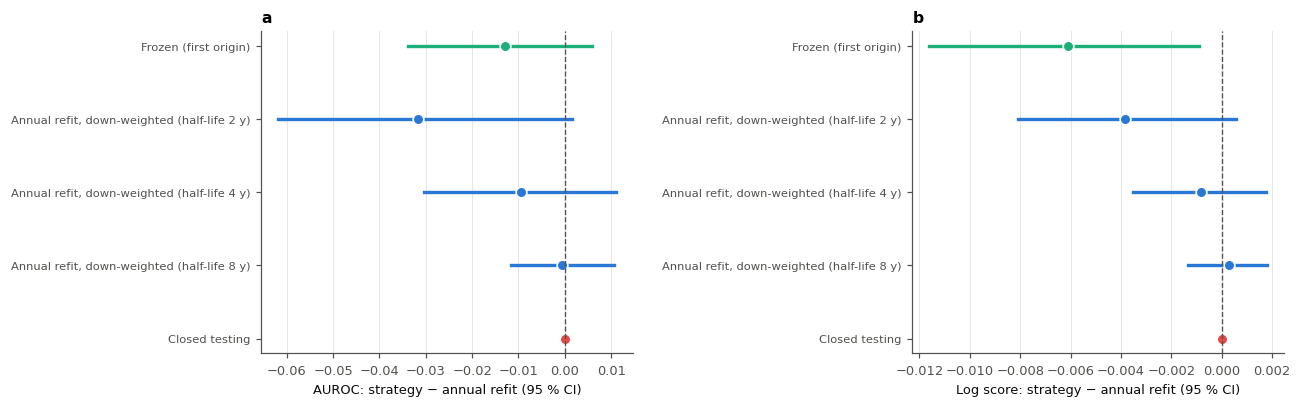

**What this means.**

* **Closed testing**, applied each year from 2006, chose: revise 14
  time(s). It often revises: the coefficients themselves move.
* **Down-weighting older data.** The best half-life, half-life 8 y, changes the AUROC by
  -0.001 (-0.012 to 0.011) against equal weighting. Recent years do not rank patients better than all years together: what moves over time is the level, not the effects, and down-weighting only shrinks the sample.
* **Never updating** costs -0.013 (-0.034 to 0.006) in AUROC against the annual refit.
* **Best log score: Annual refit, down-weighted (half-life 8 y).** The log score rewards a level that follows the *recorded* rate, which is mostly
  recording (Section 1.5.6); a strategy that wins on it is the one that best follows the recording. The ranking
  columns are the ones that speak to the patients.

In [79]:
"""Updating strategies compared prequentially: frozen, annual refit, down-weighted refits, closed testing."""


def _origin_fit_dw(Y, h):
    """The annual refit at origin Y with each landmark weighted by 0.5 ** (age at the origin / h)."""
    cut = _day(Y)
    tr = np.flatnonzero(LAND_T < cut)
    dt = (np.minimum(INT_END, cut) - LAND_T) / 365.25
    keep = INT_END <= cut
    w = np.power(0.5, np.clip(cut - LAND_T, 0, None) / 365.25 / h)
    m = fit_procedure(tr, dt=dt, d1=D1 * keep, d2=D2 * keep, w=w, seed=SEED + Y)
    return predict_eta(m).astype(np.float32)


_dw_jobs = [(Y, h) for h in DOWNWEIGHT_HALF_LIVES for Y in ORIGINS]
if "origins_downweight" not in STATE or STATE["origins_downweight"]["jobs"] != _dw_jobs:
    t0 = time.time()
    _res = Parallel(n_jobs=N_JOBS)(delayed(_origin_fit_dw)(Y, h) for Y, h in _dw_jobs)
    STATE["origins_downweight"] = {"jobs": _dw_jobs, "eta": dict(zip(_dw_jobs, _res))}
    _save_state()
    print(f"Down-weighted refits: {len(_dw_jobs)} fits in {(time.time() - t0) / 60:.1f} min")
_DW = STATE["origins_downweight"]["eta"]

# closed testing, applied year by year from the first origin
_lag_d = RECAL_LAG_MONTHS * MONTH_DAYS
_base_m, _base_eta = ORIG[ORIGINS[0]]["model"], ORIG[ORIGINS[0]]["eta"].astype(float)
_a, _b = 0.0, 1.0
ETA_CT = np.full((N_LAND, 2), np.nan)
_ct_log = []
for Y in ORIGINS:
    cut = _day(Y)
    if Y > ORIGINS[0]:
        rows = np.flatnonzero((LAND_T >= cut - _lag_d - CLOSED_TEST_YEARS * 365.25) & (LAND_T < cut - _lag_d))
        d = D1[rows] * (INT_END[rows] <= cut)
        dt = np.maximum((np.minimum(INT_END[rows], cut) - LAND_T[rows]) / 365.25, 1e-6)
        if d.sum() >= 3:
            r = closed_test(_base_m, rows, eta=_a + _b * _base_eta[rows, 0], d=d, dt=dt)
            dec = r["Decision"]
            if dec == "Recalibrate intercept":
                _a += np.log(r["New intercept (O/E)"])
            elif dec == "Recalibrate intercept + slope":
                _a, _b = r["_c0"] + r["New slope"] * _a, r["New slope"] * _b
            elif dec == "Revise":
                _base_m, _base_eta, _a, _b = ORIG[Y]["model"], ORIG[Y]["eta"].astype(float), 0.0, 1.0
        else:
            dec = "Keep (fewer than 3 onsets in the window)"
        _ct_log.append({"Year": Y, "Onsets in the window": int(d.sum()), "Decision": dec,
                        "Onset intercept shift (HR)": np.exp(_a), "Onset slope": _b})
    k = _lyr == Y
    e = _base_eta[k].copy()
    e[:, 0] = _a + _b * e[:, 0]
    ETA_CT[k] = e
CT_LOG = pd.DataFrame(_ct_log).set_index("Year")
display(CT_LOG.round(3))
save_table(CT_LOG, "closed_testing_applied")

UPD_ETA = {"Frozen (first origin)": ORIG[ORIGINS[0]]["eta"].astype(float), "Annual refit, all years equal": ETA_PREQ}
for h in DOWNWEIGHT_HALF_LIVES:
    e = np.full((N_LAND, 2), np.nan)
    for Y in ORIGINS:
        k = _lyr == Y
        e[k] = _DW[(Y, h)][k]
    UPD_ETA[f"Annual refit, down-weighted (half-life {h:g} y)"] = e
UPD_ETA["Closed testing"] = ETA_CT
_S = PREQ_OK & (_lyr > ORIGINS[0])
_Ws = W_BOOT[:, ROW_PIDX[_S]]
_yrlab = _lyr.astype(str)[_S]
UPD_ARR = {n: metric_arrays(cif(e[_S], base=BASE_PREQ[_S]), _Ws, Y_IP[_S], W_IP[_S], _yrlab) for n, e in UPD_ETA.items()}


def _own_slope(eta1):
    """Calibration slope of the onset log-hazard with each scored year's own baseline (Poisson, year fixed effects)."""
    yrs = pd.get_dummies(_lyr[_S]).values.astype(float)
    f = sm.GLM(D1[_S], np.column_stack([yrs, eta1]), family=sm.families.Poisson(), offset=np.log(INT_YRS[_S])).fit(
        cov_type="cluster", cov_kwds={"groups": ROW_PIDX[_S]})
    return f.params[-1], f.params[-1] - 1.96 * f.bse[-1], f.params[-1] + 1.96 * f.bse[-1]


_ref_u = "Annual refit, all years equal"
_rows_u = []
for n, A in UPD_ARR.items():
    r = {"Strategy": n}
    for k in ["AUROC", "Within-era AUROC", "Log score", "O/E"]:
        r[k.replace("Within-era", "Within-year")] = fmt(ci_of(A[k]), 4 if k == "Log score" else 3)
    r["Calibration slope (own baseline)"] = fmt(_own_slope(UPD_ETA[n][_S, 0]), 2)
    if n != _ref_u:
        for k in ["AUROC", "Log score"]:
            r[f"{k} − annual refit"] = fmt(ci_of(A[k] - UPD_ARR[_ref_u][k]), 4 if k == "Log score" else 3)
    _rows_u.append(r)
UPD_TABLE = pd.DataFrame(_rows_u).set_index("Strategy")
display(UPD_TABLE)
save_table(UPD_TABLE, "updating_strategies")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"wspace": 0.75})
_others = [n for n in UPD_ETA if n != _ref_u]
for ax, k, nd in [(axes[0], "AUROC", 3), (axes[1], "Log score", 4)]:
    for i, n in enumerate(_others):
        t = ci_of(UPD_ARR[n][k] - UPD_ARR[_ref_u][k])
        col = C3 if n.startswith("Frozen") else "#e34948" if n == "Closed testing" else C1
        ax.plot([t[1], t[2]], [i, i], color=col, lw=2.2)
        ax.plot(t[0], i, "o", color=col, ms=7, mec="white", mew=1.1)
    ax.axvline(0, color=INK_2, lw=0.9, ls="--")
    ax.set_yticks(range(len(_others)), _others, fontsize=7.5); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"{k}: strategy − annual refit (95 % CI)")
axes[0].set_title("a  Ranking", loc="left", fontsize=9)
axes[1].set_title("b  Log score (ranking and level; higher = better)", loc="left", fontsize=9)
save_fig("updating_strategies")
_best_u = max(UPD_ARR, key=lambda n: UPD_ARR[n]["Log score"][0])
_dec_u = CT_LOG["Decision"].value_counts()
_dw_names = [n for n in UPD_ETA if "down-weighted" in n]
_best_dw = max(_dw_names, key=lambda n: UPD_ARR[n]["Log score"][0])
_d_dw = ci_of(UPD_ARR[_best_dw]["AUROC"] - UPD_ARR[_ref_u]["AUROC"])
_d_fr = ci_of(UPD_ARR["Frozen (first origin)"]["AUROC"] - UPD_ARR[_ref_u]["AUROC"])
say(f"""
**What this means.**

* **Closed testing**, applied each year from {ORIGINS[0] + 1}, chose: {", ".join(f"{k.lower()} {v}" for k, v in _dec_u.items())}
  time(s). {"It mostly recalibrates: the coefficients of the first origin are not shown to be out of date, only the level." if _dec_u.get("Revise", 0) <= len(CT_LOG) / 4 else "It often revises: the coefficients themselves move."}
* **Down-weighting older data.** The best half-life, {_best_dw.split("(")[1].rstrip(")")}, changes the AUROC by
  {fmt(_d_dw)} against equal weighting. {"Recent years do not rank patients better than all years together: what moves over time is the level, not the effects, and down-weighting only shrinks the sample." if _d_dw[1] < 0 < _d_dw[2] or _d_dw[2] < 0 else "Recent data rank better: some effects drift, and following them pays."}
* **Never updating** costs {fmt(_d_fr)} in AUROC against the annual refit.
* **Best log score: {_best_u}.** The log score rewards a level that follows the *recorded* rate, which is mostly
  recording (Section 1.5.6); a strategy that wins on it is the one that best follows the recording. The ranking
  columns are the ones that speak to the patients.
""")

## 4.5 What each deployment option would have flagged in 2015-19 (exploratory)

The landmarks from 2015 to February 2020, scored four ways. The first is the reported tool.

| Option | Score | Tiers and alarm |
|:--|:--|:--|
| **A. Relative tiers, no update (reported)** | The final model as developed | Relative: percentiles of the development cohort |
| B. Absolute tiers, no update | The final model as developed | Fixed risks: alarm at a landmark ≥ 4 %, off below 2 % |
| C. Absolute tiers after recalibration | The final model with its baseline re-estimated on the last 4 years (the window rule at the data end) | As B |
| D. Absolute tiers, calendar term at the latest year | The model of Section 4.3 refitted on the visits before March 2020, calendar term at its latest year | As B |

,Visits in the top tier (%),Visits in the lowest tier (%),Visits flagged (%),Patients ever flagged (%),New alarms per 100 person-years,Episode PPV (%)
Option,,,,,,
"A. Relative tiers, no update (reported)",10.0,60.1,10.0,21.9,7.1,16.8
"B. Absolute tiers, no update",7.3,35.2,47.4,53.9,9.1,8.9
C. Absolute tiers after recalibration,4.6,47.3,36.2,43.6,8.1,10.2
"D. Absolute tiers, calendar term at the latest year",2.8,62.6,22.1,29.2,5.8,15.0


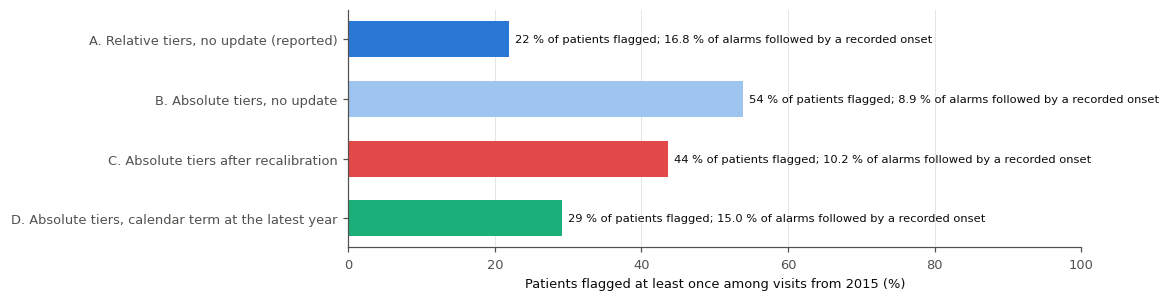

**What this means.** With absolute thresholds, recalibrating the baseline to the recorded level of
2015-2019
(onset baseline × 0.77, from 80 recorded onsets) would flag
44 % of recent patients (option C): the tool would in effect be
switched off. The relative tiers (option A) flag 22 %, fewer than in
the development years because recent patients are healthier, and keep the flag's meaning: *this patient ranks in the
top 50 % of landmarks*. The reported tool is therefore **option A, with no update of the baseline**. The absolute
risk is shown beside the tier as the risk under the average recording of the development years (option B's number), and the frozen
model (Section 7.1) carries no recalibration.

In [80]:
"""Deployment options on the recent visits: share flagged, alarm workload and yield."""


def period_shift(eta, w0, w1, rows=None, d1=D1, d2=D2):
    """Both baseline log-hazards re-estimated on the person-time inside [w0, w1), predictor effects fixed."""
    use = np.zeros(N_LAND, bool)
    use[np.arange(N_LAND) if rows is None else rows] = True
    expo = np.clip(np.minimum(INT_END, w1) - np.maximum(LAND_T, w0), 0, None) / 365.25 * use
    inn = (INT_END > w0) & (INT_END <= w1) & use
    obs = np.array([d1[inn].sum(), d2[inn].sum()])
    exp_ = np.array([np.sum(np.exp(eta[:, c]) * expo) for c in range(2)])
    return np.log(np.maximum(obs, 0.5) / exp_), obs, expo.sum()


_end_t = float((DATA_END_DATE - pd.Timestamp("1970-01-01")).days)
W1 = _end_t - RECAL_LAG_MONTHS * MONTH_DAYS
W0 = W1 - RECAL_YEARS * 365.25
RECAL_SHIFT, _rev, _rpy = period_shift(ETA_FULL, W0, W1)
P_RECAL = cif(ETA_FULL + RECAL_SHIFT[None, :], base=FINAL["base"])
ABS_RULE = dict(on=0.04, n_on=1, high=None, off=0.02, n_off=1, stay_on=True)
RECENT = LAND_YEAR >= 2015
FLAGS_FULL_DEV = alarm_flags(P_FULL)                                   # relative, against the development cohort
DEPLOY_OPTIONS = {"A. Relative tiers, no update (reported)": (FLAGS_FULL_DEV, rel_tier(P_FULL)),
                  "B. Absolute tiers, no update": (alarm_flags(P_FULL, ABS_RULE, is_pct=True),
                                                   np.digitize(P_FULL, [0.02, 0.04, 0.10])),
                  "C. Absolute tiers after recalibration": (alarm_flags(P_RECAL, ABS_RULE, is_pct=True),
                                                            np.digitize(P_RECAL, [0.02, 0.04, 0.10])),
                  f"D. Absolute tiers, calendar term at the latest year": (alarm_flags(P_FULL_TA_REF, ABS_RULE, is_pct=True),
                                                                        np.digitize(P_FULL_TA_REF, [0.02, 0.04, 0.10]))}
_rows_do = []
for nm, (fl, tier) in DEPLOY_OPTIONS.items():
    b = alarm_burden(fl, sel=RECENT)
    _rows_do.append({"Option": nm, "Visits in the top tier (%)": 100 * np.mean(tier[RECENT] == (len(REL_TIER_LABELS) - 1 if nm.startswith("A.") else 3)),
                     "Visits in the lowest tier (%)": 100 * np.mean(tier[RECENT] == 0),
                     "Visits flagged (%)": b["Visits flagged (%)"], "Patients ever flagged (%)": b["Patients ever flagged (%)"],
                     "New alarms per 100 person-years": b["Alarm episodes per 100 person-years"],
                     "Episode PPV (%)": b["Episode PPV (%)"][0]})
DEPLOY_TABLE = pd.DataFrame(_rows_do).set_index("Option").round(1)
display(DEPLOY_TABLE)
save_table(DEPLOY_TABLE, "deployment_options")
fig, ax = plt.subplots(figsize=(8.6, 2.8))
_dt = DEPLOY_TABLE
ax.barh(range(len(_dt)), _dt["Patients ever flagged (%)"], color=[C1, "#9ec5f0", "#e34948", C3], height=0.6)
for i, (v, ppv) in enumerate(zip(_dt["Patients ever flagged (%)"], _dt["Episode PPV (%)"])):
    ax.text(v + 0.8, i, f"{v:.0f} % of patients flagged; {ppv:.1f} % of alarms followed by a recorded onset",
            va="center", fontsize=7.5, color=INK)
ax.set_yticks(range(len(_dt)), _dt.index); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Patients flagged at least once among visits from 2015 (%)"); ax.grid(axis="y", visible=False)
ax.set_title("Deployment options on the recent visits", loc="left", fontsize=9)
save_fig("deployment_options")
say(f"""
**What this means.** With absolute thresholds, recalibrating the baseline to the recorded level of
{(pd.Timestamp('1970-01-01') + pd.Timedelta(days=W0)).year}-{(pd.Timestamp('1970-01-01') + pd.Timedelta(days=W1)).year}
(onset baseline × {np.exp(RECAL_SHIFT[0]):.2f}, from {int(_rev[0])} recorded onsets) would flag
{DEPLOY_TABLE.iloc[2]['Patients ever flagged (%)']:.0f} % of recent patients (option C): the tool would in effect be
switched off. The relative tiers (option A) flag {DEPLOY_TABLE.iloc[0]['Patients ever flagged (%)']:.0f} %, fewer than in
the development years because recent patients are healthier, and keep the flag's meaning: *this patient ranks in the
top {100 - 100 * REL_TIER_SHARES[0]:.0f} % of landmarks*. The reported tool is therefore **option A, with no update of the baseline**. The absolute
risk is shown beside the tier as the risk under the average recording of the development years (option B's number), and the frozen
model (Section 7.1) carries no recalibration.
""")

In [81]:
"""The main analysis (visits before MAIN_END) for Parts V-IX."""
use_data("main")
print(f"Main analysis: {N_LAND:,} landmarks, {int(D1_ALL.sum())} onsets, visits to {DATA_END_DATE.date()}.")

Main analysis: 12,976 landmarks, 150 onsets, visits to 2020-02-29.


---
# Part V. Could the results be an artefact?

The data raise one central worry: **exits from work that happen but never reach the record**, especially in recent
years and among patients who stop attending. This part asks how much that could change the conclusions, in three
ways:

1. **A simulation where the truth is known** (5.1): do the methods recover the truth, and what would missing onsets
   look like?
2. **Imputed event times for the missing outcomes** (5.2): patients who left the clinic while employed, and
   patients still attending whose status may be stale. How far could the outcomes they did not report move the
   results?
3. **A broader outcome** (5.3): does the model still work if early retirement, homemaking and "other" exits count
   as work disability?

## 5.1 A simulation with known truth (plasmode)

> **The idea.** Keep the real patients, visits and inputs, but replace the outcomes with outcomes drawn from the
> model's own hazards. The true risk and true 36-month status of every visit are then known, and the analysis can
> be checked against them.

| Scenario | What is simulated | What it answers |
|:--|:--|:--|
| **A** | Outcomes recorded whenever they happen within follow-up | Are the performance estimators unbiased on this data structure? |
| **B** | A quarter of onsets, in any era, end follow-up unrecorded (the patient stops attending) | What does uniform under-recording do? |
| **C** | Half of onsets from 2015 on are lost this way | Can recent under-recording alone produce the observed fall in O/E? |

A refit check under scenario A also fits the model on half of the simulated patients and tests it on the other
half. The calibration slope should then be near 1 and the estimated AUROC near the truth.

In [82]:
"""Plasmode simulation: outcomes drawn from the final model on the real landmarks and observation windows."""
LAM = np.exp(np.clip(ETA_FULL, -30, 5)) / 365.25                  # per day
_tot = LAM.sum(1)
_seg = np.where(_same_next, _next - LAND_T, np.inf)                # landmark to the next landmark (days)
_admin_end = LAND_T + land["admin_days"].values
_last_seen = ((land["last_status_date"] - pd.Timestamp("1970-01-01")).dt.days).values.astype(float)
OBS_END = pd.Series(np.minimum(_last_seen, _admin_end)).groupby(PID_ALL).transform("min").values
_segh = np.where(np.isinf(_seg), 0.0, _tot * _seg)               # cumulative hazard of each landmark's segment
_cum_start = pd.Series(_segh).groupby(PID_ALL).cumsum().values - _segh
_cum_end = np.where(np.isinf(_seg), np.inf, _cum_start + _segh)  # the last landmark's hazard continues


def simulate(rng, q_all=0.0, q_from_2015=0.0):
    """One plasmode replicate. Returns kept rows, observed (time, cause), true 36-month label, interval arrays."""
    E = rng.exponential(1.0, P_N)[ROW_PIDX]
    hit = (_cum_end >= E) & (E >= _cum_start)
    j = pd.Series(np.where(hit, np.arange(N_LAND), N_LAND)).groupby(PID_ALL).transform("min").values
    t_ev = LAND_T[np.minimum(j, N_LAND - 1)] + (E - _cum_start[np.minimum(j, N_LAND - 1)]) / \
        _tot[np.minimum(j, N_LAND - 1)]
    jj = np.minimum(j, N_LAND - 1)
    u = rng.uniform(size=P_N)[ROW_PIDX]
    cause_true = np.where(u < LAM[jj, 0] / _tot[jj], 1, 2)
    keep = np.arange(N_LAND) <= j
    obs = t_ev <= OBS_END
    ev_year = 1970 + t_ev / 365.25
    lose = (cause_true == 1) & obs & (rng.uniform(size=P_N)[ROW_PIDX] <
                                      np.where(ev_year >= 2015, max(q_all, q_from_2015), q_all))
    end_abs = np.where(obs, t_ev, OBS_END)
    cause_obs = np.where(obs & ~lose, cause_true, 0)
    T = end_abs - LAND_T
    y_true = ((cause_true == 1) & (t_ev - LAND_T <= HORIZON_DAYS)).astype(float)
    nxt_kept = np.r_[keep[1:] & _same_next[:-1], False]
    iend = np.where(nxt_kept, np.minimum(_next, end_abs), end_abs)
    dt = np.clip(iend - LAND_T, 1e-6, None) / 365.25
    last_kept = keep & ~nxt_kept
    d1 = (last_kept & (cause_obs == 1)).astype(float)
    d2 = (last_kept & (cause_obs == 2)).astype(float)
    return keep & (T > 0), T, cause_obs, y_true, dt, d1, d2, np.where(obs, cause_true, 0)


def _sim_metrics(k, T, Cc, y_true, p):
    rows = np.flatnonzero(k)
    y, w = ipcw_weights(T, Cc, rows=rows)
    A = metric_arrays(p[rows], np.ones((1, len(rows))), y, w, ERA_LAB[rows])
    one = np.ones((1, len(rows)))
    ora = wauc(y_true[rows], p[rows], one)[0]
    out = {"AUROC estimated": A["AUROC"][0], "AUROC true": ora, "O/E estimated": A["O/E"][0],
           "O/E true": y_true[rows].mean() / p[rows].mean()}
    for a, b in REPORT_PERIODS[2:]:
        kp = (LAND_T[rows] >= _day(a)) & (LAND_T[rows] < _day(b))
        out[f"O/E {a}-{b - 1}"] = np.sum((w * y)[kp]) / kp.sum() / p[rows][kp].mean()
        out[f"O/E {a}-{b - 1} true"] = y_true[rows][kp].mean() / p[rows][kp].mean()
    return out


SCENARIOS = {"A: independent censoring": {}, "B: 25% of onsets unrecorded": {"q_all": 0.25},
             "C: 50% of onsets unrecorded from 2015": {"q_from_2015": 0.5}}
if "plasmode" not in STATE:
    rng = np.random.RandomState(SEED + 3)
    res = {s: [] for s in SCENARIOS}
    for r in range(SIM_REPS):
        for s, kw in SCENARIOS.items():
            res[s].append(_sim_metrics(*simulate(rng, **kw)[:4], cif(ETA_FULL, base=0.0)))   # outcomes are drawn from flat hazards
    # refit check (scenario A): fit on half the patients with the final model's penalties, evaluate the other half
    refit = []
    for r in range(max(2, SIM_REPS // 10)):
        k, T, Cc, y_true, dt, d1, d2, _ = simulate(rng)
        half = rng.permutation(P_N) < P_N // 2
        tr = np.flatnonzero(k & half[ROW_PIDX]); te = np.flatnonzero(k & ~half[ROW_PIDX])
        m = fit_procedure(tr, dt=dt, d1=d1, d2=d2, alphas=FINAL["alphas"])
        p_te = cif(predict_eta(m, te), base=m["base"])
        y, w = ipcw_weights(T, Cc, rows=te)
        refit.append({"AUROC estimated": metric_arrays(p_te, np.ones((1, len(te))), y, w, ERA_LAB[te])["AUROC"][0],
                      "AUROC true": wauc(y_true[te], p_te, np.ones((1, len(te))))[0],
                      "Calibration slope estimated": wcalibration(y, p_te, w)[0],
                      "Calibration slope true": wcalibration(y_true[te], p_te, np.ones(len(te)))[0]})
    STATE["plasmode"] = {"res": {s: pd.DataFrame(v) for s, v in res.items()}, "refit": pd.DataFrame(refit)}
    _save_state()
PLASMODE = STATE["plasmode"]
_tab = {}
for s, d in PLASMODE["res"].items():
    _tab[s] = {"AUROC: estimated - true": (d["AUROC estimated"] - d["AUROC true"]).mean(),
               "O/E estimated (mean)": d["O/E estimated"].mean(), "O/E true (mean)": d["O/E true"].mean()}
    _tab[s].update({c: d[c].mean() for c in d.columns if c.startswith("O/E 20") and not c.endswith("true")})
PLASMODE_TABLE = pd.DataFrame(_tab).T.round(3)
display(PLASMODE_TABLE)
_rf = PLASMODE["refit"].mean()
_k1619 = (LAND_T >= _day(2016)) & (LAND_T < _day(2020))
_obs1619 = np.sum((W_IP * Y_IP)[_k1619]) / _k1619.sum() / P_FULL[_k1619].mean()
_pc_ = PLASMODE_TABLE.loc["C: 50% of onsets unrecorded from 2015"]
_c1619 = [c for c in PLASMODE_TABLE.columns if c.startswith("O/E 2016")][0]

# ---- the patient-level evaluation in the same simulation: estimated (recorded onsets) vs true (every onset)
if "plasmode_pt" not in STATE:
    rng = np.random.RandomState(SEED + 4)
    _one = np.ones((1, P_N), np.float32)
    out = []
    for r in range(SIM_REPS):
        for sname in ["A: independent censoring", "C: 50% of onsets unrecorded from 2015"]:
            k, T, Cc, _, _, _, _, Ct = simulate(rng, **SCENARIOS[sname])
            for lab, CC in [("estimated", Cc), ("true", Ct)]:
                ev = build_pt_eval(T=T, C=CC, use=k, atrisk=k)
                A = pt_metric_arrays(ev, P_FULL, FLAGS_FULL, W=_one)
                out.append({"Scenario": sname, "Version": lab, "Onsets": ev["n_onsets"],
                            **{m_: A[m_][0] for m_ in ["C", "Sensitivity", "Specificity"]}})
    STATE["plasmode_pt"] = pd.DataFrame(out)
    _save_state()
PLASMODE_PT = STATE["plasmode_pt"].groupby(["Scenario", "Version"]).mean().round(3).unstack("Version")
display(PLASMODE_PT)
_ppa, _ppc = PLASMODE_PT.loc["A: independent censoring"], PLASMODE_PT.loc["C: 50% of onsets unrecorded from 2015"]
say(f"""
**What this means.**

* **The methods work on this data structure.** Under independent censoring, the estimated AUROC is off by
  {PLASMODE_TABLE.iloc[0]['AUROC: estimated - true']:+.3f} on average. In the refit check, the estimated AUROC is
  {_rf['AUROC estimated']:.3f} against a true {_rf['AUROC true']:.3f}, and the calibration slope is
  {_rf['Calibration slope estimated']:.2f} against {_rf['Calibration slope true']:.2f}.
* **Missing onsets damage calibration, not ranking.** When half of the onsets from 2015 go unrecorded, the 2016-19
  O/E drops to {_pc_[_c1619]:.2f} while the AUROC barely moves. The real data show {_obs1619:.2f}
  for that period. Under-recording on this scale is therefore *enough* to produce the observed pattern, although
  the simulation cannot prove that it happened.
* **The patient-level evaluation.** Under independent censoring
  the estimated patient C is {_ppa[('C', 'estimated')]:.3f} against a true {_ppa[('C', 'true')]:.3f}, and the alarm's
  sensitivity {_ppa[('Sensitivity', 'estimated')]:.2f} against {_ppa[('Sensitivity', 'true')]:.2f}. With half of the
  recent onsets lost, the estimates are {_ppc[('C', 'estimated')]:.3f} (true {_ppc[('C', 'true')]:.3f}) and
  {_ppc[('Sensitivity', 'estimated')]:.2f} (true {_ppc[('Sensitivity', 'true')]:.2f}), with specificity
  {_ppc[('Specificity', 'estimated')]:.2f} against {_ppc[('Specificity', 'true')]:.2f}. Lost onsets put hidden cases
  among the controls, so any bias they cause shows in the specificity and the patient C, not in the sensitivity.
""")

,AUROC: estimated - true,O/E estimated (mean),O/E true (mean),O/E 2012-2015,O/E 2016-2019
A: independent censoring,-0.003,0.966,0.969,1.210,0.696
B: 25% of onsets unrecorded,-0.004,0.743,0.983,0.921,0.509
C: 50% of onsets unrecorded from 2015,0.006,0.874,0.985,0.873,0.344


Onsets                 C        Sensitivity        Specificity       
Version                               estimated    true estimated   true   estimated   true   estimated   true
Scenario                                                                                                      
A: independent censoring                 110.61  110.61     0.743  0.743       0.588  0.588       0.743  0.743
C: 50% of onsets unrecorded from 2015    100.38  110.18     0.743  0.743       0.601  0.587       0.733  0.743

**What this means.**

* **The methods work on this data structure.** Under independent censoring, the estimated AUROC is off by
  -0.003 on average. In the refit check, the estimated AUROC is
  0.691 against a true 0.694, and the calibration slope is
  0.68 against 0.69.
* **Missing onsets damage calibration, not ranking.** When half of the onsets from 2015 go unrecorded, the 2016-19
  O/E drops to 0.34 while the AUROC barely moves. The real data show 0.47
  for that period. Under-recording on this scale is therefore *enough* to produce the observed pattern, although
  the simulation cannot prove that it happened.
* **The patient-level evaluation.** Under independent censoring
  the estimated patient C is 0.743 against a true 0.743, and the alarm's
  sensitivity 0.59 against 0.59. With half of the
  recent onsets lost, the estimates are 0.743 (true 0.743) and
  0.60 (true 0.59), with specificity
  0.73 against 0.74. Lost onsets put hidden cases
  among the controls, so any bias they cause shows in the specificity and the patient C, not in the sensitivity.

## 5.2 Missing outcomes: imputed event times

Two groups of patients may have outcomes that never reached the record, and they need different methods:

| Group | Who | Why the outcome may be missing |
|:--|:--|:--|
| **A** | Patients last recorded as employed who then **left the clinic** | Follow-up stops; anything after it is unseen |
| **B** | Patients **still attending** whose employment status may be **stale** | The field is still filled in, but may no longer be checked (Section 1.5.6) |

Group B is probably the larger, and a tipping-point analysis that only adds onsets among leavers cannot reach it.

| | Analysis | Group | What it does |
|:--|:--|:--|:--|
| 1 | **Model-based multiple imputation with a δ-adjustment** (Jackson, White, Seaman et al., *Stat Med* 2014) | A | For each leaver, an exit and its time are drawn from the model's cumulative incidence, conditional on being working at the last contact, with the onset hazard after it multiplied by δ ∈ {0.5, 1, 1.5, 2, 3}. δ = 1 is "missing at random given the patient's inputs"; δ < 1 allows that patients may leave because they are well |
| 2 | **Risk-set imputation** (Hsu, Taylor et al., *Stat Med* 2006) | A | Each leaver's remaining time is drawn from the patients still followed at the moment they left, matched on predicted onset risk and predicted risk of leaving. It leans less on the model being tested |
| 3 | **Stale-status analysis** | B | A status counts as verified for 3 years after it last changed. Option (a): follow-up is censored where verification lapses. Option (b): onsets in the unverified time are imputed as in analysis 1, with δ |
| 4 | **Correction for outcome misclassification** (Magder & Hughes, *Am J Epidemiol* 1997) | A + B | Uses the era-stratified chart review (Section 7.2) to estimate the sensitivity of the recorded outcome in each era. The only analysis that estimates the absolute level rather than bounding it |
| 5 | **Covariate-dependent censoring weights** | A | Censoring weights that depend on each patient's predicted risk, disease activity, fatigue, age, years in clinic and calendar time: dropout that is informative only through measured factors |
| 6 | **An anchor for δ** | A + B | The recorded rate in the years when the status was still being updated, and published rates (when entered), give δ a plausible range |

Every analysis re-evaluates the **same cross-validated HazReg risks** against the completed outcomes: AUROC,
observed / expected (O/E) overall and by period, and the time-matched patient C. Imputations are pooled with
Rubin's rules (AUROC on the logit scale, O/E on the log scale). These are **imputed event times**, not
*pseudo-observations*: the jackknife pseudo-values of Andersen and Perme assume independent censoring, which is the
assumption under test here.

In [83]:
"""Shared machinery: evaluating the cross-validated risks against a completed outcome; Rubin's rules."""
P_MAIN = P_CV["HazReg"]
SA_PERIODS = REPORT_PERIODS
_W101 = W_BOOT[:101][:, ROW_PIDX]
_PERIOD_MASK = {f"O/E {a}-{b - 1}": (LAND_T >= _day(a)) & (LAND_T < _day(b)) for a, b in SA_PERIODS}


def sa_eval(T, C, w=None, patient=True):
    """The cross-validated HazReg risks against outcome (T, C): point estimates and bootstrap variances on the pooling
    scale (logit AUROC, log O/E); patient C as a point estimate."""
    y, w0 = ipcw_weights(T, C)
    w = w0 if w is None else w
    A = metric_arrays(P_MAIN, _W101, y, w)
    out = {"AUROC": (_logit(A["AUROC"][0]), np.var(_logit(A["AUROC"][1:]), ddof=1)),
           "O/E": (np.log(A["O/E"][0]), np.var(np.log(A["O/E"][1:]), ddof=1))}
    for nm, k in _PERIOD_MASK.items():
        oe = (_W101[:, k] * (w * y)[k]).sum(1) / (_W101[:, k] * P_MAIN[k]).sum(1)
        lo = np.log(np.maximum(oe, 1e-6))
        out[nm] = (lo[0], np.var(lo[1:], ddof=1))
    if patient:
        ev = build_pt_eval(T=T, C=C)
        out["Patient C"] = (float(pt_metric_arrays(ev, P_MAIN, FLAGS["HazReg"], W=np.ones((1, P_N), np.float32))["C"][0]),
                            np.nan)
    return out


def rubin(results):
    """Rubin's rules over a list of sa_eval outputs: estimate and 95 % CI on the natural scale."""
    out = {}
    for k in results[0]:
        q = np.array([r[k][0] for r in results])
        u = np.array([r[k][1] for r in results])
        m = len(q)
        if k == "Patient C":
            out[k] = (q.mean(), np.nan, np.nan)
            continue
        tv = np.nanmean(u) + (1 + 1 / m) * (q.var(ddof=1) if m > 1 else 0.0)
        lo, hi = q.mean() - 1.96 * np.sqrt(tv), q.mean() + 1.96 * np.sqrt(tv)
        back = _expit if k == "AUROC" else np.exp
        out[k] = (back(q.mean()), back(lo), back(hi))
    return out


SA = {}                                                   # scenario -> pooled results (natural scale)
SA["Recorded outcome (main analysis)"] = rubin([sa_eval(T_ALL, C_ALL)])

# ---- Group A: the last at-risk episode of every patient who left the clinic while employed
_ga_rows = np.flatnonzero(np.isin(PID_ALL, list(LEFT_CLINIC_PIDS)) & (C_ALL == 0) &
                          (land["exit_type"].values == "end_of_follow_up"))
GA_PIDS = np.unique(PID_ALL[_ga_rows])
GA_ROWS = [_ga_rows[PID_ALL[_ga_rows] == p] for p in GA_PIDS]
GA_LAST = np.array([r[-1] for r in GA_ROWS])
GA_C = LAND_T[GA_LAST] + T_ALL[GA_LAST]                             # last contact (days)
GA_A = LAND_T[GA_LAST] + land["admin_days"].values[GA_LAST]        # data end or age 65
GA_ETA = ETA_CV[GA_LAST]                                            # cross-validated log-hazards at the last visit
_ga_year = 1970 + GA_C / 365.25
GA_M = np.column_stack([cal_multiplier("Onset", _ga_year), cal_multiplier("Other exit", _ga_year)])
print(f"Group A: {len(GA_PIDS)} patients left the clinic while employed ({sum(len(r) for r in GA_ROWS):,} landmarks); "
      f"median {np.median((GA_A - GA_C) / 365.25):.1f} years between last contact and the data end (or age 65).")


def complete(T, C, rows_list, start, end_cap, l1, l2, rng, recorded_end=None):
    """Draw an exit after `start` from constant hazards l1 (onset), l2 (other exit) per year, censored at end_cap. With
    recorded_end, a draw later than the recorded end keeps the recorded outcome. Landmarks after a drawn exit drop out."""
    T, C = T.copy(), C.copy()
    tot = l1 + l2
    t_ev = start + rng.exponential(1.0, len(start)) / tot * 365.25
    cause = np.where(rng.uniform(size=len(start)) < l1 / tot, 1, 2)
    limit = end_cap if recorded_end is None else np.minimum(end_cap, recorded_end)
    hit = t_ev < limit
    for j, rows in enumerate(rows_list):
        if hit[j]:
            before = LAND_T[rows] < t_ev[j]
            T[rows[before]], C[rows[before]] = t_ev[j] - LAND_T[rows[before]], cause[j]
            T[rows[~before]], C[rows[~before]] = 0.0, 0
        elif recorded_end is None:
            T[rows], C[rows] = end_cap[j] - LAND_T[rows], 0
    return T, C

Group A: 175 patients left the clinic while employed (1,576 landmarks); median 8.0 years between last contact and the data end (or age 65).


### 5.2.1 Group A: model-based imputation with a δ-adjustment (analyses 1 and 6)

In [84]:
"""Analysis 1: imputed exits for the patients who left the clinic, under delta x the model's onset hazard."""
_scen_A = {f"A: δ = {d:g}": (d, False) for d in DELTAS} | {"A: δ = 1, recorded level of the year": (1.0, True)}


def _run_A(name, delta, by_time, seed):
    rng = np.random.RandomState(seed)
    l1 = delta * np.exp(GA_ETA[:, 0]) * (GA_M[:, 0] if by_time else 1.0)
    l2 = np.exp(GA_ETA[:, 1]) * (GA_M[:, 1] if by_time else 1.0)
    res = []
    for _ in range(MI_M):
        T, C = complete(T_ALL, C_ALL, GA_ROWS, GA_C, GA_A, l1, l2, rng)
        res.append(sa_eval(T, C))
    return name, res


if "sa_groupA" not in STATE:
    t0 = time.time()
    _out = Parallel(n_jobs=min(N_JOBS, len(_scen_A)))(delayed(_run_A)(n, d, bt, SEED + 31 + i)
                                                       for i, (n, (d, bt)) in enumerate(_scen_A.items()))
    STATE["sa_groupA"] = dict(_out)
    _save_state()
    print(f"Group A imputations: {len(_scen_A)} scenarios x {MI_M} ({(time.time() - t0) / 60:.1f} min)")
for n, res in STATE["sa_groupA"].items():
    SA[n] = rubin(res)

# analysis 6: an anchor for delta. Internal: the case-mix-adjusted recorded rate in 2002-10, when the negative
# controls show the status was still being updated, against the rate the model gives (O/E of that era)
_ce = CASE_MIX["Observed / expected"]
DELTA_ANCHOR = {"Internal: O/E 2002-10 (status still updated) relative to the model": float(_ce.loc["2002-10"]),
                "Internal: O/E 2002-10 relative to the recorded level from 2011":
                    float(_ce.loc["2002-10"] / _ce.loc[[e for e in ["2011-19", "2020-26"] if e in _ce.index]].mean())}
for a in EXTERNAL_ANCHORS:
    DELTA_ANCHOR[f"External: {a['source']} ({a['population']})"] = a["rate_per_100py"] / (100 * D1_ALL.sum() / INT_YRS_ALL.sum())
display(pd.Series(DELTA_ANCHOR).round(2).to_frame("Implied delta"))
if not EXTERNAL_ANCHORS:
    print("No published rate entered (EXTERNAL_ANCHORS). Candidates: incidence of work disability in SLE cohorts "
          "(Lupus Outcomes Study, LUMINA, GOAL, Toronto) and CPP-D / ODSP incidence for working-age Ontarians.")

,Implied delta
Internal: O/E 2002-10 (status still updated) relative to the model,1.46
Internal: O/E 2002-10 relative to the recorded level from 2011,1.70


No published rate entered (EXTERNAL_ANCHORS). Candidates: incidence of work disability in SLE cohorts (Lupus Outcomes Study, LUMINA, GOAL, Toronto) and CPP-D / ODSP incidence for working-age Ontarians.


### 5.2.2 Group A: risk-set imputation (analysis 2)

Each leaver is matched to the **10** patients still followed at the moment they left whose predicted onset risk and
predicted risk of leaving the clinic are closest (both standardised). The leaver's remaining time and its outcome
are drawn from the Aalen-Johansen estimate of the matched patients' remaining follow-up. The censoring model is the
one of Section 5.2.4.

In [85]:
"""Analysis 5 (censoring model, needed here) and analysis 2: risk-set imputation for Group A."""
# censoring model: leaving the clinic while employed, per at-risk interval
_final_iv = ~_cont
DC_LEAVE = (_final_iv & np.isin(np.arange(N_LAND), _ga_rows)).astype(float)
_cz = lambda x: (x - np.nanmean(x)) / np.nanstd(x)
_cens_X = pd.DataFrame({"Predicted onset log-hazard (cross-validated)": ETA_CV[:, 0],
                        "SLEDAI-2K, 12-mo adjusted mean": _cz(np.log1p(LAND_X["AMS_12M"].fillna(LAND_X["AMS_12M"].median()))),
                        "Fatigue": LAND_X["FATIGUE"].fillna(0).values, "Age (per 10 years)": (LAND_X["age_at_record"] - 45) / 10,
                        "Years in clinic (per 10)": LAND_X["YRS_IN_CLINIC"].values / 10})
_cens_X = _cens_X.fillna(_cens_X.median())
_CR5 = dmatrix("cr(x, df=4, constraints='center') - 1", {"x": LAND_YEAR}, return_type="dataframe")   # calendar spline, main data
_cens_D = np.column_stack([_cens_X.values, _CR5.values])
CENS_FIT = sm.GLM(DC_LEAVE, sm.add_constant(_cens_D), family=sm.families.Poisson(), offset=np.log(INT_YRS_ALL)).fit(
    cov_type="cluster", cov_kwds={"groups": ROW_PIDX})
CENS_LP = sm.add_constant(_cens_D) @ CENS_FIT.params                # log-hazard of leaving per year
CENS_HR = pd.DataFrame({"HR": np.exp(CENS_FIT.params[1:len(_cens_X.columns) + 1]),
                        "95% CI": [f"{np.exp(b - 1.96 * s):.2f}-{np.exp(b + 1.96 * s):.2f}" for b, s in
                                   zip(CENS_FIT.params[1:len(_cens_X.columns) + 1], CENS_FIT.bse[1:len(_cens_X.columns) + 1])]},
                       index=_cens_X.columns)
display(CENS_HR.round(2))
print("Model of leaving the clinic while employed (Poisson, per at-risk interval; calendar spline not shown).")

# risk sets: at each leaver's last contact, the latest landmark of every other patient then under follow-up
_END_ALL = LAND_T + T_ALL
_s1, _s2 = _cz(ETA_CV[:, 0]), _cz(CENS_LP)
RS_NEIGH = []
for j, p in enumerate(GA_PIDS):
    c = GA_C[j]
    cand = np.flatnonzero((LAND_T <= c) & (_END_ALL > c) & (PID_ALL != p))
    cand = pd.Series(cand).groupby(PID_ALL[cand]).max().values
    dist = np.hypot(_s1[cand] - _s1[GA_LAST[j]], _s2[cand] - _s2[GA_LAST[j]])
    RS_NEIGH.append(cand[np.argsort(dist)[:RSI_K]])


def _aj_draw(r, cz, u):
    """One draw from the Aalen-Johansen distribution of (time, cause) among the matched patients; None = no exit
    before the last matched follow-up."""
    o = np.argsort(r, kind="stable")
    r, cz = r[o], cz[o]
    S, cum = 1.0, 0.0
    for i in range(len(r)):
        if cz[i] > 0:
            jump = S / (len(r) - i)
            if u < cum + jump:
                return r[i], int(cz[i])
            cum += jump
            S -= jump
    return None


def _run_RS(seed):
    rng = np.random.RandomState(seed)
    res = []
    for _ in range(MI_M):
        T, C = T_ALL.copy(), C_ALL.copy()
        for j, rows in enumerate(GA_ROWS):
            nb = RS_NEIGH[j]
            if not len(nb):
                continue
            r, cz = _END_ALL[nb] - GA_C[j], C_ALL[nb]
            d = _aj_draw(r, cz, rng.uniform())
            end, cause = (GA_C[j] + d[0], d[1]) if d is not None else (GA_C[j] + r.max(), 0)
            if end > GA_A[j]:
                end, cause = GA_A[j], 0
            T[rows], C[rows] = end - LAND_T[rows], cause
        res.append(sa_eval(T, C))
    return res


if "sa_riskset" not in STATE:
    STATE["sa_riskset"] = _run_RS(SEED + 41)
    _save_state()
SA["A: risk-set imputation"] = rubin(STATE["sa_riskset"])

,HR,95% CI
Predicted onset log-hazard (cross-validated),0.86,0.70-1.06
"SLEDAI-2K, 12-mo adjusted mean",0.94,0.79-1.11
Fatigue,1.86,1.17-2.95
Age (per 10 years),0.88,0.74-1.05
Years in clinic (per 10),0.75,0.60-0.94


Model of leaving the clinic while employed (Poisson, per at-risk interval; calendar spline not shown).


### 5.2.3 Group B: stale statuses (analysis 3)

A status is treated as **verified** for 3 years after it last changed (or was first recorded); a later change
verifies it again. Follow-up from a landmark is verified until the first moment the status has gone 3 years
without a change.

* **Option (a)** censors follow-up there. Visits whose status was already unverified are left out. If the recent
  O/E moves towards 1 when only verified time is counted, that is strong evidence that the recent fall is in the
  record, not in the patients.
* **Option (b)** keeps all follow-up but imputes, in the unverified time, an onset (or other exit) with the model's
  hazards × δ, as in analysis 1. A recorded exit that comes after the imputed one is overridden; one that comes first
  is kept.

In [86]:
"""Analysis 3: verified time only (a), and imputed exits in the unverified time (b)."""
_run_starts = _runs2.groupby("pid")["start"].apply(lambda s: np.sort(((s - pd.Timestamp("1970-01-01")).dt.days).values.astype(float)))
STALE_D = STALE_YEARS * 365.25


def verified_until(pid, t):
    """The first moment at or after t when the status has gone STALE_YEARS without a change."""
    s = _run_starts.get(pid, np.array([t]))
    k = max(np.searchsorted(s, t, side="right") - 1, 0)
    u = s[k] + STALE_D
    while k + 1 < len(s) and s[k + 1] <= u:
        k += 1
        u = s[k] + STALE_D
    return u


U_VER = np.array([verified_until(p, t) for p, t in zip(PID_ALL, LAND_T)])
_unver_at = U_VER <= LAND_T                                         # status already unverified at the visit
_cut_by = (~_unver_at) & (_END_ALL > U_VER)
T_STALE_A = np.where(_unver_at, 0.0, np.where(_cut_by, U_VER - LAND_T, T_ALL))
C_STALE_A = np.where(_unver_at | _cut_by, 0, C_ALL)
print(f"Group B: {100 * _unver_at.mean():.0f} % of landmarks had a status unchanged for > {STALE_YEARS} years; a further "
      f"{100 * _cut_by.mean():.0f} % have follow-up that runs past the verified time. Recorded onsets kept in option (a): "
      f"{int((C_STALE_A == 1).sum())} of {int((C_ALL == 1).sum())} landmark outcomes.")
SA["B (a): verified time only"] = rubin([sa_eval(T_STALE_A, C_STALE_A)])

# option (b): one draw per at-risk episode with unverified time, from the start of the unverified time
_needs = _END_ALL > np.maximum(U_VER, LAND_T)
_grp_key = pd.DataFrame({"pid": PID_ALL, "U": np.maximum(U_VER, 0), "end": _END_ALL})[_needs]
GB_ROWS = [g.index.values for _, g in _grp_key.groupby(["pid", "U", "end"], sort=False)]
GB_START = np.array([max(U_VER[r[0]], LAND_T[r[0]]) for r in GB_ROWS])
GB_END = np.array([_END_ALL[r[0]] for r in GB_ROWS])
_gb_ref = np.array([r[LAND_T[r] <= GB_START[i]][-1] if (LAND_T[r] <= GB_START[i]).any() else r[0]
                    for i, r in enumerate(GB_ROWS)])
GB_ETA = ETA_CV[_gb_ref]


def _run_B(delta, seed):
    rng = np.random.RandomState(seed)
    res = []
    for _ in range(MI_M):
        T, C = complete(T_ALL, C_ALL, GB_ROWS, GB_START, GB_END, delta * np.exp(GB_ETA[:, 0]), np.exp(GB_ETA[:, 1]), rng,
                        recorded_end=GB_END)
        res.append(sa_eval(T, C))
    return f"B (b): imputed in unverified time, δ = {delta:g}", res


if "sa_groupB" not in STATE:
    t0 = time.time()
    STATE["sa_groupB"] = dict(Parallel(n_jobs=min(N_JOBS, 3))(delayed(_run_B)(d, SEED + 51 + i)
                                                              for i, d in enumerate([0.5, 1.0, 2.0])))
    _save_state()
    print(f"Group B imputations ({(time.time() - t0) / 60:.1f} min)")
for n, res in STATE["sa_groupB"].items():
    SA[n] = rubin(res)

Group B: 56 % of landmarks had a status unchanged for > 3 years; a further 34 % have follow-up that runs past the verified time. Recorded onsets kept in option (a): 209 of 1331 landmark outcomes.


### 5.2.4 Who leaves, and the censoring weights (analysis 5)

The censoring weights of the main analysis come from a Cox model for censoring, stratified by the landmark's era,
with age, years in clinic, disease activity, damage, fatigue, prednisone and education as covariates (Section 1.4).
Analysis 5 replaces them with a single pooled Kaplan-Meier curve of censoring, which assumes that leaving the
clinic does not depend on the era or on the patient. The left panel shows who leaves, by predicted relative risk.

In [87]:
"""Analysis 5: pooled Kaplan-Meier censoring weights; predicted relative risk of patients who left against those still attending."""
SA["A: pooled Kaplan-Meier censoring weights"] = rubin([sa_eval(T_ALL, C_ALL, w=W_IP_KM)])

_who2 = pd.DataFrame({"rr": P_MAIN[LAST_ROWS] / REF_RISK, "ending": LAST_ENDING,
                      "era": ["ending " + e for e in era_of(pd.to_datetime(LAST_END_DATE))]})
_who2["group"] = np.where(pd.Series(_who2["ending"]).str.startswith("left").values, "Left the clinic while employed",
                          np.where(_who2["ending"] == "still attending", "Still attending", ""))
_who2 = _who2[(_who2["group"] != "") & (_who2["era"] != "ending " + POST_ERA)]
WHO_RISK = _who2.groupby(["era", "group"])["rr"].agg(["count", "median", lambda s: s.quantile(0.25),
                                                       lambda s: s.quantile(0.75)]).round(2)
WHO_RISK.columns = ["Patients", "Median relative risk", "Q1", "Q3"]
display(WHO_RISK)
save_table(WHO_RISK, "who_leaves_predicted_risk")

Patients  Median relative risk    Q1    Q3
era            group                                                                     
ending 2002-10 Left the clinic while employed        62                  1.27  0.74  1.95
ending 2011-19 Left the clinic while employed        90                  0.68  0.43  1.24
               Still attending                      460                  0.77  0.49  1.28
ending <= 2001 Left the clinic while employed        23                  1.35  0.64  2.78

### 5.2.5 Observed / expected, split by how current the record is

Working visits whose status changed in the previous 3 years (a **current** record) against visits whose status had
not changed for longer (a possibly **stale** record). If the model is right for current records and too high only
for stale ones, the gap between the two is close to a direct measure of under-recording.

In [88]:
"""O/E by period for visits with a current status against visits with a stale status (cross-validated HazReg)."""
_current = (LAND_T - LM_RUN_START) <= STALE_D
_Wb2 = W_BOOT[:201][:, ROW_PIDX]
_rows_cur = []
for (a, b) in SA_PERIODS:
    kp = (LAND_T >= _day(a)) & (LAND_T < _day(b))
    for lab, km in [("Status changed in the previous 3 years", _current), ("Status unchanged for > 3 years", ~_current)]:
        k = kp & km
        oe = (_Wb2[:, k] * (W_IP * Y_IP)[k]).sum(1) / (_Wb2[:, k] * P_MAIN[k]).sum(1)
        _rows_cur.append({"Period": f"{a}-{b - 1}", "Record": lab, "Visits": int(k.sum()),
                          "Onsets within 36 mo": int(((W_IP > 0) & (Y_IP == 1))[k].sum()), "O/E": oe[0],
                          "low": np.percentile(oe[1:], 2.5), "high": np.percentile(oe[1:], 97.5)})
OE_CURRENT = pd.DataFrame(_rows_cur)
display(OE_CURRENT.round(2).pivot(index="Period", columns="Record", values=["Visits", "Onsets within 36 mo", "O/E"]))
save_table(OE_CURRENT, "oe_by_record_currency")

Visits                                                   Onsets within 36 mo                                                                   O/E  \
Record    Status changed in the previous 3 years Status unchanged for > 3 years Status changed in the previous 3 years Status unchanged for > 3 years Status changed in the previous 3 years   
Period                                                                                                                                                                                         
2004-2007                                  771.0                         1097.0                                   39.0                           58.0                                   0.85   
2008-2011                                  939.0                         1478.0                                   39.0                           81.0                                   0.98   
2012-2015                                  857.0                         1627.0                                   36.0                           56.0                                   1.09   
2016-2019                                 1036.0                         1781.0                                   23.0                           20.0                                   0.61   

                                          
Record    Status unchanged for > 3 years  
Period                                    
2004-2007                           1.03  
2008-2011                           1.28  
2012-2015                           1.13  
2016-2019                           0.35

### 5.2.6 Outcome misclassification (analysis 4) and onset dating

In [89]:
"""Analysis 4 (once the era-stratified chart review is done) and the midpoint-dating sensitivity analysis."""
_adj_rev = f"adjudication_sample_{TAG}_reviewed.csv"
if os.path.exists(_adj_rev):
    _a = pd.read_csv(_adj_rev).dropna(subset=["reviewer_left_work_for_health"])
    _a["w"] = _a.get("sampling_weight", 1.0)
    _a["rev"], _a["alg"] = _a["reviewer_left_work_for_health"].astype(int), _a["algorithm_onset"].astype(int)
    MISCLASS = _a.groupby("era").apply(lambda d: pd.Series({
        "Reviewed": len(d), "Sensitivity of the record": np.sum(d.w * d.rev * d.alg) / max(np.sum(d.w * d.rev), 1e-9),
        "PPV of the record": np.sum(d.w * d.rev * d.alg) / max(np.sum(d.w * d.alg), 1e-9)}))
    display(MISCLASS.round(2))
    print("Corrected O/E of an era = recorded O/E x PPV / sensitivity. For the coefficients, refit with the "
          "misclassified-outcome likelihood of Magder & Hughes (1997) using these era-specific values.")
else:
    MISCLASS = None
    print(f"Analysis 4 waits for the chart review: complete {f'adjudication_sample_{TAG}.csv'} (Section 7.2; sampled within "
          f"eras) and save it as {_adj_rev}. It gives the sensitivity and PPV of the recorded outcome in each era.")

# midpoint dating: onsets known only to within more than 12 months are moved to the middle of their interval
_lw = ((land["last_work_date"] - pd.Timestamp("1970-01-01")).dt.days).values.astype(float)
_bracket = (_END_ALL - _lw) / MONTH_DAYS
_wide = (C_ALL == 1) & (_bracket > 12) & np.isfinite(_lw)
T_MID = np.where(_wide, (_lw + _END_ALL) / 2 - LAND_T, T_ALL)
T_MID = np.where(T_MID > 0, T_MID, T_ALL)
SA["Onsets dated at the middle of wide intervals"] = rubin([sa_eval(T_MID, C_ALL)])
_mid_cap = H * MONTH_DAYS                                            # the hazard fit stops at s + 36 months
_iy_mid = np.where(~_cont, np.minimum(T_MID, _mid_cap) / 365.25, INT_YRS)
_d1_mid = (~_cont & (C_ALL == 1) & (T_MID <= _mid_cap)).astype(float)
if "final_middate" not in STATE:
    STATE["final_middate"] = fit_procedure(np.arange(N_LAND), dt=_iy_mid, d1=_d1_mid, alphas=FINAL["alphas"], seed=SEED)
    _save_state()
_fm = STATE["final_middate"]
_mid_shift = np.abs(_fm["coef"][0] - FINAL["coef"][0]).max() if _fm["prep"].names == FINAL["prep"].names else np.nan
print(f"Midpoint dating: {int(_wide.sum())} landmark outcomes ({len(np.unique(PID_ALL[_wide]))} patients) moved; the "
      f"largest change in an onset coefficient is {_mid_shift:.3f} on the log-HR-per-SD scale.")

Analysis 4 waits for the chart review: complete adjudication_sample_risk_stratification.csv (Section 7.2; sampled within eras) and save it as adjudication_sample_risk_stratification_reviewed.csv. It gives the sensitivity and PPV of the recorded outcome in each era.
Midpoint dating: 126 landmark outcomes (17 patients) moved; the largest change in an onset coefficient is 0.116 on the log-HR-per-SD scale.


### 5.2.7 All the sensitivity analyses together

,AUROC,O/E,O/E 2004-2007,O/E 2008-2011,O/E 2012-2015,O/E 2016-2019,Patient C
Recorded outcome (main analysis),0.744 (0.698-0.786),0.96 (0.79-1.16),0.95 (0.67-1.33),1.16 (0.83-1.62),1.12 (0.76-1.65),0.46 (0.22-0.96),0.758
A: δ = 0.5,0.743 (0.697-0.784),0.95 (0.79-1.14),0.94 (0.67-1.32),1.14 (0.82-1.59),1.11 (0.76-1.63),0.46 (0.22-0.94),0.757
A: δ = 1,0.742 (0.696-0.783),0.96 (0.79-1.15),0.95 (0.68-1.33),1.15 (0.83-1.61),1.12 (0.76-1.65),0.46 (0.22-0.95),0.756
A: δ = 1.5,0.742 (0.696-0.783),0.97 (0.81-1.17),0.97 (0.69-1.36),1.17 (0.84-1.62),1.13 (0.78-1.65),0.47 (0.23-0.95),0.755
A: δ = 2,0.741 (0.695-0.782),0.99 (0.82-1.19),0.99 (0.71-1.38),1.18 (0.85-1.64),1.16 (0.80-1.70),0.48 (0.24-0.96),0.755
A: δ = 3,0.739 (0.694-0.780),1.00 (0.84-1.21),1.01 (0.73-1.41),1.20 (0.87-1.67),1.19 (0.83-1.72),0.49 (0.25-0.97),0.752
"A: δ = 1, recorded level of the year",0.743 (0.698-0.784),0.96 (0.80-1.16),0.97 (0.69-1.36),1.16 (0.83-1.61),1.12 (0.76-1.64),0.45 (0.22-0.94),0.757
A: risk-set imputation,0.743 (0.698-0.784),0.97 (0.80-1.16),0.96 (0.69-1.34),1.17 (0.84-1.62),1.12 (0.77-1.64),0.45 (0.21-0.94),0.756
B (a): verified time only,0.834 (0.678-0.923),0.62 (0.46-0.83),0.38 (0.19-0.76),0.42 (0.23-0.75),0.47 (0.23-0.95),0.31 (0.09-1.15),0.765
"B (b): imputed in unverified time, δ = 0.5",0.724 (0.685-0.760),1.25 (1.08-1.46),1.21 (0.90-1.62),1.51 (1.14-2.01),1.56 (1.13-2.16),0.71 (0.42-1.21),0.680


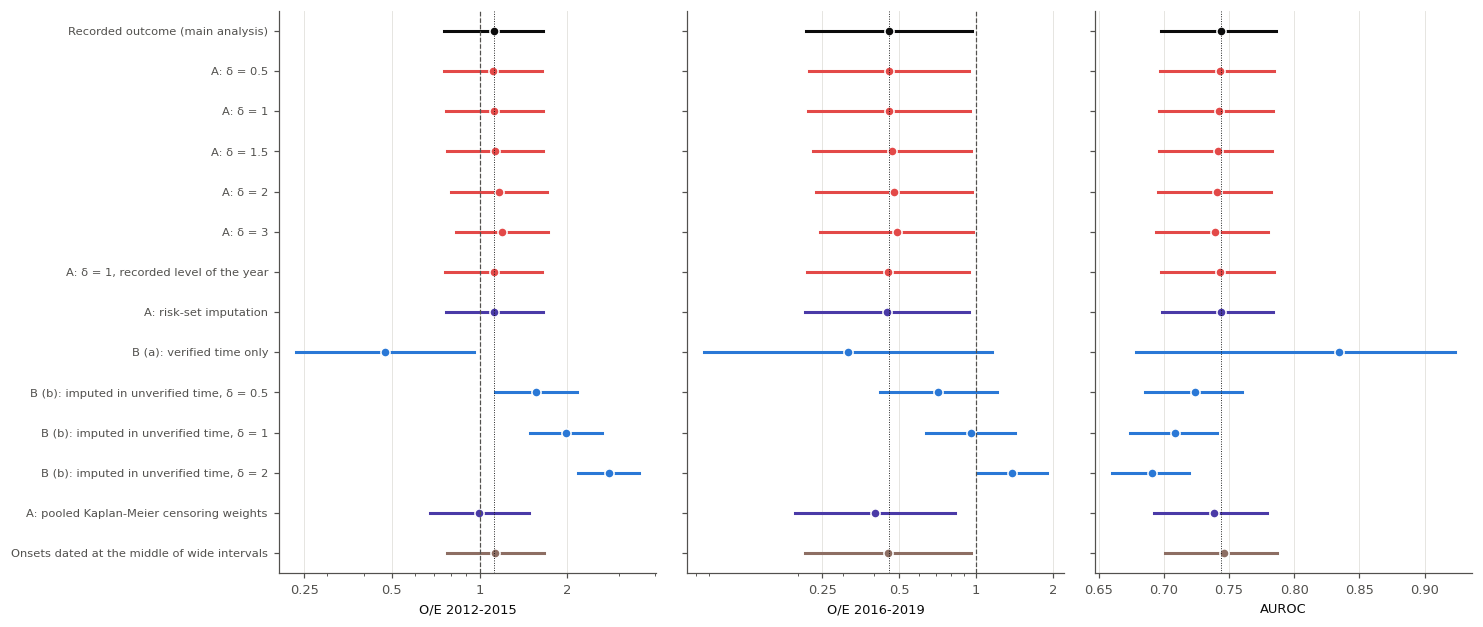

**What this means** (recorded outcome: O/E 2012-2015 1.12, 2016-2019 0.46;
AUROC 0.744).

* **Patients who left the clinic (group A).** Imputing their exits with the model's own hazards (δ = 1) moves the
  2012-2015 O/E to 1.12 and the 2016-2019 O/E to 0.46. The recent O/E reaches 0.9 at δ = 0.5.
  Risk-set imputation, which leans less on the model, gives 1.12 and
  0.45; pooled Kaplan-Meier censoring weights (no era, no covariates) give
  1.00 and 0.40.
* **Stale statuses (group B).** Counting only verified time (option a), the O/E is 0.47 in
  2012-2015 and 0.31 in 2016-2019 (verified onsets in the last period are very few).
  It does not move much towards 1.
  Imputing onsets in the unverified time at the model's hazard (option b, δ = 1) gives 1.98 and
  0.95.
* **Current against stale records.** In 2012-2015, the O/E is
  1.09 for visits whose status changed in the previous 3 years
  and 1.13 for visits whose status had not changed for longer
  (Section 5.2.5).
* **The ranking is robust to all of this.** The AUROC stays between 0.691 and
  0.834 across every analysis, and the patient C between
  0.634 and 0.765.

**The absolute level is what these analyses bound, and the bounds are wide.** Only the chart review (analysis 4) or
linkage to an outcome recorded independently of the form can estimate it.

In [90]:
"""Every sensitivity analysis for missing outcomes: AUROC, O/E by period, patient C."""
_cols_sa = ["AUROC", "O/E"] + list(_PERIOD_MASK) + ["Patient C"]
SA_TABLE = pd.DataFrame({n: {k: (f"{r[k][0]:.3f}" if k == "Patient C" else f"{r[k][0]:.2f} ({r[k][1]:.2f}-{r[k][2]:.2f})"
                                 if k.startswith("O/E") else f"{r[k][0]:.3f} ({r[k][1]:.3f}-{r[k][2]:.3f})")
                             for k in _cols_sa} for n, r in SA.items()}).T
display(SA_TABLE)
save_table(SA_TABLE, "sensitivity_missing_outcomes")
_late = [k for k in _PERIOD_MASK][-2:]
fig, axes = plt.subplots(1, 3, figsize=(14, 0.36 * len(SA) + 1.6), sharey=True, gridspec_kw={"wspace": 0.08})
_names_sa = list(SA)
_col_sa = lambda n: (INK if n.startswith("Recorded") else "#e34948" if n.startswith("A: δ") else C4 if n.startswith("A:")
                     else C1 if n.startswith("B") else C5)
for ax, k, ref in [(axes[0], _late[0], 1.0), (axes[1], _late[1], 1.0), (axes[2], "AUROC", None)]:
    for i, n in enumerate(_names_sa):
        e, lo, hi = SA[n][k]
        ax.plot([lo, hi], [i, i], color=_col_sa(n), lw=2)
        ax.plot(e, i, "o", color=_col_sa(n), ms=6, mec="white", mew=1)
    if ref:
        ax.axvline(ref, color=INK_2, lw=0.8, ls="--"); ax.set_xscale("log")
        ax.set_xticks([0.25, 0.5, 1, 2], ["0.25", "0.5", "1", "2"])
    ax.axvline(SA[_names_sa[0]][k][0], color=INK, lw=0.6, ls=":")
    ax.set_title(f"{k}" + ("" if k == "AUROC" else " (log scale)"), loc="left", fontsize=9)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(_names_sa)), _names_sa, fontsize=7.5); axes[0].set_ylim(len(_names_sa) - 0.5, -0.5)
save_fig("sensitivity_missing_outcomes")
_rec = SA["Recorded outcome (main analysis)"]
_sa_d1 = SA["A: δ = 1"]
_ba = SA["B (a): verified time only"]
_bb = [n for n in SA if n.startswith("B (b)") and "δ = 1" in n]
_tipA = next((d for d in DELTAS if SA[f"A: δ = {d:g}"][_late[0]][0] >= 0.9), None)
_cur = OE_CURRENT[OE_CURRENT["Period"] == f"{SA_PERIODS[-2][0]}-{SA_PERIODS[-2][1] - 1}"].set_index("Record")["O/E"]
say(f"""
**What this means** (recorded outcome: O/E {_late[0][4:]} {_rec[_late[0]][0]:.2f}, {_late[1][4:]} {_rec[_late[1]][0]:.2f};
AUROC {_rec['AUROC'][0]:.3f}).

* **Patients who left the clinic (group A).** Imputing their exits with the model's own hazards (δ = 1) moves the
  {_late[0][4:]} O/E to {_sa_d1[_late[0]][0]:.2f} and the {_late[1][4:]} O/E to {_sa_d1[_late[1]][0]:.2f}. {"The recent O/E reaches 0.9 at δ = " + format(_tipA, "g") + "." if _tipA else "No δ up to " + format(max(DELTAS), "g") + " brings the " + _late[0][4:] + " O/E to 0.9: leavers alone cannot explain the fall."}
  Risk-set imputation, which leans less on the model, gives {SA['A: risk-set imputation'][_late[0]][0]:.2f} and
  {SA['A: risk-set imputation'][_late[1]][0]:.2f}; pooled Kaplan-Meier censoring weights (no era, no covariates) give
  {SA['A: pooled Kaplan-Meier censoring weights'][_late[0]][0]:.2f} and {SA['A: pooled Kaplan-Meier censoring weights'][_late[1]][0]:.2f}.
* **Stale statuses (group B).** Counting only verified time (option a), the O/E is {_ba[_late[0]][0]:.2f} in
  {_late[0][4:]} and {_ba[_late[1]][0]:.2f} in {_late[1][4:]} (verified onsets in the last period are very few).
  {"In " + _late[0][4:] + " it moves most of the way towards 1: when only statuses that were recently re-checked are counted, much of the fall disappears, which is evidence that it lies in the record." if _ba[_late[0]][0] > _rec[_late[0]][0] * 1.25 else "It does not move much towards 1."}
  Imputing onsets in the unverified time at the model's hazard (option b, δ = 1) gives {SA[_bb[0]][_late[0]][0]:.2f} and
  {SA[_bb[0]][_late[1]][0]:.2f}.
* **Current against stale records.** In {SA_PERIODS[-2][0]}-{SA_PERIODS[-2][1] - 1}, the O/E is
  {_cur.get('Status changed in the previous 3 years', np.nan):.2f} for visits whose status changed in the previous 3 years
  and {_cur.get('Status unchanged for > 3 years', np.nan):.2f} for visits whose status had not changed for longer
  (Section 5.2.5).
* **The ranking is robust to all of this.** The AUROC stays between {min(r['AUROC'][0] for r in SA.values()):.3f} and
  {max(r['AUROC'][0] for r in SA.values()):.3f} across every analysis, and the patient C between
  {min(r['Patient C'][0] for r in SA.values()):.3f} and {max(r['Patient C'][0] for r in SA.values()):.3f}.

**The absolute level is what these analyses bound, and the bounds are wide.** Only the chart review (analysis 4) or
linkage to an outcome recorded independently of the form can estimate it.
""")

## 5.3 A broader outcome: counting early retirement, homemaking and "other" exits

> **The question.** Some patients who leave work for "another reason" may in fact have left because of their
> health: an early retirement at 55, or becoming a homemaker after years of fatigue. Would the conclusions change
> if these exits counted as work disability?

Studies of work in SLE define the outcome in two ways. Some count only **health-attributed** exits (disability or
long sick leave), as here. Others count **any loss of employment**, such as the Lupus Outcomes Study (any
cessation of work) or the GOAL cohort (disability benefits or unemployment before 65). The sensitivity model sits
between the two:

| Exit | Main analysis | Sensitivity analysis |
|:--|:--|:--|
| Disabled, or sick leave ≥ 6 months | Work disability | Work disability |
| **Retired before 60** | Competing exit | **Work disability** |
| **Homemaker** | Competing exit | **Work disability** |
| **Other** | Competing exit | **Work disability** |
| Retired at 60-64, student, looking for work | Competing exit | Competing exit |

First, how do patients who took these exits look at their last landmark, compared with patients who became
work-disabled? Then the whole procedure (HazReg and the first-visit model, same cross-validation) is rerun with
the broader outcome, and H1 is tested again under it (H6).

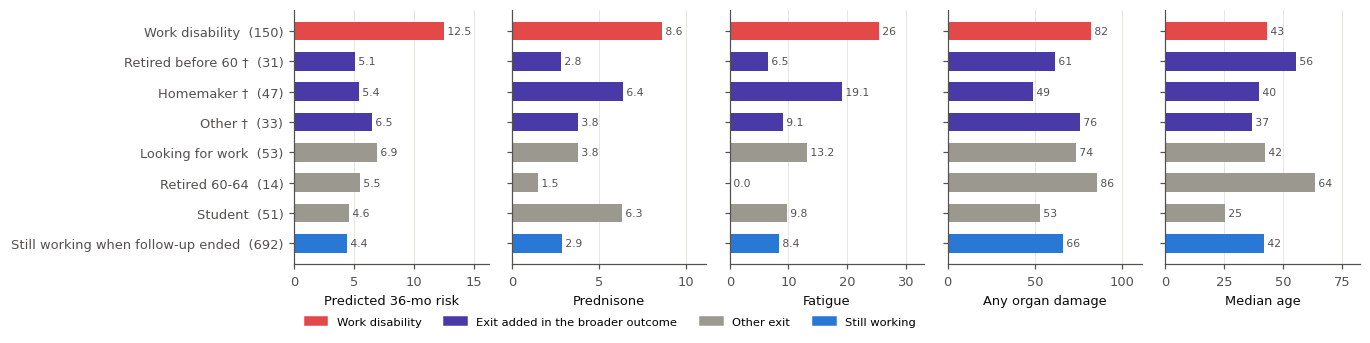

**What this means.** At their last landmark, patients who later became work-disabled had an average predicted
risk of 12.5 %, against 4.4 % for patients still
working when follow-up ended. Patients who **retired before 60** looked like those still working
(5.1 %): little prednisone, little fatigue, and a median age in the mid-fifties. Most
look like ordinary early retirement rather than disguised work disability. **Homemakers** and **other** exits sit in
between (5.4 % and 6.5 %), so some of them are probably health-related.
Adding all of them to the outcome mixes a minority of health-related exits with a majority that are not.

In [91]:
"""Who takes each kind of exit: risk profile at the last landmark before it."""
_age_end = land["age_at_record"].values + T_ALL / 365.25
_ex = land["exit_emp"].astype(object).fillna("").values
BROAD_FLAG = (C_ALL == 2) & (np.isin(_ex, list(BROAD_EXITS)) | ((_ex == "retired") & (_age_end < BROAD_RETIRE_BEFORE)))
_final = ~_cont                                                       # the interval that ends each follow-up
_grp = np.select([C_ALL == 1,
                  (C_ALL == 2) & (_ex == "retired") & (_age_end < BROAD_RETIRE_BEFORE),
                  (C_ALL == 2) & (_ex == "retired"),
                  (C_ALL == 2) & (_ex == "homemaker"), (C_ALL == 2) & (_ex == "other"),
                  (C_ALL == 2) & (_ex == "looking for work"), (C_ALL == 2) & (_ex == "student"),
                  C_ALL == 0],
                 ["Work disability", "Retired before 60 *", "Retired 60-64", "Homemaker *", "Other *",
                  "Looking for work", "Student", "Still working when follow-up ended"], "")
_pf = pd.DataFrame({"Group": _grp, "Age": _age_end, "Risk": P_MAIN,
                    "Prednisone": LAND_X["STERAVER_0"].values, "Fatigue": LAND_X["FATIGUE"].values,
                    "SDI >= 1": (LAND_X["score_n"].values >= 1).astype(float)})[_final & (_grp != "")]
EXIT_PROFILE = _pf.groupby("Group").agg(**{"Exits": ("Age", "size"), "Median age": ("Age", "median"),
                                            "Predicted 36-mo risk (%)": ("Risk", lambda s: 100 * s.mean()),
                                            "Prednisone (mg/day)": ("Prednisone", "mean"),
                                            "Fatigue (%)": ("Fatigue", lambda s: 100 * s.mean()),
                                            "Any organ damage (%)": ("SDI >= 1", lambda s: 100 * s.mean())}) \
    .reindex(["Work disability", "Retired before 60 *", "Homemaker *", "Other *", "Looking for work", "Retired 60-64",
              "Student", "Still working when follow-up ended"]).round(1)
save_table(EXIT_PROFILE, "exit_profile")
_role = lambda g: (STATE_COLORS["D"] if g == "Work disability" else STATE_COLORS["W"] if g.startswith("Still")
                   else C4 if g.endswith("*") else "#9a988f")
_ylab = [f"{g.replace(' *', '')}{' †' if g.endswith('*') else ''}  ({int(n)})" for g, n in EXIT_PROFILE["Exits"].items()]
_cols = ["Predicted 36-mo risk (%)", "Prednisone (mg/day)", "Fatigue (%)", "Any organ damage (%)", "Median age"]
fig, axes = plt.subplots(1, len(_cols), figsize=(12.5, 3.0), sharey=True, gridspec_kw={"wspace": 0.12})
for ax, c in zip(axes, _cols):
    v = EXIT_PROFILE[c].values
    ax.barh(range(len(v)), v, color=[_role(g) for g in EXIT_PROFILE.index], height=0.62)
    for i, x in enumerate(v):
        ax.text(x, i, f" {x:.1f}" if x < 20 else f" {x:.0f}", va="center", fontsize=7, color=INK_2)
    ax.set_xlim(0, v.max() * 1.3); ax.grid(axis="y", visible=False)
    ax.set_title(c, loc="left", fontsize=8.5)
axes[0].set_yticks(range(len(_ylab)), _ylab); axes[0].invert_yaxis()
fig.suptitle("Profile at the last landmark, by how follow-up ended (number of patients)", x=0.125, ha="left",
             fontsize=9, y=1.04)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=STATE_COLORS["D"], label="Work disability"), Patch(color=C4, label="Exit added in the broader outcome"),
                    Patch(color="#9a988f", label="Other exit"), Patch(color=STATE_COLORS["W"], label="Still working")],
           ncol=4, loc="upper left", bbox_to_anchor=(0.125, -0.02), fontsize=7.5)
fig.text(0.125, -0.15, "† added to the outcome in the broader-outcome sensitivity analysis. Risk: cross-validated "
         "HazReg at the last landmark.", fontsize=7, color=INK_2)
save_fig("exit_profile")
_ep = EXIT_PROFILE["Predicted 36-mo risk (%)"]
say(f"""
**What this means.** At their last landmark, patients who later became work-disabled had an average predicted
risk of {_ep['Work disability']:.1f} %, against {_ep['Still working when follow-up ended']:.1f} % for patients still
working when follow-up ended. Patients who **retired before 60** looked like those still working
({_ep['Retired before 60 *']:.1f} %): little prednisone, little fatigue, and a median age in the mid-fifties. Most
look like ordinary early retirement rather than disguised work disability. **Homemakers** and **other** exits sit in
between ({_ep['Homemaker *']:.1f} % and {_ep['Other *']:.1f} %), so some of them are probably health-related.
Adding all of them to the outcome mixes a minority of health-related exits with a majority that are not.
""")

,Main outcome: HazReg,Broader outcome: HazReg,Broader outcome: First visit
AUROC,0.744 (0.700 to 0.786),0.647 (0.608 to 0.688),0.612 (0.575 to 0.655)
Within-era AUROC,0.733 (0.689 to 0.775),0.635 (0.596 to 0.675),0.595 (0.557 to 0.637)
IPA,0.041 (0.009 to 0.068),0.027 (0.008 to 0.046),0.005 (-0.013 to 0.020)
O/E,0.959 (0.787 to 1.139),0.962 (0.839 to 1.093),0.948 (0.819 to 1.081)
Calibration slope,0.915 (0.752 to 1.105),0.892 (0.690 to 1.108),0.778 (0.513 to 1.160)
Patient C (time-matched),0.758 (0.717 to 0.798),0.671 (0.634 to 0.711),0.611 (0.574 to 0.652)
Alarm sensitivity,0.64 (0.57 to 0.72),0.50 (0.43 to 0.57),0.30 (0.24 to 0.36)
Alarm specificity,0.75 (0.72 to 0.78),0.75 (0.72 to 0.77),0.82 (0.78 to 0.85)


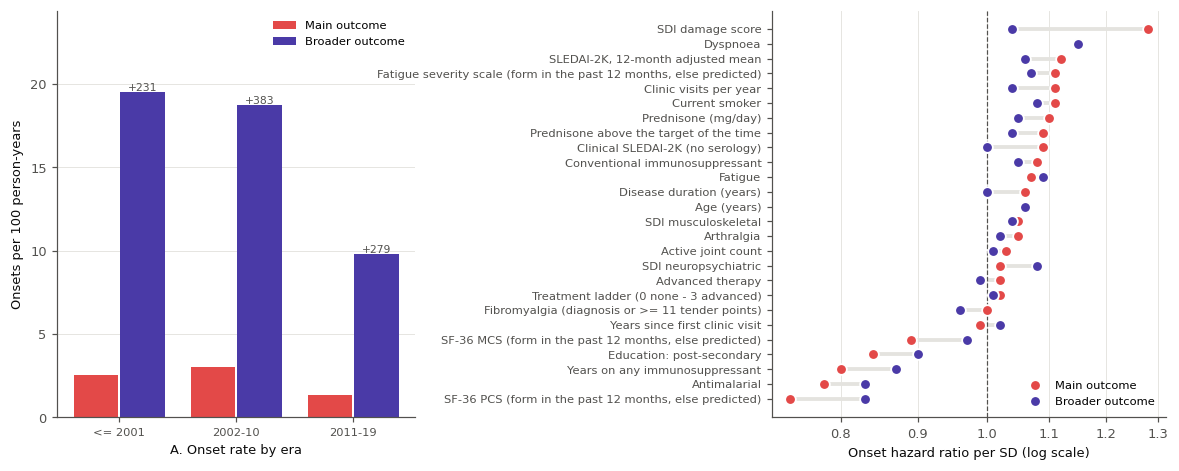

**What this means.**

* **The broader outcome adds 111 exits** to the 150 work-disability onsets, 893 of them
  before 2010, when other exits were common. The fall over calendar time therefore becomes steeper, not gentler
  (panel A above). Broadening the outcome does not remove the drift.
* **The model ranks the broader outcome less well:** AUROC 0.647 (0.608-0.688), against
  0.744 for the main outcome. The current visit changes the log score over the first visit by +0.0074
  (+0.0007 to +0.0142; **H6 met**) and the AUROC by +0.035.
  The added exits are harder to predict from disease markers, as expected if most of them are not health-related.
  At the patient level the pattern is the same: patient C 0.671 against
  0.758, +0.061 (+0.019 to +0.098) above the first-visit model; the alarm
  catches 50 % of the broader onsets, against
  64 % of the main ones.
* **The same patients are flagged.** 21 of 26 inputs keep the direction of
  their effect, and 20 have a weaker effect under the broader outcome, as expected when the outcome becomes
  less specific.

**Conclusion.** The main outcome is the better target for a tool meant to prompt vocational support: it is more
predictable, and closer to what the support is for. The broader definition is still useful when comparing with
studies that count any loss of employment, and it gives the same conclusions about who is at risk.

In [92]:
"""The broader outcome: cross-validation of HazReg and the first-visit model, and the refitted coefficients."""
C_BROAD = np.where(BROAD_FLAG, 1, C_ALL)
D1_B = (_ENDS & (C_BROAD == 1)).astype(float)
D2_B = (_ENDS & (C_BROAD == 2)).astype(float)
Y_B, W_B = ipcw_weights(T_ALL, C_BROAD)
for name, cols, spline in [("HazReg", COMPACT_VARS, SPLINE_VARS), ("First visit", FIRST_VARS, ())]:
    if f"cv_broad_{name}" not in STATE:
        STATE[f"cv_broad_{name}"] = run_cv("haz", cols, spline, d1=D1_B, d2=D2_B)
        _save_state()
P_BROAD = {n: cv_cif(STATE[f"cv_broad_{n}"])
           for n in ["HazReg", "First visit"]}
P_BROAD_ABS = {n: cv_cif(STATE[f"cv_broad_{n}"], "pred_own")
               for n in ["HazReg", "First visit"]}
BROAD_RES, BROAD_ARR = {}, {}
for n, p in P_BROAD.items():
    BROAD_RES[n], BROAD_ARR[n] = summarise(p, y=Y_B, w=W_B, p_abs=P_BROAD_ABS[n])
_bd = ci_of(BROAD_ARR["HazReg"]["Log score"] - BROAD_ARR["First visit"]["Log score"])
_bd_auc = ci_of(BROAD_ARR["HazReg"]["AUROC"] - BROAD_ARR["First visit"]["AUROC"])
BROAD_TABLE = pd.DataFrame({"Main outcome: HazReg": {k: fmt(v) for k, v in CV_RES["HazReg"].items()},
                            "Broader outcome: HazReg": {k: fmt(v) for k, v in BROAD_RES["HazReg"].items()},
                            "Broader outcome: First visit": {k: fmt(v) for k, v in BROAD_RES["First visit"].items()}})
BROAD_TABLE = BROAD_TABLE.loc[["AUROC", "Within-era AUROC", "IPA", "O/E", "Calibration slope"]]
# patient level under the broader outcome: its onsets are the cases, the same alarm rule
PT_EVAL_B = build_pt_eval(C=C_BROAD)
PT_BROAD_RES, PT_BROAD_ARR = {}, {}
for n, p in P_BROAD.items():
    PT_BROAD_RES[n], PT_BROAD_ARR[n] = pt_summary(PT_EVAL_B, p, alarm_flags(p), burden=False)
_bdp = ppaired("HazReg", "First visit", arr=PT_BROAD_ARR)
for col, r_ in [("Main outcome: HazReg", PT_RES["HazReg"]), ("Broader outcome: HazReg", PT_BROAD_RES["HazReg"]),
                ("Broader outcome: First visit", PT_BROAD_RES["First visit"])]:
    BROAD_TABLE.loc["Patient C (time-matched)", col] = fmt(r_["C"])
    BROAD_TABLE.loc["Alarm sensitivity", col] = fmt(r_["Sensitivity"], 2)
    BROAD_TABLE.loc["Alarm specificity", col] = fmt(r_["Specificity"], 2)
display(BROAD_TABLE)
record("H6", "The current visit still predicts better than the first visit under the broader outcome",
       "Log score, HazReg − First visit (broader outcome)", _bd, "above0", nd=4)
HYP["H6"]["Also"] = f"AUROC {fmt(_bd_auc)}"
record_pt("H6", _bdp)

_pyb, _d1b, _d2b = rates_by_era(D1_B, D2_B)
BROAD_RATES = pd.DataFrame({"Era": [e[2] for e in ERAS], "Main: onsets /100 py": 100 * _d1 / _py,
                            "Broader: onsets /100 py": 100 * _d1b / _pyb,
                            "Broader: added exits": (_d1b - _d1).astype(int)}).set_index("Era").round(2)
save_table(BROAD_RATES, "broad_outcome_rates")

if "final_broad" not in STATE:
    STATE["final_broad"] = fit_procedure(np.arange(N_LAND), d1=D1_B, d2=D2_B, seed=SEED)
    _save_state()
_fb = STATE["final_broad"]
_keep = [i for i, n in enumerate(FINAL["prep"].names) if not n.endswith(("__NL", "__MISSING"))]
BROAD_COEF = pd.DataFrame({"Main outcome HR per SD": np.exp(FINAL["coef"][0][_keep]),
                           "Broader outcome HR per SD": np.exp(_fb["coef"][0][_keep])},
                          index=[DISPLAY[FINAL["prep"].names[i]] for i in _keep]).round(2)
BROAD_COEF["Same direction"] = np.where(np.sign(np.log(BROAD_COEF.iloc[:, 0])) == np.sign(np.log(BROAD_COEF.iloc[:, 1])),
                                        "yes", "no")
save_table(BROAD_COEF, "broad_outcome_coefficients")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.1], "wspace": 0.95})
ax = axes[0]
_xb = np.arange(len(BROAD_RATES))
ax.bar(_xb - 0.2, BROAD_RATES["Main: onsets /100 py"], 0.38, color=LEFT_C, label="Main outcome")
ax.bar(_xb + 0.2, BROAD_RATES["Broader: onsets /100 py"], 0.38, color=C4, label="Broader outcome")
for i, n_ in enumerate(BROAD_RATES["Broader: added exits"]):
    ax.text(i + 0.2, BROAD_RATES["Broader: onsets /100 py"].iloc[i] + 0.1, f"+{n_}", ha="center", fontsize=7,
            color=INK_2)
ax.set_xticks(_xb, BROAD_RATES.index, fontsize=7.5); ax.grid(axis="x", visible=False)
ax.set_ylabel("Onsets per 100 person-years"); ax.legend(fontsize=7.5, loc="upper right")
ax.set_ylim(0, BROAD_RATES["Broader: onsets /100 py"].max() * 1.25)
ax.set_title("A. Onset rate by era (+ exits added)", loc="left", fontsize=9)
ax = axes[1]
_bc = BROAD_COEF.sort_values("Main outcome HR per SD")
_yb = np.arange(len(_bc))
ax.axvline(1, color=INK_2, ls="--", lw=0.8)
ax.hlines(_yb, _bc.iloc[:, 0], _bc.iloc[:, 1], color=GRID_C, lw=2.5, zorder=1)
ax.plot(_bc.iloc[:, 0], _yb, "o", color=LEFT_C, ms=7, mec="white", mew=1.2, label="Main outcome", zorder=2)
ax.plot(_bc.iloc[:, 1], _yb, "o", color=C4, ms=7, mec="white", mew=1.2, label="Broader outcome", zorder=2)
ax.set_xscale("log"); ax.set_yticks(_yb, _bc.index, fontsize=7.5); ax.grid(axis="y", visible=False)
from matplotlib.ticker import FixedLocator, NullLocator, FormatStrFormatter
ax.xaxis.set_major_locator(FixedLocator([0.8, 0.9, 1.0, 1.1, 1.2, 1.3])); ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(FormatStrFormatter("%.1f"))
ax.set_xlabel("Onset hazard ratio per SD (log scale)"); ax.legend(fontsize=7.5, loc="lower right")
ax.set_title("B. Effect of each input under the two outcomes", loc="left", fontsize=9)
save_fig("broad_outcome")
_ba, _ma = BROAD_RES["HazReg"]["AUROC"], CV_RES["HazReg"]["AUROC"]
_nadd = int((~_cont & (C_BROAD == 1)).sum() - D1_ALL.sum())
_flip = (BROAD_COEF["Same direction"] == "no").sum()
_smaller = int((np.abs(np.log(BROAD_COEF.iloc[:, 1])) < np.abs(np.log(BROAD_COEF.iloc[:, 0]))).sum())
_early_add = int(BROAD_RATES["Broader: added exits"].iloc[:3].sum())
say(f"""
**What this means.**

* **The broader outcome adds {_nadd} exits** to the {int(D1_ALL.sum())} work-disability onsets, {_early_add} of them
  before 2010, when other exits were common. The fall over calendar time therefore becomes steeper, not gentler
  (panel A above). Broadening the outcome does not remove the drift.
* **The model ranks the broader outcome less well:** AUROC {_ba[0]:.3f} ({_ba[1]:.3f}-{_ba[2]:.3f}), against
  {_ma[0]:.3f} for the main outcome. The current visit changes the log score over the first visit by {_bd[0]:+.4f}
  ({_bd[1]:+.4f} to {_bd[2]:+.4f}; **H6 {"met" if HYP['H6']['_met'] else "not met"}**) and the AUROC by {_bd_auc[0]:+.3f}.
  The added exits are harder to predict from disease markers, as expected if most of them are not health-related.
  At the patient level the pattern is the same: patient C {PT_BROAD_RES['HazReg']['C'][0]:.3f} against
  {PT_RES['HazReg']['C'][0]:.3f}, {_bdp[0]:+.3f} ({_bdp[1]:+.3f} to {_bdp[2]:+.3f}) above the first-visit model; the alarm
  catches {100 * PT_BROAD_RES['HazReg']['Sensitivity'][0]:.0f} % of the broader onsets, against
  {100 * PT_RES['HazReg']['Sensitivity'][0]:.0f} % of the main ones.
* **The same patients are flagged.** {len(BROAD_COEF) - _flip} of {len(BROAD_COEF)} inputs keep the direction of
  their effect, and {_smaller} have a weaker effect under the broader outcome, as expected when the outcome becomes
  less specific.

**Conclusion.** The main outcome is the better target for a tool meant to prompt vocational support: it is more
predictable, and closer to what the support is for. The broader definition is still useful when comparing with
studies that count any loss of employment, and it gives the same conclusions about who is at risk.
""")

---
# Part VI. Clinical use

> **The decision.** At a routine visit, should this working patient be asked about work and offered vocational
> support? A referral is cheap and low-harm, and missing someone who then leaves work is costly.

The tool acts on **relative bands** (Section 3.0), so the policies compared are "flag the visits in the Raised or
High band" and "flag the High band", not "flag above 4 %". Four questions, all answered with the cross-validated predictions
(each visit scored by models that never saw its patient):

1. **Are the predicted risks right?** Calibration by tenth of predicted risk (over all years; the recent level is
   not identifiable, Part IV).
2. **What do the tiers mean in practice?** The share of visits in each tier, and the risk observed there.
3. **Does flagging by tier beat simple policies?** Net benefit against referring everyone or no one, over a range
   of exchange rates (the risk at which a referral is judged worth it). A net benefit of 0.01 means the same as
   finding 1 extra future case per 100 visits with no unnecessary referrals. The exchange rate weighs a missed
   case against an unneeded referral; the net benefit of a fixed absolute threshold depends on the base rate, which
   is why the tool's cut-offs are relative.
4. **What does each share flagged buy?** A capacity table: flagging *N* patients a year catches *X* % of the
   patients who go on to leave work.

## 6.1 Calibration, risk tiers and net benefit

,Landmarks (%),Visits from 2015 (%),Patients,"Relative risk, mean",Mean predicted (%),Observed 36-mo risk (%),95% CI,Observed risk ratio vs Low,Share of onsets (%)
Tier,,,,,,,,,
Low (bottom 50 %),50.0,59.72,647,0.59,2.00,1.68,1.0-2.4,1.00,16.92
Raised (50th-85th percentile),35.0,30.22,657,1.60,5.38,5.69,4.4-7.1,3.38,40.03
High (top 15 %),15.0,10.06,401,4.57,15.38,14.28,11.0-17.7,8.48,43.05


,Net benefit: model,95% CI low,95% CI high,Net benefit: refer all,Referrals avoided per 100 (vs all)
Threshold,,,,,
0.02,0.0320,0.0234,0.0420,0.0304,7.8570
0.04,0.0223,0.0142,0.0304,0.0102,29.1503
0.06,0.0156,0.0090,0.0215,-0.0109,41.5065
0.10,0.0070,0.0024,0.0125,-0.0558,56.5118


,Patient alarm (cross-validated HazReg)
Alarms raised,624
Mean predicted 36-mo risk at the alert (%),13.127723
Observed: onset within 36 months of the alert (%),14.01943
95% CI,10.8-17.7


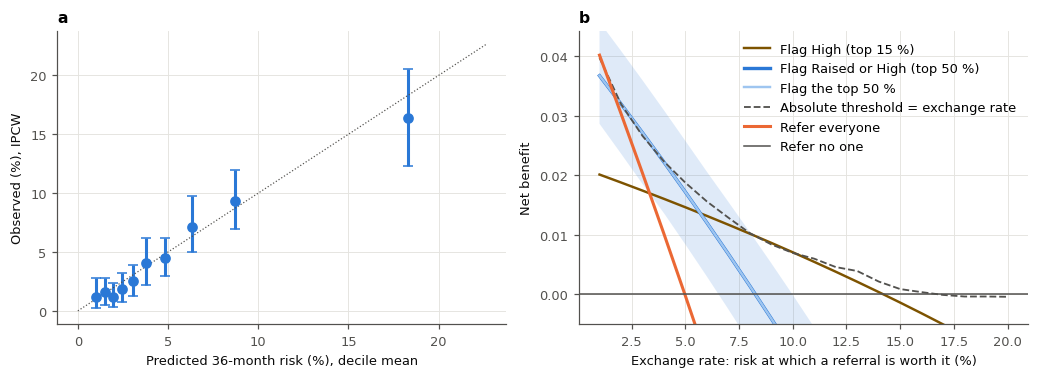

**What this means.**

* **Calibration.** Across tenths of predicted risk, observed risk follows prediction (slope 0.92,
  O/E 0.96). These are averages over all years; the recorded level of recent years is lower and
  cannot be taken at face value (Part IV). Section 6.1.1 tests calibration (H3a) on the flexible curve.
* **The bands separate patients usefully.** The Low band (bottom 50 % of visits) has an observed 36-month risk of
  1.7 %; the High band (top 15 %) 14.3 %, about
  8 times higher. The Raised and High bands together hold
  50 % of visits and 83 % of future onsets.
  From 2015, 40 % of visits fall in these two bands: fewer, because recent
  patients are healthier.
* **Flagging the Raised and High bands beats the simple policies** at exchange rates from about 2 % to
  8 % (point estimates). With its uncertainty (H3c, estimated): -0.0734 (-0.0863 to -0.0610) at 20 % (the weakest point); CI above 0 at exchange rates 3-6 %. Which
  exchange rates matter is for the clinic's staff to say (Section 7.5), not for the data.

* **At the moment a flag is raised**, the mean predicted risk is 13.1 %,
  and 14.0 % (95 % CI 10.8-17.7) of alarms are
  followed by an onset within 36 months: the alarm's risk is about right at the patient level too.

In clinic: **ask every patient in the Raised and High bands about work at each visit, and offer referral**, High
first. In the Low band, a brief check at the yearly review is enough.

,"Patients flagged per year, 2015-19",of working patients seen per year (%),Onset patients flagged in the 36 months before (%),Onsets from 2015 flagged (%),Visits followed by an onset that were flagged (%)
Share of development landmarks flagged (%),,,,,
2.0,5.6,1.5,21.2,13.6,9.7
10.0,29.6,7.7,49.6,45.5,32.9
15.0,46.4,12.0,64.2,59.1,43.1
20.0,59.2,15.4,71.5,59.1,51.6
40.0,125.8,32.6,85.4,68.2,75.0
50.0,168.6,43.7,91.2,77.3,83.1


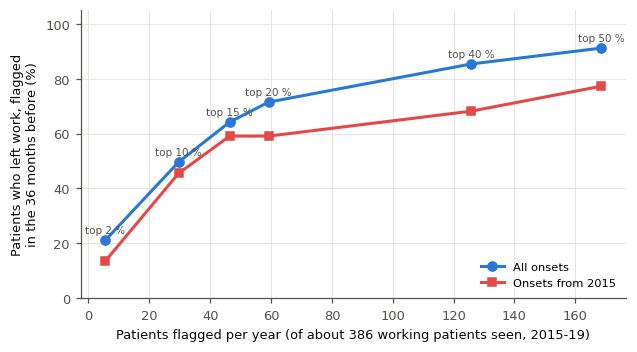

**Capacity.** In the recent clinic (about 386 working patients seen a year, 2015-19), flagging visits in the
Raised or High band (the top 50 %) means talking to about **169 patients a year**
(44 % of them), and catches **91 %**
of the patients who go on to leave work (77 % of those leaving from 2015). The High
band alone means about 46 patients a year and catches
64 %. The clinic can pick its row of the table by the number of
conversations it can afford.

In [93]:
"""Calibration by decile, risk tiers, decision curve (cross-validated predictions)."""
_k = W_IP > 0
_Wb = W_BOOT[:, ROW_PIDX]
# one risk scale: the model has no calendar term, so calibration and the tool read the same risk (Section 4.3)
P_CAL = P_ABS.get("HazReg", P_MAIN)
_dec = pd.qcut(P_CAL, 10, labels=False, duplicates="drop")
_cal = []
for d in range(_dec.max() + 1):
    m_ = _dec == d
    obs = (_Wb[:, m_] * (W_IP * Y_IP)[m_]).sum(1) / _Wb[:, m_].sum(1)
    _cal.append((P_CAL[m_].mean(), obs[0], *np.percentile(obs[1:], [2.5, 97.5])))
_cal = np.array(_cal)

_tiers = np.digitize(P_MAIN, [t[1] for t in RISK_TIERS[:-1]])
_on24 = (W_IP * Y_IP)
TIERS = []
_recent15 = LAND_YEAR >= 2015
for i, (_, _, lab) in enumerate(RISK_TIERS):
    m_ = _tiers == i
    obs = (_Wb[:, m_] * _on24[m_]).sum(1) / _Wb[:, m_].sum(1)
    TIERS.append({"Tier": f"{lab} ({REL_TIER_DESC[i]})", "Landmarks (%)": 100 * m_.mean(),
                  "Visits from 2015 (%)": 100 * m_[_recent15].mean(), "Patients": len(np.unique(PID_ALL[m_])),
                  "Relative risk, mean": P_MAIN[m_].mean() / REF_RISK,
                  "Mean predicted (%)": 100 * P_MAIN[m_].mean(), "Observed 36-mo risk (%)": 100 * obs[0],
                  "95% CI": f"{100 * np.percentile(obs[1:], 2.5):.1f}-{100 * np.percentile(obs[1:], 97.5):.1f}",
                  "Observed risk ratio vs Low": np.nan, "Share of onsets (%)": 100 * _on24[m_].sum() / _on24.sum()})
TIERS = pd.DataFrame(TIERS).set_index("Tier")
TIERS["Observed risk ratio vs Low"] = TIERS["Observed 36-mo risk (%)"] / TIERS["Observed 36-mo risk (%)"].iloc[0]
TIERS = TIERS.round(2)
display(TIERS)


def net_benefit(p, thresholds, Wrow):
    Wk = Wrow * W_IP
    n = Wk.sum(1)
    out = []
    for t in thresholds:
        a = p >= t
        tp = (Wk * (Y_IP * a)).sum(1) / n
        fp = (Wk * ((1 - Y_IP) * a * (W_IP > 0))).sum(1) / n
        out.append(tp - fp * t / (1 - t))
    return np.array(out)                           # (thresholds, B)


_nb = net_benefit(P_MAIN, DCA_THRESHOLDS, _Wb[:201])
_nb_all = net_benefit(np.ones(N_LAND), DCA_THRESHOLDS, _Wb[:201])
# relative policies: a fixed share of visits flagged, whatever the exchange rate
MAIN_POLICY = f"Flag Raised or High (top {100 - 100 * REL_TIER_SHARES[0]:.0f} %)"
REL_POLICIES = {f"Flag High (top {100 - 100 * REL_TIER_SHARES[1]:.0f} %)": 1 - REL_TIER_SHARES[1],
                MAIN_POLICY: 1 - REL_TIER_SHARES[0], "Flag the top 50 %": 0.50}
_nb_rel = {nm: net_benefit(np.where(P_MAIN >= np.quantile(P_MAIN, 1 - q), 1.0, 0.0), DCA_THRESHOLDS, _Wb[:201])
           for nm, q in REL_POLICIES.items()}
DCA = pd.DataFrame({"Threshold": DCA_THRESHOLDS, "Net benefit: model": _nb[:, 0],
                    "95% CI low": np.percentile(_nb[:, 1:], 2.5, axis=1),
                    "95% CI high": np.percentile(_nb[:, 1:], 97.5, axis=1), "Net benefit: refer all": _nb_all[:, 0],
                    "Referrals avoided per 100 (vs all)": 100 * (_nb[:, 0] - _nb_all[:, 0]) /
                                                          (DCA_THRESHOLDS / (1 - DCA_THRESHOLDS))}).set_index("Threshold")
display(DCA.loc[[0.02, 0.04, 0.06, 0.1]].round(4))

# ---- patient level: is the risk at the moment an alarm is raised right? (predicted vs observed after the alert)
_st_alarm = alarm_starts(FLAGS["HazReg"])
_ka = _st_alarm & (W_IP > 0)
ALARM_CAL = {"Alarms raised": int(_st_alarm.sum()), "Mean predicted 36-mo risk at the alert (%)": 100 * P_MAIN[_st_alarm].mean(),
             "Observed: onset within 36 months of the alert (%)": PT_RES["HazReg"]["Episode PPV (%)"][0],
             "95% CI": "{:.1f}-{:.1f}".format(*PT_RES["HazReg"]["Episode PPV (%)"][1:])}
display(pd.Series(ALARM_CAL).to_frame("Patient alarm (cross-validated HazReg)"))

# ---- H3c (estimated, not tested; Vickers et al. 2023): the net-benefit gain of flagging Raised or High over the better
# simple policy, over the exchange rates elicited from the clinic's staff (NB_RANGE_ELICITED) or, until they are
# elicited, over the whole decision curve. Reported: the exchange rates at which the gain's 95 % CI lies above 0, and
# the gain at the weakest point of the range.
_cr = CV_RES["HazReg"]
NB_USE = NB_RANGE_ELICITED if NB_RANGE_ELICITED is not None else (float(DCA_THRESHOLDS[0]), float(DCA_THRESHOLDS[-1]))
_in_rng = (DCA_THRESHOLDS >= NB_USE[0] - 1e-9) & (DCA_THRESHOLDS <= NB_USE[1] + 1e-9)
_gain = _nb_rel[MAIN_POLICY] - np.maximum(_nb_all, 0.0)       # (thresholds, B): vs the better simple policy
NB_GAIN = pd.DataFrame({"Exchange rate": DCA_THRESHOLDS, "Gain": _gain[:, 0],
                        "low": np.percentile(_gain[:, 1:], 2.5, axis=1),
                        "high": np.percentile(_gain[:, 1:], 97.5, axis=1)}).set_index("Exchange rate")
_worst = NB_GAIN[_in_rng]["low"].idxmin()
_pos = NB_GAIN.index[_in_rng & (NB_GAIN["low"] > 0).values]
record("H3c", "How much does flagging the Raised and High bands gain over referring everyone or no one?",
       f"Net benefit, Raised or High − best simple policy, exchange rates {100 * NB_USE[0]:.0f}-{100 * NB_USE[1]:.0f} %"
       + ("" if NB_RANGE_ELICITED is not None else " (whole curve: range not yet elicited)"),
       tuple(NB_GAIN.loc[_worst, ["Gain", "low", "high"]]), "above0", nd=4)
HYP["H3c"]["Result"] += (f" at {100 * _worst:.0f} % (the weakest point); CI above 0 at exchange rates "
                         + (f"{100 * _pos.min():.0f}-{100 * _pos.max():.0f} %" if len(_pos) else "none") )

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5))
ax = axes[0]
ax.errorbar(100 * _cal[:, 0], 100 * _cal[:, 1], yerr=[100 * (_cal[:, 1] - _cal[:, 2]), 100 * (_cal[:, 3] - _cal[:, 1])],
            fmt="o", color=C1, ms=6, capsize=3)
_l = 100 * max(_cal[:, 0].max(), _cal[:, 3].max()) * 1.1
ax.plot([0, _l], [0, _l], color=INK_2, lw=0.8, ls=":")
ax.set_xlabel("Predicted 36-month risk (%), decile mean"); ax.set_ylabel("Observed (%), IPCW")
ax.set_title("a  Calibration (cross-validated)", loc="left")
ax = axes[1]
x = 100 * DCA_THRESHOLDS
for (nm, v), col in zip(_nb_rel.items(), ["#7d5300", C1, "#9ec5f0"]):
    ax.plot(x, v[:, 0], color=col, lw=2.2 if nm == MAIN_POLICY else 1.6, label=nm)
    if nm == MAIN_POLICY:
        ax.fill_between(x, np.percentile(v[:, 1:], 2.5, axis=1), np.percentile(v[:, 1:], 97.5, axis=1), color=col,
                        alpha=0.15, linewidth=0)
ax.plot(x, DCA["Net benefit: model"], color=INK_2, lw=1.2, ls="--", label="Absolute threshold = exchange rate")
ax.plot(x, DCA["Net benefit: refer all"], color=C2, label="Refer everyone")
ax.axhline(0, color=INK_2, lw=1, label="Refer no one")
ax.set_ylim(min(-0.005, DCA["Net benefit: model"].min() * 1.2), max(DCA["Net benefit: refer all"].max(), 0.04) * 1.1)
ax.set_xlabel("Exchange rate: risk at which a referral is worth it (%)"); ax.set_ylabel("Net benefit")
ax.set_title("b  Decision curve, 36 months", loc="left"); ax.legend()
plt.tight_layout(); save_fig("fig06_clinical_use")
_t = TIERS
_nb20 = _nb_rel[MAIN_POLICY][:, 0]
_cross = DCA.index[(_nb20 > DCA["Net benefit: refer all"].values) & (_nb20 > 0)]
say(f"""
**What this means.**

* **Calibration.** Across tenths of predicted risk, observed risk follows prediction (slope {_cr['Calibration slope'][0]:.2f},
  O/E {_cr['O/E'][0]:.2f}). These are averages over all years; the recorded level of recent years is lower and
  cannot be taken at face value (Part IV). Section 6.1.1 tests calibration (H3a) on the flexible curve.
* **The bands separate patients usefully.** The Low band ({REL_TIER_DESC[0]} of visits) has an observed 36-month risk of
  {_t.iloc[0]['Observed 36-mo risk (%)']:.1f} %; the High band ({REL_TIER_DESC[-1]}) {_t.iloc[-1]['Observed 36-mo risk (%)']:.1f} %, about
  {_t.iloc[-1]['Observed risk ratio vs Low']:.0f} times higher. The Raised and High bands together hold
  {_t.iloc[-2:]['Landmarks (%)'].sum():.0f} % of visits and {_t.iloc[-2:]['Share of onsets (%)'].sum():.0f} % of future onsets.
  From 2015, {_t.iloc[-2:]['Visits from 2015 (%)'].sum():.0f} % of visits fall in these two bands: fewer, because recent
  patients are healthier.
* **Flagging the Raised and High bands beats the simple policies** at exchange rates from about {100 * _cross.min():.0f} % to
  {100 * _cross.max():.0f} % (point estimates). With its uncertainty (H3c, estimated): {HYP['H3c']['Result']}. Which
  exchange rates matter is for the clinic's staff to say (Section 7.5), not for the data.

* **At the moment a flag is raised**, the mean predicted risk is {ALARM_CAL['Mean predicted 36-mo risk at the alert (%)']:.1f} %,
  and {ALARM_CAL['Observed: onset within 36 months of the alert (%)']:.1f} % (95 % CI {ALARM_CAL['95% CI']}) of alarms are
  followed by an onset within 36 months: the alarm's risk is {"about right" if abs(np.log(ALARM_CAL['Observed: onset within 36 months of the alert (%)'] / ALARM_CAL['Mean predicted 36-mo risk at the alert (%)'])) < 0.2 else "off by a factor of " + format(ALARM_CAL['Observed: onset within 36 months of the alert (%)'] / ALARM_CAL['Mean predicted 36-mo risk at the alert (%)'], ".2f")} at the patient level too.

In clinic: **ask every patient in the Raised and High bands about work at each visit, and offer referral**, High
first. In the Low band, a brief check at the yearly review is enough.
""" if len(_cross) else "**What this means.** Flagging by band does not beat referring everyone or no one at any exchange rate.")

# ---- capacity: flagging N patients a year catches X % of the patients who go on to leave work
PT_EVAL_2015 = build_pt_eval(onset_from=_day(2015))
_yr_int = np.floor(LAND_YEAR).astype(int)
_rec_years = [y for y in range(2015, 2020)]
_pts_year = np.mean([len(np.unique(PID_ALL[_yr_int == y])) for y in _rec_years])
_cap = []
for q in sorted({0.02, 0.10, 0.20, 0.40, 0.50, round(1 - REL_TIER_SHARES[0], 2), round(1 - REL_TIER_SHARES[1], 2)}):
    a = P_MAIN >= np.quantile(P_MAIN, 1 - q)
    flagged_year = np.mean([len(np.unique(PID_ALL[(_yr_int == y) & a])) for y in _rec_years])
    caught = lambda ev: 100 * np.mean(((ev["M"] @ a.astype(float)) > 0)[ev["case_ent"]])
    _cap.append({"Share of development landmarks flagged (%)": round(100 * q, 1),
                 "Patients flagged per year, 2015-19": flagged_year,
                 "of working patients seen per year (%)": 100 * flagged_year / _pts_year,
                 "Onset patients flagged in the 36 months before (%)": caught(PT_EVAL),
                 "Onsets from 2015 flagged (%)": caught(PT_EVAL_2015),
                 "Visits followed by an onset that were flagged (%)": 100 * np.sum((W_IP * Y_IP)[a]) / np.sum(W_IP * Y_IP)})
CAPACITY = pd.DataFrame(_cap).set_index("Share of development landmarks flagged (%)").round(1)
display(CAPACITY)
save_table(CAPACITY, "capacity")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(CAPACITY["Patients flagged per year, 2015-19"], CAPACITY["Onset patients flagged in the 36 months before (%)"],
        "-o", color=C1, label="All onsets")
ax.plot(CAPACITY["Patients flagged per year, 2015-19"], CAPACITY["Onsets from 2015 flagged (%)"], "-s", color="#e34948",
        ms=5, label="Onsets from 2015")
for q, r in CAPACITY.iterrows():
    ax.text(r["Patients flagged per year, 2015-19"], r["Onset patients flagged in the 36 months before (%)"] + 2.5,
            f"top {q:g} %", fontsize=6.8, ha="center", color=INK_2)
ax.set_xlabel(f"Patients flagged per year (of about {_pts_year:.0f} working patients seen, 2015-19)")
ax.set_ylabel("Patients who left work, flagged\nin the 36 months before (%)"); ax.set_ylim(0, 105)
ax.legend(fontsize=7.5, loc="lower right"); ax.set_title("Capacity: patients flagged against onsets caught", loc="left", fontsize=9)
save_fig("capacity")
_c20, _c6 = CAPACITY.loc[round(100 - 100 * REL_TIER_SHARES[0], 1)], CAPACITY.loc[round(100 - 100 * REL_TIER_SHARES[1], 1)]
say(f"""
**Capacity.** In the recent clinic (about {_pts_year:.0f} working patients seen a year, 2015-19), flagging visits in the
Raised or High band (the top {100 - 100 * REL_TIER_SHARES[0]:.0f} %) means talking to about **{_c20['Patients flagged per year, 2015-19']:.0f} patients a year**
({_c20['of working patients seen per year (%)']:.0f} % of them), and catches **{_c20['Onset patients flagged in the 36 months before (%)']:.0f} %**
of the patients who go on to leave work ({_c20['Onsets from 2015 flagged (%)']:.0f} % of those leaving from 2015). The High
band alone means about {_c6['Patients flagged per year, 2015-19']:.0f} patients a year and catches
{_c6['Onset patients flagged in the 36 months before (%)']:.0f} %. The clinic can pick its row of the table by the number of
conversations it can afford.
""")

### 6.1.1 Calibration in depth (H3a)

The decile plot above checks calibration only coarsely. Four further checks:

| Check | How | Why |
|:--|:--|:--|
| **Flexible calibration curve** | Censoring-weighted logistic regression of the 36-month outcome on a restricted cubic spline (4 knots) of the complementary log-log of the predicted risk; 95 % band from 200 patient resamples | Shows *where* the risks are off, not only on average |
| **ICI, E50, E90** (Austin & Steyerberg 2019) | The mean, median and 90th percentile of the absolute gap between the curve and the prediction, over the landmarks | One-number summaries of the curve, in risk units |
| **Both exits** | The same for the predicted 36-month cumulative incidence of the competing exit | The onset risk is computed from both hazards: a miscalibrated competing hazard distorts it |
| **Aalen-Johansen** | The observed cumulative incidence in each tenth of predicted risk and each tier, estimated directly with competing risks (no censoring model) | Checks that the result does not rest on the censoring weights |
| **By era, with the era's own baseline** | Calibration slope of the onset log-hazard with an era-specific intercept; ICI after the era's level is matched | The tool uses relative tiers, so what must hold in every era is the ordering and spread of the risks, not their level |

**H3a is answered by estimation.** The literature on calibration (Van Calster et al. 2016, 2019) recommends showing
the curve, the slope and the intercept and offers no accepted threshold for "well calibrated", so none is applied.
The slope is reported with the smallest margin around 1 that holds its 95 % CI, and the ICI as a share of the mean
predicted risk. Observed / expected is reported too: the level depends on how completely recent onsets are recorded
(Part IV), which the tool's relative tiers do not depend on.

,ICI,E50,E90,Mean predicted 36-mo risk,Calibration slope
Work-disability onset,0.0048 (0.0032 to 0.0150),0.0023 (0.0017 to 0.0108),0.0048 (0.0044 to 0.0297),0.0519,0.92 (0.75 to 1.11)
Other exit (competing),0.0070 (0.0026 to 0.0181),0.0068 (0.0017 to 0.0190),0.0119 (0.0034 to 0.0325),0.0831,0.47 (-0.57 to 1.34)


Visits  Predicted onset (%)  Observed onset, Aalen-Johansen (%)  AJ 95% CI  Observed onset, IPCW (%)  Predicted other exit (%)  Observed other exit, AJ (%)
Grouping                Group                                                                                                                                                              
Tenth of predicted risk 1         1298                 1.01                                1.16    0.2-2.4                      1.20                      7.56                         6.70
                        2         1298                 1.52                                1.67    0.5-2.9                      1.58                      7.86                         7.33
                        3         1297                 1.97                                1.18    0.3-2.3                      1.21                      7.97                         6.36
                        4         1298                 2.45                                1.80    0.7-3.0                      1.87                      8.14                         5.65
                        5         1297                 3.04                                2.72    1.4-4.1                      2.57                      8.22                         8.07
                        6         1298                 3.75                                4.12    2.3-6.4                      4.05                      8.41                         9.70
                        7         1297                 4.83                                4.58    3.0-6.3                      4.51                      8.61                         8.89
                        8         1298                 6.31                                7.47   5.0-10.0                      7.13                      8.66                         8.85
                        9         1297                 8.69                                9.60   6.9-12.2                      9.30                      8.78                         9.71
                        10        1298                18.30                               16.27  12.5-20.8                     16.37                      8.85                        10.60
Tier                    Low       6488                 2.00                                1.71    1.0-2.3                      1.68                      7.95                         6.83
                        Raised    4541                 5.38                                5.89    4.4-7.5                      5.69                      8.58                         9.16
                        High      1947                15.38                               14.39  11.4-17.9                     14.28                      8.86                        10.42

,Visits,Onsets within 36 mo,O/E,"Slope, own baseline",ICI,"ICI, era level matched"
Era,,,,,,
<= 2001,2514,158,0.95 (0.68 to 1.22),1.04 (0.74 to 1.34),0.0140 (0.0104 to 0.0338),0.0145 (0.0100 to 0.0343)
2002-10,4486,268,1.12 (0.89 to 1.40),0.79 (0.56 to 1.02),0.0158 (0.0086 to 0.0304),0.0137 (0.0076 to 0.0279)
2011-19,5976,162,0.81 (0.56 to 1.12),1.03 (0.70 to 1.35),0.0100 (0.0034 to 0.0196),0.0027 (0.0024 to 0.0153)


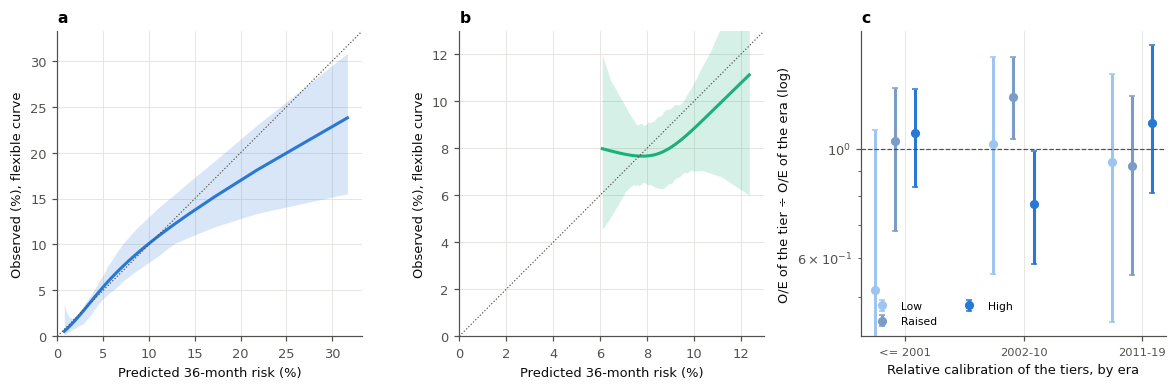

**What this means.**

* **Onset risk.** The flexible curve gives an ICI of 0.0048 (0.0032 to 0.0150): on average the
  predicted 36-month risk is off by 0.48 percentage points, against a mean predicted risk of
  5.2 %, with a calibration slope of 0.92 (0.75 to 1.11). Calibration is reported as an estimate (H3a):
  there is no accepted threshold for "well calibrated", so no pass / fail rule is applied.
* **Competing exit.** Its ICI is 0.0070 (0.0026 to 0.0181) against a mean predicted
  8.3 %. As a share of the mean predicted risk, the ICI is 8 % for the competing exit
  and 9 % for onset; because the onset risk depends on both hazards, any
  miscalibration of the competing one passes partly into it.
* **Without censoring weights.** The Aalen-Johansen estimate puts the overall O/E at 0.99 (0.81 to 1.18), against
  0.96 (0.79 to 1.14) with the censoring weights; the tier-by-tier estimates in the table agree with the weighted ones
  to within 0.3 percentage points.
* **By era.** With each era's own baseline, the slope stays at <= 2001 1.04, 2002-10 0.79, 2011-19 1.03.
  Once the era's level is matched, the ICI is <= 2001 0.0145, 2002-10 0.0137, 2011-19 0.0027,
  against 0.0048 over all years. Within single eras the curve rests on 158-268
  onsets, so these ICIs are imprecise; in no era does the slope's interval exclude 1, so the ordering and spread of the risks show no era-specific miscalibration.
  Matching the era's level removes most of the error only where the level is off (from 2011). Panel c shows the tiers: a
  tier's O/E divided by its era's O/E stays near 1 if the tier ranks the same way in every era.

In [94]:
"""Flexible calibration (ICI, E50, E90) for both exits; Aalen-Johansen by risk group and tier; calibration by era; H3a."""


def _rcs_basis(x, knots):
    """Restricted cubic spline basis (linear + k-2 non-linear terms), Harrell's parametrisation."""
    k = np.asarray(knots, float)
    scale = (k[-1] - k[0]) ** 2
    cols = [x]
    for j in range(len(k) - 2):
        cols.append((np.clip(x - k[j], 0, None) ** 3 - np.clip(x - k[-2], 0, None) ** 3 * (k[-1] - k[j]) / (k[-1] - k[-2])
                     + np.clip(x - k[-1], 0, None) ** 3 * (k[-2] - k[j]) / (k[-1] - k[-2])) / scale)
    return np.column_stack(cols)


def _cloglog(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(-np.log1p(-p))


def flex_cal(y, p, w, Wb, grid=None, n_boot=200):
    """Flexible calibration curve of the risks p against the censoring-weighted outcome y (weights w), and ICI, E50,
    E90 for the point estimate (Wb[0]) and n_boot patient resamples (Wb[1:]). Returns (summary dict of (est, lo, hi),
    grid, curve (1 + n_boot, len(grid)))."""
    k = w > 0
    x = _cloglog(p)
    knots = np.percentile(x[k], [5, 35, 65, 95])
    Xb = _rcs_basis(x, knots)
    grid = np.quantile(p[k], np.linspace(0.01, 0.99, 60)) if grid is None else grid
    Xg = _rcs_basis(_cloglog(grid), knots)
    out = {"ICI": [], "E50": [], "E90": []}
    curves = []
    for b in range(min(n_boot, len(Wb) - 1) + 1):
        wb = w * Wb[b]
        kb = wb > 0
        if (y[kb] == 1).sum() < 5:
            continue
        lr = LogisticRegression(C=1e6, max_iter=2000).fit(Xb[kb], y[kb], sample_weight=wb[kb])
        obs = lr.predict_proba(Xb)[:, 1]
        gap = np.abs(obs - p)
        rw = Wb[b]                                                 # every visit counts once (bootstrap multiplicity)
        out["ICI"].append(np.average(gap, weights=rw))
        o = np.argsort(gap)
        cw = np.cumsum(rw[o]) / rw.sum()
        out["E50"].append(gap[o][np.searchsorted(cw, 0.5)])
        out["E90"].append(gap[o][np.searchsorted(cw, 0.9)])
        curves.append(lr.predict_proba(Xg)[:, 1])
    res = {m: ci_of(np.array(v)) for m, v in out.items()}
    return res, grid, np.array(curves)


def aj_cif(t, c, w, hd):
    """Aalen-Johansen cumulative incidence of cause 1 and cause 2 at hd days, for each row of the weights w (B, n)."""
    o = np.argsort(t, kind="mergesort")
    ts, cs, W = t[o], c[o], np.atleast_2d(w)[:, o]
    ut, start = np.unique(ts, return_index=True)
    at_risk = np.cumsum(W[:, ::-1], axis=1)[:, ::-1][:, start]               # weight with t >= ut
    d1 = np.add.reduceat(W * (cs == 1), start, axis=1)
    d2 = np.add.reduceat(W * (cs == 2), start, axis=1)
    keep = ut <= hd
    at_risk, d1, d2 = at_risk[:, keep], d1[:, keep], d2[:, keep]
    with np.errstate(divide="ignore", invalid="ignore"):
        h1, h2 = np.nan_to_num(d1 / at_risk), np.nan_to_num(d2 / at_risk)
    S = np.cumprod(1 - h1 - h2, axis=1)
    S_prev = np.hstack([np.ones((len(S), 1)), S[:, :-1]])
    return (S_prev * h1).sum(1), (S_prev * h2).sum(1)


# cross-validated predicted 36-month cumulative incidence of the competing exit (averaged over the repeats)
def cif_other(eta, months=H, *, base):
    return cif_both(eta, months, base=base)[:, 1]


_pr = STATE["cv_HazReg"].get("pred_own", STATE["cv_HazReg"]["pred"])
P_OTHER = cif_other(_pr.reshape(-1, 2), base=STATE["cv_HazReg"]["base"].reshape(-1, 2, NB)).reshape(CV_REPEATS, N_LAND).mean(0)
Y_OTHER = ((C_ALL == 2) & (T_ALL <= HORIZON_DAYS)).astype(float)
_WbR = W_BOOT[:201][:, ROW_PIDX]
CAL_FLEX = {}
for lab, y_, p_ in [("Work-disability onset", Y_IP, P_CAL), ("Other exit (competing)", Y_OTHER, P_OTHER)]:
    CAL_FLEX[lab] = flex_cal(y_, p_, W_IP, _WbR)
FLEX_TABLE = pd.DataFrame({lab: {m: fmt(v, 4) for m, v in r[0].items()} | {
    "Mean predicted 36-mo risk": f"{(P_CAL if lab.startswith('Work') else P_OTHER).mean():.4f}"}
    for lab, r in CAL_FLEX.items()}).T
FLEX_TABLE["Calibration slope"] = [fmt(_cr["Calibration slope"], 2), fmt(summarise(P_OTHER, y=Y_OTHER)[0]["Calibration slope"], 2)]
display(FLEX_TABLE)
save_table(FLEX_TABLE, "calibration_flexible")

# ---- Aalen-Johansen observed cumulative incidence by tenth of predicted risk and by tier (no censoring weights)
_aj_rows = []
for gname, groups in [("Tenth of predicted risk", _dec), ("Tier", _tiers)]:
    for g in np.unique(groups):
        m_ = groups == g
        f1, f2 = aj_cif(T_ALL[m_], C_ALL[m_], _WbR[:, m_], HORIZON_DAYS)
        o1 = (_WbR[:, m_] * (W_IP * Y_IP)[m_]).sum(1) / _WbR[:, m_].sum(1)
        _aj_rows.append({"Grouping": gname, "Group": REL_TIER_LABELS[g] if gname == "Tier" else f"{g + 1}",
                         "Visits": int(m_.sum()), "Predicted onset (%)": 100 * P_CAL[m_].mean(),
                         "Observed onset, Aalen-Johansen (%)": 100 * f1[0],
                         "AJ 95% CI": f"{100 * np.percentile(f1[1:], 2.5):.1f}-{100 * np.percentile(f1[1:], 97.5):.1f}",
                         "Observed onset, IPCW (%)": 100 * o1[0],
                         "Predicted other exit (%)": 100 * P_OTHER[m_].mean(), "Observed other exit, AJ (%)": 100 * f2[0]})
CAL_AJ = pd.DataFrame(_aj_rows).set_index(["Grouping", "Group"]).round(2)
display(CAL_AJ)
save_table(CAL_AJ, "calibration_aalen_johansen")
_f1all = aj_cif(T_ALL, C_ALL, _WbR, HORIZON_DAYS)[0]
OE_AJ = ci_of(_f1all / np.array([(_WbR[b] * P_CAL).sum() / _WbR[b].sum() for b in range(len(_WbR))]))

# ---- by era: calibration slope with the era's own baseline (Poisson on the at-risk intervals, patient-clustered SE),
# O/E, ICI raw and after matching the era's level; relative calibration of the tiers (O/E of the tier / O/E of the era)
_era_rows, _tier_era = [], []
for _, _, lab in ERAS:
    k = ERA_LAB == lab
    if ((Y_IP[k] == 1) & (W_IP[k] > 0)).sum() < 10 or D1[k].sum() < 10:
        continue
    b, se = slope_with_own_baseline(np.flatnonzero(k), ETA_CV[k, 0])
    oe = (_WbR[:, k] * (W_IP * Y_IP)[k]).sum(1) / (_WbR[:, k] * P_MAIN[k]).sum(1)
    r_raw = flex_cal(Y_IP[k], P_MAIN[k], W_IP[k], _WbR[:, k], n_boot=100)[0]
    r_rel = flex_cal(Y_IP[k], np.clip(P_MAIN[k] * oe[0], 1e-6, 0.99), W_IP[k], _WbR[:, k], n_boot=100)[0]
    _era_rows.append({"Era": lab, "Visits": int(k.sum()), "Onsets within 36 mo": int(((Y_IP == 1) & (W_IP > 0))[k].sum()),
                      "O/E": fmt(ci_of(oe), 2), "Slope, own baseline": f"{b:.2f} ({b - 1.96 * se:.2f} to {b + 1.96 * se:.2f})",
                      "ICI": fmt(r_raw["ICI"], 4), "ICI, era level matched": fmt(r_rel["ICI"], 4)})
    for i, tl in enumerate(REL_TIER_LABELS):
        mt = k & (_tiers == i)
        if mt.sum() < 20:
            continue
        oet = (_WbR[:, mt] * (W_IP * Y_IP)[mt]).sum(1) / (_WbR[:, mt] * P_MAIN[mt]).sum(1)
        _tier_era.append({"Era": lab, "Tier": tl, "Relative O/E (tier / era)": oet[0] / oe[0],
                          "low": np.nanpercentile(oet[1:] / oe[1:], 2.5), "high": np.nanpercentile(oet[1:] / oe[1:], 97.5)})
CAL_ERA = pd.DataFrame(_era_rows).set_index("Era")
display(CAL_ERA)
save_table(CAL_ERA, "calibration_by_era")
TIER_ERA = pd.DataFrame(_tier_era)
save_table(TIER_ERA.round(2), "calibration_tiers_by_era")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"wspace": 0.32})
for ax, (lab, (res, grid, curves)), col in zip(axes[:2], CAL_FLEX.items(), [C1, C3]):
    lo_, hi_ = np.percentile(curves[1:], [2.5, 97.5], axis=0)
    ax.fill_between(100 * grid, 100 * lo_, 100 * hi_, color=col, alpha=0.18, lw=0)
    ax.plot(100 * grid, 100 * curves[0], color=col, lw=2)
    m_ = 100 * max(grid.max(), curves[0].max()) * 1.05
    ax.plot([0, m_], [0, m_], color=INK_2, lw=0.8, ls=":")
    ax.set_xlim(0, m_); ax.set_ylim(0, m_)
    ax.set_xlabel("Predicted 36-month risk (%)"); ax.set_ylabel("Observed (%), flexible curve")
    ax.set_title(f"{'ab'[list(CAL_FLEX).index(lab)]}  {lab}\nICI {res['ICI'][0]:.4f}, E90 {res['E90'][0]:.4f}",
                 loc="left", fontsize=8.5)
ax = axes[2]
for j, tl in enumerate(REL_TIER_LABELS):
    t_ = TIER_ERA[TIER_ERA["Tier"] == tl]
    xs = np.arange(len(t_)) + (j - 1.5) * 0.17
    ax.errorbar(xs, t_["Relative O/E (tier / era)"], yerr=[t_["Relative O/E (tier / era)"] - t_["low"],
                                                           t_["high"] - t_["Relative O/E (tier / era)"]],
                fmt="o", ms=5, capsize=2, color=["#9ec5f0", "#7a9cc6", C1, "#e34948"][j], label=tl)
ax.axhline(1, color=INK_2, lw=0.8, ls="--"); ax.set_yscale("log")
_eras_t = TIER_ERA["Era"].unique()
ax.set_xticks(range(len(_eras_t)), _eras_t, fontsize=7.5)
ax.set_ylabel("O/E of the tier ÷ O/E of the era (log)"); ax.legend(fontsize=7, ncol=2)
ax.set_title("c  Relative calibration of the tiers, by era", loc="left", fontsize=8.5)
save_fig("calibration_flexible")

_ici = CAL_FLEX["Work-disability onset"][0]["ICI"]
_sl = _cr["Calibration slope"]
record("H3a", "How well calibrated are the predicted risks?",
       "Calibration slope (smallest margin around 1 holding the CI) and ICI of the flexible curve", _sl, "within",
       nd=2, within=CAL_EQUIV)
HYP["H3a"]["Result"] += f"; ICI {_ici[0]:.4f} ({_ici[1]:.4f} to {_ici[2]:.4f})"
HYP["H3a"]["Result"] += f" (the ICI's upper limit is {100 * _ici[2] / P_CAL.mean():.0f} % of the mean predicted risk)"
HYP["H3a"]["Also"] = f"O/E {fmt(_cr['O/E'], 2)} (IPCW), {fmt(OE_AJ, 2)} (Aalen-Johansen); not tested"
_icio = CAL_FLEX["Other exit (competing)"][0]["ICI"]
say(f"""
**What this means.**

* **Onset risk.** The flexible curve gives an ICI of {_ici[0]:.4f} ({_ici[1]:.4f} to {_ici[2]:.4f}): on average the
  predicted 36-month risk is off by {100 * _ici[0]:.2f} percentage points, against a mean predicted risk of
  {100 * P_CAL.mean():.1f} %, with a calibration slope of {fmt(_sl, 2)}. Calibration is reported as an estimate (H3a):
  there is no accepted threshold for "well calibrated", so no pass / fail rule is applied.
* **Competing exit.** Its ICI is {_icio[0]:.4f} ({_icio[1]:.4f} to {_icio[2]:.4f}) against a mean predicted
  {100 * P_OTHER.mean():.1f} %. As a share of the mean predicted risk, the ICI is {100 * _icio[0] / P_OTHER.mean():.0f} % for the competing exit
  and {100 * _ici[0] / P_CAL.mean():.0f} % for onset; because the onset risk depends on both hazards, any
  miscalibration of the competing one passes partly into it.
* **Without censoring weights.** The Aalen-Johansen estimate puts the overall O/E at {fmt(OE_AJ, 2)}, against
  {fmt(_cr['O/E'], 2)} with the censoring weights; the tier-by-tier estimates in the table agree with the weighted ones
  to within {np.nanmax(np.abs(CAL_AJ['Observed onset, Aalen-Johansen (%)'] - CAL_AJ['Observed onset, IPCW (%)'])):.1f} percentage points.
* **By era.** With each era's own baseline, the slope stays at {", ".join(f"{e} {r['Slope, own baseline'].split(' ')[0]}" for e, r in CAL_ERA.iterrows())}.
  Once the era's level is matched, the ICI is {", ".join(f"{e} {r['ICI, era level matched'].split(' ')[0]}" for e, r in CAL_ERA.iterrows())},
  against {_ici[0]:.4f} over all years. Within single eras the curve rests on {CAL_ERA['Onsets within 36 mo'].min()}-{CAL_ERA['Onsets within 36 mo'].max()}
  onsets, so these ICIs are imprecise; {"in no era does the slope's interval exclude 1, so the ordering and spread of the risks show no era-specific miscalibration" if all((float(r['Slope, own baseline'].split('(')[1].split(' to ')[0]) <= 1 <= float(r['Slope, own baseline'].split(' to ')[1].rstrip(')'))) for _, r in CAL_ERA.iterrows()) else "in at least one era the slope's interval excludes 1"}.
  Matching the era's level removes most of the error only where the level is off (from 2011). Panel c shows the tiers: a
  tier's O/E divided by its era's O/E stays near 1 if the tier ranks the same way in every era.
""")

## 6.2 What the risk scores look like, and what each threshold means

> **The question.** If a clinic acted on the score at a given threshold, what would happen at 1,000 landmarks?

Every risk below is **cross-validated**: each visit is scored by models that never saw that patient. Panel a shows
how the predicted 36-month risks are spread, separately for visits that were followed by an onset within 36 months
and visits that were not, with the three relative bands as background (the risk axis is the risk under
the average recording of the development years). Panel b turns the two band boundaries (flag the Raised and High bands, or High only)
into **natural frequencies**: of 1,000 landmarks, how many would be flagged, and how many of those flagged (and
not flagged) would be followed by work disability within 36 months. Counts use the censoring weights, so visits
with short follow-up are represented correctly.

,"Flagged, onset follows","Flagged, no onset","Not flagged, onset follows (missed)","Not flagged, no onset","Flagged per 1,000",PPV (%),NPV (%),Sensitivity (%),Specificity (%),Visits flagged per onset found
Threshold,,,,,,,,,,
Top 50 %,41.3,459.1,8.4,491.1,500.4,8.3,98.3,83.1,51.7,12.1
Top 15 %,21.4,129.2,28.3,821.1,150.6,14.2,96.7,43.1,86.4,7.0


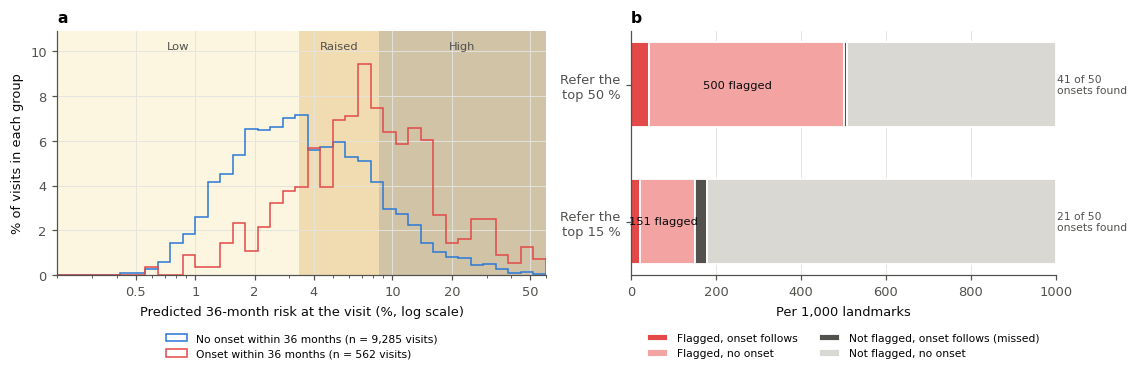

**What this means.**

* **The two groups overlap, but are shifted.** The upper two bands hold 50 %
  of all landmarks but 83 % of the visits followed by an onset. No
  threshold separates the groups cleanly, which is expected for an uncommon outcome predicted two years ahead.
* **Flagging the top 50 %** (the Raised and High bands), 500 of every 1,000 landmarks would prompt a conversation
  about work. These flagged visits contain 41 of the
  50 visits followed by an onset
  (sensitivity 83 %). About 12 visits are flagged
  for each one that precedes an onset. Among visits not flagged, 98.3 % are not followed by an onset.
* **The cut-off is a choice about workload.** Flagging the top 50 % finds 83 % of
  future onsets but flags 500 of 1,000 visits; the High band (top 15 %) flags only
  151 but finds 43 %. Because a conversation about
  work is cheap, the broader cut-offs are reasonable; the capacity table (Section 6.1) gives the numbers per year.
  These shares are fixed in the development cohort, so they do not depend on the recorded level of risk.

In [95]:
"""Risk distribution by outcome, and natural frequencies at three thresholds."""
TIER_COLORS = ["#f7e3a6", "#d99a1e", "#7d5300"]
TIER_NAMES = [t[2] for t in RISK_TIERS]
TIER_LINE_COLORS = ["#e6c34f", "#b07400", "#4f3300"]                # darker steps of the same hue, for lines
TIER_OF = lambda p: np.digitize(p, [t[1] for t in RISK_TIERS[:-1]])
THRESHOLDS_SHOW = list(TIER_CUTS)                         # the band boundaries
THRESHOLD_NAMES = [f"Top {100 - 100 * q:.0f} %" for q in REL_TIER_SHARES]


def _tier_bands(ax, orient="x", alpha=0.35, label=True):
    lims = [max(RISK_TIERS[0][0], 1e-3), *[t[1] for t in RISK_TIERS[:-1]], 1.0]
    for k in range(len(RISK_TIERS)):
        lo, hi = 100 * lims[k], 100 * lims[k + 1]
        (ax.axvspan if orient == "x" else ax.axhspan)(lo, hi, color=TIER_COLORS[k], alpha=alpha, lw=0, zorder=0)


fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.7), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
_bins_p = np.logspace(np.log10(0.2), np.log10(60), 40)
_known = ~np.isnan(Y24)
for yv, col, nm in [(0, KEPT_C, "No onset within 36 months"), (1, LEFT_C, "Onset within 36 months")]:
    k = _known & (Y24 == yv)
    ax.hist(100 * P_MAIN[k], bins=_bins_p, density=False, weights=np.full(k.sum(), 100 / k.sum()),
            histtype="step", lw=2, color=col, label=f"{nm} (n = {k.sum():,} visits)")
_tier_bands(ax)
ax.set_xscale("log"); ax.set_xlim(0.2, 60)
ax.set_xticks([0.5, 1, 2, 4, 10, 20, 50], ["0.5", "1", "2", "4", "10", "20", "50"])
ax.set_xlabel("Predicted 36-month risk at the visit (%, log scale)"); ax.set_ylabel("% of visits in each group")
_ymax = ax.get_ylim()[1]
for k, nm in enumerate(TIER_NAMES):
    lo = max(RISK_TIERS[k][0], 0.002) * 100; hi = min(RISK_TIERS[k][1], 0.6) * 100
    ax.text(np.sqrt(lo * hi), _ymax * 1.02, nm, ha="center", fontsize=7.5, color=INK_2)
ax.set_ylim(0, _ymax * 1.1)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1, fontsize=7)
ax.set_title("a  Predicted risk, by what happened next", loc="left", pad=14)

# natural frequencies per 1,000 visits (IPCW)
_N = W_IP.sum()
NATFREQ = []
for t, tname in zip(THRESHOLDS_SHOW, THRESHOLD_NAMES):
    a = P_MAIN >= t
    tp = np.sum(W_IP * Y_IP * a) / _N * 1000
    fn = np.sum(W_IP * Y_IP * ~a) / _N * 1000
    fp = np.sum(W_IP * (1 - Y_IP) * a) / _N * 1000
    tn = 1000 - tp - fn - fp
    NATFREQ.append({"Threshold": tname, "Flagged, onset follows": tp, "Flagged, no onset": fp,
                    "Not flagged, onset follows (missed)": fn, "Not flagged, no onset": tn,
                    "Flagged per 1,000": tp + fp, "PPV (%)": 100 * tp / (tp + fp), "NPV (%)": 100 * tn / (tn + fn),
                    "Sensitivity (%)": 100 * tp / (tp + fn), "Specificity (%)": 100 * tn / (tn + fp),
                    "Visits flagged per onset found": (tp + fp) / tp})
NATFREQ = pd.DataFrame(NATFREQ).set_index("Threshold")
display(NATFREQ.round(1))
ax = axes[1]
_parts = [("Flagged, onset follows", LEFT_C), ("Flagged, no onset", "#f2a3a2"),
          ("Not flagged, onset follows (missed)", INK_2), ("Not flagged, no onset", "#dad8d2")]
for i, (thr, row) in enumerate(NATFREQ.iterrows()):
    left = 0
    for c, col in _parts:
        ax.barh(i, row[c], left=left, color=col, edgecolor="white", linewidth=1.2, height=0.62,
                label=c if i == 0 else None)
        left += row[c]
    _wide = row["Flagged per 1,000"] > 150
    ax.text(row["Flagged per 1,000"] / 2 if _wide else left - row["Not flagged, no onset"] + 8, i,
            f"{row['Flagged per 1,000']:.0f} flagged", ha="center" if _wide else "left", va="center", fontsize=7.5,
            color=INK)
    ax.text(1003, i, f"{row['Flagged, onset follows']:.0f} of {row['Flagged, onset follows'] + row['Not flagged, onset follows (missed)']:.0f}\nonsets found",
            va="center", fontsize=7, color=INK_2)
ax.set_yticks(range(len(NATFREQ)), [f"Refer the\n{t.lower()}" for t in NATFREQ.index]); ax.invert_yaxis()
ax.set_xlim(0, 1000); ax.set_xlabel("Per 1,000 landmarks"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=7)
ax.set_title("b  What each tier boundary means", loc="left", pad=14)
plt.tight_layout(); save_fig("risk01_distribution_thresholds")
_n4 = NATFREQ.loc[THRESHOLD_NAMES[0]]
say(f"""
**What this means.**

* **The two groups overlap, but are shifted.** The upper two bands hold {TIERS.iloc[-2:]['Landmarks (%)'].sum():.0f} %
  of all landmarks but {TIERS.iloc[-2:]['Share of onsets (%)'].sum():.0f} % of the visits followed by an onset. No
  threshold separates the groups cleanly, which is expected for an uncommon outcome predicted two years ahead.
* **Flagging the {THRESHOLD_NAMES[0].lower()}** (the Raised and High bands), {_n4['Flagged per 1,000']:.0f} of every 1,000 landmarks would prompt a conversation
  about work. These flagged visits contain {_n4['Flagged, onset follows']:.0f} of the
  {_n4['Flagged, onset follows'] + _n4['Not flagged, onset follows (missed)']:.0f} visits followed by an onset
  (sensitivity {_n4['Sensitivity (%)']:.0f} %). About {_n4['Visits flagged per onset found']:.0f} visits are flagged
  for each one that precedes an onset. Among visits not flagged, {_n4['NPV (%)']:.1f} % are not followed by an onset.
* **The cut-off is a choice about workload.** Flagging the {THRESHOLD_NAMES[0].lower()} finds {NATFREQ.iloc[0]['Sensitivity (%)']:.0f} % of
  future onsets but flags {NATFREQ.iloc[0]['Flagged per 1,000']:.0f} of 1,000 visits; the High band ({THRESHOLD_NAMES[-1].lower()}) flags only
  {NATFREQ.iloc[-1]['Flagged per 1,000']:.0f} but finds {NATFREQ.iloc[-1]['Sensitivity (%)']:.0f} %. Because a conversation about
  work is cheap, the broader cut-offs are reasonable; the capacity table (Section 6.1) gives the numbers per year.
  These shares are fixed in the development cohort, so they do not depend on the recorded level of risk.
""")

## 6.3 The patient-level alarm

> **The question.** If the clinic acted on the alarm of Section 2.5, how many of the patients who go on to leave work
> would it catch, how early, and how many patients who keep working would it flag along the way?

Everything here uses the cross-validated HazReg risks and the time-matched comparison of Section 3.0.1: each patient
who left work is set against the patients still working at that moment, over the same 36 calendar months. Panel a
compares the alarm rule with simpler ones. Panel b turns the main rule into **natural frequencies per 100
patients**. Panel c shows how long before the onset the alarm was raised.

,Sensitivity,Specificity,Balanced accuracy,Visits flagged (%),Patients ever flagged (%),Alarm episodes per 100 person-years,Episode PPV (%),"Lead time, median (IQR), months"
Raised or High at the latest score,0.91 (0.86 to 0.96),0.34 (0.31 to 0.38),0.63 (0.60 to 0.65),50,77,17.2,7.6 (6.0 to 9.3),28 (11-55)
High at the latest score,0.64 (0.57 to 0.72),0.75 (0.72 to 0.78),0.70 (0.66 to 0.74),15,42,8.8,14.0 (10.8 to 17.7),15 (6-30)
High once or Raised twice in a row,0.85 (0.78 to 0.90),0.43 (0.39 to 0.47),0.64 (0.61 to 0.67),43,71,13.9,8.5 (6.7 to 10.7),28 (10-56)
"Raised or High, kept up until Low twice",0.91 (0.86 to 0.96),0.32 (0.29 to 0.36),0.62 (0.59 to 0.64),55,77,15.0,8.3 (6.5 to 10.1),29 (11-57)
"High once or Raised twice, kept up until Low twice",0.85 (0.79 to 0.91),0.41 (0.37 to 0.45),0.63 (0.60 to 0.66),48,71,12.7,9.0 (7.0 to 11.2),29 (11-57)


Onsets from 2012 (39): patient C 0.778 (0.698 to 0.850), sensitivity 0.62 (0.47 to 0.77), specificity 0.83 (0.80 to 0.86); 6.1 new alarms per 100 person-years, episode PPV 12.4 (6.8 to 19.4) %.


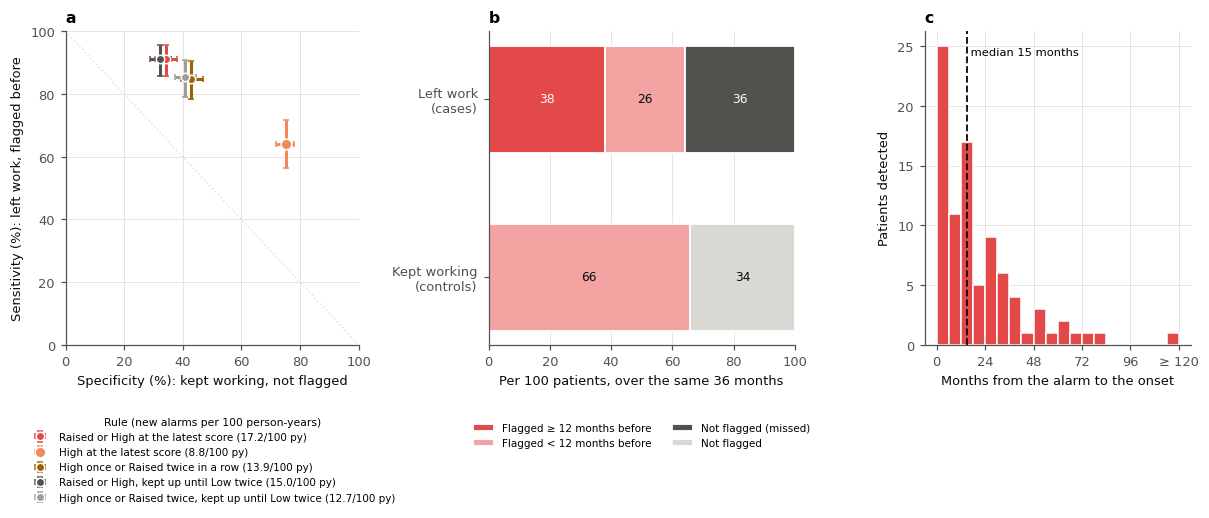

**What this means.**

* **The main rule flagged 91 % of patients before they left work** (95 % CI
  86-96 %), and left
  34 % of patients who kept working unflagged over the same 36 months. Of 100 patients
  who went on to leave work, about 38 were flagged at least a year ahead, 26 in the final year and
  36 were missed. The median warning was 15 months, enough time for a referral to act.
* **Workload and yield.** The clinic would see 17.2 new alarms per 100 working patient-years, and
  77 % of patients would be flagged at some point. 8 %
  of alarms were followed by an onset within 36 months, 1.5 times the
  average risk at a landmark (5.0 %).
* **Against other rules.** Asking for two Raised scores in a row (or one High): sensitivity
  85 %, specificity 43 %, 13.9 flags per 100
  person-years. Keeping the flag up until two Low scores: 91 %,
  32 %, 15.0.
  Changing the threshold moves sensitivity and specificity in opposite directions (panel a).
* **In recent years** (onsets from 2012): patient C 0.78, sensitivity
  62 %, specificity 83 %, episode PPV
  12 %.

Because risk is mostly a stable trait, a flag usually means *this is a patient to keep asking about work*, rather than
*this patient is about to leave*. Section 6.6 shows how the alarm behaves as an onset approaches.

In [96]:
"""The patient-level alarm: rule comparison, natural frequencies per 100 patients, lead time, recent era."""
ALARM_RES = {}
for nm, rule in ALARM_VARIANTS.items():
    ALARM_RES[nm] = pt_summary(PT_EVAL, P_MAIN, alarm_flags(P_MAIN, rule))[0]
ALARM_TABLE = pd.DataFrame({nm: {"Sensitivity": fmt(r["Sensitivity"], 2), "Specificity": fmt(r["Specificity"], 2),
                                 "Balanced accuracy": fmt(r["Balanced accuracy"], 2),
                                 "Visits flagged (%)": f"{r['Visits flagged (%)']:.0f}",
                                 "Patients ever flagged (%)": f"{r['Patients ever flagged (%)']:.0f}",
                                 "Alarm episodes per 100 person-years": f"{r['Alarm episodes per 100 person-years']:.1f}",
                                 "Episode PPV (%)": fmt(r["Episode PPV (%)"], 1),
                                 "Lead time, median (IQR), months": f"{r['Lead time, median (months)']:.0f} "
                                                                   f"({r['Lead time, IQR'][0]:.0f}-{r['Lead time, IQR'][1]:.0f})"}
                            for nm, r in ALARM_RES.items()}).T
display(ALARM_TABLE)
save_table(ALARM_TABLE, "alarm_rules")

# the recent era: onsets from 2012, the same rule
PT_EVAL_RECENT = build_pt_eval(onset_from=_day(2012))
ALARM_RECENT = pt_summary(PT_EVAL_RECENT, P_MAIN, FLAGS["HazReg"], burden=False)[0]
ALARM_RECENT_BURDEN = alarm_burden(FLAGS["HazReg"], sel=LAND_YEAR >= 2012)
print(f"Onsets from 2012 ({PT_EVAL_RECENT['n_onsets']}): patient C {fmt(ALARM_RECENT['C'])}, sensitivity "
      f"{fmt(ALARM_RECENT['Sensitivity'], 2)}, specificity {fmt(ALARM_RECENT['Specificity'], 2)}; "
      f"{ALARM_RECENT_BURDEN['Alarm episodes per 100 person-years']:.1f} new alarms per 100 person-years, episode PPV "
      f"{fmt(ALARM_RECENT_BURDEN['Episode PPV (%)'], 1)} %.")

LEAD = lead_times(PT_EVAL, FLAGS["HazReg"])
_main = ALARM_RES[list(ALARM_VARIANTS)[0]]
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.7), gridspec_kw={"width_ratios": [1.1, 1.15, 1], "wspace": 0.45})
ax = axes[0]
_vcol = [LEFT_C, "#f08a5d", "#9c6200", INK_2, "#9e9c95"]
for (nm, r), col in zip(ALARM_RES.items(), _vcol):
    se, sp = r["Sensitivity"], r["Specificity"]
    ax.errorbar(100 * sp[0], 100 * se[0], xerr=[[100 * (sp[0] - sp[1])], [100 * (sp[2] - sp[0])]],
                yerr=[[100 * (se[0] - se[1])], [100 * (se[2] - se[0])]], fmt="o", color=col, ms=7 if nm == RULE_NAME else 5.5,
                capsize=2, mec="white", mew=1.0, label=f"{nm} ({r['Alarm episodes per 100 person-years']:.1f}/100 py)")
ax.plot([0, 100], [100, 0], color=GRID_C, lw=1, ls=":")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("Specificity (%): kept working, not flagged"); ax.set_ylabel("Sensitivity (%): left work, flagged before")
ax.legend(fontsize=6.8, loc="upper center", bbox_to_anchor=(0.5, -0.2), title="Rule (new alarms per 100 person-years)",
          title_fontsize=7)
ax.set_title("a  Alarm rules compared", loc="left")

ax = axes[1]
_n_on = PT_EVAL["n_onsets"]
_early = 100 * np.sum(LEAD >= 12) / _n_on
_late = 100 * np.sum(LEAD < 12) / _n_on
_miss = 100 - _early - _late
_fp = 100 * (1 - _main["Specificity"][0])
_bars = [("Left work\n(cases)", [(_early, LEFT_C, "Flagged ≥ 12 months before"), (_late, "#f2a3a2", "Flagged < 12 months before"),
                                 (_miss, INK_2, "Not flagged (missed)")]),
         ("Kept working\n(controls)", [(_fp, "#f2a3a2", None), (100 - _fp, "#dad8d2", "Not flagged")])]
for i, (lab, parts) in enumerate(_bars):
    left = 0
    for v, col, nm in parts:
        ax.barh(i, v, left=left, color=col, edgecolor="white", linewidth=1.2, height=0.6, label=nm)
        if v >= 7:
            ax.text(left + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if col in (LEFT_C, INK_2) else INK)
        left += v
ax.set_yticks([0, 1], [b[0] for b in _bars]); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Per 100 patients, over the same 36 months"); ax.grid(axis="y", visible=False)
_h, _l = ax.get_legend_handles_labels()
ax.legend([h for h, l in zip(_h, _l) if l], [l for l in _l if l], fontsize=6.8, loc="upper center",
          bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.set_title("b  What the main rule means per 100 patients", loc="left")

ax = axes[2]
ax.hist(np.minimum(LEAD, 119), bins=np.arange(0, 126, 6), color=LEFT_C, edgecolor="white")
ax.set_xticks([0, 24, 48, 72, 96, 120], ["0", "24", "48", "72", "96", "≥ 120"])
ax.axvline(np.median(LEAD), color=INK, lw=1.2, ls="--")
ax.text(np.median(LEAD), ax.get_ylim()[1] * 0.95, f" median {np.median(LEAD):.0f} months", fontsize=7.5, va="top")
ax.set_xlabel("Months from the alarm to the onset"); ax.set_ylabel("Patients detected")
ax.set_title("c  How early the alarm came", loc="left")
save_fig("alarm01_patient_alarm")
_any = ALARM_RES["High once or Raised twice in a row"]; _nostay = ALARM_RES["Raised or High, kept up until Low twice"]
_epi = lambda r: r["Alarm episodes per 100 person-years"]
_avg_risk = 100 * np.sum(W_IP * Y_IP) / N_LAND
_rec_ppv = ALARM_RECENT_BURDEN["Episode PPV (%)"][0]
say(f"""
**What this means.**

* **The main rule flagged {100 * _main['Sensitivity'][0]:.0f} % of patients before they left work** (95 % CI
  {100 * _main['Sensitivity'][1]:.0f}-{100 * _main['Sensitivity'][2]:.0f} %), and left
  {100 * _main['Specificity'][0]:.0f} % of patients who kept working unflagged over the same 36 months. Of 100 patients
  who went on to leave work, about {_early:.0f} were flagged at least a year ahead, {_late:.0f} in the final year and
  {_miss:.0f} were missed. The median warning was {np.median(LEAD):.0f} months{", enough time for a referral to act" if np.median(LEAD) >= 6 else ", short for a referral to act on"}.
* **Workload and yield.** The clinic would see {_epi(_main):.1f} new alarms per 100 working patient-years, and
  {_main['Patients ever flagged (%)']:.0f} % of patients would be flagged at some point. {_main['Episode PPV (%)'][0]:.0f} %
  of alarms were followed by an onset within 36 months, {_main['Episode PPV (%)'][0] / max(_avg_risk, 1e-9):.1f} times the
  average risk at a landmark ({_avg_risk:.1f} %).
* **Against other rules.** Asking for two Raised scores in a row (or one High): sensitivity
  {100 * _any['Sensitivity'][0]:.0f} %, specificity {100 * _any['Specificity'][0]:.0f} %, {_epi(_any):.1f} flags per 100
  person-years. Keeping the flag up until two Low scores: {100 * _nostay['Sensitivity'][0]:.0f} %,
  {100 * _nostay['Specificity'][0]:.0f} %, {_epi(_nostay):.1f}.
  Changing the threshold moves sensitivity and specificity in opposite directions (panel a).
* **In recent years** (onsets from 2012): patient C {ALARM_RECENT['C'][0]:.2f}, sensitivity
  {100 * ALARM_RECENT['Sensitivity'][0]:.0f} %, specificity {100 * ALARM_RECENT['Specificity'][0]:.0f} %, episode PPV
  {_rec_ppv:.0f} %{" (lower than over all years, matching the lower recorded risk of Part IV)" if _rec_ppv < _main['Episode PPV (%)'][0] else ""}.

Because risk is mostly a stable trait, a flag usually means *this is a patient to keep asking about work*, rather than
*this patient is about to leave*. Section 6.6 shows how the alarm behaves as an onset approaches.
""")

## 6.4 Where patients end up, by their risk

> **The question.** Do patients who are flagged go on to leave work more often than patients who are not?

Here the unit is the **patient**. Panel a groups patients by whether the alarm (Section 2.5) was ever raised, and
whether their risk ever reached each threshold, while they were working (before any onset), and shows how their
follow-up ended. Panel b groups them by their risk
tier at **entry**, their first landmark, and shows the same. Panel b is the cleaner view: it uses only the first
score, so a patient followed for longer has no extra chances to be flagged.

Ending,Work disability,Other exit from work,Still working and attending,Left the clinic while working,"Reached 65, died or other censoring",Patients
Alarm ever raised,25.4,14.8,35.2,14.3,10.3,398
Alarm never raised,7.3,13.4,54.5,20.5,4.3,560
Ever in the top 50 %,18.1,14.6,43.1,16.2,8.0,740
Never in the top 50 %,3.7,11.9,57.8,23.9,2.8,218
Ever in the top 15 %,25.4,14.8,35.2,14.3,10.3,398
Never in the top 15 %,7.3,13.4,54.5,20.5,4.3,560
Low at entry,6.1,13.0,56.4,19.7,4.9,346
Raised at entry,16.0,14.2,44.2,18.5,7.1,394
High at entry,26.6,15.1,34.9,14.2,9.2,218


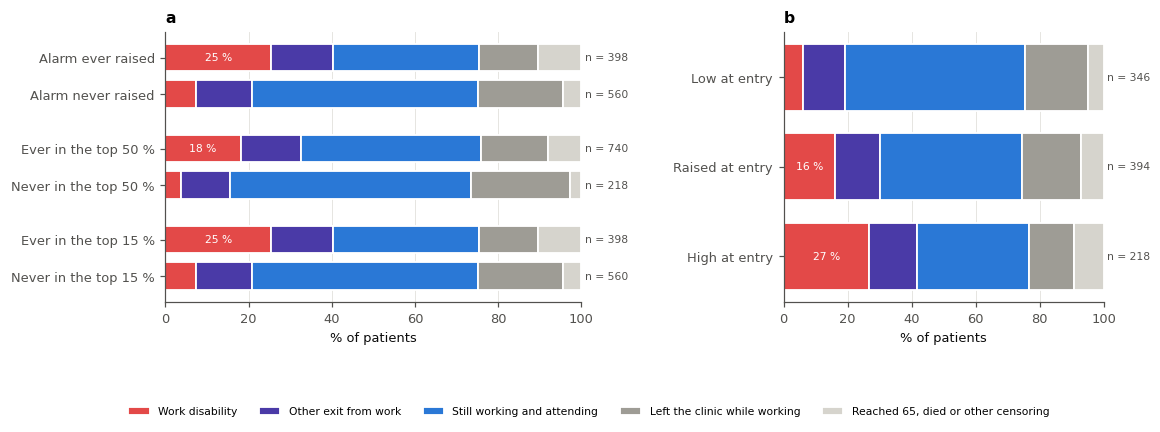

**What this means.** Among patients for whom the alarm was raised while they were working, 25 % later
left work for health reasons, against 7 % of patients never flagged
(398 and 560
patients). Among patients whose risk reached the top 50 % at some landmark, 18 % later left work
for health reasons, against 4 % of patients who never reached it. The tier at entry alone already
separates patients: 27 % of patients who entered in the High tier had a work-disability onset during
follow-up, against 6 % of those who entered in the lowest.

In [97]:
"""Final state of each patient by threshold reached and by risk tier at entry."""
_pre = np.ones(N_LAND, bool)
for p in FIRST_ONSET_DATE.index:
    r = PT_ROWS[p]
    _pre[r] = land["visit_date"].values[r] < np.datetime64(FIRST_ONSET_DATE[p])
MAX_RISK_PT = pd.Series(np.where(_pre, P_MAIN, np.nan)).groupby(PID_ALL).max().reindex(ALL_PIDS)
FIRST_ROW = np.array([PT_ROWS[p][0] for p in ALL_PIDS])
ENTRY_TIER = pd.Series(TIER_OF(P_MAIN[FIRST_ROW]), index=ALL_PIDS)

EVER_ALARM_PT = pd.Series(np.where(_pre, FLAGS["HazReg"], False)).groupby(PID_ALL).any().reindex(ALL_PIDS)
_rows = []
for flag, nm in [(True, "Alarm ever raised"), (False, "Alarm never raised")]:
    k = EVER_ALARM_PT == flag
    _rows.append((nm, FINAL_STATE[k].value_counts(normalize=True).reindex(FINAL_ORDER).fillna(0) * 100, int(k.sum())))
for t, tname in zip(THRESHOLDS_SHOW, THRESHOLD_NAMES):
    for flag, nm in [(True, f"Ever in the {tname.lower()}"), (False, f"Never in the {tname.lower()}")]:
        k = (MAX_RISK_PT >= t) == flag
        _rows.append((nm, FINAL_STATE[k].value_counts(normalize=True).reindex(FINAL_ORDER).fillna(0) * 100, int(k.sum())))
_rows_e = []
for i, nm in enumerate(TIER_NAMES):
    k = ENTRY_TIER == i
    _rows_e.append((f"{nm} at entry", FINAL_STATE[k].value_counts(normalize=True).reindex(FINAL_ORDER).fillna(0) * 100,
                    int(k.sum())))
FINAL_BY_RISK = pd.DataFrame({nm: v for nm, v, _ in _rows + _rows_e}).T.round(1)
FINAL_BY_RISK["Patients"] = [n for _, _, n in _rows + _rows_e]
display(FINAL_BY_RISK)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.9), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.55})
for ax, rows, ttl in [(axes[0], _rows, "a  Risk ever reached while working"),
                      (axes[1], _rows_e, "b  Risk tier at entry (first landmark)")]:
    ypos = []
    y = 0
    for j, (nm, v, n) in enumerate(rows):
        if ax is axes[0] and j and j % 2 == 0:
            y += 0.5                                   # a gap between threshold pairs
        left = 0
        for c in FINAL_ORDER:
            ax.barh(y, v[c], left=left, color=FINAL_COLORS[c], edgecolor="white", linewidth=1.2, height=0.75,
                    label=c if (j == 0 and ax is axes[0]) else None)
            left += v[c]
        if v.iloc[0] >= 9:
            ax.text(v.iloc[0] / 2, y, f"{v.iloc[0]:.0f} %", ha="center", va="center", fontsize=7, color="white")
        ax.text(101, y, f"n = {n}", va="center", fontsize=7, color=INK_2)
        ypos.append(y); y += 1
    ax.set_yticks(ypos, [nm for nm, _, _ in rows]); ax.invert_yaxis()
    ax.set_xlim(0, 100); ax.set_xlabel("% of patients"); ax.grid(axis="y", visible=False)
    ax.set_title(ttl, loc="left")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=5, fontsize=7)
fig.subplots_adjust(bottom=0.25, left=0.13, right=0.95)
save_fig("risk02_final_state_by_risk")
_lo, _hi = _rows_e[0][1].iloc[0], _rows_e[-1][1].iloc[0]
_f4 = FINAL_BY_RISK.loc[[f"Ever in the {THRESHOLD_NAMES[0].lower()}", f"Never in the {THRESHOLD_NAMES[0].lower()}"], "Work disability"]
_fa = FINAL_BY_RISK.loc[["Alarm ever raised", "Alarm never raised"], "Work disability"]
say(f"""
**What this means.** Among patients for whom the alarm was raised while they were working, {_fa.iloc[0]:.0f} % later
left work for health reasons, against {_fa.iloc[1]:.0f} % of patients never flagged
({int(FINAL_BY_RISK.loc['Alarm ever raised', 'Patients'])} and {int(FINAL_BY_RISK.loc['Alarm never raised', 'Patients'])}
patients). Among patients whose risk reached the {THRESHOLD_NAMES[0].lower()} at some landmark, {_f4.iloc[0]:.0f} % later left work
for health reasons, against {_f4.iloc[1]:.0f} % of patients who never reached it. The tier at entry alone already
separates patients: {_hi:.0f} % of patients who entered in the High tier had a work-disability onset during
follow-up, against {_lo:.0f} % of those who entered in the lowest. """)

### 6.4.1 Cumulative incidence by risk tier at entry

The same comparison over time: the cumulative incidence of work disability from entry, by the tier of the first
landmark, with retirement and other exits as competing events (Aalen-Johansen estimator). The table under the
curves gives the number of patients still at risk.

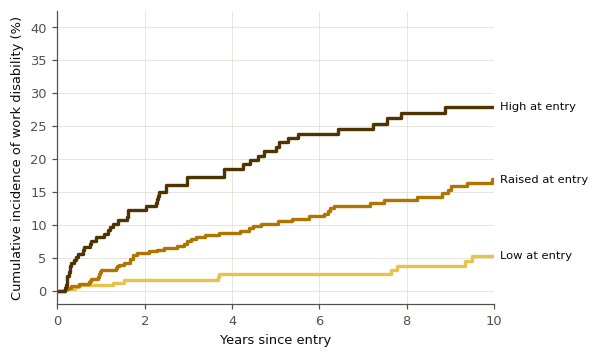

,2 y,4 y,6 y,8 y,10 y
Low,1.6,2.5,2.5,3.8,5.4
Raised,5.7,8.8,11.3,13.8,16.9
High,12.3,18.5,23.9,27.0,28.0


**What this means.** The risk tier at a patient's first landmark predicts their course for years. After 10
years, 28 % of patients who entered in the highest tier had left work for health reasons,
against 5 % of those who entered in the lowest. The curves separate early and keep
separating. A single score at entry already carries much of the information, which fits risk being largely a stable
characteristic of the patient.

In [98]:
"""Aalen-Johansen cumulative incidence of onset from entry, by entry tier."""


_t1 = T_ALL[FIRST_ROW] / 365.25
_c1 = C_ALL[FIRST_ROW]
CIF_YEARS = [0, 2, 4, 6, 8, 10]
fig = plt.figure(figsize=(6.4, 4.6))
ax = fig.add_axes([0.13, 0.36, 0.62, 0.58])
CIF_TABLE = {}
for i, nm in enumerate(TIER_NAMES):
    k = ENTRY_TIER.values == i
    if k.sum() < 10:
        continue
    tt, ff = aalen_johansen(_t1[k], _c1[k])
    ax.step(tt, 100 * ff, where="post", color=TIER_LINE_COLORS[i], lw=2.2)
    f_at = lambda y: 100 * ff[np.searchsorted(tt, y, side="right") - 1]
    ax.text(10.15, f_at(10), f"{nm} at entry", va="center", fontsize=7.5, color=INK)
    CIF_TABLE[nm] = {f"{y} y": f_at(y) for y in CIF_YEARS[1:]}
    for j, y in enumerate(CIF_YEARS):
        fig.text(0.13 + 0.62 * y / 10, 0.22 - 0.035 * i, f"{int((_t1[k] >= y).sum())}", ha="center", fontsize=7,
                 color=INK_2)
    fig.text(0.02, 0.22 - 0.035 * i, nm, fontsize=7, color=INK_2)
fig.text(0.02, 0.26, "Patients at risk", fontsize=7.5, fontweight="bold", color=INK)
ax.set_xlim(0, 10); ax.set_xticks(CIF_YEARS)
ax.set_xlabel("Years since entry"); ax.set_ylabel("Cumulative incidence of work disability (%)")
ax.set_title("Work disability by risk tier at entry", loc="left")
save_fig("risk03_cumulative_incidence_by_entry_tier")
CIF_TABLE = pd.DataFrame(CIF_TABLE).T.round(1)
display(CIF_TABLE)
say(f"""
**What this means.** The risk tier at a patient's first landmark predicts their course for years. After 10
years, {CIF_TABLE.iloc[-1]['10 y']:.0f} % of patients who entered in the highest tier had left work for health reasons,
against {CIF_TABLE.iloc[0]['10 y']:.0f} % of those who entered in the lowest. The curves separate early and keep
separating. A single score at entry already carries much of the information, which fits risk being largely a stable
characteristic of the patient.
""")

## 6.5 Moving between tiers

> **The question.** Once a patient is in a tier, do they stay there?

Panel a: from one landmark to the next, the share of visits that stay in their tier or move (rows sum to
100 %). Panel b follows every patient from entry, every two years: their tier at that time (the last landmark
before it), or the way their follow-up had already ended.

Tier at the next landmark,Low,Raised,High
Tier at a landmark,,,
Low,91.0,9.0,0.0
Raised,16.0,76.0,9.0
High,1.0,23.0,76.0


,Year 0,Year 2,Year 4,Year 6
High,218,125,82,58
Raised,394,238,158,126
Low,346,320,278,227
Work disability,0,51,74,89
Other exit from work,0,76,111,137
No longer followed,0,148,255,321


,Episodes,Median duration (months),Share (%)
Follow-up ended,79,10.0,13.0
Other exit from work,49,13.0,8.0
Risk fell: alarm lowered,420,12.0,67.0
Work-disability onset,76,14.0,12.0


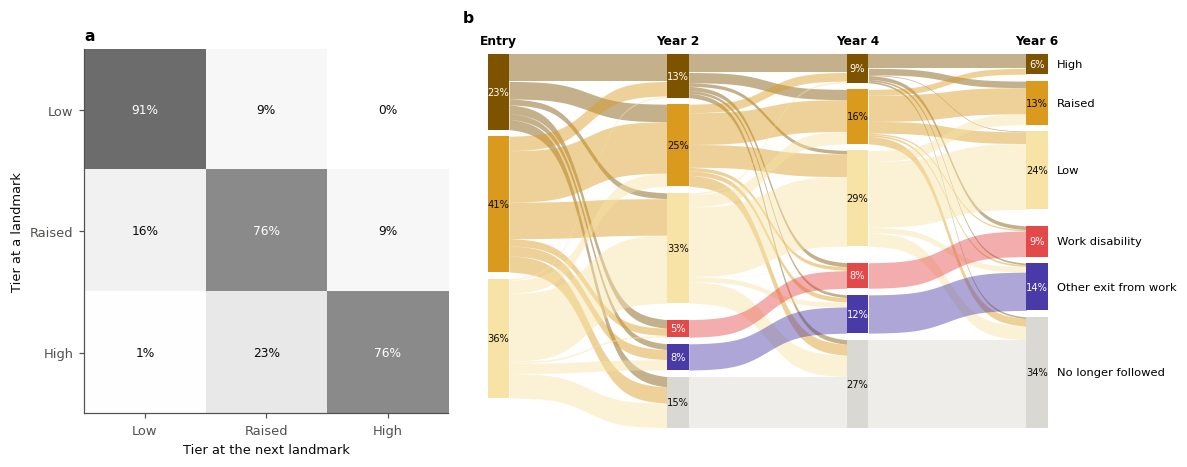

**What this means.**

* **Tiers are stable from landmark to landmark.** The tier stays the same at 83 % of consecutive landmarks
  and jumps by more than one tier at only 0.2 %. Moves happen mostly between neighbouring tiers.
* **Over years, patients drift, and the high tiers feed work disability.** Of patients who entered in the highest tier,
  20 % had left work for health reasons within six years, against
  2 % of those who entered in the lowest tier.

* **How long alarms last.** Of 624 alarm episodes, the median lasted
  12 months (until the risk fell, or follow-up ended). 67 %
  ended because the risk fell back to the Low tier at two visits; 12 % ended
  in a work-disability onset.

In practice, a patient's tier is a stable flag that is worth re-checking at each visit, not a number that swings from
one visit to the next.

In [99]:
"""Tier transitions between consecutive landmarks, and the flow of patients between tiers over six years."""
from matplotlib.patches import Rectangle

_tz = TIER_OF(P_MAIN)
_pair = _cont                                          # the next landmark belongs to the same at-risk episode
_a, _b = _tz[:-1][_pair[:-1]], _tz[1:][_pair[:-1]]
TIER_MOVE = pd.crosstab(pd.Categorical(np.array(TIER_NAMES)[_a], TIER_NAMES),
                        pd.Categorical(np.array(TIER_NAMES)[_b], TIER_NAMES), normalize="index",
                        rownames=["Tier at a landmark"], colnames=["Tier at the next landmark"])
display((100 * TIER_MOVE).round(0))

FLOW_YEARS = [0, 2, 4, 6]
ABSORB = {1: "Work disability", 2: "Other exit from work", 0: "No longer followed"}
ABSORB_COLORS = {"Work disability": LEFT_C, "Other exit from work": OTHER_C, "No longer followed": "#dad8d2"}
_entry_ns = ENTRY_DATE.reindex(ALL_PIDS).values
_states = {}
for y in FLOW_YEARS:
    s = []
    for i, p in enumerate(ALL_PIDS):
        if _t1[i] < y:
            s.append(ABSORB[_c1[i]])
        else:
            r = PT_ROWS[p]
            r = r[land["visit_date"].values[r] <= _entry_ns[i] + np.timedelta64(int(y * 365.25), "D")]
            s.append(TIER_NAMES[_tz[r[-1]]])
    _states[y] = np.array(s)
NODE_ORDER = TIER_NAMES[::-1] + list(ABSORB.values())
NODE_COLORS = dict(zip(TIER_NAMES, TIER_COLORS)) | ABSORB_COLORS
FLOW_TABLE = pd.DataFrame({f"Year {y}": pd.Series(_states[y]).value_counts().reindex(NODE_ORDER).fillna(0).astype(int)
                           for y in FLOW_YEARS})
display(FLOW_TABLE)

# ---- alarm episodes: how long an alarm stays up, and how it ends
_fh = FLAGS["HazReg"]
_st = alarm_starts(_fh)
_run = np.cumsum(_st) * _fh                              # episode number at each flagged landmark (0 = not flagged)
_ep_rows = pd.Series(np.flatnonzero(_fh)).groupby(_run[_fh]).agg(["first", "last"])
_nxt_ok = np.r_[PREV_SAME[1:], False]                   # the next landmark continues the chain
_after = _ep_rows["last"].values
_ends_by = np.where(_nxt_ok[_after], "Risk fell: alarm lowered",
                    np.where(C_ALL[_after] == 1, "Work-disability onset",
                             np.where(C_ALL[_after] == 2, "Other exit from work", "Follow-up ended")))
_dur = np.where(_nxt_ok[_after], (LAND_T[np.minimum(_after + 1, N_LAND - 1)] - LAND_T[_ep_rows["first"].values]) / MONTH_DAYS,
                (LAND_T[_after] + np.minimum(T_ALL[_after], 1e9) - LAND_T[_ep_rows["first"].values]) / MONTH_DAYS)
ALARM_EPISODES = pd.DataFrame({"Episodes": pd.Series(_ends_by).value_counts(),
                               "Median duration (months)": pd.Series(_dur).groupby(_ends_by).median().round(0)})
ALARM_EPISODES["Share (%)"] = (100 * ALARM_EPISODES["Episodes"] / ALARM_EPISODES["Episodes"].sum()).round(0)
display(ALARM_EPISODES)


def alluvial(ax, states, years, order, colors, gap=0.02, width=0.12):
    n = len(next(iter(states.values())))
    pos = {}
    for j, y in enumerate(years):
        top = 1.0
        for nd in order:
            h = np.mean(states[y] == nd)
            extra = 0.03 if nd == list(ABSORB.values())[0] else 0
            top -= extra
            pos[(y, nd)] = (top - h, top)
            if h > 0:
                ax.add_patch(Rectangle((j - width / 2, top - h), width, h, color=colors[nd], lw=0, zorder=3))
                if h > 0.025:
                    ax.text(j, top - h / 2, f"{100 * h:.0f}%", ha="center", va="center", fontsize=6.5, zorder=4,
                            color="white" if nd in ("High", "Work disability", "Other exit from work") else INK)
            top -= h + gap
    xs = np.linspace(0, 1, 50)
    sig = 1 / (1 + np.exp(-(xs - 0.5) * 10))
    sig = (sig - sig[0]) / (sig[-1] - sig[0])
    for j in range(len(years) - 1):
        y0, y1 = years[j], years[j + 1]
        out_off = {nd: pos[(y0, nd)][1] for nd in order}
        in_off = {nd: pos[(y1, nd)][1] for nd in order}
        for a in order:
            for b in order:
                h = np.mean((states[y0] == a) & (states[y1] == b))
                if h <= 0:
                    continue
                t0, t1 = out_off[a], in_off[b]
                top = t0 + (t1 - t0) * sig
                ax.fill_between(j + width / 2 + xs * (1 - width), top - h, top, color=colors[a], alpha=0.45, lw=0,
                                zorder=2)
                out_off[a] -= h; in_off[b] -= h
    for j, y in enumerate(years):
        ax.text(j, 1.03, "Entry" if y == 0 else f"Year {y}", ha="center", fontsize=8, fontweight="bold")
    for nd in order:
        lo, hi = pos[(years[-1], nd)]
        if hi - lo > 0:
            ax.text(len(years) - 1 + width / 2 + 0.05, (lo + hi) / 2, nd, va="center", fontsize=7.5)
    ax.set_xlim(-0.2, len(years) - 0.4); ax.set_ylim(min(v[0] for v in pos.values()) - 0.01, 1.07)
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [0.8, 1.5]})
ax = axes[0]
_M = 100 * TIER_MOVE.values
ax.imshow(_M, cmap="Greys", vmin=0, vmax=140)
for i in range(len(TIER_NAMES)):
    for j in range(len(TIER_NAMES)):
        ax.text(j, i, f"{_M[i, j]:.0f}%", ha="center", va="center", fontsize=8,
                color="white" if _M[i, j] > 70 else INK)
ax.set_xticks(range(len(TIER_NAMES)), TIER_NAMES); ax.set_yticks(range(len(TIER_NAMES)), TIER_NAMES)
ax.set_xlabel("Tier at the next landmark"); ax.set_ylabel("Tier at a landmark"); ax.grid(False)
ax.set_title("a  From one visit to the next", loc="left")
alluvial(axes[1], _states, FLOW_YEARS, NODE_ORDER, NODE_COLORS)
axes[1].set_title(f"b  Every patient from entry (n = {len(ALL_PIDS):,})", loc="left")
plt.tight_layout(); save_fig("risk04_tier_transitions")
_stay = float(np.mean(_a == _b)); _jump = float(np.mean(np.abs(_a - _b) > 1))
_hi_from = _states[0] == TIER_NAMES[-1]
_lo_from = _states[0] == TIER_NAMES[0]
say(f"""
**What this means.**

* **Tiers are stable from landmark to landmark.** The tier stays the same at {100 * _stay:.0f} % of consecutive landmarks
  and jumps by more than one tier at only {100 * _jump:.1f} %. Moves happen mostly between neighbouring tiers.
* **Over years, patients drift, and the high tiers feed work disability.** Of patients who entered in the highest tier,
  {100 * np.mean(_states[6][_hi_from] == "Work disability"):.0f} % had left work for health reasons within six years, against
  {100 * np.mean(_states[6][_lo_from] == "Work disability"):.0f} % of those who entered in the lowest tier.

* **How long alarms last.** Of {int(ALARM_EPISODES['Episodes'].sum())} alarm episodes, the median lasted
  {np.median(_dur):.0f} months (until the risk fell, or follow-up ended). {ALARM_EPISODES['Share (%)'].get('Risk fell: alarm lowered', 0):.0f} %
  ended because the risk fell back to the Low tier at two visits; {ALARM_EPISODES['Share (%)'].get('Work-disability onset', 0):.0f} % ended
  in a work-disability onset.

In practice, a patient's tier is a stable flag that is worth re-checking at each visit, not a number that swings from
one visit to the next.
""")

## 6.6 How the risk changes as an onset approaches

> **The question.** Does a patient's predicted risk climb in the years before they leave work, or is it high all
> along?

Panel a aligns every patient who left work for health reasons at their onset and shows the predicted risk at their
landmarks in the eight years before it (median and interquartile range in 6-month bins; faint lines are
individual patients). Patients who never left work are aligned at their last landmark. Panel b shows, for the
patients with an onset, which tier their visits were in at each time before the onset, and panel c the share with
the alarm up.

The second row follows the main inputs over the same years, aligned the same way (mean of the patient means in each
6-month bin, with its 95 % CI; red: left work for health reasons, blue: kept working), two inputs per panel (solid and
dashed): **d** treatment (prednisone above 7.5 mg/day; any immunosuppressant), **e** disease activity and damage
(12-month adjusted mean SLEDAI-2K; SDI), **f** the SF-36 physical and mental component summaries (landmarks with a
form in the past 12 months only).

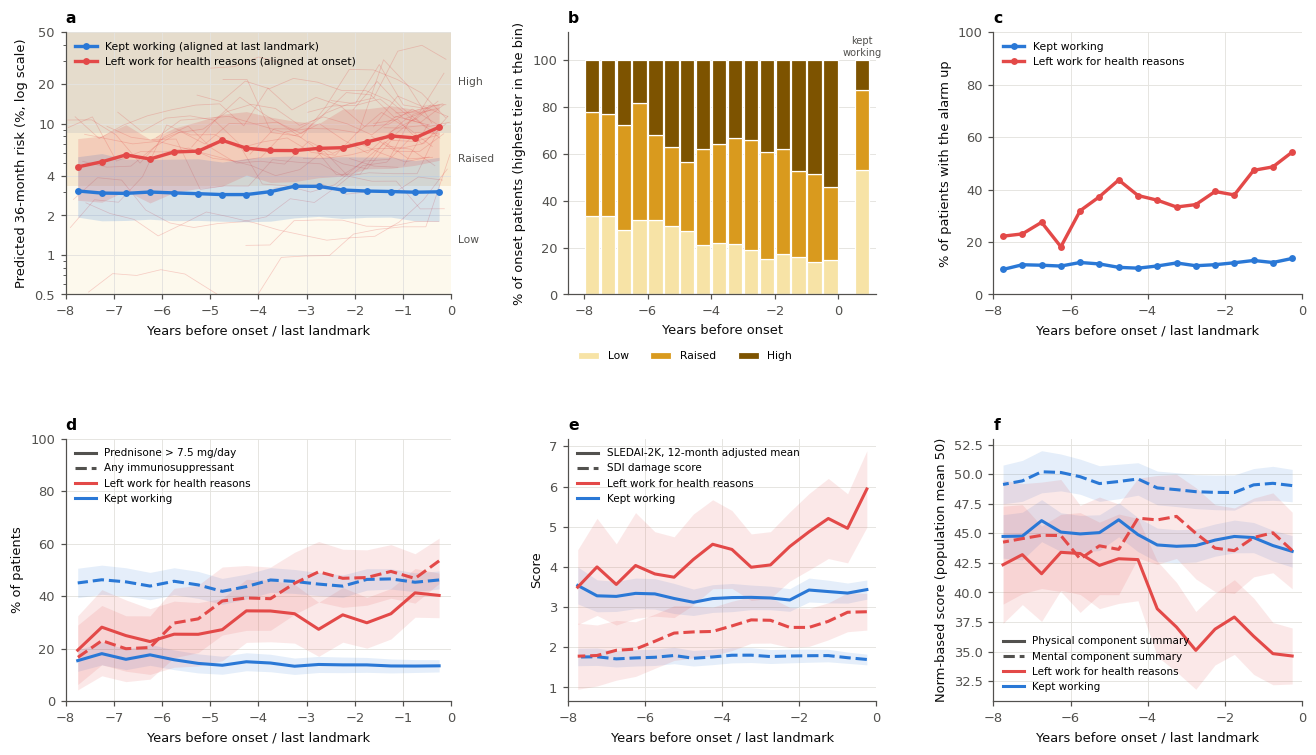

,"Left work, 4-6 y before","Left work, final year","Kept working, 4-6 y before","Kept working, final year"
Prednisone > 7.5 mg/day,28.2,40.8,14.7,13.4
Any immunosuppressant,34.7,50.1,43.9,45.8
"SLEDAI-2K, 12-month adjusted mean",4.1,5.4,3.2,3.4
SDI damage score,2.3,2.9,1.8,1.7
Physical component summary,42.8,34.7,45.3,43.7
Mental component summary,44.2,44.3,49.5,49.1


**What this means.**

* **Risk is raised long before the onset.** Four to six years before leaving work, the median predicted risk of
  patients who later did so was already 6.6 %, against 2.9 % in patients who kept working
  (2.3 times higher).
* **It rises further in the final years.** In the last year before the onset the median was 8.6 %
  (1.3 times its level four to six years earlier), while it stayed at 3.0 % in patients who
  kept working.
* **The share in the upper bands grows as the onset nears.** 73 % of onset patients had a visit in the Raised
  or High band four to six years before the onset, and 86 % in the final year. Among the visits of patients
  who kept working, 47 % were in these bands.

* **The alarm follows the same pattern.** 38 %
  of onset patients had the alarm up four to six years before the onset, and
  51 % in the
  final year; among patients who kept working, 11 % at any given time.

* **The inputs behind it (panels d-f).** Four to six years before the onset, patients who later left work were
  already on prednisone above 7.5 mg/day at 28 %
  of landmarks (kept working: 15 %), with an SDI of
  2.3 (1.8)
  and a PCS of 43
  (45). In the final year the SDI was
  2.9 and the PCS
  35 (kept working:
  1.7 and
  44).

The score therefore works as **stratification first** (it picks out who is at higher risk years ahead) with a
**modest early-warning component** on top (risk climbs as the onset nears). Both support asking high-tier patients
about work at every visit.

In [100]:
"""Onset-aligned predicted risk (median, IQR) and the tier mix before the onset."""
_ok2 = (MO_BEFORE > 0) & (MO_BEFORE <= TRAJ_MAX_MONTHS)
_dfa = pd.DataFrame({"pid": PID_ALL, "ev": _ever, "bin": _bin, "mo": MO_BEFORE, "p": 100 * P_MAIN, "tier": _tz})[_ok2]
fig, _axs = plt.subplots(2, 3, figsize=(14.5, 7.9), gridspec_kw={"width_ratios": [1.25, 1, 1], "wspace": 0.35,
                                                                  "hspace": 0.55})
axes = _axs[0]
ax = axes[0]
_tier_bands(ax, orient="y", alpha=0.2)
_rng = np.random.RandomState(SEED)
for p in _rng.choice(_dfa.loc[_dfa["ev"], "pid"].unique(), 40, replace=False):
    d = _dfa[_dfa["pid"] == p].sort_values("mo")
    ax.plot(-d["mo"] / 12, d["p"], color=LEFT_C, lw=0.5, alpha=0.25, zorder=1)
RISK_BEFORE = {}
for ev, col, nm in [(False, KEPT_C, "Kept working (aligned at last landmark)"),
                    (True, LEFT_C, "Left work for health reasons (aligned at onset)")]:
    g = _dfa[_dfa["ev"] == ev].groupby(["bin", "pid"])["p"].mean().groupby("bin")
    q = g.quantile([0.25, 0.5, 0.75]).unstack()
    n = g.size()
    q = q[n >= 10]
    xs = -(_bins[q.index.values - 1] + 3) / 12
    ax.fill_between(xs, q[0.25], q[0.75], color=col, alpha=0.18, lw=0, zorder=2)
    ax.plot(xs, q[0.5], "-o", ms=3.5, color=col, lw=2.2, zorder=3, label=nm)
    RISK_BEFORE[nm] = pd.Series(q[0.5].values, index=xs)
ax.set_yscale("log"); ax.set_ylim(0.5, 50)
ax.set_yticks([0.5, 1, 2, 4, 10, 20, 50], ["0.5", "1", "2", "4", "10", "20", "50"])
ax.set_xlabel("Years before onset / last landmark"); ax.set_ylabel("Predicted 36-month risk (%, log scale)")
ax.legend(loc="upper left", fontsize=7)
ax.set_title("a  Predicted risk in the years before the onset", loc="left")
for k, nm in enumerate(TIER_NAMES):
    lo = max(RISK_TIERS[k][0], 0.005) * 100; hi = min(RISK_TIERS[k][1], 0.5) * 100
    ax.text(0.15, np.sqrt(lo * hi), nm, va="center", fontsize=7, color=INK_2, clip_on=False)
ax.set_xlim(-TRAJ_MAX_MONTHS / 12, 0)

ax = axes[1]
_mix = (_dfa[_dfa["ev"]].groupby(["bin", "pid"])["tier"].max().reset_index()
        .pipe(lambda d: pd.crosstab(d["bin"], d["tier"], normalize="index")).reindex(columns=range(len(TIER_NAMES)), fill_value=0))
_mix = _mix[_dfa[_dfa["ev"]].groupby("bin")["pid"].nunique().reindex(_mix.index) >= 10]
_xb = -(_bins[_mix.index.values - 1] + 3) / 12
_ctrl = pd.Series(_tz[~_ever]).value_counts(normalize=True).reindex(range(len(TIER_NAMES))).fillna(0)
bottom = np.zeros(len(_mix))
for k in range(len(TIER_NAMES)):
    ax.bar(_xb, 100 * _mix[k].values, 0.45, bottom=bottom, color=TIER_COLORS[k], edgecolor="white", linewidth=0.8,
           label=TIER_NAMES[k])
    bottom += 100 * _mix[k].values
bottom = 0
for k in range(len(TIER_NAMES)):
    ax.bar(0.75, 100 * _ctrl[k], 0.45, bottom=bottom, color=TIER_COLORS[k], edgecolor="white", linewidth=0.8)
    bottom += 100 * _ctrl[k]
ax.text(0.75, 102, "kept\nworking", ha="center", fontsize=6.5, color=INK_2)
ax.set_xlim(-TRAJ_MAX_MONTHS / 12 - 0.5, 1.2); ax.set_ylim(0, 112)
ax.set_xlabel("Years before onset"); ax.set_ylabel("% of onset patients (highest tier in the bin)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.18), ncol=len(TIER_NAMES), fontsize=7, title=None)
ax.grid(axis="x", visible=False)
ax.set_title("b  Risk tier of patients who left work", loc="left")
ax = axes[2]
_dfa["flag"] = FLAGS["HazReg"][_ok2]
ALARM_BEFORE = {}
for ev, col, nm in [(False, KEPT_C, "Kept working"), (True, LEFT_C, "Left work for health reasons")]:
    g = _dfa[_dfa["ev"] == ev].groupby(["bin", "pid"])["flag"].max().groupby("bin")
    sh, n = g.mean(), g.size()
    sh = sh[n >= 10]
    xs = -(_bins[sh.index.values - 1] + 3) / 12
    ax.plot(xs, 100 * sh.values, "-o", ms=3.5, color=col, lw=2.2, label=nm)
    ALARM_BEFORE[nm] = pd.Series(100 * sh.values, index=xs)
ax.set_ylim(0, 100); ax.set_xlim(-TRAJ_MAX_MONTHS / 12, 0)
ax.set_xlabel("Years before onset / last landmark"); ax.set_ylabel("% of patients with the alarm up")
ax.legend(loc="upper left", fontsize=7)
ax.set_title("c  Patients with the alarm raised", loc="left")
# ---- second row: the main inputs before the onset (two per panel; red left work, blue kept working)
_INPUTS_BEFORE = [("d  Treatment", "% of patients", [("Prednisone > 7.5 mg/day", (LAND_X["STERAVER_0"].values > 7.5) * 100.0),
                                                     ("Any immunosuppressant", (LAND_X["TREAT_LADDER"].values >= 2) * 100.0)]),
                  ("e  Disease activity and damage", "Score", [("SLEDAI-2K, 12-month adjusted mean", LAND_X["AMS_12M"].values.astype(float)),
                                                               ("SDI damage score", LAND_X["score_n"].values.astype(float))]),
                  ("f  SF-36", "Norm-based score (population mean 50)", [("Physical component summary", LAND_X["PCS"].values.astype(float)),
                                                                         ("Mental component summary", LAND_X["MCS"].values.astype(float))])]
INPUTS_BEFORE = {}
for ax, (ttl, ylab, items) in zip(_axs[1], _INPUTS_BEFORE):
    for (lab, v), ls in zip(items, ["-", "--"]):
        _d = pd.DataFrame({"pid": PID_ALL, "ev": _ever, "bin": _bin, "v": v})[_ok2].dropna(subset=["v"])
        for ev, col in [(False, KEPT_C), (True, LEFT_C)]:
            g = _d[_d["ev"] == ev].groupby(["bin", "pid"])["v"].mean().groupby("bin").agg(["mean", "sem", "size"])
            g = g[g["size"] >= 10]
            xs = -(_bins[g.index.values - 1] + 3) / 12
            ax.fill_between(xs, g["mean"] - 1.96 * g["sem"], g["mean"] + 1.96 * g["sem"], color=col, alpha=0.12, lw=0)
            ax.plot(xs, g["mean"], ls, color=col, lw=2)
            INPUTS_BEFORE[(lab, "Left work" if ev else "Kept working")] = pd.Series(g["mean"].values, index=xs)
    ax.set_xlim(-TRAJ_MAX_MONTHS / 12, 0)
    ax.set_xlabel("Years before onset / last landmark"); ax.set_ylabel(ylab)
    from matplotlib.lines import Line2D
    ax.legend([Line2D([], [], color=INK_2, ls=ls, lw=2) for ls in ["-", "--"]] +
              [Line2D([], [], color=c, lw=2) for c in [LEFT_C, KEPT_C]],
              [lab for lab, _ in items] + ["Left work for health reasons", "Kept working"],
              loc="lower left" if ttl.startswith("f") else "upper left", fontsize=6.8)
    ax.set_title(ttl, loc="left")
_axs[1, 0].set_ylim(0, 100)
save_fig("risk05_approaching_onset")
_ib = lambda lab, grp, near: (lambda t: t[t.index >= -1].mean() if near else t[(t.index <= -4) & (t.index >= -6)].mean())(
    INPUTS_BEFORE[(lab, grp)])
INPUTS_BEFORE_TABLE = pd.DataFrame({lab: {"Left work, 4-6 y before": _ib(lab, "Left work", False),
                                          "Left work, final year": _ib(lab, "Left work", True),
                                          "Kept working, 4-6 y before": _ib(lab, "Kept working", False),
                                          "Kept working, final year": _ib(lab, "Kept working", True)}
                                    for _, _, items in _INPUTS_BEFORE for lab, _ in items}).T.round(1)
display(INPUTS_BEFORE_TABLE)
save_table(INPUTS_BEFORE_TABLE, "inputs_before_onset")
_on = RISK_BEFORE["Left work for health reasons (aligned at onset)"]
_ct = RISK_BEFORE["Kept working (aligned at last landmark)"]
_far = _on[(_on.index <= -4) & (_on.index >= -6)].mean(); _near = _on[_on.index >= -1].mean()
_cfar = _ct[(_ct.index <= -4) & (_ct.index >= -6)].mean(); _cnear = _ct[_ct.index >= -1].mean()
_hi2 = pd.Series(100 * _mix[[1, 2]].sum(1).values, index=_xb)
_hn, _hf = _hi2[_hi2.index >= -1].mean(), _hi2[(_hi2.index <= -4) & (_hi2.index >= -6)].mean()
_hc = 100 * (_ctrl[1] + _ctrl[2])
say(f"""
**What this means.**

* **Risk is raised long before the onset.** Four to six years before leaving work, the median predicted risk of
  patients who later did so was already {_far:.1f} %, against {_cfar:.1f} % in patients who kept working
  ({_far / _cfar:.1f} times higher).
* **It rises further in the final years.** In the last year before the onset the median was {_near:.1f} %
  ({_near / _far:.1f} times its level four to six years earlier), while it stayed at {_cnear:.1f} % in patients who
  kept working.
* **The share in the upper bands grows as the onset nears.** {_hf:.0f} % of onset patients had a visit in the Raised
  or High band four to six years before the onset, and {_hn:.0f} % in the final year. Among the visits of patients
  who kept working, {_hc:.0f} % were in these bands.

* **The alarm follows the same pattern.** {ALARM_BEFORE['Left work for health reasons'][(ALARM_BEFORE['Left work for health reasons'].index <= -4) & (ALARM_BEFORE['Left work for health reasons'].index >= -6)].mean():.0f} %
  of onset patients had the alarm up four to six years before the onset, and
  {ALARM_BEFORE['Left work for health reasons'][ALARM_BEFORE['Left work for health reasons'].index >= -1].mean():.0f} % in the
  final year; among patients who kept working, {ALARM_BEFORE['Kept working'].mean():.0f} % at any given time.

* **The inputs behind it (panels d-f).** Four to six years before the onset, patients who later left work were
  already on prednisone above 7.5 mg/day at {INPUTS_BEFORE_TABLE.loc['Prednisone > 7.5 mg/day', 'Left work, 4-6 y before']:.0f} %
  of landmarks (kept working: {INPUTS_BEFORE_TABLE.loc['Prednisone > 7.5 mg/day', 'Kept working, 4-6 y before']:.0f} %), with an SDI of
  {INPUTS_BEFORE_TABLE.loc['SDI damage score', 'Left work, 4-6 y before']:.1f} ({INPUTS_BEFORE_TABLE.loc['SDI damage score', 'Kept working, 4-6 y before']:.1f})
  and a PCS of {INPUTS_BEFORE_TABLE.loc['Physical component summary', 'Left work, 4-6 y before']:.0f}
  ({INPUTS_BEFORE_TABLE.loc['Physical component summary', 'Kept working, 4-6 y before']:.0f}). In the final year the SDI was
  {INPUTS_BEFORE_TABLE.loc['SDI damage score', 'Left work, final year']:.1f} and the PCS
  {INPUTS_BEFORE_TABLE.loc['Physical component summary', 'Left work, final year']:.0f} (kept working:
  {INPUTS_BEFORE_TABLE.loc['SDI damage score', 'Kept working, final year']:.1f} and
  {INPUTS_BEFORE_TABLE.loc['Physical component summary', 'Kept working, final year']:.0f}).

The score therefore works as **stratification first** (it picks out who is at higher risk years ahead) with a
**modest early-warning component** on top (risk climbs as the onset nears). Both support asking high-tier patients
about work at every visit.
""")

## 6.7 The risk over time in individual patients

Eight patients, each followed from entry: four who left work for health reasons and four who kept working
(Patients A and B of Section 1.6.3 are the first in each row; the others are drawn at random). Each dot is the
cross-validated risk at a landmark, red where the alarm is up; the background shows the tiers.

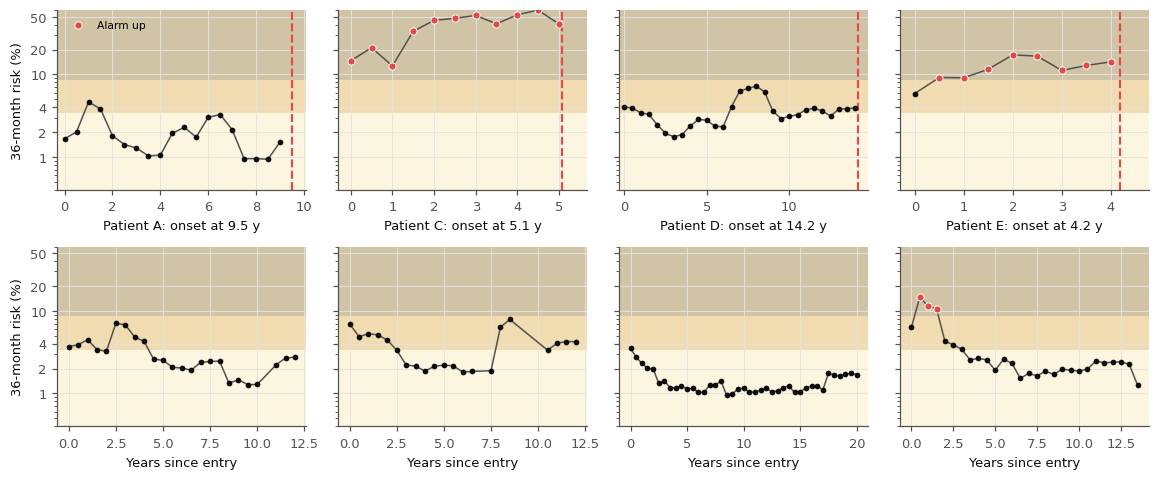

**What this means.** Individual risks move with each visit, but most patients stay within one or two tiers for
years. The red dots show how the alarm follows these trajectories. Patients who go on to leave work tend to sit in the upper tiers for a long time, sometimes with a further rise
before the onset; patients who keep working mostly sit in the lower tiers. The tier, re-checked at each visit, is the
practical output.

In [101]:
"""Risk trajectories of eight patients (cross-validated risk at each landmark)."""
_rng = np.random.RandomState(SEED + 1)
_more_on = [p for p in _rng.permutation(CAND_ONSET) if p != EXAMPLE_PIDS[0]][:3]
_more_w = [p for p in _rng.permutation(CAND_WORKING) if p != EXAMPLE_PIDS[1]][:3]
_show = [EXAMPLE_PIDS[0]] + _more_on + [EXAMPLE_PIDS[1]] + _more_w
_labels = ["A"] + ["C", "D", "E"] + ["B"] + ["F", "G", "H"]
fig, axes = plt.subplots(2, 4, figsize=(10.6, 4.6), sharey=True)
for ax, p, lab in zip(axes.ravel(), _show, _labels):
    r = PT_ROWS[p]
    if p in FIRST_ONSET_DATE.index:
        r = r[land["visit_date"].values[r] < np.datetime64(FIRST_ONSET_DATE[p])]
    x = _yrs(land["visit_date"].values[r], p)
    _tier_bands(ax, orient="y", alpha=0.35)
    ax.plot(x, 100 * P_MAIN[r], "-", color=INK_2, lw=1, zorder=2)
    _f = FLAGS["HazReg"][r]
    ax.scatter(x[~_f], 100 * P_MAIN[r][~_f], s=14, color=INK, zorder=3, linewidths=0)
    ax.scatter(x[_f], 100 * P_MAIN[r][_f], s=22, color=LEFT_C, zorder=4, edgecolor="white", linewidths=0.6,
               label="Alarm up" if lab == "A" else None)
    if p in FIRST_ONSET_DATE.index:
        xo = _yrs(FIRST_ONSET_DATE[p], p)
        ax.axvline(xo, color=LEFT_C, lw=1.4, ls="--")
        ax.set_xlim(-0.3, xo + 0.6)
        ttl = f"Patient {lab}: onset at {xo:.1f} y"
    else:
        ttl = f"Patient {lab}: still working"
    ax.set_title(ttl, loc="left", fontsize=8.5)
    ax.set_yscale("log"); ax.set_ylim(0.4, 60)
    ax.set_yticks([1, 2, 4, 10, 20, 50], ["1", "2", "4", "10", "20", "50"])
for ax in axes[1]:
    ax.set_xlabel("Years since entry")
for ax in axes[:, 0]:
    ax.set_ylabel("36-month risk (%)")
axes[0, 0].legend(fontsize=7, loc="upper left")
plt.tight_layout(); save_fig("risk06_individual_trajectories")
say("""
**What this means.** Individual risks move with each visit, but most patients stay within one or two tiers for
years. The red dots show how the alarm follows these trajectories. Patients who go on to leave work tend to sit in the upper tiers for a long time, sometimes with a further rise
before the onset; patients who keep working mostly sit in the lower tiers. The tier, re-checked at each visit, is the
practical output.
""")

### 6.7.1 Patients lost to follow-up while still employed

> **The question.** What was the risk of the patients whose record stops while they were still working, and how
> many of them would the score have flagged when they were last seen?

A patient is **lost to follow-up while employed** if their last recorded status was a working
status, they were alive, and they had no recorded status in the last 2 years of the analysis period. Their
follow-up is censored at the last contact, so the model never learns what happened to them. They are split by the
band of their **last score**: Raised or High (the flag was up when they were lost) against Low.

They are compared with two groups: the patients still attending at the end of the analysis period without an onset
(aligned at their last contact), and the patients who left work for health reasons (aligned at their first onset,
using the scores before it). Every risk is the cross-validated HazReg risk at the 6-monthly landmarks.

,"Lost, Raised or High at the last score","Lost, Low at the last score","Still attending, no onset",Left work for health reasons (before onset)
Patients,78,97,445,142
"Year of last contact / onset, median (IQR)",2007 (2003-2012),2013 (2007-2016),2019 (2019-2020),2007 (2002-2012)
Years from first landmark to last contact / onset,3.4 (1.3-7.4),6.1 (2.6-9.8),6.6 (2.7-12.8),3.7 (1.3-8.9)
"Landmarks scored, median",6,9,12,6
Months from last score to last contact / onset,3.6 (1.6-5.6),4.7 (2.7-6.6),3.3 (1.6-5.1),3.4 (2.1-5.0)
Age at last score,40.0 (33.4-50.1),34.5 (29.6-44.8),41.5 (33.2-51.2),43.5 (34.4-52.6)
Years since first clinic visit at last score,4.8 (1.5-12.6),8.0 (2.5-11.8),8.0 (3.0-14.8),6.5 (1.5-13.5)
Relative risk at last score,1.80 (1.37-2.62),0.56 (0.40-0.77),0.77 (0.49-1.25),2.69 (1.53-4.16)
Predicted 36-mo risk at last score (%),6.1 (4.6-8.8),1.9 (1.3-2.6),2.6 (1.6-4.2),9.1 (5.1-14.0)
Last score Low (%),0,100,64,14


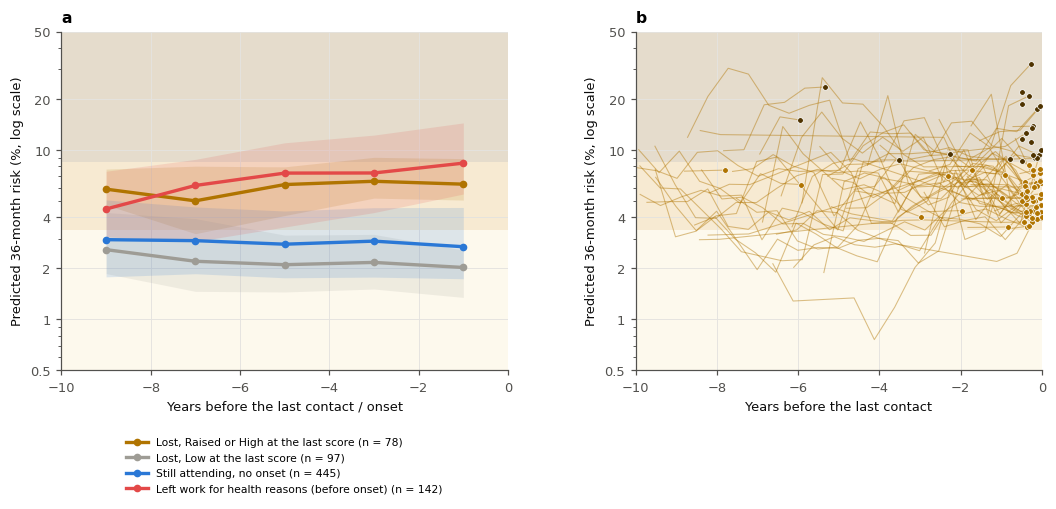

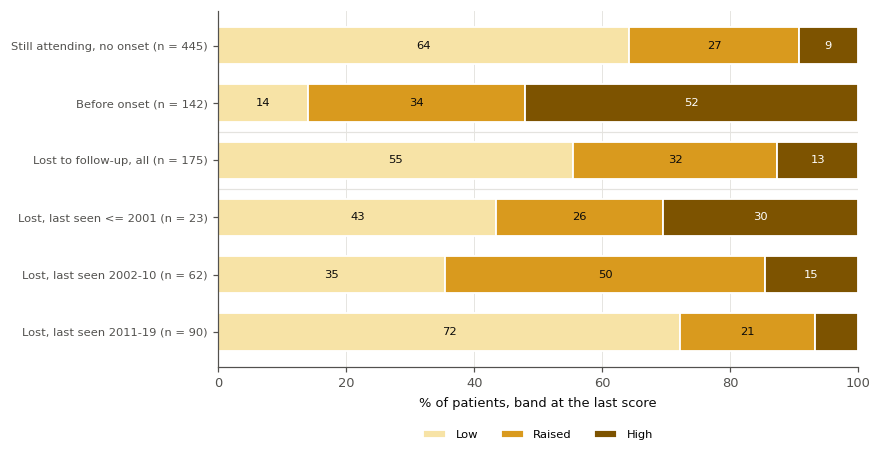

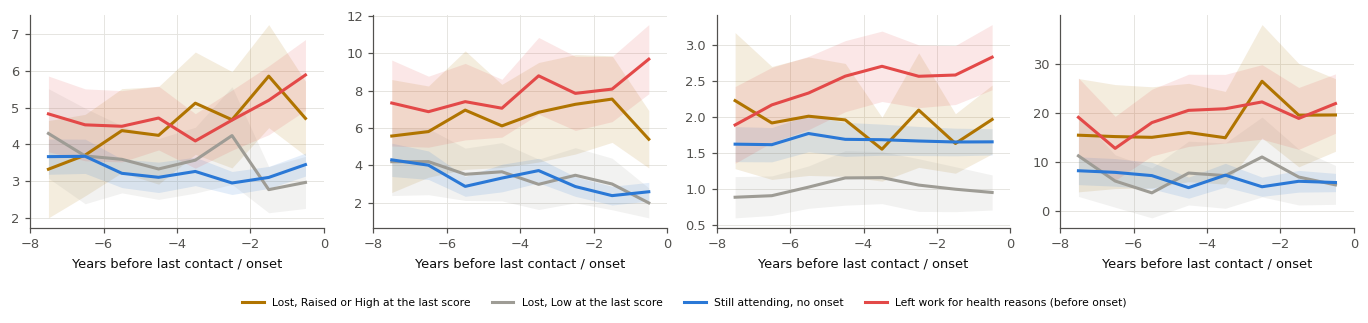

,Patients,Expected onsets within 36 mo of the last contact,"Same, under the latest hazards by year",Expected from the band's observed 36-mo risk,Expected onsets by data end or age 65 (constant hazards),"Years from last contact to data end or age 65, median"
Band at the last score,,,,,,
Low,97.0,1.1,1.3,1.6,4.0,6.1
Raised,56.0,2.0,2.0,3.2,8.4,11.2
High,22.0,2.0,2.0,3.1,7.2,13.5
All lost,175.0,5.1,5.3,8.0,19.6,8.0


,Patients lost,Seen again after the last status,"Years away, median",First status back: working,Disabled or on sick leave at any later visit
Band at the last score,,,,,
Low,97,6,4.997947,3,0
Raised,56,3,0.344969,1,0
High,22,0,NaN,0,0


,Last contact,Age at last score,Years in clinic,Band at the last score,Relative risk,36-mo risk (%),Scores Raised or High,P(onset) 36 mo after last contact (%),Seen again after the last status,First status back
PTNO,,,,,,,,,,
1073,2004-10-14,45.0,2.9,High,9.60,32.3,6 of 6,25.3,no,
1469,2016-02-25,55.0,2.5,High,7.00,23.6,6 of 6,12.4,no,
1888,2016-10-17,64.0,0.0,High,6.58,22.2,1 of 1,1.2,no,
1788,2016-02-03,49.0,2.0,High,6.20,20.9,5 of 5,10.7,no,
825,1997-09-25,29.0,0.5,High,5.53,18.6,1 of 1,13.1,no,
1190,2006-01-31,38.0,1.5,High,5.39,18.1,4 of 4,13.9,no,
1178,2017-06-01,38.0,12.8,High,5.16,17.4,19 of 19,7.8,no,
701,2001-11-19,49.0,2.6,High,4.46,15.0,3 of 3,10.7,no,
729,1995-12-07,37.0,1.8,High,4.11,13.8,2 of 2,9.8,no,


**What this means.**

* **175 patients were lost to follow-up while employed, and 78 of them (45 %) were in the
  Raised or High band at their last score**, against 36 % of the patients still attending and
  86 % of the patients who later left work (at their last score before the onset).
  22 were in the High band.
* **Most of the patients lost while flagged were lost before 2011** (53 of 78). By the band at the last score:
  <= 2001: 57 % Raised or High, 2002-10: 65 % Raised or High, 2011-19: 28 % Raised or High.
* **Their path looks like that of the patients who left work.** Five or more years before the last contact, the
  median risk of the patients lost while flagged was 5.7 %, against 6.0 % in the
  patients who later left work and 2.9 % in the patients still attending; in the final two years
  it was 6.3 %, 8.4 % and 2.7 %. The group is chosen by
  its last score, so its final point is high by construction; the earlier points are not. Their clinical picture at
  the last score matches the onset group as well: SLEDAI-2K 3.9 (2.0-6.9)
  against 4.3 (2.0-7.9), prednisone
  4.8 (0.0-9.4) against 5.0 (0.0-15.0) mg/day,
  fatigue 26 % against 25 %, and
  fibromyalgia 24 % against 27 %.
  The patients lost from the Low band resemble the patients still attending.
* **Onsets the clinic may not have seen.** Under the model's hazards at the recorded level of each year, about
  5.1 onsets are expected within 36 months of the
  last contact among all 175 patients lost,
  4.0 of them among the 78 who were Raised or
  High. Using the observed risk of each band in the patients who stayed gives
  8.0. Over the whole time to the data end or age 65 the
  model expects 19.6, against
  150 onsets observed in the whole main analysis. Section 5.2.1 shows how much these missing onsets
  could change the model's performance.
* **The patients who came back.** 9 of the 175 were seen
  again after their last recorded status (at visits with no status); 0 of them had a
  disabled or sick-leave status at a later visit
  (0 of the
  3 who came back from the Raised or
  High band). The list of the 78 patients lost while flagged is saved for chart review or linkage (Section 7.2.1).

In [102]:
"""Lost to follow-up while employed: risk up to the last contact, band at loss, expected onsets missed, later visits without a status."""
_LOST_COL, _LOW_COL = "#b07400", "#9e9c95"
_lr = land.loc[LAST_ROWS]
_lost_last = _lr[_lr["pid"].isin(LEFT_CLINIC_PIDS)]
_att_last = _lr[(LAST_ENDING == "still attending") & ~PID_EVENT[_lr["pid"].map(PID_INDEX).values].astype(bool)]
_anchor = {"lost": pd.Series(_lost_last["last_status_date"].values, index=_lost_last["pid"].values),
           "attending": pd.Series(_att_last["last_status_date"].values, index=_att_last["pid"].values),
           "onset": FIRST_ONSET_DATE}


def _aligned_rows(anchors, before_only):
    """Every landmark of the patients up to their anchor: pid, row, years before the anchor."""
    out = []
    for p, a in anchors.items():
        r = PT_ROWS[p]
        d = land["visit_date"].values[r]
        k = d < np.datetime64(a) if before_only else d <= np.datetime64(a)
        out.append(pd.DataFrame({"pid": p, "row": r[k], "yb": (np.datetime64(a) - d[k]) / np.timedelta64(1, "D") / 365.25}))
    return pd.concat(out, ignore_index=True)


_AL = {g: _aligned_rows(a, g == "onset") for g, a in _anchor.items()}
for g, d in _AL.items():
    d["p"], d["band"] = P_MAIN[d["row"].values], TIER_OF(P_MAIN[d["row"].values])
_last_of = {g: d.sort_values(["pid", "row"]).groupby("pid").tail(1).set_index("pid") for g, d in _AL.items()}
_lost_band = _last_of["lost"]["band"]
_lost_hi = set(_lost_band.index[_lost_band >= 1])
GROUPS_LOST = {"Lost, Raised or High at the last score": ("lost", _lost_hi, _LOST_COL),
               "Lost, Low at the last score": ("lost", set(_lost_band.index[_lost_band == 0]), _LOW_COL),
               "Still attending, no onset": ("attending", set(_last_of["attending"].index), KEPT_C),
               "Left work for health reasons (before onset)": ("onset", set(_last_of["onset"].index), LEFT_C)}

# ---- returns after the analysis period (any later visit of the whole extract), for the patients lost
_vis_after = visits                                  # any later clinic visit (none records a status)
_ret = {}
for p, a in _anchor["lost"].items():
    v = _vis_after[(_vis_after["PTNO"] == p) & (_vis_after["ASSDT"] > a)]
    s = v.loc[v["HAS_STATUS"], "EMP"]
    st = [_state_of(e) for e in s.values]
    _ret[p] = {"returned": len(v) > 0, "years_away": (v["ASSDT"].min() - a).days / 365.25 if len(v) else np.nan,
               "first_status": s.iloc[0] if len(s) else ("no status recorded" if len(v) else ""),
               "later_disabled_or_sick": any(x in ("D", "S") for x in st)}
_RET = pd.DataFrame(_ret).T

# ---- expected onsets after the last contact, from the cross-validated hazards (as in Section 5.2.1)
_gai = {p: i for i, p in enumerate(GA_PIDS)}


def _p_onset(years, by_time=True):
    """Probability of an onset within `years` (capped at data end / age 65) after the last contact, constant hazards."""
    l1 = np.exp(GA_ETA[:, 0]) * (GA_M[:, 0] if by_time else 1.0)
    l2 = np.exp(GA_ETA[:, 1]) * (GA_M[:, 1] if by_time else 1.0)
    dt = (GA_A - GA_C) / 365.25 if years is None else np.minimum(years, (GA_A - GA_C) / 365.25)
    return pd.Series(l1 / (l1 + l2) * (1 - np.exp(-(l1 + l2) * dt)), index=GA_PIDS)


_P24_LOST, _PEND_LOST, _P24_LATEST = _p_onset(2.0), _p_onset(None), _p_onset(2.0, by_time=False)


def _med_iqr(s, f="{:.1f}"):
    s = pd.Series(s).dropna()
    return "" if s.empty else f"{f.format(s.median())} ({f.format(s.quantile(0.25))}-{f.format(s.quantile(0.75))})"


_rows = {}
for nm, (g, pids, _) in GROUPS_LOST.items():
    d, last = _AL[g][_AL[g]["pid"].isin(pids)], _last_of[g].loc[sorted(pids)]
    lr = last["row"].values
    anc = pd.to_datetime(_anchor[g].reindex(sorted(pids)))
    first = d.groupby("pid")["yb"].max()
    X_ = LAND_X.iloc[lr]
    _rows[nm] = {
        "Patients": len(pids),
        "Year of last contact / onset, median (IQR)": _med_iqr(anc.dt.year, "{:.0f}"),
        "Years from first landmark to last contact / onset": _med_iqr(first),
        "Landmarks scored, median": f"{d.groupby('pid').size().median():.0f}",
        "Months from last score to last contact / onset": _med_iqr(12 * last["yb"]),
        "Age at last score": _med_iqr(X_["age_at_record"]),
        "Years since first clinic visit at last score": _med_iqr(X_["YRS_IN_CLINIC"]),
        "Relative risk at last score": _med_iqr(last["p"] / REF_RISK, "{:.2f}"),
        "Predicted 36-mo risk at last score (%)": _med_iqr(100 * P_ABS["HazReg"][lr]),
        **{f"Last score {b} (%)": f"{100 * np.mean(last['band'] == k):.0f}" for k, b in enumerate(TIER_NAMES)},
        "Ever Raised or High (%)": f"{100 * d.groupby('pid')['band'].max().ge(1).mean():.0f}",
        "Scores Raised or High, mean share (%)": f"{100 * d.groupby('pid')['band'].apply(lambda b: (b >= 1).mean()).mean():.0f}",
        "SLEDAI-2K 12-mo adjusted mean, last score": _med_iqr(X_["AMS_12M"]),
        "SDI damage score, last score": _med_iqr(X_["score_n"], "{:.0f}"),
        "Prednisone mg/day, last score": _med_iqr(X_["STERAVER_0"]),
        "Fatigue at last score (%)": f"{100 * X_['FATIGUE'].mean():.0f}",
        "Fibromyalgia at last score (%)": f"{100 * X_['FM_ANY'].mean():.0f}",
        "Earlier onset, then back at work (%)": f"{100 * np.mean([PID_EVENT[PID_INDEX[p]] for p in pids]):.0f}" if g == "lost" else "",
        "Seen again after the last status (%)": f"{100 * _RET.loc[sorted(pids), 'returned'].mean():.0f}" if g == "lost" else ""}
LOST_TABLE = pd.DataFrame(_rows)
display(LOST_TABLE)
save_table(LOST_TABLE, "lost_to_follow_up_characteristics")

# ---- figure: risk up to the last contact, and the flagged patients one by one
_edges_y = np.arange(0, 10.01, 2)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw={"width_ratios": [1.1, 1], "wspace": 0.3})
ax = axes[0]
_tier_bands(ax, orient="y", alpha=0.2)
RISK_BEFORE_LOSS = {}
for nm, (g, pids, col) in GROUPS_LOST.items():
    d = _AL[g][_AL[g]["pid"].isin(pids)].copy()
    d["bin"] = np.digitize(d["yb"], _edges_y)
    d = d[d["yb"] < _edges_y[-1]]
    gg = d.groupby(["bin", "pid"])["p"].mean().mul(100).groupby("bin")
    q, n = gg.quantile([0.25, 0.5, 0.75]).unstack(), gg.size()
    q = q[n >= 8]
    xs = -(_edges_y[q.index.values - 1] + 1)
    ax.fill_between(xs, q[0.25], q[0.75], color=col, alpha=0.15, lw=0)
    ax.plot(xs, q[0.5], "-o", ms=4, color=col, lw=2.2, label=f"{nm} (n = {len(pids)})")
    RISK_BEFORE_LOSS[nm] = pd.Series(q[0.5].values, index=xs)
ax.set_yscale("log"); ax.set_ylim(0.5, 50)
ax.set_yticks([0.5, 1, 2, 4, 10, 20, 50], ["0.5", "1", "2", "4", "10", "20", "50"])
ax.set_xlim(-_edges_y[-1], 0)
ax.set_xlabel("Years before the last contact / onset"); ax.set_ylabel("Predicted 36-month risk (%, log scale)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), fontsize=7)
ax.set_title("a  Risk up to the last contact", loc="left")

ax = axes[1]
_tier_bands(ax, orient="y", alpha=0.2)
_dl = _AL["lost"]
for p in sorted(_lost_hi):
    d = _dl[_dl["pid"] == p].sort_values("yb", ascending=False)
    d = d[d["yb"] < _edges_y[-1]]
    ax.plot(-d["yb"], 100 * d["p"], "-", color=_LOST_COL, lw=0.7, alpha=0.45)
    ax.scatter(-d["yb"].iloc[-1:], 100 * d["p"].iloc[-1:], s=14, color=TIER_LINE_COLORS[int(d["band"].iloc[-1])],
               edgecolor="white", linewidths=0.5, zorder=3)
ax.set_yscale("log"); ax.set_ylim(0.5, 50)
ax.set_yticks([0.5, 1, 2, 4, 10, 20, 50], ["0.5", "1", "2", "4", "10", "20", "50"])
ax.set_xlim(-_edges_y[-1], 0)
ax.set_xlabel("Years before the last contact"); ax.set_ylabel("Predicted 36-month risk (%, log scale)")
ax.set_title(f"b  The {len(_lost_hi)} patients lost while Raised or High", loc="left")
save_fig("risk07_lost_to_follow_up")

# ---- figure: band at the last score by group
_lost_year = pd.to_datetime(_anchor["lost"])
_era_lost = pd.Series(era_of(_lost_year), index=_lost_year.index)
_bar_rows = [("Still attending, no onset", _last_of["attending"]["band"]),
             ("Before onset", _last_of["onset"]["band"]),
             ("Lost to follow-up, all", _lost_band)] + \
            [(f"Lost, last seen {e}", _lost_band[_era_lost[_era_lost == e].index]) for e in
             ERA_NAMES if (_era_lost == e).sum() > 0]
BAND_AT_LOSS = pd.DataFrame({lab: {**{TIER_NAMES[k]: 100 * np.mean(b == k) for k in range(len(TIER_NAMES))},
                                   "Patients": len(b)} for lab, b in _bar_rows}).T
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for i, (lab, b) in enumerate(_bar_rows):
    left = 0
    for k in range(len(TIER_NAMES)):
        w = 100 * np.mean(b == k)
        ax.barh(i, w, left=left, color=TIER_COLORS[k], edgecolor="white", linewidth=1.2, height=0.65,
                label=TIER_NAMES[k] if i == 0 else None)
        if w >= 9:
            ax.text(left + w / 2, i, f"{w:.0f}", ha="center", va="center", fontsize=7.5, color=INK if k < 2 else "white")
        left += w
ax.set_yticks(range(len(_bar_rows)), [f"{lab} (n = {len(b)})" for lab, b in _bar_rows], fontsize=7.5)
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
for _y in (1.5, 2.5):
    ax.axhline(_y, color=GRID_C, lw=0.8)
ax.set_xlabel("% of patients, band at the last score")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=7.5, frameon=False)
ax.set_title("Band at the last score (patients lost by year: Section 4.0.2)", loc="left", fontsize=9)
save_fig("risk07b_lost_to_follow_up_band")

# ---- clinical picture up to the last contact (1-year bins)
_vg = visits.groupby("PTNO").indices
_CLIN = [("AMS_12M", "SLEDAI-2K (12-mo adjusted mean)", 1), ("STERAVER_0", "Prednisone (mg/day)", 1),
         ("score_n", "SDI damage score", 1), ("FATIGUE", "Fatigue reported (%)", 100)]
_vpre = visits
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.0))
for nm, (g, pids, col) in GROUPS_LOST.items():
    parts = []
    for p in pids:
        if p not in _vg:
            continue
        v = _vpre.iloc[_vg[p]]
        yb = (pd.Timestamp(_anchor[g][p]) - v["ASSDT"]).dt.days / 365.25
        k = (yb > 0 if g == "onset" else yb >= 0) & (yb < 8)
        parts.append(v.loc[k, [c for c, _, _ in _CLIN]].assign(pid=p, bin=np.floor(yb[k]).astype(int)))
    dv = pd.concat(parts)
    for ax, (c, lab, sc) in zip(axes, _CLIN):
        s = (dv.groupby(["bin", "pid"])[c].mean() * sc).groupby("bin").agg(["mean", "sem", "size"])
        s = s[s["size"] >= 8]
        xs = -(s.index.values + 0.5)
        ax.fill_between(xs, s["mean"] - 1.96 * s["sem"], s["mean"] + 1.96 * s["sem"], color=col, alpha=0.13, lw=0)
        ax.plot(xs, s["mean"], "-", color=col, lw=2, label=nm)
for ax, (c, lab, sc) in zip(axes, _CLIN):
    ax.set_title(lab, loc="left", fontsize=9); ax.set_xlabel("Years before last contact / onset"); ax.set_xlim(-8, 0)
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=7, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.08, 1, 1)); save_fig("risk08_lost_to_follow_up_clinical")

# ---- onsets the clinic may not have seen: expected among the patients lost, by band at the last score
_obs_band = TIERS["Observed 36-mo risk (%)"].values / 100
_exp = []
for k, b in enumerate(TIER_NAMES):
    pids = sorted(_lost_band.index[_lost_band == k])
    _exp.append({"Band at the last score": b, "Patients": len(pids),
                 "Expected onsets within 36 mo of the last contact": _P24_LOST.reindex(pids).sum(),
                 "Same, under the latest hazards by year": _P24_LATEST.reindex(pids).sum(),
                 "Expected from the band's observed 36-mo risk": len(pids) * _obs_band[k],
                 "Expected onsets by data end or age 65 (constant hazards)": _PEND_LOST.reindex(pids).sum(),
                 "Years from last contact to data end or age 65, median":
                     np.median(((GA_A - GA_C) / 365.25)[[_gai[p] for p in pids if p in _gai]]) if pids else np.nan})
LOST_EXPECTED = pd.DataFrame(_exp).set_index("Band at the last score")
LOST_EXPECTED.loc["All lost"] = [LOST_EXPECTED["Patients"].sum(), *LOST_EXPECTED.iloc[:, 1:5].sum().values,
                                 np.median((GA_A - GA_C) / 365.25)]
display(LOST_EXPECTED.round(1))
save_table(LOST_EXPECTED.round(2), "lost_to_follow_up_expected_onsets")

# ---- what the record shows for the patients seen again after their last recorded status
_rb = _RET.join(_lost_band.rename("band"))
_rb["Band at the last score"] = np.array(TIER_NAMES)[_rb["band"].astype(int)]
_back = _rb[_rb["returned"]]
LOST_RETURNS = pd.DataFrame({
    "Patients lost": _rb.groupby("Band at the last score").size(),
    "Seen again after the last status": _back.groupby("Band at the last score").size(),
    "Years away, median": _back.groupby("Band at the last score")["years_away"].median().round(1),
    "First status back: working": _back.assign(w=_back["first_status"].map(lambda e: _state_of(e) == "W"))
                                  .groupby("Band at the last score")["w"].sum(),
    "Disabled or on sick leave at any later visit": _back.groupby("Band at the last score")["later_disabled_or_sick"].sum()
}).reindex(TIER_NAMES)
_cnt = [c for c in LOST_RETURNS if c != "Years away, median"]
LOST_RETURNS[_cnt] = LOST_RETURNS[_cnt].fillna(0).astype(int)
display(LOST_RETURNS)
save_table(LOST_RETURNS, "lost_to_follow_up_returns")

# ---- the patients lost while Raised or High, one row each (for chart review or linkage, Section 7.2)
_lh = _last_of["lost"].loc[sorted(_lost_hi)]
_lh_n = _dl[_dl["pid"].isin(_lost_hi)].groupby("pid")["band"].agg(lambda b: f"{(b >= 1).sum()} of {len(b)}")
LOST_HIGH_LIST = pd.DataFrame({
    "Last contact": pd.to_datetime(_anchor["lost"].reindex(_lh.index)).dt.date.values,
    "Age at last score": LAND_X["age_at_record"].values[_lh["row"].values].round(0),
    "Years in clinic": LAND_X["YRS_IN_CLINIC"].values[_lh["row"].values].round(1),
    "Band at the last score": np.array(TIER_NAMES)[_lh["band"].values],
    "Relative risk": (_lh["p"].values / REF_RISK).round(2),
    "36-mo risk (%)": (100 * P_ABS["HazReg"][_lh["row"].values]).round(1),
    "Scores Raised or High": _lh_n.reindex(_lh.index).values,
    "P(onset) 36 mo after last contact (%)": (100 * _P24_LOST.reindex(_lh.index)).round(1).values,
    "Seen again after the last status": _RET.loc[_lh.index, "returned"].map({True: "yes", False: "no"}).values,
    "First status back": _RET.loc[_lh.index, "first_status"].values}, index=pd.Index(_lh.index, name="PTNO")
).sort_values("Relative risk", ascending=False)
display(LOST_HIGH_LIST.head(25))
save_table(LOST_HIGH_LIST, "lost_to_follow_up_raised_or_high")

_nl, _nh = len(_lost_band), len(_lost_hi)
_att_hi = 100 * np.mean(_last_of["attending"]["band"] >= 1)
_on_hi = 100 * np.mean(_last_of["onset"]["band"] >= 1)
_e_all, _e_hi = LOST_EXPECTED.loc["All lost"], LOST_EXPECTED.iloc[1:3]
_era_hi = BAND_AT_LOSS.loc[[i for i in BAND_AT_LOSS.index if i.startswith("Lost, last seen")], ["Raised", "High"]].sum(1)
_n_hi_early = int((_era_lost.reindex(sorted(_lost_hi)).isin(["<= 2001", "2002-10"])).sum())
_rb_far = {nm: s_[s_.index <= -5].mean() for nm, s_ in RISK_BEFORE_LOSS.items()}
_rb_near = {nm: s_[s_.index >= -1].mean() for nm, s_ in RISK_BEFORE_LOSS.items()}
_GL = list(GROUPS_LOST)
_lt = LOST_TABLE
say(f"""
**What this means.**

* **{_nl} patients were lost to follow-up while employed, and {_nh} of them ({100 * _nh / _nl:.0f} %) were in the
  Raised or High band at their last score**, against {_att_hi:.0f} % of the patients still attending and
  {_on_hi:.0f} % of the patients who later left work (at their last score before the onset).
  {int((_lost_band == 2).sum())} were in the High band.
* **Most of the patients lost while flagged were lost before 2011** ({_n_hi_early} of {_nh}). By the band at the last score:
  {", ".join(f"{i.replace('Lost, last seen ', '')}: {v:.0f} % Raised or High" for i, v in _era_hi.items())}.
* **Their path looks like that of the patients who left work.** Five or more years before the last contact, the
  median risk of the patients lost while flagged was {_rb_far[_GL[0]]:.1f} %, against {_rb_far[_GL[3]]:.1f} % in the
  patients who later left work and {_rb_far[_GL[2]]:.1f} % in the patients still attending; in the final two years
  it was {_rb_near[_GL[0]]:.1f} %, {_rb_near[_GL[3]]:.1f} % and {_rb_near[_GL[2]]:.1f} %. The group is chosen by
  its last score, so its final point is high by construction; the earlier points are not. Their clinical picture at
  the last score matches the onset group as well: SLEDAI-2K {_lt.loc["SLEDAI-2K 12-mo adjusted mean, last score", _GL[0]]}
  against {_lt.loc["SLEDAI-2K 12-mo adjusted mean, last score", _GL[3]]}, prednisone
  {_lt.loc["Prednisone mg/day, last score", _GL[0]]} against {_lt.loc["Prednisone mg/day, last score", _GL[3]]} mg/day,
  fatigue {_lt.loc["Fatigue at last score (%)", _GL[0]]} % against {_lt.loc["Fatigue at last score (%)", _GL[3]]} %, and
  fibromyalgia {_lt.loc["Fibromyalgia at last score (%)", _GL[0]]} % against {_lt.loc["Fibromyalgia at last score (%)", _GL[3]]} %.
  The patients lost from the Low band resemble the patients still attending.
* **Onsets the clinic may not have seen.** Under the model's hazards at the recorded level of each year, about
  {_e_all["Expected onsets within 36 mo of the last contact"]:.1f} onsets are expected within 36 months of the
  last contact among all {_nl} patients lost,
  {_e_hi["Expected onsets within 36 mo of the last contact"].sum():.1f} of them among the {_nh} who were Raised or
  High. Using the observed risk of each band in the patients who stayed gives
  {_e_all["Expected from the band's observed 36-mo risk"]:.1f}. Over the whole time to the data end or age 65 the
  model expects {_e_all["Expected onsets by data end or age 65 (constant hazards)"]:.1f}, against
  {int(D1_ALL.sum())} onsets observed in the whole main analysis. Section 5.2.1 shows how much these missing onsets
  could change the model's performance.
* **The patients who came back.** {int(LOST_RETURNS["Seen again after the last status"].sum())} of the {_nl} were seen
  again after their last recorded status (at visits with no status); {int(LOST_RETURNS["Disabled or on sick leave at any later visit"].sum())} of them had a
  disabled or sick-leave status at a later visit
  ({int(LOST_RETURNS.loc[["Raised", "High"], "Disabled or on sick leave at any later visit"].sum())} of the
  {int(LOST_RETURNS.loc[["Raised", "High"], "Seen again after the last status"].sum())} who came back from the Raised or
  High band). The list of the {_nh} patients lost while flagged is saved for chart review or linkage (Section 7.2.1).
""")

### 6.7.2 Why a patient is flagged: the drivers of each score

> **The question.** A flag says *talk to this patient about work*. Which of the patient's inputs put them there?

HazReg is additive on the log-hazard scale, so each score splits exactly into one contribution per input: the input's
coefficient times the patient's value, against the **average development landmark** (spline and missing-value terms are
added to their input). Written as a multiplier, ×1.5 means this input alone raises the onset hazard by half, with the others
held at average. The multipliers of all inputs multiply to the patient's hazard against the average landmark. No SHAP
approximation is needed for a model of this form. The final model's coefficients are used, as the tool would; the band here is
the final model's own.

> **How to read it.** Drivers explain the *score*, not the disease: they say why the model ranks this patient high, not what
> would lower the risk (Section 3.9.1). Correlated inputs share credit under a ridge penalty (SLEDAI-2K and clinical SLEDAI-2K,
> fatigue and the fatigue scale, the SF-36 PCS and most symptoms), so read neighbouring drivers together. Clinic visits per
> year describes care use, and more visits also mean more chances to record an onset.

,"Among the top 3 raising, Raised band (%)","Among the top 3 raising, High band (%)","Mean multiplier, flagged landmarks",Same sign in bootstrap refits (%)
"SF-36 PCS (form in the past 12 months, else predicted)",35.15,59.84,1.17,100.0
Antimalarial,34.42,45.66,1.05,100.0
SDI damage score,40.52,44.58,1.11,100.0
"SLEDAI-2K, 12-month adjusted mean",22.11,25.99,1.05,98.0
Current smoker,12.84,20.18,1.02,98.0
Years on any immunosuppressant,40.12,19.72,1.00,100.0
Prednisone (mg/day),15.30,15.77,1.04,100.0
Dyspnoea,1.52,13.92,1.01,100.0
"SF-36 MCS (form in the past 12 months, else predicted)",10.57,11.50,1.03,98.0
Education: post-secondary,37.13,10.53,1.04,100.0


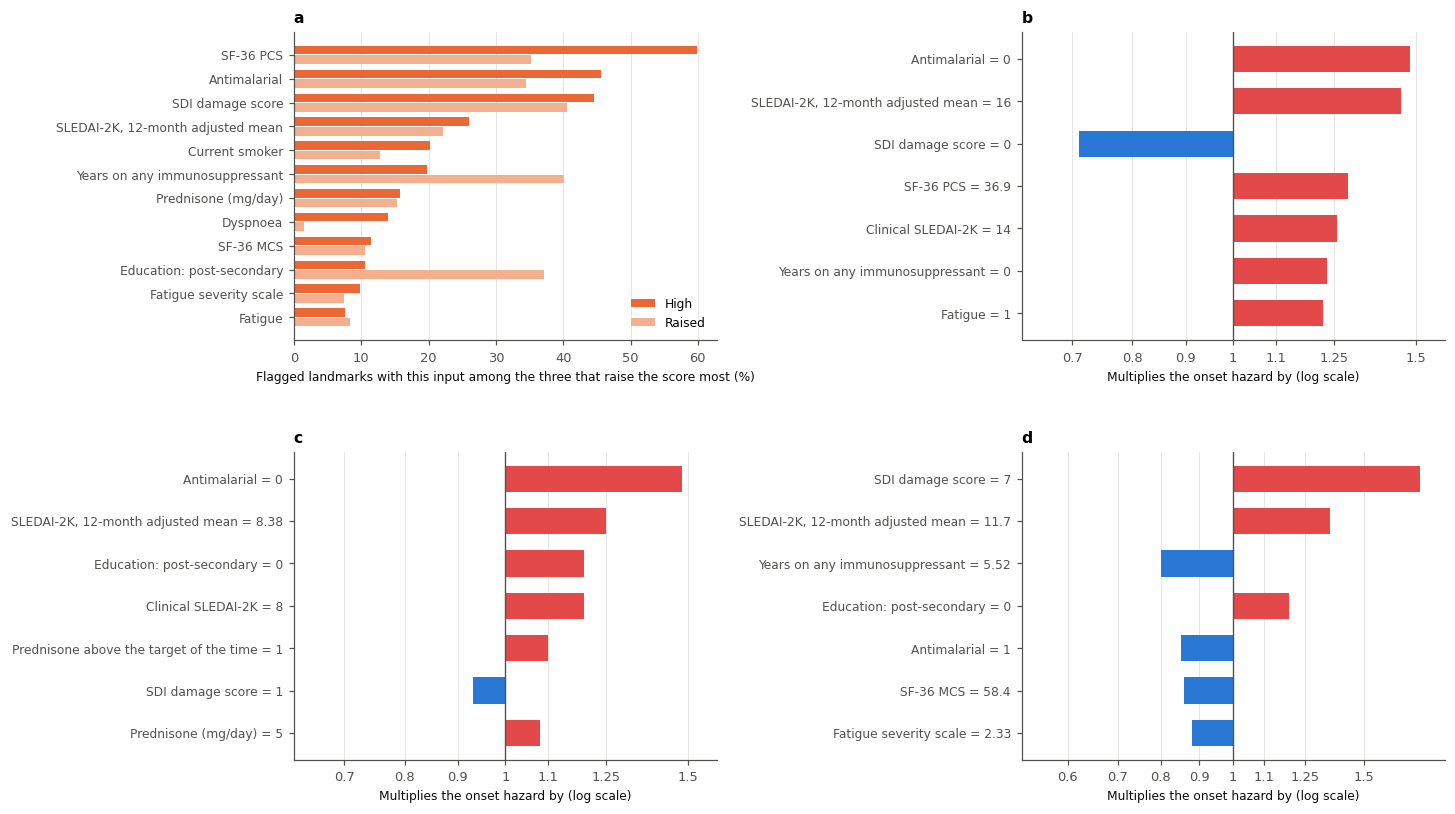

**What this means.** Among flagged landmarks the input that raises the score most is most often
Antimalarial (25 %), then SF-36 PCS (23 %);
16 different inputs lead at least one flag, and 6 lead at least 5 % of them. So two flagged patients
are often flagged for different reasons, which is the case for showing the drivers beside the flag: the same band can call for a
different conversation. The table gives each input's share by band and how often its coefficient kept its sign across bootstrap
refits; a driver that often changes sign should not be read on its own. `patient_drivers(row)` gives the table for any landmark,
and the frozen scorer returns each visit's top three (Section 7.1).

In [103]:
"""Per-patient drivers of the score: each input's contribution to the log onset hazard against the average landmark."""


def driver_matrix(model=FINAL, F=None):
    """Contribution of each input to the log onset hazard: one row per landmark of F, one column per input."""
    F = LAND_X if F is None else F
    c = design(model, F) * model["coef"][0]
    return pd.DataFrame(c, columns=[n.split("__")[0] for n in model["prep"].names]).T.groupby(level=0, sort=False).sum().T


DRV = driver_matrix()
_F_drv = recency_frame(LAND_X, FINAL.get("half_life"))
P_FINAL = cif(predict_eta(FINAL), base=FINAL["base"])
BAND_FINAL = np.digitize(P_FINAL, np.quantile(P_FINAL, REL_TIER_SHARES))
assert np.allclose(DRV.sum(axis=1).values, (design(FINAL, LAND_X) @ FINAL["coef"][0]))


def patient_drivers(row, n=6):
    """The n inputs that move one landmark's onset hazard most, up or down: the patient's value and the multiplier."""
    d = DRV.iloc[row]
    top = d.reindex(d.abs().sort_values(ascending=False).index).head(n)
    return pd.DataFrame({"Input": [DISPLAY.get(k, k) for k in top.index],
                         "Value": [float(_F_drv[k].iloc[row]) if k in _F_drv.columns else np.nan for k in top.index],
                         "Multiplies the onset hazard by": np.exp(top.values)}).round(2)


_dv_flag = BAND_FINAL >= 1
_dv_top3 = np.argsort(-DRV.values, axis=1)[:, :3]
_dv_raises = np.take_along_axis(DRV.values, _dv_top3, 1) > 0
_dv_in_top3 = np.zeros(DRV.shape, bool)
np.put_along_axis(_dv_in_top3, _dv_top3, _dv_raises, 1)
_dv_same = COEF.set_index("Term")["Same sign (%)"]
DRIVER_SUMMARY = pd.DataFrame({
    "Among the top 3 raising, Raised band (%)": 100 * _dv_in_top3[BAND_FINAL == 1].mean(0),
    "Among the top 3 raising, High band (%)": 100 * _dv_in_top3[BAND_FINAL == 2].mean(0),
    "Mean multiplier, flagged landmarks": np.exp(DRV.values[_dv_flag].mean(0))}, index=[DISPLAY.get(c, c) for c in DRV.columns]).round(2)
DRIVER_SUMMARY["Same sign in bootstrap refits (%)"] = _dv_same.reindex(DRIVER_SUMMARY.index).round(0).values
DRIVER_SUMMARY = DRIVER_SUMMARY.sort_values("Among the top 3 raising, High band (%)", ascending=False)
display(DRIVER_SUMMARY)
save_table(DRIVER_SUMMARY, "drivers_by_band")
DRIVER_LEADS = (100 * pd.Series([DISPLAY.get(c, c) for c in DRV.loc[_dv_flag].idxmax(axis=1)]).value_counts(normalize=True)).round(1)

_dv_ok = W_IP > 0


def _middle_row(mask):
    """The landmark at the median risk among `mask` (None if there is none)."""
    ix = np.flatnonzero(mask)
    return None if not len(ix) else ix[np.argsort(P_FINAL[ix])[len(ix) // 2]]


DRIVER_EXAMPLES = {"High band, onset followed": _middle_row(_dv_ok & (BAND_FINAL == 2) & (Y_IP == 1)),
                   "Raised band, onset followed": _middle_row(_dv_ok & (BAND_FINAL == 1) & (Y_IP == 1)),
                   "Raised band, no onset in 36 months": _middle_row(_dv_ok & (BAND_FINAL == 1) & (Y_IP == 0))}
DRIVER_EXAMPLES = {k: v for k, v in DRIVER_EXAMPLES.items() if v is not None}

def _drv_label(t):
    """A display name short enough for an axis."""
    t = re.sub(r" \(form in the past 12 months, else predicted\)| \(recency-weighted\)| \(no serology\)", "", t)
    t = re.sub(r", recency-weighted 24-month mean \(half-life.*\)", ", recent mean", t)
    return t.replace(" (diagnosis or >= 11 tender points)", "").replace(", change over 24 months", ", 24-month change")


fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.6), gridspec_kw={"wspace": 0.72, "hspace": 0.36})
axes = axes.ravel()
ax = axes[0]
_dv_s = DRIVER_SUMMARY.head(12).iloc[::-1]
_dv_y = np.arange(len(_dv_s))
ax.barh(_dv_y + 0.2, _dv_s["Among the top 3 raising, High band (%)"], 0.36, color=C2, label="High")
ax.barh(_dv_y - 0.2, _dv_s["Among the top 3 raising, Raised band (%)"], 0.36, color="#f3b08e", label="Raised")
ax.set_yticks(_dv_y, [_drv_label(t) for t in _dv_s.index], fontsize=8)
ax.set_xlabel("Flagged landmarks with this input among the three that raise the score most (%)", fontsize=8)
ax.grid(axis="y", visible=False); ax.legend(fontsize=8, loc="lower right")
ax.set_title("a  What drives flags", loc="left", fontsize=9)
_dv_ticks = [0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.25, 1.5, 2, 2.5, 3]
for ax, (lab, r), _dv_L in zip(axes[1:], DRIVER_EXAMPLES.items(), "bcd"):
    t = patient_drivers(r, 7).iloc[::-1]
    _dv_m = t["Multiplies the onset hazard by"].values
    ax.barh(range(len(t)), _dv_m - 1, left=1, color=[LEFT_C if v > 1 else KEPT_C for v in _dv_m], height=0.62)
    ax.axvline(1, color=INK_2, lw=0.9); ax.set_xscale("log")
    _dv_lim = max(1.15, np.max(np.maximum(_dv_m, 1 / _dv_m))) * 1.08
    ax.set_xlim(1 / _dv_lim, _dv_lim)
    ax.set_xticks([k for k in _dv_ticks if 1 / _dv_lim <= k <= _dv_lim], [f"{k:g}" for k in _dv_ticks if 1 / _dv_lim <= k <= _dv_lim])
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_yticks(range(len(t)), [f"{_drv_label(i)} = {v:.3g}" for i, v in zip(t["Input"], t["Value"])], fontsize=8)
    ax.grid(axis="y", visible=False); ax.set_xlabel("Multiplies the onset hazard by (log scale)", fontsize=8)
    ax.set_title(f"{_dv_L}  {lab}: 36-month risk {100 * P_FINAL[r]:.1f} %, {P_FINAL[r] / np.median(P_FINAL):.1f} × the median", loc="left", fontsize=9)
save_fig("patient_drivers")
_dv_lead_n = int((DRIVER_LEADS >= 5).sum())
say(f"""
**What this means.** Among flagged landmarks the input that raises the score most is most often
{_drv_label(DRIVER_LEADS.index[0])} ({DRIVER_LEADS.iloc[0]:.0f} %), then {_drv_label(DRIVER_LEADS.index[1])} ({DRIVER_LEADS.iloc[1]:.0f} %);
{len(DRIVER_LEADS)} different inputs lead at least one flag, and {_dv_lead_n} lead at least 5 % of them. So two flagged patients
are often flagged for different reasons, which is the case for showing the drivers beside the flag: the same band can call for a
different conversation. The table gives each input's share by band and how often its coefficient kept its sign across bootstrap
refits; a driver that often changes sign should not be read on its own. `patient_drivers(row)` gives the table for any landmark,
and the frozen scorer returns each visit's top three (Section 7.1).
""")

## 6.8 A simplified model and a points score

> **Why.** HazReg has 26 inputs, splines and two hazards: no one can compute it at the bedside. Tools that are used
> come as a short equation or a points chart. The question is how much ranking and calibration a simpler version
> gives up.

**How (model approximation; Harrell, *Regression Modeling Strategies*, ch. 5).** Instead of selecting inputs against
the outcome (stepwise selection, which overfits and biases the effects), the simplified model is fitted to
**HazReg's own prediction**:

1. Each input is put in clinical bands (age < 35 / 35-44 / 45-54 / ≥ 55; prednisone none / < 7.5 / ≥ 7.5 mg/day;
   SDI 0 / 1 / 2 / ≥ 3; 12-month adjusted mean SLEDAI-2K < 2 / 2 to < 4 / ≥ 4; SF-36 PCS < 30 / 30-39 / 40-49 / ≥ 50; and so on); yes / no inputs stay as they are.
2. The log-odds of HazReg's 36-month risk is regressed on all the banded inputs (least squares); banding alone already
   loses part of HazReg's variance. Inputs are then dropped one at a time, each time the one whose removal costs
   least, while the simplified model keeps at least 95 % of the variance that the full banded model explains.
3. **Points**: each band's coefficient divided by 0.25 and rounded (one point = 0.25 on the log-odds scale). The
   total points are mapped back to a 36-month risk by a line fitted to HazReg's log-odds.

**The whole procedure, steps 1-3, is repeated inside every training fold** and scored on the test fold, so the
simplified model and the points score are validated as honestly as HazReg. The chart shown at the end is the one
built on all patients.

In [104]:
"""Model approximation and points score: cross-validated inside the HazReg folds; the final chart."""
SCORE_VARS = list(COMPACT_VARS)


def score_design(F, med, vars_):
    """Banded design (dummies, reference = lowest band) for the inputs vars_; missing values set to the training median."""
    cols, names, groups = [], [], []
    for c in vars_:
        x = F[c].astype(float).fillna(med[c]).values
        if c in SCORE_BANDS:
            b = np.digitize(x, SCORE_BANDS[c], right=False)
            for k in range(1, len(SCORE_BANDS[c]) + 1):
                cols.append((b == k).astype(float)); names.append((c, k)); groups.append(c)
        else:
            cols.append((x > 0.5).astype(float) if set(np.unique(x[~np.isnan(x)])) <= {0.0, 1.0} else x)
            names.append((c, 1)); groups.append(c)
    return np.column_stack(cols), names, np.array(groups)


def _ols(X, z):
    X1 = np.column_stack([np.ones(len(X)), X])
    b, *_ = np.linalg.lstsq(X1, z, rcond=None)
    r = z - X1 @ b
    return b, 1 - r.var() / z.var()


def approximate(rows, z):
    """Step-down approximation of z (HazReg's log-odds) on the training rows; the points; the points-to-risk line."""
    F = LAND_X.iloc[rows]
    med = F[SCORE_VARS].median()
    X, names, groups = score_design(F, med, SCORE_VARS)
    keep = list(dict.fromkeys(groups))
    b, r2_all = _ols(X, z)
    path = [(list(keep), r2_all)]
    while len(keep) > 1:
        trial = []
        for v in keep:
            k_ = [g for g in keep if g != v]
            trial.append((_ols(X[:, np.isin(groups, k_)], z)[1], v))
        r2n, v = max(trial)
        if r2n < APPROX_R2 * r2_all:
            break
        keep.remove(v)
        path.append((list(keep), r2n))
    m = np.isin(groups, keep)
    b, r2 = _ols(X[:, m], z)
    sel = [nm for nm, mm in zip(names, m) if mm]
    pts = np.round(b[1:] / POINT_LOGIT).astype(int)
    total = X[:, m] @ pts
    line = np.polyfit(total, z, 1)                                    # log-odds ~ slope * points + intercept
    return {"med": med, "keep": keep, "names": sel, "coef": b, "points": pts, "line": line, "r2": r2, "r2_all": r2_all,
            "path": path}


def score_predict(ap, rows):
    F = LAND_X.iloc[rows]
    X, names, groups = score_design(F, ap["med"], ap["keep"])
    z_lin = ap["coef"][0] + X @ ap["coef"][1:]
    total = X @ ap["points"]
    return _expit(z_lin), _expit(np.polyval(ap["line"], total)), total


def _cv_fold_score(tr_p, te_p, seed, alphas):
    tr, te = _fold_rows(tr_p, te_p)
    m = fit_procedure(tr, alphas=alphas, seed=seed)
    z = _logit(cif(predict_eta(m, tr), base=m["base"]))
    ap = approximate(tr, z)
    p_lin, p_pts, _ = score_predict(ap, te)
    return te, np.column_stack([p_lin, p_pts]), (ap["keep"], ap["r2"])


if "cv_score" not in STATE:
    _it = iter(STATE["cv_HazReg"]["tuned"])
    _st = cv_tasks(lambda a, b, s: delayed(_cv_fold_score)(a, b, s, next(_it)))
    _sr = Parallel(n_jobs=N_JOBS)(t[1] for t in _st)
    _o = np.full((CV_REPEATS, N_LAND, 2), np.nan)
    for (r, _), (te, pr, _x) in zip(_st, _sr):
        _o[r, te] = pr
    STATE["cv_score"] = {"pred": _o, "tuned": [x[2] for x in _sr]}
    _save_state()
SCORE_NAMES = ["HazReg", "Simplified model", "Points score"]
for j, n in enumerate(SCORE_NAMES[1:]):
    P_CV[n] = STATE["cv_score"]["pred"][:, :, j].mean(0)
    CV_RES[n], CV_ARR[n] = summarise(P_CV[n])
    FLAGS[n] = alarm_flags(P_CV[n])
    PT_RES[n], PT_ARR[n] = pt_summary(PT_EVAL, P_CV[n], FLAGS[n])
MODEL_COLORS |= {"Simplified model": "#4a3aa7", "Points score": "#c98500"}
SCORE_TABLE = pd.concat([metrics_table(SCORE_NAMES), pt_table(SCORE_NAMES)])
display(SCORE_TABLE)
save_table(SCORE_TABLE, "simplified_score")
SCORE_DIFF = pd.DataFrame({f"{n} − HazReg": {**{k: fmt(paired(n, "HazReg", k), 4 if k in ("IPA", "Log score") else 3)
                                                for k in ["AUROC", "Within-era AUROC", "IPA", "Log score"]},
                                             "Patient C (time-matched)": fmt(ppaired(n, "HazReg"))} for n in SCORE_NAMES[1:]}).T
display(SCORE_DIFF)
save_table(SCORE_DIFF, "simplified_score_differences")
_kept = pd.Series([v for keep, _ in STATE["cv_score"]["tuned"] for v in keep]).value_counts() / len(STATE["cv_score"]["tuned"])
SCORE_STAB = (100 * _kept.reindex(SCORE_VARS).fillna(0)).rename(index=DISPLAY).sort_values(ascending=False).round(0) \
    .to_frame("Kept in the folds (%)")
display(SCORE_STAB)
save_table(SCORE_STAB, "simplified_score_stability")

# ---- the final chart, built on all patients
if "final_score" not in STATE:
    STATE["final_score"] = approximate(np.arange(N_LAND), _logit(cif(predict_eta(FINAL), base=FINAL["base"])))
    _save_state()
AP = STATE["final_score"]


def _band_label(c, k):
    if c not in SCORE_BANDS:
        return "yes" if set(np.unique(LAND_X[c].dropna())) <= {0.0, 1.0} else "per unit"
    cuts = SCORE_BANDS[c]
    lo = cuts[k - 1]
    hi = cuts[k] if k < len(cuts) else None
    lo_txt = "> 0" if lo == 0.01 else f"{lo:g}"
    return f">= {lo:g}" if hi is None else f"{lo_txt} to < {hi:g}"


POINTS_CHART = pd.DataFrame([{"Input": DISPLAY[c], "Band": _band_label(c, k), "Points": int(p)}
                             for (c, k), p in zip(AP["names"], AP["points"])])
display(POINTS_CHART)
save_table(POINTS_CHART, "points_chart")
_, _, _tot = score_predict(AP, np.arange(N_LAND))
_rng_pts = np.arange(int(np.percentile(_tot, 1)), int(np.percentile(_tot, 99)) + 1)
POINTS_RISK = pd.DataFrame({"Total points": _rng_pts,
                            "36-month risk (%)": 100 * _expit(np.polyval(AP["line"], _rng_pts)),
                            "Relative risk (vs median visit)": _expit(np.polyval(AP["line"], _rng_pts)) / REF_RISK,
                            "Visits at or above (%)": [100 * (_tot >= t).mean() for t in _rng_pts]}).round(2)
POINTS_RISK["Tier"] = np.array(REL_TIER_LABELS)[np.digitize(_expit(np.polyval(AP["line"], _rng_pts)), TIER_CUTS)]
display(POINTS_RISK)
save_table(POINTS_RISK, "points_to_risk")
_ds_ = {n: paired(n, "HazReg") for n in SCORE_NAMES[1:]}
say(f"""
**What this means.** On all patients, the simplified model keeps **{len(AP['keep'])} of the {len(SCORE_VARS)} inputs**
({"; ".join(DISPLAY[c] for c in AP['keep'])}) and explains {100 * AP['r2']:.0f} % of the variance of
HazReg's log-odds ({100 * AP['r2_all']:.0f} % with all {len(SCORE_VARS)} inputs banded). Cross-validated, with the selection redone in every fold, it changes the AUROC by
{_ds_['Simplified model'][0]:+.3f} ({_ds_['Simplified model'][1]:+.3f} to {_ds_['Simplified model'][2]:+.3f}); the
points score by {_ds_['Points score'][0]:+.3f} ({_ds_['Points score'][1]:+.3f} to {_ds_['Points score'][2]:+.3f}),
with a calibration slope of {CV_RES['Points score']['Calibration slope'][0]:.2f}. The inputs kept in most folds (table
above) are the stable core; inputs kept in few folds are interchangeable with others. The chart and the
points-to-risk table are what a clinic would print; the tier column links each total to the tool's relative tiers.
""")

,HazReg,Simplified model,Points score
AUROC,0.744 (0.700 to 0.786),0.732 (0.687 to 0.776),0.727 (0.682 to 0.772)
Within-era AUROC,0.733 (0.689 to 0.775),0.721 (0.677 to 0.765),0.716 (0.672 to 0.761)
IPA,0.041 (0.009 to 0.068),0.042 (0.019 to 0.062),0.040 (0.020 to 0.059)
O/E,0.959 (0.787 to 1.139),1.012 (0.830 to 1.198),1.026 (0.842 to 1.211)
Calibration slope,0.915 (0.752 to 1.105),0.994 (0.801 to 1.219),1.007 (0.812 to 1.245)
Calibration intercept,-0.053 (-0.280 to 0.149),0.012 (-0.211 to 0.207),0.026 (-0.197 to 0.226)
Patient C (time-matched),0.758 (0.717 to 0.798),0.746 (0.701 to 0.788),0.744 (0.699 to 0.787)
Sensitivity,0.64 (0.57 to 0.72),0.61 (0.52 to 0.69),0.60 (0.52 to 0.68)
Specificity,0.75 (0.72 to 0.78),0.72 (0.69 to 0.76),0.73 (0.69 to 0.76)
Balanced accuracy,0.70 (0.66 to 0.74),0.67 (0.62 to 0.71),0.66 (0.62 to 0.71)


,AUROC,Within-era AUROC,IPA,Log score,Patient C (time-matched)
Simplified model − HazReg,-0.012 (-0.023 to -0.002),-0.013 (-0.024 to -0.001),0.0005 (-0.0101 to 0.0129),-0.0012 (-0.0032 to 0.0009),-0.012 (-0.024 to -0.001)
Points score − HazReg,-0.017 (-0.028 to -0.006),-0.017 (-0.029 to -0.005),-0.0008 (-0.0124 to 0.0128),-0.0018 (-0.0040 to 0.0006),-0.014 (-0.027 to -0.002)


,Kept in the folds (%)
SDI damage score,100.0
"SF-36 PCS (form in the past 12 months, else predicted)",100.0
Antimalarial,100.0
Education: post-secondary,96.0
Prednisone (mg/day),96.0
Dyspnoea,92.0
"Fatigue severity scale (form in the past 12 months, else predicted)",88.0
Years on any immunosuppressant,88.0
Clinical SLEDAI-2K (no serology),72.0
"SLEDAI-2K, 12-month adjusted mean",64.0


,Input,Band,Points
0,"SLEDAI-2K, 12-month adjusted mean",2 to < 4,1
1,"SLEDAI-2K, 12-month adjusted mean",>= 4,1
2,SDI damage score,1 to < 2,1
3,SDI damage score,2 to < 3,2
4,SDI damage score,>= 3,3
5,Prednisone (mg/day),> 0 to < 7.5,1
6,Prednisone (mg/day),>= 7.5,2
7,Dyspnoea,yes,4
8,Antimalarial,yes,-2
9,Education: post-secondary,yes,-1


,Total points,36-month risk (%),Relative risk (vs median visit),Visits at or above (%),Tier
0,-10,0.55,0.16,99.78,Low
1,-9,0.70,0.21,98.78,Low
2,-8,0.90,0.27,97.21,Low
3,-7,1.15,0.34,93.87,Low
4,-6,1.47,0.44,89.01,Low
5,-5,1.88,0.56,82.04,Low
6,-4,2.40,0.71,71.42,Low
7,-3,3.05,0.91,60.83,Low
8,-2,3.88,1.15,48.92,Raised
9,-1,4.92,1.46,37.46,Raised


**What this means.** On all patients, the simplified model keeps **12 of the 26 inputs**
(SLEDAI-2K, 12-month adjusted mean; SDI damage score; Prednisone (mg/day); Dyspnoea; Antimalarial; Education: post-secondary; Current smoker; Clinical SLEDAI-2K (no serology); Years on any immunosuppressant; SF-36 PCS (form in the past 12 months, else predicted); SF-36 MCS (form in the past 12 months, else predicted); Fatigue severity scale (form in the past 12 months, else predicted)) and explains 91 % of the variance of
HazReg's log-odds (95 % with all 26 inputs banded). Cross-validated, with the selection redone in every fold, it changes the AUROC by
-0.012 (-0.023 to -0.002); the
points score by -0.017 (-0.028 to -0.006),
with a calibration slope of 1.01. The inputs kept in most folds (table
above) are the stable core; inputs kept in few folds are interchangeable with others. The chart and the
points-to-risk table are what a clinic would print; the tier column links each total to the tool's relative tiers.

## 6.9 The tool in use: the flag on the 6-monthly scores

> **The question.** The tool is scored every 6 months from the patient's first employed visit, exactly as it was
> developed and validated (the landmarks of Section 1.4). On these scores, how should the flag behave once raised,
> what does its lead time mean, what does each cut-off cost the clinic, and would a second stage help?

Every result uses the cross-validated HazReg risks and flags of Part III (each patient scored by models that never
saw them).

| | Question | How |
|:--|:--|:--|
| **a** | Should a flag stay up once the risk falls? | The observed 36-month risk after a flag is lowered, against patients never flagged and patients flagged |
| **b** | Is the lead time a warning, or the persistence of a stable risk? | The lead time against a null in which the scores are shuffled between patients within calendar year (no persistence), and against the first-visit model (a score never updated) |
| **c** | What does each cut-off cost? | Capacity: new flags and share of working time flagged against onsets reached |
| **d** | Does a second stage help? | Among flagged scores with an SF-36 from the past 12 months, the observed risk by PCS below or above the cut-off |
| **e** | Should the ranking use the cumulative incidence or the onset hazard alone? | AUROC of both, and the share of older patients in the High band |

In [105]:
"""a-e  The flag on the 6-monthly scores: after it is lowered, lead time against a null, capacity, a second stage, the
ranking estimand."""
_onset_only = lambda e: -np.expm1(-np.exp(np.clip(e[:, 0], -30, 5)) * H / 12)
_p_dep = P_CV["HazReg"]
_fl_dep = FLAGS["HazReg"]
_y_d, _w_d = np.nan_to_num(Y_IP), np.nan_to_num(W_IP) * np.isfinite(Y_IP)
_Wb_d = W_BOOT[:, ROW_PIDX]


def _obs_risk(m):
    o = (_Wb_d[:, m] * (_w_d * _y_d)[m]).sum(1) / np.maximum((_Wb_d[:, m] * _w_d[m]).sum(1), 1e-12)
    return ci_of(100 * o)


def _first_onsets():
    """{pid: onset date E} of each patient's first onset."""
    first = {}
    for i in np.flatnonzero(C_ALL == 1):
        first.setdefault(PID_ALL[i], LAND_T[i] + T_ALL[i])
    return first


# ---- a  what happens after a flag is lowered
_, _prev_ok_d, _pos_d = _chain(None)
_prev_on = np.r_[False, _fl_dep[:-1]] & _prev_ok_d
_ever_before = np.zeros(N_LAND, bool)
for k in range(1, int(_pos_d.max()) + 1):
    r = np.flatnonzero(_pos_d == k)
    _ever_before[r] = _ever_before[r - 1] | _fl_dep[r - 1]
_grp = np.where(_fl_dep, "Flagged", np.where(_prev_on, "Just lowered (flagged at the previous score)",
                                             np.where(_ever_before, "Lowered earlier in the episode", "Never flagged in the episode")))
AFTER_LOWER = pd.DataFrame({g: {"Scores": int((_grp == g).sum()), "Patients": len(np.unique(PID_ALL[_grp == g])),
                                "Observed 36-month risk (%)": fmt(_obs_risk(_grp == g), 1),
                                "_o": _obs_risk(_grp == g)}
                            for g in ["Never flagged in the episode", "Lowered earlier in the episode",
                                      "Just lowered (flagged at the previous score)", "Flagged"]}).T
display(AFTER_LOWER.drop(columns="_o"))
save_table(AFTER_LOWER.drop(columns="_o"), "deploy_after_lowered")

# ---- b  lead time against a permutation null (scores shuffled between scores of the same calendar year)
_ev_d = PT_EVAL
LEAD_DEP = lead_times(_ev_d, _fl_dep)
LEAD_FV = lead_times(_ev_d, FLAGS["First visit"])
_A_obs = pt_metric_arrays(_ev_d, _p_dep, _fl_dep, W_BOOT[:1])
_rng_n = np.random.RandomState(SEED + 31)
_yr_d = np.floor(LAND_YEAR).astype(int)
_null = []
for b in range(NULL_PERMS):
    q = _p_dep.copy()
    for y_ in np.unique(_yr_d):
        ix = np.flatnonzero(_yr_d == y_)
        q[ix] = _p_dep[_rng_n.permutation(ix)]
    f2 = alarm_flags(q, ALARM_RULE, ref=_p_dep)
    A2 = pt_metric_arrays(_ev_d, q, f2, W_BOOT[:1])
    l2 = lead_times(_ev_d, f2)
    _null.append((np.median(l2) if len(l2) else np.nan, A2["Sensitivity"][0], A2["Specificity"][0]))
_null = np.array(_null)
LEAD_NULL = pd.DataFrame({"Observed": [np.median(LEAD_DEP), _A_obs["Sensitivity"][0], _A_obs["Specificity"][0]],
                          "Null, mean": np.nanmean(_null, 0),
                          "Null, 2.5-97.5 %": [f"{np.nanpercentile(_null[:, j], 2.5):.2f}-{np.nanpercentile(_null[:, j], 97.5):.2f}"
                                               for j in range(3)]},
                         index=["Lead time, median (months)", "Sensitivity", "Specificity"])
display(LEAD_NULL.round(2))
save_table(LEAD_NULL.round(3), "deploy_lead_time_null")

# ---- c  capacity: the Raised cut varied, High kept
_n_first_d = len(_first_onsets())
_rec_years = range(2015, 2020)
_pts_year_d = np.mean([len(np.unique(PID_ALL[_yr_d == y])) for y in _rec_years])
_cap_d = []
for lo in sorted({0.50, 0.60, 0.70, 0.80, 0.90, REL_TIER_SHARES[0]}):
    fl = alarm_flags(_p_dep, band_rule((lo, REL_TIER_SHARES[1])), ref=_p_dep)
    A = pt_metric_arrays(_ev_d, _p_dep, fl)
    st = alarm_starts(fl)
    hits = (((_ev_d["M"] @ fl.astype(float)) > 0)[_ev_d["case_ent"]]).sum()
    _cap_d.append({"Flag at or above percentile": round(100 * lo), "Sensitivity": fmt(ci_of(A["Sensitivity"]), 2),
                   "Specificity": fmt(ci_of(A["Specificity"]), 2),
                   "All first onsets reached (%)": 100 * hits / _n_first_d,
                   "New flags per 100 person-years": 100 * st.sum() / INT_YRS_ALL.sum(),
                   "Working time flagged (%)": 100 * (INT_YRS_ALL * fl).sum() / INT_YRS_ALL.sum(),
                   "Patients flagged per year, 2015-19": np.mean([len(np.unique(PID_ALL[(_yr_d == y) & fl])) for y in _rec_years]),
                   "New flags per onset reached": st.sum() / max(hits, 1)})
DEPLOY_CAPACITY = pd.DataFrame(_cap_d).set_index("Flag at or above percentile").round(1)
display(DEPLOY_CAPACITY)
save_table(DEPLOY_CAPACITY, "deploy_capacity")

# ---- d  a second stage: the SF-36 PCS among flagged scores with a form from the past 12 months
_pcs = LAND_X["PCS"].values
_st2 = {"Not flagged": ~_fl_dep, "Flagged": _fl_dep, "Flagged, no SF-36": _fl_dep & ~SF_OK,
        "Flagged, SF-36 available": _fl_dep & SF_OK,
        f"Flagged, PCS < {PCS_STAGE2_CUT}": _fl_dep & SF_OK & (_pcs < PCS_STAGE2_CUT),
        f"Flagged, PCS ≥ {PCS_STAGE2_CUT}": _fl_dep & SF_OK & (_pcs >= PCS_STAGE2_CUT),
        f"Not flagged, PCS < {PCS_STAGE2_CUT}": ~_fl_dep & SF_OK & (_pcs < PCS_STAGE2_CUT)}
_on_tot = (_w_d * _y_d).sum()
STAGE2 = pd.DataFrame({k: {"Scores": int(m.sum()), "Observed 36-month risk (%)": fmt(_obs_risk(m), 1),
                           "Share of onsets that follow (%)": 100 * (_w_d * _y_d)[m].sum() / _on_tot, "_o": _obs_risk(m)}
                       for k, m in _st2.items()}).T
display(STAGE2.drop(columns="_o"))
save_table(STAGE2.drop(columns="_o"), "deploy_second_stage")

# ---- e  the ranking estimand: cumulative incidence (reported) against the onset hazard alone
_rk = {"Cumulative incidence (reported)": CV_RES["HazReg"]["AUROC"],
       "Onset hazard alone": summarise(_onset_only(ETA_CV), n_slope=20)[0]["AUROC"]}
_age = LAND_X["age_at_record"].values
_pc = to_pct(_p_dep)
_ph = to_pct(_onset_only(ETA_CV))
RANK_CHECK = pd.DataFrame({k: {"AUROC": fmt(v),
                               "High band, age 55-64 (%)": 100 * np.mean((_pc if k.startswith("Cum") else _ph)[_age >= 55] >= REL_TIER_SHARES[1]),
                               "High band, age < 45 (%)": 100 * np.mean((_pc if k.startswith("Cum") else _ph)[_age < 45] >= REL_TIER_SHARES[1])}
                           for k, v in _rk.items()}).T
display(RANK_CHECK.round(1))
save_table(RANK_CHECK.round(2), "deploy_ranking_estimand")

,Scores,Patients,Observed 36-month risk (%)
Never flagged in the episode,8269,753,2.9 (2.2 to 3.7)
Lowered earlier in the episode,2340,232,4.3 (2.7 to 6.2)
Just lowered (flagged at the previous score),420,270,6.5 (4.1 to 9.2)
Flagged,1947,401,14.2 (11.0 to 17.9)


,Observed,"Null, mean","Null, 2.5-97.5 %"
"Lead time, median (months)",14.77,12.84,9.56-16.24
Sensitivity,0.64,0.50,0.43-0.58
Specificity,0.75,0.47,0.45-0.48


,Sensitivity,Specificity,All first onsets reached (%),New flags per 100 person-years,Working time flagged (%),"Patients flagged per year, 2015-19",New flags per onset reached
Flag at or above percentile,,,,,,,
50,0.91 (0.86 to 0.96),0.34 (0.31 to 0.38),88.0,17.2,49.6,168.6,9.7
60,0.85 (0.79 to 0.91),0.45 (0.41 to 0.49),82.4,14.8,39.7,125.8,8.9
70,0.79 (0.72 to 0.85),0.55 (0.51 to 0.59),76.1,13.1,29.7,86.6,8.6
80,0.72 (0.64 to 0.79),0.67 (0.63 to 0.70),69.0,11.0,19.9,59.2,7.9
90,0.50 (0.41 to 0.58),0.83 (0.80 to 0.85),47.9,6.4,9.9,29.6,6.7


,Scores,Observed 36-month risk (%),Share of onsets that follow (%)
Not flagged,11029,3.3 (2.6 to 4.1),56.949174
Flagged,1947,14.2 (11.0 to 17.9),43.050826
"Flagged, no SF-36",860,13.5 (9.4 to 18.5),17.454854
"Flagged, SF-36 available",1087,14.7 (10.8 to 19.3),25.595972
"Flagged, PCS < 40",839,16.1 (11.5 to 21.4),21.604499
"Flagged, PCS ≥ 40",248,10.2 (4.8 to 15.7),3.991473
"Not flagged, PCS < 40",1213,5.7 (3.7 to 8.0),11.228736


,AUROC,"High band, age 55-64 (%)","High band, age < 45 (%)"
Cumulative incidence (reported),0.744 (0.700 to 0.786),20.983995,12.647097
Onset hazard alone,0.744 (0.700 to 0.786),21.280379,12.621234


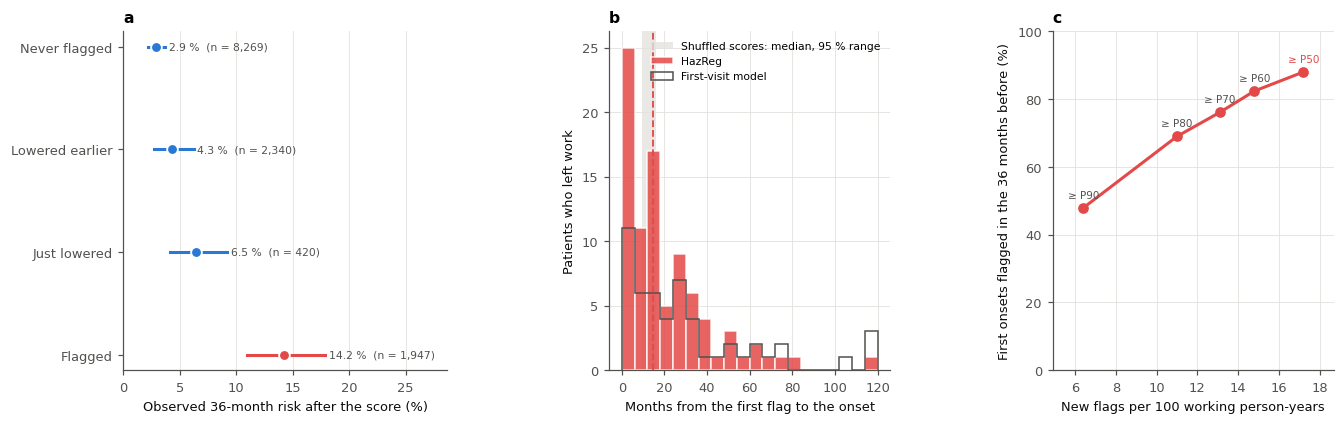

**What this means.**

* **Reach.** Scored every 6 months, the flag (High at the latest score) reaches **62 %** of all
  142 first onsets in the 36 months before them (onsets with no score in that window count as missed), with
  sensitivity 0.64 (0.57 to 0.72) and specificity 0.75 (0.72 to 0.78) in the time-matched evaluation.
* **A flag that falls is a real fall.** At the score after a flag is lowered, the observed 36-month risk is
  6.5 % (4.1-9.2), against 2.9 % (2.2-3.7) for scores never flagged and 14.2 % (11.0-17.9) for flagged scores.
  The risk after lowering is close to that of patients never flagged, so keeping the flag up until two Low scores is not justified by the data:
  kept up, the flag has sensitivity 0.91 (0.86 to 0.96) and specificity 0.32 (0.29 to 0.36).
* **What the lead time measures.** The median time from the flag to the onset is 15 months. With the
  scores shuffled between patients of the same calendar year (so that a patient's flags no longer persist) it is
  13 months (10-16), and a
  score that is never updated (the first-visit model) gives 21 months.
  A long lead time therefore comes from flags that stay up for years in the same patients, which a score computed once does at least as well: it reflects a stable high risk, not a warning that rises before the onset. The model's value is in *who* is flagged (sensitivity 0.64 and specificity 0.75, against 0.50 and 0.47 with shuffled scores), not in *when*.
* **Capacity.** In the recent clinic (about 386 working patients a year in 2015-19), the flag at the Raised
  cut means about 169 flagged
  patients a year and 9.7 new flags
  per onset reached. The table gives the other cut-offs; the clinic can pick by the number of conversations it can
  afford.
* **A second stage sorts the flagged patients.** Among flagged scores with an SF-36 from the past 12 months, PCS below
  40 marks an observed risk of 16.1 % (11.5-21.4) against 10.2 % (4.8-15.7) for PCS of
  40 or more. A short physical-function questionnaire at the flagged visit would tell the clinic whom to
  contact first; 44 % of flagged scores
  had no form, so in this clinic the second stage would mean asking for one.
* **The ranking estimand.** Ranking by the onset hazard alone instead of the cumulative incidence changes the AUROC
  from 0.744 (0.700 to 0.786) to 0.744 (0.700 to 0.786): the competing exits are too rare to reorder patients, so the
  cumulative incidence is kept.

In [106]:
"""Figure: risk after a flag is lowered, lead time against the null, capacity; interpretation."""
fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.0), gridspec_kw={"wspace": 0.55, "width_ratios": [1.15, 1, 1]})
ax = axes[0]
_al = AFTER_LOWER
_short = {"Never flagged in the episode": "Never flagged", "Lowered earlier in the episode": "Lowered earlier",
          "Just lowered (flagged at the previous score)": "Just lowered", "Flagged": "Flagged"}
for i, (g, r) in enumerate(_al.iterrows()):
    o = r["_o"]
    ax.plot([o[1], o[2]], [i, i], color=LEFT_C if g == "Flagged" else KEPT_C, lw=2)
    ax.plot(o[0], i, "o", color=LEFT_C if g == "Flagged" else KEPT_C, ms=7, mec="white", mew=1.2)
    ax.text(o[2] + 0.3, i, f"{o[0]:.1f} %  (n = {r['Scores']:,})", va="center", fontsize=7, color=INK_2)
ax.set_yticks(range(len(_al)), [_short[g] for g in _al.index]); ax.invert_yaxis()
ax.set_xlabel("Observed 36-month risk after the score (%)"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(_al["_o"].map(lambda o: o[2]).max() * 1.6, 1))
ax.set_title("a  After a flag is lowered", loc="left", fontsize=8.5)
ax = axes[1]
_lt_bins = np.arange(0, 126, 6)
ax.axvspan(*[float(x) for x in LEAD_NULL.loc["Lead time, median (months)", "Null, 2.5-97.5 %"].split("-")],
           color=GRID_C, alpha=0.8, lw=0, zorder=0, label="Shuffled scores: median, 95 % range")
ax.hist(np.minimum(LEAD_DEP, 119), bins=_lt_bins, color=LEFT_C, alpha=0.85, edgecolor="white", label="HazReg")
ax.hist(np.minimum(LEAD_FV, 119), bins=_lt_bins, histtype="step", color=INK_2, lw=1.4, label="First-visit model")
ax.axvline(np.median(LEAD_DEP), color=LEFT_C, lw=1.2, ls="--")
ax.set_xlabel("Months from the first flag to the onset"); ax.set_ylabel("Patients who left work")
ax.legend(fontsize=7, loc="upper right"); ax.set_title("b  Lead time", loc="left", fontsize=8.5)
ax = axes[2]
_dc = DEPLOY_CAPACITY
ax.plot(_dc["New flags per 100 person-years"], _dc["All first onsets reached (%)"], "-o", color=LEFT_C)
for q, r in _dc.iterrows():
    ax.text(r["New flags per 100 person-years"], r["All first onsets reached (%)"] + 3, f"≥ P{q:g}", fontsize=6.8,
            ha="center", color=LEFT_C if q == round(100 * REL_TIER_SHARES[0]) else INK_2)
ax.set_xlim(_dc["New flags per 100 person-years"].min() - 1.5, _dc["New flags per 100 person-years"].max() + 1.5)
ax.set_xlabel("New flags per 100 working person-years"); ax.set_ylabel("First onsets flagged in the 36 months before (%)")
ax.set_ylim(0, 100); ax.set_title("c  Capacity", loc="left", fontsize=8.5)
save_fig("deploy01_flag_capacity")

_hits_main = (((PT_EVAL["M"] @ _fl_dep.astype(float)) > 0)[PT_EVAL["case_ent"]]).sum()
_kept = pt_summary(PT_EVAL, _p_dep, alarm_flags(_p_dep, ALARM_VARIANTS["Raised or High, kept up until Low twice"]), burden=False)[0]
_lo_o, _nv_o, _fl_o = (AFTER_LOWER.loc[g, "_o"] for g in ["Just lowered (flagged at the previous score)",
                                                          "Never flagged in the episode", "Flagged"])
_s2a, _s2b = STAGE2.loc[f"Flagged, PCS < {PCS_STAGE2_CUT}"], STAGE2.loc[f"Flagged, PCS ≥ {PCS_STAGE2_CUT}"]
_ci_txt = lambda o: f"{o[0]:.1f} % ({o[1]:.1f}-{o[2]:.1f})"
_ph_ = PT_RES["HazReg"]
DEPLOY_HEADLINE = (f"sensitivity {fmt(_ph_['Sensitivity'], 2)}, specificity {fmt(_ph_['Specificity'], 2)}, "
                   f"{100 * _hits_main / _n_first_d:.0f} % of all first onsets flagged in the 36 months before")
_lead_null_lo, _lead_null_hi = (float(x) for x in LEAD_NULL.loc["Lead time, median (months)", "Null, 2.5-97.5 %"].split("-"))
_lead_obs = LEAD_NULL.loc["Lead time, median (months)", "Observed"]
_lead_fv = float(np.median(LEAD_FV)) if len(LEAD_FV) else np.nan
say(f"""
**What this means.**

* **Reach.** Scored every 6 months, the flag ({RULE_NAME}) reaches **{100 * _hits_main / _n_first_d:.0f} %** of all
  {_n_first_d} first onsets in the 36 months before them (onsets with no score in that window count as missed), with
  sensitivity {fmt(_ph_['Sensitivity'], 2)} and specificity {fmt(_ph_['Specificity'], 2)} in the time-matched evaluation.
* **A flag that falls is a real fall.** At the score after a flag is lowered, the observed 36-month risk is
  {_ci_txt(_lo_o)}, against {_ci_txt(_nv_o)} for scores never flagged and {_ci_txt(_fl_o)} for flagged scores.
  {"The risk after lowering is close to that of patients never flagged, so keeping the flag up until two Low scores is not justified by the data" if _lo_o[0] < (_nv_o[0] + _fl_o[0]) / 2 else "The risk after lowering stays well above that of patients never flagged, so a flag should stay up until the risk has been Low twice"}:
  kept up, the flag has sensitivity {fmt(_kept['Sensitivity'], 2)} and specificity {fmt(_kept['Specificity'], 2)}.
* **What the lead time measures.** The median time from the flag to the onset is {_lead_obs:.0f} months. With the
  scores shuffled between patients of the same calendar year (so that a patient's flags no longer persist) it is
  {LEAD_NULL.loc['Lead time, median (months)', 'Null, mean']:.0f} months ({_lead_null_lo:.0f}-{_lead_null_hi:.0f}), and a
  score that is never updated (the first-visit model) gives {_lead_fv:.0f} months.
  {"A long lead time therefore comes from flags that stay up for years in the same patients, which a score computed once does at least as well: it reflects a stable high risk, not a warning that rises before the onset. The model's value is in *who* is flagged (sensitivity " + format(LEAD_NULL.loc['Sensitivity', 'Observed'], '.2f') + " and specificity " + format(LEAD_NULL.loc['Specificity', 'Observed'], '.2f') + ", against " + format(LEAD_NULL.loc['Sensitivity', 'Null, mean'], '.2f') + " and " + format(LEAD_NULL.loc['Specificity', 'Null, mean'], '.2f') + " with shuffled scores), not in *when*." if _lead_fv >= _lead_obs else "The updated score flags earlier than a score computed once, so part of the lead time is a warning that the updates carry."}
* **Capacity.** In the recent clinic (about {_pts_year_d:.0f} working patients a year in 2015-19), the flag at the Raised
  cut means about {DEPLOY_CAPACITY.loc[round(100 * REL_TIER_SHARES[0]), 'Patients flagged per year, 2015-19']:.0f} flagged
  patients a year and {DEPLOY_CAPACITY.loc[round(100 * REL_TIER_SHARES[0]), 'New flags per onset reached']:.1f} new flags
  per onset reached. The table gives the other cut-offs; the clinic can pick by the number of conversations it can
  afford.
* **A second stage sorts the flagged patients.** Among flagged scores with an SF-36 from the past 12 months, PCS below
  {PCS_STAGE2_CUT} marks an observed risk of {_ci_txt(_s2a['_o'])} against {_ci_txt(_s2b['_o'])} for PCS of
  {PCS_STAGE2_CUT} or more. A short physical-function questionnaire at the flagged visit would tell the clinic whom to
  contact first; {100 * STAGE2.loc['Flagged, no SF-36', 'Scores'] / STAGE2.loc['Flagged', 'Scores']:.0f} % of flagged scores
  had no form, so in this clinic the second stage would mean asking for one.
* **The ranking estimand.** Ranking by the onset hazard alone instead of the cumulative incidence changes the AUROC
  from {RANK_CHECK.iloc[0, 0]} to {RANK_CHECK.iloc[1, 0]}: the competing exits are too rare to reorder patients, so the
  cumulative incidence is kept.
""")

---
# Part VII. Checks that do not depend on the analysts

> **Why this part exists.** Everything above was done by the people who built the model. However careful, that is
> not independent evidence. The checks below are, or prepare for it. This part produces the material each one needs and reads
> the results back automatically once they exist.

1. **A frozen model and a future test** (7.1). The final model is written to a file whose SHA-256 hash can be
   registered publicly (for example on OSF) before new data exist. When the clinic issues its next extract, the
   visits after the freeze date are scored with that file and nothing else. This is the only truly prospective
   validation available, and nobody can tune it.
2. **Chart adjudication and linkage of the outcome** (7.2, 7.2.1). A clinician blinded to the model reviews a stratified sample of
   onsets and non-onsets in the chart, within calendar eras. Agreement with the algorithm (κ, PPV, NPV) measures how
   often the outcome is right, and the sensitivity of the record *by era* is what corrects the absolute level
   (Section 5.2.6).
3. **The clinicians' own judgement** (7.3). Rheumatologists estimate the 36-month risk for a sample of visits
   from the same routine fields. If the model does not beat them, it adds nothing to the clinic.
4. **The measures the clinic database holds but this extract does not** (7.4). These are SF-36, the fatigue
   severity scale and patient global, the yearly health-care and work-productivity questionnaire (absence days,
   at-work impairment, self-rated ability to work), the full blood count, albumin, urine protein/creatinine, and
   the social-factor form. When the tables are placed in the `requested` folder, their added value is tested
   block by block with the same validation.
5. **The clinic's judgement of when a referral is worth it, and patient involvement** (7.5): templates whose answers
   set the decision curve's range of exchange rates and the tool's wording.
6. **A model card and the software versions** (7.6), for releasing the tool with its analysis.

## 7.1 The frozen model

The file holds the final model as developed, with **no update of its baseline** (Section 4.5), the relative-tier
cut-offs and the reference risk, and the patient flag (Section 2.5) expressed in the same risk units, scored every 6
months (Section 6.9). A future
extract is scored with these alone. The model has no calendar term; the absolute risk it returns is labelled as the risk
under the average recording of the development years. Each score comes with the inputs that drive it (Section 6.7.2).

In [107]:
"""Frozen model: everything needed to compute a risk, in one hashed file; a scorer that reads only that file."""
FREEZE_DATE = str(DATA_END_DATE.date())
CUTS_FULL = np.quantile(P_FULL, REL_TIER_SHARES)                  # the final model's own development percentiles
REF_RISK_FULL = float(np.median(P_FULL))
FROZEN = {"name": "HazReg", "tag": TAG, "freeze_date": FREEZE_DATE, "horizon_months": H,
          "risk": "cumulative incidence of onset under piecewise-constant cause-specific hazards: l_k,b = exp(intercept_k + "
                  "x . coef_k + baseline_log_multipliers[k][b]) per year in band b of time since the landmark, integrated over "
                  "the bands; within a band of width t starting with survival S the increment is "
                  "S*l1/(l1+l2)*(1-exp(-(l1+l2)*t))",
          "baseline_band_starts_months": BASELINE_EDGES, "baseline_log_multipliers": FINAL["base"].tolist(),
          "preprocessing": FINAL["prep"].to_dict(), "terms": FINAL["prep"].names,
          "coef_onset": FINAL["coef"][0].tolist(), "coef_competing": FINAL["coef"][1].tolist(),
          "intercept": FINAL["intercept"].tolist(), "ridge_alpha": FINAL["alphas"],
          "calendar_reference_year": FINAL.get("cal_ref"),
          "recency_half_life_months": FINAL.get("half_life"),
          "recency": "for a half-life > 0, each input of recency_items is its recency-weighted mean over the visits of the "
                     f"{RECENCY_WINDOW_MONTHS} months before the landmark (recency_features), and recency_extras are added",
          "recency_items": DECAY_ITEMS, "recency_extras": RECENCY_EXTRAS,
          "pro_imputation": PRO_IMP,
          "pcs_input": f"{PCS_INPUT}: the SF-36 PCS of a form completed in the {SF36_VALID_DAYS / 365.25:.0f} year(s) before the "
                       "visit (clinic database or REDCap, same scoring); without one, predicted by pcs_imputation (add_pcs_input)",
          "calendar": "CAL_YEAR is set to calendar_reference_year (the latest year of the development data) and COVID to 0 "
                      "for every visit scored",
          "landmarks": f"developed on one prediction every {LANDMARK_EVERY_MONTHS} months from the first employed visit, from "
                       f"the inputs of the last employed visit in the {LANDMARK_MAX_STALE_MONTHS} months before; age, disease "
                       "duration and years in clinic moved forward to the landmark date",
          "scoring_in_use": f"every {LANDMARK_EVERY_MONTHS} months from the first employed visit, as developed (same input rule)",
          "baseline_update": "none: the baseline is not recalibrated to the recorded level of recent years",
          "absolute_risk_label": "36-month risk under the average outcome recording of the development years",
          "relative_tiers": {"labels": REL_TIER_LABELS, "development_percentiles": REL_TIER_SHARES,
                             "risk_cutoffs": CUTS_FULL.tolist(), "reference_risk_median_visit": REF_RISK_FULL,
                             "relative_risk": "risk / reference_risk_median_visit"},
          "patient_alarm": {"name": RULE_NAME, "rule_on_percentiles": ALARM_RULE,
                            "risk_cutoffs": {k: float(np.quantile(P_FULL, ALARM_RULE[k])) for k in ("on", "off", "high")
                                             if ALARM_RULE.get(k) is not None},
                            "rule": f"{RULE_NAME} (percentiles of the development landmarks; risk_cutoffs on the risk scale); "
                                    "High (relative_tiers) is contacted first",
                            "second_stage": f"where an SF-36 from the past 12 months exists, PCS < {PCS_STAGE2_CUT} marks the "
                                            "flagged patients to contact first (Section 6.9)"},
          "development": {"landmarks": int(N_LAND), "patients": int(P_N), "onsets": int(D1_ALL.sum()), "onsets_in_the_fit": int(D1.sum()),
                          "person_years": round(float(INT_YRS_ALL.sum()), 1), "person_years_in_the_fit": round(float(INT_YRS.sum()), 1)},
          "source_sha256": source_hashes()}
FROZEN_JSON = json.dumps(FROZEN, sort_keys=True, indent=1)
FROZEN_HASH = hashlib.sha256(FROZEN_JSON.encode()).hexdigest()
FROZEN_PATH = f"frozen_model_{TAG}.json"
if not SMOKE:
    with open(FROZEN_PATH, "w") as f:
        f.write(FROZEN_JSON)


def score_frozen(frozen, X):
    """36-month risk (under the average recording of the development years), relative risk and relative tier (0 Low ... 3 High) from
    the frozen file alone (X: one row per visit, raw inputs)."""
    M = _frozen_design(frozen, X)
    eta = np.column_stack([M @ np.array(frozen[k]) + frozen["intercept"][i]
                           for i, k in enumerate(["coef_onset", "coef_competing"])])
    risk = cif(eta, frozen["horizon_months"], base=np.array(frozen["baseline_log_multipliers"]))
    rt = frozen["relative_tiers"]
    return risk, risk / rt["reference_risk_median_visit"], np.digitize(risk, rt["risk_cutoffs"])


def frozen_drivers(frozen, X, n=3):
    """For each visit, the n inputs that raise the onset hazard most against the average development landmark (Section 6.7.2)."""
    c = _frozen_design(frozen, X) * np.array(frozen["coef_onset"])
    d = pd.DataFrame(c, columns=[t.split("__")[0] for t in frozen["terms"]]).T.groupby(level=0, sort=False).sum().T
    return [", ".join(f"{DISPLAY.get(k, k)} (x{np.exp(v):.2f})" for k, v in r.nlargest(n).items() if v > 0) for _, r in d.iterrows()]


def _frozen_design(frozen, X):
    """The design matrix of the frozen model for raw inputs X."""
    pp = frozen["preprocessing"]
    if frozen.get("calendar_reference_year") is not None:
        X = X.assign(CAL_YEAR=float(frozen["calendar_reference_year"]), COVID=0.0)
    X = recency_frame(X, frozen.get("recency_half_life_months"))      # X carries the recency_features columns
    Z = pd.DataFrame(index=X.index)
    for c in pp["cols"]:
        x = X[c].astype(float)
        Z[c] = np.sign(x) * np.log1p(np.abs(x)) if c in pp["log1p"] else x
    miss = Z[pp["missing_indicators"]].isna().astype(float)
    Z = Z.fillna(pd.Series(pp["median"]))
    for c, kn in pp["knots"].items():
        Z[f"{c}__NL"] = rcs_nl(Z[c].values, kn)
    Z = ((Z - pd.Series(pp["mean"])) / pd.Series(pp["sd"])).clip(-pp["clip_z"], pp["clip_z"])
    M = np.hstack([Z[[t for t in frozen["terms"] if not t.endswith("__MISSING")]].values, miss.values])
    return M * np.array(pp["block_scale"])[None, :]


_chk, _chk_rr, _chk_tier = score_frozen(json.loads(FROZEN_JSON), LAND_X)
assert np.allclose(_chk, P_FULL, atol=1e-10), "the frozen file does not reproduce the final model"
print(f"Frozen model {'(not written in a smoke run) ' if SMOKE else FROZEN_PATH + ' '}| freeze date {FREEZE_DATE} | "
      f"SHA-256 {FROZEN_HASH}\nThe file alone reproduces the final model's risks on all {N_LAND:,} landmarks "
      f"(max difference {np.abs(_chk - P_FULL).max():.1e}); its tiers agree with the relative tiers at "
      f"{100 * np.mean(_chk_tier == rel_tier(P_FULL)):.1f} % of landmarks. No baseline shift is stored.")


def prospective_validation(new_source_dir, frozen_path=FROZEN_PATH):
    """Run on a LATER extract (same table layout). Scores every landmark after the freeze date with the frozen file,
    writes the predictions with a timestamp, and evaluates them on whatever 36-month follow-up exists."""
    frozen = json.load(open(frozen_path))
    assert hashlib.sha256(json.dumps(frozen, sort_keys=True, indent=1).encode()).hexdigest() == FROZEN_HASH, \
        "the frozen file has changed since it was registered"
    v_new = build_visits(new_source_dir)
    v_new = add_pro_inputs(v_new, frozen["pro_imputation"])
    l_new = landmarks_every(build_landmarks(v_new))
    end_new = v_new["ASSDT"].max()
    l_new["entry_era"] = era_of(l_new.groupby("pid")["visit_date"].transform("min"))
    l_new = l_new[l_new["visit_date"] > pd.Timestamp(frozen["freeze_date"])].reset_index(drop=True)
    l_new["calendar_era"] = era_of(l_new["visit_date"])
    if not len(l_new):
        print("No landmark after the freeze date in this extract.")
        return None
    X = v_new.loc[l_new["visit_row"], [c for c in frozen["preprocessing"]["cols"]
                                       if c not in CALENDAR_VARS + RECENCY_EXTRAS]].reset_index(drop=True)
    for c in LANDMARK_TIME_VARS:
        if c in X:
            X[c] = X[c] + l_new["gap_days"].values / 365.25
    _rf_new = recency_features(l_new, v_new)
    for c in _rf_new.columns:
        X[c] = _rf_new[c].values
    l_new["risk_24m_dev_recording"], l_new["relative_risk"], tier = score_frozen(frozen, X)
    l_new["tier"] = np.array(frozen["relative_tiers"]["labels"])[tier]
    l_new["top_drivers"] = frozen_drivers(frozen, X)
    out = f"prospective_predictions_{pd.Timestamp.now():%Y%m%d}.csv"
    l_new[["pid", "visit_date", "entry_era", "calendar_era", "risk_24m_dev_recording", "relative_risk", "tier", "top_drivers"]] \
        .to_csv(out, index=False)
    print(f"Tier shares among the new visits (development: {REL_TIER_DESC}):",
          (l_new["tier"].value_counts(normalize=True) * 100).round(1).to_dict())
    t, c = l_new["time_days"].values.astype(float), l_new["cause"].values
    age = v_new.loc[l_new["visit_row"], "age_at_record"].values + l_new["gap_days"].values / 365.25
    adm = np.minimum((end_new - l_new["visit_date"]).dt.days.values, (AGE_CAP_YEARS - age) * 365.25)
    y, w = ipcw_weights(t, c)
    print(f"{len(l_new):,} landmarks after {frozen['freeze_date']} ({l_new['pid'].nunique():,} patients) -> {out}; "
          f"{int((adm >= HORIZON_DAYS).sum()):,} have 36 months of potential follow-up; onsets within 36 months "
          f"{int((y * (w > 0)).sum())}")
    if (y * (w > 0)).sum() >= 10:
        A = metric_arrays(l_new["risk_24m_dev_recording"].values, np.ones((1, len(l_new))), y, w,
                          np.full(len(l_new), "prospective"))
        print(f"Prospective: AUROC {A['AUROC'][0]:.3f}; O/E against the development recording {A['O/E'][0]:.2f} "
              f"(a level, not a test: see Part IV)")
    return l_new


print("When the next extract arrives: prospective_validation('<folder of the new extract>').")

Frozen model frozen_model_risk_stratification.json | freeze date 2020-02-29 | SHA-256 853ca65ac1f030bd2c77b87b0885dbcad9095e9561c7ef762691381b5921655d
The file alone reproduces the final model's risks on all 12,976 landmarks (max difference 4.4e-16); its tiers agree with the relative tiers at 100.0 % of landmarks. No baseline shift is stored.
When the next extract arrives: prospective_validation('<folder of the new extract>').


## 7.2 Chart adjudication of the outcome

A stratified sample, **within three calendar eras** (before 2010, 2010-14, from 2015): onsets by route, and
non-onsets of four kinds (a competing exit; censored after leaving the clinic while employed; followed for ≥ 24
months without an onset; and a status of *employed* unchanged for more than 3 years in a patient still attending,
the stale records of Section 5.2.3). Each row carries its era and its sampling weight, so that the sensitivity and
PPV of the recorded outcome can be estimated era by era (Section 5.2.6). For each sampled episode the file lists the
patient, the landmark, the algorithm's classification and the status sequence around it, with empty columns for
the reviewer. The reviewer works from the chart, blinded to the algorithm's class: hide those columns before
review. The file is written once and never overwritten. A completed copy saved as `..._reviewed.csv` is read
back.

In [108]:
"""Adjudication sample (written once) and agreement once reviewed."""
ADJ_PATH = f"adjudication_sample_{TAG}.csv"
ADJ_REVIEWED = ADJ_PATH.replace(".csv", "_reviewed.csv")


def _status_string(pid, center, before_y=2, after_y=3):
    s = visits.loc[(visits["PTNO"] == pid) & visits["HAS_STATUS"], ["ASSDT", "EMP"]]
    s = s[(s["ASSDT"] >= center - pd.DateOffset(years=before_y)) & (s["ASSDT"] <= center + pd.DateOffset(years=after_y))]
    return "; ".join(f"{d:%Y-%m-%d} {e}" for d, e in zip(s["ASSDT"], s["EMP"]))


if not os.path.exists(ADJ_PATH) and not SMOKE:
    rng = np.random.RandomState(SEED + 11)
    first = land.groupby(["pid", "cause", "exit_type"], sort=False).head(1)
    strata = {"onset: direct (disabled)": first[(first["cause"] == 1) & (first["route"] == "direct")],
              "onset: long sick spell": first[(first["cause"] == 1) & (first["route"] == "long sick spell")],
              "onset: short spell then disabled": first[(first["cause"] == 1) & (first["route"] == "short sick spell")],
              "competing exit": first[first["cause"] == 2],
              "censored: left clinic while employed": first[first["pid"].isin(LEFT_CLINIC_PIDS) & (first["cause"] == 0)],
              "event-free >= 36 months": land[(Y24 == 0) & (C_ALL == 0)].groupby("pid").head(1),
              "stale: employed unchanged > 3 years, still attending":
                  land[_unver_at & ~np.isin(PID_ALL, list(LEFT_CLINIC_PIDS))].groupby("pid").tail(1)}
    n_take = {"onset: direct (disabled)": 8, "onset: long sick spell": 8, "onset: short spell then disabled": 4,
              "competing exit": 7, "censored: left clinic while employed": 7, "event-free >= 36 months": 7,
              "stale: employed unchanged > 3 years, still attending": 10}       # per era
    _era3 = lambda d: pd.cut(d.dt.year, [1970, 2010, 2015, 2100], right=False, labels=["< 2010", "2010-14", ">= 2015"])
    rows = []
    for s, d in strata.items():
        d = d.drop_duplicates("pid").copy()
        _ref = d["visit_date"] if s.startswith("stale") else \
            d["event_date"].where(d["event_date"].notna(), d["visit_date"] + pd.to_timedelta(d["time_days"], unit="D"))
        d["era"] = _era3(_ref).astype(str)
        for era, de in d.groupby("era"):
            take = de.iloc[rng.permutation(len(de))[:n_take[s]]]
            for r in take.itertuples():
                center = r.visit_date if s.startswith("stale") else \
                    r.event_date if pd.notna(r.event_date) else r.visit_date + pd.Timedelta(days=r.time_days)
                rows.append({"PTNO": r.pid, "landmark_date": r.visit_date.date(), "stratum": s, "era": era,
                             "sampling_weight": len(de) / max(len(take), 1),
                             "algorithm_onset": int(r.cause == 1),
                             "algorithm_end_date": (r.visit_date + pd.Timedelta(days=r.time_days)).date(),
                             "status_sequence": _status_string(r.pid, center),
                             "reviewer_left_work_for_health": "", "reviewer_date": "", "reviewer_notes": ""})
    pd.DataFrame(rows).sample(frac=1, random_state=SEED).to_csv(ADJ_PATH, index=False)
    print(f"Adjudication sample written: {ADJ_PATH} ({len(rows)} episodes).")
# a second, independent reviewer for a share of the sample (inter-rater reliability), added to a file not yet reviewed
_R2_COLS = ["reviewer2_left_work_for_health", "reviewer2_date"]
if os.path.exists(ADJ_PATH) and not os.path.exists(ADJ_REVIEWED):
    _adj = pd.read_csv(ADJ_PATH)
    if not set(_R2_COLS) <= set(_adj.columns) and _adj["reviewer_left_work_for_health"].isna().all():
        _r2 = np.random.RandomState(SEED + 12).rand(len(_adj)) < 0.3
        _adj["second_review"] = np.where(_r2, "yes", "")
        for c in _R2_COLS:
            _adj[c] = ""
        _adj.to_csv(ADJ_PATH, index=False)
        print(f"Second-reviewer columns added to {ADJ_PATH}: {int(_r2.sum())} episodes marked for an independent second review.")


def _kappa(a, b):
    a, b = np.asarray(a, int), np.asarray(b, int)
    po = (a == b).mean()
    pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return po, (po - pe) / (1 - pe) if pe < 1 else np.nan


def adjudication_summary(a):
    """Agreement of the algorithm with the reviewer (and of two reviewers), the PPV and NPV of the recorded outcome
    by era (weighted by the sampling weights), and the dating error of confirmed onsets."""
    a = a.dropna(subset=["reviewer_left_work_for_health"]).copy()
    yr, ya = a["reviewer_left_work_for_health"].astype(int).values, a["algorithm_onset"].astype(int).values
    po, k = _kappa(yr, ya)
    out = {"Episodes reviewed": len(a), "Agreement, algorithm vs reviewer": po, "Kappa, algorithm vs reviewer": k,
           "PPV of the recorded onset (unweighted)": yr[ya == 1].mean(), "NPV (unweighted)": 1 - yr[ya == 0].mean()}
    if "reviewer2_left_work_for_health" in a.columns:
        b = a.dropna(subset=["reviewer2_left_work_for_health"])
        if len(b) >= 5:
            po2, k2 = _kappa(b["reviewer_left_work_for_health"], b["reviewer2_left_work_for_health"])
            out |= {"Episodes with two reviews": len(b), "Kappa between reviewers": k2}
    both = (ya == 1) & (yr == 1) & a["reviewer_date"].notna().values
    if both.any():
        err = (pd.to_datetime(a["reviewer_date"][both]) - pd.to_datetime(a["algorithm_end_date"][both])).dt.days / MONTH_DAYS
        out |= {"Onset dating: reviewer − algorithm, median (months)": float(err.median()),
                "Onset dating: |difference| ≤ 6 months (%)": float(100 * (err.abs() <= 6).mean())}
    return pd.Series(out)


if os.path.exists(ADJ_REVIEWED):
    ADJ_SUMMARY = adjudication_summary(pd.read_csv(ADJ_REVIEWED))
    display(ADJ_SUMMARY.round(3).to_frame("Value"))
else:
    ADJ_SUMMARY = None
    print(f"Not yet adjudicated: complete {ADJ_PATH} and save it as {ADJ_REVIEWED}. Sample stratified: the per-era "
          f"sensitivity and PPV of Section 5.2.6 use the sampling weights.")
if SMOKE:                                            # code check only: a synthetic review, never reported
    _fake = pd.DataFrame({"reviewer_left_work_for_health": [1, 0, 1, 1, 0, 0], "algorithm_onset": [1, 0, 0, 1, 1, 0],
                          "reviewer_date": ["2010-01-01", None, None, "2012-06-01", None, None],
                          "algorithm_end_date": ["2010-03-01", "2011-01-01", "2011-01-01", "2012-01-01", "2013-01-01", "2014-01-01"],
                          "reviewer2_left_work_for_health": [1, 0, 1, 0, 0, 0]})
    print("SMOKE check of adjudication_summary (synthetic):", dict(adjudication_summary(_fake).round(2)))

Not yet adjudicated: complete adjudication_sample_risk_stratification.csv and save it as adjudication_sample_risk_stratification_reviewed.csv. Sample stratified: the per-era sensitivity and PPV of Section 5.2.6 use the sampling weights.


### 7.2.1 Linkage of the outcome to administrative data

> **Why.** Every analysis above reads the outcome from one field of the clinic's form, and Section 1.5.6 shows that
> the field stopped being updated. Chart review (7.2) checks a sample; **linkage checks every patient**, independently
> of the clinic's recording, and is the only way to separate a true fall in work disability from a fall in its
> recording (Part IV).

**What to request.** The sources below record work disability or loss of earnings independently of the clinic.
Their availability for this cohort, the approvals and the linkage keys (health card number, date of birth, sex)
have to be confirmed with the data custodians; the list is the analysis plan, not a statement of access.

| Source (custodian) | What it records | Used as |
|:--|:--|:--|
| Ontario Disability Support Program (Ministry of Children, Community and Social Services; via ICES where available) | Start and end of disability income support | Onset: start of benefits |
| Canada Pension Plan Disability benefit (Employment and Social Development Canada; via the Statistics Canada Social Data Linkage Environment) | Start of a federal disability pension | Onset: date of eligibility |
| T1 / T4 tax records (Statistics Canada) | Employment income by year | Onset: employment income falling by ≥ 50 % from the patient's own average and staying down; a sensitivity definition |
| Registered Persons Database (ICES) | Death, emigration, residence in Ontario | Censoring: who left the province or died, against who only left the clinic |
| OHIP physician claims, CIHI hospital discharges (ICES) | Contact with the health system after the patient stopped attending | Censoring: patients lost to the clinic but still in care elsewhere |

**How it is used once received** (a file `linked_outcome.csv` in the `requested` folder, one row per patient and
source: `PTNO`, `source`, `onset_date`; patients linked without an onset have an empty date, and a file of linked
patients defines who could have been found):

1. **Agreement** between the clinic record and the linked outcome over each landmark's 36-month window: the
   sensitivity and PPV of the clinic record, by era. This measures directly how much recording fell.
2. **Dating**: linked onset date − clinic onset date.
3. **The model against the linked outcome**: the cross-validated HazReg risks scored against the linked 36-month
   outcome, and against either outcome. If the ranking holds against an outcome the clinic did not record, it does
   not depend on how the clinic recorded it.

In [109]:
"""Linkage of the outcome: agreement with the clinic record, dating, and the model scored against the linked outcome."""
from sklearn.metrics import roc_auc_score


def linked_labels(lk):
    """The linked 36-month outcome at every landmark of the linked patients: 1 if a linked onset falls within the
    landmark's 36 months, 0 if not (patients linked without an onset in the window), NaN for unlinked patients."""
    lk = lk.copy()
    lk["onset_date"] = pd.to_datetime(lk["onset_date"])
    first = lk.dropna(subset=["onset_date"]).groupby("PTNO")["onset_date"].min()
    linked = set(lk["PTNO"])
    y = np.full(N_LAND, np.nan)
    on_t = np.array([(first[p] - pd.Timestamp("1970-01-01")).days if p in first.index else np.inf for p in PID_ALL], float)
    ok = np.isin(PID_ALL, list(linked)) & (on_t >= LAND_T)        # an onset before the landmark: not at risk by this source
    y[ok] = ((on_t[ok] - LAND_T[ok]) <= HORIZON_DAYS).astype(float)
    return y, on_t


def linkage_report(lk, p=None):
    p = P_CV["HazReg"] if p is None else p
    y_l, on_t = linked_labels(lk)
    y_c = Y24
    both = ~np.isnan(y_l) & ~np.isnan(y_c)
    era = ERA_LAB[both]
    rows = []
    for e in list(dict.fromkeys(era)) + ["All"]:
        k = np.ones(both.sum(), bool) if e == "All" else era == e
        yl, yc = y_l[both][k], y_c[both][k]
        rows.append({"Era": e, "Landmarks": int(k.sum()), "Linked onsets": int(yl.sum()), "Clinic onsets": int(yc.sum()),
                     "Sensitivity of the clinic record": yc[yl == 1].mean() if (yl == 1).any() else np.nan,
                     "PPV of the clinic record": yl[yc == 1].mean() if (yc == 1).any() else np.nan})
    agree = pd.DataFrame(rows).set_index("Era")
    k = ~np.isnan(y_l)
    auc = {"Linked outcome": roc_auc_score(y_l[k], p[k]) if len(np.unique(y_l[k])) == 2 else np.nan}
    y_e = np.where(np.isnan(y_c), y_l, np.fmax(y_l, y_c))
    k2 = ~np.isnan(y_e)
    auc["Either outcome"] = roc_auc_score(y_e[k2], p[k2]) if len(np.unique(y_e[k2])) == 2 else np.nan
    ev = (C_ALL == 1) & np.isfinite(on_t)
    dating = pd.Series((on_t[ev] - (LAND_T[ev] + T_ALL[ev])) / MONTH_DAYS).groupby(PID_ALL[ev]).first()
    return agree, pd.Series(auc), dating


_lk_path = os.path.join(REQUEST_DIR, LINKED_OUTCOME_FILE)
if os.path.exists(_lk_path):
    LINK_AGREE, LINK_AUC, LINK_DATING = linkage_report(pd.read_csv(_lk_path))
    display(LINK_AGREE.round(2)); display(LINK_AUC.round(3).to_frame("AUROC of HazReg (cross-validated)"))
    print(f"Dating, linked − clinic onset: median {LINK_DATING.median():+.1f} months (IQR "
          f"{LINK_DATING.quantile(0.25):+.1f} to {LINK_DATING.quantile(0.75):+.1f}).")
else:
    LINK_AGREE = None
    print(f"No linked outcome yet: place {LINKED_OUTCOME_FILE} (PTNO, source, onset_date) in {REQUEST_DIR}.")
if SMOKE:                                            # code check only: a synthetic linkage built from the clinic record
    _r = np.random.RandomState(1)
    _ev_p = land.loc[C_ALL == 1, ["pid", "event_date"]].drop_duplicates("pid")
    _fk = pd.concat([pd.DataFrame({"PTNO": _ev_p["pid"], "source": "synthetic", "onset_date": _ev_p["event_date"]
                                   + pd.to_timedelta(_r.randint(-200, 200, len(_ev_p)), unit="D")}),
                     pd.DataFrame({"PTNO": [p for p in ALL_PIDS[:200] if p not in set(_ev_p["pid"])], "source": "synthetic",
                                   "onset_date": pd.NaT})])
    _a_, _u_, _d_ = linkage_report(_fk)
    print("SMOKE check of linkage_report (synthetic):", _a_.loc["All"].round(2).to_dict(), _u_.round(3).to_dict())

No linked outcome yet: place linked_outcome.csv (PTNO, source, onset_date) in /Users/javimencia/Desktop/ReSTORE Lab/SLE Toronto Western/SLE SUDS/dataset/requested.


## 7.3 The clinicians' judgement as a comparator

120 landmark visits from different patients: 40 followed by an onset within 36 months and 80 with a known
36-month status and no onset. Each case shows the same fields the model reads, under a random case number. One or
more rheumatologists enter a 36-month risk (%) for each. The key linking case numbers to visits is a separate
file. The comparison is paired, on the same cases.

In [110]:
"""Clinician comparator: export once, compare once completed."""
CLIN_PATH, CLIN_KEY = f"clinician_cases_{TAG}.csv", f"clinician_key_{TAG}.csv"
CLIN_DONE = CLIN_PATH.replace(".csv", "_completed.csv")
if not os.path.exists(CLIN_PATH) and not SMOKE:
    rng = np.random.RandomState(SEED + 13)
    known = np.flatnonzero(~np.isnan(Y24))
    pick = []
    for yv, n in [(1, 40), (0, 80)]:
        cand = known[Y24[known] == yv]
        cand = cand[rng.permutation(len(cand))]
        seen = set()
        for i in cand:
            if PID_ALL[i] not in seen and PID_ALL[i] not in {PID_ALL[j] for j in pick}:
                pick.append(i); seen.add(PID_ALL[i])
            if len(seen) == n:
                break
    pick = rng.permutation(pick)
    cases = LAND_X.iloc[pick][COMPACT_VARS].copy()
    cases.columns = [DISPLAY[c] for c in COMPACT_VARS]
    cases.insert(0, "Sex", np.where(land["SEX_FEMALE"].values[pick] == 1, "F", "M"))
    cases.insert(0, "case", np.arange(1, len(pick) + 1))
    cases["clinician_risk_percent"] = ""
    cases.round(2).to_csv(CLIN_PATH, index=False)
    pd.DataFrame({"case": np.arange(1, len(pick) + 1), "landmark_row": pick}).to_csv(CLIN_KEY, index=False)
    print(f"Clinician cases written: {CLIN_PATH} (key: {CLIN_KEY}).")
if os.path.exists(CLIN_DONE) and os.path.exists(CLIN_KEY):
    cd_ = pd.read_csv(CLIN_DONE).merge(pd.read_csv(CLIN_KEY), on="case").dropna(subset=["clinician_risk_percent"])
    r_ = cd_["landmark_row"].values
    yv, pc, pm = Y24[r_], cd_["clinician_risk_percent"].values.astype(float), P_MAIN[r_]
    rng = np.random.RandomState(SEED)
    Wc = np.vstack([np.ones(len(r_)), rng.multinomial(len(r_), np.full(len(r_), 1 / len(r_)), 1000)])
    ac, am = wauc(yv, pc, Wc), wauc(yv, pm, Wc)
    d = am - ac
    print(f"{len(r_)} cases: clinician AUROC {ac[0]:.3f}, model AUROC {am[0]:.3f}, model - clinician {d[0]:+.3f} "
          f"(95% CI {np.percentile(d[1:], 2.5):+.3f} to {np.percentile(d[1:], 97.5):+.3f})")
else:
    print(f"Not yet completed: fill {CLIN_PATH} (column clinician_risk_percent) and save it as {CLIN_DONE}.")

Not yet completed: fill clinician_cases_risk_stratification.csv (column clinician_risk_percent) and save it as clinician_cases_risk_stratification_completed.csv.


## 7.4 Measures held by the clinic database but not in this extract

Each table, once delivered, gives one **block** of at most three variables. The most recent value
before the landmark is used: within 18 months for the yearly questionnaires, within 12 months for visit-level
tables. Each block is tested on the landmarks where it exists, with HazReg against HazReg + block in the same
cross-validation (5-fold × 2), paired.

In [111]:
"""Requested tables: specification, features, added value (runs only when the tables are present)."""
REQUEST_DIR = os.environ.get("SLE_REQUEST_DIR", REQUEST_DIR)
RAND = {"PF": (["LIMITVA", "LIMITMA", "LIMITLC", "LIMITSF", "LIMITOF", "LIMITBK", "LIMITKM", "LIMITSB", "LIMITOB",
                "LIMITBD"], {1: 0, 2: 50, 3: 100}, {}),
        "VT": (["TMPEP", "TMENER"], {1: 100, 2: 80, 3: 60, 4: 40, 5: 20, 6: 0},
               {"TMWORN": {1: 0, 2: 20, 3: 40, 4: 60, 5: 80, 6: 100}, "TMTIRE": {1: 0, 2: 20, 3: 40, 4: 60, 5: 80, 6: 100}}),
        "MH": (["TMCALM", "TMHAPP"], {1: 100, 2: 80, 3: 60, 4: 40, 5: 20, 6: 0},
               {c: {1: 0, 2: 20, 3: 40, 4: 60, 5: 80, 6: 100} for c in ["TMNERV", "TMDOWN", "TMBLUE"]})}


def _sf36(d):
    out = pd.DataFrame(index=d.index)
    for dom, (items, code, extra) in RAND.items():
        parts = [pd.to_numeric(d[c], errors="coerce").map(code) for c in items if c in d]
        parts += [pd.to_numeric(d[c], errors="coerce").map(m) for c, m in extra.items() if c in d]
        out[f"SF36_{dom}"] = pd.concat(parts, axis=1).mean(axis=1)
    return out


def _fatigue(d):
    items = ["MOTIVATE", "EXERCISE", "EASILY", "INTERFER", "PROBLEMS", "PREVENT", "DUTIES", "DEBILITA", "SOCIAL"]
    x = d[[c for c in items if c in d]].apply(pd.to_numeric, errors="coerce")
    return pd.DataFrame({"FSS_MEAN": x.mean(axis=1).where(x.notna().sum(axis=1) >= 5),
                         "PT_GLOBAL": pd.to_numeric(d.get("GLOBAL"), errors="coerce")})


def _healthc(d):
    num = lambda c: pd.to_numeric(d.get(c), errors="coerce")
    return pd.DataFrame({"ABSENT_DAYS_3M": num("AFW_HEALTH"), "PRESENTEEISM_0_10": num("HEALTH_NEFF_WORK"),
                         "SELF_RATED_UNABLE_FT": ((num("WORK_PT") == 1) | (num("UNABLE_WORK") == 1)).astype(float)
                         .where(num("WORK_FT").notna() | num("WORK_PT").notna() | num("UNABLE_WORK").notna())})


def _lab1(d):
    num = lambda c: pd.to_numeric(d.get(c), errors="coerce")
    return pd.DataFrame({"HGB": num("HGB"), "ALBUMIN": num("ALBUMIN"), "UPCR": num("RPROT_CREAT")})


def _socfact(d):
    num = lambda c: pd.to_numeric(d.get(c), errors="coerce")
    return pd.DataFrame({"HOSP_SINCE_LAST": num("HOSPLV"),
                         "PARTNERED": num("MARITAL").isin([2, 6]).astype(float).where(num("MARITAL").notna())})


REQUESTED = {  # file: (database table, key, date column, feature function, why)
    "sf36.csv": ("SF36", "date", "CLDATE", _sf36, "physical function, vitality, mental health (yearly)"),
    "fatigue.csv": ("FATIGUE", "date", "CLDATE", _fatigue, "fatigue severity scale, patient global (yearly)"),
    "lup_healthc.csv": ("LUP_HEALTHC", "date", "ASSDT", _healthc,
                        "absence days, at-work impairment, self-rated ability to work (yearly, from 2016)"),
    "lab1.csv": ("LAB1", "visit", None, _lab1, "haemoglobin, albumin, urine protein/creatinine"),
    "socfact.csv": ("SOCFACT", "visit", None, _socfact, "hospitalised since last visit, partnered"),
}
_present = {f: spec for f, spec in REQUESTED.items() if os.path.exists(os.path.join(REQUEST_DIR, f))}
display(pd.DataFrame([{"File": f, "Clinic database table": s[0], "Block": s[4],
                       "Present": f in _present} for f, s in REQUESTED.items()]).set_index("File"))


def _attach(fname, spec):
    tab, key, dcol, fn, _ = spec
    d = pd.read_csv(os.path.join(REQUEST_DIR, fname), low_memory=False)
    d.columns = [c.upper() for c in d.columns]
    F = fn(d)
    cols = list(F.columns)
    if key == "visit":
        vv = visits[["ID", "PTNO", "ASSDT"]].merge(pd.concat([d[["ID"]], F], axis=1).drop_duplicates("ID"),
                                                   on="ID", how="left")
        seen = vv["ASSDT"].where(vv[cols].notna().any(axis=1)).groupby(vv["PTNO"]).ffill()
        vv[cols] = vv.groupby("PTNO")[cols].ffill()
        vv.loc[(vv["ASSDT"] - seen).dt.days > 365, cols] = np.nan
        return pd.DataFrame(vv.loc[land["visit_row"].values, cols].values, columns=cols)
    F["PTNO"] = pd.to_numeric(d["PTNO"], errors="coerce").astype(float)
    F["DATE"] = _date(d[dcol.upper()])
    F = F.dropna(subset=["PTNO", "DATE"]).sort_values("DATE")
    L = pd.DataFrame({"PTNO": PID_ALL.astype(float), "DATE": land["visit_date"].values, "_i": np.arange(N_LAND)})
    m = pd.merge_asof(L.sort_values("DATE"), F, on="DATE", by="PTNO", direction="backward",
                      tolerance=pd.Timedelta(days=548)).sort_values("_i")
    return m[cols].reset_index(drop=True)


def _cv_rows_fold(rows, tr_pids, te_pids, cols, spline, seed):
    te_local = np.flatnonzero(np.isin(PID_ALL[rows], te_pids))
    m = fit_procedure(rows[np.isin(PID_ALL[rows], tr_pids)], cols, spline, seed=seed)
    return te_local, cif(predict_eta(m, rows[te_local]), base=m["base"])


def _cv_rows(rows, cols, spline, repeats=2, splits=5):
    """Cross-validated risks on a subset of landmarks (patient-grouped, stratified by ever-onset)."""
    pids = np.unique(PID_ALL[rows])
    ev = np.array([int(p in set(PID_ALL[rows][C_ALL[rows] == 1])) for p in pids])
    tasks = [delayed(_cv_rows_fold)(rows, pids[a], pids[b], cols, spline, SEED + 10 * r + f)
             for r in range(repeats)
             for f, (a, b) in enumerate(StratifiedKFold(splits, shuffle=True, random_state=SEED + r).split(pids, ev))]
    P = np.zeros((repeats, len(rows)))
    for k, (te_local, p) in enumerate(Parallel(n_jobs=N_JOBS)(tasks)):
        P[k // splits, te_local] = p
    return P.mean(0)


ADDED_VALUE = []
for fname, spec in _present.items():
    F = _attach(fname, spec)
    for c in F.columns:
        LAND_X[c] = F[c].values
        if F[c].isna().any() and c not in MISSING_COLS:
            MISSING_COLS.append(c)
    rows = np.flatnonzero(F.notna().any(axis=1).values)
    if len(np.unique(PID_ALL[rows])) < 100:
        print(f"{fname}: only {len(np.unique(PID_ALL[rows]))} patients with a value; not tested.")
        continue
    p0 = _cv_rows(rows, COMPACT_VARS, SPLINE_VARS)
    p1 = _cv_rows(rows, COMPACT_VARS + list(F.columns), SPLINE_VARS)
    y, w = ipcw_weights(T_ALL, C_ALL, rows=rows)
    Wb = W_BOOT[:, ROW_PIDX[rows]]
    A0, A1 = metric_arrays(p0, Wb, y, w, ERA_LAB[rows]), metric_arrays(p1, Wb, y, w, ERA_LAB[rows])
    res_ = {"File": fname, "Block": ", ".join(F.columns), "Landmarks": len(rows),
            "Onsets within 36 mo": int((y * (w > 0)).sum()), "AUROC without": A0["AUROC"][0],
            "AUROC with": A1["AUROC"][0]}
    for k in ["AUROC", "IPA"]:
        d = A1[k] - A0[k]
        res_[f"Delta {k} (95% CI)"] = fmt((d[0], *np.nanpercentile(d[1:], [2.5, 97.5])))
    ADDED_VALUE.append(res_)
if ADDED_VALUE:
    display(pd.DataFrame(ADDED_VALUE).set_index("File").round(3))
else:
    print(f"No requested table present in {REQUEST_DIR}. Data request: the tables listed above, with every row "
          f"(patient number, visit ID or date, all fields), for the same patients as this extract.")

,Clinic database table,Block,Present
File,,,
sf36.csv,SF36,"physical function, vitality, mental health (ye...",False
fatigue.csv,FATIGUE,"fatigue severity scale, patient global (yearly)",False
lup_healthc.csv,LUP_HEALTHC,"absence days, at-work impairment, self-rated a...",False
lab1.csv,LAB1,"haemoglobin, albumin, urine protein/creatinine",False
socfact.csv,SOCFACT,"hospitalised since last visit, partnered",False


No requested table present in /Users/javimencia/Desktop/ReSTORE Lab/SLE Toronto Western/SLE SUDS/dataset/requested. Data request: the tables listed above, with every row (patient number, visit ID or date, all fields), for the same patients as this extract.


## 7.5 The clinic's own judgement of when a referral is worth it, and patient involvement

Two short exercises with people outside the analysis. Their answers set choices that the data cannot.

1. **The exchange rate for a referral.** Rheumatologists, occupational therapists and social workers each answer one
   question: *"Below what chance of leaving work for health reasons within the next 2 years would you not offer a
   referral for vocational support, and above what chance would you always offer it?"* The middle half of their
   answers is the range of exchange rates over which the decision curve is read (`NB_RANGE_ELICITED`, Section 1.1).
2. **Patient and public involvement.** Patients with SLE (working, on leave, or who stopped work) and a vocational
   counsellor review the tier labels, the wording of the alarm and what each tier should trigger. Their answers go
   into the tool's materials and the paper's PPI statement (TRIPOD+AI item 5c).

The next cell writes both templates once and reads them back when completed.

In [112]:
"""Templates for the exchange-rate elicitation and patient involvement; summary once completed."""
ELICIT_PATH = f"elicitation_exchange_rate_{TAG}.csv"
ELICIT_DONE = ELICIT_PATH.replace(".csv", "_completed.csv")
PPI_PATH = f"patient_involvement_{TAG}.md"
if not os.path.exists(ELICIT_PATH) and not SMOKE:
    pd.DataFrame({"respondent": [f"R{i:02d}" for i in range(1, 21)], "role": "",
                  "never_refer_below_percent": "", "always_refer_above_percent": ""}).to_csv(ELICIT_PATH, index=False)
    print(f"Elicitation template written: {ELICIT_PATH}")
if os.path.exists(ELICIT_DONE):
    el = pd.read_csv(ELICIT_DONE).dropna(subset=["never_refer_below_percent", "always_refer_above_percent"])
    lo_, hi_ = el["never_refer_below_percent"].astype(float), el["always_refer_above_percent"].astype(float)
    mid = (lo_ + hi_) / 2
    rng_ = (np.percentile(mid, 25) / 100, np.percentile(mid, 75) / 100)
    display(el.groupby("role")[["never_refer_below_percent", "always_refer_above_percent"]].median())
    print(f"{len(el)} respondents. Suggested NB_RANGE_ELICITED = ({rng_[0]:.3f}, {rng_[1]:.3f}) "
          f"(interquartile range of each respondent's midpoint). Set it in Section 1.1 and rerun.")
else:
    print(f"Not yet elicited: complete {ELICIT_PATH} and save it as {ELICIT_DONE}.")
if not os.path.exists(PPI_PATH) and not SMOKE:
    with open(PPI_PATH, "w") as f:
        f.write(textwrap.dedent(f"""\
        # Patient and public involvement: work-disability risk tool

        Participants: patients with SLE (working / on leave / stopped work) and a vocational counsellor. Date: ____

        The tool places each visit of a working patient in one of three bands: {", ".join(f"{l} ({d})" for l, d in zip(REL_TIER_LABELS, REL_TIER_DESC))}.

        1. Are the tier names clear and acceptable? What would you call them?
        2. If your clinic placed you in the Raised or High band, what would you want to happen next?
        3. Would you want to be told your tier? How should it be explained?
        4. What would worry you about a tool like this (for example, employers, insurers, being labelled)?
        5. Is there anything about work and lupus that the clinic record misses and the tool should know?

        Notes and decisions taken:
        """))
    print(f"Patient involvement template written: {PPI_PATH}")

Not yet elicited: complete elicitation_exchange_rate_risk_stratification.csv and save it as elicitation_exchange_rate_risk_stratification_completed.csv.


## 7.6 Model card and code release

A one-page model card (intended use, population, inputs, outcome, performance, known limits, how to update) and the
software versions used, written next to the frozen model of Section 7.1, so that the tool and its analysis can be
released together.

In [113]:
"""Model card and software versions."""
import importlib
_pk = {}
for m_ in ["numpy", "pandas", "scipy", "sklearn", "statsmodels", "lifelines", "torch", "matplotlib", "joblib"]:
    try:
        _pk[m_] = importlib.import_module(m_).__version__
    except Exception:
        _pk[m_] = "not installed"
if not SMOKE:
    with open(f"requirements_{TAG}.txt", "w") as f:
        f.write("\n".join(f"{'scikit-learn' if k == 'sklearn' else k}=={v}" for k, v in _pk.items() if v != "not installed") + "\n")
_cr_ = CV_RES["HazReg"]
MODEL_CARD = textwrap.dedent(f"""\
# Model card: work-disability risk tiers in SLE ({TAG})

**Intended use.** At a routine visit of an employed adult (< 65) with SLE, rank the patient's risk of leaving paid
work for health reasons within 36 months against other working patients, and place the visit in a relative band
(Low / Raised / High; cut at the {100 * REL_TIER_SHARES[0]:.0f}th and {100 * REL_TIER_SHARES[1]:.0f}th percentiles of the
development landmarks) to prompt a conversation about work and a referral for vocational support. Scored every 6
months from the first employed visit; the flag ({RULE_NAME}) marks the patient.
**Not for:** deciding treatment, insurance or employment matters; patients not currently working.

**Population.** {P_N:,} patients, {N_LAND:,} landmarks, {int(D1_ALL.sum())} onsets; one academic lupus clinic in
Toronto, visits from {land['visit_date'].min().year} to {land['visit_date'].max().year}.

**Outcome.** A recorded status of disabled, or sick leave of at least 6 months without a return to work, within 24
months. Other exits from work and death (within 12 months of the last working status) compete; leaving the clinic censors.

**Model.** Two ridge-penalised cause-specific hazard regressions (HazReg) on {len(ROUTINE_VARS)} routine inputs and
the SF-36 physical and mental component summaries and the fatigue severity scale at the visit (the score of a form from the
past 12 months, or its prediction from older forms and the routine inputs, stored in the frozen file); no calendar term; restricted cubic splines for {", ".join(DISPLAY[c].lower() for c in SPLINE_VARS)}. Frozen file:
`{FROZEN_PATH if 'FROZEN_PATH' in globals() else 'see Section 7.1'}`, SHA-256 {FROZEN_HASH[:16]}...

**Performance (5 x 5-fold patient-grouped cross-validation).** AUROC {fmt(_cr_['AUROC'])}; within-era AUROC
{fmt(_cr_['Within-era AUROC'])}; calibration slope {fmt(_cr_['Calibration slope'], 2)}; O/E {fmt(_cr_['O/E'], 2)};
time-matched patient C {fmt(PT_RES['HazReg']['C'])}. Year by year on models fitted on the past only: pooled AUROC
{PREQ_POOLED['AUROC HazReg'][0]:.3f}.

**Known limits.**
- The recorded rate of every status change has fallen 5-10-fold over calendar time (Section 1.5.6): absolute risks
  in recent years cannot be taken at face value, which is why the tool reports relative tiers.
- Treatment inputs describe the care received; their coefficients are not treatment effects (Section 3.9.1).
- Neighbouring tiers overlap in their uncertainty (Section 3.8): a tier is a band, not a precise risk.
- Developed in one clinic; not externally validated.

**Updating.** The baseline is not recalibrated to the recorded recent level (Section 4.4). Refit when the frozen
model's prequential ranking falls outside its prediction interval (Section 7.1).

**Software.** {", ".join(f"{k} {v}" for k, v in _pk.items())}.
""")
if not SMOKE:
    with open(f"MODEL_CARD_{TAG}.md", "w") as f:
        f.write(MODEL_CARD)
display(Markdown(MODEL_CARD))

# Model card: work-disability risk tiers in SLE (risk_stratification)

**Intended use.** At a routine visit of an employed adult (< 65) with SLE, rank the patient's risk of leaving paid
work for health reasons within 36 months against other working patients, and place the visit in a relative band
(Low / Raised / High; cut at the 50th and 85th percentiles of the
development landmarks) to prompt a conversation about work and a referral for vocational support. Scored every 6
months from the first employed visit; the flag (High at the latest score) marks the patient.
**Not for:** deciding treatment, insurance or employment matters; patients not currently working.

**Population.** 958 patients, 12,976 landmarks, 150 onsets; one academic lupus clinic in
Toronto, visits from 1983 to 2020.

**Outcome.** A recorded status of disabled, or sick leave of at least 6 months without a return to work, within 24
months. Other exits from work and death (within 12 months of the last working status) compete; leaving the clinic censors.

**Model.** Two ridge-penalised cause-specific hazard regressions (HazReg) on 23 routine inputs and
the SF-36 physical and mental component summaries and the fatigue severity scale at the visit (the score of a form from the
past 12 months, or its prediction from older forms and the routine inputs, stored in the frozen file); no calendar term; restricted cubic splines for prednisone (mg/day), sdi damage score, sledai-2k, 12-month adjusted mean, age (years). Frozen file:
`frozen_model_risk_stratification.json`, SHA-256 853ca65ac1f030bd...

**Performance (5 x 5-fold patient-grouped cross-validation).** AUROC 0.744 (0.700 to 0.786); within-era AUROC
0.733 (0.689 to 0.775); calibration slope 0.92 (0.75 to 1.11); O/E 0.96 (0.79 to 1.14);
time-matched patient C 0.758 (0.717 to 0.798). Year by year on models fitted on the past only: pooled AUROC
nan.

**Known limits.**
- The recorded rate of every status change has fallen 5-10-fold over calendar time (Section 1.5.6): absolute risks
  in recent years cannot be taken at face value, which is why the tool reports relative tiers.
- Treatment inputs describe the care received; their coefficients are not treatment effects (Section 3.9.1).
- Neighbouring tiers overlap in their uncertainty (Section 3.8): a tier is a band, not a precise risk.
- Developed in one clinic; not externally validated.

**Updating.** The baseline is not recalibrated to the recorded recent level (Section 4.4). Refit when the frozen
model's prequential ranking falls outside its prediction interval (Section 7.1).

**Software.** numpy 2.2.6, pandas 2.2.3, scipy 1.13.1, sklearn 1.9.1, statsmodels 0.14.5, lifelines 0.30.1, torch 2.6.0, matplotlib 3.10.1, joblib 1.4.2.


---
# Part VIII. Summary

## 8.1 Every hypothesis and its result

In the same order as the hypothesis table at the top: the confirmatory hypotheses first, in their fixed sequence;
then the secondary hypotheses tested for superiority; then the questions answered by estimation, which carry no
verdict. Every number is computed above. The last two columns apply the same reading to the time-matched patient C
(Section 3.0.1) wherever a patient-level counterpart exists.

In [114]:
"""Hypotheses against results."""
# the fixed sequence: a step is claimed only if it and every earlier step are met
_claimed, _open = {}, True
for step in HIERARCHY:
    ok = all(HYP[c]["_met"] for c in step)
    for c in step:
        _claimed[c] = _open and ok
    _open = _open and ok
_ORDER = [("Confirmatory, step 1: the current visit against the first visit", ["H1", "H1-2000"]),
          ("Confirmatory, step 2: the SF-36", ["H8"]),
          ("Secondary (superiority)", ["H5a", "H6", "H8c"]),
          ("Estimated: calibration and net benefit", ["H3a", "H3c"]),
          ("Estimated: other kinds of model", ["H4a", "H4b", "H4c"]),
          ("Estimated: stability over calendar time", ["H5b", "H5c"]),
          ("Estimated: the patient's history", ["H7a", "H7b"])]


def _verdict_cell(c, h, key="_met"):
    if h.get(key) is None:
        if key == "_met" and h.get("_margin") is not None:
            return f"estimate: CI within ± {h['_margin']:.3f} of {h['_centre']:g}"
        return "estimate"
    v = "✔ yes" if h[key] else "✘ no"
    if key == "_met" and c in _claimed and h[key]:
        v += "; claimed" if _claimed[c] else "; not claimed (sequence stopped)"
    return v


_rows = []
for grp, codes in _ORDER:
    for c in codes:
        h = HYP[c]
        _rows.append({"": grp if c == codes[0] else "", "Code": f"**{c}**" if c in _claimed else c,
                      "Hypothesis": h["Hypothesis"], "Measure": h["Measure"],
                      "Result (95% CI)": h["Result"] + (f"; {h['Also']}" if "Also" in h else ""),
                      "Met": _verdict_cell(c, h),
                      "Patient level: patient C (95% CI)": h.get("Patient", "–"),
                      "Met at patient level": _verdict_cell(c, h, "_pmet") if "_pmet" in h else "–"})
HYP_TABLE = pd.DataFrame(_rows)
_md = "| " + " | ".join(HYP_TABLE.columns) + " |\n|" + "|".join([":--"] * HYP_TABLE.shape[1]) + "|\n"
_md += "\n".join("| " + " | ".join(str(v) for v in r) + " |" for r in HYP_TABLE.values)
display(Markdown(_md))


def _why(c):
    """A short reading of each tested hypothesis that is not met: absent, or too few data to tell."""
    e, lo, hi = HYP[c]["_est"]
    if c in ("H8", "H8c"):
        return "the pooled Wald test does not reach p < 0.05"
    return "the interval includes no effect" if lo <= 0 <= hi else "the effect is in the opposite direction"


_not = [c for _, cs in _ORDER for c in cs if HYP[c]["_met"] is False]
if _not:
    display(Markdown("**Not met, and why:**\n\n" + "\n".join(f"* **{c}**: {_why(c)}." for c in _not)))


def _why_pt(c):
    """Why a patient-level verdict differs from the visit-level one."""
    e, lo, hi = HYP[c]["_pest"]
    if c in ("H4a", "H4b", "H4c", "H7a", "H7b"):
        if hi < 0:
            return (f"at the patient level the comparison favours HazReg ({HYP[c]['Patient']}), and the "
                    f"interval reaches beyond the -{EQUIV_MARGIN} margin")
        return "the patient-level interval is wider than the equivalence margin"
    if c == "H8":
        return "the patient-level counterpart is the gain in time-matched patient C of the imputation model, not the Wald test"
    return "the patient-level interval includes no effect" if lo <= 0 <= hi else "the patient-level interval excludes no effect"


_diff_pt = [c for _, cs in _ORDER for c in cs if HYP[c].get("_pmet") is not None and HYP[c]["_met"] is not None
            and HYP[c]["_pmet"] != HYP[c]["_met"]]
if _diff_pt:
    display(Markdown("**Verdicts that differ at the patient level:**\n\n" +
                     "\n".join(f"* **{c}**: {_why_pt(c)}." for c in _diff_pt)))

|  | Code | Hypothesis | Measure | Result (95% CI) | Met | Patient level: patient C (95% CI) | Met at patient level |
|:--|:--|:--|:--|:--|:--|:--|:--|
| Confirmatory, step 1: the current visit against the first visit | **H1** | The current visit predicts better than the first employed visit (all inputs in both) | Log score (mean log-likelihood per visit), HazReg − First visit | 0.0151 (0.0086 to 0.0212); IPA 0.0376 (0.0096 to 0.0620); AUROC 0.126 (0.081 to 0.170) | ✔ yes; claimed | 0.115 (0.075 to 0.154) | ✔ yes |
|  | **H1-2000** | The primary result holds when development starts in 2000 | Log score from 2000, HazReg 2000+ − First visit 2000+ | 0.0134 (0.0068 to 0.0199); IPA 0.0319 (0.0052 to 0.0557); AUROC 0.135 (0.078 to 0.186) | ✔ yes; claimed | 0.127 (0.081 to 0.172) | ✔ yes |
| Confirmatory, step 2: the SF-36 | **H8** | The SF-36 PCS and MCS add to the routine variables | Pooled Wald test (D1, 2 df) of PCS and MCS, onset hazard, multiple imputation | F = 18.47 (df 2, 2217), p = 1.1e-08; PCS HR per SD 0.66; MCS HR per SD 0.82; Cross-validated, HazReg (with PCS, MCS and FSS) − routine only: IPA 0.0020 (-0.0129 to 0.0147), AUROC 0.017 (0.003 to 0.032); MI − routine only: AUROC 0.018 (0.006 to 0.030) | ✔ yes; claimed | 0.024 (0.006 to 0.042) | ✔ yes |
| Secondary (superiority) | H5a | The ranking carries over to later years | Prequential AUROC, HazReg − First visit, pooled over years | 0.145 (0.107 to 0.182) | ✔ yes | 0.140 (0.079 to 0.199) | ✔ yes |
|  | H6 | The current visit still predicts better than the first visit under the broader outcome | Log score, HazReg − First visit (broader outcome) | 0.0074 (0.0007 to 0.0142); AUROC 0.035 (-0.009 to 0.078) | ✔ yes | 0.061 (0.019 to 0.098) | ✔ yes |
|  | H8c | A physical score without the role scales still adds | Pooled Wald test (1 df) of PF + BP + GH score, onset hazard, multiple imputation | F = 27.47 (df 1, 1085), p = 1.9e-07; PF, BP, GH HR per SD 0.67 | ✔ yes | – | – |
| Estimated: calibration and net benefit | H3a | How well calibrated are the predicted risks? | Calibration slope (smallest margin around 1 holding the CI) and ICI of the flexible curve | 0.92 (0.75 to 1.11); ICI 0.0048 (0.0032 to 0.0150) (the ICI's upper limit is 29 % of the mean predicted risk); O/E 0.96 (0.79 to 1.14) (IPCW), 0.99 (0.81 to 1.18) (Aalen-Johansen); not tested | estimate: CI within ± 0.248 of 1 | – | – |
|  | H3c | How much does flagging the Raised and High bands gain over referring everyone or no one? | Net benefit, Raised or High − best simple policy, exchange rates 1-20 % (whole curve: range not yet elicited) | -0.0734 (-0.0863 to -0.0610) at 20 % (the weakest point); CI above 0 at exchange rates 3-6 % | estimate | – | – |
| Estimated: other kinds of model | H4a | How different is LogReg from HazReg? | AUROC, LogReg − HazReg | 0.002 (-0.004 to 0.007) | estimate: CI within ± 0.007 of 0 | 0.002 (-0.006 to 0.010); within ± 0.010 | estimate |
|  | H4b | How different is the LSTM from HazReg? | AUROC, LSTM − HazReg | -0.000 (-0.011 to 0.011) | estimate: CI within ± 0.011 of 0 | -0.001 (-0.013 to 0.010); within ± 0.013 | estimate |
|  | H4c | How different is LightGBM from HazReg? | AUROC, LightGBM − HazReg | -0.022 (-0.047 to 0.002) | estimate: CI within ± 0.047 of 0 | -0.014 (-0.038 to 0.009); within ± 0.038 | estimate |
| Estimated: stability over calendar time | H5b | How much does the ranking drift over calendar time? | LP × calendar time, onset, per decade | -0.012 (-0.274 to 0.251) | estimate: CI within ± 0.274 of 0 | – | – |
|  | H5c | How well calibrated are the relative risks in later years? | Calibration slope with each year's own baseline, pooled | 0.86 (0.70 to 1.02) | estimate: CI within ± 0.296 of 1 | – | – |
| Estimated: the patient's history | H7a | How much do the last 2 years, recency-weighted, add to the last visit? | AUROC, HazReg − HazReg at half-life 0 | -0.000 (-0.005 to 0.005) | estimate: CI within ± 0.005 of 0 | -0.004 (-0.011 to 0.003); within ± 0.011 | estimate |
|  | H7b | How much does the whole record add to the last visit? | AUROC, HazReg at half-life 0 + whole-record history − HazReg at half-life 0 | -0.012 (-0.026 to 0.003) | estimate: CI within ± 0.026 of 0 | -0.014 (-0.028 to 0.001); within ± 0.028 | estimate |

### 8.1.1 The questions answered by estimation, against a range of margins

For each question answered by estimation, the smallest margin that holds the 95 % CI is the result; the table shows
which of a range of conventional margins it fits inside, so that a reader can apply their own.

In [115]:
"""Equivalence of the estimated comparisons at margins of 0.01, 0.02, 0.03 and 0.05 (AUROC); slopes and drift separately."""
_grids = {"AUROC differences (margin around 0)": (["H4a", "H4b", "H4c", "H7a", "H7b"], EQUIV_GRID),
          "Calibration slopes (margin around 1)": (["H3a", "H5c"], [0.1, 0.2, 0.25, 0.3]),
          "Drift of the LP per decade (margin around 0)": (["H5b"], [0.1, 0.2, 0.3])}
MARGIN_GRID = {}
for lab, (codes, grid_) in _grids.items():
    _gr = []
    for c in codes:
        h = HYP[c]
        row = {"Question": f"{c}: {h['Hypothesis']}", "Estimate (95% CI)": h["Result"].split(";")[0],
               "Smallest margin holding the CI": round(h["_margin"], 3)}
        row |= {f"within ± {g:g}": "✔" if h["_margin"] < g else "✘" for g in grid_}
        _gr.append(row)
    MARGIN_GRID[lab] = pd.DataFrame(_gr).set_index("Question")
    display(Markdown(f"**{lab}**")); display(MARGIN_GRID[lab])
save_table(pd.concat(MARGIN_GRID), "estimated_questions_margin_grid")

**AUROC differences (margin around 0)**

,Estimate (95% CI),Smallest margin holding the CI,within ± 0.01,within ± 0.02,within ± 0.03,within ± 0.05
Question,,,,,,
H4a: How different is LogReg from HazReg?,0.002 (-0.004 to 0.007),0.007,✔,✔,✔,✔
H4b: How different is the LSTM from HazReg?,-0.000 (-0.011 to 0.011),0.011,✘,✔,✔,✔
H4c: How different is LightGBM from HazReg?,-0.022 (-0.047 to 0.002),0.047,✘,✘,✘,✔
"H7a: How much do the last 2 years, recency-weighted, add to the last visit?",-0.000 (-0.005 to 0.005),0.005,✔,✔,✔,✔
H7b: How much does the whole record add to the last visit?,-0.012 (-0.026 to 0.003),0.026,✘,✘,✔,✔


**Calibration slopes (margin around 1)**

,Estimate (95% CI),Smallest margin holding the CI,within ± 0.1,within ± 0.2,within ± 0.25,within ± 0.3
Question,,,,,,
H3a: How well calibrated are the predicted risks?,0.92 (0.75 to 1.11),0.248,✘,✘,✔,✔
H5c: How well calibrated are the relative risks in later years?,0.86 (0.70 to 1.02),0.296,✘,✘,✘,✔


**Drift of the LP per decade (margin around 0)**

,Estimate (95% CI),Smallest margin holding the CI,within ± 0.1,within ± 0.2,within ± 0.3
Question,,,,,
H5b: How much does the ranking drift over calendar time?,-0.012 (-0.274 to 0.251),0.274,✘,✘,✔


### 8.1.2 Changes to the analysis plan

Every decision rule that was changed after the cross-validated results of an earlier run had been seen, with the
reason. These belong in the paper's methods.

In [116]:
"""Deviations from the analysis plan."""
DEVIATIONS = pd.DataFrame([
    {"Item": "Comparator of the primary hypothesis", "Before": "Demographics-only model",
     "Now": "The same inputs at the first employed visit",
     "Reason": "Demographics-only is a trivially weak comparator; the clinical question is whether refreshing the record adds", "After seeing results": "no"},
    {"Item": "Decision measure for H1, H1-2000, H6", "Before": "AUROC difference, then IPA difference",
     "Now": "Cross-validated log score (mean log-likelihood per visit)",
     "Reason": "AUROC differences are insensitive for added information (Pepe 2013); the IPA (Brier) is low-powered at a "
               "4 % base rate; the log score is the strictly proper likelihood-based rule", "After seeing results": "yes"},
    {"Item": "Confirmatory sequence", "Before": "H1 → H3a (calibration) → H8", "Now": "H1 → H8",
     "Reason": "Calibration has no accepted threshold, so it cannot be a pass / fail step; it is reported as an estimate",
     "After seeing results": "yes"},
    {"Item": "Calibration (H3a)", "Before": "Slope CI within 0.8-1.25 and ICI < 0.005, then < 25 % of mean risk",
     "Now": "Estimated: slope, curve, ICI / E50 / E90, by era; no threshold",
     "Reason": "Van Calster et al. recommend reporting calibration without pass / fail rules", "After seeing results": "yes"},
    {"Item": "Equivalence questions (H4a, H4b, H5b, H5c, H7a, H7b)", "Before": "CI within ± 0.02, then ± 0.01, then ± 0.02",
     "Now": "Estimated: the smallest margin holding the CI, against a grid of margins",
     "Reason": "No accepted margin exists for prediction models; the reader applies their own", "After seeing results": "yes"},
    {"Item": "Net benefit (H3c)", "Before": "Tested at a 4 % exchange rate, then over 2-10 %",
     "Now": "Estimated over the range elicited from the clinic's staff (Section 7.5); the whole curve until elicited",
     "Reason": "The exchange rate is a clinical judgement; formal tests of net benefit are not recommended (Vickers et al. 2023)",
     "After seeing results": "yes"},
    {"Item": "Censoring weights", "Before": "Pooled Kaplan-Meier", "Now": "Cox model for censoring, stratified by era",
     "Reason": "Censoring depends strongly on calendar time", "After seeing results": "no"},
    {"Item": "SF-36 hypotheses", "Before": "ΔAUROC of a pattern submodel (H8a) and of imputation (H8b)",
     "Now": "Pooled Wald test of PCS + MCS (H8); score without role scales (H8c)",
     "Reason": "Added information is tested on the coefficients; the role scales partly record work loss",
     "After seeing results": "yes"},
    {"Item": "Landmarks", "Before": "Every working visit", "Now": "Every 24 months from the first employed visit (inputs of the "
     "last employed visit in the 12 months before); every-visit training kept as a design check (Section 3.8.5)",
     "Reason": "The standard landmark design: non-overlapping prediction windows, each onset counted once, no extra weight "
               "for frequent attenders", "After seeing results": "yes"},
    {"Item": "Calendar time", "Before": "A calendar-year spline in every regression model, scored at the latest training year",
     "Now": "No calendar term in any model; the model with the term kept as the comparator of Section 4.3",
     "Reason": "One risk scale in place of two; within-era ranking was no better with the term", "After seeing results": "yes"},
    {"Item": "Risk tiers", "Before": "Four tiers at the 40th, 80th and 94th percentiles",
     "Now": "Three bands; the two cut points chosen by the held-out step-function likelihood, nested in patient folds (Section 3.0.2)",
     "Reason": "Observed risk was flat over the lower tenths of predicted risk: the Low / Average split separated no risk",
     "After seeing results": "yes"},
    {"Item": "Patient-level flag", "Before": "Mean percentile of the last two landmarks in the top 30 %, chosen from 30 rules by Youden's J",
     "Now": "The band at the latest score: flagged while Raised or High",
     "Reason": "On 24-monthly landmarks each onset's window holds about one score, so rules over earlier landmarks reach back "
               "2-4 years and their choice by Youden's J weighed a miss and a flag alike; the band needs no tuning",
     "After seeing results": "yes"},
    {"Item": "Scoring schedule in use", "Before": "Every 24 months (the development landmarks); later once a year and at any "
                                                  "working visit where the SDI rises",
     "Now": "Every 6 months from the first employed visit: the development landmarks (Section 6.9)",
     "Reason": "Requested (2026-11-10): one schedule, the one the model is developed and validated on", "After seeing results": "yes"},
    {"Item": "Absolute-risk measures", "Before": "Log score, IPA, O/E and calibration of the risk at each landmark's own calendar year",
     "Now": "Of the one risk the model reports",
     "Reason": "Follows from dropping the calendar term", "After seeing results": "yes"},
    {"Item": "Half-life of the recency-weighted inputs", "Before": "Tuned on the deviance of both exits",
     "Now": "Tuned on the onset deviance", "Reason": "The competing exits dominated the choice, which varied across folds",
     "After seeing results": "yes"},
    {"Item": "Further inputs of the reported model", "Before": "20 routine variables + the SF-36 PCS",
     "Now": "+ clinical SLEDAI-2K, clinic visits per year, years on any immunosuppressant, the SF-36 MCS and the fatigue severity scale (the last two "
            "read like the PCS)",
     "Reason": "Used by the clinic's slide model of the same outcome. In a screen on the earlier model, adding them changed the log "
               "score by no more than chance and the AUROC by under 0.01", "After seeing results": "yes"},
    {"Item": "The LSTM comparator", "Before": "32 units, one network per fold",
     "Now": "16 units, recalibrated on its held-out patients, mean of 5 networks",
     "Reason": "The earlier network was overconfident (calibration slope 0.84), which could handicap the comparison",
     "After seeing results": "yes"},
    {"Item": "Inputs of the reported model", "Before": "20 routine variables (the SF-36 only in Section 3.7)",
     "Now": "20 routine variables + the SF-36 PCS (the score of a form from the past 12 months, or its single prediction "
            "from older forms, the FSS and the routine variables); HazReg, routine only, kept as the fallback",
     "Reason": "H8 met and the PCS signal holds without the role scales (H8c); a deterministic prediction is what a clinic "
               "can compute at a visit and freeze with the model. MCS left out (its CI included 1). REDCap forms "
               "(2023 on) enter the whole-extract analysis of Part IV", "After seeing results": "yes"},
    {"Item": "Calendar eras", "Before": "5-year bins (< 2000, 2000-04, ..., >= 2020)",
     "Now": "Clinical eras: <= 2001 (pre-SLEDAI-2K), 2002-10, 2011-19 (belimumab), 2020-26 (COVID-19, anifrolumab, "
            "2019 criteria); entry era and calendar era reported for every prediction",
     "Reason": "Cut points with a clinical meaning; they also stratify the censoring weights", "After seeing results": "yes"},
    {"Item": "Death", "Before": "Censored at the last recorded status",
     "Now": "A competing exit when within 12 months of the last status recorded as working (before 65); later deaths censored",
     "Reason": "A patient who dies cannot later leave work for health reasons; censoring overstated the cumulative "
               "incidence and fed deaths into the censoring weights", "After seeing results": "yes"},
    {"Item": "Calendar-time analyses", "Before": "Year-by-year origins only",
     "Now": "+ leave-one-era-out validation pooled over eras (4.2.2); + era-membership classifier and SMDs (4.1.2)",
     "Reason": "Between-era heterogeneity and the size of the case-mix shift, as recommended for temporal validation",
     "After seeing results": "yes"},
    {"Item": "Baseline hazard", "Before": "Both hazards flat over the 24 months after a landmark",
     "Now": "A hazard multiplier for months 0-6, 6-12 and 12 onwards, estimated in each training set with the linear predictor held fixed; the risk integrates them",
     "Reason": "O/E fell from 1.37 at 6 months to 0.74 at 48: onsets come early after a landmark. Corrects absolute risks and band cut points in percent, not the ranking",
     "After seeing results": "yes"},
    {"Item": "Follow-up in the hazard fit", "Before": "To the next landmark or the end of follow-up, even when the next landmark was skipped",
     "Now": "To s + 36 months at most; exits later than that stay in the evaluation",
     "Reason": "A row should not carry X(s) for more than the prediction's horizon", "After seeing results": "yes"},
    {"Item": "Landmark supermodel", "Before": "Linear interaction with years in clinic, no main effect",
     "Now": "Quadratic β(s) and main effect γ(s) on years since the first employed visit, with bootstrap paths",
     "Reason": "The landmark clock of the ipl* model; flat paths justify one model for every s", "After seeing results": "yes"},
    {"Item": "Design checks added", "Before": "Every-visit training (intervals stop at the next visit)",
     "Now": "+ stacked training on overlapping windows (every 6 months; every working visit); + the age of the inputs",
     "Reason": "The clinic will not score on the 24-month grid; scores triggered by a patient's history need their own calibration",
     "After seeing results": "yes"},
    {"Item": "Horizon and landmarks (2026-11 revision)", "Before": "24-month risk; a landmark every 24 months, each followed to the next landmark",
     "Now": "36-month risk; a landmark every 6 months (the 6-month grid), each followed to s + 36 months with X(s) fixed (stacked set); "
            "baseline bands 0-6, 6-12, 12-24 and 24+ months; performance also shown at 12, 24 and 36 months",
     "Reason": "Requested: a longer horizon for vocational planning and denser scoring; the stacked set is the landmark design for "
               "overlapping windows (van Houwelingen 2007)", "After seeing results": "yes"},
    {"Item": "Comparators (2026-11 revision)", "Before": "LSTM reading every clinic visit",
     "Now": "LSTM on the 6-month grid: the whole grid (main comparator), the last two cells, the last cell, and the last visit "
            "recency-weighted; LightGBM on the last 6-month cell (H4c)",
     "Reason": "Requested: history read on the same grid as the landmarks; a tree model for interactions", "After seeing results": "yes"},
    {"Item": "Patient-level flag (2026-11 revision)", "Before": "Raised or High at the latest score",
     "Now": "The band rule with the highest Youden index in the time-matched evaluation, with its bootstrap stability",
     "Reason": "The earlier flag reached about three in four patients at an episode PPV near 7 %", "After seeing results": "yes"},
    {"Item": "Half-life of the final model (2026-11 revision)", "Before": "Chosen by one inner CV on the whole data",
     "Now": "The half-life with the lowest inner-CV onset deviance summed over all cross-validation fits",
     "Reason": "The single choice (3 months) disagreed with most folds (∞ in 64 %)", "After seeing results": "yes"},
    {"Item": "Onset penalty (2026-11 revision)", "Before": "As tuned by the inner CV",
     "Now": "The tuned onset penalty divided by 3; the tuned penalty kept as a design check (Section 3.8.6)",
     "Reason": "The tuned penalty left the predictions too timid (slope 1.11; 1.35 at 6 months) at the same log score",
     "After seeing results": "yes"},
    {"Item": "Education (2026-11 revision)", "Before": "Median-filled with a missing-value indicator",
     "Now": "Mean-filled, no indicator",
     "Reason": "Education comes from a patient table completed later in follow-up: \"not recorded\" marked early leavers "
               "(competing-exit HR about 36)", "After seeing results": "yes"},
    {"Item": "Eras (2026-11 revision)", "Before": "<= 2001, 2002-10, 2011-19, 2020-26",
     "Now": "<= 2001, 2002-10, 2011-19 (to February 2020); landmarks after that belong to no era and are left out of the era comparisons",
     "Reason": "Requested: the era analyses describe the years before COVID-19 only", "After seeing results": "yes"},
    {"Item": "Analysis period (2026-11-10 revision)", "Before": "Tried: main analysis on the whole extract, Part IV on the visits before 1 March 2020",
     "Now": "Every analysis on the visits before 1 March 2020; the years from March 2020 described on the whole extract (Section 4.0.3)",
     "Reason": "On the whole extract, AUROC fell from 0.747 to 0.727 and the calibration slope from 0.91 to 0.86, entirely from "
               "the landmarks from March 2020 (few with a full 36-month follow-up, 26 onset landmarks, AUROC 0.47): COVID-19 cut "
               "follow-up and status recording", "After seeing results": "yes"},
    {"Item": "Azathioprine (2026-11-10 revision)", "Before": "On azathioprine at the visit",
     "Now": "Years on any immunosuppressant since the first clinic visit (each gap between visits counted up to 1 year)",
     "Reason": "Requested: a cumulative exposure to the drug class rather than one drug", "After seeing results": "yes"},
    {"Item": "Other items of the extract (2026-11 revision)", "Before": "Not examined",
     "Now": "24 further routinely recorded items screened one at a time against HazReg (Section 3.11); none added on this evidence",
     "Reason": "Requested: check the extract for anything else", "After seeing results": "no"},
]).set_index("Item")
display(DEVIATIONS)
save_table(DEVIATIONS, "analysis_plan_deviations")

,Before,Now,Reason,After seeing results
Item,,,,
Comparator of the primary hypothesis,Demographics-only model,The same inputs at the first employed visit,Demographics-only is a trivially weak comparat...,no
"Decision measure for H1, H1-2000, H6","AUROC difference, then IPA difference",Cross-validated log score (mean log-likelihood...,AUROC differences are insensitive for added in...,yes
Confirmatory sequence,H1 → H3a (calibration) → H8,H1 → H8,"Calibration has no accepted threshold, so it c...",yes
Calibration (H3a),"Slope CI within 0.8-1.25 and ICI < 0.005, then...","Estimated: slope, curve, ICI / E50 / E90, by e...",Van Calster et al. recommend reporting calibra...,yes
"Equivalence questions (H4a, H4b, H5b, H5c, H7a, H7b)","CI within ± 0.02, then ± 0.01, then ± 0.02","Estimated: the smallest margin holding the CI,...",No accepted margin exists for prediction model...,yes
Net benefit (H3c),"Tested at a 4 % exchange rate, then over 2-10 %",Estimated over the range elicited from the cli...,The exchange rate is a clinical judgement; for...,yes
Censoring weights,Pooled Kaplan-Meier,"Cox model for censoring, stratified by era",Censoring depends strongly on calendar time,no
SF-36 hypotheses,ΔAUROC of a pattern submodel (H8a) and of impu...,Pooled Wald test of PCS + MCS (H8); score with...,Added information is tested on the coefficient...,yes
Landmarks,Every working visit,Every 24 months from the first employed visit ...,The standard landmark design: non-overlapping ...,yes


## 8.2 What the study shows

In [117]:
"""Plain-language conclusions from the numbers above."""
_a = CV_RES["HazReg"]["AUROC"]
_share_txt = f"{100 * _share:.0f} %" if np.isfinite(_share) else "an unknown share"
_t = TIERS
_CAP_MAIN = CAPACITY.loc[round(100 - 100 * REL_TIER_SHARES[0], 1)]
_DCAP = DEPLOY_CAPACITY.loc[round(100 * REL_TIER_SHARES[0])]
_pt_codes = [c for c in HYP if HYP[c].get("_pmet") is not None and HYP[c]["_met"] is not None]
_n_pt, _disagree = len(_pt_codes), [c for c in _pt_codes if HYP[c]["_pmet"] != HYP[c]["_met"]]
_n_agree = _n_pt - len(_disagree)
_nc_ = NEG_CONTROLS
_neg_rr = _nc_[_nc_["Role"] == "negative control"]["Rate ratio"]
_rec_sa = SA["Recorded outcome (main analysis)"]
_late_k = list(_PERIOD_MASK)[-2]
say(f"""
1. **Refreshing the routine record at each visit predicts better than reading it once.** HazReg ranks a future case
   above a non-case {100 * _a[0]:.0f} % of the time (AUROC {_a[0]:.3f}). Against the same inputs read once at the
   first employed visit, the log-score difference per visit is {HYP['H1']['Result']} ({HYP['H1']['Also']}; **H1
   {"met" if HYP['H1']['_met'] else "not met"}**). Developed and evaluated from 2000 only, it is
   {HYP['H1-2000']['Result']} (**H1-2000 {"met" if HYP['H1-2000']['_met'] else "not met"}**).
2. **The risk is largely a stable trait of the patient.** The first-visit model already reaches an AUROC of
   {CV_RES['First visit']['AUROC'][0]:.3f}. Neither a deep-learning model reading the whole 6-month grid of the record
   (LSTM − HazReg {HYP['H4b']['Result']}), nor boosted trees on the last 6-month cell (LightGBM − HazReg
   {HYP['H4c']['Result']}), nor a logistic regression ({HYP['H4a']['Result']}) does better, and history
   summaries add nothing distinguishable (H7a {HYP['H7a']['Result']}, within ± {HYP['H7a']['_margin']:.3f}; H7b
   {HYP['H7b']['Result']}, within ± {HYP['H7b']['_margin']:.3f}). This is a tool for **stratification**: it says whom to watch, not when someone is about to
   leave work.
3. **The tool reports three relative bands.** The Low band ({REL_TIER_DESC[0]} of development landmarks) carries an
   observed 36-month risk of {_t.iloc[0]['Observed 36-mo risk (%)']:.1f} %, the High band ({REL_TIER_DESC[-1]})
   {_t.iloc[-1]['Observed 36-mo risk (%)']:.1f} %. Against referring everyone or no one, flagging the Raised and High bands
   gains in net benefit as follows (H3c, estimated): {HYP['H3c']['Result']}. Scored every 6 months,
   it means about {_DCAP['Patients flagged per year, 2015-19']:.0f} flagged patients a year in the recent clinic and
   reaches {_DCAP['All first onsets reached (%)']:.0f} % of all patients who go on to leave work
   ({_DCAP['New flags per onset reached']:.1f} new flags per onset reached). The flag ({RULE_NAME}) caught
   {100 * PT_RES['HazReg']['Sensitivity'][0]:.0f} % of patients before they left work, with specificity
   {100 * PT_RES['HazReg']['Specificity'][0]:.0f} % (patient C {PT_RES['HazReg']['C'][0]:.3f}; Section 6.9: {DEPLOY_HEADLINE}).
   {_n_agree} of {_n_pt} hypotheses with a patient-level counterpart reach the same verdict at the patient level{"" if _n_agree == _n_pt else " (" + ", ".join(_disagree) + " differ; see 8.1)"}.
4. **Calibration (H3a, estimated).** Slope {HYP['H3a']['Result']}; {HYP['H3a']['Also']}. The flexible curve,
   the Aalen-Johansen check and the calibration by era with each era's own baseline are in Section 6.1.1.
5. **Over calendar time.** Validated year by year on models that had seen only the past, the pooled AUROC is
   {PREQ_POOLED['AUROC HazReg'][0]:.3f} (HazReg − first-visit model {HYP['H5a']['Result']}; H5a {HYP['H5a']['Met']}).
   The linear predictor's interaction with calendar time is {HYP['H5b']['Result']} per decade (H5b, within
   ± {HYP['H5b']['_margin']:.2f}), and with each year's own baseline its slope pools to {HYP['H5c']['Result']} (H5c,
   within ± {HYP['H5c']['_margin']:.2f} of 1). Closed testing at each origin chose a new baseline level, not a
   revision, at {int((CLOSED['Decision'] != 'Revise').sum())} of {len(CLOSED)} origins.
6. **The absolute level does not carry over, and the evidence says the fall is mostly in the record.** Recorded onsets
   fall about {100 * (1 - np.exp(TREND_PER_YEAR)):.0f} % a year relative to the model (pooled prequential O/E
   {PREQ_POOLED['O/E'][0]:.2f}). Case mix explains about {_share_txt} of the fall and treatment adds
   {ERA_ABSORB.loc[('Onset', '2011-19'), 'Absorbed by treatment, beyond them (%)']:.0f} %. Transitions that lupus care
   cannot affect fell as much as work disability (negative controls: rate ratios {", ".join(f"{v:.2f}" for v in _neg_rr)}
   from 2000-09 to 2015 on, against {_nc_.loc['Employed → sick leave or disabled', 'Rate ratio']:.2f}), statuses go
   stale in every category, and the rate of status changes steps down around {B_TS:.0f}. Counting only verified
   follow-up moves the {_late_k[4:]} O/E from {_rec_sa[_late_k][0]:.2f} to {SA['B (a): verified time only'][_late_k][0]:.2f}.
   The tool therefore does **not** recalibrate its baseline to the recent recorded level, which would have flagged
   {DEPLOY_TABLE.iloc[2]['Patients ever flagged (%)']:.0f} % of recent patients.
7. **No calendar term.** A calendar term scored at the latest year changes the within-era AUROC by
   {TA_TABLE.loc['Within-era AUROC − HazReg', list(TA_NAMES)[2]]} against HazReg. HazReg has one risk scale, the average
   recording of the development years, and its level drifts away from the recorded one over time (Section 4.3). Updating the whole model (Section 4.4.1): the best down-weighting of older data changes the
   prequential AUROC by {fmt(_d_dw)} against equal weighting; closed testing applied each year chose
   {", ".join(f"{k.lower()} {v}" for k, v in _dec_u.items())} time(s).
8. **The definition of the outcome matters, but not the conclusions.** Counting early retirement, homemaking and
   "other" exits as work disability makes the outcome harder to predict (AUROC
   {BROAD_RES['HazReg']['AUROC'][0]:.3f}) but flags the same patients (H6 {HYP['H6']['Met']}).
9. **The SF-36 (H8 {HYP['H8']['Met']}).** {HYP['H8']['Result']}; {HYP['H8']['Also']}. Without the role scales:
   {HYP['H8c']['Result']} (H8c {HYP['H8c']['Met']}).
10. **Simplified score and benchmarks.** The points score ({len(AP['keep'])} inputs) changes the AUROC by
   {paired('Points score', 'HazReg')[0]:+.3f} against HazReg; HazReg beats the six-factor literature rule by
   {paired('HazReg', 'Literature rule')[0]:+.3f}; without treatment inputs the AUROC changes by
   {paired('HazReg without treatment', 'HazReg')[0]:+.3f}; going from 80 % to 100 % of the training patients changes it
   by {-LC_TABLE.loc[0.8, 'AUROC − 100 %, mean']:+.3f} (Sections 3.9, 6.8).
11. **Confirmatory sequence.** {"; ".join(f"step {i + 1} ({', '.join(st)}): " + ("claimed" if all(_claimed[c] for c in st) else "not claimed") for i, st in enumerate(HIERARCHY))}.
12. **Design checks** (Section 3.8): visit-intensity weighting, a landmark supermodel, interval-censored onsets and
   a Bayesian version of HazReg change the AUROC by {", ".join(f"{n} {paired(n, 'HazReg')[0]:+.3f}" for n in DESIGN_NAMES[1:])}
   (visit-weighted HazReg AUROC {IIVW_RES['HazReg']['AUROC'][0]:.3f}). Training on every working visit and predicting
   at the 6-monthly landmarks changes it by {fmt(paired('Every-visit training', 'HazReg'))}; training on the same landmarks chained
   instead of stacked by {fmt(paired(_sk_names[0], 'HazReg'))}, and stacking every working visit by {fmt(paired(_sk_names[1], 'HazReg'))}, with
   calibration slopes {CV_RES[_sk_names[0]]['Calibration slope'][0]:.2f} and {CV_RES[_sk_names[1]]['Calibration slope'][0]:.2f} (HazReg {CV_RES['HazReg']['Calibration slope'][0]:.2f}). The baseline in time since the landmark
   moves O/E at 12 months from {_bl_e('Chained, flat hazards', 12)} to {_bl_e('HazReg', 12)} and at 36 months from {_bl_e('Chained, flat hazards', 36)} to {_bl_e('HazReg', 36)}, and the AUROC by {fmt(paired('HazReg', 'HazReg, flat'))}.
13. **Horizons** (Section 3.10). HazReg's AUROC is {HORIZON_POINT[('HazReg', HZ_CUM[0])]:.3f} at {HZ_CUM[0]} months and
   {HORIZON_POINT[('HazReg', HZ_CUM[-1])]:.3f} at {HZ_CUM[-1]}. By interval, onsets {HZ_BINS[0][0]}-{HZ_BINS[0][1]} months ahead are
   ranked at {HORIZON_BIN_POINT[('HazReg', HZ_BINS[0])]:.3f} and onsets {HZ_BINS[-1][0]}-{HZ_BINS[-1][1]} months ahead at
   {HORIZON_BIN_POINT[('HazReg', HZ_BINS[-1])]:.3f} ({HORIZON_BIN_N[HZ_BINS[-1]]} onset landmarks).
14. **Per-patient drivers** (Section 6.7.2). Among flagged landmarks the input that raises the score most is
   most often {_drv_label(DRIVER_LEADS.index[0])} ({DRIVER_LEADS.iloc[0]:.0f} % of flags); {len(DRIVER_LEADS)} different inputs lead at
   least one flag, so the reason for a flag differs between patients.
""")

1. **Refreshing the routine record at each visit predicts better than reading it once.** HazReg ranks a future case
   above a non-case 74 % of the time (AUROC 0.744). Against the same inputs read once at the
   first employed visit, the log-score difference per visit is 0.0151 (0.0086 to 0.0212) (IPA 0.0376 (0.0096 to 0.0620); AUROC 0.126 (0.081 to 0.170); **H1
   met**). Developed and evaluated from 2000 only, it is
   0.0134 (0.0068 to 0.0199) (**H1-2000 met**).
2. **The risk is largely a stable trait of the patient.** The first-visit model already reaches an AUROC of
   0.618. Neither a deep-learning model reading the whole 6-month grid of the record
   (LSTM − HazReg -0.000 (-0.011 to 0.011)), nor boosted trees on the last 6-month cell (LightGBM − HazReg
   -0.022 (-0.047 to 0.002)), nor a logistic regression (0.002 (-0.004 to 0.007)) does better, and history
   summaries add nothing distinguishable (H7a -0.000 (-0.005 to 0.005), within ± 0.005; H7b
   -0.012 (-0.026 to 0.003), within ± 0.026). This is a tool for **stratification**: it says whom to watch, not when someone is about to
   leave work.
3. **The tool reports three relative bands.** The Low band (bottom 50 % of development landmarks) carries an
   observed 36-month risk of 1.7 %, the High band (top 15 %)
   14.3 %. Against referring everyone or no one, flagging the Raised and High bands
   gains in net benefit as follows (H3c, estimated): -0.0734 (-0.0863 to -0.0610) at 20 % (the weakest point); CI above 0 at exchange rates 3-6 %. Scored every 6 months,
   it means about 169 flagged patients a year in the recent clinic and
   reaches 88 % of all patients who go on to leave work
   (9.7 new flags per onset reached). The flag (High at the latest score) caught
   64 % of patients before they left work, with specificity
   75 % (patient C 0.758; Section 6.9: sensitivity 0.64 (0.57 to 0.72), specificity 0.75 (0.72 to 0.78), 62 % of all first onsets flagged in the 36 months before).
   5 of 5 hypotheses with a patient-level counterpart reach the same verdict at the patient level.
4. **Calibration (H3a, estimated).** Slope 0.92 (0.75 to 1.11); ICI 0.0048 (0.0032 to 0.0150) (the ICI's upper limit is 29 % of the mean predicted risk); O/E 0.96 (0.79 to 1.14) (IPCW), 0.99 (0.81 to 1.18) (Aalen-Johansen); not tested. The flexible curve,
   the Aalen-Johansen check and the calibration by era with each era's own baseline are in Section 6.1.1.
5. **Over calendar time.** Validated year by year on models that had seen only the past, the pooled AUROC is
   nan (HazReg − first-visit model 0.145 (0.107 to 0.182); H5a yes).
   The linear predictor's interaction with calendar time is -0.012 (-0.274 to 0.251) per decade (H5b, within
   ± 0.27), and with each year's own baseline its slope pools to 0.86 (0.70 to 1.02) (H5c,
   within ± 0.30 of 1). Closed testing at each origin chose a new baseline level, not a
   revision, at 0 of 14 origins.
6. **The absolute level does not carry over, and the evidence says the fall is mostly in the record.** Recorded onsets
   fall about 5 % a year relative to the model (pooled prequential O/E
   0.76). Case mix explains about 36 % of the fall and treatment adds
   20 %. Transitions that lupus care
   cannot affect fell as much as work disability (negative controls: rate ratios 0.11, 0.64, 0.31
   from 2000-09 to 2015 on, against 0.24), statuses go
   stale in every category, and the rate of status changes steps down around 2009. Counting only verified
   follow-up moves the 2012-2015 O/E from 1.12 to 0.47.
   The tool therefore does **not** recalibrate its baseline to the recent recorded level, which would have flagged
   44 % of recent patients.
7. **No calendar term.** A calendar term scored at the latest year changes the within-era AUROC by
   0.001 (-0.003 to 0.005) against HazReg. HazReg has one risk scale, the average
   recording of the development years, and its level drifts away from the recorded one over time (Section 4.3). Updating the whole model (Section 4.4.1): the best down-weighting of older data changes the
   prequential AUROC by -0.001 (-0.012 to 0.011) against equal weighting; closed testing applied each year chose
   revise 14 time(s).
8. **The definition of the outcome matters, but not the conclusions.** Counting early retirement, homemaking and
   "other" exits as work disability makes the outcome harder to predict (AUROC
   0.647) but flags the same patients (H6 yes).
9. **The SF-36 (H8 yes).** F = 18.47 (df 2, 2217), p = 1.1e-08; PCS HR per SD 0.66; MCS HR per SD 0.82; Cross-validated, HazReg (with PCS, MCS and FSS) − routine only: IPA 0.0020 (-0.0129 to 0.0147), AUROC 0.017 (0.003 to 0.032); MI − routine only: AUROC 0.018 (0.006 to 0.030). Without the role scales:
   F = 27.47 (df 1, 1085), p = 1.9e-07; PF, BP, GH HR per SD 0.67 (H8c yes).
10. **Simplified score and benchmarks.** The points score (12 inputs) changes the AUROC by
   -0.017 against HazReg; HazReg beats the six-factor literature rule by
   +0.038; without treatment inputs the AUROC changes by
   -0.012; going from 80 % to 100 % of the training patients changes it
   by +0.005 (Sections 3.9, 6.8).
11. **Confirmatory sequence.** step 1 (H1, H1-2000): claimed; step 2 (H8): claimed.
12. **Design checks** (Section 3.8): visit-intensity weighting, a landmark supermodel, interval-censored onsets and
   a Bayesian version of HazReg change the AUROC by Supermodel +0.002, Interval-censored -0.000, Bayesian -0.008
   (visit-weighted HazReg AUROC 0.746). Training on every working visit and predicting
   at the 6-monthly landmarks changes it by -0.002 (-0.014 to 0.009); training on the same landmarks chained
   instead of stacked by -0.003 (-0.015 to 0.008), and stacking every working visit by -0.000 (-0.007 to 0.006), with
   calibration slopes 0.80 and 0.92 (HazReg 0.92). The baseline in time since the landmark
   moves O/E at 12 months from 0.92 (0.76 to 1.08) to 0.94 (0.77 to 1.11) and at 36 months from 0.78 (0.64 to 0.92) to 0.86 (0.70 to 1.02), and the AUROC by 0.000 (-0.000 to 0.000).
13. **Horizons** (Section 3.10). HazReg's AUROC is 0.760 at 12 months and
   0.726 at 48. By interval, onsets 0-12 months ahead are
   ranked at 0.760 and onsets 84-96 months ahead at
   0.587 (73 onset landmarks).
14. **Per-patient drivers** (Section 6.7.2). Among flagged landmarks the input that raises the score most is
   most often Antimalarial (25 % of flags); 16 different inputs lead at
   least one flag, so the reason for a flag differs between patients.

## 8.3 What would change these conclusions

| Evidence | What it would show | Where |
|:--|:--|:--|
| **Form-change dates** from the data manager line up with the step in status changes | The recording artefact is documented, not inferred | Section 1.5.6 |
| **Chart review, stratified by era**, finds the recorded outcome much less sensitive in recent eras | The absolute level can be corrected (analysis 4); the recent fall is in the record | Sections 5.2.6, 7.2 |
| **Chart review** finds the record equally sensitive in every era | The recent fall is real; a model that follows the recorded level over time is right | Sections 4.3, 7.2 |
| **Linkage** (CPP-D, ODSP, T1/T4 income, ICES) or **tracing** of patients who left the clinic | An outcome independent of the form: the only way to estimate the true recent level, and to update the baseline safely | Sections 4.4, 5.2, 7.2.1 |
| **The frozen model** ranks outside the prediction interval on the next extract | The ranking has not transported; refit | Section 7.1 |
| **Rheumatologists** rank the same visits as well as the model | The model adds nothing to clinical judgement | Section 7.3 |
| **The work-productivity questionnaire** contradicts the recorded status, or adds discrimination | The status field is stale (Section 1.5.6); the ceiling is the routine variables | Sections 1.5.6, 7.4 |

In [118]:
"""Headline numbers for the paper."""
SUMMARY = pd.Series({
    "Patients / landmarks / onsets": f"{P_N:,} / {N_LAND:,} / {int(D1_ALL.sum())}",
    "AUROC, cross-validated (HazReg)": fmt(CV_RES["HazReg"]["AUROC"]),
    "AUROC, optimism-corrected": f"{OPT_TABLE.loc['AUROC', 'Optimism-corrected']:.3f}",
    "Effective parameters (onset / other exit)": f"{EFF_DF[0]:.1f} / {EFF_DF[1]:.1f}",
    "H1: HazReg − First visit (log score per visit)": HYP["H1"]["Result"],
    "Co-primary from 2000: HazReg − First visit (log score per visit)": HYP["H1-2000"]["Result"],
    "Ladder AUROC: First visit / HazReg": " / ".join(f"{CV_RES[n]['AUROC'][0]:.3f}" for n in LADDER),
    "H3a: calibration slope; ICI": HYP["H3a"]["Result"],
    "H8: SF-36 pooled Wald test": HYP["H8"]["Result"],
    "LogReg − HazReg; LSTM − HazReg; LightGBM − HazReg (AUROC)": f"{HYP['H4a']['Result']}; {HYP['H4b']['Result']}; {HYP['H4c']['Result']}",
    "IPA; calibration slope; O/E": f"{CV_RES['HazReg']['IPA'][0]:.3f}; {CV_RES['HazReg']['Calibration slope'][0]:.2f}; "
                                   f"{CV_RES['HazReg']['O/E'][0]:.2f}",
    "Prequential AUROC, pooled (prediction interval)": "{:.3f} ({:.3f}-{:.3f})".format(
        *np.array(PREQ_POOLED["AUROC HazReg"])[[0, 3, 4]]),
    "Prequential calibration slope, own baseline, pooled": HYP["H5c"]["Result"],
    "LP x calendar time, per decade": HYP["H5b"]["Result"],
    "Prequential O/E, pooled (reported, not tested)": f"{PREQ_POOLED['O/E'][0]:.2f}",
    "Recorded level trend": f"{100 * (np.exp(TREND_PER_YEAR) - 1):+.0f} % per year (2007-17)",
    "Negative controls: rate ratio 2015+ vs 2000-09": "; ".join(f"{n}: {r:.2f}" for n, r in NEG_CONTROLS["Rate ratio"].items()),
    "Share of the onset fall explained by case mix; + treatment": f"{_share_txt}; "
        f"{ERA_ABSORB.loc[('Onset', '2011-19'), 'Absorbed by treatment, beyond them (%)']:.0f} %",
    f"O/E {_late_k[4:]}: recorded; verified time only; leavers imputed (δ = 1)":
        f"{_rec_sa[_late_k][0]:.2f}; {SA['B (a): verified time only'][_late_k][0]:.2f}; {SA['A: δ = 1'][_late_k][0]:.2f}",
    "Calendar term at the latest year − HazReg, within-era AUROC": TA_TABLE.loc["Within-era AUROC − HazReg", list(TA_NAMES)[2]],
    "Patient C, time-matched (HazReg)": fmt(PT_RES["HazReg"]["C"]),
    "Patient flag (6-monthly landmarks): sensitivity; specificity": f"{fmt(PT_RES['HazReg']['Sensitivity'], 2)}; {fmt(PT_RES['HazReg']['Specificity'], 2)}",
    "Patient flag (every 6 months): sensitivity; specificity; share of all onsets reached": DEPLOY_HEADLINE,
    "Flag in use: patients flagged per year (2015-19); onsets reached; new flags per onset":
        f"{DEPLOY_CAPACITY.loc[round(100 * REL_TIER_SHARES[0]), 'Patients flagged per year, 2015-19']:.0f}; "
        f"{DEPLOY_CAPACITY.loc[round(100 * REL_TIER_SHARES[0]), 'All first onsets reached (%)']:.0f} %; "
        f"{DEPLOY_CAPACITY.loc[round(100 * REL_TIER_SHARES[0]), 'New flags per onset reached']:.1f}",
    "Second stage (flagged, SF-36 available): observed risk PCS < cut vs ≥ cut":
        f"{STAGE2.iloc[4]['Observed 36-month risk (%)']} vs {STAGE2.iloc[5]['Observed 36-month risk (%)']} %",
    "Bands (cut percentiles)": f"{100 * REL_TIER_SHARES[0]:.0f} / {100 * REL_TIER_SHARES[1]:.0f}",
    "Band Low / High: observed 36-month risk": f"{TIERS.iloc[0]['Observed 36-mo risk (%)']:.1f} % / {TIERS.iloc[-1]['Observed 36-mo risk (%)']:.1f} %",
    "Broader outcome AUROC (HazReg)": fmt(BROAD_RES["HazReg"]["AUROC"]),
    "Frozen model SHA-256 (no baseline update)": FROZEN_HASH[:16] + "...",
}).to_frame("Result")
display(SUMMARY)

,Result
Patients / landmarks / onsets,"958 / 12,976 / 150"
"AUROC, cross-validated (HazReg)",0.744 (0.700 to 0.786)
"AUROC, optimism-corrected",0.752
Effective parameters (onset / other exit),22.1 / 6.3
H1: HazReg − First visit (log score per visit),0.0151 (0.0086 to 0.0212)
Co-primary from 2000: HazReg − First visit (log score per visit),0.0134 (0.0068 to 0.0199)
Ladder AUROC: First visit / HazReg,0.618 / 0.744
H3a: calibration slope; ICI,0.92 (0.75 to 1.11); ICI 0.0048 (0.0032 to 0.0...
H8: SF-36 pooled Wald test,"F = 18.47 (df 2, 2217), p = 1.1e-08; PCS HR pe..."
LogReg − HazReg; LSTM − HazReg; LightGBM − HazReg (AUROC),0.002 (-0.004 to 0.007); -0.000 (-0.011 to 0.0...


---
# Part IX. Performance by subgroup (TRIPOD+AI)

> **The question.** TRIPOD+AI (Collins et al., *BMJ* 2024; items 12f, 14 and 23a) asks for the model's performance in
> key subgroups, sociodemographic ones included, so that a reader can see whether it serves some patients worse than
> others. Does HazReg rank and size risk as well in women and men, across ages, races and levels of education, early
> and late in the disease, with and without damage, in each calendar era, and with and without a recent SF-36?

Every number is from the main cross-validation (Section 3.0): each landmark is scored by models that never saw its
patient, and no model is refitted within a subgroup. Subgroups are defined at the landmark for the visit-level
measures. The patient-level measures (time-matched patient C, and the flag's sensitivity and specificity, Section
3.0.1) keep only the onsets and the controls of the subgroup; they are given for subgroups that are fixed for a patient
(sex, race, education) and, for age and calendar era, by the patient's value at entry.

| Measure | What a gap between subgroups would mean |
|:--|:--|
| **AUROC** | The model ranks the patients of one group less well |
| **O/E** | The model under- (> 1) or over-predicts (< 1) the level of risk of one group: its relative band then means a different absolute risk there |
| **Calibration slope** | The spread of the risks is too wide (< 1) or too narrow (> 1) within one group |
| **Patient C, sensitivity, specificity** | The flag finds the patients of one group who go on to leave work less often, or flags more of those who keep working |

Intervals are 95 % patient-cluster bootstrap intervals. A subgroup with fewer than 10 onsets within 36 months is
listed without measures. The subgroups were chosen before the results were seen; no test of difference is made, and
with many subgroups some intervals will exclude the overall value by chance.

In [119]:
"""Subgroup definitions at the landmark and at the patient's entry."""
_vrow = land["visit_row"].values
_sex = np.where(visits["SEX_FEMALE"].values[_vrow] == 1, "Female", np.where(visits["SEX_FEMALE"].values[_vrow] == 0, "Male", "Not recorded"))
_race = visits["RACE_GROUP"].values[_vrow]
_edu = np.where(LAND_X["EDU_HIGHER"].values == 1, "Post-secondary", np.where(LAND_X["EDU_HIGHER"].values == 0,
                                                                             "No post-secondary", "Not recorded"))
_age_cut = lambda a: pd.cut(pd.Series(a), [0, 35, 50, 200], right=False, labels=["< 35", "35-49", ">= 50"]).astype(str).values
_age = _age_cut(LAND_X["age_at_record"].values)
_dur = pd.cut(LAND_X["disease_duration_yrs"], [-np.inf, 5, 15, np.inf], right=False,
              labels=["< 5 years", "5-14 years", ">= 15 years"]).astype(str).values
_sdi = np.where(LAND_X["score_n"].values >= 1, "SDI >= 1", np.where(LAND_X["score_n"].values == 0, "SDI 0", "Not recorded"))
_sfg = np.where(SF_OK, "Form in the past 12 months", "No form (score predicted)")
_first_rows = np.array([PT_ROWS[p][0] for p in ALL_PIDS])
_entry_age = pd.Series(_age_cut(LAND_X["age_at_record"].values[_first_rows]), index=ALL_PIDS)
_entry_era = pd.Series(ENTRY_ERA[_first_rows], index=ALL_PIDS)
_pt_const = lambda lab: pd.Series(lab[_first_rows], index=ALL_PIDS)
SUBGROUPS = {   # characteristic: (landmark labels, patient labels or None, display order)
    "Sex": (_sex, _pt_const(_sex), ["Female", "Male"]),
    "Age": (_age, _entry_age, ["< 35", "35-49", ">= 50"]),
    "Race": (_race, _pt_const(_race), ["White", "Black", "Asian", "Other / not recorded"]),
    "Education": (_edu, _pt_const(_edu), ["Post-secondary", "No post-secondary", "Not recorded"]),
    "Disease duration": (_dur, None, ["< 5 years", "5-14 years", ">= 15 years"]),
    "SDI damage": (_sdi, None, ["SDI 0", "SDI >= 1"]),
    "Calendar era": (ERA_LAB, _entry_era, ERA_NAMES),
    "SF-36": (_sfg, None, ["Form in the past 12 months", "No form (score predicted)"]),
}
print({k: pd.Series(v[0]).value_counts().reindex(v[2]).fillna(0).astype(int).to_dict() for k, v in SUBGROUPS.items()})

{'Sex': {'Female': 11595, 'Male': 1381}, 'Age': {'< 35': 3820, '35-49': 5810, '>= 50': 3346}, 'Race': {'White': 8332, 'Black': 1768, 'Asian': 2022, 'Other / not recorded': 854}, 'Education': {'Post-secondary': 5116, 'No post-secondary': 5950, 'Not recorded': 1910}, 'Disease duration': {'< 5 years': 2406, '5-14 years': 5162, '>= 15 years': 5408}, 'SDI damage': {'SDI 0': 3998, 'SDI >= 1': 8978}, 'Calendar era': {'<= 2001': 2514, '2002-10': 4486, '2011-19': 5976}, 'SF-36': {'Form in the past 12 months': 6326, 'No form (score predicted)': 6650}}


In [120]:
"""HazReg by subgroup: AUROC, O/E, calibration slope (visit level); patient C, sensitivity, specificity (patient level)."""
SUB_MIN_ONSETS = 10
_p_sub = P_CV["HazReg"]
_fl_sub = FLAGS["HazReg"]
_pab_sub = P_ABS.get("HazReg", _p_sub)
_n_sl = 20 if SMOKE else 200
_rows_sub, SUB_RES = [], {}


def _visit_sub(rows):
    """Visit-level measures of HazReg on the landmarks `rows` (point, 95 % CI)."""
    A = metric_arrays(_p_sub[rows], W_BOOT[:, ROW_PIDX[rows]], Y_IP[rows], W_IP[rows], ERA_LAB[rows], _pab_sub[rows])
    y_, w_, pa_ = Y_IP[rows], W_IP[rows], _pab_sub[rows]
    Wr = W_BOOT[:, ROW_PIDX[rows]]
    y0 = np.nan_to_num(y_)
    sl = np.full(_n_sl + 1, np.nan)
    for b in range(_n_sl + 1):
        wb = w_ * Wr[b]
        if np.ptp(y0[wb > 0]) > 0:   # a resample of a small group can hold no onset
            sl[b] = wcalibration(y0, pa_, wb)[0]
    return {"AUROC": ci_of(A["AUROC"]), "O/E": ci_of(A["O/E"]), "Calibration slope": (sl[0], *np.nanpercentile(sl[1:], [2.5, 97.5]))}


def _patient_sub(pt_lab, g):
    """Patient-level measures with only the patients of group g (cases and controls) carrying weight."""
    keep = (pt_lab.reindex(ALL_PIDS).values == g).astype(np.float32)
    A = pt_metric_arrays(PT_EVAL, _p_sub, _fl_sub, W_BOOT * keep[None, :])
    n_cases = int(keep[PT_EVAL["ent_pid"][PT_EVAL["case_ent"]]].sum())
    return {k: ci_of(A[k]) for k in ["C", "Sensitivity", "Specificity"]}, n_cases


for char, (lab, pt_lab, order) in SUBGROUPS.items():
    for g in order:
        rows = np.flatnonzero(lab == g)   # unlabelled landmarks stay in: the censoring weights stand in for them in O/E
        lab_ = rows[W_IP[rows] > 0]
        n_on = int((Y_IP[lab_] == 1).sum())
        r_ = {"Characteristic": char, "Subgroup": g, "Landmarks": int((lab == g).sum()),
              "Patients": len(np.unique(PID_ALL[lab == g])), "Onsets within 36 mo": n_on}
        if n_on >= SUB_MIN_ONSETS and (Y_IP[lab_] == 0).sum() >= SUB_MIN_ONSETS:
            v = _visit_sub(rows)
            SUB_RES[(char, g, "visit")] = v
            r_ |= {"AUROC": fmt(v["AUROC"]), "O/E": fmt(v["O/E"], 2), "Calibration slope": fmt(v["Calibration slope"], 2)}
        else:
            r_ |= {"AUROC": f"fewer than {SUB_MIN_ONSETS} onsets", "O/E": "–", "Calibration slope": "–"}
        if pt_lab is not None:
            pv, n_cases = _patient_sub(pt_lab, g)
            r_["Onsets in the patient evaluation"] = n_cases
            if n_cases >= SUB_MIN_ONSETS:
                SUB_RES[(char, g, "patient")] = pv
                r_ |= {"Patient C": fmt(pv["C"]), "Sensitivity": fmt(pv["Sensitivity"], 2), "Specificity": fmt(pv["Specificity"], 2)}
            else:
                r_ |= {"Patient C": f"fewer than {SUB_MIN_ONSETS} onsets", "Sensitivity": "–", "Specificity": "–"}
        else:
            r_ |= {"Onsets in the patient evaluation": np.nan, "Patient C": "landmark-level subgroup", "Sensitivity": "–",
                   "Specificity": "–"}
        _rows_sub.append(r_)
SUBGROUP_TABLE = pd.DataFrame(_rows_sub).set_index(["Characteristic", "Subgroup"])
_ov = {"AUROC": CV_RES["HazReg"]["AUROC"], "O/E": CV_RES["HazReg"]["O/E"],
       "Calibration slope": CV_RES["HazReg"]["Calibration slope"], "C": PT_RES["HazReg"]["C"],
       "Sensitivity": PT_RES["HazReg"]["Sensitivity"], "Specificity": PT_RES["HazReg"]["Specificity"]}
SUBGROUP_TABLE.loc[("All", "All landmarks"), :] = [N_LAND, P_N, int(((Y_IP == 1) & (W_IP > 0)).sum()), fmt(_ov["AUROC"]),
                                                    fmt(_ov["O/E"], 2), fmt(_ov["Calibration slope"], 2), PT_EVAL["n_onsets"],
                                                    fmt(_ov["C"]), fmt(_ov["Sensitivity"], 2), fmt(_ov["Specificity"], 2)]
display(SUBGROUP_TABLE)
save_table(SUBGROUP_TABLE, "subgroup_performance")

Landmarks  Patients  Onsets within 36 mo                   AUROC                  O/E    Calibration slope  Onsets in the patient evaluation  \
Characteristic   Subgroup                                                                                                                                                                   
Sex              Female                        11595.0     848.0                542.0  0.744 (0.699 to 0.789)  0.98 (0.80 to 1.17)  0.92 (0.73 to 1.12)                             126.0   
                 Male                           1381.0     110.0                 46.0  0.737 (0.566 to 0.922)  0.74 (0.32 to 1.25)  0.94 (0.33 to 1.72)                              11.0   
Age              < 35                           3820.0     490.0                150.0  0.773 (0.683 to 0.847)  0.97 (0.68 to 1.27)  0.92 (0.65 to 1.27)                              57.0   
                 35-49                          5810.0     551.0                232.0  0.744 (0.672 to 0.808)  0.85 (0.63 to 1.09)  1.01 (0.74 to 1.28)                              58.0   
                 >= 50                          3346.0     315.0                206.0  0.709 (0.631 to 0.793)  1.11 (0.79 to 1.46)  0.78 (0.55 to 1.18)                              22.0   
Race             White                          8332.0     584.0                375.0  0.709 (0.654 to 0.765)  0.94 (0.74 to 1.16)  0.80 (0.61 to 1.03)                              89.0   
                 Black                          1768.0     134.0                123.0  0.858 (0.794 to 0.909)  1.25 (0.80 to 1.78)  1.48 (1.01 to 2.32)                              28.0   
                 Asian                          2022.0     148.0                 74.0  0.724 (0.550 to 0.858)  0.91 (0.46 to 1.48)  0.73 (0.12 to 1.26)                              15.0   
                 Other / not recorded            854.0      92.0                 16.0  0.758 (0.626 to 0.876)  0.46 (0.05 to 1.05)  0.86 (0.44 to 1.61)                               5.0   
Education        Post-secondary                 5116.0     367.0                179.0  0.777 (0.689 to 0.856)  0.97 (0.69 to 1.27)  1.06 (0.73 to 1.50)                              44.0   
                 No post-secondary              5950.0     437.0                350.0  0.712 (0.647 to 0.771)  1.07 (0.81 to 1.33)  0.84 (0.58 to 1.16)                              77.0   
                 Not recorded                   1910.0     154.0                 59.0  0.717 (0.567 to 0.841)  0.56 (0.29 to 0.94)  0.77 (0.39 to 1.38)                              16.0   
Disease duration < 5 years                      2406.0     455.0                 96.0  0.799 (0.712 to 0.871)  0.81 (0.53 to 1.12)  1.20 (0.88 to 1.59)                               NaN   
                 5-14 years                     5162.0     610.0                230.0  0.761 (0.693 to 0.821)  1.07 (0.78 to 1.40)  1.01 (0.74 to 1.35)                               NaN   
                 >= 15 years                    5408.0     419.0                262.0  0.712 (0.645 to 0.780)  0.94 (0.71 to 1.21)  0.78 (0.54 to 1.06)                               NaN   
SDI damage       SDI 0                          3998.0     455.0                 92.0  0.690 (0.549 to 0.828)  0.81 (0.53 to 1.15)  0.91 (0.40 to 1.52)                               NaN   
                 SDI >= 1                       8978.0     661.0                496.0  0.730 (0.683 to 0.777)  0.99 (0.81 to 1.19)  0.88 (0.70 to 1.09)                               NaN   
Calendar era     <= 2001                        2514.0     335.0                158.0  0.777 (0.709 to 0.837)  0.95 (0.66 to 1.25)  1.04 (0.75 to 1.43)                              76.0   
                 2002-10                        4486.0     516.0                268.0  0.708 (0.645 to 0.765)  1.12 (0.87 to 1.40)  0.76 (0.53 to 0.97)                              40.0   
                 2011-19                        5976.0     675.0            

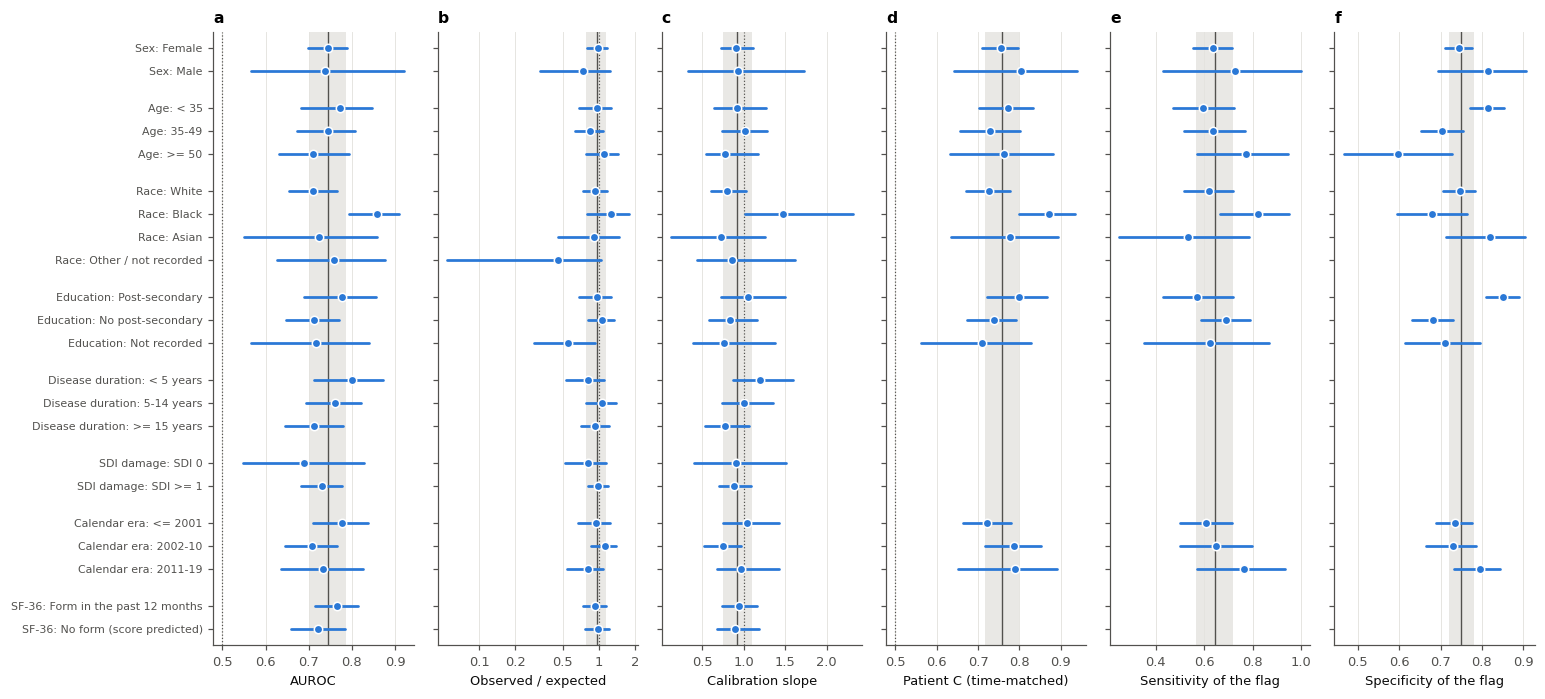

**What this means.**

* **Ranking.** Across the 22 subgroups with at least 10 onsets, the AUROC runs from
  0.69 (sdi damage: SDI 0; 0.690 (0.549 to 0.828)) to 0.86
  (race: Black; 0.858 (0.794 to 0.909)), against 0.744 overall. Most subgroups hold
  few onsets, so the intervals are wide and overlap the overall value (grey band).
* **Level of risk.** The O/E interval excludes 1 in Education: Not recorded (O/E 0.56 (0.29 to 0.94)). In these groups a band corresponds to a different absolute risk than overall, although the ranking within the group is unaffected.
* **The flag.** Its sensitivity runs from 0.53 (race: Asian) to 0.82 (race: Black), against 0.64 overall.
  Where sensitivity and specificity move together in opposite directions, the group simply sits higher (or lower) on
  the risk scale; where patient C falls, the model ranks that group's patients less well.

Subgroups with fewer than 10 onsets (the table) cannot be judged in these data. The era of the landmark
is the subgroup most likely to differ, because the recording of the outcome changed over time (Part IV).

In [121]:
"""Figure: HazReg by subgroup, visit level (AUROC, O/E, calibration slope) and patient level (C, sensitivity, specificity)."""
_items = [(char, g) for char, (_, _, order) in SUBGROUPS.items() for g in order
          if (char, g, "visit") in SUB_RES or (char, g, "patient") in SUB_RES]
_ypos, _ylab, _y, _prev = [], [], 0, None
for char, g in _items:
    if char != _prev:
        _y += 0.6 if _prev is not None else 0
        _prev = char
    _ypos.append(_y); _ylab.append(f"{char}: {g}"); _y += 1
_ypos = np.array(_ypos)
_PANELS = [("AUROC", "visit", "AUROC", 0.5), ("O/E", "visit", "Observed / expected", 1.0),
           ("Calibration slope", "visit", "Calibration slope", 1.0), ("C", "patient", "Patient C (time-matched)", 0.5),
           ("Sensitivity", "patient", "Sensitivity of the flag", None), ("Specificity", "patient", "Specificity of the flag", None)]
fig, axes = plt.subplots(1, len(_PANELS), figsize=(15.5, 0.27 * len(_items) + 1.3), sharey=True, gridspec_kw={"wspace": 0.12})
for j, (ax, (k, lev, lab, ref)) in enumerate(zip(axes, _PANELS)):
    ov = _ov[k]
    ax.axvspan(ov[1], ov[2], color=GRID_C, alpha=0.8, lw=0, zorder=0)
    ax.axvline(ov[0], color=INK_2, lw=0.9, zorder=1)
    if ref is not None:
        ax.axvline(ref, color=INK_2, lw=0.8, ls=":", zorder=1)
    for yy, (char, g) in zip(_ypos, _items):
        t = SUB_RES.get((char, g, lev))
        if t is None:
            continue
        ax.plot([t[k][1], t[k][2]], [yy, yy], color=C1, lw=1.8, solid_capstyle="round", zorder=2)
        ax.plot(t[k][0], yy, "o", color=C1, ms=5.5, mec="white", mew=1, zorder=3)
    if k == "O/E":
        ax.set_xscale("log"); log_ticks(ax)
    ax.set_xlabel(lab); ax.grid(axis="y", visible=False)
    ax.set_title(f"{'abcdef'[j]}  {lab}", loc="left", fontsize=8.5)
axes[0].set_yticks(_ypos, _ylab, fontsize=7.2); axes[0].set_ylim(_ypos.max() + 0.7, -0.7)
save_fig("subgroup_performance")

_vis_ok = [(c, g) for (c, g, lev) in SUB_RES if lev == "visit"]
_auc = {cg: SUB_RES[(*cg, "visit")]["AUROC"] for cg in _vis_ok}
_oe = {cg: SUB_RES[(*cg, "visit")]["O/E"] for cg in _vis_ok}
_lo_auc = min(_auc, key=lambda cg: _auc[cg][0])
_hi_auc = max(_auc, key=lambda cg: _auc[cg][0])
_mis = [f"{c}: {g} (O/E {fmt(v, 2)})" for (c, g), v in _oe.items() if v[1] > 1 or v[2] < 1]
_pt_ok = [(c, g) for (c, g, lev) in SUB_RES if lev == "patient"]
_sens = {cg: SUB_RES[(*cg, "patient")]["Sensitivity"] for cg in _pt_ok}
_lo_s = min(_sens, key=lambda cg: _sens[cg][0]) if _sens else None
_hi_s = max(_sens, key=lambda cg: _sens[cg][0]) if _sens else None
say(f"""
**What this means.**

* **Ranking.** Across the {len(_vis_ok)} subgroups with at least {SUB_MIN_ONSETS} onsets, the AUROC runs from
  {_auc[_lo_auc][0]:.2f} ({_lo_auc[0].lower()}: {_lo_auc[1]}; {fmt(_auc[_lo_auc])}) to {_auc[_hi_auc][0]:.2f}
  ({_hi_auc[0].lower()}: {_hi_auc[1]}; {fmt(_auc[_hi_auc])}), against {_ov['AUROC'][0]:.3f} overall. Most subgroups hold
  few onsets, so the intervals are wide and overlap the overall value (grey band).
* **Level of risk.** {"The O/E interval excludes 1 in " + "; ".join(_mis) + ". In these groups a band corresponds to a different absolute risk than overall, although the ranking within the group is unaffected." if _mis else "No subgroup has an O/E interval that excludes 1: the level of risk is right in every group the data can judge."}
* **The flag.** {("Its sensitivity runs from " + f"{_sens[_lo_s][0]:.2f} ({_lo_s[0].lower()}: {_lo_s[1]}) to {_sens[_hi_s][0]:.2f} ({_hi_s[0].lower()}: {_hi_s[1]})" + f", against {_ov['Sensitivity'][0]:.2f} overall.") if _sens else "Too few onsets in any patient-level subgroup."}
  Where sensitivity and specificity move together in opposite directions, the group simply sits higher (or lower) on
  the risk scale; where patient C falls, the model ranks that group's patients less well.

Subgroups with fewer than {SUB_MIN_ONSETS} onsets (the table) cannot be judged in these data. The era of the landmark
is the subgroup most likely to differ, because the recording of the outcome changed over time (Part IV).
""")